# Feature sweep — one column at a time

Goal: walk through **every column** of the challenge files, one per section. For each: what it
actually is in plain words, order statistics, and a picture of its distribution — over the 2025
training data and, where meaningful, side by side with the Jan/Jul 2026 `ranking.parquet`.

Data comes from the parquet mirror in `../data/` (see `README.md`). Sections get appended as we go.

**Roadmap** (column order of the files) —
`MVT_ID_mvt` ✅ · `FLIGHT_ID_mvt` ✅ · `FLIGHT_mvt` ✅ · `FLIGHT_RULE_mvt` ✅ · `ADEP_mvt` ✅ · `ADES_mvt` ✅ ·
`PHASE_mvt` ✅ · `MVT_TIME_UTC_mvt` ✅ · `BLOCK_TIME_UTC_mvt` ✅ · `SCHED_TIME_UTC_mvt` ✅ ·
`AIRCRAFT_TYPE_mvt` ✅ · `RUNWAY_mvt` ✅ · `STAND_mvt` ✅ · `TAXITIME_SEC_mvt` (target) ✅ · `LOBT_flt` ✅ ·
`CALLSIGN_flt` ✅ · `ADEP_flt` ✅ · `ADES_flt` ✅ · `ADES_FILED_flt` ✅ · `MARKET_SEGMENT_flt` ✅ · `IOBT_flt` ✅ ·
`FLIGHT_RULE_flt` ✅ · `FLIGHT_TYPE_flt` ✅ · `AIRCRAFT_TYPE_flt` ✅ · `WK_TBL_CAT_flt` ✅ ·
`AIRCRAFT_OPERATOR_flt` ✅ · `EOBT_1_flt` ✅ · `ARVT_1_flt` ✅ · `AOBT_3_flt` ✅ · `ARVT_3_flt` ✅

Every section ends with a **correlation with the target** cell (Pearson/Spearman for numerics, the correlation ratio η for categoricals), and a running **association matrix** of the features covered so far closes the notebook — new sections go in before it.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
con = duckdb.connect()
con.sql("SET TimeZone='UTC'")

# relations: full files; filter PHASE_mvt yourself where it matters
T = f"read_parquet('{ROOT}/data/training_2025-*.parquet')"
R = f"read_parquet('{ROOT}/data/ranking.parquet')"

# chart chrome (dataviz reference palette, light mode)
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, BASELINE = "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # series: blue = training, orange = ranking
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "text.color": INK,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110,
})


def style(ax, *, x_grid=False, y_grid=True):
    ax.grid(axis="x", visible=x_grid)
    ax.grid(axis="y", visible=y_grid)
    ax.tick_params(length=0)


def order_stats(expr, where="TRUE"):
    """Order statistics of a numeric expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   count(DISTINCT ({expr})) n_unique,
                   min({expr}) min,
                   quantile_cont({expr}, 0.01) p01,
                   quantile_cont({expr}, 0.25) p25,
                   quantile_cont({expr}, 0.50) p50,
                   quantile_cont({expr}, 0.75) p75,
                   quantile_cont({expr}, 0.99) p99,
                   max({expr}) max
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")


def cat_stats(expr, where="TRUE"):
    """Counts overview of a categorical/string expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   round(100.0*count(*) FILTER (({expr}) IS NULL)/count(*), 2) pct_null,
                   count(DISTINCT ({expr})) n_unique
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")

In [57]:
# ---- association helpers: "correlation with the target" cells in every section, and the matrix at the end ----
import itertools
import textwrap
# The target rows everywhere below: training departures with a plausible label (1–3600 s).
TGT = f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"


def eta(expr, src=None, y="TAXITIME_SEC_mvt", min_support=1):
    """Correlation ratio η of y across the levels of a categorical expression: sqrt(between-level
    variance / total variance) — the categorical analogue of |r|, i.e. the R of a one-hot regression
    on the levels. Levels with fewer than min_support rows are pooled into one. Returns (η, levels)."""
    return con.sql(f"""
        WITH d AS (SELECT coalesce(CAST(({expr}) AS VARCHAR), '∅') g, ({y})::DOUBLE v
                   FROM {src or TGT} WHERE ({y}) IS NOT NULL),
             p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY g) >= {min_support} THEN g ELSE '_rare_' END g, v
                   FROM d),
             w AS (SELECT g, v, avg(v) OVER (PARTITION BY g) mg, avg(v) OVER () m FROM p)
        SELECT sqrt(1 - sum((v - mg)^2) / sum((v - m)^2)), count(DISTINCT g) FROM w""").fetchone()


def rho(expr, src=None, y="TAXITIME_SEC_mvt"):
    """Pearson r and Spearman ρ between a numeric expression and y. Returns (r, ρ, n)."""
    return con.sql(f"""
        SELECT corr(x, v), corr(rx, rv), count(*) FROM (
            SELECT x, v, rank() OVER (ORDER BY x) rx, rank() OVER (ORDER BY v) rv
            FROM (SELECT ({expr})::DOUBLE x, ({y})::DOUBLE v FROM {src or TGT})
            WHERE x IS NOT NULL AND v IS NOT NULL)""").fetchone()


def cramers_v(a, b, src, min_a=1, min_b=1):
    """Cramér's V between two categorical expressions — χ² of the contingency table from pair
    counts, normalised to 0–1 by min(levels) − 1. Rare levels of each side pooled."""
    return con.sql(f"""
        WITH d AS (SELECT coalesce(CAST(({a}) AS VARCHAR), '∅') a, coalesce(CAST(({b}) AS VARCHAR), '∅') b FROM {src}),
             p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY a) >= {min_a} THEN a ELSE '_rare_' END a,
                          CASE WHEN count(*) OVER (PARTITION BY b) >= {min_b} THEN b ELSE '_rare_' END b FROM d),
             ab AS (SELECT a, b, count(*)::DOUBLE n FROM p GROUP BY 1, 2),
             ra AS (SELECT a, count(*)::DOUBLE na FROM p GROUP BY 1),
             cb AS (SELECT b, count(*)::DOUBLE nb FROM p GROUP BY 1)
        SELECT sqrt(greatest(sum(n * n / (na * nb)) - 1, 0)
                    / greatest(least((SELECT count(*) FROM ra), (SELECT count(*) FROM cb)) - 1, 1))
        FROM ab JOIN ra USING (a) JOIN cb USING (b)""").fetchone()[0]


def target_assoc(items):
    """items: (label, kind, expr[, min_support[, src[, y]]]), kind 'num' or 'cat'. One row per item:
    Pearson r and Spearman ρ for a numeric, η and the number of levels for a categorical."""
    rows = []
    for it in items:
        label, kind, expr = it[:3]
        ms, src, y = (list(it[3:]) + [1, None, "TAXITIME_SEC_mvt"][len(it) - 3:])
        if kind == "num":
            r, s, n = rho(expr, src, y)
            rows.append((label, "numeric", n, round(r, 3), round(s, 3), np.nan))
        else:
            e, k = eta(expr, src, y, ms)
            rows.append((label, "categorical", k, np.nan, np.nan, round(e, 3)))
    df = pd.DataFrame(rows, columns=["feature", "kind", "n / levels", "pearson_r", "spearman_ρ", "η"])
    print(df.to_string(index=False, na_rep=""))
    return df


def assoc_chart(df, main, kind="cat", src=None, y="TAXITIME_SEC_mvt", min_support=1, title="feature"):
    """Left: the association of every row of a target_assoc table. Right: taxi-out against the
    feature's main form — mean and p25–p75 per level (≤ 24 levels), the spread of per-level means
    (more levels), or the mean per quantile bin (numeric)."""
    src = src or TGT
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
    vals = df["η"].fillna(df["spearman_ρ"].abs())
    yy = np.arange(len(df))
    a1.barh(yy, vals, height=0.6, color=BLUE)
    for i, v in enumerate(vals):
        a1.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    a1.set_yticks(yy, [textwrap.shorten(s, 40, placeholder="…") for s in df.feature], color=INK2)
    a1.invert_yaxis()
    a1.set_xlim(0, 1)
    a1.set_title("Association with taxi-out")
    a1.set_xlabel("η (categorical) · |Spearman ρ| (numeric)")
    style(a1, x_grid=True, y_grid=False)
    if kind == "num":
        prof = con.sql(f"""
            WITH d AS (SELECT ({main})::DOUBLE x, ({y})::DOUBLE v FROM {src}
                       WHERE ({main}) IS NOT NULL AND ({y}) IS NOT NULL),
                 b AS (SELECT ntile(20) OVER (ORDER BY x) q, v FROM d)
            SELECT q, avg(v) m, quantile_cont(v, 0.25) p25, quantile_cont(v, 0.75) p75
            FROM b GROUP BY 1 ORDER BY 1""").df()
        a2.fill_between(prof.q, prof.p25, prof.p75, color=BLUE, alpha=0.15, lw=0)
        a2.plot(prof.q, prof.m, "o-", color=BLUE, ms=4)
        a2.set_xticks(range(1, 21, 2))
        a2.set_xlabel(f"{title} — 20 quantile bins, low to high")
        a2.set_ylabel("taxi-out (s): mean, p25–p75 band")
        a2.set_title(f"{title}: taxi-out along the feature")
        style(a2)
    else:
        lv = con.sql(f"""
            WITH d AS (SELECT coalesce(CAST(({main}) AS VARCHAR), '∅') g, ({y})::DOUBLE v FROM {src}
                       WHERE ({y}) IS NOT NULL),
                 p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY g) >= {min_support} THEN g ELSE '_rare_' END g, v
                       FROM d)
            SELECT g, count(*) n, avg(v) m, quantile_cont(v, 0.25) p25, quantile_cont(v, 0.75) p75
            FROM p GROUP BY 1 ORDER BY m""").df()
        if len(lv) <= 24:
            yy = np.arange(len(lv))
            a2.hlines(yy, lv.p25, lv.p75, color=BLUE, lw=5, alpha=0.45)
            a2.plot(lv.m, yy, "o", color=INK, ms=4.5, zorder=3)
            a2.set_yticks(yy, lv.g, color=INK2, fontsize=8.5)
            a2.set_xlabel("taxi-out (s): mean · p25–p75")
            a2.set_title(f"{title}: taxi-out by level")
            style(a2, x_grid=True, y_grid=False)
        else:
            overall = con.sql(f"SELECT avg(({y})::DOUBLE) FROM {src}").fetchone()[0]
            a2.hist(lv.m, bins=40, weights=lv.n, color=BLUE)
            a2.axvline(overall, color=INK2, ls="--", lw=1)
            a2.text(overall + 10, a2.get_ylim()[1] * 0.92, f"all rows · {overall:.0f} s", fontsize=8.5, color=INK2)
            a2.set_xlabel("mean taxi-out of the level (s)")
            a2.set_ylabel("departures in levels with that mean")
            a2.set_title(f"{title}: {len(lv):,} levels — how far their means spread")
            style(a2)
    fig.tight_layout(w_pad=2.5)
    plt.show()

## 1 · `MVT_ID_mvt` — the movement record's serial number

Every row in these files is one **movement**: one aircraft either departing from or arriving at
one of the 10 challenge airports. `MVT_ID_mvt` is simply the unique number the data pipeline
stamped on that record — a ticket number, nothing more. It is stored as a `double` but always
holds a whole number.

It matters for exactly one reason: it is the **join key**. `submitting.parquet` lists the
344,841 IDs (the ranking file's departures) we must attach a prediction to, and the scorer
matches our rows back by this value.

Worth checking anyway: are IDs handed out in time order, and do the training and ranking ranges
overlap?

In [3]:
non_int = con.sql(f"SELECT count(*) FROM {T} WHERE MVT_ID_mvt != floor(MVT_ID_mvt)").fetchone()[0]
overlap = con.sql(f"""SELECT count(*) FROM (SELECT MVT_ID_mvt FROM {T}) t
                      JOIN (SELECT MVT_ID_mvt FROM {R}) r USING (MVT_ID_mvt)""").fetchone()[0]
sub_match = con.sql(f"""
    SELECT count(*) = 0 FROM (
        SELECT MVT_ID_mvt FROM read_parquet('{ROOT}/data/submitting.parquet')
        FULL JOIN (SELECT MVT_ID_mvt AS id2, 1 one FROM {R} WHERE PHASE_mvt = 'DEP') r
            ON MVT_ID_mvt = id2
        WHERE MVT_ID_mvt IS NULL OR id2 IS NULL)""").fetchone()[0]
rank_corr = con.sql(f"""
    SELECT round(corr(rank_id, rank_t), 4) FROM (
        SELECT rank() OVER (ORDER BY MVT_ID_mvt) rank_id,
               rank() OVER (ORDER BY MVT_TIME_UTC_mvt) rank_t
        FROM (SELECT * FROM {T} USING SAMPLE reservoir(100000) REPEATABLE (42)))""").fetchone()[0]

print(f"non-integer values in training:            {non_int}")
print(f"IDs shared between training and ranking:   {overlap}")
print(f"submitting.parquet IDs == ranking DEP IDs: {sub_match}")
print(f"rank corr(MVT_ID, movement time), 100k:    {rank_corr}")

non-integer values in training:            0
IDs shared between training and ranking:   0
submitting.parquet IDs == ranking DEP IDs: True
rank corr(MVT_ID, movement time), 100k:    0.9927


           feature    kind  n / levels  pearson_r  spearman_ρ  η
MVT_ID_mvt (value) numeric     2080533      0.009       0.011   


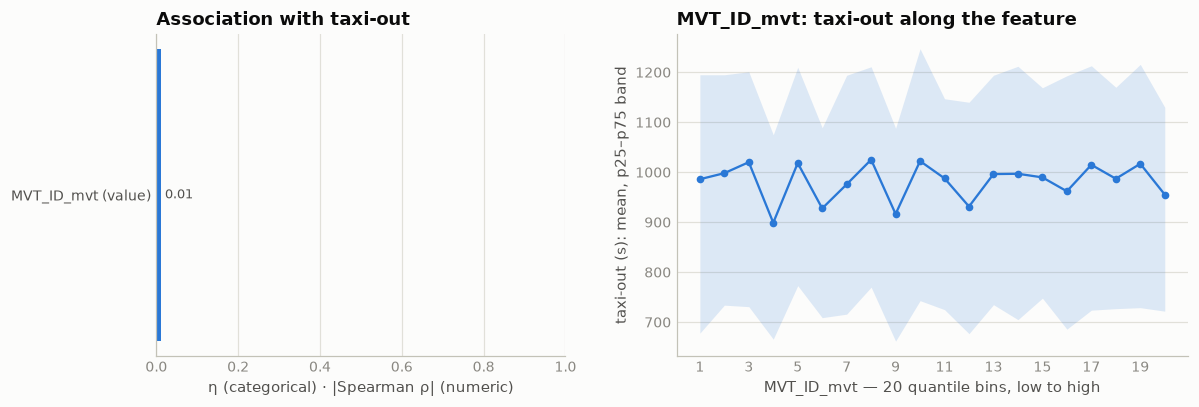

In [56]:
# correlation with the target — the ID is a counter; whatever it carries is the calendar's, not its own
a = target_assoc([("MVT_ID_mvt (value)", "num", "MVT_ID_mvt")])
assoc_chart(a, "MVT_ID_mvt", kind="num", title="MVT_ID_mvt")

**Findings**

- A unique whole-number key, never null in either file, with no value shared between training
  and ranking; `submitting.parquet` is exactly the ranking departures' ID set. Treat it as an
  `int64` join key and nothing else.
- It is a clock in disguise: IDs were issued in near time order (rank corr ≈ 0.99 with movement
  time), so the 2026 rows carry numbers the model has never seen. **Use in modeling: none** — it
  never enters the feature set, and it must be stripped before any adversarial validation or it
  separates the two files on its own. Whatever time signal it carries comes honestly from the
  timestamp columns.

## 2 · `FLIGHT_ID_mvt` — the matched flight plan's serial number

Two systems feed these files. Airports record **movements** (a plane pushed back, a plane took
off); EUROCONTROL's Network Manager (NM) records **flight plans**. This column holds the ID of
the NM flight the movement was matched to — *when* that match succeeded — and every `*_flt`
column to the right comes along with it. One NM flight is one leg, so when both ends of a leg
are challenge airports the same ID legitimately appears twice: as `DEP` at the origin and as
`ARR` at the destination.

| step | question | what came out |
|---|---|---|
| **2 · census** | how often is it missing, is missing-ness structured, what do the duplicates mean? | missing ⇒ the whole `_flt` block is missing; the is-missing flag is a feature; an ID on two rows is one leg seen from both ends |
| **2a · who is unmatched** | are the unmatched IFR rows junk or real flights? | a fifth fly to Ercan, where no plan can exist; the rest are matching failures of ordinary flights |
| **2b · why matching fails, exact-twin recovery** | what breaks the match, and can the plan be found elsewhere? | heavily delayed flights whose off-block estimate was never refiled; the twin arrival row still carries the plan → recovery layer 1 |
| **2c · relaxed twins, history imputation** | how much further can recovery go? | layers 2 and 3; 265 of 344,841 predictions stay bare |
| **how the pipeline consumes it** | rules | coalesce raw → 1 → 2 → 3; keep the no-plan flag on imputed rows |

presence by file × phase, and the ID range:
     src  ph       n  n_null  pct_null  n_unique  min_id_m  max_id_m
training ARR 2082750    8506      0.41   2074244     280.3     294.6
training DEP 2085047   22424      1.08   2062620     280.4     294.6
 ranking ARR  344693    1409      0.41    343284     294.6     303.0
 ranking DEP  344841    5283      1.53    339557     294.6     303.0

appearances per non-null ID (training) — and what the doubles are:


 cnt   n_ids  dep_arr_pairs  dep_dest_equals_arr_airport  dep_dep
   1 3506323              0                            0        0
   2  315272         315269                       313639        3

ID missing vs whole _flt block missing (training):
 id_null  flt_block_null       n   n_arr
   False           False 4129878 2067301
    True            True   30930    8506
   False            True    6989    6943

VFR departures: 2,930 — unmatched: 2,930
FLIGHT_IDs in BOTH files: 4 — training side from 2025-12-31 21:34, ranking side until 2026-01-01 01:38

taxi-out by rule × match (training DEP):
flight_rule  unmatched       n  med_taxi_out
          I      False 2062460         911.0
          I       True   19454        1009.0
          V       True    2930         232.0


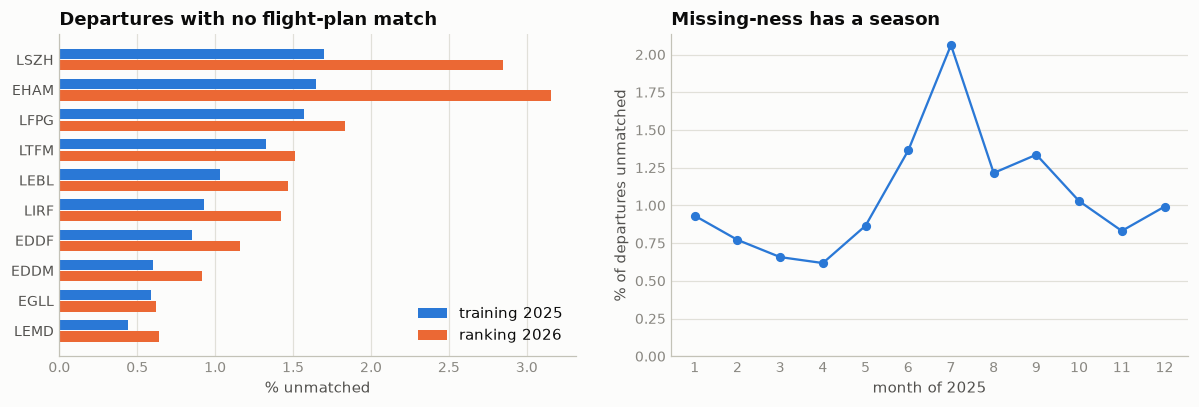

In [5]:
APS = "('LTFM','EHAM','LFPG','EGLL','EDDF','LEMD','LEBL','EDDM','LIRF','LSZH')"  # the ten hubs

print("presence by file × phase, and the ID range:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) n_null,
           round(100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT FLIGHT_ID_mvt) n_unique,
           round(min(FLIGHT_ID_mvt)/1e6, 1) min_id_m, round(max(FLIGHT_ID_mvt)/1e6, 1) max_id_m
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nappearances per non-null ID (training) — and what the doubles are:")
print(con.sql(f"""
    SELECT cnt, count(*) n_ids,
           count(*) FILTER (phases = 'ARR+DEP') dep_arr_pairs,
           count(*) FILTER (phases = 'ARR+DEP' AND same_leg) dep_dest_equals_arr_airport,
           count(*) FILTER (phases = 'DEP+DEP') dep_dep
    FROM (SELECT FLIGHT_ID_mvt, count(*) cnt,
                 string_agg(PHASE_mvt, '+' ORDER BY PHASE_mvt) phases,
                 max(CASE WHEN PHASE_mvt = 'DEP' THEN ADES_mvt END)
                   = max(CASE WHEN PHASE_mvt = 'ARR' THEN ADES_mvt END) same_leg
          FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nID missing vs whole _flt block missing (training):")
print(con.sql(f"""
    SELECT FLIGHT_ID_mvt IS NULL id_null, CALLSIGN_flt IS NULL flt_block_null,
           count(*) n, count(*) FILTER (PHASE_mvt = 'ARR') n_arr
    FROM {T} GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

vfr = con.sql(f"""SELECT count(*), count(*) FILTER (FLIGHT_ID_mvt IS NULL)
                  FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V'""").fetchone()
shared = con.sql(f"""
    SELECT count(DISTINCT t.FLIGHT_ID_mvt),
           min(strftime(t.MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M')), max(strftime(r.MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M'))
    FROM {T} t JOIN {R} r ON t.FLIGHT_ID_mvt = r.FLIGHT_ID_mvt""").fetchone()
print(f"\nVFR departures: {vfr[0]:,} — unmatched: {vfr[1]:,}")
print(f"FLIGHT_IDs in BOTH files: {shared[0]} — training side from {shared[1]}, ranking side until {shared[2]}")

print("\ntaxi-out by rule × match (training DEP):")
print(con.sql(f"""
    SELECT FLIGHT_RULE_mvt flight_rule, FLIGHT_ID_mvt IS NULL unmatched, count(*) n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt IN ('I', 'V')
    GROUP BY 1, 2 ORDER BY 1, 2""").df().to_string(index=False))

# where and when the departure-side match fails
unm = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT t.a airport, t.pct pct_t, r.pct pct_r FROM t JOIN r ON t.a = r.a ORDER BY t.pct""").df()
mon = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) m, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(unm))
a1.barh(y + 0.19, unm.pct_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, unm.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, unm.airport, color=INK2)
a1.set_title("Departures with no flight-plan match")
a1.set_xlabel("% unmatched")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)
a2.plot(mon.m, mon.pct, "o-", color=BLUE, ms=5)
a2.set_xticks(range(1, 13))
a2.set_ylim(bottom=0)
a2.set_title("Missing-ness has a season")
a2.set_xlabel("month of 2025")
a2.set_ylabel("% of departures unmatched")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence (training unless noted) | what it means for us |
|---|---|---|
| Missing on 1.08% of departures and 0.41% of arrivals; **1.53%** of ranking departures | presence table | the no-plan path is a small slice, ~1.5× more common at prediction time than in training |
| Missing ID ⇒ the whole `_flt` block is empty | 30,930 rows null on both, never an ID-less row with plan data | one flag covers all sixteen `_flt` columns |
| The reverse does not quite hold | 6,989 rows carry an ID but an empty block, almost all arrivals | matched, but the plan data did not come through; irrelevant for the departures we model |
| Every VFR departure is unmatched | 2,930 of 2,930 | VFR flights do not file NM plans — expected, not a bug |
| Missing-ness is structured, not random | highest at Zurich and Schiphol; peaks in summer | general-aviation season at GA-heavy hubs, plus the matching failures of 2a–2b |
| An ID on two rows is one leg seen from both ends | 315,272 IDs appear twice; 315,269 are a `DEP`+`ARR` pair and for 313,639 (99.5%) the departure's destination is the arrival's airport; 3 odd `DEP`+`DEP` | the leg's two ends can be linked — 2b builds its recovery on this |
| The files were split by movement date, not by flight | 4 IDs in both files: departed on 31 Dec 2025, landed on 1 Jan 2026 | ranking's ID block sits just above training's |
| Unmatched flights taxi differently | IFR unmatched median 1,009 s vs 911 s matched; VFR unmatched 232 s | the flag carries signal of its own |

**Use in modeling.** The value is a join key — no signal beyond record time. The **is-missing
indicator** is a feature: it flags VFR/GA traffic, delayed flights (2b), and the rows where the
`AOBT_3` taxi anchor cannot exist. The `DEP`+`ARR` pairing is the basis of the recovery in 2b.

### 2a · Who is unmatched — expected gaps, or failures?

A missing VFR plan is expected: VFR flights do not file with NM. An IFR flight must, yet IFR
turns out to be the bulk of the unmatched rows. The cell profiles the unmatched IFR movements —
which hubs, which other end of the leg, which months, how complete the movement half is — and
checks whether the same pattern is in the ranking file.

In [6]:
U = f"{T} WHERE FLIGHT_ID_mvt IS NULL AND FLIGHT_RULE_mvt = 'I'"

xtab = con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           count(*) FILTER (PHASE_mvt = 'ARR') arr, count(*) total
    FROM {T} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY total DESC""").df()
by_ap = con.sql(f"""
    SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END airport, count(*) n,
           round(100.0*count(*)/sum(count(*)) OVER (), 1) pct
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 5""").df()
other_end = con.sql(f"""
    SELECT coalesce(CASE WHEN PHASE_mvt = 'DEP' THEN ADES_mvt ELSE ADEP_mvt END, '?') other_end,
           count(*) n
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 8""").df()
by_month = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) m, count(*) n FROM {U} GROUP BY 1 ORDER BY 1""").df()
complete = con.sql(f"""
    SELECT count(*) n, count(*) FILTER (SCHED_TIME_UTC_mvt IS NULL) sched_null,
           count(*) FILTER (RUNWAY_mvt IS NULL) rwy_null,
           count(*) FILTER (STAND_mvt IS NULL) stand_null,
           count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) actype_null,
           count(*) FILTER (regexp_matches(FLIGHT_mvt, '^[A-Z]{{3}}[0-9]')) icao_callsign
    FROM {U}""").df()
rk = con.sql(f"""
    SELECT count(*) FILTER (FLIGHT_RULE_mvt = 'I') ifr_unmatched,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I'
               AND CASE WHEN PHASE_mvt='DEP' THEN ADES_mvt ELSE ADEP_mvt END = 'LCEN') ifr_ercan,
           count(*) FILTER (PHASE_mvt = 'DEP' AND ADES_mvt = 'LCEN') dep_to_ercan
    FROM {R} WHERE FLIGHT_ID_mvt IS NULL""").df()

print("unmatched rows by flight rule (training):")
print(xtab.to_string(index=False))
print("\nunmatched IFR — top challenge airports:")
print(by_ap.to_string(index=False))
print("\nunmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):")
print(other_end.to_string(index=False))
print("\nunmatched IFR — by month:")
print(by_month.set_index("m").T.to_string())
print("\nunmatched IFR — completeness of the movement half:")
print(complete.to_string(index=False))
print("\nranking file: unmatched IFR rows:", rk.ifr_unmatched[0],
      "| involving Ercan:", rk.ifr_ercan[0],
      "| DEP→LCEN rows we must predict:", rk.dep_to_ercan[0])

unmatched rows by flight rule (training):
flight_rule   dep  arr  total
          I 19454 5294  24748
          V  2930 3149   6079
          ?    40   63    103

unmatched IFR — top challenge airports:
airport    n  pct
   LTFM 6660 26.9
   LFPG 4073 16.5
   EHAM 3965 16.0
   EDDF 2006  8.1
   LEBL 1736  7.0

unmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):
other_end    n
     LCEN 5543
     EHAM  531
     LLBG  499
     EINN  393
     DAAG  354
     LFMN  307
     LPPT  296
     HRYR  290

unmatched IFR — by month:
m    1     2     3     4     5     6     7     8     9     10    11    12
n  1631  1203  1152  1210  1798  2650  4177  2495  2693  2213  1612  1914

unmatched IFR — completeness of the movement half:
    n  sched_null  rwy_null  stand_null  actype_null  icao_callsign
24748           0         0          26         1645          18700

ranking file: unmatched IFR rows: 5771 | involving Ercan: 1189 | DEP→LCEN rows we must predict: 594


**Findings**

| observation | evidence | reading |
|---|---|---|
| IFR is the bulk of the unmatched rows | 24,748 IFR vs 6,079 VFR and 103 with no rule | most gaps are not the expected VFR kind |
| **Ercan explains the biggest chunk** | 5,543 of 24,748 unmatched-IFR rows (22%) have Ercan (`LCEN`, Northern Cyprus) as the leg's other end; Istanbul tops the hub list at 27% | not a bug: Northern Cyprus is unrecognized, so NM never processes these flights — **there is no plan to match** |
| The rest are real flights, not junk | 76% carry proper ICAO callsigns; schedule and runway present on 100%, stand on 99.9%; ordinary A320/B738 fleet; other ends include Tel Aviv, Algiers and Kigali but also Amsterdam and Shannon | scheduled flights whose NM match simply failed, more often on legs touching the edge of the IFPS zone |
| Summer peak | July 4,177 vs 1,150–1,900 in the winter months | matching degrades under load — the same bump as the overall unmatched rate |
| It persists at prediction time | ranking: 5,771 unmatched IFR rows, 1,189 involving Ercan, **594 departures to Ercan to predict** | the no-plan path (no `AOBT_3`, operator, segment) is a real, Istanbul-heavy slice of the eval set |

### 2b · Why matching fails, and the exact-twin recovery

Ercan aside, the unmatched IFR departures are **matching failures**: 0.80% of departures. Three
tests say what they are, and the third also shows where the missing plan can be found.

| test | question | how |
|---|---|---|
| **1 · delay** | are failed flights unusual? | takeoff − schedule, failed vs matched IFR departures |
| **2 · episodic?** | do failures strike particular flight numbers, or ordinary ones on a bad day? | share of failed departures whose flight number is matched on > 90% of its *other* 2025 occurrences |
| **3 · the twin** | did a plan exist at all? | a leg between two challenge airports has **two rows** — the origin's `DEP` and the destination's `ARR` — each matched to NM independently. If the departure's twin arrival (same flight number, same route, landing within 8 h) carries a `FLIGHT_ID`, the plan was there and only the departure-side link broke |

**Recovery rule.** For an unmatched departure whose twin arrival is (a) the *only* candidate in
the 8 h window and (b) agrees on aircraft type (or type is missing on one side), take the
twin's `FLIGHT_ID` and entire `_flt` block as the departure's own — same leg, so the plan fields
apply verbatim. It works identically at prediction time because ranking arrivals are fully
populated. Output: `data/derived/recovered_flt_blocks.parquet`.

In [7]:
# evidence 1: delay of failed vs matched IFR departures (Ercan excluded)
print("evidence 1 — delay (DEP IFR, Ercan excluded):")
print(con.sql(f"""
    SELECT CASE WHEN FLIGHT_ID_mvt IS NULL THEN 'unmatched IFR' ELSE 'matched IFR' END grp,
           count(*) n, round(quantile_cont(d, 0.5)) med_delay_min,
           round(quantile_cont(d, 0.9)) p90_delay_min,
           round(100.0*count(*) FILTER (d > 180)/count(*), 1) pct_over_3h
    FROM (SELECT FLIGHT_ID_mvt, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 d
          FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'I'
            AND coalesce(ADES_mvt, '') != 'LCEN')
    GROUP BY 1""").df().to_string(index=False))

# evidence 2: failures strike flight numbers that are usually matched
usual = con.sql(f"""
    WITH occ AS (SELECT FLIGHT_mvt f, count(*) n_tot,
                        count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_m
                 FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL GROUP BY 1)
    SELECT round(100.0*count(*) FILTER (o.n_tot >= 6 AND o.n_m::DOUBLE/(o.n_tot-1) > 0.9)
                 /count(*), 1)
    FROM {T} u JOIN occ o ON u.FLIGHT_mvt = o.f
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt = 'I'
      AND coalesce(u.ADES_mvt, '') != 'LCEN'""").fetchone()[0]
print(f"\nevidence 2 — failed departures whose flight number is matched >90% of other days: {usual}%")

# evidence 3: the twin test — is the same leg's ARR row matched?
print("\nevidence 3 — twin test:")
print(con.sql(f"""
    SELECT count(*) n_unmatched_dep_to_hub, count(*) FILTER (found) twin_found,
           count(*) FILTER (found_matched) twin_has_flight_id
    FROM (SELECT
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR) found,
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
                AND a.FLIGHT_ID_mvt IS NOT NULL) found_matched
      FROM {T} u
      WHERE u.PHASE_mvt='DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt='I'
        AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)""").df().to_string(index=False))

# sanity checks that the twin is the same flight, and the mechanism behind the failure
PAIRS = f"""
    SELECT u.MVT_ID_mvt, u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
           u.BLOCK_TIME_UTC_mvt u_block, u.SCHED_TIME_UTC_mvt u_sched,
           u.MVT_TIME_UTC_mvt u_takeoff, a.MVT_TIME_UTC_mvt a_landing,
           a.AOBT_3_flt aobt3, a.EOBT_1_flt eobt1, a.IOBT_flt iobt, a.ARVT_3_flt arvt3,
           count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
           row_number() OVER (PARTITION BY u.MVT_ID_mvt ORDER BY a.MVT_TIME_UTC_mvt) rn
    FROM {T} u JOIN {T} a
      ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
     AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
     AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
     AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
      AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL"""
print("\nsanity checks on the twin pairs, and the mechanism (training):")
print(con.sql(f"""
    SELECT count(*) n_pairs,
      round(100.0*count(*) FILTER (n_cand = 1)/count(*), 1) pct_unique_twin,
      round(100.0*count(*) FILTER (u_type = a_type)
            /count(*) FILTER (u_type IS NOT NULL AND a_type IS NOT NULL), 1) pct_actype_agree,
      round(quantile_cont(abs(epoch(u_block - aobt3))/60.0, 0.5), 1) med_blk_vs_aobt3_min,
      round(100.0*count(*) FILTER (abs(epoch(a_landing - arvt3)) <= 900)
            /count(*) FILTER (arvt3 IS NOT NULL), 1) pct_arvt3_landing_15m,
      round(100.0*count(*) FILTER (epoch(u_takeoff - aobt3) BETWEEN 120 AND 3600)
            /count(*) FILTER (aobt3 IS NOT NULL), 1) pct_taxi_plausible,
      -- the mechanism: actual delay vs how far the plan's EOBT ever moved
      round(quantile_cont(epoch(u_block - u_sched)/60.0, 0.5)) med_actual_delay_min,
      round(quantile_cont(epoch(eobt1 - u_sched)/60.0, 0.5)) med_eobt1_shift_min,
      round(quantile_cont(epoch(eobt1 - iobt)/60.0, 0.5)) med_eobt1_vs_iobt_min
    FROM ({PAIRS}) WHERE rn = 1""").df().T.rename(columns={0: "value"}).to_string())

evidence 1 — delay (DEP IFR, Ercan excluded):


          grp       n  med_delay_min  p90_delay_min  pct_over_3h
unmatched IFR   16683           99.0          167.0          7.9
  matched IFR 2062459           23.0           56.0          0.6

evidence 2 — failed departures whose flight number is matched >90% of other days: 86.3%

evidence 3 — twin test:
 n_unmatched_dep_to_hub  twin_found  twin_has_flight_id
                   2207         907                 896

sanity checks on the twin pairs, and the mechanism (training):
                       value
n_pairs                906.0
pct_unique_twin        100.0
pct_actype_agree        98.2
med_blk_vs_aobt3_min     3.1
pct_arvt3_landing_15m   99.7
pct_taxi_plausible      97.7
med_actual_delay_min    79.0
med_eobt1_shift_min     20.0
med_eobt1_vs_iobt_min    0.0


In [8]:
# perform the recovery -> data/derived/recovered_flt_blocks.parquet, then account for every unmatched departure
FLT_COLS = ["LOBT_flt", "CALLSIGN_flt", "ADEP_flt", "ADES_flt", "ADES_FILED_flt",
            "MARKET_SEGMENT_flt", "IOBT_flt", "FLIGHT_RULE_flt", "FLIGHT_TYPE_flt",
            "AIRCRAFT_TYPE_flt", "WK_TBL_CAT_flt", "AIRCRAFT_OPERATOR_flt",
            "EOBT_1_flt", "ARVT_1_flt", "AOBT_3_flt", "ARVT_3_flt"]


def recover(u_src, a_src, tag):
    """Recover _flt blocks for unmatched DEPs in u_src from twin ARRs in a_src."""
    a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
    return con.sql(f"""
        SELECT * EXCLUDE (n_cand, rn, u_type, a_type) FROM (
            SELECT u.MVT_ID_mvt, '{tag}' dataset,
                   a.FLIGHT_ID_mvt FLIGHT_ID_recovered,
                   a.MVT_ID_mvt recovered_from_arr_mvt_id, {a_cols},
                   u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
                   count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
                   row_number() OVER (PARTITION BY u.MVT_ID_mvt
                                      ORDER BY a.MVT_TIME_UTC_mvt) rn
            FROM {u_src} u JOIN {a_src} a
              ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
             AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
             AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                        AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
             AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
            WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
              AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)
        WHERE rn = 1 AND n_cand = 1
          AND (u_type = a_type OR u_type IS NULL OR a_type IS NULL)""").df()


rec_train = recover(T, T, "training")
# a ranking DEP's twin ARR normally sits in the ranking file itself;
# the union covers legs crossing the Dec-31 -> Jan-1 file boundary
rec_rank = recover(R, f"(SELECT * FROM {R} UNION ALL SELECT * FROM {T})", "ranking")
recovered = pd.concat([rec_train, rec_rank], ignore_index=True)

out = ROOT / "data" / "derived"
out.mkdir(parents=True, exist_ok=True)
recovered.to_parquet(out / "recovered_flt_blocks.parquet", index=False)
print(f"recovered {len(rec_train):,} training and {len(rec_rank):,} ranking departures "
      f"-> {out / 'recovered_flt_blocks.parquet'}")

REC = f"read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
both = f"(SELECT * FROM {T} UNION ALL SELECT * FROM {R})"

print("\nwhere every unmatched departure stands:")
print(con.sql(f"""
    WITH u AS (
        SELECT dataset, MVT_ID_mvt, coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
               coalesce(ADES_mvt = 'LCEN', FALSE) is_ercan
        FROM (SELECT 'training' AS dataset, * FROM {T}
              UNION ALL SELECT 'ranking' AS dataset, * FROM {R})
        WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL),
    tot AS (SELECT 'training' dataset, count(*) n_dep FROM {T} WHERE PHASE_mvt = 'DEP'
            UNION ALL SELECT 'ranking', count(*) FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT u.dataset, count(*) unmatched_dep,
           count(*) FILTER (r.MVT_ID_mvt IS NOT NULL) recovered,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND is_ercan) ercan_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule = 'V') vfr_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule != 'V') residual_failures,
           round(100.0*count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                                        AND flight_rule != 'V')/any_value(tot.n_dep), 2) residual_pct_of_dep
    FROM u LEFT JOIN {REC} r ON u.MVT_ID_mvt = r.MVT_ID_mvt JOIN tot ON tot.dataset = u.dataset
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

# the wrinkle: recovery did not filter on flight rule — six recovered departures are flagged VFR
print("\nmovement rule × plan rule on the recovered rows:")
print(con.sql(f"""
    SELECT t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan, count(*) n
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))
print("\nthe V-flagged recoveries:")
print(con.sql(f"""
    SELECT t.FLIGHT_mvt, t.ADEP_mvt, t.ADES_mvt,
           strftime(t.MVT_TIME_UTC_mvt, '%m-%d %H:%M') takeoff,
           t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan,
           r.MARKET_SEGMENT_flt segment, t.AIRCRAFT_TYPE_mvt actype
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    WHERE t.FLIGHT_RULE_mvt = 'V' ORDER BY t.MVT_TIME_UTC_mvt""").df().to_string(index=False))

recovered 892 training and 226 ranking departures -> /home/gunes/PRC/data/derived/recovered_flt_blocks.parquet

where every unmatched departure stands:
 dataset  unmatched_dep  recovered  ercan_no_plan  vfr_no_plan  residual_failures  residual_pct_of_dep
training          22424        892           2771         2924              15837                 0.76
 ranking           5283        226            594          419               4044                 1.17

movement rule × plan rule on the recovered rows:
rule_mvt rule_plan    n
       I         I 1112
       V         Z    3
       V         I    2
       V         Y    1

the V-flagged recoveries:
FLIGHT_mvt ADEP_mvt ADES_mvt     takeoff rule_mvt rule_plan  segment actype
    FCK2FT     LSZH     LSZH 03-11 21:58        V         I    Other   B350
     ICC03     LEBL     LEBL 08-16 06:47        V         Z Business   C208
     ICC03     LEBL     LEBL 09-18 08:54        V         Z Business   C208
    NCG01A     EHAM     EHAM 10-25 09:

**Findings**

| test | result | reading |
|---|---|---|
| **1 · delay** | failed departures ran a median **99 min** late vs 23 min for matched; 7.9% more than 3 h late vs 0.6% | failures are heavily delayed flights |
| **2 · episodic** | 86% of failed departures carry a flight number that is matched on > 90% of its other 2025 occurrences | ordinary flights on a bad day, not bad flight numbers |
| **3 · the twin** | of 2,207 unmatched departures to another hub, 907 have a locatable twin arrival and **896 of those carry a `FLIGHT_ID`** | the plan existed; only the departure-side link broke |

**Why the link breaks**, read off the twins' plan data: the aircraft left a median **79 min**
late, but the plan's expected off-block `EOBT_1` moved only **20 min** from schedule, and for
the median flight still *equals* the initially filed `IOBT`. The airline never refiled the
delay. A matcher pairing movements to plans inside a window around `EOBT` loses exactly these
flights; the arrival side survives because it keys on the flown arrival time (`ARVT_3` within
15 min of the actual landing for 99.7%).

| sanity check that the twin is the same flight | result |
|---|---|
| twin unique in its 8 h window | 100% of 906 pairs |
| aircraft type logged by the two airports agrees | 98.2% |
| plan's actual off-block vs the departure's own block time | median 3.1 min apart |
| implied taxi (takeoff − `AOBT_3`) between 2 and 60 min | 97.7% |

**Where this leaves the unmatched departures**

| | unmatched DEP | recovered (twin) | Ercan — no plan | VFR — no plan | **residual failures** |
|---|---:|---:|---:|---:|---:|
| training | 22,424 | 892 | 2,771 | 2,924 | **15,837** (0.76% of departures) |
| ranking | 5,283 | 226 | 594 | 419 | **4,044** (1.17%) |

The residual rate is ~1.5× higher in ranking: 2026's matching is worse, so the fallback path
matters more at prediction time than in CV.

| decision on the residual rows | why |
|---|---|
| **Keep them in training** | real, sanity-checked flights; the eval set contains their kind (1.17% of predictions) — dropping them would starve exactly that path |
| **Make "no flight plan" an explicit feature** | for IFR it is a delay fingerprint (median 99 min late vs 23) and goes with longer taxi (median 1,009 s vs 911 s) |
| **Lean on the movement half** | airport, runway, stand, aircraft type, schedule and congestion features are all present; only the `AOBT_3` anchor is lost |
| **Optionally read the callsign prefix** | `FLIGHT_mvt`'s `THY` / `KLM` / `RYR` prefix is an operator token when the anonymized `AIRCRAFT_OPERATOR_flt` is missing |

**A wrinkle: six recovered rows are flagged VFR — kept.**

| objection | answer |
|---|---|
| A VFR flight's missing plan should be *correct*; nothing to recover | these six provably filed with NM — that is what their matched twin established; 4 of 6 filed **mixed-rule plans** (`Z` = VFR then IFR, `Y` = IFR then VFR) |
| How can the two rule flags disagree? | `FLIGHT_RULE_mvt` is the rule *when the airport saw the movement*; `FLIGHT_RULE_flt` is the *filed plan*; rules switch mid-flight legitimately, e.g. weather forcing a VFR flight onto instruments |
| Who are they? | circular flights (Zurich→Zurich, Barcelona→Barcelona, Amsterdam→Amsterdam) on King Air, Caravan, Dash-8 and Do228 — survey, calibration, patrol: exactly the operations that mix VFR and IFR segments |
| Why keep them? | the recovery rule requires the twin to carry a `FLIGHT_ID`, i.e. **evidence that a plan existed**. A purely-VFR flight that never filed cannot pass, which is why only 6 of ~2,930 V-flagged unmatched departures were recovered — precisely the six whose "no plan" was wrong. Evidence beats a flag we have just watched be wrong six times |

### 2c · Extended recovery — relaxed twins and history imputation

Two further pathways, designed and stress-tested in a multi-agent research run: each pathway's
numbers were re-derived by an adversarial verifier before adoption; a third pathway
(stand-rotation linking) validated too but was shelved because history imputation fills most
of the same rows. A valuation study sized the total eval-RMSE stakes at **~0.1 s** — this is
about feature completeness and one unified model, not a metric win.

**Idea 1 — relaxed twin matching**, recovering the full `_flt` block, `AOBT_3` anchor
included. 2b required the departure's `FLIGHT_mvt` to equal the arrival's verbatim, but
identifiers get logged in different spellings (`KL1825` vs `KLM53T`), so real twins slip
through. A waterfall, strictest stage first:

| stage | identifier rule | landing window |
|---|---|---|
| **A** cross-field verbatim | DEP `FLIGHT_mvt` equals the ARR's `CALLSIGN_flt` *or* its `FLIGHT_mvt` | 15 min – 8 h after takeoff |
| **B** normalized | airline prefix mapped IATA→ICAO with a map *learned from the data* (matched rows where both spellings share the numeric tail; kept at ≥ 30 observations and ≥ 90% dominance); numeric tails stripped of leading zeros | 15 min – 8 h |
| **C** identifier-free | none — route, aircraft type and timing only | 0.8× – 1.3× the route's median airborne time (+ 15 min); routes with ≥ 20 matched pairs |

Every stage also requires: same ADEP and ADES, equal aircraft type, **exactly one** surviving
candidate, and an ARR `FLIGHT_ID` not already claimed by a matched departure (a plan cannot
belong to two departures). Twin collisions — two probes claiming one ARR — are dropped.

| validation of idea 1 | result |
|---|---|
| 25,000 held-out matched hub-to-hub departures, reference tables rebuilt without them | **99.91% correct** (A 99.91 / B 99.80 / C 99.96) |
| disruption days | ~99% |
| false-return rate with the true twin hidden from the pool | 0.06–0.13% |

**Idea 2 — flight-number history imputation** of the static fields only (timestamps are
unrecoverable by construction). `KL1825` flies the same route daily; its matched occurrences on
*other days* supply the stable fields through a gated cascade per field. This is the only
pathway that reaches the Ercan and VFR rows.

| level | key | gate: support, agreement |
|---|---|---|
| **L1** | same `FLIGHT_mvt` + `ADEP` | ≥ 3, ≥ 0.80 |
| **L2** | callsign prefix + `ADEP` | ≥ 3, ≥ 0.80 — tightened to ≥ 10, ≥ 0.99 for segment and flight type |
| **L3** | callsign prefix | as L2 |
| **LT** | the row's own `AIRCRAFT_TYPE_mvt`, through a majority type → value map | ≥ 3, ≥ 0.80 |

Leave-one-out validated accuracy per field and level, from 30k random + 20k delayed matched
departures (the worse of the two), plus out-of-sample on the twin-recovered rows — a genuinely
unmatched population. Cascade order is left to right; wake and aircraft type try `LT` first.

| field | LT own type | L1 flight + ADEP | L2 prefix + ADEP | L3 prefix |
|---|---|---|---|---|
| `AIRCRAFT_OPERATOR_flt` | — | 99.96% | 99.57% | 97.06% |
| `MARKET_SEGMENT_flt` | — | 99.04% | 94.76% | 95.21% |
| `FLIGHT_TYPE_flt` | — | 99.71% | 80.28% ⚑ | 78.26% ⚑ |
| `WK_TBL_CAT_flt` | **99.98%** | 99.43% | 99.57% | — |
| `AIRCRAFT_TYPE_flt` | **99.51%** | 92.55% ⚑ | — | — |

⚑ kept, but written with `low_confidence = TRUE`. These are the `POLICY` table in the code.

In [9]:
# ---- Idea 1: relaxed twin waterfall -> data/derived/recovered_flt_relaxed.parquet ----
con.sql(f"""CREATE OR REPLACE VIEW allrows AS
    SELECT *, 'training' AS dataset FROM {T}
    UNION ALL SELECT *, 'ranking' AS dataset FROM {R}""")
con.sql("""CREATE OR REPLACE VIEW arr_matched AS
    SELECT * FROM allrows WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL""")

# identifier normalization macros: style, airline prefix, numeric tail (no leading zeros)
con.sql("""
    CREATE OR REPLACE MACRO id_style(s) AS
      CASE WHEN s IS NULL THEN NULL
           WHEN regexp_matches(s, '^[A-Z]{3}[0-9]') THEN 'icao'
           WHEN regexp_matches(s, '^([A-Z][A-Z]|[A-Z][0-9]|[0-9][A-Z])[0-9]{1,4}[A-Z]?$') THEN 'iata'
           ELSE 'other' END;
    CREATE OR REPLACE MACRO id_prefix(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[1:3] WHEN 'iata' THEN s[1:2] ELSE NULL END;
    CREATE OR REPLACE MACRO id_rest(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[4:] WHEN 'iata' THEN s[3:] ELSE NULL END;
    CREATE OR REPLACE MACRO id_tail(s) AS
      CASE WHEN regexp_matches(id_rest(s), '^[0-9]+[A-Z]{0,3}$')
           THEN NULLIF(regexp_replace(id_rest(s), '^0+', ''), '') ELSE NULL END;
""")

# reference tables (all computable at deployment time)
con.sql("""
    CREATE OR REPLACE TABLE iata_map AS      -- empirical IATA(2) -> ICAO(3) airline codes
    WITH pairs AS (
        SELECT id_prefix(FLIGHT_mvt) iata2, id_prefix(CALLSIGN_flt) icao3, count(*) n
        FROM allrows
        WHERE FLIGHT_ID_mvt IS NOT NULL AND id_style(FLIGHT_mvt) = 'iata'
          AND id_style(CALLSIGN_flt) = 'icao' AND id_tail(FLIGHT_mvt) = id_tail(CALLSIGN_flt)
        GROUP BY 1, 2),
    ranked AS (SELECT *, sum(n) OVER (PARTITION BY iata2) tot,
                      row_number() OVER (PARTITION BY iata2 ORDER BY n DESC) rk FROM pairs)
    SELECT iata2, icao3 FROM ranked WHERE rk = 1 AND n >= 30 AND n/tot >= 0.90""")
con.sql("""
    CREATE OR REPLACE TABLE route_dur AS     -- median airborne time per route
    SELECT d.ADEP_mvt, d.ADES_mvt, median(epoch(a.MVT_TIME_UTC_mvt - d.MVT_TIME_UTC_mvt)) med_s
    FROM allrows d JOIN arr_matched a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
         AND a.MVT_TIME_UTC_mvt > d.MVT_TIME_UTC_mvt
         AND a.MVT_TIME_UTC_mvt < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    WHERE d.PHASE_mvt = 'DEP' AND d.FLIGHT_ID_mvt IS NOT NULL
    GROUP BY 1, 2 HAVING count(*) >= 20""")
con.sql("""
    CREATE OR REPLACE TABLE claimed AS       -- plans already attached to a matched DEP
    SELECT DISTINCT FLIGHT_ID_mvt FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")

# probes: still-missing DEP rows with a challenge-airport destination
con.sql(f"""
    CREATE OR REPLACE TABLE cand AS
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, ADEP_mvt, ADES_mvt, MVT_TIME_UTC_mvt, AIRCRAFT_TYPE_mvt
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL AND ADES_mvt IN {APS}
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})""")

VARIANTS = {
    'A': dict(ident="(a.CALLSIGN_flt = p.FLIGHT_mvt OR a.FLIGHT_mvt = p.FLIGHT_mvt)",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'B': dict(ident="(p_al IS NOT NULL AND p_tl IS NOT NULL AND "
                    "((p_al = a_al_f AND p_tl = a_tl_f) OR (p_al = a_al_c AND p_tl = a_tl_c)))",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'C': dict(ident="TRUE",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (0.80 * rd.med_s) "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (1.30 * rd.med_s + 900)",
              extra="JOIN route_dur rd ON rd.ADEP_mvt = p.ADEP_mvt AND rd.ADES_mvt = p.ADES_mvt"),
}
for v, s in VARIANTS.items():
    con.sql(f"""
        CREATE OR REPLACE TABLE m_{v} AS
        WITH probe_n AS (
            SELECT p0.*, coalesce(CASE id_style(p0.FLIGHT_mvt) WHEN 'icao'
                                  THEN id_prefix(p0.FLIGHT_mvt) END, im.icao3) p_al,
                   id_tail(p0.FLIGHT_mvt) p_tl
            FROM cand p0 LEFT JOIN iata_map im
              ON id_style(p0.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(p0.FLIGHT_mvt)),
        arr_n AS (
            SELECT a0.MVT_ID_mvt, a0.FLIGHT_ID_mvt, a0.FLIGHT_mvt, a0.CALLSIGN_flt,
                   a0.ADEP_mvt, a0.ADES_mvt, a0.MVT_TIME_UTC_mvt, a0.AIRCRAFT_TYPE_mvt,
                   coalesce(CASE id_style(a0.FLIGHT_mvt) WHEN 'icao'
                            THEN id_prefix(a0.FLIGHT_mvt) END, imf.icao3) a_al_f,
                   id_tail(a0.FLIGHT_mvt) a_tl_f,
                   coalesce(CASE id_style(a0.CALLSIGN_flt) WHEN 'icao'
                            THEN id_prefix(a0.CALLSIGN_flt) END, imc.icao3) a_al_c,
                   id_tail(a0.CALLSIGN_flt) a_tl_c
            FROM arr_matched a0
            LEFT JOIN iata_map imf ON id_style(a0.FLIGHT_mvt) = 'iata' AND imf.iata2 = id_prefix(a0.FLIGHT_mvt)
            LEFT JOIN iata_map imc ON id_style(a0.CALLSIGN_flt) = 'iata' AND imc.iata2 = id_prefix(a0.CALLSIGN_flt))
        SELECT p.MVT_ID_mvt probe_mvt_id, p.dataset, a.MVT_ID_mvt twin_arr_mvt_id,
               a.FLIGHT_ID_mvt twin_flight_id, '{v}' stage
        FROM probe_n p {s['extra']}
        JOIN arr_n a ON a.ADEP_mvt = p.ADEP_mvt AND a.ADES_mvt = p.ADES_mvt
         AND {s['window']} AND {s['ident']}
         AND p.AIRCRAFT_TYPE_mvt = a.AIRCRAFT_TYPE_mvt
         AND a.FLIGHT_ID_mvt NOT IN (SELECT FLIGHT_ID_mvt FROM claimed)
        QUALIFY count(*) OVER (PARTITION BY p.MVT_ID_mvt) = 1""")

con.sql("""
    CREATE OR REPLACE TABLE waterfall AS
    WITH stages AS (
        SELECT * FROM m_A
        UNION ALL SELECT * FROM m_B WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
        UNION ALL SELECT * FROM m_C WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
              AND probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_B))
    SELECT * FROM stages
    QUALIFY count(*) OVER (PARTITION BY twin_arr_mvt_id) = 1  -- drop twin collisions""")

a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
con.sql(f"""
    COPY (SELECT w.probe_mvt_id AS MVT_ID_mvt, w.dataset, w.stage AS matcher_variant,
                 w.twin_arr_mvt_id AS recovered_from_arr_mvt_id,
                 a.FLIGHT_ID_mvt AS FLIGHT_ID_recovered, {a_cols}
          FROM waterfall w JOIN arr_matched a ON a.MVT_ID_mvt = w.twin_arr_mvt_id)
    TO '{ROOT}/data/derived/recovered_flt_relaxed.parquet' (FORMAT PARQUET)""")

print(con.sql("SELECT dataset, stage, count(*) n FROM waterfall GROUP BY 1,2 ORDER BY 1 DESC,2")
      .df().to_string(index=False))
print(con.sql("SELECT dataset, count(*) n FROM waterfall GROUP BY 1 ORDER BY 1 DESC")
      .df().to_string(index=False))
print("wrote data/derived/recovered_flt_relaxed.parquet")

 dataset stage   n
training     A 527
training     B 217
training     C 263
 ranking     A 102
 ranking     B  50
 ranking     C 101
 dataset    n
training 1007
 ranking  253
wrote data/derived/recovered_flt_relaxed.parquet


In [10]:
# ---- Idea 2: history imputation of static _flt fields -> data/derived/imputed_flt_static.parquet ----
RELAXED = f"read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet')"

con.sql("""
    CREATE OR REPLACE TABLE hist AS   -- matched DEP history, both files (deployment-legal)
    SELECT FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt, AIRCRAFT_TYPE_mvt,
           AIRCRAFT_OPERATOR_flt, MARKET_SEGMENT_flt, FLIGHT_TYPE_flt,
           WK_TBL_CAT_flt, AIRCRAFT_TYPE_flt
    FROM allrows WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")
miss = con.sql(f"""
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt,
           AIRCRAFT_TYPE_mvt,
           CASE WHEN ADES_mvt = 'LCEN' THEN 'lcen'
                WHEN FLIGHT_RULE_mvt = 'V' THEN 'vfr' ELSE 'failure' END subgroup
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {RELAXED})""").df()

LEVEL_KEYS = {
    "L1_flight_adep": ["FLIGHT_mvt", "ADEP_mvt"],
    "L2_prefix_adep": ["prefix", "ADEP_mvt"],
    "L3_prefix":      ["prefix"],
    "LT_actype":      ["AIRCRAFT_TYPE_mvt"],   # the row's own movement-side type
}
# per field: ordered (level, min_support, min_agreement, LOO-validated accuracy, low_confidence)
# accuracies from the research run's leave-one-out validation (worse of random/delayed samples)
POLICY = {
    "AIRCRAFT_OPERATOR_flt": [("L1_flight_adep", 3, 0.80, 0.9996, False),
                              ("L2_prefix_adep", 3, 0.80, 0.9957, False),
                              ("L3_prefix",      3, 0.80, 0.9706, False)],
    "MARKET_SEGMENT_flt":    [("L1_flight_adep", 3, 0.80, 0.9904, False),
                              ("L2_prefix_adep", 10, 0.99, 0.9476, False),
                              ("L3_prefix",      10, 0.99, 0.9521, False)],
    "FLIGHT_TYPE_flt":       [("L1_flight_adep", 3, 0.80, 0.9971, False),
                              ("L2_prefix_adep", 10, 0.99, 0.8028, True),
                              ("L3_prefix",      10, 0.99, 0.7826, True)],
    "WK_TBL_CAT_flt":        [("LT_actype",      3, 0.80, 0.9998, False),
                              ("L1_flight_adep", 3, 0.80, 0.9943, False),
                              ("L2_prefix_adep", 3, 0.90, 0.9957, False)],
    "AIRCRAFT_TYPE_flt":     [("LT_actype",      3, 0.80, 0.9951, False),
                              ("L1_flight_adep", 3, 0.80, 0.9255, True)],
}

def tier(a):
    return ">=99" if a >= 0.99 else "95-99" if a >= 0.95 else "90-95" if a >= 0.90 else "<90"

mode_tables = {}
for level, keys in LEVEL_KEYS.items():
    fields = ["WK_TBL_CAT_flt", "AIRCRAFT_TYPE_flt"] if level == "LT_actype" else list(POLICY)
    keycols = ", ".join(keys)
    notnull = " AND ".join(f"{k} IS NOT NULL" for k in keys)
    for f in fields:
        mode_tables[(level, f)] = con.sql(f"""
            WITH c AS (SELECT {keycols}, {f} val, count(*)::BIGINT c FROM hist
                       WHERE {f} IS NOT NULL AND {notnull} GROUP BY ALL)
            SELECT {keycols}, arg_max(val, c) pred, sum(c) n, max(c) cmax
            FROM c GROUP BY ALL""").df()

long_rows = []
for f, steps in POLICY.items():
    resolved = pd.Series(False, index=miss.index)
    for level, min_sup, min_agr, acc, low_conf in steps:
        j = miss.merge(mode_tables[(level, f)], on=LEVEL_KEYS[level], how="left")
        ok = (~resolved) & j.pred.notna() & (j.n >= min_sup) & (j.cmax / j.n >= min_agr)
        sel = j[ok.values]
        if len(sel):
            long_rows.append(pd.DataFrame({
                "MVT_ID_mvt": sel.MVT_ID_mvt.values, "dataset": sel.dataset.values,
                "subgroup": sel.subgroup.values, "field": f, "value": sel.pred.values,
                "level": level, "n_support": sel.n.values,
                "agreement": (sel.cmax / sel.n).values, "acc_validated": acc,
                "tier": tier(acc), "low_confidence": low_conf}))
        resolved = resolved | ok.values

imp = pd.concat(long_rows, ignore_index=True)
wide = miss[["MVT_ID_mvt", "dataset", "subgroup"]].copy()
for f in POLICY:
    sub = imp[imp.field == f].set_index("MVT_ID_mvt")
    base = f.replace("_flt", "")
    wide[f] = wide.MVT_ID_mvt.map(sub["value"])
    wide[base + "_tier"] = wide.MVT_ID_mvt.map(sub["tier"])
    wide[base + "_low_conf"] = wide.MVT_ID_mvt.map(sub["low_confidence"])
wide.to_parquet(ROOT / "data" / "derived" / "imputed_flt_static.parquet", index=False)

core3 = (wide.AIRCRAFT_OPERATOR_flt.notna() & (wide.AIRCRAFT_OPERATOR_tier.isin([">=99", "95-99"]))
         & wide.WK_TBL_CAT_flt.notna() & wide.AIRCRAFT_TYPE_flt.notna())
print(f"imputation targets: {len(miss):,} still-missing DEP rows "
      f"({(miss.dataset == 'ranking').sum():,} ranking)")
print("\nper-field coverage (any value / at >=95% validated accuracy):")
for f in POLICY:
    d = imp[imp.field == f]
    d95 = d[d.tier.isin([">=99", "95-99"])]
    print(f"  {f:24s} any={len(d):6,}   ge95={len(d95):6,}   "
          f"(ranking ge95: {(d95.dataset == 'ranking').sum():,})")
print(f"\ncore-3 rows (operator+wake+type all imputed, operator at >=95%): "
      f"{core3.sum():,}  (ranking: {(core3 & (wide.dataset == 'ranking')).sum():,})")
print("wrote data/derived/imputed_flt_static.parquet")

# ---- after everything: what changed for the departures we model ----
IMP = f"read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet')"
STATIC = ["AIRCRAFT_OPERATOR_flt", "MARKET_SEGMENT_flt", "FLIGHT_TYPE_flt", "WK_TBL_CAT_flt", "AIRCRAFT_TYPE_flt"]
con.sql(f"""
    CREATE OR REPLACE TABLE dep_after AS
    SELECT d.dataset, d.MVT_ID_mvt,
           d.FLIGHT_ID_mvt id_raw,
           coalesce(d.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered) id_l1,
           coalesce(d.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered, l2.FLIGHT_ID_recovered) id_l2,
           d.AOBT_3_flt AOBT_3_flt_raw, coalesce(d.AOBT_3_flt, l1.AOBT_3_flt, l2.AOBT_3_flt) AOBT_3_flt_after,
           {", ".join(f"d.{c} {c}_raw, coalesce(d.{c}, l1.{c}, l2.{c}, l3.{c}) {c}_after" for c in STATIC)}
    FROM (SELECT * FROM allrows WHERE PHASE_mvt = 'DEP') d
    LEFT JOIN {REC} l1 USING (MVT_ID_mvt)
    LEFT JOIN {RELAXED} l2 USING (MVT_ID_mvt)
    LEFT JOIN {IMP} l3 USING (MVT_ID_mvt)""")

print("\nFLIGHT_ID on departures — missing before and after each layer:")
print(con.sql("""
    SELECT dataset, count(*) departures,
           count(*) FILTER (id_raw IS NULL) missing_raw,
           count(*) FILTER (id_l1 IS NULL) after_layer1,
           count(*) FILTER (id_l2 IS NULL) after_layer2,
           round(100.0*count(*) FILTER (id_raw IS NULL)/count(*), 2) pct_raw,
           round(100.0*count(*) FILTER (id_l2 IS NULL)/count(*), 2) pct_after
    FROM dep_after GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe _flt fields the model uses — % of departures missing, raw -> after all layers:")
rows = []
for c in ["AOBT_3_flt"] + STATIC:
    raw, aft = f"{c}_raw", f"{c}_after"
    rows.append(con.sql(f"""
        SELECT '{c}' field,
               round(100.0*count(*) FILTER (dataset = 'training' AND {raw} IS NULL)
                     /count(*) FILTER (dataset = 'training'), 2) train_raw,
               round(100.0*count(*) FILTER (dataset = 'training' AND {aft} IS NULL)
                     /count(*) FILTER (dataset = 'training'), 2) train_after,
               round(100.0*count(*) FILTER (dataset = 'ranking' AND {raw} IS NULL)
                     /count(*) FILTER (dataset = 'ranking'), 2) rank_raw,
               round(100.0*count(*) FILTER (dataset = 'ranking' AND {aft} IS NULL)
                     /count(*) FILTER (dataset = 'ranking'), 2) rank_after
        FROM dep_after""").df())
print(pd.concat(rows, ignore_index=True).to_string(index=False))

imputation targets: 25,329 still-missing DEP rows (4,804 ranking)

per-field coverage (any value / at >=95% validated accuracy):
  AIRCRAFT_OPERATOR_flt    any=23,696   ge95=23,696   (ranking ge95: 4,539)
  MARKET_SEGMENT_flt       any=20,364   ge95=19,219   (ranking ge95: 3,638)
  FLIGHT_TYPE_flt          any=22,745   ge95=19,658   (ranking ge95: 3,780)
  WK_TBL_CAT_flt           any=24,229   ge95=24,229   (ranking ge95: 4,622)
  AIRCRAFT_TYPE_flt        any=23,436   ge95=22,607   (ranking ge95: 4,299)

core-3 rows (operator+wake+type all imputed, operator at >=95%): 22,923  (ranking: 4,419)
wrote data/derived/imputed_flt_static.parquet



FLIGHT_ID on departures — missing before and after each layer:
 dataset  departures  missing_raw  after_layer1  after_layer2  pct_raw  pct_after
training     2085047        22424         21532         20525     1.08       0.98
 ranking      344841         5283          5057          4804     1.53       1.39

the _flt fields the model uses — % of departures missing, raw -> after all layers:
                field  train_raw  train_after  rank_raw  rank_after
           AOBT_3_flt       1.08         0.99      1.53        1.40
AIRCRAFT_OPERATOR_flt       1.08         0.07      1.53        0.08
   MARKET_SEGMENT_flt       1.08         0.20      1.53        0.27
      FLIGHT_TYPE_flt       1.08         0.11      1.53        0.12
       WK_TBL_CAT_flt       1.08         0.05      1.54        0.06
    AIRCRAFT_TYPE_flt       1.08         0.08      1.53        0.09


                                                  feature        kind  n / levels  pearson_r  spearman_ρ     η
                                    FLIGHT_ID_mvt (value)     numeric     2059447      0.011       0.015      
                           FLIGHT_ID_mvt is missing — raw categorical           2                        0.007
FLIGHT_ID is missing — after layers 1–2 (twin recoveries) categorical           2                        0.008


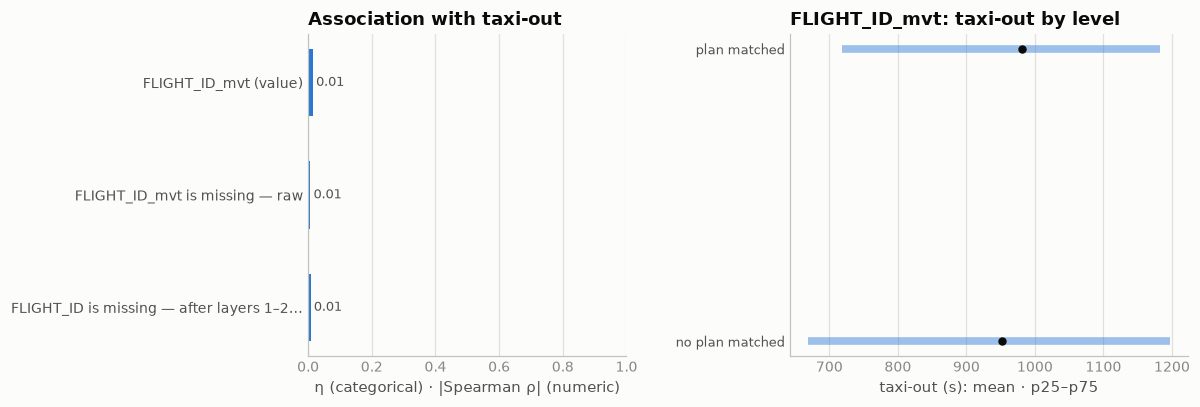

In [55]:
# correlation with the target: the value (a counter), and the is-missing flag before and after the twin layers
L12 = (f"(SELECT t.*, coalesce(t.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered, l2.FLIGHT_ID_recovered) fid_after "
       f"FROM {TGT} t "
       f"LEFT JOIN read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') l1 USING (MVT_ID_mvt) "
       f"LEFT JOIN read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet') l2 USING (MVT_ID_mvt))")
a = target_assoc([("FLIGHT_ID_mvt (value)", "num", "FLIGHT_ID_mvt"),
              ("FLIGHT_ID_mvt is missing — raw", "cat", "FLIGHT_ID_mvt IS NULL"),
              ("FLIGHT_ID is missing — after layers 1–2 (twin recoveries)", "cat", "fid_after IS NULL", 1, L12)])
assoc_chart(a, "CASE WHEN FLIGHT_ID_mvt IS NULL THEN 'no plan matched' ELSE 'plan matched' END", title="FLIGHT_ID_mvt")

**Findings**

| layer | training | ranking | what it restores |
|---|---:|---:|---|
| 1 · exact twin (2b) | 892 | 226 | full `_flt` block + `FLIGHT_ID` |
| 2 · relaxed twin (2c), stages A / B / C | 1,007 = 527 / 217 / 263 | 253 = 102 / 50 / 101 | full `_flt` block + `FLIGHT_ID` |
| 3 · history imputation (2c) | 19,157 | 4,539 | static fields only, operator at ≥ 95% validated accuracy |
| **still bare** | 1,368 | **265 — 0.08% of predictions** | |
| unmatched departures in total | 22,424 | 5,283 | |

Imputation targets were the 25,329 departures still missing after layers 1–2 (4,804 ranking):

| field | any value | at ≥ 95% validated accuracy | of which ranking |
|---|---:|---:|---:|
| `AIRCRAFT_OPERATOR_flt` | 23,696 | 23,696 | 4,539 |
| `WK_TBL_CAT_flt` | 24,229 | 24,229 | 4,622 |
| `AIRCRAFT_TYPE_flt` | 23,436 | 22,607 | 4,299 |
| `FLIGHT_TYPE_flt` | 22,745 | 19,658 | 3,780 |
| `MARKET_SEGMENT_flt` | 20,364 | 19,219 | 3,638 |

Rows with operator, wake and aircraft type all imputed, operator at ≥ 95%: 22,923 (4,419 ranking).

**After everything — what changed for the departures we model**

| `FLIGHT_ID_mvt` missing on departures | raw | after layer 1 | after layer 2 |
|---|---:|---:|---:|
| training (2,085,047) | 22,424 — 1.08% | 21,532 | 20,525 — 0.98% |
| ranking (344,841) | 5,283 — 1.53% | 5,057 | 4,804 — 1.39% |

| field, % of departures missing | training raw → after | ranking raw → after |
|---|---:|---:|
| `AOBT_3_flt` (layers 1–2 only) | 1.08 → 0.99 | 1.53 → 1.40 |
| `AIRCRAFT_OPERATOR_flt` | 1.08 → 0.07 | 1.53 → 0.08 |
| `WK_TBL_CAT_flt` | 1.08 → 0.05 | 1.54 → 0.06 |
| `AIRCRAFT_TYPE_flt` | 1.08 → 0.08 | 1.53 → 0.09 |
| `FLIGHT_TYPE_flt` | 1.08 → 0.11 | 1.53 → 0.12 |
| `MARKET_SEGMENT_flt` | 1.08 → 0.20 | 1.53 → 0.27 |

The ID itself, and with it the `AOBT_3` anchor, moves by a tenth of a point: twins exist only for
legs between two hubs. The static categoricals are what recovery really buys — from 1.5% missing
to under 0.3% on the rows we predict.

**How the pipeline should consume the three layers** — a row appears in at most one:

| priority | file | fields | join |
|---|---|---|---|
| 0 · raw `_flt` | the challenge files | | |
| 1 · exact twin | `data/derived/recovered_flt_blocks.parquet` | full block + `FLIGHT_ID` | `MVT_ID_mvt` |
| 2 · relaxed twin | `data/derived/recovered_flt_relaxed.parquet` | full block + `FLIGHT_ID` + `matcher_variant` | `MVT_ID_mvt` |
| 3 · history imputation | `data/derived/imputed_flt_static.parquet` | static fields, with per-field `_tier` / `_low_conf` | `MVT_ID_mvt` |

| rule | why |
|---|---|
| coalesce raw → 1 → 2 → 3 | strictest evidence first |
| treat twin-recovered rows like matched rows | they are real plan data; the `AOBT_3` implied-taxi anchor works |
| keep the "no flight plan" indicator TRUE on imputed rows | imputed values are estimates, and the flag carries the delay signal |
| ignore `FLIGHT_TYPE_flt` values flagged `_low_conf` | 78–80% validated accuracy |
| never expect timestamps from layer 3 | unrecoverable by construction |
| regenerate all three files by running this notebook top to bottom | derived, gitignored artifacts |

## 3 · `FLIGHT_mvt` — the flight number (sort of)

The docs describe it as *"what you see on your boarding pass"*. In practice the airport logged
whatever identifier the movement flew under, and that comes in flavors:

- **~78%** ICAO-callsign style — 3-letter airline code + digits (`ITY058`, `UAE81W`);
- **~21%** IATA marketing style — 2-character code + digits (`LH440`);
- **~1%** everything else, mostly **aircraft registrations** (`HBLVC`, `N77LD`, `CSDHX`) —
  business/general aviation with no commercial flight number flies under its tail number.

A flight number is an *identity*: the same number flies the same route at the same slot, day
after day. So the interesting stats are how many movements share one number, how it relates to
`CALLSIGN_flt`, whether 2026 still uses 2025's numbers — and whether the identity carries
taxi-time signal.

In [17]:
cat_stats("FLIGHT_mvt")

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,410,0.01,74532
ranking 2026,689534,97,0.01,35546


In [18]:
# the few rows with no number at all: matched flights that simply lack the field
print("rows with a null/empty FLIGHT_mvt:")
print(con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_matched,
           count(*) FILTER (CALLSIGN_flt IS NOT NULL) has_callsign,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           round(100.0*count(*) FILTER (hub = 'LIRF')/count(*)) pct_at_lirf
    FROM (SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub
          FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R}))
    WHERE FLIGHT_mvt IS NULL OR trim(FLIGHT_mvt) = ''
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

FMT = """CASE
    WHEN FLIGHT_mvt IS NULL THEN 'null'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]') THEN 'ICAO style (XXX123)'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z0-9]{2}[0-9]{1,4}[A-Z]?$') THEN 'IATA style (XX123)'
    ELSE 'registration / other' END"""

per_num = con.sql(f"""
    SELECT round(avg(c)) mean, quantile_cont(c, 0.5) med, quantile_cont(c, 0.9) p90, max(c) max,
           count(*) FILTER (c = 1) seen_once
    FROM (SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt)""").df()
top = con.sql(f"SELECT FLIGHT_mvt, count(*) n FROM {T} GROUP BY 1 ORDER BY n DESC LIMIT 5").df()
cs = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt = CALLSIGN_flt)/count(*), 1)
    FROM {T} WHERE FLIGHT_mvt IS NOT NULL AND CALLSIGN_flt IS NOT NULL""").fetchone()[0]
cov = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))/count(*), 1),
           count(*) FILTER (FLIGHT_mvt NOT IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL)),
           count(DISTINCT FLIGHT_mvt) FILTER (FLIGHT_mvt NOT IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))
    FROM {R} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL""").fetchone()

print("\nmovements per flight number (training):")
print(per_num.to_string(index=False))
print("\nbusiest numbers (≈ twice daily, year round):")
print(top.to_string(index=False))
print(f"\nFLIGHT_mvt == CALLSIGN_flt (where both present):  {cs}%")
print(f"ranking DEP rows whose number was seen in 2025:  {cov[0]}%  "
      f"({cov[1]:,} rows carry one of {cov[2]:,} new numbers)")

# signal check, honest: per-number means fitted on Jan–Oct (support ≥ 20), scored on Nov+Dec;
# a number without history falls back to the airport mean, itself fitted on Jan–Oct
print("\ndoes the number beat the airport? fit Jan–Oct 2025, score Nov+Dec (1–3600 s):")
print(con.sql(f"""
    WITH d AS (SELECT FLIGHT_mvt f, ADEP_mvt ap, TAXITIME_SEC_mvt::DOUBLE y,
                      month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND FLIGHT_mvt IS NOT NULL),
         apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         fm AS (SELECT f, avg(y) m FROM d WHERE fit GROUP BY 1 HAVING count(*) >= 20)
    SELECT count(*) n_val,
           round(100.0*count(*) FILTER (fm.m IS NOT NULL)/count(*), 1) pct_with_history,
           round(sqrt(avg((y - apm.m)^2)), 1) rmse_airport_mean,
           round(sqrt(avg((y - coalesce(fm.m, apm.m))^2)), 1) rmse_number_mean_w_fallback,
           round(sqrt(avg((y - apm.m)^2) FILTER (fm.m IS NOT NULL)), 1) rmse_airport_covered_rows,
           round(sqrt(avg((y - fm.m)^2) FILTER (fm.m IS NOT NULL)), 1) rmse_number_covered_rows
    FROM d JOIN apm USING (ap) LEFT JOIN fm USING (f) WHERE NOT fit""").df().to_string(index=False))

rows with a null/empty FLIGHT_mvt:
     src   n  n_matched  has_callsign  dep  pct_at_lirf
training 410        309           309  188        100.0
 ranking  97         66            65   58        100.0



movements per flight number (training):
 mean  med   p90  max  seen_once
 56.0  4.0 208.9  730      24555

busiest numbers (≈ twice daily, year round):
FLIGHT_mvt   n
    UAE81W 730
    ITY058 728
    UAE256 727
     SQ026 727
    ITY316 727

FLIGHT_mvt == CALLSIGN_flt (where both present):  72.8%
ranking DEP rows whose number was seen in 2025:  80.7%  (66,616 rows carry one of 6,756 new numbers)

does the number beat the airport? fit Jan–Oct 2025, score Nov+Dec (1–3600 s):
 n_val  pct_with_history  rmse_airport_mean  rmse_number_mean_w_fallback  rmse_airport_covered_rows  rmse_number_covered_rows
327455              63.4              357.3                        337.6                      360.3                     328.9


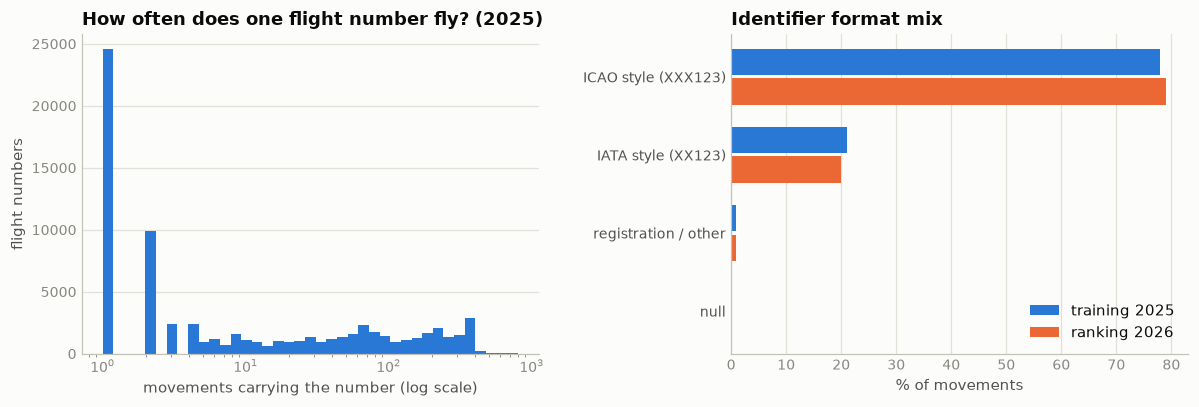

In [19]:
cnts = con.sql(f"""
    SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt""").df().c
fmt_mix = con.sql(f"""
    WITH t AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {T} GROUP BY 1),
         r AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {R} GROUP BY 1)
    SELECT coalesce(t.f, r.f) fmt, coalesce(t.pct, 0) pct_t, coalesce(r.pct, 0) pct_r
    FROM t FULL JOIN r USING (f) ORDER BY pct_t""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.logspace(0, np.log10(800), 40)
a1.hist(cnts, bins=bins, color=BLUE)
a1.set_xscale("log")
a1.set_title("How often does one flight number fly? (2025)")
a1.set_xlabel("movements carrying the number (log scale)")
a1.set_ylabel("flight numbers")
style(a1)

y = np.arange(len(fmt_mix))
a2.barh(y + 0.19, fmt_mix.pct_t, height=0.34, color=BLUE, label="training 2025")
a2.barh(y - 0.19, fmt_mix.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a2.set_yticks(y, fmt_mix.fmt, color=INK2)
a2.set_title("Identifier format mix")
a2.set_xlabel("% of movements")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

                                                  feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_mvt — levels with ≥ 20 departures, the rest pooled categorical       14237                        0.608
         format class — ICAO / IATA / registration / null categorical           4                        0.215
                               flies under a registration categorical           2                        0.057


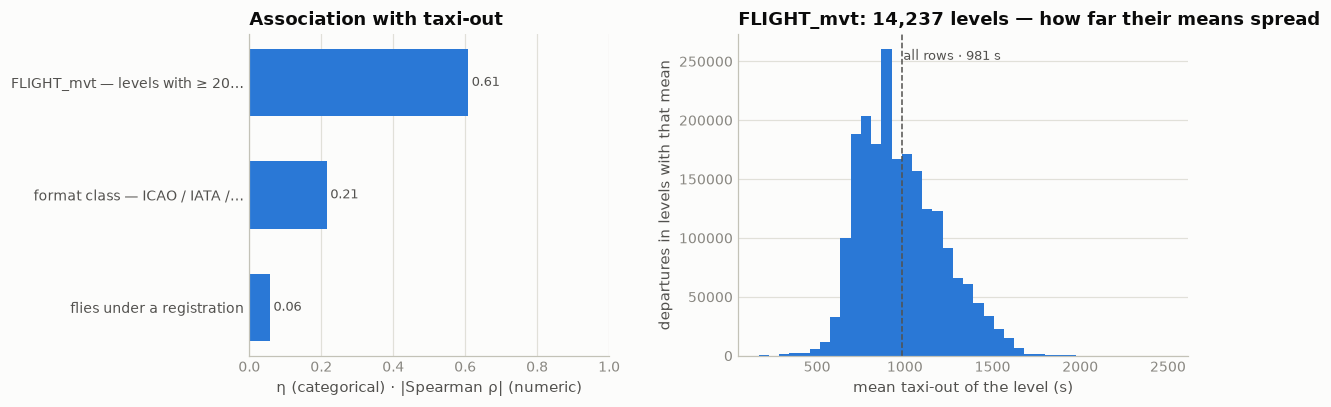

In [54]:
# correlation with the target: the number itself (frequent levels only), its format, and the registration flag
a = target_assoc([("FLIGHT_mvt — levels with ≥ 20 departures, the rest pooled", "cat", "FLIGHT_mvt", 20),
              ("format class — ICAO / IATA / registration / null", "cat", FMT),
              ("flies under a registration", "cat", f"({FMT}) = 'registration / other'")])
assoc_chart(a, "FLIGHT_mvt", min_support=20, title="FLIGHT_mvt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Practically never null — and the gap is Rome's | 410 training rows and 97 ranking rows (0.01%), **all at LIRF**; 309 and 66 of them are matched and carry a `CALLSIGN_flt` | the callsign fills the hole when the number is missing; nothing to recover |
| A heavy-tailed identity | 74,532 distinct numbers in 2025; the median number flies **4×** a year, 24,555 fly once, the busiest (`UAE81W`, `ITY058`, `SQ026`) ~730× | any encoding must cope with numbers seen a handful of times |
| Near-duplicate of `CALLSIGN_flt` | equal on 72.8% of matched rows; the rest is IATA-vs-ICAO spelling (`LH440` vs `DLH440`) | one identity in two spellings — the IATA→ICAO map of §2c is learned from exactly these pairs |
| Format mix is stable | ~78% ICAO style, ~21% IATA style, ~1% registrations, the same in 2026 | no drift; the registration slice is the GA/bizav marker |
| Schedule churn | 80.7% of ranking departures reuse a 2025 number; **66,616 rows (19.3%) carry one of 6,756 new numbers** | a raw category would be blind on a fifth of the predictions |
| The identity carries signal — honestly measured | per-number means fitted on Jan–Oct, scored on Nov+Dec: airport mean **357.3 s → 337.6 s** with fallback; on the 63.4% of rows whose number has ≥ 20 prior flights, 360.3 → 328.9 s | a number bundles airline, route, slot and terminal in one token. (The in-sample version of this check said 344 → 301 s — flattering; this is the number to trust) |

**Use in modeling.** Not as a raw high-cardinality category. Use smoothed target and frequency
encodings with fallback to coarser identities — operator, route, airport — and a "flies under a
registration" flag. Two roles it already plays elsewhere: its **prefix is an operator token**
when the plan block is missing (§2b), and it is the **key for history imputation** (§2c).

## 4 · `FLIGHT_RULE_mvt` — flight rules: instrument or visual

The docs promise three values — `I` = IFR, `V` = VFR, `NA` = unknown — but the file uses a real
NULL where the docs say `NA`. At ten major hubs essentially everything flies IFR, so this is less
a category than a **rare-event flag**: who on earth flies *visually* out of Schiphol, and does
that change how long they taxi?

| step | question | what came out |
|---|---|---|
| **4 · the flag** | how rare are `V` and NULL, is the mix stable into 2026, how does the rule relate to §2's match and to its `FLIGHT_RULE_flt` sibling, does it carry taxi signal? | 0.15% `V`, every one unmatched; the plan side adds the mixed-rule codes `Y`/`Z`; VFR is two hubs' special-mission fleets, taxiing in their own way |
| **4a · the 689 rows with no rule** | noise or structure — and can the rule be recovered? | three stories, none random; recovered from the plan, a history vote, or the airframe |
| **final form** | one rule for every movement | precedence *recovered null → `V` from the movement → `Y`/`Z` from any plan → `I`*; 100% coverage, before → after at the end |

In [21]:
display(cat_stats("FLIGHT_RULE_mvt"))

con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅ null') "rule",
           count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
           count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr,
           round(100.0 * count(*) FILTER (src = 't')
                 / sum(count(*) FILTER (src = 't')) OVER (), 3) pct_train,
           round(100.0 * count(*) FILTER (src = 'r')
                 / sum(count(*) FILTER (src = 'r')) OVER (), 3) pct_rank
    FROM (SELECT 't' src, PHASE_mvt, FLIGHT_RULE_mvt FROM {T}
          UNION ALL SELECT 'r', PHASE_mvt, FLIGHT_RULE_mvt FROM {R})
    GROUP BY 1 ORDER BY t_dep DESC""").df()

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,689,0.02,2
ranking 2026,689534,84,0.01,2


,rule,t_dep,t_arr,r_dep,r_arr,pct_train,pct_rank
0,I,2081914,2079115,344402,344150,99.838,99.858
1,V,2930,3149,419,479,0.146,0.130
2,∅ null,203,486,20,64,0.017,0.012


In [22]:
# how the rule interacts with the flight-plan match of §2
print("share of movements without a flight-plan match, by rule:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') "rule", count(*) n,
           round(100.0 * count(*) FILTER (FLIGHT_ID_mvt IS NULL) / count(*), 1) pct_unmatched
    FROM {T} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nmatched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') mvt, coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

print("\nmedian DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

share of movements without a flight-plan match, by rule:
rule       n  pct_unmatched
   I 4161029            0.6
   V    6079          100.0
   ∅     689           14.9

matched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:
mvt flt       n
  I   I 4126828
  I   ∅    7129
  I   Y    1425
  I   Z     895
  ∅   I     432
  ∅   Y      79
  ∅   Z      74
  I   V       4
  ∅   ∅       1

median DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):
flt       n  med_taxi
  I 2057904     911.0
  Y    1414     654.0
  ∅     120     661.5
  Z       5     563.0
  V       4     412.5


top VFR departure identities (ICAO-style callsigns, training):
pfx  typ   ap   n
ZXP A139 EHAM 845
NCG DH8A EHAM 544
ICC C208 LEBL 134
FCK B350 EDDF  15
RGA A109 LSZH   8
BPO AS32 EDDM   6


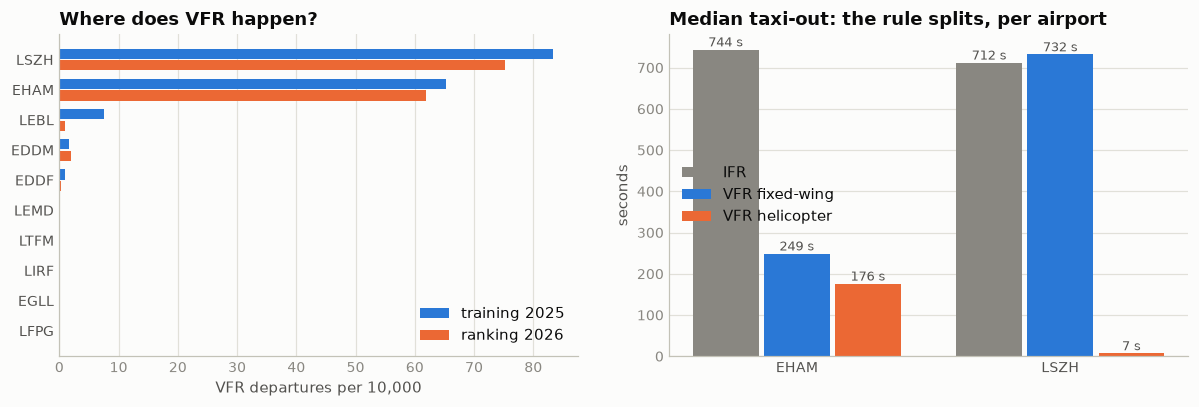

VFR departures, Nov+Dec holdout (1–3600 s):
 n_vfr_val  rmse_airport_mean  rmse_airport_x_vfr_x_heli
       343              559.9                      278.1


In [23]:
# who flies VFR at a top-10 hub, and how do they taxi?
VFR_ID = "regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]')"
HELI = ("('A139','A109','A169','A189','AS32','AS50','B06','B407','B429','B505',"
        "'EC20','EC35','EC45','EC55','H145','H160','R44','S76')")

print("top VFR departure identities (ICAO-style callsigns, training):")
print(con.sql(f"""
    SELECT substr(FLIGHT_mvt, 1, 3) pfx, mode(AIRCRAFT_TYPE_mvt) typ, mode(ADEP_mvt) ap, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V' AND {VFR_ID}
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

vfr_rate = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.r rate_t, r.r rate_r FROM t JOIN r USING (ap) ORDER BY rate_t""").df()

med = con.sql(f"""
    SELECT ADEP_mvt ap,
           CASE WHEN FLIGHT_RULE_mvt = 'I' THEN 'IFR'
                WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'VFR helicopter'
                ELSE 'VFR fixed-wing' END grp,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EHAM', 'LSZH')
      AND FLIGHT_RULE_mvt IS NOT NULL AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(vfr_rate))
a1.barh(y + 0.19, vfr_rate.rate_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, vfr_rate.rate_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, vfr_rate.ap, color=INK2)
a1.set_title("Where does VFR happen?")
a1.set_xlabel("VFR departures per 10,000")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

d = med.set_index(["ap", "grp"]).med
x = np.arange(2)
for i, (g, c) in enumerate([("IFR", MUTED), ("VFR fixed-wing", BLUE), ("VFR helicopter", ORANGE)]):
    bars = a2.bar(x + (i - 1) * 0.27, [d.get(("EHAM", g)), d.get(("LSZH", g))],
                  width=0.25, color=c, label=g)
    a2.bar_label(bars, fmt="%.0f s", fontsize=8.5, color=INK2)
a2.set_xticks(x, ["EHAM", "LSZH"], color=INK2)
a2.set_title("Median taxi-out: the rule splits, per airport")
a2.set_ylabel("seconds")
a2.legend()
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

# signal check on the rows the flag touches — honest: means fitted on Jan–Oct, scored on Nov+Dec
print("VFR departures, Nov+Dec holdout (1–3600 s):")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, FLIGHT_RULE_mvt fr,
                      CASE WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'h' ELSE 'f' END k,
                      TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         grp AS (SELECT ap, k, avg(y) m FROM d WHERE fit AND fr = 'V' GROUP BY 1, 2)
    SELECT count(*) n_vfr_val, round(sqrt(avg((y - apm.m)^2)), 1) rmse_airport_mean,
           round(sqrt(avg((y - coalesce(grp.m, apm.m))^2)), 1) rmse_airport_x_vfr_x_heli
    FROM d JOIN apm USING (ap) LEFT JOIN grp USING (ap, k) WHERE NOT fit AND fr = 'V'""").df().to_string(index=False))

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Practically constant | **99.85% `I`**, 0.14% `V` (6,079 movements in 2025), 689 true NULLs — the docs' `NA` never appears as a string. Same mix in ranking; 419 of the 344,841 predictions are VFR | a rare-event flag, not a category |
| **`V` ⇒ unmatched, without exception** | all 6,079 VFR movements have no `FLIGHT_ID_mvt` and a fully NULL `_flt` block | NM plans are an IFR affair. This is §2's *excused* slice: §2b/2c chased unmatched IFR only, so for VFR rows the `_flt` features are structurally missing and the "no flight plan" indicator stays TRUE |
| The plan side is finer, not different | matched rows agree; 2,320 movements are `Y`/`Z` (rule change en route) that `_mvt` flattens to `I`, and they taxi shorter — median 654 s vs 911 s for pure-IFR departures | keep `Y`/`Z` distinct |
| The nulls are mostly matched rows | 85% of the 689 carry a plan; 79 of the 203 DEP nulls are `Y` | the airport system chokes on mixed-rule plans — 4a |
| VFR at a top-10 hub = special-mission fleets at two airports | EHAM 65/10k (`ZXP` AW139 helicopters, `NCG` coastguard Dash-8s), LSZH 83/10k (HB-registered light singles, `RGA` Rega helicopters); a sprinkle at LEBL (`ICC` Cessna Caravans), EDDM, EDDF; **zero** at LTFM, LFPG, EGLL, LIRF. The same fleets show up in 2026 | the flag only means something together with the airport |
| A big lever on its own rows, in opposite directions per airport | EHAM medians: helicopter 176 s, fixed-wing 249 s, IFR 744 s. LSZH: fixed-wing VFR 732 s like an airliner, helicopters **7 s** (Rega departs from its own base). Honest holdout on the 343 Nov+Dec VFR departures: airport mean 560 s → airport × VFR × helicopter mean **278 s** | an IFR-trained model predicts a 12-minute taxi for a helipad departure |

**Use in modeling.** Feed the model `coalesce(FLIGHT_RULE_mvt, FLIGHT_RULE_flt)` (keeping
`Y`/`Z` distinct) plus an is-helicopter flag from `AIRCRAFT_TYPE_mvt`, and let them interact
with airport. Only ~0.12% of ranking rows are VFR, so the total-RMSE gain is well under 1 s —
but it is free, and these are exactly the rows where the model would otherwise embarrass itself.

### 4a · The 689 rows with no rule

689 training rows and 84 ranking rows (20 of them predictions) carry no `FLIGHT_RULE_mvt`.
Three questions: are they random (a logging hiccup) or a particular kind of traffic; can the
rule be recovered — from the matched plan, from the identity's history, or from the airframe;
and should the pipeline care?

In [24]:
NLL = f"(SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub FROM {T} WHERE FLIGHT_RULE_mvt IS NULL)"

print("null-rule rows by hub × phase × what the matched plan says:")
print(con.sql(f"""
    SELECT hub, PHASE_mvt ph, coalesce(FLIGHT_RULE_flt, '(unmatched)') flt, count(*) n
    FROM {NLL} GROUP BY 1, 2, 3 ORDER BY hub, ph, n DESC""").df().to_string(index=False))

print("\nwho loses the flag? market segment, null rows vs the whole file:")
print(con.sql(f"""
    WITH a AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {NLL} GROUP BY 1),
         b AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {T} GROUP BY 1)
    SELECT coalesce(a.seg, '(unmatched)') seg, a.n,
           round(100.0 * a.n / sum(a.n) OVER (), 1) pct_of_nulls,
           round(100.0 * b.n / sum(b.n) OVER (), 1) pct_of_all
    FROM a JOIN b ON a.seg IS NOT DISTINCT FROM b.seg ORDER BY a.n DESC""").df().to_string(index=False))

print("\nnull count by date — one date dominates:")
print(con.sql(f"""
    SELECT MVT_TIME_UTC_mvt::DATE d, count(*) n, mode(hub) hub FROM {NLL}
    GROUP BY 1 ORDER BY n DESC LIMIT 4""").df().to_string(index=False))

print("\nEHAM on 20 July 2025, hour by hour — the flag drops for part of the afternoon:")
print(con.sql(f"""
    SELECT hour(MVT_TIME_UTC_mvt) h, count(*) mvts,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) n_null
    FROM {T}
    WHERE (CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) = 'EHAM'
      AND MVT_TIME_UTC_mvt::DATE = DATE '2025-07-20'
    GROUP BY 1 ORDER BY 1""").df().set_index("h").T.to_string())

# the unmatched nulls, and how far history can carry the rest
print("unmatched null-rule rows — top airframes and the identities they fly under:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n,
           substr(string_agg(DISTINCT FLIGHT_mvt, ', '), 1, 48) ids
    FROM {NLL} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nrecovery accounting (training):")
print(con.sql(f"""
    WITH hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT CASE
        WHEN FLIGHT_RULE_flt = 'I' THEN '1 · plan says I'
        WHEN FLIGHT_RULE_flt = 'Y' AND PHASE_mvt = 'DEP' THEN '2 · Y dep (IFR at the hub)'
        WHEN FLIGHT_RULE_flt = 'Z' AND PHASE_mvt = 'ARR' THEN '2 · Z arr (IFR at the hub)'
        WHEN v.r IS NOT NULL THEN '3 · history vote → ' || v.r
        ELSE '4 · unknown' END bucket, count(*) n
    FROM {NLL} LEFT JOIN vote v USING (FLIGHT_mvt) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nhow unanimous are the history votes?")
print(con.sql(f"""
    WITH ids AS (SELECT DISTINCT FLIGHT_mvt FROM {NLL}
                 WHERE FLIGHT_RULE_flt IS NULL AND FLIGHT_mvt IS NOT NULL),
         hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         agg AS (SELECT FLIGHT_mvt, arg_max(r, c) r, sum(c) tot, max(c) top FROM hist GROUP BY 1)
    SELECT r vote, count(*) identities, round(avg(100.0 * top / tot), 1) avg_purity_pct,
           min(tot) min_history, max(tot) max_history
    FROM ids JOIN agg USING (FLIGHT_mvt) GROUP BY 1""").df().to_string(index=False))

null-rule rows by hub × phase × what the matched plan says:
 hub  ph         flt   n
EDDF ARR           Z  72
EDDF ARR           I  24
EDDF ARR (unmatched)  20
EDDF DEP           Y  79
EDDF DEP (unmatched)  15
EDDF DEP           I   3
EDDM ARR           I  70
EDDM ARR (unmatched)   2
EDDM DEP           I   4
EHAM ARR           I 254
EHAM ARR (unmatched)  42
EHAM ARR           Z   2
EHAM DEP           I  77
EHAM DEP (unmatched)  25

who loses the flag? market segment, null rows vs the whole file:
          seg   n  pct_of_nulls  pct_of_all
     Business 260          37.7         2.1
     Mainline 166          24.1        63.6
  (unmatched) 104          15.1         0.9
     Regional  80          11.6        10.2
      Lowcost  40           5.8        19.2
Non-Scheduled  12           1.7         0.7
        Cargo  11           1.6         2.9
        Other  10           1.5         0.4
     Military   6           0.9         0.0

null count by date — one date dominates:
         d   n  h

h       0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
mvts     8   2   1  15  31  84  90  78  94  88  80  96  76  92  81  81  86  73  75  83  83  38  15  10
n_null   0   0   0   0   0   0   0   0   1   7   7  29  27  35  24  15  14  14   8   3   1   0   0   0
unmatched null-rule rows — top airframes and the identities they fly under:
 typ  n                                              ids
EH10 13              ZJ995, ZK001, ZJ995A, ZJ119, ZK001A
PC12 11 YY98872, YY98542, YY98242, JFA047Z, YY98352, YY9
A139 11 ZXP25B, ZXP25Z, ZXP24B, ZXP26B, ZXP24A, NCG04A, 
LYNX  7                   AAC105, AAC103, AAC102, AAC101
PC24  6 FYL023V, FYL024V, FYL081G, FYL021G, DCOIN1, DCJM
 S61  6                                     NH60A, NH60B
AS32  5                              S441A, S449A, S455A
PRM1  4               YY98262, YY98162, YY98306, YY98961

recovery accounting (training):
                    bucket   n
           1 · plan says I 432
2 · Y d

In [25]:
# recover every null (training + ranking) with provenance -> data/derived/rule_recovered.parquet
# §4's HELI list + the military/SAR rotorcraft seen above (types the excused VFR fleet never uses)
HELI_ALL = HELI[:-1] + ",'EH10','LYNX','S61','S92','H47','NH90','PUMA')"

rec = con.sql(f"""
    WITH pool AS (
        SELECT MVT_ID_mvt, 'training' dataset, PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NULL
        UNION ALL
        SELECT MVT_ID_mvt, 'ranking', PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NULL),
    hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM
                 (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NOT NULL
                  UNION ALL
                  SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NOT NULL)
             WHERE FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
    vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT MVT_ID_mvt, dataset,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN FLIGHT_RULE_flt
                WHEN v.r IS NOT NULL THEN v.r
                WHEN AIRCRAFT_TYPE_mvt IN {HELI_ALL} THEN 'V' ELSE 'I' END rule_rec,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN 'flt'
                WHEN v.r IS NOT NULL THEN 'history_vote'
                ELSE 'type_guess' END rule_src
    FROM pool LEFT JOIN vote v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/rule_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "rule_src"]).rule_rec.value_counts().unstack(fill_value=0))

wrote 773 rows → data/derived/rule_recovered.parquet
rule_rec                 I   V   Y   Z
dataset  rule_src                     
ranking  flt            47   0   8   6
         history_vote   11   3   0   0
         type_guess      9   0   0   0
training flt           432   0  79  74
         history_vote   38  25   0   0
         type_guess     17  24   0   0


In [26]:
# ---- final accounting: one rule for every movement ----
REC = f"read_parquet('{ROOT}/data/derived/rule_recovered.parquet')"
TWIN = (f"(SELECT MVT_ID_mvt, FLIGHT_RULE_flt frw FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
        f" UNION ALL SELECT MVT_ID_mvt, FLIGHT_RULE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")

# precedence: recovered nulls (4a) · mvt's V (the hub-leg fact) · Y/Z from any plan source
# (refines a flat I) · mvt's I. The twin layers' six Y/Z rows sit on mvt-V movements, so V wins.
FINAL = f"""
    SELECT t.*, CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN rec.rule_rec
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN coalesce(t.FLIGHT_RULE_flt, w.frw)
             ELSE t.FLIGHT_RULE_mvt END rule_final,
           CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN 'was null · ' || rec.rule_src
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'mvt says V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN 'flt Y/Z refines a flat I'
             ELSE 'mvt says I' END prov
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R}) t
    LEFT JOIN {TWIN} w USING (MVT_ID_mvt)
    LEFT JOIN {REC} rec USING (MVT_ID_mvt)"""

left_over = con.sql(f"WITH f AS ({FINAL}) SELECT count(*) FROM f WHERE rule_final IS NULL").fetchone()[0]
print(f"rows still without a rule: {left_over}")
assert left_over == 0

print("\nbefore -> after, by file × phase:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT ds, PHASE_mvt ph, count(*) n,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) null_raw, count(*) FILTER (rule_final IS NULL) null_after,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I') i_raw, count(*) FILTER (rule_final = 'I') i_after,
           count(*) FILTER (FLIGHT_RULE_mvt = 'V') v_raw, count(*) FILTER (rule_final = 'V') v_after,
           count(*) FILTER (rule_final = 'Y') y_after, count(*) FILTER (rule_final = 'Z') z_after
    FROM f GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nwhere every movement's rule now comes from:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT prov, count(*) FILTER (ds = 'training') training, count(*) FILTER (ds = 'ranking') ranking
    FROM f GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))

print("\ntaxi time by final rule (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT PHASE_mvt ph, rule_final, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean,
           quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM f WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

# worth, honest: airport means and airport × rule means fitted on Jan–Oct, scored on Nov+Dec
print("\nairport mean vs airport × rule, Nov+Dec holdout (support ≥ 30, else the airport mean):")
print(con.sql(f"""WITH f AS ({FINAL}),
    d AS (SELECT ADEP_mvt ap, rule_final rf, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
          FROM f WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
    apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
    grm AS (SELECT ap, rf, avg(y) m, count(*) c FROM d WHERE fit GROUP BY 1, 2)
    SELECT count(*) n_val, round(sqrt(avg((y - apm.m)^2)), 2) rmse_airport,
           round(sqrt(avg((y - coalesce(CASE WHEN grm.c >= 30 THEN grm.m END, apm.m))^2)), 2) rmse_airport_x_rule,
           count(*) FILTER (rf != 'I') n_non_i,
           round(sqrt(avg((y - apm.m)^2) FILTER (rf != 'I')), 1) rmse_airport_non_i,
           round(sqrt(avg((y - coalesce(CASE WHEN grm.c >= 30 THEN grm.m END, apm.m))^2) FILTER (rf != 'I')), 1) rmse_rule_non_i
    FROM d JOIN apm USING (ap) LEFT JOIN grm USING (ap, rf) WHERE NOT fit""").df().to_string(index=False))

rows still without a rule: 0

before -> after, by file × phase:


      ds  ph       n  null_raw  null_after   i_raw  i_after  v_raw  v_after  y_after  z_after
training ARR 2082750       486           0 2079115  2078521   3149     3180       85      964
training DEP 2085047       203           0 2081914  2080675   2930     2948     1419        5
 ranking ARR  344693        64           0  344150   343996    479      482       17      198
 ranking DEP  344841        20           0  344402   344172    419      419      247        3

where every movement's rule now comes from:
                    prov  training  ranking
              mvt says I   4158709   688101
              mvt says V      6079      898
flt Y/Z refines a flat I      2320      451
          was null · flt       585       61
 was null · history_vote        63       14
   was null · type_guess        41        9

taxi time by final rule (training, 1–3600 s):


 ph rule_final       n  mean   p25   med     p75
DEP          I 2076404 982.0 720.0 911.0 1185.00
DEP          V    2710 381.0 124.0 244.5  577.50
DEP          Y    1414 746.0 411.0 654.0 1041.00
DEP          Z       5 500.0 424.0 563.0  575.00
ARR          I 2078021 536.0 324.0 481.0  665.00
ARR          V    3004 268.0 125.0 213.0  316.25
ARR          Z     963 421.0 299.0 381.0  496.00
ARR          Y      85 474.0 260.0 438.0  569.00

airport mean vs airport × rule, Nov+Dec holdout (support ≥ 30, else the airport mean):


 n_val  rmse_airport  rmse_airport_x_rule  n_non_i  rmse_airport_non_i  rmse_rule_non_i
327485        357.33               356.97      598               505.2            338.4


                            feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_RULE_mvt — raw, ∅ as a level categorical           3                        0.056
         rule_final — I / V / Y / Z categorical           4                        0.058
is helicopter — the rotorcraft list categorical           3                        0.050


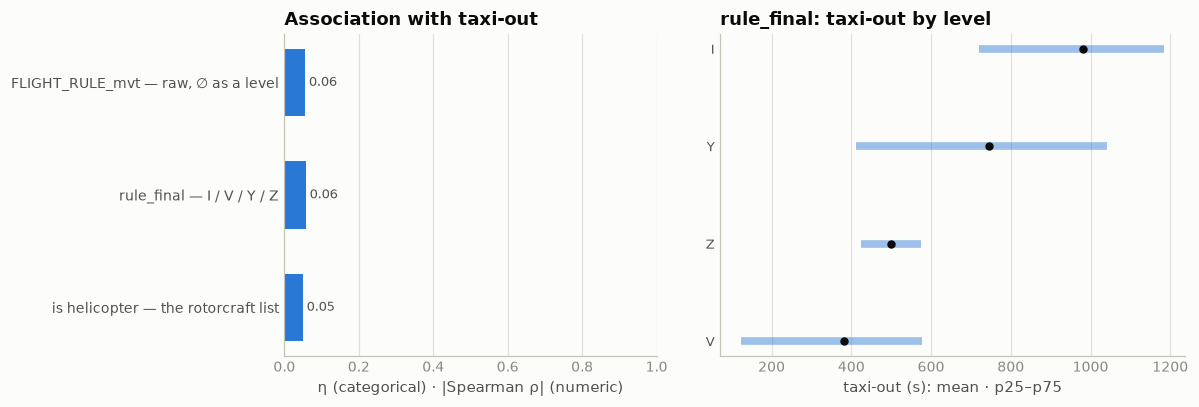

In [53]:
# correlation with the target: the raw rule (∅ as its own level), the final rule, and the helicopter flag
FIN_T = f"(SELECT * FROM ({FINAL}) WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("FLIGHT_RULE_mvt — raw, ∅ as a level", "cat", "FLIGHT_RULE_mvt"),
              ("rule_final — I / V / Y / Z", "cat", "rule_final", 1, FIN_T),
              ("is helicopter — the rotorcraft list", "cat", f"AIRCRAFT_TYPE_mvt IN {HELI_ALL}")])
assoc_chart(a, "rule_final", src=FIN_T, title="rule_final")

**Findings**

The 689 nulls are three different stories, none of them random:

| story | evidence | reading |
|---|---|---|
| **One afternoon at Schiphol** | 185 rows (27%) are EHAM on **20 July 2025**, ~09:00–19:00 UTC, up to ~40% of movements in the worst hour; the plan says `I` for nearly all of them | the flag silently dropped off part of the stream while everything else logged normally — ordinary IFR traffic. EDDM's little pile is the same disease: 44 of its 76 nulls fall on one September day |
| **Frankfurt's allergy to mixed-rule plans** | EDDF contributes 3 plain-IFR departure nulls; its nulls *are* the `Y` departures (79) and `Z` arrivals (72) | other airports flatten `Y`/`Z` to `I`; EDDF writes nothing. Both legs at the hub are technically IFR, but keep the codes distinct — `Y`-plans taxi ~4 min shorter |
| **Traffic the system barely knows** | Business Aviation is 37.7% of the nulls against 2.1% of all movements (18× over); the 104 unmatched nulls are mostly military/SAR rotorcraft — Merlins under `ZJ`/`ZK` airframe serials, Army Air Corps Lynx, Sea Kings | the organizers removed military traffic *mostly* |

**Recovery** works in layers, mirroring §2c, and is saved with provenance to
`data/derived/rule_recovered.parquet` (773 rows, joined on `MVT_ID_mvt`):

| layer | the rule comes from | training | ranking | confidence |
|---|---|---:|---:|---|
| 1 | the matched plan's `FLIGHT_RULE_flt` | 585 | 61 | exact |
| 2 | majority vote of the identity's other movements | 63 | 14 | 94–97% purity |
| 3 | the airframe: rotorcraft → `V`, else `I` | 41 | 9 | a guess |

**The rule feature, final form.** Precedence *recovered null → `V` from the movement → `Y`/`Z`
from any plan source → `I`*. The movement's `V` outranks the plan on purpose: §2b's six
V-flagged twin recoveries carry `Y`/`Z` plans, but the hub leg was flown visually, and that is
the fact that moves taxi time.

| before → after | training DEP | training ARR | ranking DEP | ranking ARR |
|---|---:|---:|---:|---:|
| NULL | 203 → **0** | 486 → **0** | 20 → **0** | 64 → **0** |
| `I` | 2,081,914 → 2,080,675 | 2,079,115 → 2,078,521 | 344,402 → 344,172 | 344,150 → 343,996 |
| `V` | 2,930 → 2,948 | 3,149 → 3,180 | 419 → 419 | 479 → 482 |
| `Y` | — → 1,419 | — → 85 | — → 247 | — → 17 |
| `Z` | — → 5 | — → 964 | — → 3 | — → 198 |

| level | training | ranking | of which predictions | median DEP taxi |
|---|---:|---:|---:|---:|
| `I` | 4,159,196 (99.794%) | 688,168 | 344,172 | 911 s |
| `V` | 6,128 (0.147%) | 901 | 419 | 244 s |
| `Y` | 1,504 (0.036%) | 264 | 247 | 654 s |
| `Z` | 969 (0.023%) | 201 | 3 | 563 s (n = 5) |

- Provenance: the raw `_mvt` column covers 99.98%; plan-side `Y`/`Z` refines 2,320 + 451 flat
  `I`s; 4a's file supplies the 773 former nulls.
- The levels are ordered and real on both sides of the operation: DEP medians 911 / 654 / 244 s
  for `I` / `Y` / `V`, taxi-in 481 / 381 / 213 s for `I` / `Z` / `V`. `Z` departures are
  near-nonexistent (5 training rows) — the level earns its keep on arrivals.
- Worth, measured honestly (fit Jan–Oct, score Nov+Dec): airport mean → airport × rule moves
  departure RMSE by **−0.4 s** (357.3 → 357.0), all of it in the 598 non-`I` holdout rows,
  where it is 505 → 338 s. A cheap, clean, never-missing categorical — exactly what §4 asked for.
- **Pipeline recipe:** the `CASE` in the cell above, verbatim — inputs are the raw columns plus
  `rule_recovered.parquet` and the two twin-recovery layers, all joined on `MVT_ID_mvt`.

## 5 · `ADEP_mvt` — aerodrome of departure

The ICAO code of the airport the flight departed from — the first column that is a *feature* in
the everyday sense. Its role flips with phase: on `DEP` rows it names the hub whose taxi-out we
predict; on `ARR` rows it is the origin — anywhere on earth — and the hub sits in `ADES_mvt`.

| step | question | what came out |
|---|---|---|
| **integrity** | nulls, ICAO's `ZZZZ` "no aerodrome" stand-in, is every departure at one of the ten hubs, does the plan's `ADEP_flt` agree? | departures flawless; on arrivals two spellings of missing and 1.2% source disagreement |
| **mix** | how traffic splits across the hubs, and whether the split holds into Jan/Jul 2026 | it holds |
| **signal** | how much taxi-out the airport alone explains | the baseline every later feature must beat |
| **decisions** | what to repair | nothing — diagnosis only, with the reasons in the closing table |

In [28]:
display(cat_stats("ADEP_mvt"))

# phase-split integrity: on DEP rows the column should be exactly the ten hub codes (APS, §2b)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ADEP_mvt IS NULL) n_null,
           count(DISTINCT ADEP_mvt) n_unique,
           count(*) FILTER (ADEP_mvt NOT IN {APS}) n_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADEP_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADEP_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADEP_flt IS NULL) flt_null,
           count(*) FILTER (ADEP_mvt = ADEP_flt) agree,
           count(*) FILTER (ADEP_mvt != ADEP_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,84,0.0,1581
ranking 2026,689534,13,0.0,1107


     src  ph       n  n_null  n_unique  n_not_hub
training ARR 2082750      84      1581    1763487
training DEP 2085047       0        10          0
 ranking ARR  344693      13      1107     292935
 ranking DEP  344841       0        10          0

does the matched plan agree? (training, by phase):
 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2042696     24554
DEP    2062623        46 2062577         0


In [29]:
# the ARR side: origin airports, and two sources that sometimes tell different stories
print("top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:")
print(con.sql(f"""
    SELECT ADEP_mvt, ADEP_flt, ADES_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL AND ADEP_mvt != ADEP_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

# "missing" has two spellings: a real NULL, and ICAO's ZZZZ = departed from a place with
# no code at all (helipad, hospital site, ship). AFIL (air-filed plan) never appears.
print("\nnull vs ZZZZ origins, arrivals only (departures have neither):")
print(con.sql(f"""
    SELECT src, count(*) FILTER (ADEP_mvt IS NULL) mvt_null, count(*) FILTER (ADEP_mvt = 'ZZZZ') mvt_zzzz,
           count(*) FILTER (ADEP_flt = 'ZZZZ') flt_zzzz,
           count(*) FILTER (ADEP_mvt = 'AFIL' OR ADEP_flt = 'AFIL') afil
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    WHERE PHASE_mvt = 'ARR' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nwho they are (training):")
print(con.sql(f"""
    SELECT CASE WHEN ADEP_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, ADES_mvt hub,
           count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) unmatched,
           count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt != 'ZZZZ') flt_names_one,
           mode(AIRCRAFT_TYPE_mvt) typ, mode(MARKET_SEGMENT_flt) seg
    FROM {T} WHERE PHASE_mvt = 'ARR' AND (ADEP_mvt IS NULL OR ADEP_mvt = 'ZZZZ')
    GROUP BY 1, 2 ORDER BY 1, n DESC""").df().to_string(index=False))

top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:
ADEP_mvt ADEP_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW87AM 2430
    LSSB     LFSB LFPG  AFR1393 1037
    OKBK     OKKK EGLL   KAC101  823
    EVRS     EVRA LFPG   BTI8GJ  546
    NTTT     KLAX LFPG     THT8  538
    KBSZ     UCFM LTFM   THY345  390
    TNCA     TNCB EHAM   KLM765  364
    HAAB     LIMC LSZH   ETH736  355
    APPH     YPPH EGLL     QFA9  348
    SKBO     SKCG EHAM   KLM749  346

null vs ZZZZ origins, arrivals only (departures have neither):
     src  mvt_null  mvt_zzzz  flt_zzzz  afil
training        84       111        20     0
 ranking        13        24         6     0

who they are (training):
  kind  hub  n  unmatched  flt_names_one  typ      seg
  ZZZZ LSZH 61         49             10 AS50 Business
  ZZZZ EHAM 45         42              0 A139 Military
  ZZZZ LIRF  4          1              3 F900 Business
  ZZZZ EDDM  1          0              0 C525 Business
∅ null EDDF 68

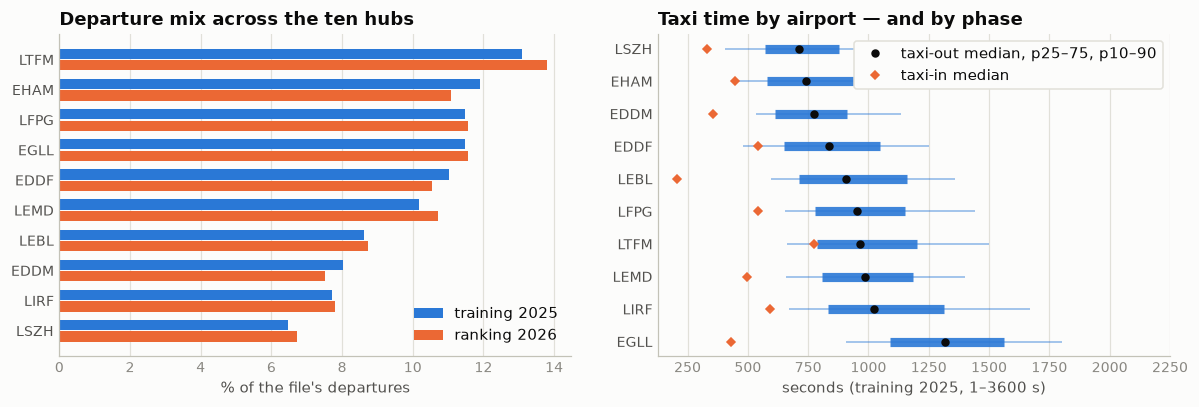

like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:
  ap   n25   n26  delta_pct
EHAM 40949 38182       -6.8
EDDM 27091 25966       -4.2
EDDF 36830 36317       -1.4
EGLL 40210 39840       -0.9
LFPG 39612 39872        0.7
LIRF 26528 26899        1.4
LTFM 46539 47581        2.2
LSZH 22346 23150        3.6
LEBL 28986 30080        3.8
LEMD 35328 36954        4.6


In [30]:
mix = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {T}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {R}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.s share_t, r.s share_r FROM t JOIN r USING (ap) ORDER BY share_t""").df()

taxi = con.sql(f"""
    SELECT ADEP_mvt ap,
           quantile_cont(TAXITIME_SEC_mvt, 0.10) p10, quantile_cont(TAXITIME_SEC_mvt, 0.25) p25,
           quantile_cont(TAXITIME_SEC_mvt, 0.50) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75, quantile_cont(TAXITIME_SEC_mvt, 0.90) p90
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df()
taxi_in = con.sql(f"""
    SELECT ADES_mvt ap, quantile_cont(TAXITIME_SEC_mvt, 0.5) med FROM {T}
    WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1""").df().set_index("ap").med

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(mix))
a1.barh(y + 0.19, mix.share_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, mix.share_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, mix.ap, color=INK2)
a1.set_title("Departure mix across the ten hubs")
a1.set_xlabel("% of the file's departures")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(taxi))
a2.hlines(y, taxi.p10, taxi.p90, color=BLUE, lw=1.2, alpha=0.45)
a2.hlines(y, taxi.p25, taxi.p75, color=BLUE, lw=6, alpha=0.9)
a2.plot(taxi.med, y, "o", color=INK, ms=4.5, zorder=3, label="taxi-out median, p25–75, p10–90")
a2.plot(taxi_in[taxi.ap].values, y, "D", color=ORANGE, ms=4, label="taxi-in median")
a2.set_yticks(y, taxi.ap, color=INK2)
a2.set_title("Taxi time by airport — and by phase")
a2.set_xlabel("seconds (training 2025, 1–3600 s)")
a2.set_xlim(right=2250)
a2.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

print("like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:")
print(con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, count(*) n25 FROM {T}
               WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, count(*) n26 FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, n25, n26, round(100.0 * (n26 - n25) / n25, 1) delta_pct
    FROM t JOIN r USING (ap) ORDER BY delta_pct""").df().to_string(index=False))

In [31]:
# how much does the airport alone explain? Honest: means fitted on Jan–Oct, scored on Nov+Dec —
# the same holdout every later section uses — with the whole-year in-sample figure for reference
print("global mean vs airport mean:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         g AS (SELECT avg(y) m FROM d WHERE fit), a AS (SELECT ap, avg(y) am FROM d WHERE fit GROUP BY 1),
         g_all AS (SELECT avg(y) m FROM d), a_all AS (SELECT ap, avg(y) am FROM d GROUP BY 1)
    SELECT 'Nov+Dec holdout, fit Jan–Oct' basis, count(*) FILTER (NOT fit) n,
           round(sqrt(avg((y - g.m)^2) FILTER (NOT fit)), 1) rmse_global_mean,
           round(sqrt(avg((y - a.am)^2) FILTER (NOT fit)), 1) rmse_airport_mean
    FROM d CROSS JOIN g JOIN a USING (ap)
    UNION ALL
    SELECT 'whole year, in-sample', count(*), round(sqrt(avg((y - g_all.m)^2)), 1), round(sqrt(avg((y - a_all.am)^2)), 1)
    FROM d CROSS JOIN g_all JOIN a_all USING (ap)""").df().to_string(index=False))

print("\ntaxi-out by hub — and the two ranking months against the 2025 medians:")
print(con.sql(f"""
    SELECT ADEP_mvt ap, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(stddev(TAXITIME_SEC_mvt)) sd,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 1) med_jan,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 7) med_jul
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df().to_string(index=False))

global mean vs airport mean:
                       basis       n  rmse_global_mean  rmse_airport_mean
Nov+Dec holdout, fit Jan–Oct  327485             392.5              357.3
       whole year, in-sample 2080533             388.0              346.6

taxi-out by hub — and the two ranking months against the 2025 medians:
  ap      n   mean    sd    med  med_jan  med_jul
EGLL 238818 1354.0 373.0 1319.0   1260.0   1371.0
LIRF 158737 1117.0 443.0 1022.0    972.0   1090.0
LEMD 212242 1015.0 313.0  985.0    954.0   1002.0
LTFM 272169 1043.0 379.0  963.0    967.0   1011.0
LFPG 239091 1013.0 365.0  954.0    907.0    962.0
LEBL 179699  957.0 331.0  906.0    838.0    945.0
EDDF 230068  862.0 324.0  837.0    825.0    839.0
EDDM 167275  811.0 294.0  774.0    729.0    780.0
EHAM 247866  783.0 311.0  742.0    726.0    751.0
LSZH 134568  741.0 292.0  712.0    706.0    720.0


In [32]:
# closing state — the column after §5, which changed nothing: no derived file, no value touched
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(DISTINCT ADEP_mvt) n_unique,
           count(*) FILTER (ADEP_mvt IS NULL) null_,
           count(*) FILTER (ADEP_mvt = 'ZZZZ') zzzz,
           count(*) FILTER (ADEP_mvt NOT IN {APS}) not_hub,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL AND ADEP_flt IS NOT NULL
                            AND ADEP_mvt != ADEP_flt) disagree_with_plan
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\nbefore = after on every count: §5 repairs nothing (see the decisions table)")

     src  ph       n  n_unique  null_  zzzz  not_hub  disagree_with_plan
training ARR 2082750      1581     84   111  1763487               24554
training DEP 2085047        10      0     0        0                   0
 ranking ARR  344693      1107     13    24   292935                4260
 ranking DEP  344841        10      0     0        0                   0

before = after on every count: §5 repairs nothing (see the decisions table)


               feature        kind  n / levels  pearson_r  spearman_ρ    η
ADEP_mvt — the airport categorical          10                        0.45


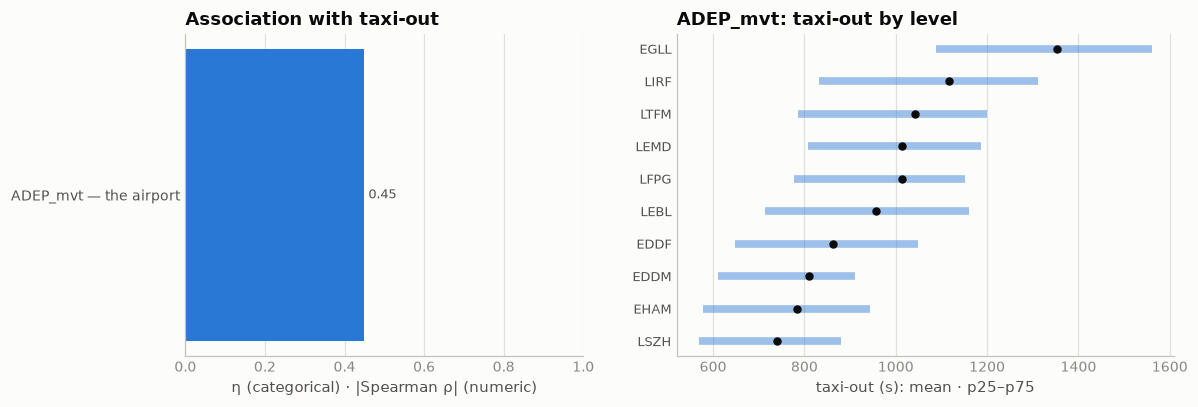

In [52]:
# correlation with the target — the airport alone
a = target_assoc([("ADEP_mvt — the airport", "cat", "ADEP_mvt")])
assoc_chart(a, "ADEP_mvt", title="ADEP_mvt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The departure side is flawless** | zero nulls; every one of the 2,085,047 training and 344,841 ranking departures carries one of the ten hub codes — never anything else, not even `ZZZZ`; the matched plan's `ADEP_flt` agrees on all 2,062,577 comparable rows (46 plan-side nulls) | ten levels, never missing, never unseen: the pipeline's primary categorical, and the interaction partner for nearly everything |
| On arrivals it is the origin | 1,581 airports in 2025 with a long tail; 15.3% of arrivals come from a sister hub | not a feature — arrivals are never predicted |
| "Missing" comes in two spellings, arrivals only | 84 true NULLs (the system lost a code — four-fifths EDDF business aviation, PC12 shuttles) and 111 `ZZZZ`, ICAO's code for *there is no code*: LSZH and EHAM rotorcraft from helipads, hospital sites and ships — §4's special-mission fleets again, mostly unmatched, correctly so. The plan side has 20 `ZZZZ` of its own | a NULL is data loss; `ZZZZ` is a statement. They are not the same defect |
| The two sources disagree on 24,554 arrivals (1.2% of matched) | 1,291 recurring schedule-level pairs — the same "wrong" code all year. Two mechanisms: **through-flights**, where `_mvt` keeps the commercial origin and `_flt` the flown leg (Air Tahiti Nui into LFPG "from" Papeete vs the LAX leg; Ethiopian's Addis→Milan→Zurich; KLM's Caribbean tag flights), and **garbled or stale codes**, mostly on `_mvt` (BA's Berlin traffic lands at EGLL "from" the military-prefix `ETNB`; Riga's `EVRS` for `EVRA`; Bali under retired `WRRR`) — though not always (Kuwait Airways' *plans* file the retired `OKKK`) | upstream mapping tables, not noise. Where origin matters, the plan's word is the better one |
| Traffic mix holds into 2026 | LTFM 13.1% down to LSZH 6.5%; like-for-like Jan+Jul, EHAM −6.8% and EDDM −4.2% against LEMD +4.6%, LEBL +3.8%, LSZH +3.6% | no airport enters or leaves |
| **The anchor feature** | median taxi-out 712 s (LSZH) to 1,319 s (EGLL) — Heathrow's *25th percentile* (1,088 s) beats every other hub's median. Nov+Dec holdout, fit Jan–Oct: global mean **392.5 → airport mean 357.3 s** (whole year in-sample: 388.0 → 346.6) | 357.3 s is the reference every later feature must beat, on the same holdout as §3, §4, §8. Within-airport spread is the whole problem: sd 292–443 s, LIRF widest |
| The phase flip is in the target, not just the schema | taxi-in has its own ordering — LEBL 906 s out vs 207 s in, EGLL 1,319 vs 428 | never pool the phases |
| July runs longer than January at every hub | EGLL 1,371 vs 1,260 s — and Jan+Jul is what we predict | owned by §8 |

**Decisions**

| issue | decision | why |
|---|---|---|
| `ADEP_mvt` ≠ `ADEP_flt` (arrivals only) | **no repair.** If origin is ever used, take `coalesce(nullif(ADEP_flt, 'ZZZZ'), nullif(ADEP_mvt, 'ZZZZ'))` | departures agree 100%; arrivals are never predicted; the plan is right more often on the garbled pairs |
| NULL and `ZZZZ` origins (arrivals only) | **left as they are**, no derived file | not predicted, and origin is not a feature. The sentinel policy for the departures' *destination* is §6's business |
| 66 origins unseen in 2026 (162 rows) | nothing | origin is not a feature |

**State after §5** — unchanged, by design:

| | training ARR | ranking ARR | DEP, both files |
|---|---:|---:|---:|
| NULL | 84 → 84 | 13 → 13 | 0 |
| `ZZZZ` | 111 → 111 | 24 → 24 | 0 |
| disagrees with the plan | 24,554 → 24,554 | 4,260 → 4,260 | 0 |

## 6 · `ADES_mvt` — aerodrome of destination

§5's mirror: on `ARR` rows this names the hub; on `DEP` rows — the rows we predict — it is
the destination, anywhere on earth. Unlike the origin, the destination *is* a feature the
pipeline uses, so its gaps land on prediction rows and get repaired here.

| step | question | what came out |
|---|---|---|
| **integrity** | the full sentinel set — ∅ / `ZZZZ` / `AFIL` — and is every arrival's destination a hub? | arrivals flawless; 243 departures carry a sentinel, 29 of them predictions |
| **agreement** | does the plan tell the same story — through-flights and garbles again, plus this side's own wrinkle, diversions, where `ADES_FILED_flt` and `ADES_flt` part ways? | 1.4% disagree, schedule-level; on diversions the movement sides with the *filed* destination |
| **signal** | what does the destination know about taxi-out? | the strongest single feature after the airport |
| **6a · recovery** | one destination for every departure: real code, `OFF_AIRPORT`, or `UNKNOWN` | a policy that treats ∅ as data loss and `ZZZZ` as a statement; before → after at the end |

In [32]:
display(cat_stats("ADES_mvt"))

# the full sentinel set this time: NULL, ZZZZ ("no such aerodrome"), AFIL (air-filed plan)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n,
           count(*) FILTER (ADES_mvt IS NULL) n_null,
           count(*) FILTER (ADES_mvt = 'ZZZZ') n_zzzz,
           count(*) FILTER (ADES_mvt = 'AFIL') n_afil,
           count(DISTINCT ADES_mvt) n_unique,
           count(*) FILTER (PHASE_mvt = 'ARR' AND ADES_mvt NOT IN {APS}) arr_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADES_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADES_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADES_flt IS NULL) flt_null,
           count(*) FILTER (ADES_mvt = ADES_flt) agree,
           count(*) FILTER (ADES_mvt != ADES_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,122,0.0,1568
ranking 2026,689534,13,0.0,1105


     src  ph       n  n_null  n_zzzz  n_afil  n_unique  arr_not_hub
training ARR 2082750       0       0       0        10            0
training DEP 2085047     122      92       0      1568            0
 ranking ARR  344693       0       0       0        10            0
 ranking DEP  344841      13      16       0      1105            0

does the matched plan agree? (training, by phase):
 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2067301         0
DEP    2062623        46 2033337     29160


In [33]:
# §5's two mechanisms mirrored outbound — plus Turkish Airlines' tag flights joining the party
print("top ADES_mvt ≠ ADES_flt pairs (training departures):")
print(con.sql(f"""
    SELECT ADES_mvt, ADES_flt, ADEP_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL AND ADES_mvt != ADES_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 12""").df().to_string(index=False))

print("\ndiversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?")
print(con.sql(f"""
    SELECT count(*) FILTER (ADES_flt != ADES_FILED_flt) diverted,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_FILED_flt) mvt_says_filed,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_flt) mvt_says_actual,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt NOT IN (ADES_flt, ADES_FILED_flt)) mvt_third
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

print("\nthe departure destination space, and what 2026 adds:")
print(con.sql(f"""
    SELECT count(DISTINCT ADES_mvt) dests_2025,
           round(100.0 * count(*) FILTER (ADES_mvt IN {APS}) / count(*), 1) pct_sister_hub
    FROM {T} WHERE PHASE_mvt = 'DEP'""").df().to_string(index=False))
print(con.sql(f"""
    WITH seen AS (SELECT DISTINCT ADES_mvt FROM {T} WHERE ADES_mvt IS NOT NULL)
    SELECT count(DISTINCT ADES_mvt) dests_2026,
           count(*) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_rows,
           count(DISTINCT ADES_mvt) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_dests
    FROM {R} WHERE PHASE_mvt = 'DEP' AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

top ADES_mvt ≠ ADES_flt pairs (training departures):
ADES_mvt ADES_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW986G 2426
    LSSB     LFSB LFPG  AFR1192 1016
    OKBK     OKKK EGLL   KAC102  815
    NTTT     KLAX LFPG     THT7  548
    EVRS     EVRA LFPG   BTI69R  545
    MMUN     MMMX LTFM   THY184  486
    HUEN     HRYR LTFM   THY43K  362
    MPTO     SKBO LTFM   THY801  362
    SAEZ     SBGR LTFM    THY15  356
    HAAB     LIMC LSZH   ETH737  354
    APPH     YPPH EGLL    QFA10  352
    ZGGG     UAAA LTFM  THY6538  333

diversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?
 diverted  mvt_says_filed  mvt_says_actual  mvt_third
     2070            1397              641         32

the departure destination space, and what 2026 adds:
 dests_2025  pct_sister_hub
       1568            15.3
 dests_2026  unseen_rows  unseen_dests
       1105          174            62


Nov+Dec holdout RMSE (s):


 n_val  rmse_airport  rmse_plus_country  rmse_plus_dest
327449         357.3              339.4           336.4


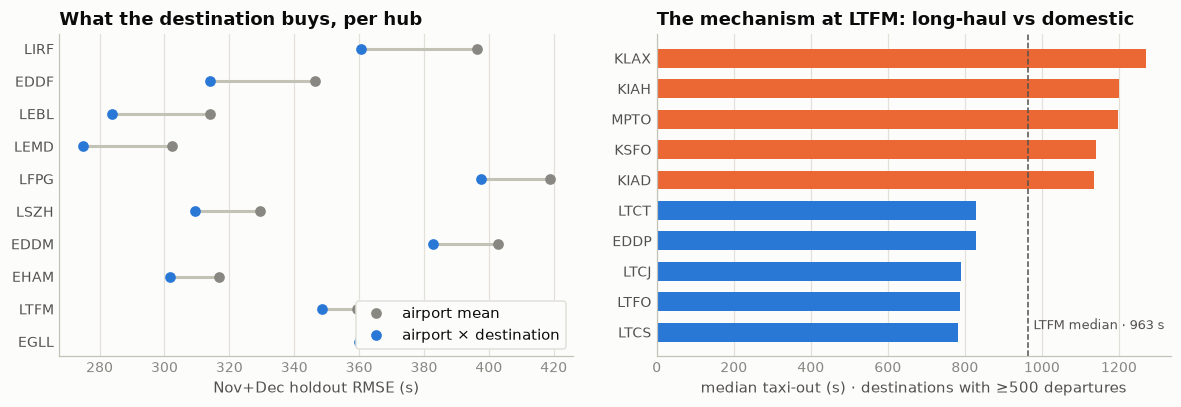

In [34]:
# does knowing where you're headed tell you how long you'll taxi? Honest: group means fitted
# on Jan–Oct (support ≥ 200, else the coarser level), scored on the Nov+Dec holdout
LAD = f"""
    WITH d AS (SELECT ADEP_mvt ap, ADES_mvt de, substr(ADES_mvt, 1, 2) cc, TAXITIME_SEC_mvt::DOUBLE y,
                      month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'),
         am AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         cm AS (SELECT ap, cc, avg(y) m FROM d WHERE fit GROUP BY 1, 2 HAVING count(*) >= 200),
         dm AS (SELECT ap, de, avg(y) m FROM d WHERE fit GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT ap, y, am.m m_airport, coalesce(cm.m, am.m) m_country, coalesce(dm.m, cm.m, am.m) m_dest
    FROM d JOIN am USING (ap) LEFT JOIN cm USING (ap, cc) LEFT JOIN dm USING (ap, de) WHERE NOT fit"""
print("Nov+Dec holdout RMSE (s):")
print(con.sql(f"""
    SELECT count(*) n_val, round(sqrt(avg((y - m_airport)^2)), 1) rmse_airport,
           round(sqrt(avg((y - m_country)^2)), 1) rmse_plus_country,
           round(sqrt(avg((y - m_dest)^2)), 1) rmse_plus_dest
    FROM ({LAD})""").df().to_string(index=False))

gain = con.sql(f"""
    SELECT ap, round(sqrt(avg((y - m_airport)^2)), 1) r_airport, round(sqrt(avg((y - m_dest)^2)), 1) r_dest
    FROM ({LAD}) GROUP BY 1 ORDER BY r_airport - r_dest""").df()

lt = con.sql(f"""
    WITH d AS (SELECT ADES_mvt de, TAXITIME_SEC_mvt y FROM {T}
               WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         m AS (SELECT de, count(*) n, quantile_cont(y, 0.5) med FROM d GROUP BY 1 HAVING count(*) >= 500)
    (SELECT * FROM m ORDER BY med DESC LIMIT 5) UNION ALL (SELECT * FROM m ORDER BY med LIMIT 5)
    ORDER BY med""").df()
lt_med = con.sql(f"""
    SELECT quantile_cont(TAXITIME_SEC_mvt, 0.5) FROM {T}
    WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").fetchone()[0]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(gain))
a1.hlines(y, gain.r_dest, gain.r_airport, color=BASELINE, lw=2)
a1.plot(gain.r_airport, y, "o", color=MUTED, ms=6, label="airport mean")
a1.plot(gain.r_dest, y, "o", color=BLUE, ms=6, label="airport × destination")
a1.set_yticks(y, gain.ap, color=INK2)
a1.set_title("What the destination buys, per hub")
a1.set_xlabel("Nov+Dec holdout RMSE (s)")
a1.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(lt))
colors = [ORANGE if m > lt_med else BLUE for m in lt.med]
a2.barh(y, lt.med, height=0.62, color=colors)
a2.axvline(lt_med, color=INK2, ls="--", lw=1)
a2.text(lt_med + 15, 0.1, f"LTFM median · {lt_med:.0f} s", color=INK2, fontsize=8.5)
a2.set_yticks(y, lt.de, color=INK2)
a2.set_title("The mechanism at LTFM: long-haul vs domestic")
a2.set_xlabel("median taxi-out (s) · destinations with ≥500 departures")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The mirror of §5 holds exactly** | on arrivals this column is the hub: ten codes, zero sentinels, and the matched plan agrees 2,067,301 times out of 2,067,301 (6,943 plan-side nulls) | nothing to do on the arrival side |
| On departures it is a real feature | 1,568 destinations, 15.3% of departures headed to a sister hub (the network is symmetric); 2026 adds 62 unseen destinations, 174 rows | a core categorical with a long tail — the model needs a fallback for the 174 |
| The sentinel census, this time on prediction rows | 122 ∅ + 92 `ZZZZ` in training, 13 + 16 in ranking — 29 predictions; `AFIL` appears nowhere | repaired in 6a |
| The two sources disagree on 29,160 departures (1.4% of matched) | §5's mechanisms viewed outbound — the same garbles and through-flights (BA's Berlin rows now *leave* "for" `ETNB`; THT7 departs LFPG "for Papeete" against the plan's KLAX leg) — plus Turkish Airlines' tag network: THY184 leaves Istanbul "for Cancún" while the plan flies the Mexico City leg, ditto Kigali→Entebbe, Bogotá→Panama, São Paulo→Buenos Aires, Almaty→Guangzhou | `_mvt` speaks the commercial through-destination, `_flt` the flown leg; both are schedule-level constants, so the pairs are left alone and any encoder can learn either dialect |
| **Diversions barely touch this column, and in the right way** | of the 2,070 diverted matched departures (`ADES_flt` ≠ `ADES_FILED_flt`), `ADES_mvt` sides with the *filed* destination 2:1 (1,397 vs 641) | the movement record is mostly a pre-departure fact — exactly what a feature should be |
| **The signal is real — honestly measured** | Nov+Dec holdout, fit Jan–Oct: airport mean **357.3 → + country prefix 339.4 → + destination 336.4 s**. Per hub the gain runs from −35.5 s (LIRF), −32.3 (EDDF), −30.1 (LEBL) down to −10.9 (LTFM) and −10.3 (EGLL). The mechanism is plain at LTFM: the median departure to `KLAX` taxis 1,270 s against 782 s for domestic `LTCS` — eight minutes of destination signal inside one airport | the strongest single feature after the airport itself. Destination is entangled with aircraft size and terminal geography; the model, not this ladder, apportions the credit |

**Use in modeling.** Destination joins airport as a core categorical. The two-letter prefix
captures most of the lift at a tiny fraction of the cardinality — keep both granularities and
let the model choose. 6a makes the column complete first.

### 6a · One destination for every departure

The sentinel policy, applied where it counts: 29 prediction rows carry a sentinel destination.
The two sentinels say opposite things, so they get opposite treatment.

| sentinel | what it means | treatment |
|---|---|---|
| **∅ null** | data loss — the system dropped a code that exists | §4a's waterfall: the matched plan → the identity's history vote → rotorcraft/VFR guess → an honest `UNKNOWN` |
| **`ZZZZ`** | a statement — this flight went where no ICAO code goes (EHAM's coastguard patrols, LSZH's rescue helicopters) | believed, and becomes the level `OFF_AIRPORT` — unless the matched plan names a real aerodrome (a lazy-entry tail of fixed-wing jets logged `ZZZZ` at the terminal) |

One design choice needs evidence rather than taste — should the history vote outrank
`OFF_AIRPORT` for `ZZZZ` rows too? — so it gets a cell.

In [35]:
# the 243 sentinel departures: what each recovery source can offer, by sentinel kind
POOLD = f"""(SELECT 'training' ds, MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')) plan_dest,
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE) heli_vfr
             FROM {T} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ')
             UNION ALL
             SELECT 'ranking', MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')),
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE)
             FROM {R} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ'))"""
VOTED = f"""(SELECT FLIGHT_mvt, arg_max(d, c) dest, max(c) top, sum(c) tot FROM
                (SELECT FLIGHT_mvt, ADES_mvt d, count(*) c
                 FROM (SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {T}
                       UNION ALL SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {R})
                 WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL
                   AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'
                 GROUP BY 1, 2) GROUP BY 1)"""

print(con.sql(f"""
    SELECT ds, CASE WHEN ADES_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, count(*) n,
           count(plan_dest) plan_names_one,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NOT NULL) vote_could,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND heli_vfr) heli_vfr_rest,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr) bare
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nwhere a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:")
print(con.sql(f"""
    SELECT v.dest would_become, ADEP_mvt hub, mode(AIRCRAFT_TYPE_mvt) typ, count(*) n,
           round(avg(100.0 * top / tot), 0) purity_pct
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt = 'ZZZZ' AND plan_dest IS NULL
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nvote quality on the null rows it actually serves:")
print(con.sql(f"""
    SELECT count(*) n_rows, round(avg(100.0 * top / tot), 1) avg_purity,
           min(tot) min_history, max(tot) max_history
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt IS NULL AND plan_dest IS NULL""").df().to_string(index=False))

print("\nthe bare remainder — nulls with nothing to recover from:")
print(con.sql(f"""
    SELECT ds, ADEP_mvt hub, coalesce(AIRCRAFT_TYPE_mvt, '∅') typ,
           coalesce(FLIGHT_mvt, '∅') ident, count(*) n
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr
    GROUP BY 1, 2, 3, 4 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

      ds   kind   n  plan_names_one  vote_could  heli_vfr_rest  bare
training   ZZZZ  92              14          58             17     3
training ∅ null 122              80          19              4    19
 ranking   ZZZZ  16               2          13              1     0
 ranking ∅ null  13               7           5              0     1

where a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:
would_become  hub  typ  n  purity_pct
        EHAM EHAM A139 39        89.0
        LSXA LSZH EC30  8        86.0
        LSZO LSZH AS50  5        61.0
        LSGS LSZH AS50  5        80.0
        LSGK LSZH EC20  3        67.0
        LSXU LSZH AS50  2        70.0
        LSZM LSZH B429  2        58.0
        LSZS LSZH B429  1        24.0

vote quality on the null rows it actually serves:
 n_rows  avg_purity  min_history  max_history
     24        63.3          1.0          7.0

the bare remainder — nulls with nothing to recover from:
      ds  hub  typ   ide

In [36]:
# perform the recovery -> data/derived/dest_recovered.parquet, then account for every departure
rec = con.sql(f"""
    SELECT MVT_ID_mvt, ds dataset,
           CASE WHEN plan_dest IS NOT NULL THEN plan_dest
                WHEN ADES_mvt = 'ZZZZ' THEN 'OFF_AIRPORT'
                WHEN v.dest IS NOT NULL THEN v.dest
                WHEN heli_vfr THEN 'OFF_AIRPORT'
                ELSE 'UNKNOWN' END ades_rec,
           CASE WHEN plan_dest IS NOT NULL THEN 'flt'
                WHEN ADES_mvt = 'ZZZZ' THEN 'zzzz_believed'
                WHEN v.dest IS NOT NULL THEN 'history_vote'
                WHEN heli_vfr THEN 'type_guess'
                ELSE 'unknown' END ades_src
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/dest_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "ades_src"]).size().unstack(fill_value=0))

DREC = f"read_parquet('{ROOT}/data/derived/dest_recovered.parquet')"
FINALD = f"""
    SELECT t.*, CASE WHEN t.ADES_mvt IS NULL OR t.ADES_mvt = 'ZZZZ' THEN rec.ades_rec
                     ELSE t.ADES_mvt END dest_final
    FROM (SELECT 'training' ds, * FROM {T} WHERE PHASE_mvt = 'DEP'
          UNION ALL SELECT 'ranking', * FROM {R} WHERE PHASE_mvt = 'DEP') t
    LEFT JOIN {DREC} rec USING (MVT_ID_mvt)"""

left = con.sql(f"WITH f AS ({FINALD}) SELECT count(*) FROM f WHERE dest_final IS NULL").fetchone()[0]
print(f"\ndepartures still without a destination: {left}")
assert left == 0

print("\nbefore -> after, departures by file:")
print(con.sql(f"""WITH f AS ({FINALD})
    SELECT ds, count(*) n,
           count(*) FILTER (ADES_mvt IS NULL) null_raw, count(*) FILTER (ADES_mvt = 'ZZZZ') zzzz_raw,
           count(*) FILTER (ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ') real_code_raw,
           count(*) FILTER (dest_final IS NULL) null_after,
           count(*) FILTER (dest_final NOT IN ('OFF_AIRPORT', 'UNKNOWN')) real_code_after,
           count(*) FILTER (dest_final = 'OFF_AIRPORT') off_airport_after,
           count(*) FILTER (dest_final = 'UNKNOWN') unknown_after
    FROM f GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe two synthetic levels, and how they taxi (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINALD})
    SELECT dest_final, count(*) FILTER (ds = 'training') train_n,
           count(*) FILTER (ds = 'ranking') rank_n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5)
               FILTER (ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600) med_taxi
    FROM f WHERE dest_final IN ('OFF_AIRPORT', 'UNKNOWN') GROUP BY 1""").df().to_string(index=False))

wrote 243 rows → data/derived/dest_recovered.parquet
ades_src  flt  history_vote  type_guess  unknown  zzzz_believed
dataset                                                        
ranking     9             5           0        1             14
training   94            19           4       19             78



departures still without a destination: 0

before -> after, departures by file:
      ds       n  null_raw  zzzz_raw  real_code_raw  null_after  real_code_after  off_airport_after  unknown_after
training 2085047       122        92        2084833           0          2084946                 82             19
 ranking  344841        13        16         344812           0           344826                 14              1

the two synthetic levels, and how they taxi (training, 1–3600 s):
 dest_final  train_n  rank_n  med_taxi
OFF_AIRPORT       82      14     254.5
    UNKNOWN       19       1     843.0


                                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
ADES_mvt — raw; levels with ≥ 200 departures, the rest pooled categorical         551                        0.328
               country prefix — first two letters of ADES_mvt categorical         232                        0.296
                          dest_final — after 6a; ≥ 200 pooled categorical         551                        0.328
     dest_final country — the two synthetic levels kept apart categorical         232                        0.296


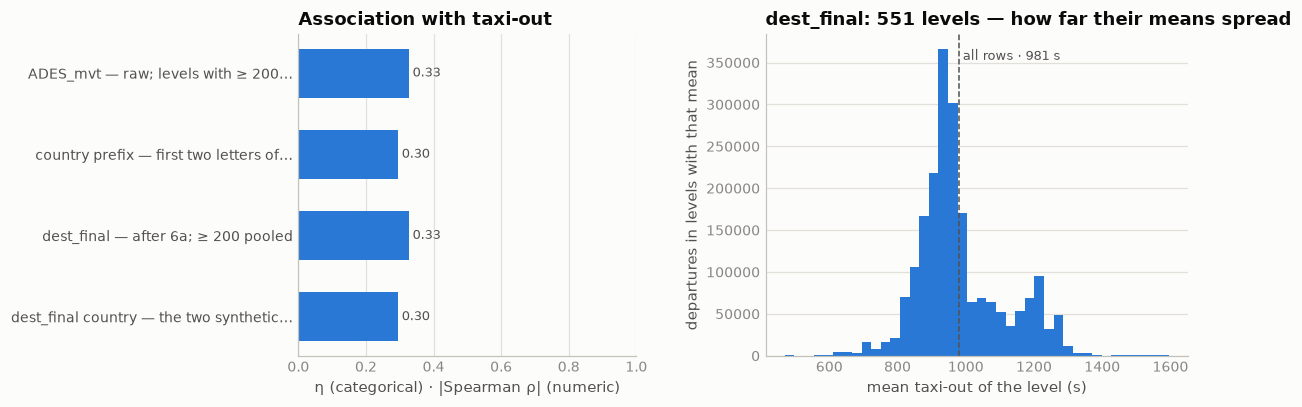

In [51]:
# correlation with the target: the raw destination, its country prefix, and the final form from 6a
FIND_T = f"(SELECT * FROM ({FINALD}) WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("ADES_mvt — raw; levels with ≥ 200 departures, the rest pooled", "cat", "ADES_mvt", 200),
              ("country prefix — first two letters of ADES_mvt", "cat", "substr(ADES_mvt, 1, 2)"),
              ("dest_final — after 6a; ≥ 200 pooled", "cat", "dest_final", 200, FIND_T),
              ("dest_final country — the two synthetic levels kept apart", "cat",
               "CASE WHEN dest_final IN ('OFF_AIRPORT', 'UNKNOWN') THEN dest_final ELSE substr(dest_final, 1, 2) END", 1, FIND_T)])
assoc_chart(a, "dest_final", src=FIND_T, min_support=200, title="dest_final")

**Findings**

| outcome | evidence | reading |
|---|---|---|
| The waterfall settles all 243 sentinel departures with provenance | `data/derived/dest_recovered.parquet`, joined on `MVT_ID_mvt` | never missing, three semantics: real code / `OFF_AIRPORT` / `UNKNOWN` |
| **Why `ZZZZ` skips the history vote** | a vote *could* name an aerodrome for 71 of the believed rows, and its answers are eerily plausible — EHAM's patrol helicopters "return to EHAM" (their logged flights are EHAM→EHAM loops), Rega's rows land on named mountain helipads (`LSXA`, `LSGS`, …) | that would claim a coded field on exactly the days the airport wrote "no coded field", and split one fleet's identical missions across levels. `OFF_AIRPORT` keeps them together — and the target agrees: median taxi-out **254.5 s** for `OFF_AIRPORT` vs **843 s** for `UNKNOWN`. The two synthetic levels mean different things, which was the whole point |
| The `UNKNOWN` remainder | EDDF business aviation (PC12s and Citations under `YY9####` pseudo-identities), two LIRF rows with no aircraft type at all, one prediction row (`TCHKA` at LTFM, type unknown) | §4a's "traffic the system barely knows" again; nothing to recover from |

| layer | the destination comes from | training | ranking |
|---|---|---:|---:|
| 1 | the matched plan (`ADES_flt`, else `ADES_FILED_flt`) — among them 16 "`ZZZZ`" flights really bound for coded airports, the fixed-wing lazy-entry tail | 94 | 9 |
| 2 | `ZZZZ` believed → `OFF_AIRPORT` | 78 | 14 |
| 3 | the identity's history vote | 19 | 5 |
| 4 | rotorcraft / VFR → `OFF_AIRPORT` | 4 | 0 |
| 5 | nothing to go on → `UNKNOWN` | 19 | 1 |

**State after §6** — departures, before → after:

| | training | ranking |
|---|---:|---:|
| ∅ null | 122 → **0** | 13 → **0** |
| `ZZZZ` | 92 → 0 | 16 → 0 |
| real code | 2,084,833 → 2,084,946 | 344,812 → 344,826 |
| `OFF_AIRPORT` | — → 82 | — → 14 |
| `UNKNOWN` | — → 19 | — → 1 |

**Pipeline recipe:** `dest_final` = raw `ADES_mvt` unless ∅/`ZZZZ`, then `ades_rec` from the
parquet (the `CASE` in the cell above, verbatim). Downstream groupings — country prefix, haul
class — must treat the two synthetic levels as their own groups.

## 7 · `PHASE_mvt` — the column that isn't a feature

`DEP` or `ARR`, never anything else, never missing. On the rows we are scored on it is
**constant** — every one of the 344,841 predictions is a departure — so as a predictor it is
worth exactly nothing. That is the whole of its direct story, and it takes one cell to tell.

Its real job is structural: it **partitions the file**. One half is the departures we learn
from and predict; the other is 2,082,750 training and 344,693 ranking arrivals that are never
scored — and never blanked either. The organizers redacted two columns, on departure rows only.
Everything else about every arrival at our ten hubs, on the very days we predict, is handed to
us. So the questions here are not about the column's distribution:

| step | question | what came out |
|---|---|---|
| **integrity & balance** | the two-value census; does each hub launch as many aircraft as it receives? | within ±0.6% — the arrival stream is a same-size mirror |
| **the leak map** | precisely which columns survive on which phase in `ranking.parquet` | two columns, departure rows only: the target's other endpoint is the only secret |
| **the phase flip** | which `_mvt` columns change *meaning* with phase, and the pooling trap that follows | takeoff vs landing, taxi-out vs taxi-in — never pool the phases |
| **signal** | the arrival half is unused by the pipeline; does it know anything about a departure's taxi-out that airport, runway and the off-block anchor don't? | −5.2 s on an honest ladder, every hub gains |
| **7a · the sensor** | one of the two context variables misbehaves at Schiphol — why? | it reads the runway configuration, not congestion; its sign is airport-specific |

In [37]:
display(cat_stats("PHASE_mvt"))

# the leak map: null rate of every column, by file × phase
RANK_COLS = [c[0] for c in con.sql(f"DESCRIBE SELECT * FROM {R}").fetchall()]
pct_null = con.sql(f"""
    SELECT src, PHASE_mvt ph,
           {', '.join(f'round(100.0*count(*) FILTER ({c} IS NULL)/count(*), 2) AS "{c}"'
                      for c in RANK_COLS)}
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().set_index(["src", "ph"]).T

blanked = [c for c in RANK_COLS if pct_null.loc[c, ("ranking", "DEP")] > 50]
print(f"of {len(RANK_COLS)} columns, blanked on ranking DEP rows: {', '.join(blanked)}")
print(f"the other {len(RANK_COLS) - len(blanked)} are as populated at prediction time as in training")
print("\n% NULL by file × phase — every column that is ever missing:")
print(pct_null[pct_null.max(axis=1) > 0].to_string())

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,0,0.0,2
ranking 2026,689534,0,0.0,2


of 30 columns, blanked on ranking DEP rows: BLOCK_TIME_UTC_mvt, TAXITIME_SEC_mvt
the other 28 are as populated at prediction time as in training

% NULL by file × phase — every column that is ever missing:
src                   training       ranking        
ph                         ARR   DEP     ARR     DEP
FLIGHT_ID_mvt             0.41  1.08    0.41    1.53
FLIGHT_mvt                0.01  0.01    0.01    0.02
FLIGHT_RULE_mvt           0.02  0.01    0.02    0.01
ADES_mvt                  0.00  0.01    0.00    0.00
BLOCK_TIME_UTC_mvt        0.00  0.00    0.00  100.00
AIRCRAFT_TYPE_mvt         0.01  0.07    0.01    0.11
TAXITIME_SEC_mvt          0.00  0.00    0.00  100.00
LOBT_flt                  0.74  1.08    0.74    1.53
CALLSIGN_flt              0.74  1.08    0.74    1.53
ADEP_flt                  0.74  1.08    0.74    1.53
ADES_flt                  0.74  1.08    0.74    1.53
ADES_FILED_flt            0.74  1.08    0.74    1.53
MARKET_SEGMENT_flt        0.74  1.08    0.74    1.53

In [38]:
# does each hub launch what it receives?
print("movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):")
print(con.sql(f"""
    SELECT hub, t_dep, t_arr, round(100.0*t_dep/t_arr - 100, 2) t_gap_pct,
           r_dep, r_arr, round(100.0*r_dep/r_arr - 100, 2) r_gap_pct
    FROM (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr
          FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r' src, * FROM {R})
          GROUP BY 1)
    ORDER BY t_dep DESC""").df().to_string(index=False))

# the phase flip, in the target itself
print("\nthe same columns, two different quantities (training, 1–3600 s):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi,
           count(DISTINCT RUNWAY_mvt) n_runways, count(DISTINCT STAND_mvt) n_stands
    FROM {T} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):
 hub  t_dep  t_arr  t_gap_pct  r_dep  r_arr  r_gap_pct
LTFM 272965 273886      -0.34  47581  47764      -0.38
EHAM 247951 247706       0.10  38182  38143       0.10
LFPG 239552 238835       0.30  39872  39733       0.35
EGLL 239546 239511       0.01  39840  39837       0.01
EDDF 230141 230122       0.01  36317  36253       0.18
LEMD 212242 211091       0.55  36954  37093      -0.37
LEBL 179705 179081       0.35  30080  29973       0.36
EDDM 167334 167323       0.01  25966  25935       0.12
LIRF 160704 160504       0.12  26899  26839       0.22
LSZH 134907 134691       0.16  23150  23123       0.12

the same columns, two different quantities (training, 1–3600 s):
 ph       n  mean_taxi  med_taxi  n_runways  n_stands
ARR 2082073      535.0     480.0         54      1849
DEP 2080533      981.0     911.0         53      1897


In [39]:
# One movement stream per hub. Everything below uses ONLY columns the leak map cleared:
# takeoff/landing times (both phases) and arrivals' taxi-in — never a departure's block time.
con.sql(f"""
    CREATE OR REPLACE TABLE mvt_stream AS
    SELECT ds, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, AOBT_3_flt aobt3,
           CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in,
           CASE WHEN PHASE_mvt = 'DEP' THEN TAXITIME_SEC_mvt END taxi_out
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})""")

# airport state over the 60 minutes up to each movement — one query, both files
con.sql("""
    CREATE OR REPLACE TABLE dep_ctx AS
    SELECT *,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER w n_dep_60,
           sum(CASE WHEN ph = 'ARR' THEN 1 ELSE 0 END) OVER w n_arr_60,
           avg(CASE WHEN ph = 'ARR' THEN taxi_in END) OVER w mean_tin_60
    FROM mvt_stream
    WINDOW w AS (PARTITION BY ds, hub ORDER BY t
                 RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("the same context, computed identically on both files (DEP rows):")
print(con.sql("""
    SELECT ds, count(*) n_dep,
           round(100.0*count(*) FILTER (mean_tin_60 IS NOT NULL)/count(*), 2) pct_with_context,
           round(avg(n_dep_60), 1) mean_dep_60, round(avg(n_arr_60), 1) mean_arr_60,
           round(avg(mean_tin_60)) mean_taxi_in_60
    FROM dep_ctx WHERE ph = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nranking is two disjoint month-blocks, so each opens cold — what does the seam cost?")
print(con.sql("""
    SELECT date_trunc('month', t) block, count(*) n_dep,
           count(*) FILTER (t < date_trunc('month', t) + INTERVAL 60 MINUTE) first_hour
    FROM dep_ctx WHERE ds = 'ranking' AND ph = 'DEP'
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

# and the assumption worth testing: is the AOBT_3 anchor simply the answer?
print("\nthe AOBT_3 anchor on its own (training DEP, 1–3600 s):")
print(con.sql(f"""
    SELECT round(100.0*count(*) FILTER (AOBT_3_flt IS NOT NULL)/count(*), 2) pct_have_anchor,
           round(sqrt(avg((TAXITIME_SEC_mvt - epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))^2)
                      FILTER (AOBT_3_flt IS NOT NULL)), 1) rmse_as_prediction,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) - TAXITIME_SEC_mvt, 0.5)
                 FILTER (AOBT_3_flt IS NOT NULL)) med_bias_s,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)
                                            - TAXITIME_SEC_mvt) <= 60)
                 /count(*) FILTER (AOBT_3_flt IS NOT NULL), 1) pct_within_60s
    FROM {T} WHERE PHASE_mvt = 'DEP'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").df().to_string(index=False))

the same context, computed identically on both files (DEP rows):
      ds   n_dep  pct_with_context  mean_dep_60  mean_arr_60  mean_taxi_in_60
training 2085047             99.88         35.4         30.8            546.0
 ranking  344841             99.88         34.7         30.1            546.0

ranking is two disjoint month-blocks, so each opens cold — what does the seam cost?
                    block  n_dep  first_hour
2026-01-01 00:00:00+00:00 152719          16
2026-07-01 00:00:00+00:00 192122          14

the AOBT_3 anchor on its own (training DEP, 1–3600 s):


 pct_have_anchor  rmse_as_prediction  med_bias_s  pct_within_60s
           98.98               361.6        52.0            21.1


In [40]:
# Honest ladder: group means fitted on Jan–Oct 2025, scored on Nov+Dec — the pipeline's own
# holdout. Bin edges come from the fit period only; a cell with < 30 rows falls back to the
# next coarser rung. The first three rungs are what the model already has.
con.sql("""
    CREATE OR REPLACE TABLE lad AS
    SELECT hub, rwy, taxi_out::DOUBLE y, n_dep_60, mean_tin_60,
           epoch(t - aobt3) anchor, (t >= TIMESTAMPTZ '2025-11-01') is_val
    FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
      AND rwy IS NOT NULL AND aobt3 IS NOT NULL AND mean_tin_60 IS NOT NULL""")
con.sql("""
    CREATE OR REPLACE TABLE lad_b AS
    WITH cuts AS (
        SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                    quantile_cont(n_dep_60, [0.2,0.4,0.6,0.8]) qd,
                    quantile_cont(mean_tin_60, [0.2,0.4,0.6,0.8]) qt
        FROM lad WHERE NOT is_val GROUP BY 1)
    SELECT lad.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
                  list_count(list_filter(qd, x -> x <= n_dep_60)) q_dep,
                  list_count(list_filter(qt, x -> x <= mean_tin_60)) q_tin
    FROM lad JOIN cuts USING (hub)""")

MIN_N = 30
RUNGS = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]),
         ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"]),
         ("+ arrival context", ["hub", "rwy", "q_anc", "q_dep", "q_tin"])]
for i, (_, keys) in enumerate(RUNGS):
    con.sql(f"""CREATE OR REPLACE TABLE rung{i} AS
                SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")

n_val = con.sql("SELECT count(*) FROM lad_b WHERE is_val").fetchone()[0]
print(f"fit Jan–Oct 2025 → scored on {n_val:,} Nov+Dec departures "
      f"(cell support ≥ {MIN_N}, else the next coarser rung):")
joins, preds = [], []
for i, (name, keys) in enumerate(RUNGS):
    joins.append(f"LEFT JOIN rung{i} USING ({', '.join(keys)})")
    preds.append(f"CASE WHEN rung{i}.c >= {MIN_N} THEN rung{i}.m END")
    cascade = "coalesce(" + ", ".join(reversed(preds)) + ", g.m)"
    r = con.sql(f"""SELECT sqrt(avg((v.y - {cascade})^2)) FROM lad_b v {' '.join(joins)}
        CROSS JOIN (SELECT avg(y) m FROM lad_b WHERE NOT is_val) g
        WHERE v.is_val""").fetchone()[0]
    print(f"    {name:20s} {r:7.1f} s")

print("\nwhich half of the context does the work? (each on top of runway + anchor)")
for nm, extra in [("departures in prior hour", ["q_dep"]),
                  ("mean taxi-in in prior hour", ["q_tin"]),
                  ("both", ["q_dep", "q_tin"])]:
    keys = ["hub", "rwy", "q_anc"] + extra
    con.sql(f"""CREATE OR REPLACE TABLE rx AS SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")
    r = con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN rx.c >= {MIN_N} THEN rx.m END,
                                        CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                        CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                        rung0.m))^2))
        FROM lad_b v LEFT JOIN rx USING ({', '.join(keys)})
        LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
        LEFT JOIN rung0 USING (hub) WHERE v.is_val""").fetchone()[0]
    print(f"    {nm:28s} {r:7.1f} s")

fit Jan–Oct 2025 → scored on 324,227 Nov+Dec departures (cell support ≥ 30, else the next coarser rung):
    airport                355.2 s
    + runway               341.7 s
    + AOBT_3 anchor        283.6 s
    + arrival context      278.4 s

which half of the context does the work? (each on top of runway + anchor)
    departures in prior hour       279.8 s
    mean taxi-in in prior hour     281.5 s
    both                           278.4 s


per-hub holdout RMSE, before and after the arrival context:
 hub  base  with_ctx  gain
EGLL 280.0     278.8   1.2
EHAM 202.9     200.9   2.0
LEMD 235.0     232.8   2.2
EDDM 304.5     300.8   3.6
EDDF 249.1     244.5   4.6
LEBL 248.3     242.4   5.9
LIRF 375.2     369.0   6.2
LFPG 336.8     330.4   6.4
LSZH 247.2     240.4   6.8
LTFM 323.6     312.6  11.0


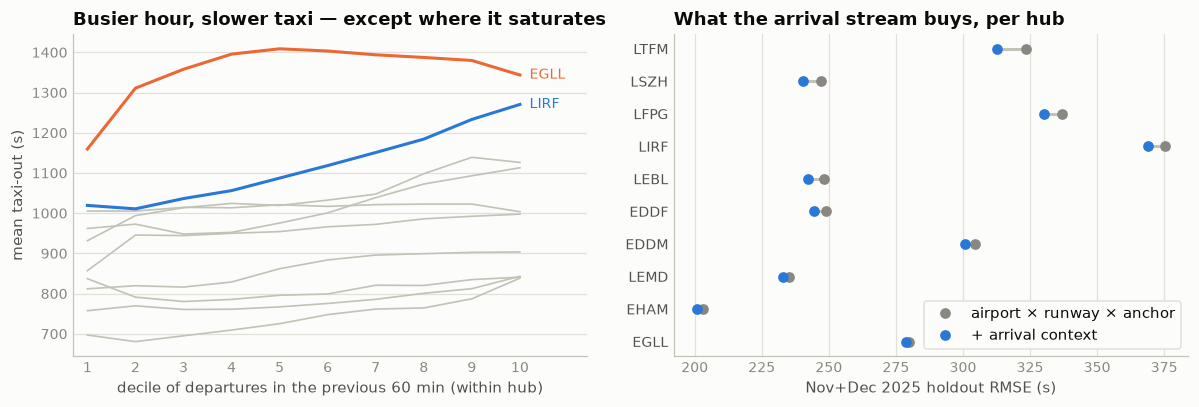

In [41]:
curve = con.sql("""
    WITH d AS (SELECT hub, taxi_out::DOUBLE y, n_dep_60 FROM dep_ctx
               WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600),
         b AS (SELECT *, ntile(10) OVER (PARTITION BY hub ORDER BY n_dep_60) q FROM d)
    SELECT hub, q, avg(y) mean_taxi FROM b GROUP BY 1, 2 ORDER BY 1, 2""").df()
gain = con.sql(f"""
    SELECT hub, sqrt(avg((v.y - coalesce(CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) base,
                sqrt(avg((v.y - coalesce(CASE WHEN rung3.c >= {MIN_N} THEN rung3.m END,
                                         CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) with_ctx
    FROM lad_b v LEFT JOIN rung3 USING (hub, rwy, q_anc, q_dep, q_tin)
    LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
    LEFT JOIN rung0 USING (hub)
    WHERE v.is_val GROUP BY 1 ORDER BY base - with_ctx""").df()
print("per-hub holdout RMSE, before and after the arrival context:")
print(gain.assign(gain=(gain.base - gain.with_ctx)).round(1).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for hub, g in curve.groupby("hub"):
    hi = hub in ("LIRF", "EGLL")
    a1.plot(g.q, g.mean_taxi, color={"LIRF": BLUE, "EGLL": ORANGE}.get(hub, BASELINE),
            lw=2.0 if hi else 1.1, zorder=3 if hi else 1)
    if hi:
        a1.text(10.2, g.mean_taxi.iloc[-1], hub, fontsize=9, va="center",
                color={"LIRF": BLUE, "EGLL": ORANGE}[hub])
a1.set_xticks(range(1, 11))
a1.set_xlim(0.7, 11.4)
a1.set_title("Busier hour, slower taxi — except where it saturates")
a1.set_xlabel("decile of departures in the previous 60 min (within hub)")
a1.set_ylabel("mean taxi-out (s)")
style(a1)

y = np.arange(len(gain))
a2.hlines(y, gain.with_ctx, gain.base, color=BASELINE, lw=2)
a2.plot(gain.base, y, "o", color=MUTED, ms=6, label="airport × runway × anchor")
a2.plot(gain.with_ctx, y, "o", color=BLUE, ms=6, label="+ arrival context")
a2.set_yticks(y, gain.hub, color=INK2)
a2.set_title("What the arrival stream buys, per hub")
a2.set_xlabel("Nov+Dec 2025 holdout RMSE (s)")
a2.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Constant on the scored rows | two values, 4,857,331 rows, **zero nulls** in either file; every prediction is a `DEP` | the only column whose value we know before reading the row — never enters the model matrix |
| **The leak map is two columns wide** | of the 30 columns, exactly `BLOCK_TIME_UTC_mvt` and `TAXITIME_SEC_mvt` are blanked in `ranking.parquet`, and only on `DEP` rows — 100% null there, 0% everywhere else. The other 28 are as populated at prediction time as in training, `RUNWAY_mvt` and `STAND_mvt` at 0.00% null on both phases and the whole `_flt` block at 1.53%. The one other column that moves between the files is `FLIGHT_ID_mvt` (§2's matching failures, 1.08% → 1.53%) | **the target's other endpoint is the only thing hidden.** Taxi-out is takeoff − off-block; we are given the takeoff and asked for the gap. Any feature that reconstructs a departure's own off-block time from the movement side is a leak. Everything else in the file — *both phases* — is fair game |
| Balance | each hub launches within ±0.6% of what it receives (LEMD +0.55%, LTFM −0.34%), in both files | an airport conserves aircraft: the arrival stream is a same-size mirror of the departure stream, not a small side dataset |
| **The phase flip is a pooling trap** | `ADEP`/`ADES` swap roles (§5, §6), and `MVT_TIME`, `BLOCK_TIME`, `SCHED_TIME`, `RUNWAY`, `STAND` and the target all mean something different on each side: over the same column, 981 s mean taxi-out against 535 s taxi-in, across 53 departure runways and 54 arrival ones | every statistic in this notebook filters on phase, and the pipeline trains on `PHASE_mvt = 'DEP'` for exactly that reason |
| **The arrival half is not a spectator** | two crude context variables built from cleared columns alone — departures in the previous 60 min by takeoff time, mean taxi-in of arrivals in the previous 60 min — move the honest ladder (fit Jan–Oct, score Nov+Dec, support-30 cascade): airport **355.2** → + runway **341.7** → + `AOBT_3` anchor **283.6** → **+ arrival context 278.4 s**. Departures-in-the-hour carries more of it (−3.8 s) than mean taxi-in (−2.1 s), and the two are not redundant. Every hub gains: LTFM −11.0 s, LSZH −6.8, LFPG −6.4, LIRF −6.2 at the top, EGLL −1.2 at the bottom | −5.2 s on top of the three strongest things the model already has, from plain group means and no tuning |
| The `AOBT_3` anchor is not the answer handed over | taken raw, `MVT_TIME − AOBT_3` predicts taxi-out at RMSE 361.6 s — *worse than the airport mean* — with a +52 s median bias and only 21% of rows inside a minute; it is missing on 1.53% of the rows we must predict | NM's actual-off-block for the flown trajectory and the airport's own block time are different clocks. It is the ladder's biggest single step (−58 s) precisely because the model can calibrate that offset per airport and runway; it is not a shortcut |
| The context survives the ranking file's shape | two disjoint month-blocks, so the windows at 00:00 on 1 Jan and 1 Jul open cold — 30 departures of 344,841. Otherwise indistinguishable across the files: 99.88% coverage on both, 34.7 vs 35.4 departures/hour, 30.1 vs 30.8 arrivals/hour, mean prior-hour taxi-in 546 s in each | the recipe computes identically at prediction time |

The ladder's airport rung reads 355.2 s where §5 reports 357.3 s on the same holdout: this
ladder keeps only the 324,227 departures that have a runway, an anchor and a context value.

**Use in modeling.** `PHASE_mvt` is a row filter, never a feature — but it is the key to the
file's other half. Build per-hub rolling airport-state features off the *full* movement stream,
both phases, anchored on `MVT_TIME_UTC_mvt`, and join them onto the departures. No derived
parquet here, deliberately: unlike §2's and §4a's recovery layers, this is one window query
whose parameters were still open when this section was written — §8 has since settled them
(a window *centred* on takeoff, 15–30 min, beats this section's trailing hour). Before
generalizing the recipe, though, 7a: one of these two variables turns out not to be measuring
congestion at all.

### 7a · The arrival stream is a runway-configuration sensor

One of §7's two context variables misbehaves. Mean taxi-in over the previous hour correlates
*positively* with taxi-out at eight of the ten hubs (LFPG +0.20, EGLL +0.16, EDDF +0.13) —
slow surface, slow everywhere, as expected. At Schiphol it correlates **−0.28**: the longer
arrivals have been taxiing in, the *shorter* the departures taxi out. Either the variable is
noise at EHAM, or it is not measuring congestion.

It is not measuring congestion. It is reading the **runway configuration** off the arrival
stream — and Schiphol's geometry makes that reading invert.

In [42]:
print("EHAM taxi-in by arrival runway — the runways are not interchangeable:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_in
    FROM {T} WHERE PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nEHAM taxi-out by departure runway — and 36L is 18R's other end:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

# add "share of arrivals landing on the Polderbaan" to the same rolling window
con.sql(f"""
    CREATE OR REPLACE TABLE eham_ctx AS
    SELECT *, avg(taxi_in) OVER w mean_tin_60,
              avg(CASE WHEN ph = 'ARR' THEN (rwy = '18R')::INT END) OVER w share_18R
    FROM (SELECT PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, TAXITIME_SEC_mvt taxi,
                 CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in
          FROM {T} WHERE (PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM')
                      OR (PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'))
    WINDOW w AS (ORDER BY t RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("\nsorting EHAM departures by the prior hour's mean taxi-in:")
print(con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, rwy, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, count(*) n, round(avg(mean_tin_60)) prior_hr_taxi_in,
           round(100*avg(share_18R)) pct_arr_on_18R, mode(rwy) top_dep_rwy,
           round(avg(y)) dep_taxi_out
    FROM b GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe configuration split — one flow, and only one phase pays for the Polderbaan:")
print(con.sql("""
    SELECT CASE WHEN share_18R >= 0.5 THEN '18R landing (south flow)'
                ELSE 'other configuration' END config, count(*) n,
           round(avg(taxi)) mean_taxi_out,
           round(100.0*count(*) FILTER (rwy = '36L')/count(*), 1) pct_dep_36L,
           round(100.0*count(*) FILTER (rwy = '24')/count(*), 1) pct_dep_24,
           round(100.0*count(*) FILTER (rwy = '18L')/count(*), 1) pct_dep_18L
    FROM eham_ctx WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND share_18R IS NOT NULL
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

EHAM taxi-in by arrival runway — the runways are not interchangeable:
rwy     n  mean_taxi_in
18R 92274         776.0
 06 60216         303.0
18C 37554         407.0
36R 28541         289.0
 27 10460         370.0
 22  9724         293.0

EHAM taxi-out by departure runway — and 36L is 18R's other end:
rwy     n  mean_taxi_out
 24 85212          665.0
36L 58570         1082.0
18L 55571          735.0
36C 30899          729.0
 09  7855          836.0
 22  4694          276.0



sorting EHAM departures by the prior hour's mean taxi-in:
 q     n  prior_hr_taxi_in  pct_arr_on_18R top_dep_rwy  dep_taxi_out
 1 24778             258.0             0.0         36L         915.0
 2 24778             296.0             0.0         36L         914.0
 3 24778             331.0             0.0         36L         905.0
 4 24777             385.0             1.0         36L         870.0
 5 24777             496.0            25.0          24         775.0
 6 24777             586.0            53.0          24         661.0
 7 24777             634.0            68.0          24         679.0
 8 24777             677.0            81.0          24         679.0
 9 24777             719.0            89.0          24         688.0
10 24777             816.0            92.0          24         749.0

the configuration split — one flow, and only one phase pays for the Polderbaan:
                  config      n  mean_taxi_out  pct_dep_36L  pct_dep_24  pct_dep_18L
18R landing (sou

 hub      r
EHAM -0.281
LEBL -0.077
LSZH  0.014
LEMD  0.060
LTFM  0.067
LIRF  0.098
EDDM  0.099
EDDF  0.129
EGLL  0.160
LFPG  0.197


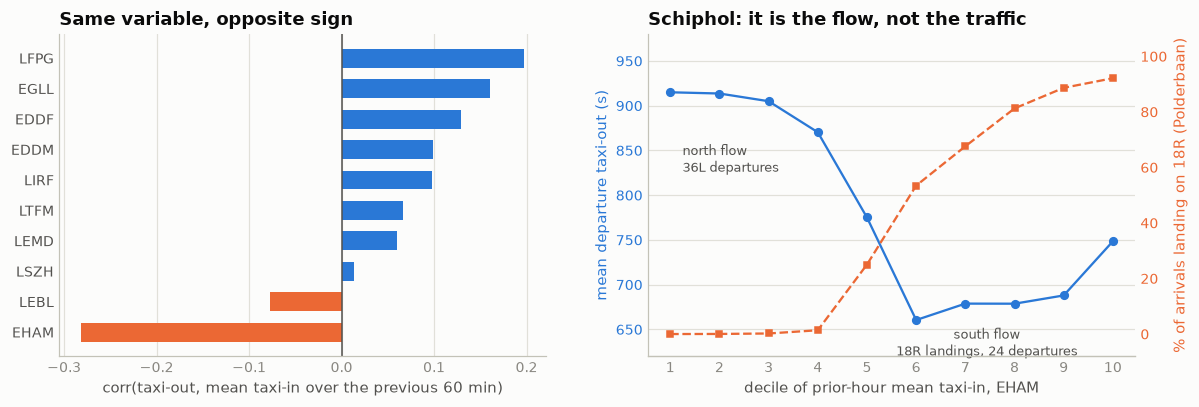

In [43]:
corr = con.sql("""
    SELECT hub, corr(taxi_out, mean_tin_60) r FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY r""").df()
mech = con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, avg(y) taxi_out, 100*avg(share_18R) pct_18R FROM b GROUP BY 1 ORDER BY 1""").df()
print(corr.round(3).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(corr))
a1.barh(y, corr.r, height=0.62, color=[ORANGE if v < 0 else BLUE for v in corr.r])
a1.axvline(0, color=INK2, lw=1)
a1.set_yticks(y, corr.hub, color=INK2)
a1.set_title("Same variable, opposite sign")
a1.set_xlabel("corr(taxi-out, mean taxi-in over the previous 60 min)")
style(a1, x_grid=True, y_grid=False)

# the two series are named by their own coloured axis labels — no legend to sit on the data
a2.plot(mech.q, mech.taxi_out, "o-", color=BLUE, ms=5)
a2.set_ylabel("mean departure taxi-out (s)", color=BLUE)
a2.tick_params(axis="y", colors=BLUE)
a2.set_ylim(620, 980)
a2.set_xticks(range(1, 11))
a2.set_xlabel("decile of prior-hour mean taxi-in, EHAM")
a2.set_title("Schiphol: it is the flow, not the traffic")
style(a2)
a3 = a2.twinx()
a3.plot(mech.q, mech.pct_18R, "s--", color=ORANGE, ms=4.5)
a3.set_ylabel("% of arrivals landing on 18R (Polderbaan)", color=ORANGE)
a3.tick_params(axis="y", colors=ORANGE, length=0)
a3.set_ylim(-8, 108)
a3.grid(False)
a3.spines[["top", "left", "right"]].set_visible(False)
a2.annotate("north flow\n36L departures", (1, 915), textcoords="offset points", xytext=(8, -52),
            fontsize=8.5, color=INK2)
a2.annotate("south flow\n18R landings, 24 departures", (8, 679), textcoords="offset points",
            xytext=(-18, -34), fontsize=8.5, color=INK2, ha="center")
fig.tight_layout(w_pad=3.2)
plt.show()

                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
           PHASE_mvt on departures — constant categorical           1                        0.000
PHASE_mvt over both phases — the pooling trap categorical           2                        0.542


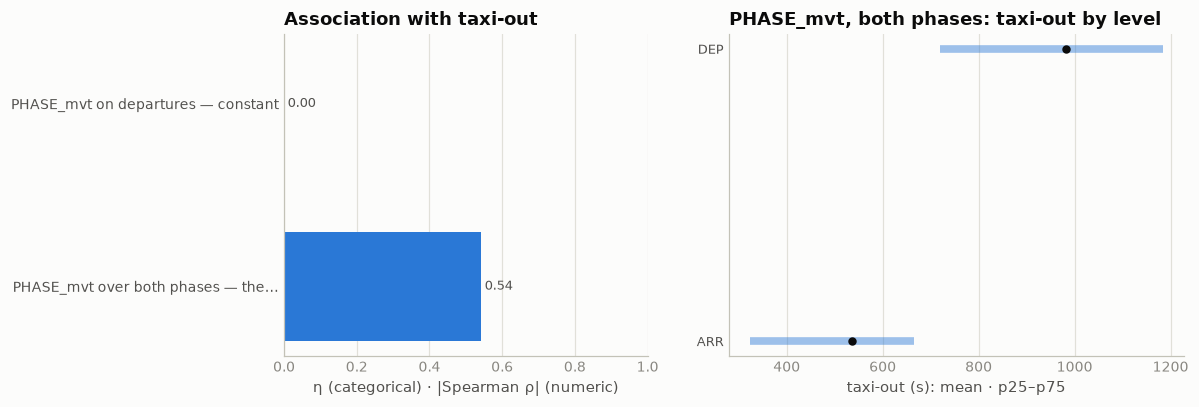

In [50]:
# correlation with the target: on the rows we predict the phase is constant, so there is nothing to
# correlate. Pooled over both phases it looks like a strong feature — that is the pooling trap, not a signal
BOTH_T = f"(SELECT * FROM {T} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("PHASE_mvt on departures — constant", "cat", "PHASE_mvt"),
              ("PHASE_mvt over both phases — the pooling trap", "cat", "PHASE_mvt", 1, BOTH_T)])
assoc_chart(a, "PHASE_mvt", src=BOTH_T, title="PHASE_mvt, both phases")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **EHAM's arrival runways are not interchangeable** | landing on **18R, the Polderbaan**, costs a mean **776 s** of taxi-in; landing on 06 or 36R costs 303 s and 289 s. The Polderbaan sits some 7 km from the terminal — built for noise abatement, not convenience | "mean taxi-in over the last hour" at EHAM is, to first order, a **thermometer for whether 18R is the landing runway** |
| **18R landing implies a configuration in which departures taxi less** | sorting departures by the prior hour's mean taxi-in: in the bottom four deciles 0–1% of arrivals used 18R, the modal departure runway is **36L**, and taxi-out averages 870–915 s. From the sixth decile up, 53–92% of arrivals used 18R, the modal departure runway is **24, the Kaagbaan**, and taxi-out averages 661–749 s. Split at 50% 18R: departures on 36L collapse from 44.0% to 0.2%, runways 24 and 18L take 94.2% of the traffic, and mean taxi-out falls **869 → 685 s** | the asymmetry is geometric, not statistical. **36L is 18R's other end** — and EHAM's longest departure taxi (1,082 s, against 665 s for 24). The Polderbaan is always the long leg; the flow direction only decides *which phase pays for it*. South flow lands on 18R and departs from the near runways; north flow departs from 36L and lands on the near ones. One rolling average of arrival taxi-in tells us which of the two we are in |
| **The sign is airport-specific and must be learned as such** | corr(taxi-out, prior-hour mean taxi-in) runs from +0.20 (LFPG), +0.16 (EGLL) and +0.13 (EDDF) down through +0.01 (LSZH) to −0.08 (LEBL) and −0.28 (EHAM) | a single global "the surface is slow" feature would cancel these against each other; interacted with the hub, the same number carries congestion at eight airports and flow direction at Schiphol. It also explains §7's per-hub table, where EHAM gains the second least — a variable pulling in two directions at once is doing half its job |

**Use in modeling.** Keep the rolling arrival statistics, but as per-airport quantities the
model may interact with `ADEP_mvt` — never globally standardized, which would destroy exactly
the structure above; LightGBM gets the interaction for free from a categorical airport split.
Better still, give it the configuration directly: **the mix of arrival runways in the previous
hour is observable at prediction time** (§7's leak map: `RUNWAY_mvt` is 0.00% null on both
phases of `ranking.parquet`) and names the flow explicitly, where mean taxi-in only proxies
it. `RUNWAY_mvt`'s own section takes that up — the natural home, since the departure runway
is likewise known for every row we predict.

## 8 · `MVT_TIME_UTC_mvt` — the target's known endpoint

The best available movement time: **takeoff** on departure rows, **landing** on arrival rows.
A UTC timestamp at second resolution, never null in either file, on either phase.

It is not an ordinary feature. On every training departure, takeoff − off-block equals the
label to the second. The organizers hand us the *end* of the taxi and hide the start — so
every off-block clock in the file turns into an estimate of the target the moment it is
subtracted from this column. The pipeline already does that five times over, and §7's ladder
showed the `AOBT_3` difference to be the largest single step it has. Everything time-shaped in
the model — hour, weekday, month, the rolling airport state — is anchored here too.

| step | question | what came out |
|---|---|---|
| **integrity** | nulls, span, what carves the year into monthly files — and the clock's resolution: 5% of stamps sit exactly on a minute boundary, three times what random seconds would give | never null; the file's own clock; five hubs run on a jittered minute clock, harmless |
| **the calendar** | hour of day and weekday, and the clock they are read on: nine hubs shift an hour between January and July, Istanbul does not, and the ranking file is exactly those two months | the hour is worth 4–8 s, the local clock beats UTC, weekday nothing; 2026 is 2025's twin hour for hour |
| **the year** | where the squared error lives across months and days, with the corrupt labels of `VALIDATION/archive/FINDINGS_20260907.md` shown and then set aside | the mean is flat, the error is not: the ranking months are the heaviest per row, and RMSE is a bad-day metric |
| **the window** | §7 left the rolling-window recipe to this section: its length, and which way it looks — a takeoff-anchored window sees the aircraft that queued alongside ours, before *and* after, and the leak map allows both | a window *centred* on takeoff, 30 min, beats §7's trailing hour; the queue at pushback overlaps the anchor |

In [44]:
# census by file × phase: never null, second resolution, one year against two month-blocks
print("MVT_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (MVT_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(MVT_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') first_stamp,
           strftime(max(MVT_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') last_stamp,
           count(DISTINCT MVT_TIME_UTC_mvt) n_unique,
           round(100.0*count(*) FILTER (extract(second FROM MVT_TIME_UTC_mvt) = 0)/count(*), 2) pct_on_minute
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

# the identity that makes this column half the target
print("\ntakeoff − off-block (DEP) and in-block − landing (ARR) against the label, training:")
print(con.sql(f"""
    SELECT ph, count(*) n, count(*) FILTER (gap = TAXITIME_SEC_mvt) exact,
           count(*) FILTER (gap != TAXITIME_SEC_mvt) mismatch,
           count(*) FILTER (gap IS NULL OR TAXITIME_SEC_mvt IS NULL) missing,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) negative_label
    FROM (SELECT PHASE_mvt ph, TAXITIME_SEC_mvt,
                 CASE WHEN PHASE_mvt = 'DEP' THEN date_diff('second', BLOCK_TIME_UTC_mvt, MVT_TIME_UTC_mvt)
                      ELSE date_diff('second', MVT_TIME_UTC_mvt, BLOCK_TIME_UTC_mvt) END gap
          FROM {T})
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

# what carves the training year into monthly files? this clock — to within a few seconds
FN = f"(SELECT *, regexp_extract(filename, 'training_(2025-[0-9][0-9])', 1) fm " \
     f"FROM read_parquet('{ROOT}/data/training_2025-*.parquet', filename=true))"
print("\nrows whose clock disagrees with the month of the file they sit in:")
print(con.sql(f"""
    SELECT count(*) FILTER (strftime(MVT_TIME_UTC_mvt, '%Y-%m') != fm) by_mvt_time,
           count(*) FILTER (strftime(BLOCK_TIME_UTC_mvt, '%Y-%m') != fm) by_block_time,
           count(*) FILTER (strftime(SCHED_TIME_UTC_mvt, '%Y-%m') != fm) by_sched_time
    FROM {FN}""").df().to_string(index=False))
print(con.sql(f"""
    SELECT fm file_month, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           strftime(MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M:%S') mvt_time
    FROM {FN} WHERE strftime(MVT_TIME_UTC_mvt, '%Y-%m') != fm ORDER BY 4""").df().to_string(index=False))

MVT_TIME_UTC_mvt by file × phase:


     src  ph       n  n_null         first_stamp          last_stamp  n_unique  pct_on_minute
training ARR 2082750       0 2025-01-01 00:01:04 2025-12-31 23:17:54   1937080           5.11
training DEP 2085047       0 2025-01-01 00:05:56 2025-12-31 23:57:36   1933257           5.13
 ranking ARR  344693       0 2026-01-01 00:03:00 2026-07-31 23:46:36    320945           5.21
 ranking DEP  344841       0 2026-01-01 00:01:55 2026-07-31 23:56:19    320158           5.15

takeoff − off-block (DEP) and in-block − landing (ARR) against the label, training:


 ph       n   exact  mismatch  missing  negative_label
DEP 2085047 2085047         0        0             369
ARR 2082750 2082749         0        1             220

rows whose clock disagrees with the month of the file they sit in:


 by_mvt_time  by_block_time  by_sched_time
           6             49            251
file_month  ph  hub            mvt_time
   2025-03 DEP LTFM 2025-02-28 23:59:57
   2025-07 ARR LTFM 2025-06-30 23:59:56
   2025-08 ARR LIRF 2025-07-31 23:59:58
   2025-09 DEP LEMD 2025-08-31 23:59:57
   2025-10 ARR LTFM 2025-09-30 23:59:58
   2025-12 ARR LTFM 2025-11-30 23:59:57


share of stamps within ±6 s of a whole minute (chance: 21.7%):


 hub  DEP takeoff  DEP off-block  ARR landing  ARR in-block  2026 DEP takeoff  2026 ARR in-block
EDDM        100.0          100.0        100.0         100.0             100.0              100.0
LIRF        100.0          100.0        100.0         100.0             100.0              100.0
LFPG        100.0          100.0         99.9         100.0             100.0              100.0
EGLL        100.0          100.0        100.0         100.0             100.0              100.0
LTFM        100.0          100.0        100.0         100.0             100.0              100.0
EDDF         22.8           21.7         21.7          22.3              22.9               22.2
EHAM         22.4           22.3         22.6          23.9              22.1               23.7
LSZH         22.3           24.9         21.8          22.1              23.3               21.5
LEMD         21.7          100.0         21.6         100.0              21.9              100.0
LEBL         21.5          100

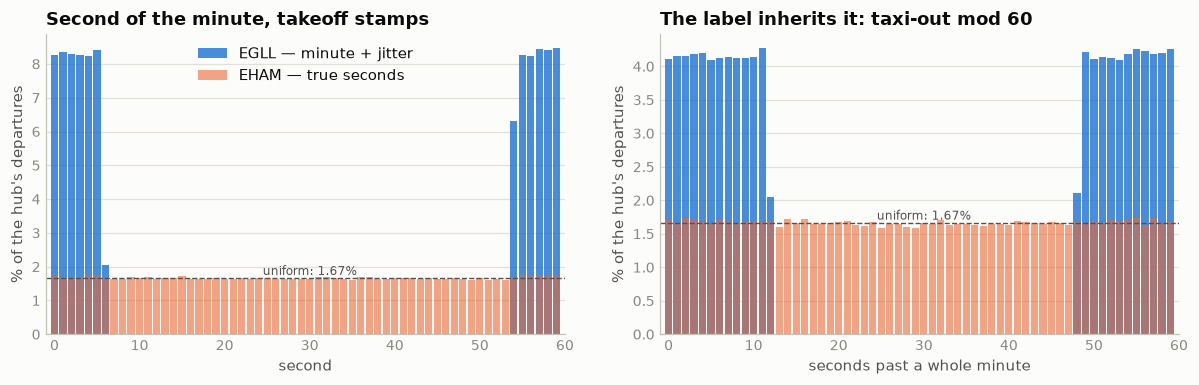

a label built from two jittered stamps is a whole minute ± 12 s, uniform: sd 6.9 s of pure noise

and no bias rides on it — mean taxi-out by whether the takeoff stamp is on the minute (jittered hubs):
 hub      n  on_minute  off_minute
EDDM 167275      810.0       811.0
EGLL 238818     1356.0      1354.0
LFPG 239091     1010.0      1013.0
LIRF 158737     1117.0      1117.0
LTFM 272169     1041.0      1043.0


In [45]:
# seconds-of-minute. A stamp with genuine second resolution lands within ±6 s of a whole
# minute 13 times in 60 (21.7%). Half the hubs do it 94% of the time.
BAND = "NOT BETWEEN 7 AND 53"
print("share of stamps within ±6 s of a whole minute (chance: 21.7%):")
print(con.sql(f"""
    SELECT hub,
           round(100.0*count(*) FILTER (src = 't' AND ph = 'DEP' AND m)/count(*) FILTER (src = 't' AND ph = 'DEP'), 1) "DEP takeoff",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'DEP' AND b)/count(*) FILTER (src = 't' AND ph = 'DEP'), 1) "DEP off-block",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'ARR' AND m)/count(*) FILTER (src = 't' AND ph = 'ARR'), 1) "ARR landing",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'ARR' AND b)/count(*) FILTER (src = 't' AND ph = 'ARR'), 1) "ARR in-block",
           round(100.0*count(*) FILTER (src = 'r' AND ph = 'DEP' AND m)/count(*) FILTER (src = 'r' AND ph = 'DEP'), 1) "2026 DEP takeoff",
           round(100.0*count(*) FILTER (src = 'r' AND ph = 'ARR' AND b)/count(*) FILTER (src = 'r' AND ph = 'ARR'), 1) "2026 ARR in-block"
    FROM (SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
                 extract(second FROM MVT_TIME_UTC_mvt) {BAND} m,
                 extract(second FROM BLOCK_TIME_UTC_mvt) {BAND} b
          FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r' src, * FROM {R}))
    GROUP BY 1 ORDER BY 2 DESC, 3 DESC""").df().to_string(index=False))

# one jittered hub against one true-seconds hub: the takeoff stamp, and what the label inherits
sec = con.sql(f"""
    SELECT ADEP_mvt hub, extract(second FROM MVT_TIME_UTC_mvt)::INT s,
           100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EGLL', 'EHAM') GROUP BY 1, 2""").df()
rem = con.sql(f"""
    SELECT ADEP_mvt hub, TAXITIME_SEC_mvt % 60 r, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EGLL', 'EHAM') GROUP BY 1, 2""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, d, col, ttl, xl in [(a1, sec, "s", "Second of the minute, takeoff stamps", "second"),
                            (a2, rem, "r", "The label inherits it: taxi-out mod 60", "seconds past a whole minute")]:
    for hub, c, lbl in [("EGLL", BLUE, "EGLL — minute + jitter"), ("EHAM", ORANGE, "EHAM — true seconds")]:
        g = d[d.hub == hub].set_index(col).pct.reindex(range(60), fill_value=0)
        ax.bar(g.index, g.values, width=0.85, color=c, alpha=0.85 if hub == "EGLL" else 0.6, label=lbl)
    ax.axhline(100/60, color=INK2, lw=0.9, ls="--")
    ax.text(30, 100/60, "uniform: 1.67%", fontsize=8, color=INK2, ha="center", va="bottom")
    ax.set_title(ttl)
    ax.set_xlabel(xl)
    ax.set_ylabel("% of the hub's departures")
    ax.set_xlim(-1, 60)
    style(ax)
a1.legend(loc="upper center")
fig.tight_layout(w_pad=2.5)
plt.show()

print(f"a label built from two jittered stamps is a whole minute ± 12 s, uniform: sd {24/np.sqrt(12):.1f} s of pure noise")
print("\nand no bias rides on it — mean taxi-out by whether the takeoff stamp is on the minute (jittered hubs):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(avg(TAXITIME_SEC_mvt) FILTER (extract(second FROM MVT_TIME_UTC_mvt) = 0)) on_minute,
           round(avg(TAXITIME_SEC_mvt) FILTER (extract(second FROM MVT_TIME_UTC_mvt) != 0)) off_minute
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
      AND ADEP_mvt IN ('EDDM', 'EGLL', 'LFPG', 'LIRF', 'LTFM')
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

hours ahead of UTC in the two ranking months:
 jan  jul                                    hubs
 3.0  3.0                                    LTFM
 1.0  2.0 EDDF EDDM EHAM LEBL LEMD LFPG LIRF LSZH
 0.0  1.0                                    EGLL

holdout RMSE (s) from group means:


                        fit Jan–Oct → Nov+Dec  fit Feb–Jun+Aug–Dec → Jan+Jul
airport                                 357.3                          376.2
+ UTC hour                              353.2                          368.6
+ local hour                            351.5                          368.2
+ local hour × weekday                  351.8                          367.8


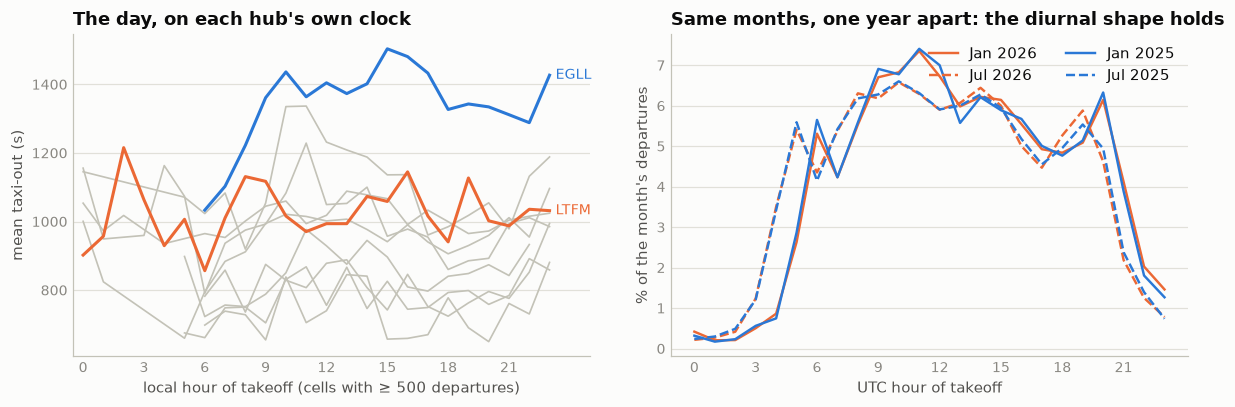

In [46]:
# the calendar. Nine hubs move their clocks between January and July; Istanbul does not.
TZ = """CASE hub WHEN 'LTFM' THEN 'Europe/Istanbul' WHEN 'EGLL' THEN 'Europe/London'
             WHEN 'LEMD' THEN 'Europe/Madrid'    WHEN 'LEBL' THEN 'Europe/Madrid'
             WHEN 'EDDF' THEN 'Europe/Berlin'    WHEN 'EDDM' THEN 'Europe/Berlin'
             WHEN 'EHAM' THEN 'Europe/Amsterdam' WHEN 'LFPG' THEN 'Europe/Paris'
             WHEN 'LIRF' THEN 'Europe/Rome'      WHEN 'LSZH' THEN 'Europe/Zurich' END"""
con.sql(f"""
    CREATE OR REPLACE TABLE dep_clock AS
    SELECT ds, hub, t, taxi, hour(t) h_utc, hour(tl) h_loc, dayofweek(tl) dow_loc, month(t) mon
    FROM (SELECT *, timezone({TZ}, t) tl
          FROM (SELECT 'training' ds, ADEP_mvt hub, MVT_TIME_UTC_mvt t, TAXITIME_SEC_mvt taxi
                FROM {T} WHERE PHASE_mvt = 'DEP'
                UNION ALL
                SELECT 'ranking', ADEP_mvt, MVT_TIME_UTC_mvt, NULL FROM {R} WHERE PHASE_mvt = 'DEP'))""")
print("hours ahead of UTC in the two ranking months:")
print(con.sql(f"""
    SELECT epoch(timezone({TZ}, TIMESTAMPTZ '2026-01-15 12:00:00+00') - TIMESTAMP '2026-01-15 12:00:00')/3600 jan,
           epoch(timezone({TZ}, TIMESTAMPTZ '2026-07-15 12:00:00+00') - TIMESTAMP '2026-07-15 12:00:00')/3600 jul,
           string_agg(hub, ' ' ORDER BY hub) hubs
    FROM (SELECT DISTINCT hub FROM dep_clock) GROUP BY 1, 2 ORDER BY 1 DESC""").df().to_string(index=False))

# how much does the hour buy, and on which clock? §7's recipe — group means, support ≥ 30 or the
# coarser rung — scored on the pipeline's Nov+Dec holdout and on a Jan+Jul 2025 holdout shaped
# like the ranking file
def hour_ladder(fit, val):
    out = {}
    for name, keys in [("airport", "hub"), ("+ UTC hour", "hub, h_utc"), ("+ local hour", "hub, h_loc"),
                       ("+ local hour × weekday", "hub, h_loc, dow_loc")]:
        out[name] = con.sql(f"""
            WITH f AS (SELECT {keys}, avg(taxi) m, count(*) c FROM dep_clock
                       WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {fit} GROUP BY ALL),
                 h AS (SELECT hub, avg(taxi) m FROM dep_clock
                       WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {fit} GROUP BY 1)
            SELECT sqrt(avg((v.taxi - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
            FROM (SELECT * FROM dep_clock WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {val}) v
            LEFT JOIN f USING ({keys}) JOIN h USING (hub)""").fetchone()[0]
    return pd.Series(out)

print("\nholdout RMSE (s) from group means:")
print(pd.DataFrame({"fit Jan–Oct → Nov+Dec": hour_ladder("mon <= 10", "mon >= 11"),
                    "fit Feb–Jun+Aug–Dec → Jan+Jul": hour_ladder("mon NOT IN (1, 7)", "mon IN (1, 7)")})
      .round(1).to_string())

prof = con.sql("""
    SELECT hub, h_loc, avg(taxi) m, count(*) n FROM dep_clock
    WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 GROUP BY 1, 2 HAVING count(*) >= 500 ORDER BY 1, 2""").df()
shape = con.sql("""
    SELECT h_utc, ds, mon, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY ds, mon) pct
    FROM dep_clock WHERE mon IN (1, 7) GROUP BY 1, 2, 3 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
HI = {"EGLL": BLUE, "LTFM": ORANGE}
for hub, g in prof.groupby("hub"):
    c = HI.get(hub, BASELINE)
    a1.plot(g.h_loc, g.m, color=c, lw=2.0 if hub in HI else 1.1, zorder=3 if hub in HI else 1)
    if hub in HI:
        a1.text(g.h_loc.iloc[-1] + 0.3, g.m.iloc[-1], hub, fontsize=9, va="center", color=c)
a1.set_xticks(range(0, 24, 3))
a1.set_xlim(-0.5, 25)
a1.set_title("The day, on each hub's own clock")
a1.set_xlabel("local hour of takeoff (cells with ≥ 500 departures)")
a1.set_ylabel("mean taxi-out (s)")
style(a1)

for (ds, mon), g in shape.groupby(["ds", "mon"]):
    a2.plot(g.h_utc, g.pct, color=BLUE if ds == "training" else ORANGE, ls="-" if mon == 1 else "--",
            lw=1.6, label=f"{'Jan' if mon == 1 else 'Jul'} {2025 if ds == 'training' else 2026}")
a2.set_xticks(range(0, 24, 3))
a2.set_title("Same months, one year apart: the diurnal shape holds")
a2.set_xlabel("UTC hour of takeoff")
a2.set_ylabel("% of the month's departures")
a2.legend(loc="upper right", ncols=2)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

month by month — share of the year's rows and of its squared error about the hub mean:


 m      n  pct_rows  mean_clean  sd_clean  sd_raw  pct_sse_clean  pct_sse_raw
 1 153706       7.4       985.0     416.0   605.0            9.2          9.5
 2 143732       6.9       981.0     416.0   628.0            8.5          9.5
 3 164449       7.9       967.0     371.0   462.0            7.2          5.5
 4 175288       8.4       967.0     358.0   436.0            7.2          5.2
 5 185202       8.9       981.0     373.0   469.0            8.1          6.3
 6 183142       8.8       962.0     377.0   555.0            7.9          8.9
 7 190713       9.1      1006.0     413.0   745.0           10.2         17.6
 8 191182       9.2       984.0     384.0   534.0            8.7          8.6
 9 183950       8.8       980.0     382.0   560.0            8.1          9.1
10 185674       8.9       985.0     383.0   437.0            8.2          5.1
11 162332       7.8       990.0     393.0   532.0            8.2          7.5
12 165677       7.9       987.0     392.0   515.0            8.5

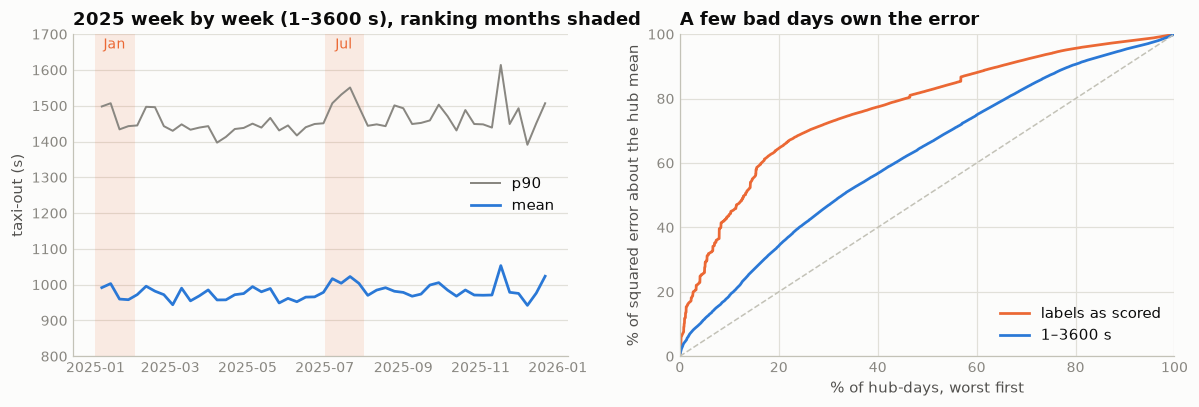

In [47]:
# the year. Two views of every month: the label as scored (raw), and the label with the corrupt
# rows of VALIDATION/archive/FINDINGS_20260907.md set aside (1–3600 s), so the calendar's own weather shows through.
print("month by month — share of the year's rows and of its squared error about the hub mean:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, month(MVT_TIME_UTC_mvt) m, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP'),
         a AS (SELECT hub, avg(y) am, avg(y) FILTER (y BETWEEN 1 AND 3600) ac FROM d GROUP BY 1)
    SELECT m, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct_rows,
           round(avg(y) FILTER (y BETWEEN 1 AND 3600)) mean_clean,
           round(stddev(y) FILTER (y BETWEEN 1 AND 3600)) sd_clean, round(stddev(y)) sd_raw,
           round(100.0*sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600)
                 / sum(sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600)) OVER (), 1) pct_sse_clean,
           round(100.0*sum((y - am)^2)/sum(sum((y - am)^2)) OVER (), 1) pct_sse_raw
    FROM d JOIN a USING (hub) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

# how much of the error lives in a few bad days?
con.sql(f"""
    CREATE OR REPLACE TABLE hub_days AS
    WITH d AS (SELECT ADEP_mvt hub, MVT_TIME_UTC_mvt::DATE dy, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP'),
         a AS (SELECT hub, avg(y) am, avg(y) FILTER (y BETWEEN 1 AND 3600) ac FROM d GROUP BY 1)
    SELECT hub, dy, count(*) n, avg(y) mean_raw, sum((y - am)^2) sse_raw,
           count(*) FILTER (y BETWEEN 1 AND 3600) n_clean,
           avg(y) FILTER (y BETWEEN 1 AND 3600) mean_clean,
           sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600) sse_clean
    FROM d JOIN a USING (hub) GROUP BY 1, 2""")
lor = {}
for lbl in ("raw", "clean"):
    lor[lbl] = con.sql(f"""
        SELECT 100.0*row_number() OVER (ORDER BY mean_{lbl} DESC)/count(*) OVER () pct_days,
               100.0*sum(sse_{lbl}) OVER (ORDER BY mean_{lbl} DESC)/sum(sse_{lbl}) OVER () pct_sse
        FROM hub_days ORDER BY 1""").df()
    at = lambda p: lor[lbl].loc[lor[lbl].pct_days <= p, "pct_sse"].max()
    print(f"\n{lbl:5s} labels: worst 1% of hub-days carry {at(1):.1f}% of the squared error, "
          f"worst 5% carry {at(5):.1f}%, worst 10% carry {at(10):.1f}%")

print("\nthe worst days on clean labels (≥ 200 departures) — operations, not data errors:")
print(con.sql("""
    SELECT hub, dy, dayname(dy) weekday, n_clean n, round(mean_clean) mean_taxi_out
    FROM hub_days WHERE n_clean >= 200 ORDER BY mean_clean DESC LIMIT 8""").df().to_string(index=False))

wk = con.sql(f"""
    SELECT date_trunc('week', MVT_TIME_UTC_mvt)::DATE wk, count(*) n,
           avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600) mean_clean,
           quantile_cont(TAXITIME_SEC_mvt, 0.9) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600) p90_clean
    FROM {T} WHERE PHASE_mvt = 'DEP'
      AND MVT_TIME_UTC_mvt BETWEEN TIMESTAMPTZ '2025-01-06' AND TIMESTAMPTZ '2025-12-29'
    GROUP BY 1 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for lo, hi in [("2025-01-01", "2025-02-01"), ("2025-07-01", "2025-08-01")]:
    a1.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=ORANGE, alpha=0.12, lw=0)
a1.plot(pd.to_datetime(wk.wk), wk.p90_clean, color=MUTED, lw=1.3, label="p90")
a1.plot(pd.to_datetime(wk.wk), wk.mean_clean, color=BLUE, lw=1.8, label="mean")
a1.text(pd.Timestamp("2025-01-16"), 1660, "Jan", ha="center", fontsize=9, color=ORANGE)
a1.text(pd.Timestamp("2025-07-16"), 1660, "Jul", ha="center", fontsize=9, color=ORANGE)
a1.set_title("2025 week by week (1–3600 s), ranking months shaded")
a1.set_ylabel("taxi-out (s)")
a1.set_ylim(800, 1700)
a1.legend(loc="center right")
style(a1)
for lbl, c, nm in [("raw", ORANGE, "labels as scored"), ("clean", BLUE, "1–3600 s")]:
    a2.plot(lor[lbl].pct_days, lor[lbl].pct_sse, color=c, lw=1.8, label=nm)
a2.plot([0, 100], [0, 100], color=BASELINE, lw=1, ls="--")
a2.set_xlim(0, 100)
a2.set_ylim(0, 100)
a2.set_title("A few bad days own the error")
a2.set_xlabel("% of hub-days, worst first")
a2.set_ylabel("% of squared error about the hub mean")
a2.legend(loc="lower right")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()

departure count in the window, on top of airport × runway × anchor — scored on 324,631 Nov+Dec departures:
                  window  corr  base_rmse  with_rmse  gain_s
             trailing_15 0.087    283.642    279.600   4.042
             centered_15 0.098    283.642    278.384   5.258
              leading_15 0.091    283.642    279.314   4.327
             trailing_30 0.097    283.642    279.687   3.954
             centered_30 0.098    283.642    278.127   5.514
              leading_30 0.073    283.642    279.981   3.661
             trailing_60 0.116    283.642    279.786   3.856
             centered_60 0.095    283.642    278.528   5.114
              leading_60 0.059    283.642    280.975   2.667
            trailing_120 0.131    283.642    280.466   3.175
            centered_120 0.103    283.642    279.301   4.341
             leading_120 0.070    283.642    281.028   2.614
       queue_at_pushback 0.296    283.642    279.941   3.701
takeoffs_before_pushback 0.110    283.6

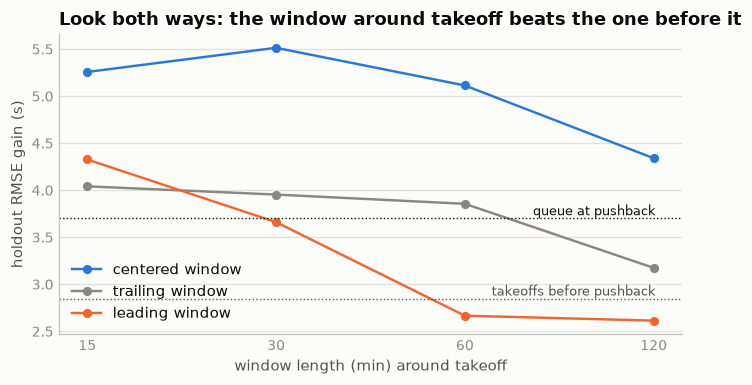

In [48]:
# the window. §7 counted departures in the 60 minutes *before* takeoff and left the shape open.
# Every takeoff time in the file is known at prediction time — before and after ours — so the
# window may look either way. And the off-block anchor offers a second place to stand: at pushback.
# Same honest ladder as §7: airport × runway × AOBT_3-anchor bins, fitted Jan–Oct, scored Nov+Dec.
con.sql(f"""
    CREATE OR REPLACE TABLE dep_stream AS
    SELECT MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, AOBT_3_flt aobt3,
           CASE WHEN PHASE_mvt = 'DEP' THEN TAXITIME_SEC_mvt END taxi_out
    FROM {T}""")
FRAMES = {}
for W in (15, 30, 60, 120):
    FRAMES[f"trailing_{W}"] = f"RANGE BETWEEN INTERVAL {W} MINUTE PRECEDING AND CURRENT ROW"
    FRAMES[f"centered_{W}"] = (f"RANGE BETWEEN INTERVAL {W // 2} MINUTE PRECEDING "
                               f"AND INTERVAL {W // 2} MINUTE FOLLOWING")
    FRAMES[f"leading_{W}"] = f"RANGE BETWEEN CURRENT ROW AND INTERVAL {W} MINUTE FOLLOWING"
con.sql(f"""
    CREATE OR REPLACE TABLE win AS
    SELECT *, {', '.join(f"sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER (PARTITION BY hub ORDER BY t {fr}) {k}"
                         for k, fr in FRAMES.items())}
    FROM dep_stream""")

# two windows anchored at pushback (AOBT_3) instead of takeoff:
#   queue_at_pushback  — departures that had pushed back but not yet taken off when we pushed back
#   takeoffs_before_pushback — takeoffs in the 60 min up to our pushback (§7's window, moved back)
con.sql("""
    CREATE OR REPLACE TABLE at_push AS
    WITH ev AS (SELECT hub, id, aobt3 ts, 1 d FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL
                UNION ALL
                SELECT hub, id, t, -1 FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL),
         q AS (SELECT id, d, sum(d) OVER (PARTITION BY hub ORDER BY ts, d
                                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) - 1 n
               FROM ev),
         tk AS (SELECT hub, t ts, row_number() OVER (PARTITION BY hub ORDER BY t) cum
                FROM dep_stream WHERE ph = 'DEP'),
         p AS (SELECT id, hub, aobt3 FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL),
         hi AS (SELECT p.id, a.cum FROM p ASOF LEFT JOIN tk a ON p.hub = a.hub AND p.aobt3 >= a.ts),
         lo AS (SELECT p.id, b.cum FROM p ASOF LEFT JOIN tk b
                ON p.hub = b.hub AND p.aobt3 - INTERVAL 60 MINUTE >= b.ts)
    SELECT q.id, q.n queue_at_pushback, coalesce(hi.cum, 0) - coalesce(lo.cum, 0) takeoffs_before_pushback
    FROM q JOIN hi USING (id) JOIN lo USING (id) WHERE q.d = 1""")

con.sql("""
    CREATE OR REPLACE TABLE wlad AS
    SELECT w.*, p.queue_at_pushback, p.takeoffs_before_pushback,
           epoch(w.t - w.aobt3) anchor, (w.t >= TIMESTAMPTZ '2025-11-01') is_val
    FROM win w JOIN at_push p USING (id)
    WHERE w.ph = 'DEP' AND w.taxi_out BETWEEN 1 AND 3600 AND w.rwy IS NOT NULL""")

MIN_N = 30
def ladder_gain(col):
    """Holdout RMSE without / with the context column on top of airport × runway × anchor."""
    con.sql(f"""
        CREATE OR REPLACE TABLE wb AS
        WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                             quantile_cont({col}, [0.2,0.4,0.6,0.8]) qx
                      FROM wlad WHERE NOT is_val GROUP BY 1)
        SELECT hub, rwy, taxi_out::DOUBLE y, is_val,
               list_count(list_filter(qa, x -> x <= anchor)) q_anc,
               list_count(list_filter(qx, x -> x <= {col})) q_x
        FROM wlad JOIN cuts USING (hub)""")
    for i, keys in enumerate(["hub", "hub, rwy", "hub, rwy, q_anc", "hub, rwy, q_anc, q_x"]):
        con.sql(f"CREATE OR REPLACE TABLE wr{i} AS SELECT {keys}, avg(y) m, count(*) c "
                f"FROM wb WHERE NOT is_val GROUP BY ALL")
    return con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN wr2.c >= {MIN_N} THEN wr2.m END,
                                        CASE WHEN wr1.c >= {MIN_N} THEN wr1.m END, wr0.m))^2)) base,
               sqrt(avg((v.y - coalesce(CASE WHEN wr3.c >= {MIN_N} THEN wr3.m END,
                                        CASE WHEN wr2.c >= {MIN_N} THEN wr2.m END,
                                        CASE WHEN wr1.c >= {MIN_N} THEN wr1.m END, wr0.m))^2)) with_ctx
        FROM wb v LEFT JOIN wr3 USING (hub, rwy, q_anc, q_x) LEFT JOIN wr2 USING (hub, rwy, q_anc)
        LEFT JOIN wr1 USING (hub, rwy) LEFT JOIN wr0 USING (hub) WHERE v.is_val""").fetchone()

rows = []
for col in list(FRAMES) + ["queue_at_pushback", "takeoffs_before_pushback"]:
    base, with_ctx = ladder_gain(col)
    r = con.sql(f"SELECT corr(taxi_out, {col}) FROM wlad").fetchone()[0]
    rows.append((col, r, base, with_ctx, base - with_ctx))
res = pd.DataFrame(rows, columns=["window", "corr", "base_rmse", "with_rmse", "gain_s"])
n_val = con.sql("SELECT count(*) FROM wlad WHERE is_val").fetchone()[0]
print(f"departure count in the window, on top of airport × runway × anchor — scored on {n_val:,} Nov+Dec departures:")
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
grid = res[res.window.isin(FRAMES)].assign(kind=lambda d: d.window.str.split("_").str[0],
                                                W=lambda d: d.window.str.split("_").str[1].astype(int))
for kind, c in [("centered", BLUE), ("trailing", MUTED), ("leading", ORANGE)]:
    g = grid[grid.kind == kind]
    ax.plot(g.W, g.gain_s, "o-", color=c, ms=5, lw=1.6, label=f"{kind} window")
for nm, c, lbl in [("queue_at_pushback", INK, "queue at pushback"),
                   ("takeoffs_before_pushback", INK2, "takeoffs before pushback")]:
    v = res.loc[res.window == nm, "gain_s"].iloc[0]
    ax.axhline(v, color=c, lw=0.9, ls=":")
    ax.text(121, v, lbl, fontsize=8.5, color=c, va="bottom", ha="right")
ax.set_xscale("log", base=2)
ax.set_xticks([15, 30, 60, 120], ["15", "30", "60", "120"])
ax.set_xlabel("window length (min) around takeoff")
ax.set_ylabel("holdout RMSE gain (s)")
ax.set_title("Look both ways: the window around takeoff beats the one before it")
ax.legend(loc="lower left")
style(ax)
fig.tight_layout()
plt.show()

                                                                       feature        kind  n / levels  pearson_r  spearman_ρ     η
                                          epoch seconds of takeoff — the trend     numeric     2080533      0.012       0.015      
                                                              hour of day, UTC categorical          24                        0.123
                                            hour of day, the hub's local clock categorical          24                        0.124
                                                                weekday, local categorical           7                        0.023
                                                                         month categorical          12                        0.030
departures within ±15 min of takeoff — §8's window (rows with runway + anchor)     numeric     2059401      0.098       0.127      


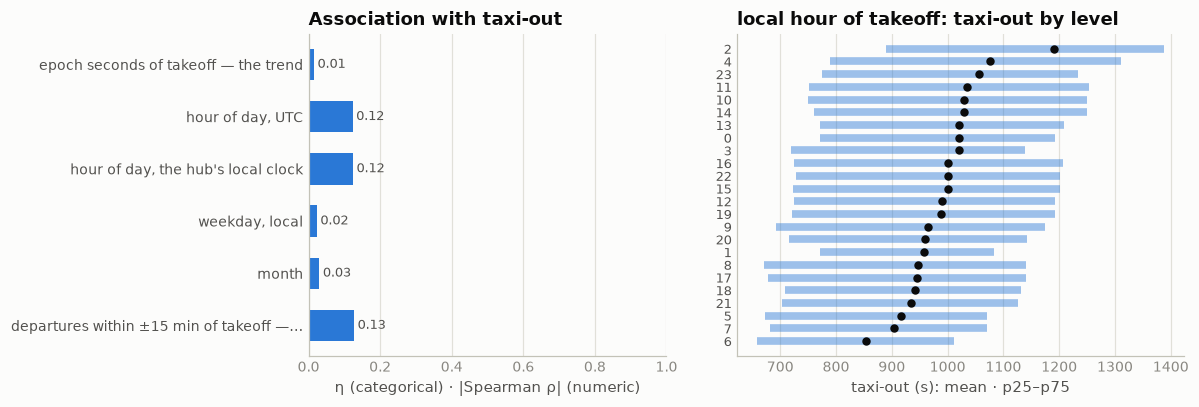

In [49]:
# correlation with the target: the trend, the calendar on both clocks, and §8's window
LOCAL = f"timezone({TZ.replace('CASE hub', 'CASE ADEP_mvt')}, MVT_TIME_UTC_mvt)"
a = target_assoc([("epoch seconds of takeoff — the trend", "num", "epoch(MVT_TIME_UTC_mvt)"),
              ("hour of day, UTC", "cat", "hour(MVT_TIME_UTC_mvt)"),
              ("hour of day, the hub's local clock", "cat", f"hour({LOCAL})"),
              ("weekday, local", "cat", f"dayofweek({LOCAL})"),
              ("month", "cat", "month(MVT_TIME_UTC_mvt)"),
              ("departures within ±15 min of takeoff — §8's window (rows with runway + anchor)", "num",
               "centered_30", 1, "wlad", "taxi_out")])
assoc_chart(a, f"hour({LOCAL})", title="local hour of takeoff")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null, second resolution, and the file's own clock** | 4,857,331 rows across both files and phases, zero missing. Training runs 1 Jan 00:01 to 31 Dec 23:57 2025; ranking is two closed blocks, all of January and all of July 2026. Six rows stamped 23:59:56–59 sit in the *next* month's file; block time disagrees with the file month on 49 rows, the schedule on 251 | this column carves the year into monthly files, on a minute-rounded copy |
| **Half the target** | takeoff − off-block equals the label to the second on all 2,085,047 training departures — sign included: 369 of them are stamped off-block *after* takeoff and carry a negative label. In-block − landing does the same on every arrival but one (an EDDM arrival with neither block time nor label) | nothing is rounded and nothing is estimated: we are given one endpoint of the interval we are asked for. Any feature that reconstructs the other endpoint from the movement side *is* the target. The 369 negative labels are §9's to explain and the target's section to judge |
| **Five hubs run on a jittered minute clock** | at EDDM, EGLL, LFPG, LIRF and LTFM *every* stamp — takeoff, landing, off-block, in-block, 2025 and 2026 — lands within ±6 s of a whole minute, spread evenly over those thirteen seconds. EDDF, EHAM and LSZH keep true seconds throughout. LEMD and LEBL split the difference: runway times at true seconds, block times on the jittered minute. That is the whole story behind the 5.1% of stamps exactly on :00 — one in twelve at the jittered hubs, one in sixty elsewhere | the label inherits it: at the five hubs taxi-out is a whole minute ± 12 s, uniform, which is 6.9 s of pure noise. Against a 280 s RMSE it costs 0.08 s, and it carries no bias — on-minute and off-minute stamps give the same mean taxi-out within 3 s at every hub. Nobody should chase sub-minute structure at Heathrow; not worth a feature |
| **The hour is worth 4–8 s, and the local clock is the right one** | group means on top of the airport: UTC hour takes the Nov+Dec holdout from 357.3 s to 353.2 s, the hub's local hour to **351.5 s**; on a Jan+Jul 2025 holdout shaped like the ranking file, 376.2 → 368.6 → 368.2 s. Weekday adds nothing on either (967–996 s across the seven days) | the local clock wins for a mechanical reason: nine hubs are an hour further from UTC in July than in January, Istanbul is not, so a UTC hour bin fitted across the year pools two local hours at nine airports. The pipeline's `hour` is UTC today; switching it to the hub's local hour is free |
| **2026 is 2025's twin, hour for hour** | the share of each month's departures per UTC hour in Jan 2026 tracks Jan 2025 within a few tenths of a percent, and July likewise — including the earlier morning ramp that daylight saving puts into July's UTC profile. Volume matches too: 4,926 vs 4,958 departures a day in January, 6,197 vs 6,152 in July | nothing about the calendar shifted between the files |
| **The calendar's mean is flat; its error is not** | monthly mean taxi-out on 1–3600 s sits between 962 s and 1,006 s all year. On clean labels the two ranking months are the heaviest per row — January carries 9.2% of the year's squared error on 7.4% of its rows, July 10.2% on 9.1% — and on labels as scored July alone carries **17.6%**, the corrupt Fiumicino rows of `VALIDATION/archive/FINDINGS_20260907.md` (§10a reads them off the schedule) | the ranking file was cut from the two hardest months of the year |
| **RMSE is a bad-day metric** | sorting hub-days by their mean taxi-out, the worst 5% of days carry 26.1% of the squared error as scored and 11.5% on clean labels; the worst 10% carry 44.0% and 18.8%. The clean list is operations, not data: LTFM's 19–23 February (1,830–1,994 s a day, consistent with the snow that week), Christmas Eve at EDDM, 17 January at LFPG, the first of September at EGLL | days like these are on no calendar feature — but they are in the file on the day, both phases, which is what the rolling state is for |
| **Look both ways** | counting departures around our takeoff on the §7 ladder, over airport × runway × anchor (283.6 s), the window centred on the takeoff beats the one that ends there at every length: 15 min −5.3 s, **30 min −5.5 s**, 60 min −5.1 s, against −3.9 s for §7's trailing hour and −2.7 s for the hour after it. Two hours is too long in every direction | every takeoff in the ranking file is known, before and after ours, so the centred count is as legal as the trailing one; it reads the runway's discharge rate through our slot rather than the queue that had already cleared |
| The two windows anchored at *pushback* are instructive | the queue when we pushed back — departures off-block and not yet airborne — is by far the most correlated single number (0.30 against ≤ 0.13 for any takeoff window) yet gains only 3.7 s on the ladder. Takeoffs in the hour before pushback gain 2.8 s, the least of all | the anchor bins already hold most of the queue: `MVT_TIME − AOBT_3` is our own taxi with an error, and that error *is* the queue. And by the time we join the queue, last hour's runway is stale |

**On representation.** Convert to epoch seconds to *compute* — every difference against an
off-block clock and every window count is unix arithmetic under the hood — but never hand the
epoch itself to the model. It is §1's ID problem again: every ranking stamp is larger than every
training stamp, so a tree would learn 2025's seasonality as a function of a counter and
extrapolate into a range it has never seen (and it would break adversarial validation on its
own). What the model sees are the pieces that repeat — local hour, weekday, month — and the
differences.

**Use in modeling.** (1) Hour of day on the hub's local clock, weekday optional. (2) Rolling
airport state anchored on this column, **centred, 15–30 minutes**, counting both phases, kept
per hub so the model can learn each airport's sign (§7a). (3) The queue at pushback as a
separate feature from the `AOBT_3` section, where the anchor lives. The two month-blocks of the
ranking file open and close cold — the first and last quarter-hour of each — which a centred
window feels at both ends; at 30 departures a seam it is nothing.

## 9 · `BLOCK_TIME_UTC_mvt` — the target's hidden endpoint

The block time: **off-block** on departure rows — the moment the aircraft leaves its stand — and
**in-block** on arrival rows, the moment it parks. §8's column is the other end of the same
interval: taxi-out is takeoff − off-block, to the second, on every training departure. This is the
half the organizers hide — the only column, with the label itself, that is blank on the 344,841
rows we predict — so the section is not about the column's distribution but about **where the hidden
endpoint sits relative to everything that stays visible**: the five off-block clocks of the flight
plan and the schedule, and the arrival half's in-block times, which do survive.

| step | question | what came out |
|---|---|---|
| **census** | present where, and where not; the one gap; which side of the runway stamp it falls | the only column blanked at prediction time; one arrival without it; 369 departures stamped off-block *after* takeoff |
| **the labels near zero** | one event seen by two sensors, or a stamp that collapsed onto the other? | Zurich's helipad fleet lifts off where it parks — genuine; ~290 airliners a year at LSZH, LFPG and LEBL carry a collapsed stamp the plan's anchor exposes; both persist in 2026's arrivals |
| **the hidden endpoint from where we stand** | how far is it from each visible off-block clock, and what does each buy as a locator of the target? | `AOBT_3` is nearest (median 52 s, 75% within 5 min) but its offset is per-hub, −117 s to +297 s, and seasonal; `EOBT_1` rivals it on the ladder, and the two together beat either by 30 s |
| **the arrival side** | the in-block clock survives at prediction time — is it a feature? | no: 0.91 correlated with the landing clock and nothing on top of it; and any window over *departures'* off-blocks is a leak |


In [4]:
# census by file × phase — present on every row except the ones we predict; the identity with the label is §8's
print("BLOCK_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (BLOCK_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(BLOCK_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') first_stamp,
           strftime(max(BLOCK_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') last_stamp,
           round(100.0*count(*) FILTER (extract(second FROM BLOCK_TIME_UTC_mvt) = 0)
                 /count(BLOCK_TIME_UTC_mvt), 2) pct_on_minute
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe one arrival with no in-block time:")
print(con.sql(f"""
    SELECT ADES_mvt hub, ADEP_mvt origin, FLIGHT_mvt, strftime(MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M:%S') landing,
           TAXITIME_SEC_mvt taxi_in, RUNWAY_mvt rwy, STAND_mvt stand, (FLIGHT_ID_mvt IS NOT NULL) AS matched_plan,
           strftime(ARVT_3_flt, '%H:%M:%S') plan_in_block
    FROM {T} WHERE PHASE_mvt = 'ARR' AND BLOCK_TIME_UTC_mvt IS NULL""").df().to_string(index=False))

print("\nwhich side of the runway stamp the block stamp falls (training) — and how often the two nearly coincide:")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n,
           count(*) FILTER (BLOCK_TIME_UTC_mvt < MVT_TIME_UTC_mvt) block_before_mvt,
           count(*) FILTER (BLOCK_TIME_UTC_mvt = MVT_TIME_UTC_mvt) block_equal_mvt,
           count(*) FILTER (BLOCK_TIME_UTC_mvt > MVT_TIME_UTC_mvt) block_after_mvt,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) label_within_12s
    FROM {T} GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))


BLOCK_TIME_UTC_mvt by file × phase:
     src  ph       n  n_null         first_stamp          last_stamp  pct_on_minute
training ARR 2082750       1 2025-01-01 00:08:55 2025-12-31 23:32:58           6.40
training DEP 2085047       0 2024-12-31 23:38:00 2025-12-31 23:41:59           6.40
 ranking ARR  344693       0 2026-01-01 00:14:57 2026-07-31 23:53:00           6.47
 ranking DEP  344841  344841                 NaN                 NaN            NaN

the one arrival with no in-block time:
 hub origin FLIGHT_mvt             landing  taxi_in rwy stand  matched_plan plan_in_block
EDDM   LBSF     DLH1EK 2025-11-04 19:35:30     <NA>  NA  None          True      20:00:10

which side of the runway stamp the block stamp falls (training) — and how often the two nearly coincide:
 ph       n  block_before_mvt  block_equal_mvt  block_after_mvt  label_within_12s
DEP 2085047           2084659               19              369               758
ARR 2082750               220               16        

In [5]:
# the labels within ±12 s of zero: one event seen twice, or a stamp that collapsed onto the other? Split by fleet,
# with the plan's own off-block AOBT_3 as the referee for what the taxi really was
NEAR0 = (f"(SELECT *, CASE WHEN AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V' THEN 'rotorcraft / VFR' "
         f"ELSE 'IFR fixed-wing' END fleet FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)")
print("departures with a label within ±12 s of zero, by hub × fleet (training; groups of ≥ 5):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, fleet, count(*) n, count(*) FILTER (TAXITIME_SEC_mvt < 0) n_negative,
           count(AOBT_3_flt) with_anchor,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_taxi_implied_by_aobt3,
           mode(AIRCRAFT_TYPE_mvt) typ, mode(STAND_mvt) stand, mode(RUNWAY_mvt) rwy
    FROM {NEAR0} GROUP BY 1, 2 HAVING count(*) >= 5 ORDER BY n DESC""").df().to_string(index=False))

print("\nLSZH's rotorcraft / VFR departures as a whole — where their labels sit:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) within_12s,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12 AND RUNWAY_mvt = 'H') within_12s_from_helipad_h,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 13 AND 300) s13_300,
           count(*) FILTER (TAXITIME_SEC_mvt > 300) over_300s
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LSZH'
      AND (AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V')""").df().to_string(index=False))

print("\nvalue by value inside ±12 s — a copied stamp would pile up at 0; neither fleet does:")
print(con.sql(f"""
    SELECT TAXITIME_SEC_mvt s, count(*) FILTER (fleet = 'rotorcraft / VFR') rotorcraft_vfr,
           count(*) FILTER (fleet = 'IFR fixed-wing') ifr_fixed_wing
    FROM {NEAR0} GROUP BY 1 ORDER BY 1""").df().set_index("s").T.to_string())

print("\nthe same coincidence on arrivals (in-block within ±12 s of landing), per 10,000 — training vs ranking:")
print(con.sql(f"""
    SELECT ADES_mvt hub,
           round(1e4*count(*) FILTER (src = 't' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)/count(*) FILTER (src = 't'), 1) train_per_10k,
           round(1e4*count(*) FILTER (src = 'r' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)/count(*) FILTER (src = 'r'), 1) rank_per_10k,
           count(*) FILTER (src = 'r' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12) rank_rows
    FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r', * FROM {R}) WHERE PHASE_mvt = 'ARR'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 4""").df().to_string(index=False))


departures with a label within ±12 s of zero, by hub × fleet (training; groups of ≥ 5):


 hub            fleet   n  n_negative  with_anchor  med_taxi_implied_by_aobt3  typ stand rwy
LSZH rotorcraft / VFR 456         225            4                      509.0 AS50   HPW   H
LSZH   IFR fixed-wing 149          73          142                      907.0 C56X   GA6  28
LFPG   IFR fixed-wing 128          61          108                      959.0 B738   P73 26R
LEBL   IFR fixed-wing  12           5           12                      933.0 A320  143A 24L

LSZH's rotorcraft / VFR departures as a whole — where their labels sit:
   n  within_12s  within_12s_from_helipad_h  s13_300  over_300s
1141         456                        360       41        644

value by value inside ±12 s — a copied stamp would pile up at 0; neither fleet does:
s               -12  -11  -10  -9   -8   -7   -6   -5   -4   -3   -2   -1   0    1    2    3    4    5    6    7    8    9    10   11   12 
rotorcraft_vfr    4   29   20   16   15   12   35   16   18   17   18   26   10   11   28   17   27   24   1

hidden off-block minus each visible clock (seconds; positive = the airport logged the pushback later):


     clock  pct_present   med    p10    p90  pct_within_1min  pct_within_5min  pct_within_15min
  schedule       100.00 415.0 -242.0 2396.0              9.5             36.6              68.9
  LOBT_flt        98.98 252.0 -264.0 1136.0             11.3             44.2              84.1
  IOBT_flt        98.98 252.0 -246.0 1136.0             11.3             44.3              84.1
EOBT_1_flt        98.98 284.0 -126.0 1036.0             12.7             49.0              86.1
AOBT_3_flt        98.98  52.0 -306.0  363.0             21.1             74.8              97.7

the nearest clock, AOBT_3, per hub:


 hub      n    med    p25   p75  pct_within_5min  pct_block_after_aobt3
LIRF 158737 -117.0 -359.0  61.0             66.4                   34.4
LEBL 179699  -54.0 -179.0  65.0             81.7                   42.4
LSZH 134568  -33.0 -183.0  96.0             82.6                   43.1
LFPG 239091   -4.0 -181.0 123.0             74.0                   45.7
EDDM 167275   -2.0 -177.0 117.0             82.6                   47.4
LEMD 212242    2.0 -122.0 120.0             86.5                   51.3
EGLL 238818   55.0 -124.0 234.0             73.2                   54.8
EDDF 230068   88.0  -44.0 197.0             85.4                   68.0
EHAM 247866  107.0   -3.0 241.0             81.0                   74.2
LTFM 272169  297.0   58.0 479.0             44.5                   78.4



honest ladder on 327,485 Nov+Dec departures — airport mean 357.3 s; then airport × bins of (takeoff − clock):


     clock  raw gap as the prediction  airport × 20 bins  airport × 100 bins
  schedule                     2451.3              320.7               320.6
  LOBT_flt                      679.4              301.2               300.6
  IOBT_flt                      679.1              300.9               300.3
EOBT_1_flt                      626.7              290.1               289.2
AOBT_3_flt                      354.2              293.5               281.7


AOBT_3 (20 bins) × EOBT_1 (5 bins): 252.4 s — the two clocks are not the same information



median off-block − AOBT_3 by month (s) — all hubs, and the two ends of the per-hub range:
mon        1    2    3    4    5    6    7    8    9    10   11   12
all hubs   60   58   57   55   47   28    5   22   17   35   56   54
LTFM      355  355  360  298  295  244  234  240  243  294  304  296
LIRF      -59  -57  -65 -122 -123 -175 -178 -122 -119 -121   -5  -59


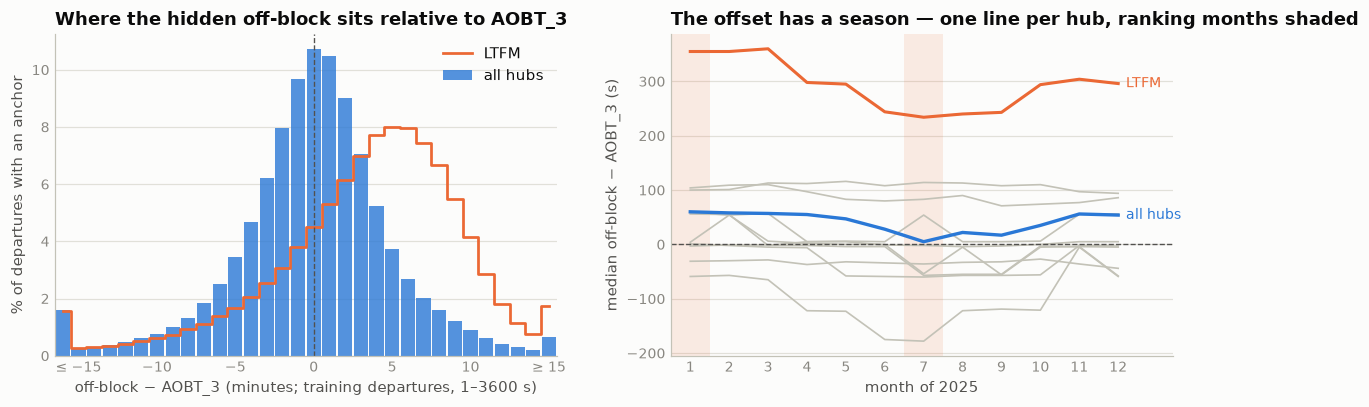

In [6]:
# the hidden off-block against the five visible off-block clocks, on the rows we model: how far each sits from it,
# and — honest ladder, fit Jan–Oct, score Nov+Dec — what each buys as a locator of the target
CLOCKS = [("schedule", "SCHED_TIME_UTC_mvt"), ("LOBT_flt", "LOBT_flt"), ("IOBT_flt", "IOBT_flt"),
          ("EOBT_1_flt", "EOBT_1_flt"), ("AOBT_3_flt", "AOBT_3_flt")]
print("hidden off-block minus each visible clock (seconds; positive = the airport logged the pushback later):")
print(pd.concat([con.sql(f"""
    SELECT '{name}' clock, round(100.0*count({col})/count(*), 2) pct_present,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.5)) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.10)) p10,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.90)) p90,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 60)/count({col}), 1) pct_within_1min,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 300)/count({col}), 1) pct_within_5min,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 900)/count({col}), 1) pct_within_15min
    FROM {TGT}""").df() for name, col in CLOCKS], ignore_index=True).to_string(index=False))

print("\nthe nearest clock, AOBT_3, per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.25)) p25,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.75)) p75,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt)) <= 300)/count(AOBT_3_flt), 1) pct_within_5min,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_block_after_aobt3
    FROM {TGT} GROUP BY 1 ORDER BY med""").df().to_string(index=False))

# the ladder: airport → airport × quantile bins of (takeoff − clock); bins cut on Jan–Oct, cell support ≥ 30, else the coarser rung
con.sql(f"""
    CREATE OR REPLACE TABLE blk_gap AS
    SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           {', '.join(f'epoch(MVT_TIME_UTC_mvt - {col}) g_{i}' for i, (_, col) in enumerate(CLOCKS))}
    FROM {TGT}""")


def blk_ladder(*bins):
    """bins: (gap column, number of quantile bins), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}"
                     for k, (c, n) in enumerate(bins))
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}"
                    for k, (c, _) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE blk_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM blk_gap WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM blk_gap JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE blk_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM blk_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN blk_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN blk_r{k}.c >= 30 THEN blk_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2))
                       FROM blk_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM blk_gap WHERE is_val").fetchone()[0]
print(f"\nhonest ladder on {n_val:,} Nov+Dec departures — airport mean {blk_ladder():.1f} s; then airport × bins of (takeoff − clock):")
rows = []
for i, (name, _) in enumerate(CLOCKS):
    raw = con.sql(f"SELECT sqrt(avg((y - g_{i})^2)) FROM blk_gap WHERE is_val AND g_{i} IS NOT NULL").fetchone()[0]
    rows.append((name, raw, blk_ladder((f"g_{i}", 20)), blk_ladder((f"g_{i}", 100))))
print(pd.DataFrame(rows, columns=["clock", "raw gap as the prediction", "airport × 20 bins", "airport × 100 bins"])
      .round(1).to_string(index=False))
print(f"AOBT_3 (20 bins) × EOBT_1 (5 bins): {blk_ladder(('g_4', 20), ('g_3', 5)):.1f} s — the two clocks are not the same information")

# shape and season of the anchor's offset
hist = con.sql(f"""
    SELECT ADEP_mvt hub, greatest(least(floor(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt)/60.0), 15), -16)::INT m, count(*) n
    FROM {TGT} WHERE AOBT_3_flt IS NOT NULL GROUP BY 1, 2""").df()
season = con.sql(f"""
    SELECT ADEP_mvt hub, month(MVT_TIME_UTC_mvt) mon, quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5) med
    FROM {TGT} GROUP BY 1, 2 ORDER BY 1, 2""").df()
season_all = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) mon, quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5) med
    FROM {TGT} GROUP BY 1 ORDER BY 1""").df()
print("\nmedian off-block − AOBT_3 by month (s) — all hubs, and the two ends of the per-hub range:")
print(pd.DataFrame({"all hubs": season_all.set_index("mon").med, "LTFM": season[season.hub == "LTFM"].set_index("mon").med,
                    "LIRF": season[season.hub == "LIRF"].set_index("mon").med}).T.round(0).astype(int).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
tot = hist.groupby("m").n.sum()
a1.bar(tot.index, 100 * tot / tot.sum(), width=0.9, color=BLUE, alpha=0.8, label="all hubs")
lt = hist[hist.hub == "LTFM"].set_index("m").n.reindex(tot.index, fill_value=0)
a1.step(lt.index, 100 * lt / lt.sum(), where="mid", color=ORANGE, lw=1.8, label="LTFM")
a1.axvline(0, color=INK2, lw=0.9, ls="--")
a1.set_xlim(-16.5, 15.5)
a1.set_xticks([-15, -10, -5, 0, 5, 10, 15], ["≤ −15", "−10", "−5", "0", "5", "10", "≥ 15"])
a1.set_title("Where the hidden off-block sits relative to AOBT_3")
a1.set_xlabel("off-block − AOBT_3 (minutes; training departures, 1–3600 s)")
a1.set_ylabel("% of departures with an anchor")
a1.legend(loc="upper right")
style(a1)

for lo, hi in [(0.5, 1.5), (6.5, 7.5)]:
    a2.axvspan(lo, hi, color=ORANGE, alpha=0.12, lw=0)
for hub, g in season.groupby("hub"):
    a2.plot(g.mon, g.med, color=BASELINE, lw=1.1)
lt = season[season.hub == "LTFM"]
a2.plot(lt.mon, lt.med, color=ORANGE, lw=2.0, zorder=3)
a2.text(12.2, lt.med.iloc[-1], "LTFM", color=ORANGE, fontsize=9, va="center")
a2.plot(season_all.mon, season_all.med, color=BLUE, lw=2.2, zorder=3)
a2.text(12.2, season_all.med.iloc[-1], "all hubs", color=BLUE, fontsize=9, va="center")
a2.axhline(0, color=INK2, lw=0.9, ls="--")
a2.set_xticks(range(1, 13))
a2.set_xlim(0.5, 13.4)
a2.set_title("The offset has a season — one line per hub, ranking months shaded")
a2.set_xlabel("month of 2025")
a2.set_ylabel("median off-block − AOBT_3 (s)")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [7]:
# the arrival half's in-block clock as a window feature — and the departure half's off-block clock as the leak it would be.
# §8's ladder (airport × runway × AOBT_3 anchor, + departures within ±15 min of takeoff), then arrivals landing vs arrivals
# in-block in the same window. Every count is computed from the movement stream of both phases, per hub.
con.sql(f"""
    CREATE OR REPLACE TABLE blk_ev AS
    SELECT MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph,
           MVT_TIME_UTC_mvt t, BLOCK_TIME_UTC_mvt b, RUNWAY_mvt rwy, AOBT_3_flt aobt3, TAXITIME_SEC_mvt taxi
    FROM {T}""")
con.sql("""
    CREATE OR REPLACE TABLE blk_win AS
    SELECT hub, ts, ph, kind,
           sum(CASE WHEN ph = 'DEP' AND kind = 'mvt' THEN 1 ELSE 0 END) OVER w dep_c30,
           sum(CASE WHEN ph = 'ARR' AND kind = 'mvt' THEN 1 ELSE 0 END) OVER w arr_land_c30,
           sum(CASE WHEN ph = 'ARR' AND kind = 'blk' THEN 1 ELSE 0 END) OVER w arr_inblock_c30,
           sum(CASE WHEN ph = 'DEP' AND kind = 'blk' THEN 1 ELSE 0 END) OVER w dep_offblock_c30
    FROM (SELECT hub, ph, t ts, 'mvt' kind FROM blk_ev
          UNION ALL SELECT hub, ph, b, 'blk' FROM blk_ev WHERE b IS NOT NULL)
    WINDOW w AS (PARTITION BY hub ORDER BY ts
                 RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING)""")
con.sql("""
    CREATE OR REPLACE TABLE blk_lad AS
    SELECT e.id, e.hub, e.rwy, e.taxi::DOUBLE y, epoch(e.t - e.aobt3) anchor, (e.t >= TIMESTAMPTZ '2025-11-01') is_val,
           w.dep_c30, w.arr_land_c30, w.arr_inblock_c30, w.dep_offblock_c30
    FROM blk_ev e JOIN blk_win w ON w.hub = e.hub AND w.ts = e.t AND w.kind = 'mvt' AND w.ph = 'DEP'
    WHERE e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600 AND e.rwy IS NOT NULL AND e.aobt3 IS NOT NULL
    QUALIFY row_number() OVER (PARTITION BY e.id) = 1""")
print("the window counts against each other (training departures with runway + anchor):")
print(con.sql("""
    SELECT count(*) n, round(corr(arr_land_c30, arr_inblock_c30), 3) corr_landing_vs_inblock,
           round(corr(dep_c30, dep_offblock_c30), 3) corr_takeoff_vs_offblock
    FROM blk_lad""").df().to_string(index=False))

con.sql("""
    CREATE OR REPLACE TABLE blk_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(dep_c30, [0.2,0.4,0.6,0.8]) qd, quantile_cont(arr_land_c30, [0.2,0.4,0.6,0.8]) ql,
                         quantile_cont(arr_inblock_c30, [0.2,0.4,0.6,0.8]) qi, quantile_cont(dep_offblock_c30, [0.2,0.4,0.6,0.8]) qo
                  FROM blk_lad WHERE NOT is_val GROUP BY 1)
    SELECT hub, rwy, y, is_val, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
           list_count(list_filter(qd, x -> x <= dep_c30)) q_dep, list_count(list_filter(ql, x -> x <= arr_land_c30)) q_land,
           list_count(list_filter(qi, x -> x <= arr_inblock_c30)) q_inb, list_count(list_filter(qo, x -> x <= dep_offblock_c30)) q_off
    FROM blk_lad JOIN cuts USING (hub)""")


def blk_rungs(rungs):
    """Sequential ladder: holdout RMSE after each rung, cell support ≥ 30 else the coarser rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE blk_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM blk_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN blk_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN blk_s{i}.c >= 30 THEN blk_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM blk_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM blk_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"]),
        ("+ departures ±15 min (§8)", ["hub", "rwy", "q_anc", "q_dep"])]
n_val = con.sql("SELECT count(*) FROM blk_wb WHERE is_val").fetchone()[0]
print(f"\nhonest ladder, fit Jan–Oct → scored on {n_val:,} Nov+Dec departures:")
for name, r in blk_rungs(BASE + [("+ arrivals landing ±15 min", ["hub", "rwy", "q_anc", "q_dep", "q_land"]),
                                 ("+ arrivals in-block ±15 min, on top", ["hub", "rwy", "q_anc", "q_dep", "q_land", "q_inb"])]):
    print(f"    {name:40s} {r:7.1f} s")
for name, r in blk_rungs(BASE + [("+ arrivals in-block ±15 min, instead", ["hub", "rwy", "q_anc", "q_dep", "q_inb"])])[-1:]:
    print(f"    {name:40s} {r:7.1f} s")
for name, r in blk_rungs(BASE + [("+ departures off-block ±15 min — the leak", ["hub", "rwy", "q_anc", "q_dep", "q_off"])])[-1:]:
    print(f"    {name:40s} {r:7.1f} s")

print("\nand at prediction time the off-block count does not exist — ranking departures with a block time:")
print(con.sql(f"SELECT count(*) departures, count(BLOCK_TIME_UTC_mvt) with_block_time FROM {R} WHERE PHASE_mvt = 'DEP'")
      .df().to_string(index=False))


the window counts against each other (training departures with runway + anchor):
      n  corr_landing_vs_inblock  corr_takeoff_vs_offblock
2059401                    0.914                     0.775



honest ladder, fit Jan–Oct → scored on 324,631 Nov+Dec departures:
    airport                                    355.4 s
    + runway                                   341.8 s
    + AOBT_3 anchor                            283.6 s
    + departures ±15 min (§8)                  278.1 s
    + arrivals landing ±15 min                 277.4 s
    + arrivals in-block ±15 min, on top        277.9 s


    + arrivals in-block ±15 min, instead       277.2 s
    + departures off-block ±15 min — the leak   275.9 s

and at prediction time the off-block count does not exist — ranking departures with a block time:
 departures  with_block_time
     344841                0


In [8]:
# closing state — the column after §9, which repairs nothing: no derived file, no value touched
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (BLOCK_TIME_UTC_mvt IS NULL) block_null,
           count(*) FILTER (TAXITIME_SEC_mvt IS NULL) label_null,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) label_negative,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) label_within_12s
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\nbefore = after on every count: §9 repairs nothing (see the decisions table)")


     src  ph       n  block_null  label_null  label_negative  label_within_12s
training ARR 2082750           1           1             220               472
training DEP 2085047           0           0             369               758
 ranking ARR  344693           0           0              39                92
 ranking DEP  344841      344841      344841               0                 0

before = after on every count: §9 repairs nothing (see the decisions table)


                                    feature    kind  n / levels  pearson_r  spearman_ρ  η
                off-block epoch — the trend numeric     2080533      0.012       0.015   
                         takeoff − schedule numeric     2080533      0.190       0.383   
                         takeoff − LOBT_flt numeric     2059401      0.499       0.507   
                         takeoff − IOBT_flt numeric     2059401      0.500       0.509   
                       takeoff − EOBT_1_flt numeric     2059401      0.547       0.567   
          takeoff − AOBT_3_flt — the anchor numeric     2059401      0.545       0.616   
 arrivals landing within ±15 min of takeoff numeric     2059401      0.073       0.109   
arrivals in-block within ±15 min of takeoff numeric     2059401      0.080       0.114   


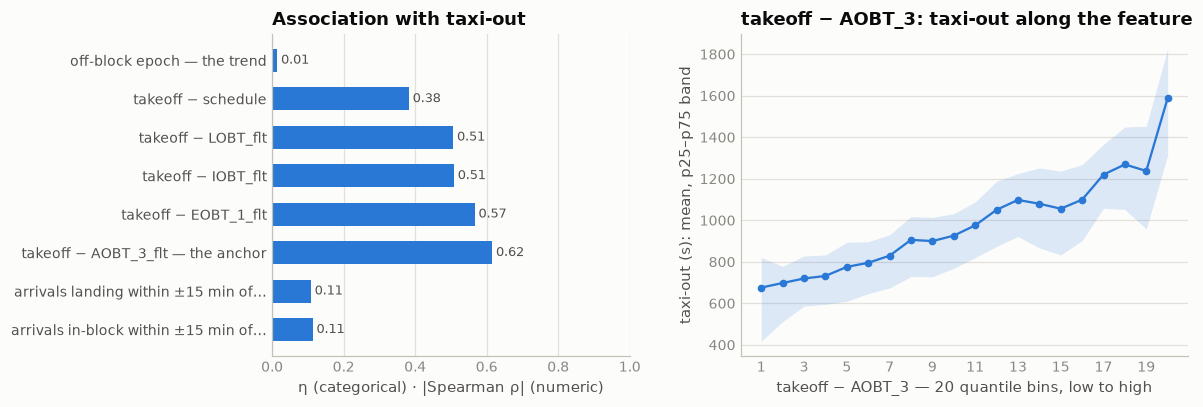

In [9]:
# correlation with the target: the stamp itself is a calendar; its model-facing forms are the five gaps takeoff − visible
# clock (each clock's own section refines its gap) and the arrival stream's in-block count from §9's window table
a = target_assoc([("off-block epoch — the trend", "num", "epoch(BLOCK_TIME_UTC_mvt)"),
                  ("takeoff − schedule", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)"),
                  ("takeoff − LOBT_flt", "num", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)"),
                  ("takeoff − IOBT_flt", "num", "epoch(MVT_TIME_UTC_mvt - IOBT_flt)"),
                  ("takeoff − EOBT_1_flt", "num", "epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)"),
                  ("takeoff − AOBT_3_flt — the anchor", "num", "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)"),
                  ("arrivals landing within ±15 min of takeoff", "num", "arr_land_c30", 1, "blk_lad", "y"),
                  ("arrivals in-block within ±15 min of takeoff", "num", "arr_inblock_c30", 1, "blk_lad", "y")])
assoc_chart(a, "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)", kind="num", title="takeoff − AOBT_3")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The only column hidden at prediction time — and the label's other endpoint** | present on every training row but one (an EDDM arrival, `DLH1EK` from Sofia on 4 Nov 2025, that also lacks runway, stand and label); null on 344,841 of 344,841 ranking departures, on 0 of 344,693 ranking arrivals. 6.40% of stamps on the minute: §8's jittered minute clock, which seven hubs use for block times | taxi-out = takeoff − this (§8). It never enters the model; everything below is about locating it from what is visible |
| The block stamp falls *after* the runway stamp on 369 departures, and within ±12 s of it on 758 | departures: 2,084,659 before, 19 equal, 369 after; arrivals: 220 before landing, 16 equal, 2,082,513 after, 472 within ±12 s | two different things hide in those 758 — the next two rows |
| **Helipad lift-offs are genuine near-zero taxi** | LSZH's rotorcraft / VFR fleet: 456 of its 1,141 departures within ±12 s, 360 of them off helipad `H` (stand `HPW`); the other 644 over 300 s are the fixed-wing VFR from the GA apron. Inside ±12 s the values spread evenly from −12 to +12 rather than piling up at 0 | two sensors timing one event, the sign is noise. §4's is-helicopter × airport already predicts them (median 7 s at LSZH) |
| **The collapsed stamp on airliners is a defect** | 149 LSZH (Citations from `GA6`, runway 28), 128 LFPG (737s from `P73`, 26R) and 12 LEBL IFR fixed-wing departures carry a label within ±12 s while the plan's `AOBT_3` puts their taxi at a median **907 / 959 / 933 s** | ~290 rows a year whose label is a quarter of an hour too small. Unrepairable — the score uses the label as delivered — and cheap: a few per 10,000. §14: they train where the label is ≥ 1 s, and it does not matter (0.06% of the holdout's squared error) |
| Both populations are in 2026 | arrivals in-block within ±12 s of landing, per 10,000: LSZH 27.6 → **31.1** (72 ranking rows), LFPG 1.3 → 1.8, EGLL 1.8 → 1.5 | the departures we predict carry the same two slices at the same rates |
| **`AOBT_3` is the nearest visible clock by far — but not by a constant** | off-block − clock, median (p10, p90): schedule 415 s (−242, 2,396) · `LOBT`/`IOBT` 252 (−264, 1,136) · `EOBT_1` 284 (−126, 1,036) · **`AOBT_3` 52 (−306, 363)**; within 5 min 36.6 / 44.2 / 49.0 / **74.8%**, within 15 min 97.7% for `AOBT_3`. Per hub its offset runs from **−117 s at LIRF** (the airport's pushback *before* the plan's; 66.4% within 5 min) to **+297 s at LTFM** (78.4% after; 44.5% within 5 min), with EHAM +107, EDDF +88, EGLL +55 and LEMD, EDDM, LFPG within ±4 s. And it moves with the season: all hubs 60 s in January, **5 s in July**, 54 s in December; LTFM 355 s in January, 234 s in July; LIRF −59 s in January, −178 s in July | the anchor is an estimate with a per-airport, per-season bias — which is why §7's ladder gains 58 s from binning it per airport and runway rather than subtracting it. The two ranking months sit at the two ends of the season. The `AOBT_3` section owns the calibration |
| **As a locator the anchor rewards resolution; the filed clocks carry the delay** | over the airport mean (357.3 s), airport × 20 bins of takeoff − clock: schedule 320.7 · `LOBT` 301.2 · `IOBT` 300.9 · **`EOBT_1` 290.1 · `AOBT_3` 293.5**; at 100 bins `AOBT_3` 281.7, `EOBT_1` 289.2; **`AOBT_3` (20) × `EOBT_1` (5): 252.4 s**. The raw gap as the prediction: 354 s for `AOBT_3`, 627–2,451 s for the others | takeoff − `AOBT_3` is the target plus a bounded offset, so finer bins keep paying; takeoff − `EOBT_1` is the target plus the *pushback delay*, a signal of its own (§2b: late flights taxi longer) that saturates at 20 bins. Together they beat either alone by 30 s — the pushback delay, `AOBT_3` − `EOBT_1`, is a feature to build explicitly; `EOBT_1`'s section |
| The arrival half's in-block clock is not a feature of its own | arrivals in-block within ±15 min of takeoff correlate 0.914 with arrivals landing in the same window; on §8's ladder (278.1 s after the departure count) the landing count takes it to 277.4, in-block on top 277.9, in-block instead 277.2 | in-block = landing + taxi-in, and both are already in §7's stream. Nothing to add |
| **Any feature over departures' off-blocks is a leak** | departures off-block within ±15 min of takeoff gains 2.2 s in CV (278.1 → 275.9) — and 0 of 344,841 ranking departures carry a block time to count | never touch `DEP` block times, not even other rows'. §8's queue at pushback is built on `AOBT_3` for exactly this reason |

**Decisions**

| issue | decision | why |
|---|---|---|
| departures' off-block times, own row or other rows' | **never enter a feature**, not even as a window count | blank on every ranking departure; a count over them trains on a column that is empty at prediction time |
| the 289 collapsed airliner stamps | **no repair**; §14 finds they cost 0.03% of the error in training or out | the score uses the label as delivered; a few per 10,000, unpredictable, and the same defect sits in the 2026 arrivals |
| the helipad near-zeros | left alone | genuine, and §4's is-helicopter × airport predicts them |
| the one arrival without an in-block time | left as is | not predicted, and it has no label to lose |
| arrivals' in-block times | not a feature of their own | landing + taxi-in carry the same information (§7) |

**State after §9** — unchanged, by design:

| `BLOCK_TIME_UTC_mvt` null | training DEP | training ARR | ranking DEP | ranking ARR |
|---|---:|---:|---:|---:|
| before → after | 0 → 0 | 1 → 1 | 344,841 → 344,841 | 0 → 0 |

**Use in modeling.** The column itself never does. Its five visible stand-ins are the pipeline's
takeoff − clock gaps (`build_features` in `pipeline/common.py` builds all five): keep them per
airport, so the model calibrates the anchor's own offset per hub — and expect that offset to
move with the season, with the two ranking months at its extremes. Build the pushback delay
`AOBT_3` − `EOBT_1` as a feature in its own right. In the closing matrix the column enters as
epoch seconds, like the takeoff clock: 1.00 with `MVT_TIME_UTC_mvt`, 0.01 with the target — the
label is their difference, which no marginal measure sees. The gaps enter with their own sections.


## 10 · `SCHED_TIME_UTC_mvt` — the timetable

The scheduled time: **scheduled off-block** on departure rows, **scheduled in-block** on arrivals.
Never null in either file, on either phase, always a whole minute and — on departures — always on
the timetable's 5-minute grid. It is the one clock in the file written *before the day*, so
everything measured against it is a delay: how late the aircraft pushed back, how late it took
off. Both ends of the second difference survive at prediction time: takeoff − schedule is
computable on every row we predict.

| step | question | what came out |
|---|---|---|
| **census** | present where — and which clock is it, exactly? | never null; on departures it *is* the plan's filed off-block for three flights in four (the rest were refiled later); on arrivals the scheduled in-block |
| **the delay** | how late do flights push back and take off, per hub; does taxi-out care; and does 2026 look like 2025? | a median 3–10 min late, a quarter push early; taxi-out barely moves with it on clean rows; January 2026 ran later than January 2025, July earlier |
| **10a · the corruption gauge** | the corrupt Fiumicino labels of `VALIDATION/archive/FINDINGS_20260907.md` — can the schedule see them? | yes: where no pushback was captured the block stamp is the *schedule's*, so the label equals takeoff − schedule, and both ends of that are in the ranking file |
| **signal on clean rows** | the hour on which clock; the delay on top of the anchor; scheduled demand against the actual window | both hours together beat either; the plan's delay beats the schedule's; scheduled demand adds nothing over the actual window |


In [4]:
# census by file × phase: never null, whole minutes on the timetable's 5-minute grid — and which clock it is:
# the plan's filed off-block on departures, the scheduled in-block on arrivals
print("SCHED_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (SCHED_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(SCHED_TIME_UTC_mvt), '%Y-%m-%d %H:%M') first_stamp,
           strftime(max(SCHED_TIME_UTC_mvt), '%Y-%m-%d %H:%M') last_stamp,
           round(100.0*count(*) FILTER (extract(second FROM SCHED_TIME_UTC_mvt) = 0)/count(*), 1) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM SCHED_TIME_UTC_mvt) % 5 = 0)/count(*), 1) pct_on_5min_grid,
           count(DISTINCT SCHED_TIME_UTC_mvt) n_unique
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndepartures — the schedule against the plan's filed off-block clocks (matched, training):")
print(pd.concat([con.sql(f"""
    SELECT '{c}' clock, count(*) n, round(100.0*count(*) FILTER (SCHED_TIME_UTC_mvt = {c})/count(*), 1) pct_equal,
           round(100.0*count(*) FILTER ({c} > SCHED_TIME_UTC_mvt)/count(*) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) pct_plan_later_when_different,
           round(quantile_cont(epoch({c} - SCHED_TIME_UTC_mvt)/60.0, 0.5) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) med_min_later_when_different,
           round(100.0*count(*) FILTER ({c} != SCHED_TIME_UTC_mvt AND extract(minute FROM {c}) % 5 = 0)
                 /count(*) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) pct_on_5min_grid_when_different
    FROM {T} WHERE PHASE_mvt = 'DEP' AND {c} IS NOT NULL""").df() for c in ("IOBT_flt", "LOBT_flt", "EOBT_1_flt")],
    ignore_index=True).to_string(index=False))

print("\nschedule = IOBT_flt by market segment (matched departures):")
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, count(*) n,
           round(100.0*count(*) FILTER (IOBT_flt = SCHED_TIME_UTC_mvt)/count(*), 1) pct_equal
    FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nunmatched departures carry a schedule too:")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (extract(minute FROM SCHED_TIME_UTC_mvt) % 5 = 0)/count(*), 1) pct_on_5min_grid,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_takeoff_minus_sched_min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL""").df().to_string(index=False))

print("\narrivals — the schedule is the scheduled in-block: landing and in-block against it, per hub (1–3600 s):")
print(con.sql(f"""
    SELECT ADES_mvt hub, count(*) n,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_landing_minus_sched_min,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_inblock_minus_sched_min,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt < SCHED_TIME_UTC_mvt)/count(*), 1) pct_inblock_early
    FROM {T} WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1 ORDER BY 3""").df().to_string(index=False))


SCHED_TIME_UTC_mvt by file × phase:
     src  ph       n  n_null      first_stamp       last_stamp  pct_on_minute  pct_on_5min_grid  n_unique
training ARR 2082750       0 2024-12-28 10:05 2025-12-31 23:45          100.0              99.8    106024
training DEP 2085047       0 2024-12-31 22:40 2025-12-31 23:40          100.0             100.0     99290
 ranking ARR  344693       0 2025-12-31 04:25 2026-07-31 23:50          100.0              99.8     18093
 ranking DEP  344841       0 2025-12-31 09:35 2026-07-31 23:00          100.0             100.0     16987

departures — the schedule against the plan's filed off-block clocks (matched, training):


     clock       n  pct_equal  pct_plan_later_when_different  med_min_later_when_different  pct_on_5min_grid_when_different
  IOBT_flt 2062577       74.4                           88.5                          20.0                             82.1
  LOBT_flt 2062577       74.0                           87.9                          20.0                             80.8
EOBT_1_flt 2062577       55.5                           64.9                          10.0                             66.6

schedule = IOBT_flt by market segment (matched departures):
      segment       n  pct_equal
     Mainline 1325748       73.3
      Lowcost  399482       76.6
     Regional  210865       81.1
        Cargo   60021       65.1
     Business   44498       75.4
Non-Scheduled   14577       62.8
        Other    6673       65.4
     Military     713       52.0

unmatched departures carry a schedule too:
    n  pct_on_5min_grid  med_takeoff_minus_sched_min
22424              98.3                         8

 hub      n  med_landing_minus_sched_min  med_inblock_minus_sched_min  pct_inblock_early
LTFM 273871                        -17.9                         -3.1               56.9
LEMD 211091                        -11.1                         -2.9               55.8
LIRF 160212                        -11.0                          0.0               49.5
EGLL 239438                        -11.0                         -2.1               54.8
LFPG 238768                         -9.1                          0.1               48.9
EDDF 230116                         -8.2                          1.5               45.9
EHAM 247686                         -6.6                          1.6               46.1
LEBL 179079                         -5.6                         -2.0               53.8
EDDM 167321                         -5.1                          0.9               47.9
LSZH 134491                         -2.0                          3.8               39.9


pushback delay = off-block − schedule (minutes), training departures 1–3600 s, per hub:


 hub      n  med  p10  p90  pct_pushed_early  pct_over_1h_late  med_takeoff_minus_sched
EGLL 238818  3.0 -7.0 33.9              37.3               4.1                     26.9
LTFM 272169  3.0 -6.9 31.9              36.6               4.5                     20.9
LIRF 158737  4.0 -5.9 40.0              34.0               5.1                     24.0
EDDM 167275  5.9 -3.1 32.9              23.6               3.3                     19.1
LEBL 179699  6.0 -4.0 44.1              25.1               6.3                     22.5
LEMD 212242  7.9 -3.0 41.0              19.5               5.4                     24.6
EDDF 230068  9.2 -2.0 39.7              15.7               4.7                     23.6
EHAM 247866  9.6 -1.7 45.7              14.9               6.5                     23.0
LFPG 239091  9.9 -2.9 47.9              19.0               6.9                     27.0
LSZH 134568 10.1 -0.9 38.9              12.3               4.3                     22.6

taxi-out by pushback-delay band

                      band      n  pct  mean_taxi  med_taxi
1 · more than 15 min early   9680  0.5      954.0     906.5
                 2 · early 493678 23.7     1008.0     955.0
         3 · 0–15 min late 938448 45.1      961.0     899.0
        4 · 15–60 min late 531060 25.5      985.0     918.0
            5 · 1–3 h late  96788  4.7     1020.0     956.0
         6 · over 3 h late  10879  0.5     1039.0     967.0

the far tail — departures whose takeoff is more than 12 h from the schedule (training, raw labels), per hub:


 hub   n  unmatched  pct_about_a_day  segment  med_label
EDDF 360         18             22.0    Cargo     1118.0
EHAM 121         14             17.0    Cargo      982.0
LFPG  39          9             28.0    Cargo     1069.0
LIRF  32         29             13.0    Other    58137.0
LTFM  28          1             14.0 Mainline     1137.0
EDDM  26          3             12.0 Mainline      820.0
LEBL  14          2              0.0 Mainline     1067.0
LEMD   7          0             14.0 Mainline      754.0
EGLL   2          0              0.0 Mainline     1192.0
LSZH   2          0              0.0 Mainline      696.0

look both ways — takeoff − schedule (minutes) in the ranking months and their 2025 twins, all departures:


  yr  mon      n  med  p90  pct_over_1h
2025    1 153706 21.3 57.1          9.1
2026    1 152719 24.7 71.0         13.5
2025    7 190713 28.6 73.0         14.9
2026    7 192122 25.2 65.0         11.7


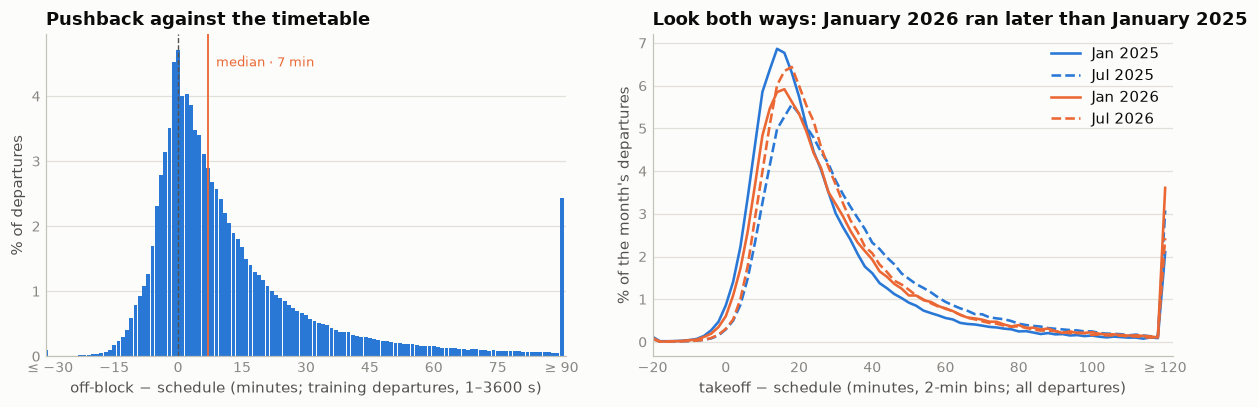

In [5]:
# the delay the schedule measures: off-block − schedule on the rows we model, per hub; taxi-out by delay band; the far
# tail; and — computable on both files — takeoff − schedule in the two ranking months against their 2025 twins
print("pushback delay = off-block − schedule (minutes), training departures 1–3600 s, per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.10), 1) p10,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.90), 1) p90,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt < SCHED_TIME_UTC_mvt)/count(*), 1) pct_pushed_early,
           round(100.0*count(*) FILTER (epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) > 3600)/count(*), 1) pct_over_1h_late,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_takeoff_minus_sched
    FROM {TGT} GROUP BY 1 ORDER BY med""").df().to_string(index=False))

print("\ntaxi-out by pushback-delay band (training departures 1–3600 s):")
print(con.sql(f"""
    SELECT CASE WHEN d < -15 THEN '1 · more than 15 min early' WHEN d < 0 THEN '2 · early' WHEN d < 15 THEN '3 · 0–15 min late'
                WHEN d < 60 THEN '4 · 15–60 min late' WHEN d < 180 THEN '5 · 1–3 h late' ELSE '6 · over 3 h late' END band,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM (SELECT *, epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 d FROM {TGT}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe far tail — departures whose takeoff is more than 12 h from the schedule (training, raw labels), per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) unmatched,
           round(100.0*count(*) FILTER (abs(abs(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) - 86400) < 7200)/count(*)) pct_about_a_day,
           mode(MARKET_SEGMENT_flt) segment, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND abs(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) > 12*3600
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nlook both ways — takeoff − schedule (minutes) in the ranking months and their 2025 twins, all departures:")
print(con.sql(f"""
    SELECT yr, mon, count(*) n, round(quantile_cont(g, 0.5), 1) med, round(quantile_cont(g, 0.9), 1) p90,
           round(100.0*count(*) FILTER (g > 60)/count(*), 1) pct_over_1h
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 g FROM {T}
          WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7)
          UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 FROM {R} WHERE PHASE_mvt = 'DEP')
    GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

delay = con.sql(f"""
    SELECT greatest(least(floor(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0), 90), -31)::INT m, count(*) n
    FROM {TGT} GROUP BY 1 ORDER BY 1""").df()
curves = con.sql(f"""
    SELECT yr, mon, greatest(least(floor(g/2)*2, 120), -20)::INT m, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY yr, mon) pct
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 g FROM {T}
          WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7)
          UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 FROM {R} WHERE PHASE_mvt = 'DEP')
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(delay.m, 100 * delay.n / delay.n.sum(), width=0.9, color=BLUE)
a1.axvline(0, color=INK2, lw=0.9, ls="--")
med = con.sql(f"SELECT quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5) FROM {TGT}").fetchone()[0]
a1.axvline(med, color=ORANGE, lw=1.2)
a1.text(med + 2, a1.get_ylim()[1] * 0.9, f"median · {med:.0f} min", color=ORANGE, fontsize=8.5)
a1.set_xlim(-31, 91)
a1.set_xticks([-30, -15, 0, 15, 30, 45, 60, 75, 90], ["≤ −30", "−15", "0", "15", "30", "45", "60", "75", "≥ 90"])
a1.set_title("Pushback against the timetable")
a1.set_xlabel("off-block − schedule (minutes; training departures, 1–3600 s)")
a1.set_ylabel("% of departures")
style(a1)
for (yr, mon), g in curves.groupby(["yr", "mon"]):
    a2.plot(g.m, g.pct, color=BLUE if yr == 2025 else ORANGE, ls="-" if mon == 1 else "--", lw=1.7,
            label=f"{'Jan' if mon == 1 else 'Jul'} {yr}")
a2.set_xlim(-20, 122)
a2.set_xticks([-20, 0, 20, 40, 60, 80, 100, 120], ["−20", "0", "20", "40", "60", "80", "100", "≥ 120"])
a2.set_title("Look both ways: January 2026 ran later than January 2025")
a2.set_xlabel("takeoff − schedule (minutes, 2-min bins; all departures)")
a2.set_ylabel("% of the month's departures")
a2.legend(loc="upper right")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


### 10a · The schedule as a corruption gauge

`VALIDATION/archive/FINDINGS_20260907.md` found that a few hundred departures a year — 584 labelled over 7,200 s in
2025, nearly all at Fiumicino and nearly all without a flight plan — decide most of the score, and
called them unfixable and only hedgeable. The schedule says what they are. On these rows the
airport captured no pushback and wrote the **scheduled time as the block time**; the "taxi-out"
is then takeoff − schedule, the flight's delay to the second. Both ends of that difference are
known at prediction time. This cell works on raw labels, all departures, by design.

| takeoff − schedule, on Fiumicino departures without a plan | what the gauge reads |
|---|---|
| under 1 h | mostly real pushbacks and a normal taxi |
| 1–2 h | four block stamps in ten are the schedule's |
| 2–6 h | six in ten; the label averages two hours |
| over 6 h | nearly all; the label is the gap, tens of thousands of seconds |


the corrupt labels (over 7,200 s): where the block stamp sits against the schedule, and the label against takeoff − schedule:
  n  lirf  no_plan  pct_block_within_5min_of_sched  pct_within_30min  resid_p10  resid_p50  resid_p90
584   480      481                            77.1              86.8     -780.0        0.0        6.0

Fiumicino departures without a plan, by band of takeoff − schedule — a mixture of two populations:
      band   n  pct_block_is_sched  corrupt  mean_label  mean_gap_s  rmse_label_eq_gap  rmse_band_mean
 1 · < 1 h 112                42.9       24      3576.0       544.0             6722.0          4514.0
 2 · 1–2 h 748                37.6        2      2925.0      5740.0             3659.0          2445.0
 3 · 2–6 h 564                61.5      351      7218.0     10402.0             6472.0          6242.0
4 · 6–12 h  34                97.1       33     32011.0     32657.0             3766.0          8861.0
5 · > 12 h  29                62.1       29     67859.0

       hub  no_plan     n  pct_block_is_sched  corrupt  mean_label
      LIRF     True   627                63.5      413     11367.0
      LIRF    False  2751                 1.2       40      1402.0
other hubs     True  4318                 0.2       37      1314.0
other hubs    False 32156                 0.0       62      1136.0



honest holdout on raw labels — 328,009 Nov+Dec departures, 61 labelled over 7,200 s (support ≥ 30, else the coarser rung):
                                                       rung  rmse_all  rmse_lirf
                                                    airport     496.5     1290.0
                                             + no-plan flag     475.0     1171.1
mixture: LIRF, no plan → p·gap + (1−p)·other mean, per band     460.8     1088.4
                               + band of takeoff − schedule     456.8     1091.7
           rule: LIRF, no plan, gap ≥ 2 h → predict the gap     391.4      596.8

where the holdout's squared error about the airport mean lives, by band:
      band      n  corrupt  pct_squared_error
 1 · < 1 h 300253        1               42.3
 2 · 1–2 h  21483        0               13.0
 3 · 2–6 h   5840       52                8.1
4 · 6–12 h    311        4                6.2
5 · > 12 h    122        4               30.4

the ranking file — Fiumicino departures

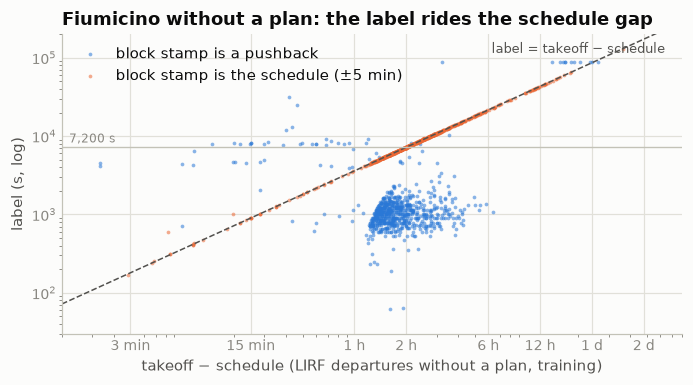

In [6]:
# 10a — raw labels, all departures (this cell deviates from TGT on purpose: the corrupt labels are the subject).
# Where the corrupt rows' two stamps sit against the schedule; the mixture at Fiumicino without a plan, by band of
# takeoff − schedule; the scope at other hubs; an honest raw-label holdout; and the candidates in the ranking file
RAWDEP = f"(SELECT *, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) gap_s, (FLIGHT_ID_mvt IS NULL) no_plan FROM {T} WHERE PHASE_mvt = 'DEP')"
BAND = ("CASE WHEN gap_s < 3600 THEN '1 · < 1 h' WHEN gap_s < 7200 THEN '2 · 1–2 h' WHEN gap_s < 6*3600 THEN '3 · 2–6 h' "
        "WHEN gap_s < 12*3600 THEN '4 · 6–12 h' ELSE '5 · > 12 h' END")
print("the corrupt labels (over 7,200 s): where the block stamp sits against the schedule, and the label against takeoff − schedule:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (ADEP_mvt = 'LIRF') lirf, count(*) FILTER (no_plan) no_plan,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_within_5min_of_sched,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 1800)/count(*), 1) pct_within_30min,
           round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.10)) resid_p10, round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.5)) resid_p50,
           round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.90)) resid_p90
    FROM {RAWDEP} WHERE TAXITIME_SEC_mvt > 7200""").df().to_string(index=False))

print("\nFiumicino departures without a plan, by band of takeoff − schedule — a mixture of two populations:")
print(con.sql(f"""
    WITH d AS (SELECT {BAND} band, gap_s, TAXITIME_SEC_mvt::DOUBLE y,
                      abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched
               FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan),
         bm AS (SELECT band, avg(y) m FROM d GROUP BY 1)
    SELECT band, count(*) n, round(100.0*count(*) FILTER (block_is_sched)/count(*), 1) pct_block_is_sched,
           count(*) FILTER (y > 7200) corrupt, round(avg(y)) mean_label, round(avg(gap_s)) mean_gap_s,
           round(sqrt(avg((y - gap_s)^2))) rmse_label_eq_gap, round(sqrt(avg((y - m)^2))) rmse_band_mean
    FROM d JOIN bm USING (band) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print("\n    the same rows where the block stamp IS the schedule (within 5 min), any band:")
print(con.sql(f"""
    SELECT {BAND} band, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_label, round(avg(gap_s)) mean_gap_s,
           round(sqrt(avg((TAXITIME_SEC_mvt - gap_s)^2))) rmse_label_eq_gap
    FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan AND abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nscope — departures with takeoff − schedule of 2 h or more, elsewhere:")
print(con.sql(f"""
    SELECT CASE WHEN ADEP_mvt = 'LIRF' THEN 'LIRF' ELSE 'other hubs' END hub, no_plan, count(*) n,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_is_sched,
           count(*) FILTER (TAXITIME_SEC_mvt > 7200) corrupt, round(avg(TAXITIME_SEC_mvt)) mean_label
    FROM {RAWDEP} WHERE gap_s >= 7200 GROUP BY 1, 2 ORDER BY 1, 2 DESC""").df().to_string(index=False))

# honest raw-label holdout: fit Jan–Oct, score Nov+Dec on ALL departures as labelled
con.sql(f"""
    CREATE OR REPLACE TABLE sch_raw AS
    SELECT ADEP_mvt hub, no_plan, TAXITIME_SEC_mvt::DOUBLE y, gap_s, {BAND} band,
           abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched, month(MVT_TIME_UTC_mvt) >= 11 is_val
    FROM {RAWDEP}""")
n_val, n_corrupt = con.sql("SELECT count(*), count(*) FILTER (y > 7200) FROM sch_raw WHERE is_val").fetchone()
print(f"\nhonest holdout on raw labels — {n_val:,} Nov+Dec departures, {n_corrupt} labelled over 7,200 s (support ≥ 30, else the coarser rung):")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM sch_raw WHERE NOT is_val GROUP BY 1),
         f AS (SELECT hub, no_plan, avg(y) m, count(*) c FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         fb AS (SELECT hub, no_plan, band, avg(y) m, count(*) c FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         -- the mixture, fitted on Jan–Oct: p = share whose block stamp is the schedule; m0 = mean label of the others
         mix AS (SELECT hub, no_plan, band, avg(block_is_sched::INT) p, avg(y) FILTER (NOT block_is_sched) m0, count(*) c
                 FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         v AS (SELECT r.*, h.m p_airport, coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) p_flag,
                      coalesce(CASE WHEN fb.c >= 30 THEN fb.m END, CASE WHEN f.c >= 30 THEN f.m END, h.m) p_band,
                      CASE WHEN r.hub = 'LIRF' AND r.no_plan AND r.gap_s >= 7200 THEN r.gap_s
                           ELSE coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) END p_rule,
                      CASE WHEN r.hub = 'LIRF' AND r.no_plan AND mix.c >= 30 THEN mix.p * r.gap_s + (1 - mix.p) * mix.m0
                           ELSE coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) END p_mix
               FROM sch_raw r JOIN h USING (hub) LEFT JOIN f USING (hub, no_plan) LEFT JOIN fb USING (hub, no_plan, band)
               LEFT JOIN mix USING (hub, no_plan, band) WHERE is_val)
    SELECT rung, round(sqrt(avg((y - p)^2)), 1) rmse_all, round(sqrt(avg((y - p)^2) FILTER (hub = 'LIRF')), 1) rmse_lirf
    FROM (SELECT 'airport' rung, y, hub, p_airport p FROM v UNION ALL SELECT '+ no-plan flag', y, hub, p_flag FROM v
          UNION ALL SELECT '+ band of takeoff − schedule', y, hub, p_band FROM v
          UNION ALL SELECT 'rule: LIRF, no plan, gap ≥ 2 h → predict the gap', y, hub, p_rule FROM v
          UNION ALL SELECT 'mixture: LIRF, no plan → p·gap + (1−p)·other mean, per band', y, hub, p_mix FROM v)
    GROUP BY 1 ORDER BY rmse_all DESC""").df().to_string(index=False))
print("\nwhere the holdout's squared error about the airport mean lives, by band:")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM sch_raw WHERE NOT is_val GROUP BY 1)
    SELECT band, count(*) n, count(*) FILTER (y > 7200) corrupt,
           round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_squared_error
    FROM sch_raw JOIN h USING (hub) WHERE is_val GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe ranking file — Fiumicino departures without a plan, by band and month:")
print(con.sql(f"""
    SELECT {BAND} band, count(*) FILTER (month(MVT_TIME_UTC_mvt) = 1) jan_2026, count(*) FILTER (month(MVT_TIME_UTC_mvt) = 7) jul_2026
    FROM (SELECT *, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) gap_s FROM {R} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LIRF' AND FLIGHT_ID_mvt IS NULL)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

pts = con.sql(f"""
    SELECT gap_s/3600.0 g, TAXITIME_SEC_mvt y, abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched
    FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan AND gap_s > 60 AND TAXITIME_SEC_mvt > 0""").df()
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for flag, c, lbl in [(False, BLUE, "block stamp is a pushback"), (True, ORANGE, "block stamp is the schedule (±5 min)")]:
    g = pts[pts.block_is_sched == flag]
    ax.scatter(g.g, g.y, s=6, color=c, alpha=0.55, lw=0, label=lbl)
xx = np.logspace(np.log10(0.02), np.log10(80), 50)
ax.plot(xx, xx * 3600, color=INK2, lw=1, ls="--")
ax.text(20, 20 * 3600 * 1.6, "label = takeoff − schedule", fontsize=8.5, color=INK2, ha="center")
ax.axhline(7200, color=BASELINE, lw=0.9)
ax.text(0.022, 7200 * 1.15, "7,200 s", fontsize=8, color=MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.02, 80); ax.set_ylim(30, 200000)
ax.set_xticks([0.05, 0.25, 1, 2, 6, 12, 24, 48], ["3 min", "15 min", "1 h", "2 h", "6 h", "12 h", "1 d", "2 d"])
ax.set_xlabel("takeoff − schedule (LIRF departures without a plan, training)")
ax.set_ylabel("label (s, log)")
ax.set_title("Fiumicino without a plan: the label rides the schedule gap")
ax.legend(loc="upper left")
style(ax, x_grid=True)
fig.tight_layout()
plt.show()


In [7]:
# what the schedule buys on the rows we model — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the
# coarser rung: (1) the hour read on the schedule vs on the takeoff; (2) the delay on top of the AOBT_3 anchor, schedule-
# based vs plan-based; (3) scheduled demand — departures and arrivals timetabled around our slot — against §8's actual window
LOCAL_S = f"timezone({TZ.replace('CASE hub', 'CASE ADEP_mvt')}, SCHED_TIME_UTC_mvt)"
con.sql(f"""
    CREATE OR REPLACE TABLE sch_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           hour({LOCAL}) h_takeoff, hour({LOCAL_S}) h_sched,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) g_sched,
           epoch(MVT_TIME_UTC_mvt - EOBT_1_flt) g_eobt1, epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) push_vs_sched,
           epoch(AOBT_3_flt - EOBT_1_flt) push_vs_plan
    FROM {TGT}""")


def sch_cat(keys):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM sch_d WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM sch_d WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM sch_d v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


def sch_ladder(*bins):
    """bins: (gap column, number of quantile bins), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins))
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" for k, (c, _) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE sch_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM sch_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM sch_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE sch_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM sch_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN sch_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN sch_r{k}.c >= 30 THEN sch_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2))
                       FROM sch_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM sch_d WHERE is_val").fetchone()[0]
print(f"(1) the hour, read on which clock? — {n_val:,} Nov+Dec departures; the two hours differ on "
      f"{con.sql('SELECT round(100.0*count(*) FILTER (h_takeoff != h_sched)/count(*), 1) FROM sch_d').fetchone()[0]}% of rows")
for name, keys in [("airport", "hub"), ("+ local hour of takeoff (§8)", "hub, h_takeoff"),
                   ("+ local hour of the schedule", "hub, h_sched"), ("+ both hours", "hub, h_takeoff, h_sched")]:
    print(f"    {name:44s} {sch_cat(keys):7.1f} s")

print("\n(2) the delay on top of the anchor — airport × 20 bins of takeoff − AOBT_3, then × 5 bins of:")
print(f"    {'anchor alone (§9)':44s} {sch_ladder(('g_aobt3', 20)):7.1f} s")
for name, col in [("takeoff − schedule", "g_sched"), ("AOBT_3 − schedule, the pushback delay", "push_vs_sched"),
                  ("AOBT_3 − EOBT_1, the delay against the plan", "push_vs_plan"), ("takeoff − EOBT_1 (§9)", "g_eobt1")]:
    print(f"    {'× ' + name:44s} {sch_ladder(('g_aobt3', 20), (col, 5)):7.1f} s")
print(f"    {'× both delays (5 × 5)':44s} {sch_ladder(('g_aobt3', 20), ('push_vs_plan', 5), ('push_vs_sched', 5)):7.1f} s")
print(f"    {'schedule alone: airport × 20 bins of takeoff − schedule':44s} {sch_ladder(('g_sched', 20)):7.1f} s")

# (3) scheduled demand: timetabled departures / arrivals around our scheduled slot, per hub, computed identically on both files
con.sql(f"""
    CREATE OR REPLACE TABLE sch_ev AS
    SELECT ds, MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph,
           MVT_TIME_UTC_mvt t, SCHED_TIME_UTC_mvt s, RUNWAY_mvt rwy, AOBT_3_flt aobt3, TAXITIME_SEC_mvt taxi
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})""")
con.sql("""
    CREATE OR REPLACE TABLE sch_win AS
    SELECT ds, id, ph,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER ws sdep_c60, sum(CASE WHEN ph = 'ARR' THEN 1 ELSE 0 END) OVER ws sarr_c60,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER wa dep_c30
    FROM sch_ev
    WINDOW ws AS (PARTITION BY ds, hub ORDER BY s RANGE BETWEEN INTERVAL 30 MINUTE PRECEDING AND INTERVAL 30 MINUTE FOLLOWING),
           wa AS (PARTITION BY ds, hub ORDER BY t RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING)""")
print("\n(3) scheduled demand — the same windows on both files (departure rows):")
print(con.sql("""
    SELECT ds, count(*) n, round(avg(sdep_c60), 1) mean_dep_scheduled_pm30, round(avg(sarr_c60), 1) mean_arr_scheduled_pm30,
           round(avg(dep_c30), 1) mean_dep_actual_pm15
    FROM sch_win WHERE ph = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
con.sql("""
    CREATE OR REPLACE TABLE sch_lad AS
    SELECT e.id, e.hub, e.rwy, e.taxi::DOUBLE y, epoch(e.t - e.aobt3) anchor, (e.t >= TIMESTAMPTZ '2025-11-01') is_val,
           w.sdep_c60, w.sarr_c60, w.dep_c30
    FROM sch_ev e JOIN sch_win w USING (ds, id)
    WHERE e.ds = 'training' AND e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600 AND e.rwy IS NOT NULL AND e.aobt3 IS NOT NULL""")
print(con.sql("""
    SELECT round(corr(sdep_c60, dep_c30), 3) corr_scheduled_vs_actual_departures, round(corr(y, sdep_c60), 3) corr_taxi_scheduled,
           round(corr(y, dep_c30), 3) corr_taxi_actual FROM sch_lad""").df().to_string(index=False))
con.sql("""
    CREATE OR REPLACE TABLE sch_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(sdep_c60, [0.2,0.4,0.6,0.8]) qs, quantile_cont(sarr_c60, [0.2,0.4,0.6,0.8]) qr,
                         quantile_cont(dep_c30, [0.2,0.4,0.6,0.8]) qd
                  FROM sch_lad WHERE NOT is_val GROUP BY 1)
    SELECT hub, rwy, y, is_val, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
           list_count(list_filter(qs, x -> x <= sdep_c60)) q_sdep, list_count(list_filter(qr, x -> x <= sarr_c60)) q_sarr,
           list_count(list_filter(qd, x -> x <= dep_c30)) q_dep
    FROM sch_lad JOIN cuts USING (hub)""")


def sch_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE sch_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM sch_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN sch_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN sch_s{i}.c >= 30 THEN sch_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM sch_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM sch_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"])]
n_val = con.sql("SELECT count(*) FROM sch_wb WHERE is_val").fetchone()[0]
print(f"\n    ladder on the {n_val:,} Nov+Dec departures with runway + anchor:")
for name, r in sch_rungs(BASE):
    print(f"    {name:52s} {r:7.1f} s")
for name, keys in [("+ departures scheduled within ±30 min of our slot", ["q_sdep"]),
                   ("+ arrivals scheduled within ±30 min of our slot", ["q_sarr"]),
                   ("+ departures actually within ±15 min of takeoff (§8)", ["q_dep"]),
                   ("+ actual ±15 min, then scheduled ±30 min on top", ["q_dep", "q_sdep"])]:
    rung = BASE + [(f"r{i}", ["hub", "rwy", "q_anc"] + keys[:i + 1]) for i in range(len(keys))]
    print(f"    {name:52s} {sch_rungs(rung)[-1][1]:7.1f} s")


(1) the hour, read on which clock? — 327,485 Nov+Dec departures; the two hours differ on 40.4% of rows
    airport                                        357.3 s
    + local hour of takeoff (§8)                   351.5 s
    + local hour of the schedule                   352.0 s
    + both hours                                   342.3 s

(2) the delay on top of the anchor — airport × 20 bins of takeoff − AOBT_3, then × 5 bins of:


    anchor alone (§9)                              293.5 s


    × takeoff − schedule                           265.3 s


    × AOBT_3 − schedule, the pushback delay        268.4 s


    × AOBT_3 − EOBT_1, the delay against the plan   257.1 s


...

    × both delays (5 × 5)                          252.0 s
    schedule alone: airport × 20 bins of takeoff − schedule   320.7 s



(3) scheduled demand — the same windows on both files (departure rows):
      ds       n  mean_dep_scheduled_pm30  mean_arr_scheduled_pm30  mean_dep_actual_pm15
training 2085047                     40.4                     33.3                  18.7
 ranking  344841                     39.7                     32.6                  18.3


 corr_scheduled_vs_actual_departures  corr_taxi_scheduled  corr_taxi_actual
                               0.822                0.073             0.098



    ladder on the 324,631 Nov+Dec departures with runway + anchor:
    airport                                                355.4 s
    + runway                                               341.8 s
    + AOBT_3 anchor                                        283.6 s
    + departures scheduled within ±30 min of our slot      280.2 s


    + arrivals scheduled within ±30 min of our slot        282.3 s
    + departures actually within ±15 min of takeoff (§8)   278.1 s
    + actual ±15 min, then scheduled ±30 min on top        278.5 s


                                               feature        kind  n / levels  pearson_r  spearman_ρ     η
                            schedule epoch — the trend     numeric     2080533      0.012       0.015      
           hour of the schedule, the hub's local clock categorical          24                        0.112
                                    takeoff − schedule     numeric     2080533      0.190       0.383      
                AOBT_3 − schedule — the pushback delay     numeric     2059401      0.101       0.150      
       departures scheduled within ±30 min of our slot     numeric     2059401      0.073       0.094      
         arrivals scheduled within ±30 min of our slot     numeric     2059401      0.060       0.099      
takeoff − schedule on raw labels, all departures (10a)     numeric     2085047      0.232       0.387      


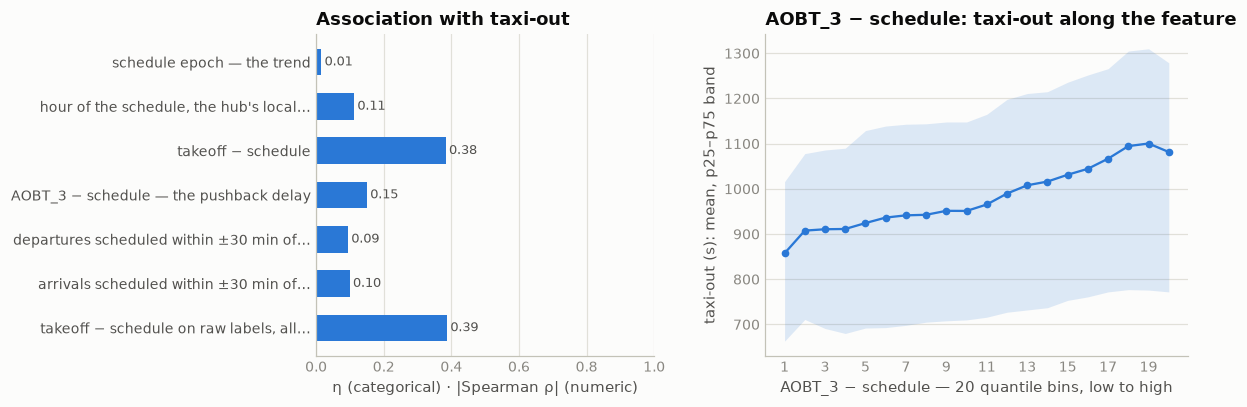

In [8]:
# correlation with the target: the stamp is a calendar; its derived forms are the gaps to takeoff and to the anchor,
# the scheduled hour, the scheduled-demand windows — and, on raw labels, the gauge of 10a
a = target_assoc([("schedule epoch — the trend", "num", "epoch(SCHED_TIME_UTC_mvt)"),
                  ("hour of the schedule, the hub's local clock", "cat", f"hour({LOCAL_S})"),
                  ("takeoff − schedule", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)"),
                  ("AOBT_3 − schedule — the pushback delay", "num", "epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)"),
                  ("departures scheduled within ±30 min of our slot", "num", "sdep_c60", 1, "sch_lad", "y"),
                  ("arrivals scheduled within ±30 min of our slot", "num", "sarr_c60", 1, "sch_lad", "y"),
                  ("takeoff − schedule on raw labels, all departures (10a)", "num", "gap_s", 1, RAWDEP)])
assoc_chart(a, "epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)", kind="num", title="AOBT_3 − schedule")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null, a whole minute, on the 5-minute grid** | zero nulls on 4,857,331 rows; 100% of departures on a multiple of 5 minutes, 99.8% of arrivals; the earliest training departure was timetabled for 31 Dec 2024 22:40 | the only clock written before the day: every difference against it is a delay |
| **On departures it is the plan's filed off-block — usually** | equal to `IOBT_flt` on 74.4% of matched departures (`LOBT_flt` 74.0%, `EOBT_1_flt` 55.5%); when they differ the plan sits *later* 88.5% of the time, by a median 20 min, and still on the 5-minute grid 82.1% of the time. Regional 81.1% equal, Cargo 65.1%, Military 52.0% | the schedule is the timetable and the filed clocks are its revisions; their difference is an early word on delay (the `IOBT`/`EOBT_1` sections) |
| Unmatched departures have one too | 22,424 rows, 98.3% on the grid, median takeoff 88 min after it | the schedule is the movement side's own field: it survives where the whole `_flt` block is missing — and those 88 minutes are §2b's delayed flights |
| On arrivals it is the scheduled *in-block* | in-block − schedule median −3.1 min (LTFM) to +3.8 (LSZH); landing − schedule −17.9 to −2.0 | not a feature (arrivals are never predicted), but the right anchor for a scheduled-arrival window |
| **Pushback delay is per hub, and a quarter of flights push early** | median off-block − schedule 3.0 min at EGLL and LTFM to 10.1 at LSZH; early pushbacks 12.3% (LSZH) to 37.3% (EGLL); over an hour late 3.3–6.9% | the timetable is kept loosely, differently at each airport |
| **Taxi-out barely moves with the delay on clean rows** | by band of pushback delay: means 954–1,039 s, medians 899–967 s; early pushbacks (1,008 s) taxi longer than punctual ones (961 s); the over-3-hours-late 1,039 s | ρ 0.15 with the pushback delay, 0.38 with takeoff − schedule (which contains the taxi itself); what the delay buys shows only on top of the anchor — the signal row below |
| **January 2026 ran later than January 2025; July earlier** | takeoff − schedule, all departures: Jan 2025 median 21.3 min, p90 57.1, 9.1% over an hour → Jan 2026 **24.7 / 71.0 / 13.5%**; Jul 2025 28.6 / 73.0 / 14.9% → Jul 2026 25.2 / 65.0 / 11.7% | computable on the ranking file, this is the first drift the sweep has seen: the scored January is a worse month than its twin. Delay features are how the model can know it; calendar features cannot |
| The far tail is cargo — and Fiumicino | 631 departures with takeoff more than 12 h from schedule: EDDF 360, EHAM 121, LFPG 39, mostly cargo, only a fifth about a day off — freighters rescheduled to a new date; LIRF's 32, of which 29 have no plan, carry a median label of **58,137 s** | the cargo rows are real flights with a stale timetable; Fiumicino's are 10a |
| **10a · the corrupt block stamp is the schedule's** | of the 584 labels over 7,200 s (480 at LIRF, 481 without a plan), the block stamp is within 5 min of the schedule on 77.1%, within 30 min on 86.8%; label − (takeoff − schedule) has p10 −780 s, **median 0**, p90 +6 s | no pushback was captured and the system wrote the timetable; the "taxi-out" is the delay, and both its ends are in the ranking file |
| **10a · Fiumicino without a plan is a mixture** | by band of takeoff − schedule, the block stamp is the schedule's on 42.9% (< 1 h), 37.6% (1–2 h), 61.5% (2–6 h), 97.1% (6–12 h), 62.1% (> 12 h); on those rows label = gap within 3–61 s RMSE (n = 48 / 281 / 347 / 33 / 18); on the others an ordinary taxi | the label is takeoff − schedule with probability p(band), else a taxi: the conditional mean the model must learn is p · gap + (1 − p) · taxi |
| **10a · Fiumicino's, and only without a plan** | gap ≥ 2 h: LIRF without a plan 627 rows, 63.5% block = schedule, 413 corrupt, mean label 11,367 s; LIRF with a plan 2,751 rows, 1.2%, 40 corrupt, 1,402 s; other hubs without a plan 4,318 rows, 0.2%, 37 corrupt, 1,314 s | the gauge is airport × no-plan × gap, a three-way interaction — not a global delay feature |
| **10a · honest holdout on raw labels** | 328,009 Nov+Dec departures, 61 over 7,200 s: airport 496.5 → + no-plan flag 475.0 → + band of takeoff − schedule 456.8 → **the rule "LIRF, no plan, gap ≥ 2 h → predict the gap" 391.4 s** (LIRF 1,290 → 597); the band-fitted mixture 460.8 | the rule takes 84 s off a group-mean ladder. It beats the fitted mixture because the rule's 58 holdout rows were 83% corrupt (48 of 58) against 62% in the fit months: p moves, and the model has to learn it from the tail — which must therefore stay in training (`VALIDATION/archive/FINDINGS_20260907.md`, §3) |
| 10a · where the error lives | the > 12 h band — 122 rows — carries 30.4% of the holdout's squared error about the airport mean; 2–12 h another 14.3% | a few hundred rows, and the schedule points at them |
| **10a · the candidates in the scored set** | LIRF departures without a plan by band, Jan + Jul 2026: 2–6 h 41 + 114, 6–12 h 8 + 7, > 12 h 3 + 8 | 181 rows over 2 h; on 2025's rates roughly 110 of them carry a label of hours, and July has the most |
| **The hour is worth more read twice** | airport 357.3 → + local hour of takeoff 351.5 (§8) · + local hour of the schedule 352.0 · **+ both 342.3 s**; the two hours differ on 40.4% of rows | the pair encodes the delay in whole hours; either alone does not |
| **The plan's delay beats the schedule's** | on airport × 20 bins of takeoff − `AOBT_3` (293.5): × takeoff − schedule 265.3 · × `AOBT_3` − schedule 268.4 · × `AOBT_3` − `EOBT_1` **257.1** · × takeoff − `EOBT_1` 252.4 (§9) · × both delays 252.0 | the plan is refiled towards reality, the schedule is not; the schedule's delay adds 0.4 s on top of the plan's — but it is never missing, which the plan's is on 1.53% of predictions |
| Scheduled demand adds nothing over the actual window | departures scheduled within ±30 min of our slot correlate 0.822 with §8's actual count; on the runway × anchor ladder (283.6) they take it to 280.2, the actual count to 278.1, both to 278.5; scheduled arrivals 282.3 | at prediction time the actual takeoffs are known, and they are the better count |

**Decisions**

| issue | decision | why |
|---|---|---|
| the corrupt Fiumicino rows | **no repair, no removal**: keep them in training and give the model takeoff − schedule, the no-plan flag and the airport, so it learns the gauge; test it in the harness as an explicit rule too | the score uses the label as delivered, and the gauge is the only thing in the file that predicts it |
| the schedule's delay vs the plan's | keep both | the plan's is 11 s better on the anchor ladder; the schedule's is never missing |
| scheduled-demand windows | not a feature | a weaker copy of the actual window, nothing on top of it |
| the hour | read it on both clocks | 342.3 against 351.5 s |

**State after §10** — unchanged: never null, nothing repaired.

**Use in modeling.** (1) Takeoff − schedule and `AOBT_3` − schedule, per airport — the pipeline
builds the first already. (2) **The gauge**: airport × no-plan × takeoff − schedule, with the
tail kept in training, is the largest lever this sweep has found; the harness should measure it
as a feature and as a rule, and `VALIDATION/archive/FINDINGS_20260907.md`'s break-even logic applies to how much of
2025's corruption 2026 carries. (3) Local hour on both clocks. (4) No scheduled-demand windows.
In the closing matrix the column enters as epoch seconds, the third copy of the clock: 1.00 with the
takeoff and off-block stamps, 0.01 with the target — everything it knows is in its differences.


## 11 · `AIRCRAFT_TYPE_mvt` — what is taxiing

The ICAO type designator of the aircraft — `A320`, `B738`, `B77W` — as the airport recorded it;
the flight plan carries its own copy in `AIRCRAFT_TYPE_flt`. It says how big the aircraft is,
whether it is a helicopter, and — through the fleet an airline flies on a route — a good deal about
who is flying where. This section settles what the code is worth on its own, what it carries beyond
itself, and what to do with the few rows that lack it.

| step | question | what came out |
|---|---|---|
| **census** | present where; who lacks it; does the plan's copy agree? | null on 0.07% of departures — and those are Fiumicino's plan-less departures, 10a's slice by another name; 99.66% agreement with the plan, and the disagreements are variants of one type |
| **cardinality** | how many types matter; does 2026 bring new ones? | 269 types; 24 of them are nine departures in ten, in 2026 as in 2025; 18 rows of 8 unseen types |
| **what the type carries** | the wake-turbulence class, and rotorcraft | one class per type, which fills 91% of the plan's missing classes; §4a's rotorcraft list gains ten codes |
| **signal** | the type on top of the airport and on top of runway × anchor; the coarser forms | 19 s on the airport, 9 s on the anchor base; the raw code beats its class; the plan's copy is no better |
| **11a · the disagreements** | which side is right, and does the choice matter? | mostly per-hub spellings of one aircraft; one of them changed in November 2025, so the plan's code comes first |


In [4]:
# census by file × phase; the rows without a type — who they are; and the movement's type against the plan's
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("AIRCRAFT_TYPE_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) n_null,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT AIRCRAFT_TYPE_mvt) n_types,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL)/count(*), 2) pct_plan_type_null,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = AIRCRAFT_TYPE_flt)/count(AIRCRAFT_TYPE_flt), 2) pct_agree_with_plan
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows without a type — by file, phase and hub; whether a plan was matched, and whether the plan has a type:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, count(*) n,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_matched, count(AIRCRAFT_TYPE_flt) plan_type_present,
           mode(FLIGHT_RULE_mvt) rule_, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt IS NULL GROUP BY 1, 2, 3 ORDER BY 1 DESC, 2, n DESC""").df().to_string(index=False))

print("\nno type ⇔ no plan, at Fiumicino — departures, both files:")
print(con.sql(f"""
    SELECT src, CASE WHEN ADEP_mvt = 'LIRF' THEN 'LIRF' ELSE 'other hubs' END hub,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND AIRCRAFT_TYPE_mvt IS NULL) no_plan_no_type,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL) no_plan_with_type,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NULL) plan_no_type
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe label on the type-less departures (training, raw labels) — 10a's slice by another name:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200s,
           round(100.0*count(*) FILTER (TAXITIME_SEC_mvt > 7200)/count(*), 1) pct_over_7200s,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, round(avg(TAXITIME_SEC_mvt)) mean_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NULL""").df().to_string(index=False))

print("\nmovement type vs plan type — the disagreements are variants (matched training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n,
           round(100.0*count(*)/sum(count(*)) OVER (), 1) pct_of_disagreements
    FROM {TGT} WHERE AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, count(*) n,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct_disagree
    FROM {TGT} WHERE AIRCRAFT_TYPE_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))


AIRCRAFT_TYPE_mvt by file × phase:
     src  ph       n  n_null  pct_null  n_types  pct_plan_type_null  pct_agree_with_plan
training ARR 2082750     142      0.01      267                0.74                99.67
training DEP 2085047    1507      0.07      269                1.08                99.66
 ranking ARR  344693      21      0.01      196                0.74                99.83
 ranking DEP  344841     388      0.11      199                1.53                99.82

the rows without a type — by file, phase and hub; whether a plan was matched, and whether the plan has a type:
     src  ph  hub    n  n_matched  plan_type_present rule_  med_label
training ARR LIRF  125          0                  0     I      602.0
training ARR LTFM    7          0                  0     I      177.0
training ARR LFPG    3          0                  0     I        5.0
training ARR LEMD    3          0                  0     I      823.0
training ARR LSZH    2          0                  0     V

the 24 most frequent types — nine departures in ten:


 typ      n   pct  cum_pct wake  mean_taxi  med_taxi
A320 342417 16.46     16.5    M      927.0     844.0
B738 218118 10.49     27.0    M      970.0     942.0
A20N 169539  8.15     35.1    M     1011.0     948.0
A321 162020  7.79     42.9    M      909.0     843.0
A21N 148807  7.15     50.0    M     1055.0    1000.0
A319 134517  6.47     56.5    M      934.0     849.0
E190  78811  3.79     60.3    M      804.0     758.0
BCS3  77264  3.72     64.0    M      940.0     896.0
B77W  67033  3.22     67.2    H     1190.0    1132.0
B789  61183  2.94     70.2    H     1212.0    1152.0
A359  56274  2.71     72.9    H     1122.0    1029.0
A333  47001  2.26     75.2    H     1095.0    1018.0
B38M  45165  2.17     77.3    M     1137.0    1098.0
B772  33905  1.63     79.0    H     1260.0    1208.0
A332  31895  1.53     80.5    H     1085.0    1016.0
CRJX  30017  1.44     81.9    M      815.0     800.0
E195  28833  1.39     83.3    M      778.0     728.0
E295  27068  1.30     84.6    M      784.0    

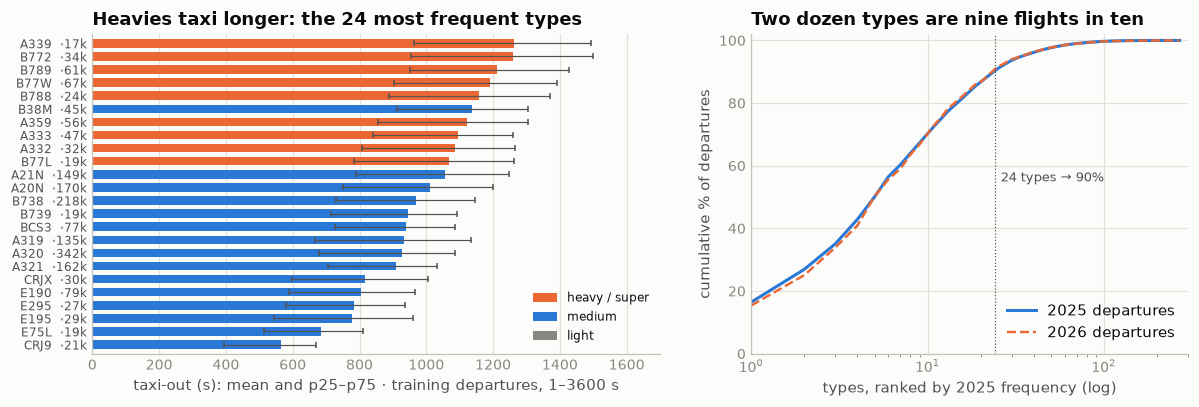

In [5]:
# how many types matter, whether 2026 brings new ones, and taxi-out by type (training departures, 1–3600 s)
print("the 24 most frequent types — nine departures in ten:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(100.0*sum(count(*)) OVER (ORDER BY count(*) DESC, AIRCRAFT_TYPE_mvt)/sum(count(*)) OVER (), 1) cum_pct,
           mode(WK_TBL_CAT_flt) wake, round(avg(TAXITIME_SEC_mvt)) mean_taxi, quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {TGT} WHERE AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 24""").df().to_string(index=False))

print("\ncoverage — types ranked by 2025 frequency, cumulative share of departures, 2025 vs 2026:")
print(con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1),
         rk AS (SELECT typ, row_number() OVER (ORDER BY n DESC, typ) rk FROM c),
         r AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1)
    SELECT k top_types, round(100.0*(SELECT sum(c.n) FROM c JOIN rk USING (typ) WHERE rk.rk <= k)/(SELECT sum(n) FROM c), 1) pct_2025,
           round(100.0*(SELECT sum(r.n) FROM r JOIN rk USING (typ) WHERE rk.rk <= k)/(SELECT sum(n) FROM r), 1) pct_2026
    FROM (VALUES (5), (10), (24), (50), (71), (100), (270)) v(k) ORDER BY k""").df().to_string(index=False))

print("\n2026 departures whose type is new, or rare in 2025:")
print(con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT count(*) FILTER (c.typ IS NULL) rows_of_unseen_types, count(DISTINCT r.AIRCRAFT_TYPE_mvt) FILTER (c.typ IS NULL) unseen_types,
           string_agg(DISTINCT r.AIRCRAFT_TYPE_mvt, ' ') FILTER (c.typ IS NULL) unseen_list,
           count(*) FILTER (c.n < 30) rows_of_types_under_30_in_2025,
           count(*) FILTER (c.n < 200) rows_of_types_under_200_in_2025
    FROM {R} r LEFT JOIN c ON c.typ = r.AIRCRAFT_TYPE_mvt WHERE r.PHASE_mvt = 'DEP' AND r.AIRCRAFT_TYPE_mvt IS NOT NULL""").df().to_string(index=False))

top = con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, mode(WK_TBL_CAT_flt) wake, avg(TAXITIME_SEC_mvt) m,
           quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM {TGT} WHERE AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 24""").df().sort_values("m")
cov = con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1),
         rk AS (SELECT typ, n, row_number() OVER (ORDER BY n DESC, typ) rk FROM c),
         r AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1)
    SELECT rk.rk, 100.0*sum(rk.n) OVER (ORDER BY rk.rk)/(SELECT sum(n) FROM c) pct_2025,
           100.0*sum(coalesce(r.n, 0)) OVER (ORDER BY rk.rk)/(SELECT sum(n) FROM r) pct_2026
    FROM rk LEFT JOIN r USING (typ) ORDER BY rk.rk""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
col = {"H": ORANGE, "J": ORANGE, "M": BLUE, "L": MUTED}
yy = np.arange(len(top))
a1.barh(yy, top.m, height=0.65, color=[col.get(w, BASELINE) for w in top.wake])
a1.errorbar(top.m, yy, xerr=[top.m - top.p25, top.p75 - top.m], fmt="none", ecolor=INK2, elinewidth=0.8, capsize=2)
a1.set_yticks(yy, [f"{t}  ·{n/1000:.0f}k" for t, n in zip(top.typ, top.n)], fontsize=8, color=INK2)
a1.set_xlim(0, 1700)
a1.set_title("Heavies taxi longer: the 24 most frequent types")
a1.set_xlabel("taxi-out (s): mean and p25–p75 · training departures, 1–3600 s")
for w, lbl in [("H", "heavy / super"), ("M", "medium"), ("L", "light")]:
    a1.barh([-10], [0], color=col[w], label=lbl)
a1.set_ylim(-0.7, len(top) - 0.3)
a1.legend(loc="lower right", fontsize=8)
style(a1, x_grid=True, y_grid=False)
a2.plot(cov.rk, cov.pct_2025, color=BLUE, lw=2, label="2025 departures")
a2.plot(cov.rk, cov.pct_2026, color=ORANGE, lw=1.6, ls="--", label="2026 departures")
a2.set_xscale("log")
a2.axvline(24, color=INK2, lw=0.8, ls=":")
a2.text(26, 55, "24 types → 90%", fontsize=8.5, color=INK2)
a2.set_xlim(1, 300)
a2.set_ylim(0, 102)
a2.set_title("Two dozen types are nine flights in ten")
a2.set_xlabel("types, ranked by 2025 frequency (log)")
a2.set_ylabel("cumulative % of departures")
a2.legend(loc="lower right")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# two things the type carries beyond itself: the wake-turbulence class (a lookup that fills the plan's missing category)
# and rotorcraft (§4a's list, completed by a systematic search of the codes)
con.sql(f"""
    CREATE OR REPLACE TABLE typ_wake AS
    SELECT typ, arg_max(wk, n) wake_from_type, max(n)/sum(n) purity, sum(n) n
    FROM (SELECT AIRCRAFT_TYPE_mvt typ, WK_TBL_CAT_flt wk, count(*) n FROM {T}
          WHERE PHASE_mvt = 'DEP' AND WK_TBL_CAT_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1, 2)
    GROUP BY 1""")
print("wake class from the type — one class per type, learned from 2025 departures with a plan:")
print(con.sql("""
    SELECT count(*) n_types, count(*) FILTER (purity < 0.98) impure_types, round(100.0*sum(n) FILTER (purity >= 0.98)/sum(n), 2) pct_rows_in_pure_types,
           string_agg(typ || ' ' || round(100*purity) || '%', ', ') FILTER (purity < 0.98) impure_list
    FROM typ_wake""").df().to_string(index=False))
print(con.sql(f"""
    SELECT src, count(*) departures, count(*) FILTER (WK_TBL_CAT_flt IS NULL) plan_wake_null,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL AND l.wake_from_type IS NOT NULL) filled_from_type,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL AND l.wake_from_type IS NULL) still_null,
           round(100.0*count(*) FILTER (l.wake_from_type = WK_TBL_CAT_flt)/count(*) FILTER (WK_TBL_CAT_flt IS NOT NULL AND l.wake_from_type IS NOT NULL), 2) pct_agree_where_both
    FROM {BOTH} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
print("\nwake class and taxi-out, plan's class where present else the type's (training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(WK_TBL_CAT_flt, l.wake_from_type, '∅') wake, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(avg(TAXITIME_SEC_mvt)) mean_taxi, quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {TGT} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

# rotorcraft: every ICAO rotorcraft designator we could name, checked against the data; the ones present join §4a's list
CANDIDATES = ("('A119','A129','A149','AS55','AS65','B105','B212','B222','B412','B427','B430','B47G','B47T','EC25','EC30','EC75',"
              "'H135','H175','H225','H500','H53','H60','H64','R22','R66','S64','S65','MD52','MD60','AS3B','G2CA','A2RT','CH7A',"
              "'K126','KA32','MI8','MI17','MI2','UH1','UH60','S70','BK17','EXPL','ALO2','ALO3','GAZL','HUCO','S330','RVAL')")
print("\nrotorcraft codes present in the data beyond §4a's list (both files, both phases):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') dep,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (PHASE_mvt = 'DEP')) med_taxi_out,
           mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, mode(FLIGHT_RULE_mvt) rule_,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) rule_null
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt IN {CANDIDATES} AND AIRCRAFT_TYPE_mvt NOT IN {HELI_ALL}
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
ROTORCRAFT = HELI_ALL[:-1] + ",'EC30','G2CA','R66','R22','AS55','GAZL','AS65','A119','H53','H60')"
# and the form 11a settles on, defined here so every cell that reads it sits below it
TYPE_FINAL = "coalesce(AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt)"
print("\nrotorcraft (the completed list) per hub — training departures, raw labels:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.9)) p90,
           round(100.0*count(*) FILTER (FLIGHT_RULE_mvt = 'V')/count(*), 1) pct_vfr, mode(RUNWAY_mvt) rwy
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IN {ROTORCRAFT} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
print("\nand the one generic code:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') dep, mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt = 'ZZZZ' GROUP BY 1""").df().to_string(index=False))


wake class from the type — one class per type, learned from 2025 departures with a plan:
 n_types  impure_types  pct_rows_in_pure_types                                  impure_list
     238             4                   99.99 B350 93.0%, SW3 75.0%, SW4 94.0%, ZZZZ 59.0%
     src  departures  plan_wake_null  filled_from_type  still_null  pct_agree_where_both
training     2085047           22544             20490        2054                 99.99
 ranking      344841            5304              4810         494                 99.99

wake class and taxi-out, plan's class where present else the type's (training departures, 1–3600 s):
wake       n   pct  mean_taxi  med_taxi
   M 1628202 78.26      932.0     878.0
   H  424128 20.39     1166.0    1090.0
   J   14768  0.71     1404.0    1327.0
   L   12275  0.59      652.0     552.0
   ∅    1160  0.06      868.0     850.5

rotorcraft codes present in the data beyond §4a's list (both files, both phases):
 typ  n  dep  med_taxi_out  hub rul

In [7]:
# what the type buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung:
# on top of the airport; on top of airport × runway × AOBT_3 anchor (§9's base); and the coarser forms as fallbacks
con.sql(f"""
    CREATE OR REPLACE TABLE typ_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, AIRCRAFT_TYPE_mvt typ, AIRCRAFT_TYPE_flt typ_plan,
           coalesce(WK_TBL_CAT_flt, l.wake_from_type) wake, (AIRCRAFT_TYPE_mvt IN {ROTORCRAFT}) rotor,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM {TGT} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt""")


def typ_cat(keys):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM typ_d WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM typ_d WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM typ_d v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM typ_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures:")
for name, keys in [("airport", "hub"), ("+ type (movement)", "hub, typ"), ("+ type (plan; missing = own level)", "hub, typ_plan"),
                   ("+ wake class", "hub, wake"), ("+ rotorcraft flag", "hub, rotor"), ("+ wake class, then type on top", "hub, wake, typ")]:
    print(f"    {name:40s} {typ_cat(keys):7.1f} s")

con.sql("""
    CREATE OR REPLACE TABLE typ_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa FROM typ_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT typ_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM typ_d JOIN cuts USING (hub)
    WHERE rwy IS NOT NULL AND anchor IS NOT NULL""")


def typ_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE typ_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM typ_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN typ_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN typ_s{i}.c >= 30 THEN typ_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM typ_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM typ_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"])]
n_val = con.sql("SELECT count(*) FROM typ_wb WHERE is_val").fetchone()[0]
print(f"\n(2) on top of airport × runway × anchor — the {n_val:,} Nov+Dec departures with runway and anchor (§9's base):")
for name, r in typ_rungs(BASE):
    print(f"    {name:40s} {r:7.1f} s")
for name, keys in [("+ type", ["typ"]), ("+ wake class", ["wake"]), ("+ wake class, then type on top", ["wake", "typ"])]:
    rung = BASE + [(f"r{i}", ["hub", "rwy", "q_anc"] + keys[:i + 1]) for i in range(len(keys))]
    print(f"    {name:40s} {typ_rungs(rung)[-1][1]:7.1f} s")

print("\nthe same type, different hubs — median taxi-out of two workhorses and one heavy (training, 1–3600 s):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'A320')) a320,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'B738')) b738,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'B77W')) b77w,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) all_types
    FROM {TGT} GROUP BY 1 ORDER BY all_types""").df().to_string(index=False))


(1) on top of the airport mean — 327,485 Nov+Dec departures:
    airport                                    357.3 s
    + type (movement)                          338.0 s
    + type (plan; missing = own level)         338.5 s
    + wake class                               347.3 s
    + rotorcraft flag                          357.1 s
    + wake class, then type on top             338.0 s



(2) on top of airport × runway × anchor — the 324,631 Nov+Dec departures with runway and anchor (§9's base):
    airport                                    355.4 s
    + runway                                   341.8 s
    + AOBT_3 anchor                            283.6 s
    + type                                     274.5 s


    + wake class                               279.0 s
    + wake class, then type on top             273.4 s

the same type, different hubs — median taxi-out of two workhorses and one heavy (training, 1–3600 s):
 hub   a320   b738   b77w  all_types
LSZH  703.0  733.0  880.0      712.0
EHAM  752.0  686.0  881.0      742.0
EDDM  769.0  834.0  900.0      774.0
EDDF  742.0  987.0 1023.0      837.0
LEBL  797.0 1099.0 1000.0      906.0
LFPG  845.0  957.0 1081.0      954.0
LTFM  901.0  911.0 1073.0      963.0
LEMD  905.0 1031.0  961.0      985.0
LIRF  962.0  964.0 1251.0     1022.0
EGLL 1311.0 1255.0 1381.0     1319.0


In [8]:
# closing state — the column after §11: nothing filled. The plan's type is never there when the movement's is missing,
# and the missing type is a marker in its own right (10a's slice), so the null stays
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) type_null_before,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt) IS NULL) type_null_after_coalesce,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL) wake_null_before,
           count(*) FILTER (coalesce(WK_TBL_CAT_flt, l.wake_from_type) IS NULL) wake_null_after_lookup
    FROM {BOTH} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\ntype: before = after on every count. Wake class: the type's lookup fills the plan's gaps (a derived form, not a repair of this column)")


     src  ph       n  type_null_before  type_null_after_coalesce  wake_null_before  wake_null_after_lookup
training ARR 2082750               142                       142             15516                     679
training DEP 2085047              1507                      1507             22544                    2054
 ranking ARR  344693                21                        21              2564                     125
 ranking DEP  344841               388                       388              5304                     494

type: before = after on every count. Wake class: the type's lookup fills the plan's gaps (a derived form, not a repair of this column)


                                                feature        kind  n / levels  pearson_r  spearman_ρ     η
                           aircraft type — the raw code categorical         150                        0.359
                                        the plan's type categorical         142                        0.353
type — the plan's code first, else the movement's (11a) categorical         149                        0.359
                                wake class — the plan's categorical           5                        0.263
            wake class — plan's, else the type's lookup categorical           5                        0.267
                                          is rotorcraft categorical           3                        0.051
                                           type missing categorical           2                        0.004
                           type disagrees with the plan categorical           3                        0.010


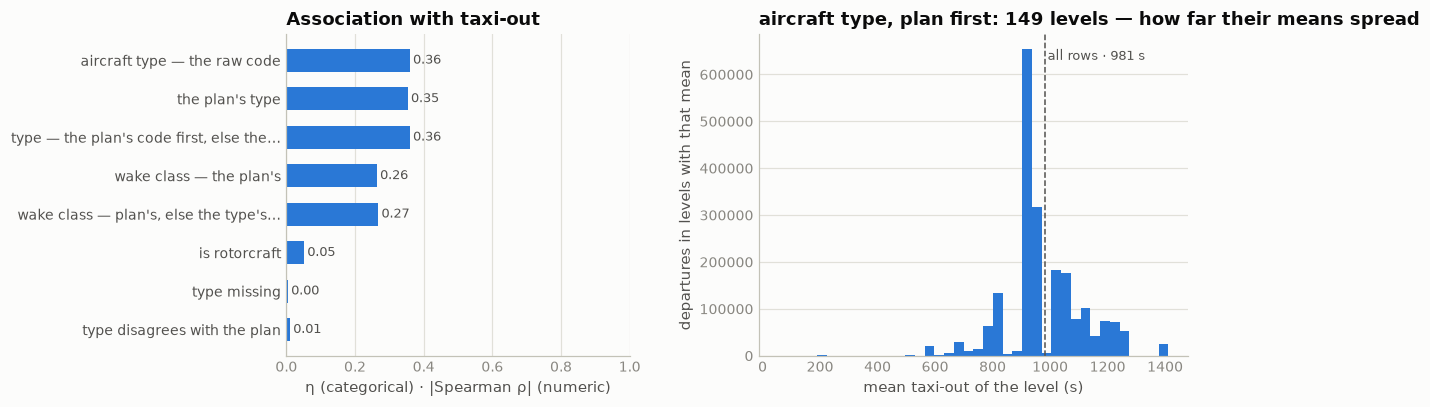

In [8]:
# correlation with the target: the raw code, the plan's code, 11a's final form, the two wake classes, the rotorcraft flag,
# and the two flags a missing or disagreeing type raises
a = target_assoc([("aircraft type — the raw code", "cat", "AIRCRAFT_TYPE_mvt", 30),
                  ("the plan's type", "cat", "AIRCRAFT_TYPE_flt", 30),
                  ("type — the plan's code first, else the movement's (11a)", "cat", TYPE_FINAL, 30),
                  ("wake class — the plan's", "cat", "WK_TBL_CAT_flt"),
                  ("wake class — plan's, else the type's lookup", "cat", "coalesce(WK_TBL_CAT_flt, l.wake_from_type)", 1,
                   f"({TGT[1:-1]}) d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt"),
                  ("is rotorcraft", "cat", f"AIRCRAFT_TYPE_mvt IN {ROTORCRAFT}"),
                  ("type missing", "cat", "AIRCRAFT_TYPE_mvt IS NULL"),
                  ("type disagrees with the plan", "cat", "AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt")])
assoc_chart(a, TYPE_FINAL, kind="cat", min_support=30, title="aircraft type, plan first")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present on all but 0.07% of departures — and the missing ones are one slice** | 1,507 training departures without a type, 1,487 of them at LIRF; 388 in the ranking file, 383 at LIRF. Every one lacks a plan, and no plan-less Fiumicino departure has a type (1,487 / 0 / 0 in training, 383 / 0 / 0 in ranking), while elsewhere 20,917 plan-less departures do. Their labels: median 3,953 s, 29.1% over 7,200 s | a missing type at Fiumicino *is* 10a's corrupt slice, in one column. The null stays: a tree branches on it |
| **The plan's copy agrees 99.66% of the time; the disagreements are variants** | B772 vs B77L 40.8% of them, AT72 vs AT76 20.0%, E75S vs E170 8.4%; by segment cargo 4.57%, non-scheduled 4.03%, mainline 0.12% | the first reading here was to keep the movement's, the two being worth the same on the ladder (338.5 vs 338.0 s). 11a sorts the disagreements: three quarters are per-hub spellings, and Schiphol's changed in November 2025 — so the final form takes the plan's code first |
| **Two dozen types are nine departures in ten** | 269 types; 5 cover 50.0%, 24 cover 90.3%, 71 cover 99.1% — and 2026 to the decimal (90.8% / 99.0%); 18 rows of 8 unseen types, 141 rows of types with under 30 departures in 2025 | the code works as a native categorical; the tail that needs a fallback is a few hundred rows |
| **Heavies taxi four minutes longer than mediums; lights half as long** | medians by wake class: M 878 s, H 1,090, J 1,327, L 552; among the top 24 types, CRJ9 535 s to A339 1,201 | size is the type's first signal — long-haul stands sit far from the runway, and heavies need the long one |
| **The hub still dominates the type** | A320 median 703 s at LSZH, 1,311 at EGLL; B77W 880 to 1,381; the hubs' own medians 712 to 1,319 | the type is a within-airport adjustment: airport × type, never type alone |
| **The type buys 19 s on the airport and 9 s on the anchor base — the raw code, not its class** | airport 357.3 → + type **338.0**, + wake class 347.3, + rotorcraft flag 357.1; runway × anchor 283.6 → + type **274.5**, + wake class 279.0, class then type 273.4 | the ladder's third-largest step after the anchor and the runway; the class carries half of it, the code the rest |
| **One wake class per type — and it fills the plan's gaps** | 238 types with a class, 4 impure (`B350`, `SW3`, `SW4`, `ZZZZ`); the lookup agrees with the plan 99.99% where both exist; it fills 20,490 of the 22,544 missing classes on training departures and 4,810 of 5,304 in ranking, leaving the type-less rows (2,054 / 494) | a derived form for the wake-category section, not a repair of this column |
| **§4a's rotorcraft list missed ten codes** | `EC30` 64 rows, `G2CA` 14, `R66` 12, `R22` 10, `AS55`, `A119`, `H53` 4 each, `GAZL`, `AS65`, `H60` 2 each — 118 rows, 59 departures, two of them without a rule. The completed list per hub: EHAM 1,028 departures (median 177 s, off runway 22), LSZH 397 (median 1 s, off helipad `H`), EDDM 24 (419 s) | `ROTORCRAFT`, defined here, supersedes `HELI_ALL` from this section on; §4a's counts stand as written |
| One generic code | `ZZZZ`: 67 rows, 31 departures, at LFPG, median label 569 s, 3 without a plan | a real aircraft of undeclared type; its own level, not a null |

**Decisions**

| issue | decision | why |
|---|---|---|
| the missing type | **left null** | it marks 10a's slice, and the plan's copy never exists where it is missing |
| the plan's copy | **first, where it exists** — `TYPE_FINAL` (11a); the movement's where there is no plan | Schiphol changed its spelling of the 777 freighter in November 2025 and 2026 follows the plan's; elsewhere the two are equal |
| coarser forms | the raw code is the feature; the wake class is a derived form for its own section | class then code beats code alone by 1.1 s |
| the rotorcraft list | `ROTORCRAFT` = `HELI_ALL` + the ten codes found here | the systematic search over every rotorcraft designator we could name |
| `ZZZZ` | its own level | a real aircraft, a normal taxi |

**State after §11** — unchanged: 1,507 / 388 departures without a type before and after; nothing repaired.

**Use in modeling.** The type as `TYPE_FINAL` (11a), a native categorical, per airport, with the
null kept as a level. Rare codes fall back to the wake class of the type's lookup; unseen
codes to the airport. The rotorcraft × airport flag of §4 is built from `ROTORCRAFT`. In the closing
matrix the column enters as `TYPE_FINAL`, rare codes pooled below 200 rows: 0.70 with the flight number (a fleet
is an airline), 0.49 with the rule, 0.36 with the target.


### 11a · When the movement and the plan disagree on the type

Two records of one aircraft: the airport's, `AIRCRAFT_TYPE_mvt`, and the operator's filing,
`AIRCRAFT_TYPE_flt`. They differ on 7,013 training departures — 0.34% of the matched ones. §11
took the movement's code on the grounds that the two are worth the same on the ladder. This
sub-section asks what the disagreements are, which side is right, and whether the choice matters
anywhere. It does, in one place, and that place reverses §11's decision.

| what a disagreement can be | how to tell |
|---|---|
| an **airport convention** — one hub writes a sibling or generic code for every flight the plan files as X | the same plan code at other hubs: one hub near 100%, the rest at 0 |
| a **swap** — a different variant flew than was filed | many operators, no hub pattern, each side true to its own history |
| a **stale plan** — one number filed all year with a type it does not fly | one operator, one number, the airport's code consistent everywhere else |


In [6]:
# 11a — the departures whose movement type and plan type differ: what kind of difference, where, and how often
DIS = (f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL "
       f"AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)")
print("what kind of difference (training departures, raw labels):")
print(con.sql(f"""
    SELECT count(*) n,
           count(*) FILTER (substr(AIRCRAFT_TYPE_mvt, 1, 1) = substr(AIRCRAFT_TYPE_flt, 1, 1)) same_maker_letter,
           count(*) FILTER (substr(AIRCRAFT_TYPE_mvt, 1, 3) = substr(AIRCRAFT_TYPE_flt, 1, 3)) same_first_three,
           count(*) FILTER (lm.wake_from_type = lp.wake_from_type) same_wake_class,
           count(*) FILTER (lm.wake_from_type != lp.wake_from_type) wake_class_differs
    FROM {DIS} d LEFT JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt LEFT JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt""").df().to_string(index=False))
print("    the pairs that change the wake class, most frequent first:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt || '→' || AIRCRAFT_TYPE_flt pair, lm.wake_from_type || '→' || lp.wake_from_type wake, count(*) n, mode(ADEP_mvt) hub
    FROM {DIS} d JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt
    WHERE lm.wake_from_type != lp.wake_from_type GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nthe ten most frequent pairs — where, whose, and the wake class of each code:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n, arg_max(ADEP_mvt, c_hub) hub,
           round(100.0*max(c_hub)/count(*)) pct_at_that_hub,
           count(DISTINCT AIRCRAFT_OPERATOR_flt) n_operators, round(100.0*max(c_op)/count(*)) pct_top_operator,
           mode(MARKET_SEGMENT_flt) segment, any_value(lm.wake_from_type) wake_movement, any_value(lp.wake_from_type) wake_plan
    FROM (SELECT *, count(*) OVER (PARTITION BY AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, AIRCRAFT_OPERATOR_flt) c_op,
                    count(*) OVER (PARTITION BY AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, ADEP_mvt) c_hub FROM {DIS}) d
    LEFT JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt LEFT JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

print("\nby hub — rate among matched departures, and the pair that dominates there:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) n_differ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct,
           arg_max(pair, c) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) top_pair
    FROM (SELECT ADEP_mvt, AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt || '→' || AIRCRAFT_TYPE_flt pair,
                 count(*) OVER (PARTITION BY ADEP_mvt, AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt) c
          FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL)
    GROUP BY 1 ORDER BY pct DESC""").df().to_string(index=False))

print("\nrate by month in training, and in the ranking file:")
print(con.sql(f"""
    SELECT yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) n_differ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct
    FROM (SELECT 2025 yr, * FROM {T} UNION ALL SELECT 2026, * FROM {R})
    WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nSchiphol's B772→B77L by month — a convention that ended:")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (AIRCRAFT_TYPE_mvt = 'B772') recorded_b772,
           count(*) FILTER (AIRCRAFT_TYPE_mvt = 'B77L') recorded_b77l
    FROM (SELECT * FROM {T} UNION ALL SELECT * FROM {R}) WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND AIRCRAFT_TYPE_flt = 'B77L'
    GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nthe other conventions in the ranking file — plan code → share the movement side still records as the first code:")
print(pd.DataFrame([(hub, f"{m}→{p}", *con.sql(f"""SELECT count(*), round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = '{m}')/count(*)) FROM {R}
                                                     WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = '{hub}' AND AIRCRAFT_TYPE_flt = '{p}'""").fetchone())
                    for hub, m, p in [("EHAM", "B772", "B77L"), ("LFPG", "AT72", "AT76"), ("EGLL", "AT72", "AT76"), ("EDDF", "E75S", "E170"), ("LFPG", "E195", "E295")]],
                   columns=["hub", "pair", "plan_rows_2026", "pct_still_recorded_as_first"]).to_string(index=False))
print("\nthe ranking file's pairs:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n, mode(ADEP_mvt) hub
    FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))


what kind of difference (training departures, raw labels):
   n  same_maker_letter  same_first_three  same_wake_class  wake_class_differs
7013               6771              4846             6713                 288
    the pairs that change the wake class, most frequent first:
     pair wake   n  hub
B763→B738  H→M 199 LFPG
A321→A332  M→H   8 EDDF
C25C→C25M  M→L   6 LSZH
B738→A332  M→H   6 LTFM
C25A→C56X  L→M   4 LTFM
A321→A359  M→H   3 EGLL

the ten most frequent pairs — where, whose, and the wake class of each code:


movement plan    n  hub  pct_at_that_hub  n_operators  pct_top_operator       segment wake_movement wake_plan
    B772 B77L 2855 EHAM             99.0           17              29.0         Cargo             H         H
    AT72 AT76 1403 LFPG             74.0            7              38.0         Cargo             M         M
    E75S E170  588 EDDF            100.0            3              84.0      Regional             M         M
    B763 B738  199 LFPG            100.0            1             100.0      Mainline             H         M
    A320 A20N  159 LFPG             53.0           23              47.0       Lowcost             M         M
    AT72 AT75  136 LFPG             98.0            3              71.0 Non-Scheduled             M         M
    E195 E295  113 LFPG             93.0            3              92.0      Mainline             M         M
    A20N A320  102 LFPG             73.0           15              67.0       Lowcost             M         M
    B738 B

 hub  n_differ  pct  top_pair
EHAM      3093 1.27 B772→B77L
LFPG      2264 0.96 AT72→AT76
EDDF       674 0.30 E75S→E170
EGLL       410 0.17 AT72→AT76
LTFM       333 0.12 A320→A20N
LSZH       147 0.11 S22T→SR22
EDDM        67 0.04 E195→E190
LEBL        13 0.01 A20N→A320
LEMD        12 0.01 A320→A20N
LIRF         0 0.00       NaN

rate by month in training, and in the ranking file:
yr          2025                                                                                          2026        
mon           1       2       3       4       5       6       7       8       9       10     11      12     1       7 
n_differ  527.00  519.00  607.00  616.00  650.00  671.00  707.00  641.00  635.00  650.00  483.0  307.00  300.0  312.00
pct         0.35    0.36    0.37    0.35    0.35    0.37    0.38    0.34    0.35    0.35    0.3    0.19    0.2    0.16

Schiphol's B772→B77L by month — a convention that ended:


yr            2025                                                        2026     
mon             1    2    3    4    5    6    7    8    9    10   11   12   1    7 
recorded_b772  268  244  283  271  282  255  258  262  256  301  157    0    0    0
recorded_b77l    1    1   20    0    3    0    0    0    0    1  127  311  300  322

the other conventions in the ranking file — plan code → share the movement side still records as the first code:
 hub      pair  plan_rows_2026  pct_still_recorded_as_first
EHAM B772→B77L             622                          0.0
LFPG AT72→AT76             187                        100.0
EGLL AT72→AT76              71                        100.0
EDDF E75S→E170              55                        100.0
LFPG E195→E295              12                         58.0

the ranking file's pairs:
movement plan   n  hub
    AT72 AT76 262 LFPG
    E75S E170  55 EDDF
    AT72 AT73  30 LFPG
    A320 A20N  16 LFPG
    A20N A320  13 LFPG
    B763 B738  11 LFPG


In [7]:
# which side is right? Three referees: the same plan code at other hubs (an airport's convention shows as one hub near
# 100% and the rest at 0), each side's own history for the flight number, and — what matters — the honest ladder on
# the rows that differ
print("referee 1 — of all departures the plan files as the second code, the share each hub's movement side records as the first (hubs with ≥ 20):")
PAIRS = [("B772", "B77L"), ("AT72", "AT76"), ("E75S", "E170"), ("B763", "B738"), ("A320", "A20N"), ("AT72", "AT75"),
         ("E195", "E295"), ("B738", "B38M"), ("A321", "A21N"), ("E135", "E35L")]
grid = pd.concat([con.sql(f"""
    SELECT '{m}→{p}' pair, ADEP_mvt hub, count(*) n_plan_rows, round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = '{m}')/count(*)) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt = '{p}' AND AIRCRAFT_TYPE_mvt IS NOT NULL
    GROUP BY 1, 2 HAVING count(*) >= 20""").df() for m, p in PAIRS], ignore_index=True)
print(grid.pivot(index="pair", columns="hub", values="pct").reindex([f"{m}→{p}" for m, p in PAIRS]).fillna("·").to_string())

print("\nreferee 2 — the type each side usually gives that flight number at that hub over 2025 (numbers with ≥ 10 departures):")
con.sql(f"""
    CREATE OR REPLACE TABLE typ_usual AS
    SELECT hub, fn, arg_max(m, nm) usual_movement, arg_max(p, np) usual_plan, sum(nm) n_flights
    FROM (SELECT ADEP_mvt hub, FLIGHT_mvt fn, AIRCRAFT_TYPE_mvt m, AIRCRAFT_TYPE_flt p,
                 count(*) OVER (PARTITION BY ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt) nm,
                 count(*) OVER (PARTITION BY ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_flt) np
          FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_flt IS NOT NULL)
    GROUP BY 1, 2""")
print(con.sql(f"""
    SELECT count(*) n_differ, count(*) FILTER (u.n_flights >= 10) with_history,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_movement = d.AIRCRAFT_TYPE_mvt)/count(*) FILTER (u.n_flights >= 10), 1) movement_is_its_usual,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_plan = d.AIRCRAFT_TYPE_flt)/count(*) FILTER (u.n_flights >= 10), 1) plan_is_its_usual,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_movement = d.AIRCRAFT_TYPE_mvt AND u.usual_plan = d.AIRCRAFT_TYPE_flt)/count(*) FILTER (u.n_flights >= 10), 1) both_are_their_usual
    FROM {DIS} d LEFT JOIN typ_usual u ON u.hub = d.ADEP_mvt AND u.fn = d.FLIGHT_mvt""").df().to_string(index=False))

print("\nthe one pair that changes the wake class — B763→B738, one operator at LFPG: its LFPG departures by plan × movement type:")
OP = f"(SELECT mode(AIRCRAFT_OPERATOR_flt) FROM {DIS} WHERE AIRCRAFT_TYPE_mvt = 'B763' AND AIRCRAFT_TYPE_flt = 'B738')"
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_flt plan, AIRCRAFT_TYPE_mvt movement, count(*) n, count(DISTINCT FLIGHT_mvt) n_numbers, mode(STAND_mvt) stand,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LFPG' AND AIRCRAFT_OPERATOR_flt = {OP}
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))
print("    the same operator's B738 plans at other hubs, as the movement side records them:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt movement, count(*) n FROM {T}
    WHERE PHASE_mvt = 'DEP' AND ADEP_mvt != 'LFPG' AND AIRCRAFT_TYPE_flt = 'B738' AND AIRCRAFT_OPERATOR_flt = {OP}
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))
print("    B763 and B738 at LFPG in general (training, 1–3600 s):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, count(*) n, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi, mode(STAND_mvt) stand
    FROM {TGT} WHERE ADEP_mvt = 'LFPG' AND AIRCRAFT_TYPE_mvt IN ('B763', 'B738') GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nreferee 3 — honest ladder on the rows that differ: airport × type means fitted on Jan–Oct (all departures, 1–3600 s), scored on the Nov+Dec rows that differ:")
con.sql(f"""
    CREATE OR REPLACE TABLE typ_dis AS
    SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt differs
    FROM {TGT}""")
print(con.sql("""
    WITH fm AS (SELECT hub, tm, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
         fp AS (SELECT hub, tp, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
         h AS (SELECT hub, avg(y) m FROM typ_dis WHERE NOT is_val GROUP BY 1)
    SELECT count(*) n_rows_that_differ, round(sqrt(avg((y - h.m)^2)), 1) airport,
           round(sqrt(avg((y - coalesce(CASE WHEN fm.c >= 30 THEN fm.m END, h.m))^2)), 1) airport_x_movement_type,
           round(sqrt(avg((y - coalesce(CASE WHEN fp.c >= 30 THEN fp.m END, h.m))^2)), 1) airport_x_plan_type
    FROM typ_dis JOIN h USING (hub) LEFT JOIN fm USING (hub, tm) LEFT JOIN fp USING (hub, tp) WHERE is_val AND differs""").df().to_string(index=False))
# TYPE_FINAL — the plan's code first — is defined with the type's other derived names in §11
print("\nthe three forms on the same ladder — airport × type, fit Jan–Oct, scored on Nov+Dec (1–3600 s):")
con.sql(f"""CREATE OR REPLACE TABLE typ_dis AS
            SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, {TYPE_FINAL} tpf, TAXITIME_SEC_mvt::DOUBLE y,
                   month(MVT_TIME_UTC_mvt) >= 11 is_val,
                   AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt differs
            FROM {TGT}""")


def typ_form(col, where="TRUE"):
    return con.sql(f"""
        WITH f AS (SELECT hub, {col} t, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
             h AS (SELECT hub, avg(y) m FROM typ_dis WHERE NOT is_val GROUP BY 1)
        SELECT round(sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2)), 1), count(*)
        FROM typ_dis v LEFT JOIN f ON f.hub = v.hub AND f.t = v.{col} JOIN h ON h.hub = v.hub WHERE v.is_val AND {where}""").fetchone()


rows = []
for scope, where in [("all rows", "TRUE"), ("rows where the codes differ", "v.differs"), ("EHAM, plan says B77L", "v.hub = 'EHAM' AND v.tp = 'B77L'")]:
    r = [typ_form(c, where) for c in ("tm", "tp", "tpf")]
    rows.append((scope, r[0][1], r[0][0], r[1][0], r[2][0]))
print(pd.DataFrame(rows, columns=["scope", "n_val", "movement's code", "plan's code (null = own level)", "plan first, else movement"]).to_string(index=False))
print("\n    why Schiphol's freighters decide it — their Jan–Oct rows by movement code, and what Nov+Dec looked like:")
print(con.sql("""
    SELECT tm movement_code, count(*) FILTER (NOT is_val) n_fit, round(avg(y) FILTER (NOT is_val)) mean_fit,
           count(*) FILTER (is_val) n_val, round(avg(y) FILTER (is_val)) mean_val
    FROM typ_dis WHERE hub = 'EHAM' AND tp = 'B77L' GROUP BY 1 ORDER BY 2 DESC""").df().to_string(index=False))

print("\ntaxi-out where the two codes differ vs agree, per hub (medians, 1–3600 s):")
print(con.sql("""
    SELECT hub, count(*) FILTER (differs) n_differ, round(quantile_cont(y, 0.5) FILTER (differs)) med_differ,
           round(quantile_cont(y, 0.5) FILTER (NOT differs)) med_agree
    FROM typ_dis GROUP BY 1 HAVING count(*) FILTER (differs) >= 50 ORDER BY n_differ DESC""").df().to_string(index=False))

print("\nthe ranking file's mismatches under the rule — does each land on a level the training file supports at that hub?")
print(con.sql(f"""
    WITH tr AS (SELECT ADEP_mvt hub, {TYPE_FINAL} tf, AIRCRAFT_TYPE_mvt tm FROM {T} WHERE PHASE_mvt = 'DEP'),
         trf AS (SELECT hub, tf, count(*) n FROM tr GROUP BY 1, 2), trm AS (SELECT hub, tm, count(*) n FROM tr GROUP BY 1, 2),
         rk AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, count(*) n FROM {R}
                WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt GROUP BY 1, 2, 3)
    SELECT rk.hub, rk.tm movement, rk.tp plan, rk.n rows_2026, coalesce(f.n, 0) training_rows_plan_first, coalesce(m.n, 0) training_rows_movement
    FROM rk LEFT JOIN trf f ON f.hub = rk.hub AND f.tf = rk.tp LEFT JOIN trm m ON m.hub = rk.hub AND m.tm = rk.tm
    ORDER BY rk.n DESC LIMIT 8""").df().to_string(index=False))
print("\nall ranking departures — share whose type level has ≥ 30 training rows at the same hub, under each form:")
print(con.sql(f"""
    WITH trf AS (SELECT ADEP_mvt hub, {TYPE_FINAL} t, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         trm AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt t, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         rk AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, {TYPE_FINAL} tf FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT count(*) n_2026, round(100.0*count(*) FILTER (f.n >= 30)/count(*), 2) pct_supported_plan_first,
           round(100.0*count(*) FILTER (m.n >= 30)/count(*), 2) pct_supported_movement,
           count(*) FILTER (f.n >= 30 AND coalesce(m.n, 0) < 30) only_plan_first_supports, count(*) FILTER (m.n >= 30 AND coalesce(f.n, 0) < 30) only_movement_supports,
           (SELECT count(*) FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND {TYPE_FINAL} = 'B77L') eham_b77l_training_rows_plan_first,
           (SELECT count(*) FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND AIRCRAFT_TYPE_mvt = 'B77L') eham_b77l_training_rows_movement
    FROM rk LEFT JOIN trf f ON f.hub = rk.hub AND f.t = rk.tf LEFT JOIN trm m ON m.hub = rk.hub AND m.t = rk.tm""").df().to_string(index=False))


referee 1 — of all departures the plan files as the second code, the share each hub's movement side records as the first (hubs with ≥ 20):


hub         EDDF EDDM   EGLL  EHAM  LEBL LEMD   LFPG LIRF LSZH  LTFM
pair                                                                
B772→B77L    0.0  0.0    0.0  86.0   0.0  0.0    0.0  0.0  0.0   1.0
AT72→AT76    0.0  0.0  100.0     ·   0.0  0.0  100.0  0.0    ·   1.0
E75S→E170  100.0  0.0      ·   0.0   0.0    ·    0.0    ·    ·   0.0
B763→B738    0.0  0.0    0.0   0.0   0.0  0.0    1.0  0.0  0.0   0.0
A320→A20N    0.0  0.0    0.0   0.0   0.0  0.0    1.0  0.0  0.0   1.0
AT72→AT75    0.0    ·      ·     ·   0.0  0.0  100.0    ·    ·   0.0
E195→E295    0.0  0.0    0.0   0.0   0.0  0.0   74.0  0.0  0.0   6.0
B738→B38M    0.0  0.0    0.0   0.0   0.0  0.0    3.0  0.0  1.0   0.0
A321→A21N    0.0  0.0    0.0   0.0   0.0  0.0    0.0  0.0  0.0   0.0
E135→E35L    0.0  0.0      ·   3.0   0.0  0.0      ·    ·  0.0   7.0

referee 2 — the type each side usually gives that flight number at that hub over 2025 (numbers with ≥ 10 departures):


 n_differ  with_history  movement_is_its_usual  plan_is_its_usual  both_are_their_usual
     7013          6598                   79.2               77.2                  70.7

the one pair that changes the wake class — B763→B738, one operator at LFPG: its LFPG departures by plan × movement type:
plan movement    n  n_numbers stand  med_taxi
B738     B738 1995        122   Q21     948.0
B737     B737  291         41   Q21     790.0
B734     B734  280         32   P82     790.0
B738     B763  199          1   I47    1208.0
A320     A320   12          5   Q12    1140.0
A321     A321    4          4   Q21    1765.0
    the same operator's B738 plans at other hubs, as the movement side records them:
 hub movement  n
LEMD     B738 48
EDDF     B738  5
EHAM     B738  2
LEBL     B738  2
LIRF     B738  1
    B763 and B738 at LFPG in general (training, 1–3600 s):
movement     n  med_taxi stand
    B738 15439     957.0   B12
    B763  2902    1013.0   M15

referee 3 — honest ladder on the rows th

                      scope  n_val  movement's code  plan's code (null = own level)  plan first, else movement
                   all rows 327485            338.0                           338.5                      337.9
rows where the codes differ    790            426.6                           426.7                      426.7
       EHAM, plan says B77L    595            431.5                           365.2                      365.2

    why Schiphol's freighters decide it — their Jan–Oct rows by movement code, and what Nov+Dec looked like:
movement_code  n_fit  mean_fit  n_val  mean_val
         B772   2679    1092.0    157     984.0
         B77L     26     984.0    437    1061.0
         B77W      0       NaN      1    1028.0

taxi-out where the two codes differ vs agree, per hub (medians, 1–3600 s):
 hub  n_differ  med_differ  med_agree
EHAM      3092       991.0      740.0
LFPG      2261       966.0      954.0
EDDF       673      1002.0      836.0
EGLL       408      1144.0

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Almost every disagreement is a sibling code** | 7,013 rows; 6,771 share the maker's letter, 4,846 the first three characters; the wake class differs on 288, and 199 of those are one pair, B763→B738 | the two sides rarely describe different aircraft — they spell the same one differently |
| **Three quarters are airport conventions** | B772→B77L: 2,855 rows, 99% at EHAM, 17 operators — Schiphol records 86% of its 3,302 B77L plans as B772, every other hub 0%. AT72→AT76: 1,403 rows — LFPG and EGLL write AT72 for 100% of their AT76 plans, the other hubs 0–1%. E75S→E170: 588 rows, EDDF 100% of 587 plans. AT72→AT75: LFPG 100% | the airport's system maps some filed codes onto its own: a fixed per-hub spelling, not an error about the aircraft |
| **The rest are swaps** | A320↔A20N 261 rows across 23 and 15 operators, B738↔B38M 112, A321↔A21N 82, E190↔E195 72; referee 2: the movement's code is the number's usual movement code on 79.2% of differing rows, the plan's its usual plan code on 77.3%, both at once on 70.8% | ceo for neo, NG for MAX: the plan was filed for the fleet, the airport recorded the tail; neither side is wrong |
| **One stale plan** | B763→B738: 199 rows, one operator, one flight number at LFPG, off stand `I47` with a median taxi of 1,208 s against 948 s for the operator's 738s from `Q21`; the same operator's B738 plans are recorded B738 at every other hub | a 767 flying under a plan template that says 738: the airport is right, and the filed code carries the wrong wake class |
| **Which code predicts taxi: no difference — until a convention changes** | the 790 differing rows of Nov+Dec, airport × type means: movement's code 426.6 s, plan's 426.7; all rows 338.0 vs 338.5 | on its own the choice is worth nothing |
| **And Schiphol's changed** | EHAM's B77L plans were recorded B772 from January to October 2025 (244–301 a month), 157 against 127 in November, and B77L only from December — 311 in December, **300 + 322 in the 2026 file**. LFPG's, EGLL's and EDDF's conventions hold in 2026 at 100% | a model keyed on airport × movement code learns Schiphol's freighters as B772 and meets them as B77L in 2026, with 26 Jan–Oct rows of B77L to go on |
| **The plan's code first is the form that survives it** | EHAM's B77L plans in Nov+Dec, 595 rows: movement-code means 431.5 s, plan-code means **365.2**; all rows 337.9 vs 338.0; the differing rows unchanged at 426.7. Jan–Oct: B772-coded 1,092 s over 2,679 rows, B77L-coded 984 over 26; Nov+Dec actual 1,061 over 437 | 66 s on 595 rows, and the 2026 file has 622 of them at EHAM alone. `TYPE_FINAL` = the plan's code where a plan exists, else the movement's — which stays for the 1.08% without a plan, 10a's slice included |
| **The ranking file's mismatches need no repair** | 612 rows, the same spellings as in training: under the rule each lands on a level with hundreds to thousands of training rows at its hub (LFPG's 187 `AT76` plans meet 1,034; EDDF's 55 `E170` meet 587). Over all 344,841 ranking departures, 99.61% land on a level with ≥ 30 training rows at their hub under either form; the forms differ on 33 + 18 rows. Schiphol's 2026 freighters meet 3,315 training rows coded `B77L` under the rule, 477 under the movement's code | consistency between the years is the test, not correctness: the same rule on both files keeps every spelling aligned, and only where a convention changed does the choice of source matter |
| Disagreement itself is not a signal | η 0.010 in §11's correlation cell; the medians where the codes differ follow the aircraft (EHAM 991 vs 740 s: freighters), not the disagreement | no flag |

**Decisions**

| issue | decision | why |
|---|---|---|
| the type's final form | **`TYPE_FINAL` = the plan's code, else the movement's** — this reverses §11's "keep the movement's" | one airport changed its spelling in November 2025 and 2026 follows the plan's; everywhere else the two forms are equal |
| the B763→B738 stale plan | accept the plan's B738 with the rest | 199 rows under one number; the number's own history (§3) carries what the code loses |
| a disagreement flag | none | η 0.010 |
| the 612 mismatches in the ranking file | **nothing to repair** — the same rule on both files | they land on supported levels; a family merge would cost the freighter-vs-passenger distinction for no gain |

**Use in modeling.** Build the type as `TYPE_FINAL`; the pipeline's `aircraft_type` should switch
from the movement's column to this coalesce. The closing matrix carries the type in this form.


## 12 · `RUNWAY_mvt` — where the taxi ends

The departure runway — `36L`, `27R`, `18` — as the airport recorded it; on arrival rows the
landing runway. It is the taxi's destination in space: the stand is where the taxi starts (its own
section), the runway is where it ends, and at most hubs the choice of runway is a choice of
distance. It is also the *configuration* — which way the airport is operating this hour, which the
wind decides and, at Zurich, the clock. Known at prediction time on every row.

| step | question | what came out |
|---|---|---|
| **census** | present where; is every value a runway? | never null; two helipad codes, and an `NA` sentinel on 221 rows |
| **the geometry** | which runways each hub uses, and what each costs | Schiphol's Polderbaan `36L` 1,049 s against 627 s from `24`; Heathrow's three all 1,310–1,332 |
| **the configuration** | how many runways at once, and how the choice moves with the month and the hour | one at Heathrow, two at Schiphol, Frankfurt and Istanbul; the wind month to month, the clock at Zurich; 2026 inside 2025's range |
| **signal** | the runway alone, coarser and richer forms, and on top of the anchor | 13.8 s alone, 7.6 s on top of the anchor; nothing from switching or the count in use; the pair with the stand is the real feature |


In [4]:
# census by file × phase: never null — but three codes are not runways; and the rows that carry the 'NA' sentinel
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("RUNWAY_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (RUNWAY_mvt IS NULL) n_null, count(DISTINCT RUNWAY_mvt) n_values,
           count(*) FILTER (NOT regexp_matches(RUNWAY_mvt, '^(0[1-9]|[12][0-9]|3[0-6])[LCR]?$')) not_a_runway_designator
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe values that are not runway designators (both files, both phases):")
print(con.sql(f"""
    SELECT RUNWAY_mvt code, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') departures,
           mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IN {HELI_ALL})/count(*)) pct_rotorcraft
    FROM {BOTH} WHERE NOT regexp_matches(RUNWAY_mvt, '^(0[1-9]|[12][0-9]|3[0-6])[LCR]?$') GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nthe 'NA' rows — a sentinel for an unknown runway, by file, phase and hub:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, count(*) n,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan, mode(AIRCRAFT_TYPE_mvt) typ, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           count(*) FILTER (STAND_mvt IS NULL) no_stand
    FROM {BOTH} WHERE RUNWAY_mvt = 'NA' GROUP BY 1, 2, 3 ORDER BY 1 DESC, 2, n DESC""").df().to_string(index=False))


RUNWAY_mvt by file × phase:
     src  ph       n  n_null  n_values  not_a_runway_designator
training ARR 2082750       0        54                      808
training DEP 2085047       0        53                      452
 ranking ARR  344693       0        49                      148
 ranking DEP  344841       0        50                       94

the values that are not runway designators (both files, both phases):
code   n  departures  hub  med_label  pct_rotorcraft
   H 919         466 LSZH        1.0            88.0
 HEL 361          40 EHAM      173.0           100.0
  NA 221          40 LFPG      591.0             2.0
   7   1           0 LIRF      229.0             0.0

the 'NA' rows — a sentinel for an unknown runway, by file, phase and hub:
     src  ph  hub   n  no_plan  typ  med_label  no_stand
training ARR LFPG 115       11 E190      582.0         0
training ARR LIRF  22        1 A21N      572.0         0
training ARR EDDF  12        9 B350      454.0         0
training ARR 

In [5]:
# each hub's runways: share and taxi-out, which are departure runways, and how many are in use at once; and what 2026 brings
print("runways per hub — departures 1–3600 s, share of the hub and median taxi-out:")
print(con.sql(f"""
    SELECT hub, count(*) n_runways, string_agg(rwy || ' ' || pct || '% ' || med || ' s', ' · ' ORDER BY n DESC) runways
    FROM (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt), 1) pct,
                 round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med
          FROM {TGT} GROUP BY 1, 2)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\ndeparture-only, arrival-only and shared runways (training, both phases, runways with ≥ 100 movements; 'only' = the other phase under 5%):")
print(con.sql(f"""
    WITH u AS (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, RUNWAY_mvt rwy,
                      count(*) FILTER (PHASE_mvt = 'DEP') dep, count(*) FILTER (PHASE_mvt = 'ARR') arr
               FROM {T} GROUP BY 1, 2 HAVING count(*) >= 100)
    SELECT hub, string_agg(rwy, ' ' ORDER BY dep DESC) FILTER (arr < 0.05*(dep + arr)) departure_only,
           string_agg(rwy, ' ' ORDER BY arr DESC) FILTER (dep < 0.05*(dep + arr)) arrival_only,
           string_agg(rwy, ' ' ORDER BY dep + arr DESC) FILTER (arr >= 0.05*(dep + arr) AND dep >= 0.05*(dep + arr)) shared
    FROM u GROUP BY 1 ORDER BY 1""").df().fillna("—").to_string(index=False))

print("\nhow many departure runways a hub uses at once (training departures):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, round(avg(nd), 2) runways_per_day, round(avg(nh), 2) runways_per_hour,
           round(100.0*avg((nh = 1)::INT), 1) pct_hours_on_one_runway
    FROM (SELECT ADEP_mvt, date_trunc('day', MVT_TIME_UTC_mvt) d, count(DISTINCT RUNWAY_mvt) nd FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2) a
    JOIN (SELECT ADEP_mvt, date_trunc('day', MVT_TIME_UTC_mvt) d, date_trunc('hour', MVT_TIME_UTC_mvt) h, count(DISTINCT RUNWAY_mvt) nh
          FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2, 3) b USING (ADEP_mvt, d)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\n2026 — runways new at their hub, runways of 2025 that are gone, and 2026 departures on runways with under 30 training departures:")
print(con.sql(f"""
    WITH s25 AS (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         s26 AS (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2)
    SELECT 'new in 2026' what, string_agg(hub || ' ' || rwy || ' (' || n || ')', ', ' ORDER BY n DESC) list_
    FROM s26 WHERE (hub, rwy) NOT IN (SELECT hub, rwy FROM s25)
    UNION ALL SELECT 'gone in 2026', string_agg(hub || ' ' || rwy || ' (' || n || ' in 2025)', ', ' ORDER BY n DESC)
    FROM s25 WHERE (hub, rwy) NOT IN (SELECT hub, rwy FROM s26)
    UNION ALL SELECT '2026 rows on runways rare in 2025', count(*)::VARCHAR || ' of ' || (SELECT count(*) FROM {R} WHERE PHASE_mvt = 'DEP')
    FROM {R} r LEFT JOIN s25 ON s25.hub = r.ADEP_mvt AND s25.rwy = r.RUNWAY_mvt WHERE r.PHASE_mvt = 'DEP' AND coalesce(s25.n, 0) < 30""").df().to_string(index=False))


runways per hub — departures 1–3600 s, share of the hub and median taxi-out:
 hub  n_runways                                                                                                                                                                                                                         runways
EDDF          6                                                                                                                18 60.8% 887.0 s · 25C 20.0% 735.0 s · 07C 18.8% 776.0 s · 25L 0.2% 858.0 s · 07R 0.2% 884.0 s · NA 0.0% 517.0 s
EDDM          4                                                                                                                                                   26L 34.5% 719.0 s · 26R 23.4% 774.0 s · 08R 22.2% 847.0 s · 08L 19.9% 721.0 s
EGLL          5                                                                                                                               09R 36.6% 1310.0 s · 27R 32.1% 1332.0 s · 27L 31.2% 1316.0 s 

 hub  departure_only    arrival_only            shared
EDDF          18 07C 25L 25R 07R 07L               25C
EDDM               —               —   26L 26R 08R 08L
EGLL             09R             09L           27L 27R
EHAM   24 36L 18L 09   18R 06 36R 27 18C 36C 22 04 HEL
LEBL         24L 06R      24R 06L 02                 —
LEMD 36R 36L 14L 14R 32R 32L 18L 18R                 —
LFPG         08L 26R      26L 08R NA   27R 09L 09R 27L
LIRF              25         16L 34R           16R 34L
LSZH        32 16 10              14           28 34 H
LTFM     35L 17R 34R         35R 17L     36 34L 18 16R

how many departure runways a hub uses at once (training departures):


 hub  runways_per_day  runways_per_hour  pct_hours_on_one_runway
EDDF             3.01              1.99                      7.5
EDDM             2.70              1.93                     10.6
EGLL             1.85              1.03                     97.0
EHAM             4.23              2.23                     23.6
LEBL             3.53              1.28                     73.3
LEMD             2.69              1.73                     30.4
LFPG             2.96              1.84                     19.9
LIRF             2.85              1.48                     52.8
LSZH             4.59              1.74                     33.8
LTFM             3.73              2.06                      6.9

2026 — runways new at their hub, runways of 2025 that are gone, and 2026 departures on runways with under 30 training departures:
                             what                                                                                                                         

share of each hub's busiest 2025 runway, by month — and in the two ranking months:


 hub top_rwy  m01  m02  m03  m04  m05  m06  m07  m08  m09  m10  m11  m12  jan26  jul26
EDDF      18 64.0 59.0 55.0 56.0 57.0 63.0 65.0 62.0 60.0 63.0 66.0 60.0   62.0   63.0
EDDM     26L 35.0 20.0 24.0 20.0 37.0 41.0 47.0 43.0 37.0 34.0 38.0 29.0   33.0   47.0
EGLL     09R 20.0 53.0 55.0 71.0 62.0 15.0 11.0 35.0 31.0 27.0 21.0 38.0   46.0   38.0
EHAM      24 43.0 28.0 20.0 15.0 18.0 49.0 33.0 37.0 46.0 49.0 44.0 29.0   32.0   23.0
LEBL     24L 80.0 71.0 49.0 62.0 74.0 74.0 75.0 70.0 61.0 73.0 81.0 64.0   75.0   59.0
LEMD     36R 34.0 47.0 32.0 35.0 41.0 40.0 38.0 39.0 43.0 45.0 37.0 47.0   43.0   30.0
LFPG     08L 27.0 37.0 46.0 46.0 41.0 19.0 12.0 31.0 28.0 39.0 21.0 29.0   22.0   31.0
LIRF      25 79.0 92.0 88.0 90.0 92.0 92.0 91.0 94.0 94.0 89.0 86.0 90.0   92.0   89.0
LSZH      28 62.0 70.0 62.0 59.0 60.0 58.0 57.0 66.0 64.0 57.0 72.0 71.0   71.0   59.0
LTFM      36 34.0 43.0 39.0 55.0 36.0 58.0 53.0 56.0 59.0 37.0 29.0 53.0   26.0   52.0



Zurich's departure runway by local hour (% of the hour's departures, training) — a regime, not the wind:
h     5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
rwy                                                                             
28     0   0  74  78  85  68  83  72  58  58  72  76  78  76  80  57   4   0   0
32   100  95  25  21   6   6   9  10  12  15  15  16  13  13  12  35  95  94  61
16     0   0   1   1   7  23   5  15  27  21   8   4   7   9   4   5   0   0   1
10     0   0   0   0   1   2   2   3   3   4   4   3   2   2   3   2   0   0   0


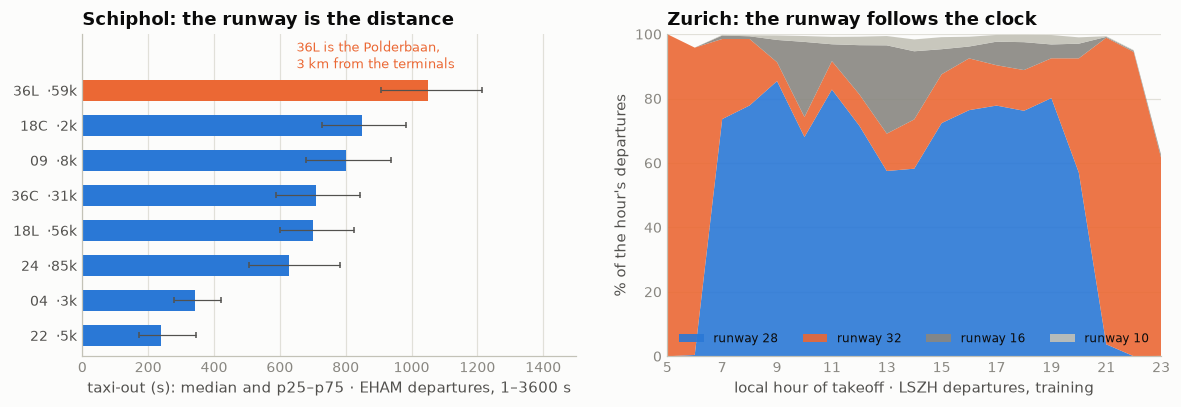

In [6]:
# the configuration in time: which runway is in use swings with the wind month to month, and follows the clock at
# Zurich; the two ranking months sit inside 2025's range
print("share of each hub's busiest 2025 runway, by month — and in the two ranking months:")
print(con.sql(f"""
    WITH top AS (SELECT hub, arg_max(rwy, n) top_rwy FROM (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2) GROUP BY 1),
         d AS (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, ADEP_mvt hub, RUNWAY_mvt rwy FROM {T} WHERE PHASE_mvt = 'DEP'
               UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), ADEP_mvt, RUNWAY_mvt FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT hub, top_rwy,
           {', '.join(f"round(100.0*count(*) FILTER (yr = 2025 AND mon = {m} AND rwy = top_rwy)/count(*) FILTER (yr = 2025 AND mon = {m})) m{m:02d}" for m in range(1, 13))},
           round(100.0*count(*) FILTER (yr = 2026 AND mon = 1 AND rwy = top_rwy)/count(*) FILTER (yr = 2026 AND mon = 1)) jan26,
           round(100.0*count(*) FILTER (yr = 2026 AND mon = 7 AND rwy = top_rwy)/count(*) FILTER (yr = 2026 AND mon = 7)) jul26
    FROM d JOIN top USING (hub) GROUP BY 1, 2 ORDER BY 1""").df().to_string(index=False))

hourly = con.sql(f"""
    SELECT RUNWAY_mvt rwy, hour({LOCAL}) h, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LSZH' GROUP BY 1, 2""").df()
piv = hourly.pivot(index="h", columns="rwy", values="n").fillna(0)
piv = piv.reindex(range(5, 24)).fillna(0)
share = piv.div(piv.sum(axis=1), axis=0) * 100
print("\nZurich's departure runway by local hour (% of the hour's departures, training) — a regime, not the wind:")
print(share[["28", "32", "16", "10"]].round(0).astype(int).T.to_string())

eham = con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, quantile_cont(TAXITIME_SEC_mvt, 0.5) med, quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM {TGT} WHERE ADEP_mvt = 'EHAM' GROUP BY 1 HAVING count(*) >= 1000 ORDER BY med""").df()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
yy = np.arange(len(eham))
a1.barh(yy, eham.med, height=0.6, color=[ORANGE if r == "36L" else BLUE for r in eham.rwy])
a1.errorbar(eham.med, yy, xerr=[eham.med - eham.p25, eham.p75 - eham.med], fmt="none", ecolor=INK2, elinewidth=0.8, capsize=2)
a1.set_yticks(yy, [f"{r}  ·{n/1000:.0f}k" for r, n in zip(eham.rwy, eham.n)], color=INK2)
a1.text(eham.med.max() * 0.62, yy[-1] + 0.5, "36L is the Polderbaan,\n3 km from the terminals", fontsize=8.5, color=ORANGE, va="bottom")
a1.set_xlim(0, 1500)
a1.set_ylim(-0.6, len(eham) + 0.6)
a1.set_title("Schiphol: the runway is the distance")
a1.set_xlabel("taxi-out (s): median and p25–p75 · EHAM departures, 1–3600 s")
style(a1, x_grid=True, y_grid=False)
cols = {"28": BLUE, "32": ORANGE, "16": MUTED, "10": BASELINE}
a2.stackplot(share.index, [share[r] for r in cols], labels=[f"runway {r}" for r in cols], colors=list(cols.values()), alpha=0.9)
a2.set_xlim(5, 23)
a2.set_ylim(0, 100)
a2.set_xticks(range(5, 24, 2))
a2.set_title("Zurich: the runway follows the clock")
a2.set_xlabel("local hour of takeoff · LSZH departures, training")
a2.set_ylabel("% of the hour's departures")
a2.legend(loc="lower center", ncol=4, fontsize=8, frameon=False)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [7]:
# what the runway buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung: alone, as the
# direction only, with the hour, with two context flags, on top of the anchor, and with the two columns it pairs with
con.sql(f"""
    CREATE OR REPLACE TABLE rwy_ev AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, RUNWAY_mvt rwy, substr(RUNWAY_mvt, 1, 2) direction, hour({LOCAL}) h_local,
           AIRCRAFT_TYPE_mvt typ, STAND_mvt stand, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor,
           (RUNWAY_mvt != lag(RUNWAY_mvt) OVER w AND epoch(MVT_TIME_UTC_mvt - lag(MVT_TIME_UTC_mvt) OVER w) < 1800) switched,
           count(DISTINCT RUNWAY_mvt) OVER (PARTITION BY ADEP_mvt, date_trunc('hour', MVT_TIME_UTC_mvt)) runways_this_hour
    FROM {T} WHERE PHASE_mvt = 'DEP'
    WINDOW w AS (PARTITION BY ADEP_mvt ORDER BY MVT_TIME_UTC_mvt)""")
con.sql("CREATE OR REPLACE TABLE rwy_d AS SELECT * FROM rwy_ev WHERE y BETWEEN 1 AND 3600")


def rwy_cat(keys, tbl="rwy_d"):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM {tbl} WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM {tbl} v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM rwy_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures:")
for name, keys in [("airport", "hub"), ("+ runway", "hub, rwy"), ("+ direction only (first two characters)", "hub, direction"),
                   ("+ local hour (§8)", "hub, h_local"), ("+ runway × local hour", "hub, rwy, h_local"),
                   ("+ runway × switched from the previous departure", "hub, rwy, switched"),
                   ("+ runway × runways in use this hour", "hub, rwy, runways_this_hour"),
                   ("+ type (§11)", "hub, typ"), ("+ runway × type", "hub, rwy, typ"),
                   ("+ stand (its own section)", "hub, stand"), ("+ runway × stand", "hub, rwy, stand")]:
    print(f"    {name:50s} {rwy_cat(keys):7.1f} s")

print("\nshare of departures whose runway differs from the previous departure's within 30 min, per hub — and the two medians:")
print(con.sql("""
    SELECT hub, round(100.0*avg(switched::INT), 1) pct_switched, round(quantile_cont(y, 0.5) FILTER (switched)) med_switched,
           round(quantile_cont(y, 0.5) FILTER (NOT switched)) med_same
    FROM rwy_d GROUP BY 1 ORDER BY 2 DESC""").df().to_string(index=False))

con.sql("""
    CREATE OR REPLACE TABLE rwy_b AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95]) qa
                  FROM rwy_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT rwy_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM rwy_d JOIN cuts USING (hub) WHERE anchor IS NOT NULL""")
n_val = con.sql("SELECT count(*) FROM rwy_b WHERE is_val").fetchone()[0]
print(f"\n(2) conditional on the anchor — the {n_val:,} Nov+Dec departures with an AOBT_3, airport × 20 anchor bins first:")
for name, keys in [("airport", "hub"), ("+ AOBT_3 anchor", "hub, q_anc"), ("+ anchor, then runway", "hub, q_anc, rwy"), ("runway without the anchor", "hub, rwy")]:
    print(f"    {name:50s} {rwy_cat(keys, 'rwy_b'):7.1f} s")


(1) on top of the airport mean — 327,485 Nov+Dec departures:
    airport                                              357.3 s
    + runway                                             343.5 s
    + direction only (first two characters)              345.6 s
    + local hour (§8)                                    351.5 s
    + runway × local hour                                338.4 s
    + runway × switched from the previous departure      343.1 s
    + runway × runways in use this hour                  342.5 s
    + type (§11)                                         338.0 s


    + runway × type                                      323.1 s
    + stand (its own section)                            323.6 s
    + runway × stand                                     306.0 s

share of departures whose runway differs from the previous departure's within 30 min, per hub — and the two medians:
 hub  pct_switched  med_switched  med_same
EDDF          55.0         812.0     866.0
LEMD          53.7         970.0    1001.0
LTFM          52.8         968.0     957.0
LFPG          51.8         959.0     950.0
EDDM          51.7         768.0     779.0
EHAM          44.2         716.0     764.0
LSZH          16.6         817.0     695.0
LIRF           9.2        1252.0    1015.0
LEBL           2.9        1030.0     903.0
EGLL           0.2        1193.0    1319.0



(2) conditional on the anchor — the 324,631 Nov+Dec departures with an AOBT_3, airport × 20 anchor bins first:
    airport                                              355.4 s
    + AOBT_3 anchor                                      290.8 s
    + anchor, then runway                                283.2 s
    runway without the anchor                            341.8 s


                                          feature        kind  n / levels  pearson_r  spearman_ρ     η
runway — the code, per airport it is the geometry categorical          53                        0.488
        direction only — the first two characters categorical          25                        0.428
    switched from the previous departure's runway categorical           3                        0.099
                         runways in use this hour     numeric     2080533     -0.205       -0.19      
                          a helipad code (H, HEL) categorical           2                        0.024
                                  the NA sentinel categorical           2                        0.001


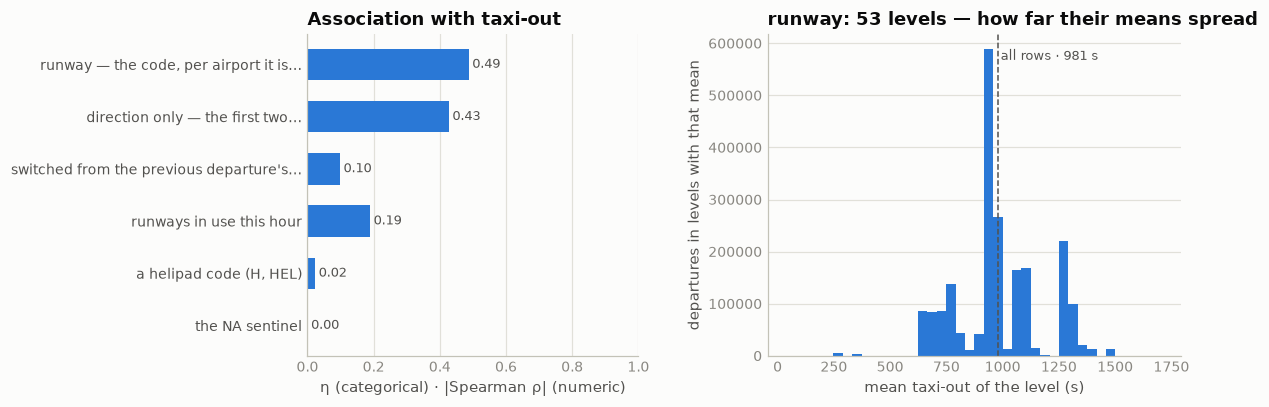

In [8]:
# correlation with the target: the runway, its direction, the two context flags, and the helipad codes
a = target_assoc([("runway — the code, per airport it is the geometry", "cat", "RUNWAY_mvt"),
                  ("direction only — the first two characters", "cat", "substr(RUNWAY_mvt, 1, 2)"),
                  ("switched from the previous departure's runway", "cat", "switched", 1, "rwy_d", "y"),
                  ("runways in use this hour", "num", "runways_this_hour", 1, "rwy_d", "y"),
                  ("a helipad code (H, HEL)", "cat", "RUNWAY_mvt IN ('H', 'HEL')"),
                  ("the NA sentinel", "cat", "RUNWAY_mvt = 'NA'")])
assoc_chart(a, "RUNWAY_mvt", kind="cat", title="runway")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null — but three codes are not runways** | 0 nulls on 4,857,331 rows, 53 values on training departures. `H`: 919 rows, 466 departures at LSZH, median label 1 s, 88% rotorcraft. `HEL`: 361 rows, 40 departures at EHAM, 100% rotorcraft. `NA`: 221 rows, 40 departures (LIRF 24, EDDF 8, EGLL 3, EHAM 1) and 2 + 2 in the 2026 file. `7`: one arrival | the helipads are real levels (§4's helicopters); `NA` is a sentinel for an unknown runway and stays a level of its own — 40 rows, nothing to repair |
| **Within an airport the runway is the distance** | EHAM: `24` median 627 s, `18L` 701, `36C` 711, **`36L` 1,049** — the Polderbaan, 3 km from the terminals; EDDF `18` 887 vs `25C` 735; LTFM `36` 891 vs `17R` 1,267; LIRF `25` 1,011 vs `16R` 1,329. EGLL's three: 1,310, 1,316, 1,332 | geometry, and at Heathrow none: its runways are equally far from everything |
| **Most hubs segregate departures from arrivals** | LEMD: `36R 36L 14L 14R` depart only, `32R 32L 18L 18R` land only; EDDF `18` departs only, `25C` shared; EHAM `24 36L 18L 09` depart, `18R 06 36R 27` land; EGLL `09R` departs, `09L` lands, `27L`/`27R` alternate; EDDM shares all four | the real choice is 2–4 departure runways per hub |
| **One runway at Heathrow, two elsewhere** | departure runways per hour: EGLL 1.03 (97% of hours on one), LEBL 1.28, LIRF 1.48, LEMD 1.73, LSZH 1.74, LFPG 1.84, EDDM 1.93, EDDF 1.99, LTFM 2.06, EHAM 2.23 | the parallel-operation hubs alternate runways departure by departure — the next row |
| **The wind sets it month to month; the clock at Zurich** | share of the busiest runway: EGLL `09R` 11% (July) to 71% (April), EHAM `24` 15% to 49%, LFPG `08L` 12% to 46%; LIRF `25` 79–94%. LSZH: `32` carries 95–100% of departures before 07h and after 21h, `28` 74–85% through the day, `16` up to 27% at 13h | Zurich's regime is readable from the hour; elsewhere the row's own runway is the configuration, and it is known |
| **2026 sits inside 2025** | the two ranking months' shares fall within 2025's monthly range at nine hubs; LTFM `36` is at 26% in January 2026 against 29–59% in 2025. New in 2026: LFPG `NA`, 2 rows. Gone: LTFM `34R`, 308 rows in 2025. 19 of 344,841 ranking departures use a runway with under 30 training rows | no drift to handle |
| **Alone it buys 13.8 s; on top of the anchor, 7.6** | airport 357.3 → + runway **343.5**; direction only 345.6; runway × local hour 338.4 (the hour alone 351.5). With the anchor first: 290.8 → 283.2; the runway without it 341.8 | the base of every ladder since §7. The anchor absorbs half of it: an aircraft that took long to reach a far runway is late against `AOBT_3` too |
| **Switching and the count in use add nothing** | runway × switched from the previous departure 343.1, × runways in use this hour 342.5. Switching is 52–55% of departures at EDDF, LEMD, LTFM, LFPG and EDDM — parallel operations alternate — and 0.2% at EGLL | both flags are the hub's operating mode, which the airport and the code already say |
| **The pair with the stand is the feature** | runway × type 323.1 (type alone 338.0), runway × stand **306.0** (stand alone 323.6) | stand → runway is the taxi route itself; the stand section owns it |
| Across hubs the code carries the airport | η 0.488 over 53 levels, direction 0.428 — Heathrow's `09R`/`27R`/`27L` are Heathrow's alone, and Heathrow taxis 1,300 s | the marginal number is mostly the airport's; the within-airport gain is the ladder row |

**Decisions**

| issue | decision | why |
|---|---|---|
| the `NA` sentinel | its own level, no repair | 40 departures, 2 + 2 in 2026, no source to repair from |
| the helipad codes | their own levels | real, and §4's helicopters use them |
| the switch flag, the count in use | not features | 0.4 and 1.0 s |
| runway × hour | left to the model | Zurich's regime is what a tree reads from runway + local hour |

**State after §12** — unchanged: never null, nothing repaired.

**Use in modeling.** The runway as a native categorical, per airport — the pipeline does this. Its
own worth is the 14 s at the base of the ladders; its value is in the pairs, with the stand above
all. In the closing matrix it enters raw, rare codes pooled below 30 rows: 0.91 with the airport
(the codes are the hub's own), 0.49 with the target.


## 13 · `STAND_mvt` — where the taxi starts

The stand the aircraft left from — `B15`, `302`, `T13` — as the airport recorded it; on arrival
rows the stand it parked at. With the runway (§12) it is the *route*: where the taxi begins and
where it ends, and at every hub the two together are the geometry the model has to learn. Present
on all but a handful of rows in both files. The pipeline's strongest feature by gain is a rolling
mean of taxi-out from the stand (`VALIDATION/archive/FINDINGS_20260907.md`, §4) — this column with a memory.

| step | question | what came out |
|---|---|---|
| **census** | present where; is every value a stand? | 28 + 4 departures without one; an `UNKNOWN` sentinel for Barcelona's cargo apron; named areas at Zurich and Paris |
| **the geometry** | how far apart a hub's stands are, and the route stand × runway | a hub's p10 and p90 stands are 4–11 minutes apart; at Schiphol pier × runway runs from 518 s to 1,439 s |
| **look both ways** | stands 2026 uses that 2025 did not know | Frankfurt's new pier (1,804 July departures) and Munich's renumbered apron (1,177): 3,000 rows the stand cannot see |
| **signal** | the stand and its prefix — alone, with the runway, cascaded, on the anchor; then turnaround and pier traffic | 34 s alone, 51 with the runway, 18 on top of the anchor; the prefix carries most of it and is the fallback; turnaround and pier traffic add nothing |


In [4]:
# census by file × phase: all but a handful of rows carry a stand; the values that are not stands but named areas; and the
# prefix — the pier, apron or terminal the stand belongs to — that later cells use as the stand's coarser form
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
PFX = "CASE WHEN regexp_matches(STAND_mvt, '^[A-Z]') THEN regexp_extract(STAND_mvt, '^([A-Z]+)', 1) ELSE substr(STAND_mvt, 1, 1) END"
print("STAND_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (STAND_mvt IS NULL) n_null, count(DISTINCT STAND_mvt) n_values,
           count(*) FILTER (STAND_mvt = 'UNKNOWN') unknown_sentinel
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows without a stand (both files, departures) — where and who:")
print(con.sql(f"""
    SELECT src, ADEP_mvt hub, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan, mode(MARKET_SEGMENT_flt) segment,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NULL GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

print("\nvalues that are names rather than stand numbers (both files, both phases; ≥ 20 rows):")
print(con.sql(f"""
    SELECT STAND_mvt code, mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, count(*) n,
           count(*) FILTER (PHASE_mvt = 'DEP') departures, mode(MARKET_SEGMENT_flt) segment, mode(AIRCRAFT_TYPE_mvt) typ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IN {HELI_ALL})/count(*)) pct_rotorcraft,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (PHASE_mvt = 'DEP')) med_taxi_out
    FROM {BOTH} WHERE STAND_mvt IS NOT NULL AND NOT regexp_matches(STAND_mvt, '[0-9]')
    GROUP BY 1 HAVING count(*) >= 20 ORDER BY n DESC""").df().to_string(index=False))

print("\nhow each hub names its stands — leading letters or digits, and the number of prefixes (piers / aprons / terminals):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(DISTINCT STAND_mvt) n_stands,
           round(100.0*count(*) FILTER (regexp_matches(STAND_mvt, '^[A-Z]'))/count(*), 1) pct_letter_first,
           count(DISTINCT {PFX}) n_prefixes, string_agg(DISTINCT {PFX}, ' ') prefixes
    FROM {T} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


STAND_mvt by file × phase:
     src  ph       n  n_null  n_values  unknown_sentinel
training ARR 2082750      36      1849              1628
training DEP 2085047      28      1899              1477
 ranking ARR  344693       5      1692               269
 ranking DEP  344841       4      1697               249

the rows without a stand (both files, departures) — where and who:
     src  hub  n  no_plan       segment  med_label
training LFPG 14        3      Mainline       -2.0
training LIRF 10        8 Non-Scheduled     1350.0
training EGLL  4        0      Mainline     1772.0
 ranking LFPG  2        0      Mainline        NaN
 ranking EGLL  2        0      Mainline        NaN

values that are names rather than stand numbers (both files, both phases; ≥ 20 rows):
   code  hub    n  departures       segment  typ  pct_rotorcraft  med_taxi_out
UNKNOWN LEBL 3623        1726         Cargo B752             0.0         735.0
    MFG LSZH 2401        1244         Other DA40             0.0     

stand medians within each hub — departures 1–3600 s, stands with ≥ 100 rows: how far the p10 and p90 stands are apart:


 hub  n_stands    p10    p50    p90 nearest  nearest_med farthest  farthest_med
EHAM       192  332.0  727.0  963.0    HG01        176.0      R72        1233.0
LSZH       116  406.0  729.0  933.0     HPW          7.0      C55        1088.0
EDDM       155  598.0  771.0  847.0     342        534.0      907        1138.0
LEBL       169  618.0  873.0 1206.0     422        414.0     119A        1455.0
EDDF       185  493.0  877.0 1061.0    V172        354.0     V322        1325.0
LFPG       290  832.0  969.0 1174.0     R13        537.0      N04        1435.0
LTFM       256  777.0  970.0 1086.0     601        490.0      A11        1207.0
LEMD       270  691.0  976.0 1354.0     606        469.0      145        1688.0
LIRF       121  839.0 1010.0 1331.0     230        775.0      902        1568.0
EGLL       179 1137.0 1325.0 1442.0    246L        899.0      547        1511.0

Schiphol: median taxi-out by pier × runway (piers with ≥ 2,000 departures, the four main runways) — the route, not the 

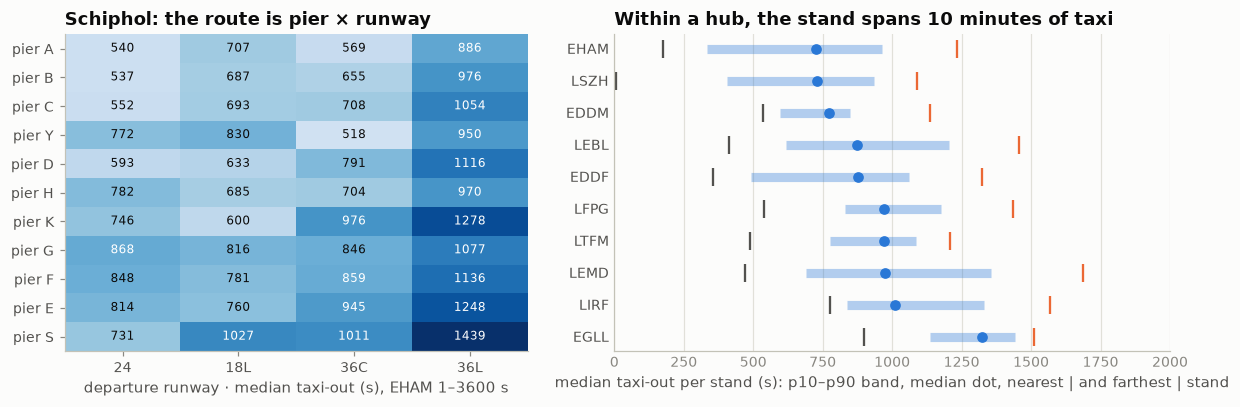

In [5]:
# the geometry: how far apart the stands of one hub are in taxi-out, and the stand × runway pair that is the route
print("stand medians within each hub — departures 1–3600 s, stands with ≥ 100 rows: how far the p10 and p90 stands are apart:")
spread = con.sql(f"""
    SELECT hub, count(*) n_stands, round(quantile_cont(med, 0.1)) p10, round(quantile_cont(med, 0.5)) p50, round(quantile_cont(med, 0.9)) p90,
           arg_min(stand, med) nearest, round(min(med)) nearest_med, arg_max(stand, med) farthest, round(max(med)) farthest_med
    FROM (SELECT ADEP_mvt hub, STAND_mvt stand, quantile_cont(TAXITIME_SEC_mvt, 0.5) med FROM {TGT} WHERE STAND_mvt IS NOT NULL
          GROUP BY 1, 2 HAVING count(*) >= 100)
    GROUP BY 1 ORDER BY p50""").df()
print(spread.to_string(index=False))

print("\nSchiphol: median taxi-out by pier × runway (piers with ≥ 2,000 departures, the four main runways) — the route, not the stand or the runway alone:")
heat = con.sql(f"""
    SELECT {PFX} pier, RUNWAY_mvt rwy, quantile_cont(TAXITIME_SEC_mvt, 0.5) med, count(*) n
    FROM {TGT} WHERE ADEP_mvt = 'EHAM' AND RUNWAY_mvt IN ('24', '36L', '18L', '36C') AND STAND_mvt IS NOT NULL
      AND {PFX} IN (SELECT {PFX} FROM {TGT} WHERE ADEP_mvt = 'EHAM' AND STAND_mvt IS NOT NULL GROUP BY 1 HAVING count(*) >= 2000)
    GROUP BY 1, 2 HAVING count(*) >= 30""").df()
hm = heat.pivot(index="pier", columns="rwy", values="med")[["24", "18L", "36C", "36L"]]
hm = hm.loc[hm.mean(axis=1).sort_values().index]
print(hm.round(0).fillna(-1).astype(int).replace(-1, "·").to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
im = a1.imshow(hm.values, cmap="Blues", vmin=300, vmax=1400, aspect="auto")
a1.set_xticks(range(hm.shape[1]), hm.columns, color=INK2)
a1.set_yticks(range(hm.shape[0]), [f"pier {p}" for p in hm.index], color=INK2)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if not np.isnan(v):
            a1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 850 else INK)
a1.set_title("Schiphol: the route is pier × runway")
a1.set_xlabel("departure runway · median taxi-out (s), EHAM 1–3600 s")
a1.grid(False)
yy = np.arange(len(spread))
a2.hlines(yy, spread.p10, spread.p90, color=BLUE, lw=6, alpha=0.35)
a2.plot(spread.p50, yy, "o", color=BLUE, ms=6)
a2.plot(spread.nearest_med, yy, "|", color=INK2, ms=12, mew=1.5)
a2.plot(spread.farthest_med, yy, "|", color=ORANGE, ms=12, mew=1.5)
a2.set_yticks(yy, spread.hub, color=INK2)
a2.invert_yaxis()
a2.set_xlim(0, 2000)
a2.set_title("Within a hub, the stand spans 10 minutes of taxi")
a2.set_xlabel("median taxi-out per stand (s): p10–p90 band, median dot, nearest | and farthest | stand")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# look both ways: stands are renumbered and piers are built. What 2026 uses that 2025 barely knew, and where it happened
print("2026 departures on stands new to their hub, or with under 30 training departures — and whether the prefix has support:")
print(con.sql(f"""
    WITH s25 AS (SELECT ADEP_mvt hub, STAND_mvt stand, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         p25 AS (SELECT ADEP_mvt hub, {PFX} pfx, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NOT NULL GROUP BY 1, 2)
    SELECT r.ADEP_mvt hub, count(*) rows_2026, count(*) FILTER (s25.stand IS NULL) on_new_stands, count(DISTINCT r.STAND_mvt) FILTER (s25.stand IS NULL) new_stands,
           count(*) FILTER (coalesce(s25.n, 0) < 30) on_stands_under_30, count(*) FILTER (coalesce(s25.n, 0) < 30 AND coalesce(p25.n, 0) >= 30) of_which_prefix_supported,
           count(*) FILTER (coalesce(s25.n, 0) < 30 AND month(r.MVT_TIME_UTC_mvt) = 7) of_which_in_july
    FROM {R} r LEFT JOIN s25 ON s25.hub = r.ADEP_mvt AND s25.stand = r.STAND_mvt
    LEFT JOIN p25 ON p25.hub = r.ADEP_mvt AND p25.pfx = {PFX.replace('STAND_mvt', 'r.STAND_mvt')}
    WHERE r.PHASE_mvt = 'DEP' AND r.STAND_mvt IS NOT NULL GROUP BY 1 ORDER BY on_stands_under_30 DESC""").df().to_string(index=False))

print("\nFrankfurt — departures from the J and H5/H9 stands by month; Munich — stands 103–108 against 120/121:")
print(con.sql(f"""
    SELECT yr, mon, count(*) FILTER (ADEP_mvt = 'EDDF' AND STAND_mvt LIKE 'J%') eddf_j, count(*) FILTER (ADEP_mvt = 'EDDF' AND STAND_mvt IN ('H5', 'H9')) eddf_h5_h9,
           count(*) FILTER (ADEP_mvt = 'EDDF') eddf_all,
           count(*) FILTER (ADEP_mvt = 'EDDM' AND STAND_mvt IN ('103', '104', '105', '106', '107', '108')) eddm_103_108,
           count(*) FILTER (ADEP_mvt = 'EDDM' AND STAND_mvt IN ('120', '121')) eddm_120_121
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, * FROM {T} UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), * FROM {R})
    WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nFrankfurt's new pier in July 2026 — its runway and its takeoff − AOBT_3 gap against the rest of the hub:")
print(con.sql(f"""
    SELECT (STAND_mvt LIKE 'J%' OR STAND_mvt IN ('H5', 'H9')) new_pier, count(*) n, mode(RUNWAY_mvt) rwy,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_gap_s
    FROM {R} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EDDF' AND month(MVT_TIME_UTC_mvt) = 7 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


2026 departures on stands new to their hub, or with under 30 training departures — and whether the prefix has support:
 hub  rows_2026  on_new_stands  new_stands  on_stands_under_30  of_which_prefix_supported  of_which_in_july
EDDF      36317            300           6                2151                       2150              2088
EDDM      25966           1182          10                1212                       1204              1201
LSZH      23150             58          11                 221                        197                87
LEMD      36954             14           7                 184                        181               127
LTFM      47581              6           2                 181                        172               113
LFPG      39870              8           5                 135                        132                74
LEBL      30080              1           1                  83                         83                51
LIRF      26899  

 new_pier     n rwy  med_gap_s
    False 18846  18      915.0
     True  1804  18      979.0


In [7]:
# what the stand buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung: the stand and its
# prefix alone, paired with the runway, cascaded, on top of the anchor; then two things the stand's history could add —
# the turnaround (minutes since the last arrival parked there, known at prediction time) and the pier's own traffic
con.sql(f"""
    CREATE OR REPLACE TABLE std_ev AS
    SELECT ds, MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph, STAND_mvt stand, {PFX} pfx,
           MVT_TIME_UTC_mvt t, BLOCK_TIME_UTC_mvt b, AOBT_3_flt aobt3, RUNWAY_mvt rwy, AIRCRAFT_TYPE_mvt typ, TAXITIME_SEC_mvt taxi
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})""")
con.sql("""
    CREATE OR REPLACE TABLE std_turn AS
    SELECT ds, id, epoch(aobt3 - last_ib)/60.0 turn_min FROM (
        SELECT d.ds, d.id, d.aobt3, max(a.ib) last_ib
        FROM (SELECT * FROM std_ev WHERE ph = 'DEP' AND stand IS NOT NULL AND aobt3 IS NOT NULL) d
        LEFT JOIN (SELECT ds, hub, stand, b ib FROM std_ev WHERE ph = 'ARR' AND b IS NOT NULL AND stand IS NOT NULL) a
          ON a.ds = d.ds AND a.hub = d.hub AND a.stand = d.stand AND a.ib < d.aobt3 AND a.ib > d.aobt3 - INTERVAL 24 HOUR
        GROUP BY 1, 2, 3)""")
con.sql("""
    CREATE OR REPLACE TABLE std_pier AS
    SELECT ds, id, sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER (PARTITION BY ds, hub, pfx ORDER BY t
                                                                    RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING) pier_dep_c30
    FROM std_ev WHERE stand IS NOT NULL""")
con.sql("""
    CREATE OR REPLACE TABLE std_d AS
    SELECT e.hub, e.rwy, e.stand, e.pfx, e.typ, e.taxi::DOUBLE y, month(e.t) >= 11 is_val, epoch(e.t - e.aobt3) anchor, tr.turn_min, p.pier_dep_c30,
           CASE WHEN tr.turn_min IS NULL THEN 'no arrival in 24 h' WHEN tr.turn_min < 45 THEN 'under 45 min' WHEN tr.turn_min < 90 THEN '45–90'
                WHEN tr.turn_min < 180 THEN '90–180' ELSE 'over 3 h' END turn_band
    FROM std_ev e LEFT JOIN std_turn tr USING (ds, id) LEFT JOIN std_pier p USING (ds, id)
    WHERE e.ds = 'training' AND e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600""")


def std_cat(keys, tbl="std_d"):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM {tbl} WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM {tbl} v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM std_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures (a missing stand is its own level):")
for name, keys in [("airport", "hub"), ("+ prefix (pier / apron / terminal)", "hub, pfx"), ("+ stand", "hub, stand"), ("+ runway (§12)", "hub, rwy"),
                   ("+ runway × prefix", "hub, rwy, pfx"), ("+ runway × stand", "hub, rwy, stand"), ("+ runway × stand × type", "hub, rwy, stand, typ")]:
    print(f"    {name:44s} {std_cat(keys):7.1f} s")
print("    runway × stand, cascading to runway × prefix, runway, airport when a cell has under 30 rows:", end=" ")
print(con.sql("""
    WITH f3 AS (SELECT hub, rwy, stand, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         f2 AS (SELECT hub, rwy, pfx, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         f1 AS (SELECT hub, rwy, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         h AS (SELECT hub, avg(y) m FROM std_d WHERE NOT is_val GROUP BY 1)
    SELECT round(sqrt(avg((v.y - coalesce(CASE WHEN f3.c >= 30 THEN f3.m END, CASE WHEN f2.c >= 30 THEN f2.m END,
                                          CASE WHEN f1.c >= 30 THEN f1.m END, h.m))^2)), 1)
    FROM std_d v LEFT JOIN f3 USING (hub, rwy, stand) LEFT JOIN f2 USING (hub, rwy, pfx) LEFT JOIN f1 USING (hub, rwy) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0], "s")

con.sql("""
    CREATE OR REPLACE TABLE std_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(pier_dep_c30, [0.2,0.4,0.6,0.8]) qp FROM std_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT std_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc, list_count(list_filter(qp, x -> x <= pier_dep_c30)) q_pier
    FROM std_d JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")


def std_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE std_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM std_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN std_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN std_s{i}.c >= 30 THEN std_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM std_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM std_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor (§9's base)", ["hub", "rwy", "q_anc"]),
        ("+ prefix", ["hub", "rwy", "q_anc", "pfx"]), ("+ stand", ["hub", "rwy", "q_anc", "pfx", "stand"])]
n_val = con.sql("SELECT count(*) FROM std_wb WHERE is_val").fetchone()[0]
print(f"\n(2) on top of airport × runway × anchor — the {n_val:,} Nov+Dec departures with runway, stand and anchor:")
for name, r in std_rungs(BASE):
    print(f"    {name:44s} {r:7.1f} s")
for name, keys in [("+ turnaround band, on top", ["turn_band"]), ("+ pier departures within ±15 min, on top", ["q_pier"])]:
    print(f"    {name:44s} {std_rungs(BASE + [('x', BASE[-1][1] + keys)])[-1][1]:7.1f} s")

print("\nthe turnaround — minutes from the last arrival's in-block at the stand to our AOBT_3 (training departures with an anchor):")
print(con.sql("""
    SELECT turn_band, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(y)) mean_taxi, round(quantile_cont(y, 0.5)) med_taxi
    FROM std_d WHERE anchor IS NOT NULL GROUP BY 1 ORDER BY min(coalesce(turn_min, 1e9))""").df().to_string(index=False))


(1) on top of the airport mean — 327,485 Nov+Dec departures (a missing stand is its own level):
    airport                                        357.3 s
    + prefix (pier / apron / terminal)             335.5 s
    + stand                                        323.6 s
    + runway (§12)                                 343.5 s
    + runway × prefix                              314.5 s
    + runway × stand                               306.0 s
    + runway × stand × type                        318.6 s
    runway × stand, cascading to runway × prefix, runway, airport when a cell has under 30 rows: 

300.3 s



(2) on top of airport × runway × anchor — the 324,629 Nov+Dec departures with runway, stand and anchor:
    airport                                        355.4 s
    + runway                                       341.8 s
    + AOBT_3 anchor (§9's base)                    283.6 s
    + prefix                                       268.6 s
    + stand                                        265.5 s


    + turnaround band, on top                      265.1 s


    + pier departures within ±15 min, on top       265.5 s

the turnaround — minutes from the last arrival's in-block at the stand to our AOBT_3 (training departures with an anchor):
         turn_band      n  pct  mean_taxi  med_taxi
      under 45 min 121666  5.9      886.0     825.0
             45–90 871665 42.3      931.0     888.0
            90–180 459078 22.3     1057.0     995.0
          over 3 h 567448 27.6     1016.0     954.0
no arrival in 24 h  39544  1.9     1010.0     958.0


                                                 feature        kind  n / levels  pearson_r  spearman_ρ     η
                                        stand — the code categorical        1494                        0.495
                        prefix — pier, apron or terminal categorical          45                        0.327
                                  route — stand × runway categorical        6427                        0.666
                                    the UNKNOWN sentinel categorical           3                        0.015
turnaround — minutes since the last arrival parked there     numeric     2019857       0.02       0.128      
            departures from the same pier within ±15 min     numeric     2080514       0.06       0.069      


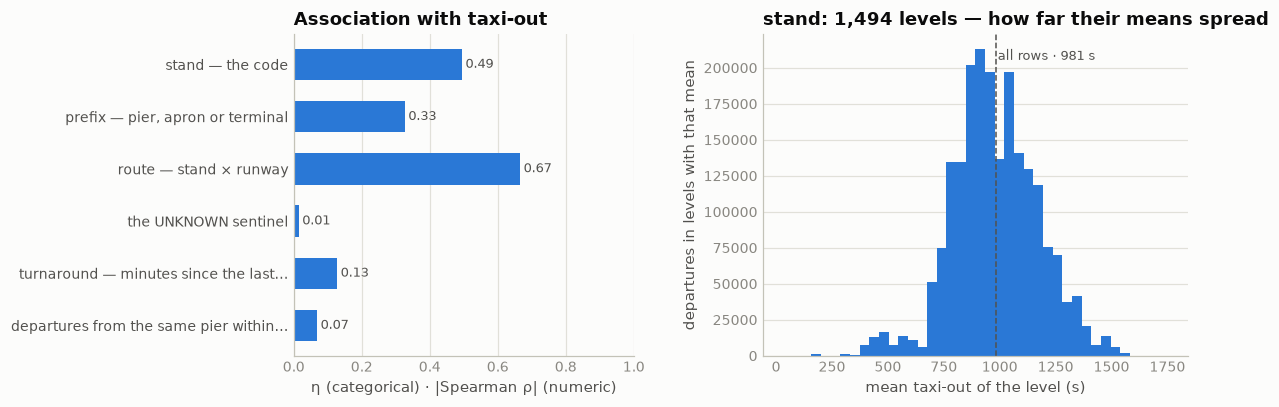

In [8]:
# correlation with the target: the stand, its prefix, the route (stand × runway), the sentinel, the turnaround and the pier's traffic
a = target_assoc([("stand — the code", "cat", "STAND_mvt", 30),
                  ("prefix — pier, apron or terminal", "cat", PFX, 30),
                  ("route — stand × runway", "cat", "STAND_mvt || '→' || RUNWAY_mvt", 30),
                  ("the UNKNOWN sentinel", "cat", "STAND_mvt = 'UNKNOWN'"),
                  ("turnaround — minutes since the last arrival parked there", "num", "turn_min", 1, "std_d", "y"),
                  ("departures from the same pier within ±15 min", "num", "pier_dep_c30", 1, "std_d", "y")])
assoc_chart(a, "STAND_mvt", kind="cat", min_support=30, title="stand")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present on all but 32 departures** | 28 training departures without a stand (LFPG 14, LIRF 10, EGLL 4) and 4 in the ranking file; 1,899 distinct values on training departures, 1,697 in 2026 | nothing to repair — a missing stand is its own level |
| **Not every value is a stand** | `UNKNOWN`: 1,477 training departures and 249 in 2026, all but 14 at LEBL, cargo (`B752`), median taxi 735 s — the freight apron's stands go unrecorded. Named areas at LSZH (`MFG` 1,244 departures, `REG` 939, `HAN` 487, `HPW` 366: the GA aprons and the helipad) and LFPG (`CFE`, `CFW`: the two cargo areas, 641 + 637 departures, A388 the mode, 1,433 and 1,145 s) | real levels with real geometry — keep them all, `UNKNOWN` included: it is one apron |
| **Every hub names its stands its own way — and the prefix is the pier** | letter-first at EDDF, EHAM, LFPG (100%), LSZH (94%), LTFM (89%); digit-first at EDDM, EGLL, LEBL, LIRF; LEMD mixed (31% letters — the `T` stands of Terminal 4). 8–31 prefixes per hub | the prefix — the leading letters, else the first digit — is a 45-level coarser form that says "which pier" at every hub |
| **Within a hub, the stand spans 4–11 minutes of taxi** | stands with ≥ 100 rows, p10 → p90 of their medians: EHAM 332 → 963 s (`HG01` 176, `R72` 1,233), LSZH 406 → 933, LEMD 691 → 1,354 (`606` 469, `145` 1,688), LEBL 618 → 1,206, LIRF 839 → 1,331; EGLL 1,137 → 1,442 — even Heathrow's nearest stand is 899 s | the second geometric coordinate after the runway; together they are the route |
| **The route is pier × runway, not a sum** | Schiphol medians: pier A to runway `24` 540 s, to `36L` 886; pier S to `36C` 1,011, to `36L` 1,439; pier Y to `36C` 518 but to `24` 772 | the runway that is far for one pier is near for another — an interaction |
| **2026 uses stands 2025 did not know** | Frankfurt: the `J` stands carried 4–19 departures a month in 2025 and **1,512 in July 2026**, `H5`/`H9` 292 more — a new pier, its July gap to `AOBT_3` 979 s against 915 for the rest of the hub. Munich: stands `120`/`121` stop in August 2025 (1,203 + 707 rows), `103`–`108` appear in July 2026 (1,177 rows). Over all hubs 4,297 ranking departures sit on stands with under 30 training rows, 3,363 of them at these two hubs, 4,158 with a prefix that has support | the stand is blind on 1.2% of the scored set, nearly all in July; the prefix covers 97% of those rows — and at Frankfurt the prefix `J` itself has 133 rows, so the runway and the anchor carry the rest |
| **Alone it buys 34 s; with the runway 51; on top of the anchor 18** | airport 357.3 → + prefix **335.5** → + stand **323.6**; runway 343.5 → × prefix 314.5 → × stand **306.0**; × type on top 318.6 (too sparse); stand → prefix → runway → airport cascading at 30 rows **300.3**. On §9's base 283.6 → + prefix 268.6 → + stand **265.5** | the largest single step after the anchor; the prefix carries 60–80% of it and is the right fallback; the cascade beats the flat pair by 5.7 s |
| **Turnaround and pier traffic add nothing** | minutes from the last arrival's in-block at the stand to our `AOBT_3`: 98.1% of departures have one within 24 h, median 92 min; taxi by band 886 s (under 45 min) → 931 (45–90) → 1,057 (90–180) → 1,016 (over 3 h); on the ladder +0.4 s. Departures from the same pier within ±15 min: +0.0 s, ρ 0.07 | the stand's history that matters is *where it is*, which the code already says |
| Across hubs the code carries the airport | η: stand 0.495 (1,494 levels with ≥ 30 rows), prefix 0.327, the route stand × runway 0.666 (6,427 levels); `UNKNOWN` 0.015 | as with the runway (§12), the marginal number includes the hub; the within-hub gain is the ladder row |

**Decisions**

| issue | decision | why |
|---|---|---|
| the 32 missing stands | left null, their own level | no source to fill from |
| `UNKNOWN` and the named areas | kept as levels | each is one apron with its own geometry |
| the stand's coarser form | **the prefix** — leading letters, else the first digit — as a second feature and the fallback below 30 rows | 60–80% of the stand's gain in 45 levels, and it covers 97% of 2026's rows on rare stands |
| turnaround, pier traffic | not features | +0.4 and 0.0 s |
| stand × runway × type as a group | no | 318.6 against 306.0: too sparse; a tree finds the interaction from the three columns |

**State after §13** — unchanged: nothing repaired.

**Use in modeling.** The stand as a native categorical, per airport — the pipeline does this — plus the
prefix as an explicit second column, so the model has a fallback where the stand is new; the cascade
says the fallback is worth having. The harness's rolling stand mean is this column with a memory and
will be blank for Frankfurt's new pier and Munich's new apron in July 2026, which is exactly where
the prefix must exist. In the closing matrix the stand enters raw, rare codes pooled below 30 rows: 0.83 with the airport, 0.49 with
the rule (the GA aprons), 0.50 with the target.


## 14 · `TAXITIME_SEC_mvt` — the target

The taxi-out time in seconds: takeoff (§8) minus off-block (§9), to the second, on every departure;
on arrival rows the taxi-in, in-block minus landing. It is what the score is computed on — RMSE over
the 344,841 departures of January and July 2026 — and it is blank on exactly those rows. Everything
the sweep has measured so far was measured against it on a window of plausible values, 1–3,600 s.
This section is about the column as delivered: its body, its tails, what the score sees of each,
which rows should train, what the loss rewards, and what can be said about the 2026 labels without
seeing them. It closes the questions §9 and §10a left open.

| step | question | what came out |
|---|---|---|
| **census** | present where; is it exactly the difference of the two stamps? | an integer, the exact difference on every row of both files; null on the 344,841 rows we predict and on one arrival |
| **the shape** | the body and the tails, per hub; which rows own the squared error | a right-skewed quarter of an hour; the 0.2% of rows over an hour own 55% of the squared error, 34 rows over 12 h a third of it |
| **the score** | on an honest holdout, what each band of the label adds to the RMSE; what the band between one and two hours is | four rows over 12 h add 274 s of the 497; the 1–2 h band is mostly 10a's block-stamp defect on rows *with* a plan, which the anchor cannot see |
| **which rows train, and the loss** | the training filter; the mean against the median and the log; the rows at or below zero | keep every label from 1 s up, no ceiling — it pays only through the features that see the tail; the mean wins; the near-zeros cost nothing either way |
| **look both ways** | what is visible of the 2026 labels: the corrupt slice's size, the arrival half, the proxy, the month | the slice is 178% of January 2025's and 82% of July's; the arrivals' corruption is another defect and persists; the proxy moves at three hubs; the month swings each hub by 50–209 s |


In [4]:
# census by file × phase: the label is takeoff − off-block to the second on departures (in-block − landing on arrivals), an integer
# column, blank exactly on the rows we predict; then the raw order statistics of departures — the ranking row is null by construction
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("column type:", con.sql(f"SELECT typeof(TAXITIME_SEC_mvt) FROM {T} LIMIT 1").fetchone()[0])
print("\nTAXITIME_SEC_mvt by file × phase — where it is, its range, its tails, and whether it is exactly the difference of the two stamps:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (TAXITIME_SEC_mvt IS NULL) n_null, min(TAXITIME_SEC_mvt) mn, max(TAXITIME_SEC_mvt) mx,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) negative, count(*) FILTER (TAXITIME_SEC_mvt = 0) zero, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 12) s1_12,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 13 AND 3600) s13_3600, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 3601 AND 7200) s3601_7200,
           count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200,
           count(*) FILTER (TAXITIME_SEC_mvt != CASE WHEN PHASE_mvt = 'DEP' THEN epoch(MVT_TIME_UTC_mvt - BLOCK_TIME_UTC_mvt)
                                                     ELSE epoch(BLOCK_TIME_UTC_mvt - MVT_TIME_UTC_mvt) END) not_the_identity,
           count(*) FILTER (extract(microsecond FROM MVT_TIME_UTC_mvt) % 1000000 != 0 OR extract(microsecond FROM BLOCK_TIME_UTC_mvt) % 1000000 != 0) sub_second_stamps
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nraw order statistics, departures, both files:")
display(order_stats("TAXITIME_SEC_mvt", "PHASE_mvt = 'DEP'"))


column type: INTEGER

TAXITIME_SEC_mvt by file × phase — where it is, its range, its tails, and whether it is exactly the difference of the two stamps:


     src  ph       n  n_null    mn     mx  negative  zero  s1_12  s13_3600  s3601_7200  over_7200  not_the_identity  sub_second_stamps
training ARR 2082750       1 -2652 604797       220    16    247   2081826         299        141                 0                  0
training DEP 2085047       0   -12 131167       369    19    370   2080163        3542        584                 0                  0
 ranking ARR  344693       0   -12  50517        39     5     48    344456         118         27                 0                  0
 ranking DEP  344841  344841  <NA>   <NA>         0     0      0         0           0          0                 0                  0

raw order statistics, departures, both files:


,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,2085047,0,5176,-12,291.0,719.0,912.0,1188.0,2339.0,131167
ranking 2026,344841,344841,0,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>


per hub and over all ten, training departures, raw labels — and the same mean and spread on the 1–3,600 s window:


    hub       n   mean     sd    p50    p90    p99    p999     mx  le_0  over_3600  over_7200  pct_sse_over_3600  mean_1_3600  sd_1_3600
   LSZH  134907  741.0  385.0  711.0 1080.0 1707.0  2505.0  87341   313         26          6               41.8        741.0      292.0
   EHAM  247951  785.0  318.0  742.0 1157.0 1775.0  2934.0  11032     3         82          3                4.7        783.0      311.0
   EDDM  167334  812.0  302.0  774.0 1135.0 1921.0  3007.0   6899     0         59          0                5.3        811.0      294.0
   EDDF  230141  863.0  330.0  837.0 1251.0 1819.0  2927.0   6907     0         73          0                3.5        862.0      324.0
   LEBL  179705  957.0  331.0  906.0 1357.0 1962.0  2963.0   3604     5          1          0                0.0        957.0      331.0
   LEMD  212242 1015.0  313.0  985.0 1402.0 1932.0  2704.0   3598     0          0          0                0.0       1015.0      313.0
   LFPG  239552 1020.0  453.0  954.0 1444

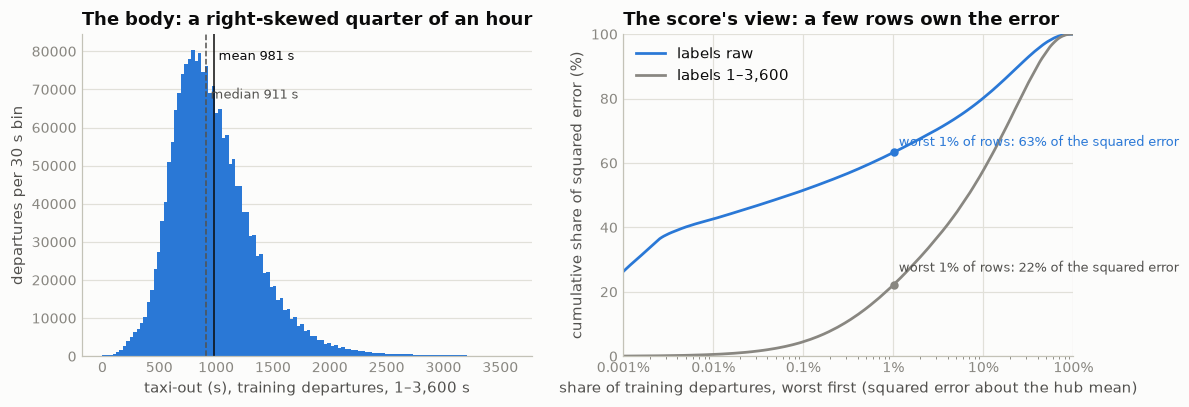

In [5]:
# the shape, on raw labels (the tails are the subject): per hub the body, the tails, and the share of the squared error about the hub's
# mean that the labels over an hour own; the label by band, rows against squared error; and the two pictures — the body, and the score's view
print("per hub and over all ten, training departures, raw labels — and the same mean and spread on the 1–3,600 s window:")
print(con.sql(f"""
    SELECT coalesce(ADEP_mvt, 'all ten') hub, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(stddev(TAXITIME_SEC_mvt)) sd,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) p50, round(quantile_cont(TAXITIME_SEC_mvt, 0.9)) p90, round(quantile_cont(TAXITIME_SEC_mvt, 0.99)) p99,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.999)) p999, max(TAXITIME_SEC_mvt) mx,
           count(*) FILTER (TAXITIME_SEC_mvt <= 0) le_0, count(*) FILTER (TAXITIME_SEC_mvt > 3600) over_3600, count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200,
           round(100.0*sum(CASE WHEN TAXITIME_SEC_mvt > 3600 THEN (TAXITIME_SEC_mvt - m)^2 ELSE 0 END)/sum((TAXITIME_SEC_mvt - m)^2), 1) pct_sse_over_3600,
           round(avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) mean_1_3600,
           round(stddev(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) sd_1_3600
    FROM (SELECT *, avg(TAXITIME_SEC_mvt) OVER (PARTITION BY ADEP_mvt) m FROM {RAWDEP})
    GROUP BY GROUPING SETS ((ADEP_mvt), ()) ORDER BY grouping(ADEP_mvt), mean""").df().to_string(index=False))

LBAND = ("CASE WHEN y <= 0 THEN '0 · ≤ 0' WHEN y <= 12 THEN '1 · 1–12 s' WHEN y <= 600 THEN '2 · 13–600' WHEN y <= 1200 THEN '3 · 601–1,200' "
         "WHEN y <= 1800 THEN '4 · 1,201–1,800' WHEN y <= 3600 THEN '5 · 1,801–3,600' WHEN y <= 7200 THEN '6 · 3,601–7,200' "
         "WHEN y <= 43200 THEN '7 · 2–12 h' ELSE '8 · > 12 h' END")
print("\nthe label by band — share of rows against share of the squared error about the hub mean (training departures), and who sits in each band:")
print(con.sql(f"""
    SELECT {LBAND} band, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 3) pct_rows,
           round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_sse,
           round(100.0*count(*) FILTER (ADEP_mvt = 'LIRF')/count(*)) pct_lirf, round(100.0*count(*) FILTER (no_plan)/count(*), 1) pct_no_plan,
           round(100.0*count(*) FILTER (AOBT_3_flt IS NULL)/count(*), 1) pct_no_anchor
    FROM (SELECT *, TAXITIME_SEC_mvt::DOUBLE y, avg(TAXITIME_SEC_mvt) OVER (PARTITION BY ADEP_mvt) m FROM {RAWDEP}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

body = con.sql(f"SELECT TAXITIME_SEC_mvt::DOUBLE y FROM {TGT}").df().y
curves = con.sql(f"""
    WITH d AS (SELECT y, (y - avg(y) OVER (PARTITION BY hub))^2 e, 'raw' k FROM (SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y FROM {RAWDEP})
               UNION ALL
               SELECT y, (y - avg(y) OVER (PARTITION BY hub))^2 e, '1–3,600' k FROM (SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y FROM {TGT})),
         o AS (SELECT k, e, row_number() OVER (PARTITION BY k ORDER BY e DESC) r, count(*) OVER (PARTITION BY k) n,
                      sum(e) OVER (PARTITION BY k ORDER BY e DESC) cum, sum(e) OVER (PARTITION BY k) tot FROM d)
    SELECT k, 100.0*r/n pct_rows, 100.0*cum/tot pct_sse FROM o WHERE r <= 2000 OR r % 500 = 0 ORDER BY k, r""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.hist(body, bins=120, range=(0, 3600), color=BLUE)
a1.axvline(body.mean(), color=INK, lw=1)
a1.axvline(body.median(), color=INK2, ls="--", lw=1)
a1.text(body.mean() + 40, a1.get_ylim()[1] * 0.92, f"mean {body.mean():.0f} s", fontsize=8.5, color=INK)
a1.text(body.median() + 40, a1.get_ylim()[1] * 0.80, f"median {body.median():.0f} s", fontsize=8.5, color=INK2)
a1.set_title("The body: a right-skewed quarter of an hour")
a1.set_xlabel("taxi-out (s), training departures, 1–3,600 s")
a1.set_ylabel("departures per 30 s bin")
style(a1)
for k, col in [("raw", BLUE), ("1–3,600", MUTED)]:
    c = curves[curves.k == k]
    a2.plot(c.pct_rows, c.pct_sse, color=col, lw=1.8, label=f"labels {k}")
    at1 = c[c.pct_rows >= 1].iloc[0]
    a2.plot(at1.pct_rows, at1.pct_sse, "o", color=col, ms=4.5)
    a2.text(1.15, at1.pct_sse + (2 if k == "raw" else 4), f"worst 1% of rows: {at1.pct_sse:.0f}% of the squared error", fontsize=8.5, color=col if k == "raw" else INK2)
a2.set_xscale("log")
a2.set_xlim(1e-3, 100)
a2.set_ylim(0, 100)
a2.set_xticks([1e-3, 1e-2, 0.1, 1, 10, 100], ["0.001%", "0.01%", "0.1%", "1%", "10%", "100%"])
a2.set_title("The score's view: a few rows own the error")
a2.set_xlabel("share of training departures, worst first (squared error about the hub mean)")
a2.set_ylabel("cumulative share of squared error (%)")
a2.legend(loc="upper left")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# the score, honestly: the airport mean fit on Jan–Oct raw labels, scored on every raw Nov+Dec label — which band of the label owns the
# error and what each adds to the RMSE; then the anatomy of the band between one and two hours, which the tail analyses skip: is it a
# long taxi, and does the anchor see it? Last, the same block-stamp defect as 10a's on rows WITH a plan, by the plan's pushback delay
con.sql(f"""
    CREATE OR REPLACE TABLE lab_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, no_plan, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, date_trunc('day', MVT_TIME_UTC_mvt) dy,
           month(MVT_TIME_UTC_mvt) mon, gap_s, {BAND} band, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor, epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) push_delay,
           abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 blk_is_sched, epoch(AOBT_3_flt - BLOCK_TIME_UTC_mvt) aobt3_after_blk
    FROM {RAWDEP}""")
n_val = con.sql("SELECT count(*) FROM lab_d WHERE is_val").fetchone()[0]
print(f"Nov+Dec holdout, {n_val:,} departures on raw labels, the airport mean fit on Jan–Oct raw labels — the squared error by band of the label:")
print(con.sql(f"""
    WITH h AS (SELECT hub, avg(y) m FROM lab_d WHERE NOT is_val GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_d v JOIN h USING (hub) WHERE v.is_val)
    SELECT CASE WHEN y <= 0 THEN '0 · ≤ 0' WHEN y <= 12 THEN '1 · 1–12 s' WHEN y <= 3600 THEN '2 · 13–3,600' WHEN y <= 7200 THEN '3 · 3,601–7,200'
                WHEN y <= 43200 THEN '4 · 2–12 h' ELSE '5 · > 12 h' END band,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 3) pct_rows, round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_sse,
           round(sqrt(sum((y - m)^2)/{n_val}), 1) rmse_contribution
    FROM p GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM lab_d WHERE NOT is_val GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_d v JOIN h USING (hub) WHERE v.is_val)
    SELECT round(sqrt(avg((y - m)^2)), 1) rmse_every_label, round(sqrt(avg((y - m)^2) FILTER (y <= 7200)), 1) rmse_labels_to_7200,
           round(sqrt(avg((y - m)^2) FILTER (y BETWEEN 1 AND 3600)), 1) rmse_labels_1_3600 FROM p""").df().to_string(index=False))

print("\nthe band between one and two hours (3,601–7,200 s), training departures, per hub: who has a plan, whether the block stamp is the schedule's,")
print("how far the plan's pushback sits after the block stamp, whether the anchor gap sees the label, and whether the day itself was slow:")
print(con.sql("""
    WITH hd AS (SELECT hub, dy, quantile_cont(y, 0.5) med_day FROM lab_d GROUP BY 1, 2)
    SELECT hub, count(*) n, round(100.0*count(*) FILTER (NOT no_plan)/count(*)) pct_plan, round(100.0*count(*) FILTER (blk_is_sched)/count(*)) pct_block_is_sched,
           round(quantile_cont(y, 0.5)) med_label, round(quantile_cont(anchor, 0.5)) med_anchor_gap, round(quantile_cont(aobt3_after_blk, 0.5)) med_aobt3_after_block,
           round(100.0*count(*) FILTER (abs(anchor - y) <= 600)/count(anchor)) pct_anchor_within_10min,
           round(100.0*count(*) FILTER (med_day > 1500)/count(*)) pct_on_slow_days, mode(mon) top_month
    FROM lab_d JOIN hd USING (hub, dy) WHERE y BETWEEN 3601 AND 7200 GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
print("  base rate of a block stamp within 5 min of the schedule on 1–3,600 s rows: "
      + con.sql("SELECT string_agg(hub || ' ' || p || '%', ' · ' ORDER BY p DESC) FROM (SELECT hub, round(100.0*count(*) FILTER (blk_is_sched)/count(*)) p FROM lab_d WHERE y BETWEEN 1 AND 3600 GROUP BY 1)").fetchone()[0])
print("  label − anchor gap, p10/p50/p90 — in the band:", con.sql("SELECT quantile_cont(y - anchor, [0.1, 0.5, 0.9]) FROM lab_d WHERE y BETWEEN 3601 AND 7200").fetchone()[0],
      " on 1–3,600 s rows:", con.sql("SELECT quantile_cont(y - anchor, [0.1, 0.5, 0.9]) FROM lab_d WHERE y BETWEEN 1 AND 3600").fetchone()[0])

DBAND = ("CASE WHEN push_delay IS NULL THEN '0 · no anchor' WHEN push_delay < 900 THEN '1 · < 15 min' WHEN push_delay < 2700 THEN '2 · 15–45 min' "
         "WHEN push_delay < 5400 THEN '3 · 45–90 min' WHEN push_delay < 10800 THEN '4 · 90–180 min' ELSE '5 · > 3 h' END")
print("\ndepartures with a plan, by the plan's pushback delay AOBT_3 − schedule — Fiumicino against the other nine hubs: how often the block stamp is the")
print("schedule's, how often the label passes an hour, and the label against the anchor gap:")
print(con.sql(f"""
    SELECT CASE WHEN hub = 'LIRF' THEN 'LIRF' ELSE 'other nine' END hubs, {DBAND} delay_band, count(*) n,
           round(100.0*count(*) FILTER (blk_is_sched)/count(*), 1) pct_block_is_sched, round(100.0*count(*) FILTER (y > 3600)/count(*), 2) pct_label_over_1h,
           round(avg(y)) mean_label, round(quantile_cont(y, 0.5)) med_label, round(avg(anchor)) mean_anchor_gap, round(avg(gap_s)) mean_takeoff_minus_sched
    FROM lab_d WHERE NOT no_plan AND anchor IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2""").df().to_string(index=False))


Nov+Dec holdout, 328,009 departures on raw labels, the airport mean fit on Jan–Oct raw labels — the squared error by band of the label:
           band      n  pct_rows  pct_sse  rmse_contribution
        0 · ≤ 0     41     0.012      0.0                8.6
     1 · 1–12 s     37     0.011      0.0                8.5
   2 · 13–3,600 327448    99.829     52.3              358.9
3 · 3,601–7,200    422     0.129      6.4              125.5
     4 · 2–12 h     57     0.017     11.0              164.4
     5 · > 12 h      4     0.001     30.3              273.5
 rmse_every_label  rmse_labels_to_7200  rmse_labels_1_3600
            496.5                380.5               359.3

the band between one and two hours (3,601–7,200 s), training departures, per hub: who has a plan, whether the block stamp is the schedule's,
how far the plan's pushback sits after the block stamp, whether the anchor gap sees the label, and whether the day itself was slow:
 hub    n  pct_plan  pct_block_is_sched  med_

      hubs     delay_band       n  pct_block_is_sched  pct_label_over_1h  mean_label  med_label  mean_anchor_gap  mean_takeoff_minus_sched
      LIRF   1 · < 15 min  100296                59.5               0.02      1028.0      967.0            931.0                    1044.0
      LIRF  2 · 15–45 min   43184                12.4               0.38      1307.0     1148.0            925.0                    2475.0
      LIRF  3 · 45–90 min   11864                 7.3               7.77      1476.0     1141.0            938.0                    4548.0
      LIRF 4 · 90–180 min    3150                 1.8               3.33      1373.0     1088.0            947.0                    8048.0
      LIRF      5 · > 3 h     722                 0.0               1.25      1257.0     1088.0            912.0                   16211.0
other nine   1 · < 15 min 1298357                52.6               0.01       935.0      892.0           1033.0                    1102.0
other nine  2 · 15–45 min  

In [7]:
# which rows train, and what the loss rewards — honest ladders, fit Jan–Oct, scored on every raw Nov+Dec label (and, beside it, on the
# 1–3,600 s rows and at Fiumicino): the training filter against three predictors; the sweep's ladders on the labels as scored; the mean
# against the median and the geometric mean; and what the rows at or below zero cost
con.sql("""
    CREATE OR REPLACE TABLE lab_b AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]) c
                  FROM lab_d WHERE NOT is_val AND y >= 1 GROUP BY 1)
    SELECT d.*, CASE WHEN anchor IS NULL THEN -1 ELSE list_count(list_filter(c, x -> x <= anchor)) END a20,
           CASE WHEN push_delay IS NULL THEN 0 WHEN push_delay < 900 THEN 1 WHEN push_delay < 2700 THEN 2 WHEN push_delay < 5400 THEN 3 WHEN push_delay < 10800 THEN 4 ELSE 5 END dband
    FROM lab_d d JOIN cuts USING (hub)""")


def lab_cat(keys, filt="y >= 1", stat="avg"):
    """Group means on the fit rows that pass the training filter, cell support ≥ 30 else the airport's; RMSE on every raw
    holdout label, on the 1–3,600 s holdout rows, and at LIRF."""
    return con.sql(f"""
        WITH f AS (SELECT {keys}, {stat}(y) m, count(*) c FROM lab_b WHERE NOT is_val AND ({filt}) GROUP BY ALL),
             h AS (SELECT hub, {stat}(y) m FROM lab_b WHERE NOT is_val AND ({filt}) GROUP BY 1),
             p AS (SELECT v.y, v.hub, coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) yhat FROM lab_b v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val)
        SELECT round(sqrt(avg((y - yhat)^2)), 1), round(sqrt(avg((y - yhat)^2) FILTER (y BETWEEN 1 AND 3600)), 1),
               round(sqrt(avg((y - yhat)^2) FILTER (hub = 'LIRF')), 1) FROM p""").fetchone()


FILTERS = [("1–3,600 (the notebook's TGT)", "y BETWEEN 1 AND 3600"), ("1–7,200 (pipeline/train.py)", "y BETWEEN 1 AND 7200"),
           ("1 and up (the harness)", "y >= 1"), ("every label, negatives included", "TRUE")]
PREDS = [("airport", "hub"), ("airport × no-plan", "hub, no_plan"), ("airport × no-plan × band of takeoff − schedule (10a)", "hub, no_plan, band")]
k_val, k_fit, n_fit = con.sql("SELECT count(*) FILTER (is_val AND y > 7200), count(*) FILTER (NOT is_val AND y > 7200), count(*) FILTER (NOT is_val) FROM lab_b").fetchone()
print(f"(1) the training filter — {n_val:,} Nov+Dec departures scored on raw labels, {k_val} of them over 7,200 s ({1e4 * k_val / n_val:.1f} per 10,000, "
      f"against {k_fit} in {n_fit:,} Jan–Oct rows, {1e4 * k_fit / n_fit:.1f} per 10,000):")
rows = [(fn, pn, *lab_cat(keys, filt)) for fn, filt in FILTERS for pn, keys in PREDS]
print(pd.DataFrame(rows, columns=["training filter", "predictor", "rmse, every label", "rmse, 1–3,600 rows", "rmse, LIRF"]).to_string(index=False))

print("\n(2) the sweep's ladders on the labels as scored (fit on labels ≥ 1):")
for name, keys in [("airport", "hub"), ("airport × 20 bins of takeoff − AOBT_3 (§9)", "hub, a20"), ("airport × no-plan × band (10a)", "hub, no_plan, band"),
                   ("10a × the plan's pushback-delay band", "hub, no_plan, band, dband"), ("airport × anchor bins × 10a", "hub, a20, no_plan, band"),
                   ("airport × anchor bins × 10a × delay band", "hub, a20, no_plan, band, dband")]:
    a, c, l = lab_cat(keys)
    print(f"  {name:48s} every label {a:7.1f}   1–3,600 rows {c:6.1f}   LIRF {l:7.1f}")

print("\n(3) what the loss rewards — the airport's mean, median and geometric mean (fit on labels ≥ 1):")
for name, stat in [("mean", "avg"), ("median", "median"), ("geometric mean", None)]:
    if stat is None:
        a, c, l = con.sql("""
            WITH h AS (SELECT hub, exp(avg(ln(y))) m FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1),
                 p AS (SELECT v.y, v.hub, h.m yhat FROM lab_b v JOIN h USING (hub) WHERE v.is_val)
            SELECT round(sqrt(avg((y - yhat)^2)), 1), round(sqrt(avg((y - yhat)^2) FILTER (y BETWEEN 1 AND 3600)), 1),
                   round(sqrt(avg((y - yhat)^2) FILTER (hub = 'LIRF')), 1) FROM p""").fetchone()
    else:
        a, c, l = lab_cat("hub", stat=stat)
    print(f"  {name:16s} every label {a:7.1f}   1–3,600 rows {c:6.1f}   LIRF {l:7.1f}")
print(con.sql("""
    SELECT hub, round(avg(y)) mean, round(median(y)) med, round(exp(avg(ln(y)))) geo_mean, round(avg(y) FILTER (y <= 3600)) mean_1_3600
    FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1 ORDER BY mean""").df().to_string(index=False))

print("\n(4) the rows at or below zero, and the 1–12 s rows, on the holdout under the airport mean — their share of the squared error:")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_b v JOIN h USING (hub) WHERE v.is_val)
    SELECT CASE WHEN y <= 0 THEN '≤ 0' WHEN y <= 12 THEN '1–12 s' ELSE 'the rest' END rows_, count(*) n, round(sqrt(avg((y - m)^2))) rmse_within,
           round(100.0*sum((y - m)^2)/(SELECT sum((y - m)^2) FROM p), 2) pct_sse
    FROM p GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


(1) the training filter — 328,009 Nov+Dec departures scored on raw labels, 61 of them over 7,200 s (1.9 per 10,000, against 523 in 1,757,038 Jan–Oct rows, 3.0 per 10,000):


                training filter                                            predictor  rmse, every label  rmse, 1–3,600 rows  rmse, LIRF
   1–3,600 (the notebook's TGT)                                              airport              495.8               357.3      1285.6
   1–3,600 (the notebook's TGT)                                    airport × no-plan              495.8               357.1      1286.8
   1–3,600 (the notebook's TGT) airport × no-plan × band of takeoff − schedule (10a)              491.4               352.6      1284.3
    1–7,200 (pipeline/train.py)                                              airport              496.0               358.1      1286.9
    1–7,200 (pipeline/train.py)                                    airport × no-plan              488.9               358.3      1248.5
    1–7,200 (pipeline/train.py) airport × no-plan × band of takeoff − schedule (10a)              489.4               354.1      1274.5
         1 and up (the harness)                 

  median           every label   498.8   1–3,600 rows  360.0   LIRF  1287.3
  geometric mean   every label   499.6   1–3,600 rows  361.6   LIRF  1285.4
 hub   mean    med  geo_mean  mean_1_3600
LSZH  739.0  712.0     678.0        738.0
EHAM  786.0  745.0     725.0        785.0
EDDM  798.0  772.0     758.0        797.0
EDDF  858.0  834.0     797.0        857.0
LEBL  963.0  914.0     908.0        963.0
LFPG 1010.0  953.0     952.0       1004.0
LEMD 1018.0  988.0     970.0       1018.0
LTFM 1056.0  964.0     992.0       1045.0
LIRF 1211.0 1028.0    1077.0       1129.0
EGLL 1364.0 1319.0    1310.0       1353.0

(4) the rows at or below zero, and the 1–12 s rows, on the holdout under the airport mean — their share of the squared error:
   rows_      n  rmse_within  pct_sse
  1–12 s     37        799.0     0.03
the rest 327931        496.0    99.94
     ≤ 0     41        770.0     0.03


In [8]:
# look both ways: the 2026 labels are hidden, but three things are not — the size of the slice that carries the corruption, the
# arrival half's labels (they survive, corrupt ones included), and the anchor gap, the label's proxy. Last, the annual cycle per hub
s = con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan_rows,
           round(100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*), 2) pct_of_lirf_departures,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND TAXITIME_SEC_mvt > 7200) corrupt
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LIRF' GROUP BY 1, 2 ORDER BY 1, 2""").df()
s["corrupt_pct"] = (100 * s.corrupt / s.no_plan_rows).round(1)
r25 = s[s.yr == 2025].copy()
year_rate = r25.corrupt.sum() / r25.no_plan_rows.sum()
s.loc[s.yr == 2026, ["corrupt", "corrupt_pct"]] = None
s["expected_at_the_month_rate"] = [round(r.no_plan_rows * r25[r25.mon == r.mon].corrupt.iloc[0] / r25[r25.mon == r.mon].no_plan_rows.iloc[0]) if r.yr == 2026 else None for r in s.itertuples()]
s["expected_at_the_year_rate"] = [round(r.no_plan_rows * year_rate) if r.yr == 2026 else None for r in s.itertuples()]
print(f"the slice that carries the corruption — Fiumicino departures without a plan, the two scored months (2025's share over 7,200 s: {100*year_rate:.1f}% over the year, "
      f"{r25.corrupt_pct.min():.1f}–{r25.corrupt_pct.max():.1f}% by month):")
print(s[s.mon.isin([1, 7])].sort_values(["mon", "yr"]).to_string(index=False, na_rep="·"))

print("\nthe arrival half's corrupt labels (in-block − landing over 7,200 s) — a different defect: the stamp is not the schedule's and the plan is there:")
print(con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (ADES_mvt = 'LIRF') lirf, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_within_5min_of_sched,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - ARVT_3_flt), 0.5)) med_block_minus_plan_in_block
    FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt > 7200 GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
m = con.sql(f"""
    SELECT hub, yr, mon, round(10000.0*count(*) FILTER (ph = 'DEP' AND y > 7200)/count(*) FILTER (ph = 'DEP'), 2) dep_per_10k,
           round(10000.0*count(*) FILTER (ph = 'ARR' AND y > 7200)/count(*) FILTER (ph = 'ARR'), 2) arr_per_10k,
           count(*) FILTER (ph = 'ARR' AND y > 7200) arr_n
    FROM (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph, TAXITIME_SEC_mvt y, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon FROM {BOTH})
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3""").df()
d25 = m[m.yr == 2025]
print(f"  across the 120 hub × month cells of 2025 the departure and arrival rates correlate {d25.dep_per_10k.corr(d25.arr_per_10k):.2f}"
      f" (Fiumicino's 12 months alone: {d25[d25.hub == 'LIRF'].dep_per_10k.corr(d25[d25.hub == 'LIRF'].arr_per_10k):.2f})")
print("  Fiumicino, corrupt per 10,000 movements — departures 2025, arrivals 2025 and 2026:")
print(m[(m.hub == "LIRF") & m.mon.isin([1, 7])].sort_values(["mon", "yr"]).to_string(index=False, na_rep="·"))

print("\nthe label's proxy at prediction time — median takeoff − AOBT_3 on departures with an anchor, and the arrival half's median taxi-in, per hub:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g
               FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND AOBT_3_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7)),
         a AS (SELECT ADES_mvt hub, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, TAXITIME_SEC_mvt y
               FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND month(MVT_TIME_UTC_mvt) IN (1, 7)),
         pd_ AS (SELECT hub, {', '.join(f"round(quantile_cont(g, 0.5) FILTER (yr = {y} AND mon = {mo})) proxy_{'jan' if mo == 1 else 'jul'}_{y % 100}" for mo in (1, 7) for y in (2025, 2026))}
                 FROM d GROUP BY 1),
         pa AS (SELECT hub, {', '.join(f"round(quantile_cont(y, 0.5) FILTER (yr = {y} AND mon = {mo})) taxi_in_{'jan' if mo == 1 else 'jul'}_{y % 100}" for mo in (1, 7) for y in (2025, 2026))}
                FROM a GROUP BY 1)
    SELECT * FROM pd_ JOIN pa USING (hub) ORDER BY hub""").df().to_string(index=False))

print("\nthe annual cycle per hub — monthly mean on 1–3,600 s rows: the low and high month, the swing, and the two scored months:")
print(con.sql("""
    WITH mm AS (SELECT hub, mon, avg(y) mean FROM lab_d WHERE y BETWEEN 1 AND 3600 GROUP BY 1, 2)
    SELECT hub, round(avg(mean)) year_mean, arg_min(mon, mean) low_month, round(min(mean)) low, arg_max(mon, mean) high_month, round(max(mean)) high,
           round(max(mean) - min(mean)) swing, round(avg(mean) FILTER (mon = 1)) jan, round(avg(mean) FILTER (mon = 7)) jul
    FROM mm GROUP BY 1 ORDER BY swing DESC""").df().to_string(index=False))


the slice that carries the corruption — Fiumicino departures without a plan, the two scored months (2025's share over 7,200 s: 29.5% over the year, 21.7–47.5% by month):
  yr  mon  no_plan_rows  pct_of_lirf_departures  corrupt  corrupt_pct  expected_at_the_month_rate  expected_at_the_year_rate
2025    1            60                    0.53     13.0         21.7                           ·                          ·
2026    1           107                    0.97        ·            ·                        23.0                       32.0
2025    7           337                    2.22     84.0         24.9                           ·                          ·
2026    7           276                    1.74        ·            ·                        69.0                       81.0

the arrival half's corrupt labels (in-block − landing over 7,200 s) — a different defect: the stamp is not the schedule's and the plan is there:
     src   n  lirf  no_plan  pct_block_within_5min_of_sched

  across the 120 hub × month cells of 2025 the departure and arrival rates correlate 0.85 (Fiumicino's 12 months alone: 0.52)
  Fiumicino, corrupt per 10,000 movements — departures 2025, arrivals 2025 and 2026:
 hub   yr  mon  dep_per_10k  arr_per_10k  arr_n
LIRF 2025    1        11.49         1.77      2
LIRF 2026    1         0.00         3.62      4
LIRF 2025    7        65.74         8.56     13
LIRF 2026    7         0.00         8.23     13

the label's proxy at prediction time — median takeoff − AOBT_3 on departures with an anchor, and the arrival half's median taxi-in, per hub:


 hub  proxy_jan_25  proxy_jan_26  proxy_jul_25  proxy_jul_26  taxi_in_jan_25  taxi_in_jan_26  taxi_in_jul_25  taxi_in_jul_26
EDDF         907.0         954.0         896.0         929.0           545.0           550.0           565.0           502.0
EDDM         720.0         722.0         721.0         718.0           312.0           353.0           364.0           359.0
EGLL        1320.0        1317.0        1376.0        1321.0           426.0           473.0           427.0           427.0
EHAM         812.0         863.0         900.0         964.0           599.0           617.0           412.0           335.0
LEBL         758.0         760.0         767.0         765.0           189.0           201.0           208.0           218.0
LEMD         984.0         987.0         985.0         981.0           489.0           471.0           520.0           496.0
LFPG         899.0         897.0         898.0         959.0           544.0           547.0           550.0           541.0


                                feature        kind  n / levels  pearson_r  spearman_ρ     η
takeoff − AOBT_3 vs raw label, all rows     numeric     2062577      0.536       0.615      
               … vs the label 1–7,200 s     numeric     2062337      0.529       0.615      
         … vs the label 1–3,600 s (TGT)     numeric     2059401      0.545       0.616      
           … vs log of the label, ≥ 1 s     numeric     2062440      0.527       0.615      
         airport vs raw label, all rows categorical          10                        0.335
         airport vs the label 1–3,600 s categorical          10                        0.450
  takeoff − schedule vs raw label (10a)     numeric     2085047      0.232       0.387      
  takeoff − schedule vs label 1–3,600 s     numeric     2080533      0.190       0.383      


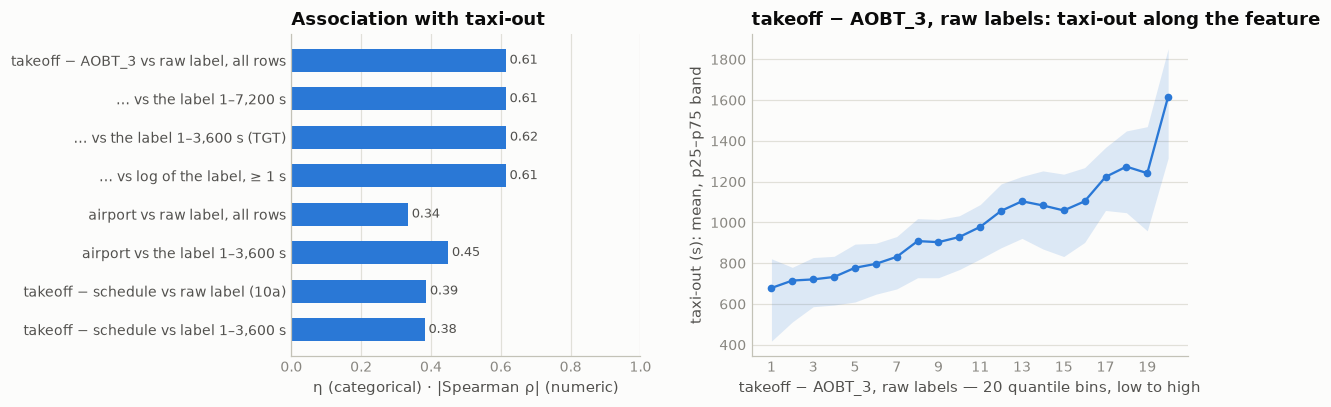

In [9]:
# correlation with the target — turned around: the target in its forms against its two best stand-ins, the anchor gap (ρ) and the airport (η),
# and against 10a's gauge. Raw labels over every departure, the notebook's 1–3,600 s window, a 7,200 s ceiling, the log: what the tail does to a marginal measure
RAW1 = f"(SELECT * FROM {RAWDEP} WHERE TAXITIME_SEC_mvt >= 1)"
RAW72 = f"(SELECT * FROM {RAWDEP} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 7200)"
ANCHOR = "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)"
a = target_assoc([("takeoff − AOBT_3 vs raw label, all rows", "num", ANCHOR, 1, RAWDEP),
                  ("… vs the label 1–7,200 s", "num", ANCHOR, 1, RAW72),
                  ("… vs the label 1–3,600 s (TGT)", "num", ANCHOR),
                  ("… vs log of the label, ≥ 1 s", "num", ANCHOR, 1, RAW1, "ln(TAXITIME_SEC_mvt)"),
                  ("airport vs raw label, all rows", "cat", "ADEP_mvt", 1, RAWDEP),
                  ("airport vs the label 1–3,600 s", "cat", "ADEP_mvt"),
                  ("takeoff − schedule vs raw label (10a)", "num", "gap_s", 1, RAWDEP),
                  ("takeoff − schedule vs label 1–3,600 s", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)")])
assoc_chart(a, ANCHOR, kind="num", src=RAWDEP, title="takeoff − AOBT_3, raw labels")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Integer seconds, the exact difference of the two stamps, blank exactly where we predict** | `INTEGER`; equal to takeoff − off-block (in-block − landing on arrivals) on all 4,857,331 rows of both files, no sub-second stamps; null on 344,841 of 344,841 ranking departures and on one training arrival; 5,176 distinct values. Range −12 to 131,167 s on training departures, −2,652 to 604,797 on arrivals | nothing is rounded or estimated: the label is the two stamps, and §9's hidden endpoint is the whole problem |
| **The body: a right-skewed quarter of an hour** | all ten hubs on 1–3,600 s: mean 981 s, median 911, sd 388; raw p01 291, p25 719, p75 1,188, p99 2,339. Hub means on the window from LSZH 741 to EGLL 1,354; sd 292 (LSZH) to 443 (LIRF) | the shape the association cells and ladders of §1–§13 have been working on |
| **The tails: 0.2% of rows, half the squared error** | all ten hubs: raw sd 546 against 388 on the window, p99.9 4,501 s. Rows over an hour: 3,542 at 1–2 h (0.17% of rows, 8.1% of the squared error about the hub means), 550 at 2–12 h (14.8%), **34 over 12 h (31.7%)** — 4,126 rows, 54.6%. The worst 1% of rows carry 63% of it, against 22% on the window. LIRF: sd 1,332 raw, 443 on the window; its rows over an hour own 88.7% of its squared error. Of the rows over 2 h, 82–91% are Fiumicino's and 81–97% have neither plan nor anchor | RMSE is the tail's metric. The window is the right place to measure *association*; the score has to be measured on the labels as delivered |
| **On the holdout, four rows are more than half the RMSE** | Nov+Dec, 328,009 departures, the airport mean fit on Jan–Oct raw labels: 496.5 s. By band, what each adds to it: 13–3,600 s (99.83% of rows) 358.9 s; 3,601–7,200 (422 rows) 125.5; 2–12 h (57 rows) 164.4; **over 12 h (4 rows) 273.5**. The same predictions score 380.5 on labels up to 7,200 s and 359.3 on the window | the 357 s the sweep has been improving is the floor; what sits on it is decided by a few dozen rows — `VALIDATION/archive/FINDINGS_20260907.md` §2 in the notebook's own numbers |
| **The band between one and two hours is mostly 10a's defect on rows *with* a plan — and the anchor cannot see it** | LIRF's 1,487 rows: 79% have a plan, 84% carry a block stamp within 5 min of the schedule (41% on its clean rows), the plan's `AOBT_3` sits a median 3,355 s *after* the block stamp, takeoff − `AOBT_3` is 1,078 s where the label is 4,561, and 0% of anchors are within 10 min of the label. EGLL 691, EDDF 73, EDDM 59, LSZH 20: `AOBT_3` 2,768–3,568 s after the block, 0–19% within 10 min. Label − anchor gap in the band: p10 1,015, median 3,057, p90 4,446 s, against −363 / −52 / +306 on the window. The two real ones: LTFM 773 (59% on days whose median taxi passed 1,500 s — February's snow) and EHAM 79 (83% within 10 min, 5 January) | an off-block stamp written an hour before the aircraft moved is unpredictable from the anchor, which is the model's strongest feature; only the pushback delay can hint at it — the next row |
| **At Fiumicino, a delayed flight's label carries its delay one time in ten** | departures with a plan, by the plan's pushback delay `AOBT_3` − schedule: 15–45 min, LIRF 43,184 rows, block = schedule on 12.4% (other hubs 2.4%), mean label 1,307 s over an anchor gap of 925 (others 1,039 over 955); 45–90 min, 7.3% (0.4%), 1,476 over 938, the label passing an hour on 7.8% (0.8%); 90–180 min 1.8% (0.1%). Under 15 min the two sides agree (59.5% vs 52.6%: a punctual pushback *is* within 5 min of the schedule) | label = anchor gap + pushback delay with probability ~10% at LIRF, and those rows sit inside the 1–3,600 s window as "clean" ones. Airport × pushback delay is how the model learns it — §10 saw the delay's gain without the mechanism |
| **Keeping the tail in training pays only through the features that see it** | training filter → predictor, scored on every raw label: airport alone 495.8 (fit 1–3,600) · 496.0 (1–7,200) · 496.5 (≥ 1) — a wash, the holdout's tail being thinner than the fit's (61 rows over 7,200 s in 328,009, 1.9 per 10,000, against 523 in 1,757,038, 3.0); airport × no-plan 495.8 · 488.9 · **475.0**; 10a's gauge 491.4 · 489.4 · **466.9**. LIRF 1,285.6 → 1,149.6. The window rows pay 2–4 s for the hedge (airport 357.3 → 359.3, the gauge 352.6 → 356.5). Negatives in or out: 466.8 vs 466.9 | the harness's `≥ 1, no ceiling` is right, and it is right *because* airport, no-plan and takeoff − schedule are in the model; `pipeline/train.py`'s 7,200 ceiling costs 22 s on the gauge and should be aligned |
| **The sweep's ladders on the labels as scored** | fit on labels ≥ 1: airport 496.5 → × 20 anchor bins **427.8** (302.5 on the window, §9's 293.5 with the tail in the fit) → × 10a's gauge 417.8 → × the pushback-delay band **411.4** (284.9 on the window, LIRF 1,136); the gauge alone 466.9, with the delay band 459.0 | every honest number in §7–§13 is a window number; on raw labels the same ladder sits 120–130 s higher, and the gap is the tail's, not the features' |
| **The loss rewards the mean** | airport-level fit on labels ≥ 1: mean 496.5 · median 498.8 · geometric mean 499.6 on every label; 359.3 · 360.0 · 361.6 on the window. Per hub the mean sits 24–183 s above the median (EDDF 24, LTFM 92, LIRF 183) and 40–134 s above the geometric mean | squared loss on the raw label: no log transform, no median objective — and no clipping of predictions at a plausible taxi, since the gauge's prediction for a corrupt row is the gap itself, hours |
| **The rows at or below zero cost nothing either way** | 388 training departures at or below zero (369 negative, 19 zero) and 370 at 1–12 s — 64.7% and 63.5% of them without a plan (§9: Zurich's helipad and the collapsed airliner stamps). On the holdout 41 + 37 rows, 0.03% + 0.03% of the squared error; in training or out, 466.8 vs 466.9 | §9's open question closed: no repair, no removal; they train where the label is ≥ 1 s, as the harness has it, and it does not matter |
| **2026 carries the corrupt slice, and January's is bigger** | Fiumicino departures without a plan: January 2025 60 rows (0.53% of LIRF's departures), 13 corrupt (21.7%); **January 2026 107 rows (0.97%)** — 23 corrupt expected at January's rate, 32 at the year's 29.5%; July 2025 337 rows (2.22%), 84 corrupt (24.9%); **July 2026 276 (1.74%)** — 69 / 81 expected. 2025's monthly share never fell below 21.7% | the slice is 178% of its January 2025 size and 82% of July's, against break-evens of 7.4% and 34.2% of 2025's rate (`VALIDATION/archive/FINDINGS_20260907.md` §3): the tail bet holds in both months, and the gauge matters more in January 2026 than it did in January 2025 |
| **The arrival half's corruption is another defect — and it is also there in 2026** | 141 training arrivals over 7,200 s (119 at LIRF), 6 without a plan, the block stamp within 5 min of the schedule on 12.8%, a median 8,043 s *after* the plan's in-block `ARVT_3`: an in-block stamp hours late, not the timetable written as a stamp. 27 in the ranking file (17 LIRF, none without a plan), the same shape. LIRF arrivals per 10,000: January 1.77 → 3.62, July 8.56 → 8.23. Across the 120 hub × month cells of 2025 the two phases' rates correlate 0.85 (LIRF's twelve months alone 0.52) | not the gauge's mechanism, so no direct read on the departure rate — but whatever produces bad stamps at Fiumicino was running in both scored months at 2025's level or above |
| **The label's proxy says 2026 sits on 2025, with three moves** | median takeoff − `AOBT_3`, 2025 → 2026: EDDF 907 → 954 (January), 896 → 929 (July); EHAM 812 → 863, 900 → 964; LFPG 898 → 959 (July); EGLL 1,376 → 1,321 (July); the other six within ±18 s. Arrivals' median taxi-in: EHAM July 412 → 335, EDDF July 565 → 502, EGLL January 426 → 473 | the moves are where §13 saw a new pier (Frankfurt) and §12 saw configurations swing (Schiphol); the anchor gap carries them into the prediction because it is a feature — the calendar cannot |
| **The month moves each hub by 50–209 s, and the scored months sit at the extremes** | monthly means on the window: LIRF 1,020 (February) → 1,229 (July), EDDM 766 (March) → 944 (December), LFPG 929 → 1,093 (November), LTFM 986 → 1,141 (February, the snow), EHAM 716 (June) → 846 (March), LEBL 887 (January) → 1,008 (July), EGLL 1,307 → 1,402 (July); LSZH 723 → 773 (January). July is the high month at LIRF, LEBL and EGLL; January the high at LSZH and the low at LEBL | §8 read the calendar as flat because the hubs cancel; per hub it is a ±100 s effect with 2025's own January and July in the file, so hub × month is a real feature — but a weather month (LTFM's February) does not transfer |
| **What the tail does to a marginal measure** | takeoff − `AOBT_3`: ρ 0.615 on every label form (r 0.527–0.545) — the corrupt rows have no anchor, so its correlation never sees them; the airport's η 0.450 on the window, **0.335** raw; takeoff − schedule r 0.190 on the window, **0.232** raw — the one feature whose correlation *rises* with the tail, 10a's gauge | the notebook's window is the right place for association (a raw η is a statement about 34 rows); the raw-label ladders above are where the tail is measured |

**Decisions**

| issue | decision | why |
|---|---|---|
| the training label filter | **every label from 1 s up, no ceiling** — as the harness has it (`MAX_TAXI_SEC = 200_000`); `pipeline/train.py`'s 7,200 ceiling to be aligned | 489.4 → 466.9 on the gauge ladder; the tail pays only through the features that see it, so those features (airport, no-plan, takeoff − schedule, the pushback delay) must be in the model |
| the rows at or below zero, and §9's 289 collapsed stamps | out below 1 s, in from 1 s, no repair | 0.06% of the holdout's squared error; 466.8 vs 466.9 either way |
| the objective | **squared loss on the raw label**; no log transform; no ceiling on predictions | mean 496.5 < median 498.8 < geometric mean 499.6; a corrupt row's best prediction is hours |
| the band between one and two hours | no repair; the pushback delay per airport as the feature that sees it (`AOBT_3` − schedule, kept by §10) | 417.8 → 411.4 on the raw ladder, 294.5 → 284.9 on the window; the mechanism is 10a's, on rows with a plan |
| the statistics window | 1–3,600 s stays for association cells and feature ladders; raw labels for anything that touches the score | sd 388 against 546; a raw η is a statement about 34 rows |
| the month | hub × month as a feature, no weather memory | 50–209 s per hub; 2025's own January and July are in the file; LTFM's February was snow |
| the 2026 corruption | no hedge beyond the tail in training and the gauge | the slice is 178% / 82% of 2025's in the two months, both far above break-even |

**State after §14** — unchanged: the label is never touched. 344,841 ranking departures null before and after; every training value as delivered.

**Use in modeling.** Fit for the mean of the raw label with squared loss, on every training departure
with a label ≥ 1 s, with no ceiling on labels or predictions. The score is the window's 357 s plus
what a few dozen rows add, and the model reaches those rows only through the features that describe
them: the airport, the no-plan flag, takeoff − schedule and the pushback delay `AOBT_3` − schedule
per airport (§10, §10a), and hub × month. Expect the tail to be at least 2025's size in both scored
months. In the closing matrix the target is the last row and column, on the window; the tail's
associations are this section's correlation cell.


## 15 · `LOBT_flt` — the plan's last off-block time

The first of the flight plan's clocks: the **last known off-block time** the Network Manager held
for the flight — the estimated off-block of the plan's most recent filing. On departure rows it is
the plan's own word on when our flight would leave the stand; on arrival rows it is the off-block
at the origin. It survives in the ranking file wherever a plan was matched, so takeoff − LOBT is
computable on every departure we predict that has a plan. The section asks what the clock is worth
on its own, how it relates to the plan's three other clocks (the initial `IOBT_flt`, the M1
estimate `EOBT_1_flt` and the flown `AOBT_3_flt`, each with its own section) and to the timetable,
and what the two delays it separates — the one the airline filed and the one it did not — buy on
top of §9's anchor.

| step | question | what came out |
|---|---|---|
| **census** | present where; which grid; against the schedule; the rows where it sits after the takeoff | wherever a plan is, bar 46 + 7 empty blocks; a whole minute on the 5-minute grid; the schedule on 74%, 20 min later on the rest; after the takeoff on 0.83% — stale plans of early leavers |
| **the plan's clocks** | last against initial, M1 and actual | "last known" is the initial one on 99.45% of departures: the day's delay is never refiled; the pushback comes a median 4 min after it, before it on 30% |
| **the two delays** | the filed delay LOBT − schedule and the unfiled delay `AOBT_3` − LOBT against taxi-out — and against the anchor's error | the unfiled delay moves taxi-out by 5 minutes across its bands and the anchor's error by 11: where the two clocks disagree the truth lies between |
| **signal** | honest ladders: the gap alone; the two delays on §9's anchor against §10's schedule- and `EOBT_1`-based ones; the flags; 2026 against 2025 | 301.2 alone; the unfiled delay takes the anchor 293.5 → 261.0, 7 s better than the schedule's, 4 s behind `EOBT_1`'s; the filed delay and the flags nothing; 2026 sits on 2025 |
| **closing state** | what §2's twin layers fill | 1,898 + 479 departures get their twin's clock; 0.99% / 1.40% stay without one |


In [3]:
# census by file × phase: present wherever a plan was matched, bar a few dozen rows whose plan block is empty behind its ID; a whole
# minute on the timetable's grid; then the plan's last off-block against the schedule, and the rows where it sits after the takeoff itself
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("LOBT_flt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (LOBT_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (LOBT_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           round(100.0*count(*) FILTER (extract(second FROM LOBT_flt) = 0)/count(LOBT_flt), 1) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM LOBT_flt) % 5 = 0 AND extract(second FROM LOBT_flt) = 0)/count(LOBT_flt), 1) pct_on_5min_grid,
           count(DISTINCT LOBT_flt) n_unique, strftime(min(LOBT_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(LOBT_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows with a FLIGHT_ID but no LOBT — an empty plan block behind the ID (both files):")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(IOBT_flt) iobt, count(EOBT_1_flt) eobt1, count(AOBT_3_flt) aobt3, count(ARVT_3_flt) arvt3,
           count(CALLSIGN_flt) callsign, count(AIRCRAFT_OPERATOR_flt) operator_, count(MARKET_SEGMENT_flt) segment,
           string_agg(DISTINCT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt END, ' ') dep_hubs
    FROM {BOTH} WHERE FLIGHT_ID_mvt IS NOT NULL AND LOBT_flt IS NULL GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().fillna("").to_string(index=False))

print("\ndepartures with a plan: the last off-block against the schedule (training):")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (LOBT_flt = SCHED_TIME_UTC_mvt)/count(*), 1) pct_equal_to_schedule,
           round(100.0*count(*) FILTER (LOBT_flt > SCHED_TIME_UTC_mvt)/count(*) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) pct_later_when_different,
           round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60.0, 0.5) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) med_min_later_when_different,
           round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60.0, 0.9) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) p90_when_different,
           round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(*), 2) pct_after_the_takeoff
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe plan's last off-block after the actual takeoff — who, and is the plan stale or wrong (training departures):")
print(con.sql(f"""
    SELECT count(*) n, round(quantile_cont(epoch(LOBT_flt - MVT_TIME_UTC_mvt)/60.0, 0.5), 1) med_min_after_takeoff,
           round(quantile_cont(epoch(LOBT_flt - MVT_TIME_UTC_mvt)/60.0, 0.9), 1) p90_min,
           round(100.0*count(*) FILTER (LOBT_flt = IOBT_flt)/count(*), 1) pct_never_refiled,
           round(100.0*count(*) FILTER (abs(epoch(AOBT_3_flt - BLOCK_TIME_UTC_mvt)) <= 300)/count(AOBT_3_flt), 1) pct_aobt3_within_5min_of_block,
           round(100.0*count(*) FILTER (AOBT_3_flt > MVT_TIME_UTC_mvt)/count(AOBT_3_flt), 1) pct_aobt3_also_after_takeoff,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt > MVT_TIME_UTC_mvt""").df().to_string(index=False))
print(con.sql(f"""
    SELECT coalesce(MARKET_SEGMENT_flt, '∅') segment, count(*) n, round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(*), 2) pct_lobt_after_takeoff,
           round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_lobt_after_aobt3,
           round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(*), 2) pct_refiled
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))


LOBT_flt by file × phase:


     src  ph       n  n_null  no_plan  null_with_an_id  pct_on_minute  pct_on_5min_grid  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506             6943           97.9              90.7    266771 2025-01-01 00:00 2025-12-31 23:02
training DEP 2085047   22470    22424               46           99.7              94.9    186897 2025-01-01 00:20 2025-12-31 23:40
 ranking ARR  344693    2552     1409             1143           97.9              90.7     44714 2026-01-01 00:00 2026-07-31 22:55
 ranking DEP  344841    5290     5283                7           99.8              94.3     32779 2026-01-01 00:04 2026-07-31 23:30

the rows with a FLIGHT_ID but no LOBT — an empty plan block behind the ID (both files):
     src  ph    n  iobt  eobt1  aobt3  arvt3  callsign  operator_  segment                      dep_hubs
training ARR 6943     0      0      0      0         0          0        0                              
training DEP   46     0      0      0    

      segment       n  pct_lobt_after_takeoff  pct_lobt_after_aobt3  pct_refiled
     Mainline 1325748                    0.49                  29.6         0.59
      Lowcost  399482                    0.93                  27.7         0.56
     Regional  210865                    0.53                  26.7         0.16
        Cargo   60021                    3.68                  42.9         0.69
     Business   44498                    6.73                  39.0         0.63
Non-Scheduled   14577                    2.33                  27.2         0.50
        Other    6673                    3.21                  37.5         0.57
     Military     713                    6.45                  34.2         0.56


In [4]:
# the last off-block against the plan's other clocks: how often it equals the initial one, the M1 estimate and the actual; the gaps
# in minutes; the pattern of the three filed clocks per flight; and the same per hub (training departures with a plan)
print("LOBT against the plan's other clocks — training departures with a plan:")
print(con.sql(f"""
    SELECT count(*) n,
           round(100.0*count(*) FILTER (LOBT_flt = IOBT_flt)/count(*), 2) eq_iobt, round(100.0*count(*) FILTER (LOBT_flt > IOBT_flt)/count(*), 2) after_iobt,
           round(100.0*count(*) FILTER (LOBT_flt < IOBT_flt)/count(*), 2) before_iobt,
           round(100.0*count(*) FILTER (LOBT_flt = EOBT_1_flt)/count(*), 1) eq_eobt1, round(100.0*count(*) FILTER (LOBT_flt < EOBT_1_flt)/count(*), 1) before_eobt1,
           round(100.0*count(*) FILTER (LOBT_flt > EOBT_1_flt)/count(*), 1) after_eobt1,
           round(100.0*count(*) FILTER (LOBT_flt <= AOBT_3_flt)/count(AOBT_3_flt), 1) at_or_before_aobt3, round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) after_aobt3,
           count(*) FILTER (IOBT_flt IS NULL) iobt_null, count(*) FILTER (EOBT_1_flt IS NULL) eobt1_null, count(*) FILTER (AOBT_3_flt IS NULL) aobt3_null
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):")
for name, expr in [("LOBT − IOBT, the refile", "epoch(LOBT_flt - IOBT_flt)/60"),
                   ("   … where the two differ", "CASE WHEN LOBT_flt != IOBT_flt THEN epoch(LOBT_flt - IOBT_flt)/60 END"),
                   ("LOBT − schedule, the filed delay", "epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60"),
                   ("EOBT_1 − LOBT", "epoch(EOBT_1_flt - LOBT_flt)/60"),
                   ("   … where the two differ", "CASE WHEN EOBT_1_flt != LOBT_flt THEN epoch(EOBT_1_flt - LOBT_flt)/60 END"),
                   ("AOBT_3 − LOBT, the unfiled delay", "epoch(AOBT_3_flt - LOBT_flt)/60"),
                   ("off-block − LOBT (hidden)", "epoch(BLOCK_TIME_UTC_mvt - LOBT_flt)/60"),
                   ("takeoff − LOBT", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60")]:
    q, n = con.sql(f"SELECT quantile_cont({expr}, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]), count({expr}) FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL").fetchone()
    print(f"  {name:34s} n = {n:>9,}   " + "  ".join(f"{x:6.1f}" for x in q))

print("\nthe three filed clocks per flight — which agree (training departures 1–3,600 s with all three):")
print(con.sql(f"""
    SELECT CASE WHEN IOBT_flt = LOBT_flt AND LOBT_flt = EOBT_1_flt THEN '1 · all three equal'
                WHEN IOBT_flt = LOBT_flt THEN '2 · IOBT = LOBT, EOBT_1 differs' WHEN LOBT_flt = EOBT_1_flt THEN '3 · LOBT = EOBT_1, IOBT differs'
                WHEN IOBT_flt = EOBT_1_flt THEN '4 · IOBT = EOBT_1, LOBT differs' ELSE '5 · all different' END pattern,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(quantile_cont(epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)/60, 0.5), 1) med_pushback_delay_min,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5), 1) med_eobt1_minus_lobt, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM {TGT} WHERE LOBT_flt IS NOT NULL AND IOBT_flt IS NOT NULL AND EOBT_1_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nper hub — refiled share, early pushers, the unfiled delay and takeoff − LOBT (training departures 1–3,600 s with a plan):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(*), 2) pct_refiled,
           round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_pushed_before_lobt,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.1), 1) unfiled_p10, round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) unfiled_p50,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.9), 1) unfiled_p90,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.5), 1) med_takeoff_minus_lobt
    FROM {TGT} WHERE LOBT_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


LOBT against the plan's other clocks — training departures with a plan:
      n  eq_iobt  after_iobt  before_iobt  eq_eobt1  before_eobt1  after_eobt1  at_or_before_aobt3  after_aobt3  iobt_null  eobt1_null  aobt3_null
2062577    99.45        0.29         0.26      70.0          11.7         18.3                70.5         29.5          0           0           0

the gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):
  LOBT − IOBT, the refile            n = 2,062,577      0.0     0.0     0.0     0.0     0.0     0.0     0.0
     … where the two differ          n =    11,267    -14.1    -8.3    -4.0     1.0     9.2    15.4    42.2


  LOBT − schedule, the filed delay   n = 2,062,577    -10.0     0.0     0.0     0.0     0.0    25.0   120.0
  EOBT_1 − LOBT                      n = 2,062,577    -15.0    -5.0     0.0     0.0     0.0     4.0    21.0


     … where the two differ          n =   618,141    -20.0   -10.0    -9.0    -4.0     6.0    10.0    35.0


  AOBT_3 − LOBT, the unfiled delay   n = 2,062,577    -18.0    -7.0    -2.0     4.0    11.0    20.0    46.0


  off-block − LOBT (hidden)          n = 2,062,577    -14.0    -4.5    -0.1     4.2    11.0    18.9    43.7


  takeoff − LOBT                     n = 2,062,577      0.9     9.4    14.2    20.6    28.4    38.0    64.0

the three filed clocks per flight — which agree (training departures 1–3,600 s with all three):


                        pattern       n   pct  med_pushback_delay_min  med_eobt1_minus_lobt  med_taxi
            1 · all three equal 1431676 69.52                     6.0                   0.0     906.0
2 · IOBT = LOBT, EOBT_1 differs  616581 29.94                    11.0                  -4.0     945.0
3 · LOBT = EOBT_1, IOBT differs   10964  0.53                    17.0                   0.0    1061.0
4 · IOBT = EOBT_1, LOBT differs      38  0.00                    29.0                   0.8    1152.0
              5 · all different     142  0.01                    23.5                  -0.6    1121.0

per hub — refiled share, early pushers, the unfiled delay and takeoff − LOBT (training departures 1–3,600 s with a plan):


 hub      n  pct_refiled  pct_pushed_before_lobt  unfiled_p10  unfiled_p50  unfiled_p90  med_takeoff_minus_lobt
EDDF 228115         0.36                    23.2         -4.0          5.0         21.0                    20.5
EDDM 166276         0.12                    25.5         -5.0          5.0         21.0                    17.0
EGLL 237449         0.55                    39.7         -9.0          1.0         17.0                    25.0
EHAM 243794         0.02                    26.3         -5.0          4.0         18.0                    19.3
LEBL 177837         0.90                    25.7         -6.0          5.0         21.0                    19.5
LEMD 211295         0.54                    22.7         -4.0          5.0         20.0                    21.6
LFPG 235375         0.06                    27.0         -6.0          5.0         25.0                    21.9
LIRF 157994         0.14                    26.3         -6.0          5.0         21.0                 

taxi-out by the refile LOBT − IOBT (training departures 1–3,600 s with a plan):


               refile       n   pct  mean_taxi  med_taxi  med_unfiled_delay_min
  1 · refiled earlier    5204  0.25     1127.0    1023.0                   13.0
      2 · not refiled 2048257 99.46      981.0     911.0                    4.0
3 · later by ≤ 15 min    4769  0.23     1142.0    1043.0                    6.4
        4 · 15–60 min    1135  0.06     1231.0    1159.0                    5.2
         5 · over 1 h      36  0.00     1420.0    1219.0                    4.6

taxi-out by the unfiled delay AOBT_3 − LOBT — and the anchor's error, mean label minus mean takeoff − AOBT_3 (same rows, with an anchor):


     unfiled_delay      n  pct  mean_taxi  med_taxi  mean_anchor_gap  label_minus_anchor
1 · > 30 min early   3088  0.1     1000.0     892.0           2887.0             -1887.0
   2 · 10–30 early  96274  4.7      880.0     833.0           1258.0              -378.0
    3 · 2–10 early 347173 16.9      902.0     851.0           1093.0              -191.0
4 · on the plan ±2 434416 21.1      926.0     889.0           1004.0               -79.0
     5 · 2–10 late 614562 29.8      965.0     909.0            955.0                10.0
    6 · 10–30 late 483607 23.5     1085.0    1017.0            950.0               136.0
    7 · 30–60 late  77532  3.8     1239.0    1117.0            944.0               295.0
 8 · over 1 h late   2749  0.1     1695.0    1507.0            229.0              1466.0


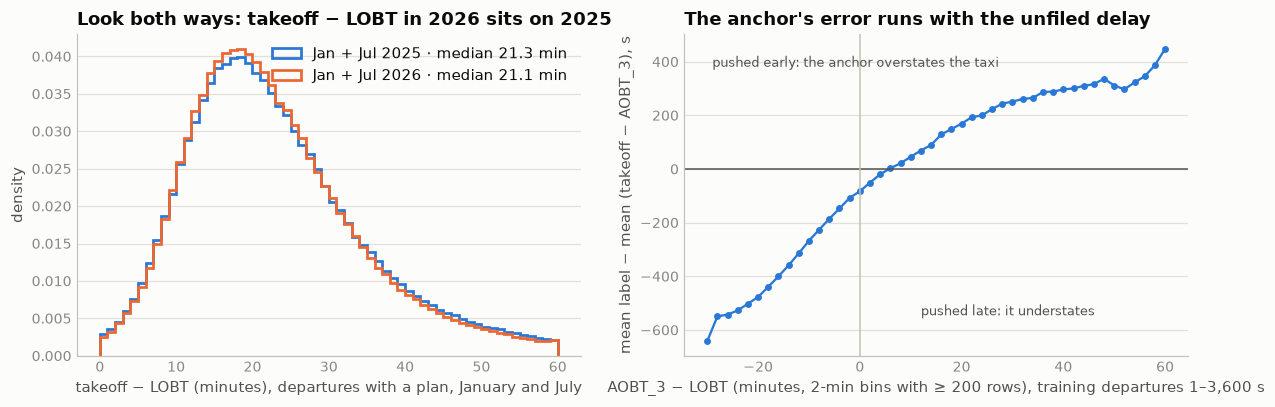

In [5]:
# the two delays the clock measures, and the anchor's error along the unfiled one: taxi-out by band of the refile and of the unfiled delay,
# with the mean label against the mean anchor gap; the picture — the feature in 2026 against 2025, and the anchor's error along the delay
print("taxi-out by the refile LOBT − IOBT (training departures 1–3,600 s with a plan):")
print(con.sql(f"""
    SELECT CASE WHEN d < 0 THEN '1 · refiled earlier' WHEN d = 0 THEN '2 · not refiled' WHEN d <= 15 THEN '3 · later by ≤ 15 min' WHEN d <= 60 THEN '4 · 15–60 min' ELSE '5 · over 1 h' END refile,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) med_unfiled_delay_min
    FROM (SELECT *, epoch(LOBT_flt - IOBT_flt)/60 d FROM {TGT} WHERE LOBT_flt IS NOT NULL) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\ntaxi-out by the unfiled delay AOBT_3 − LOBT — and the anchor's error, mean label minus mean takeoff − AOBT_3 (same rows, with an anchor):")
print(con.sql(f"""
    SELECT CASE WHEN d < -30 THEN '1 · > 30 min early' WHEN d < -10 THEN '2 · 10–30 early' WHEN d < -2 THEN '3 · 2–10 early' WHEN d <= 2 THEN '4 · on the plan ±2' WHEN d <= 10 THEN '5 · 2–10 late'
                WHEN d <= 30 THEN '6 · 10–30 late' WHEN d <= 60 THEN '7 · 30–60 late' ELSE '8 · over 1 h late' END unfiled_delay,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi,
           round(avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))) mean_anchor_gap, round(avg(TAXITIME_SEC_mvt) - avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))) label_minus_anchor
    FROM (SELECT *, epoch(AOBT_3_flt - LOBT_flt)/60 d FROM {TGT} WHERE LOBT_flt IS NOT NULL AND AOBT_3_flt IS NOT NULL) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

lob_h = con.sql(f"""
    SELECT CASE WHEN src = 'training' THEN '2025' ELSE '2026' END yr, epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60.0 g
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7)""").df()
lob_e = con.sql(f"""
    SELECT round(epoch(AOBT_3_flt - LOBT_flt)/120.0) * 2 d, count(*) n, avg(TAXITIME_SEC_mvt) m, avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)) a
    FROM {TGT} WHERE LOBT_flt IS NOT NULL AND AOBT_3_flt IS NOT NULL GROUP BY 1 HAVING count(*) >= 200 AND d BETWEEN -30 AND 60 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for yr, col in [("2025", BLUE), ("2026", ORANGE)]:
    v = lob_h[lob_h.yr == yr].g
    a1.hist(v, bins=60, range=(0, 60), density=True, histtype="step", lw=1.8, color=col, label=f"Jan + Jul {yr} · median {v.median():.1f} min")
a1.set_title("Look both ways: takeoff − LOBT in 2026 sits on 2025")
a1.set_xlabel("takeoff − LOBT (minutes), departures with a plan, January and July")
a1.set_ylabel("density")
a1.legend(loc="upper right")
style(a1)
a2.plot(lob_e.d, lob_e.m - lob_e.a, "o-", color=BLUE, ms=3.5)
a2.axhline(0, color=INK2, lw=1)
a2.axvline(0, color=BASELINE, lw=1)
a2.set_title("The anchor's error runs with the unfiled delay")
a2.set_xlabel("AOBT_3 − LOBT (minutes, 2-min bins with ≥ 200 rows), training departures 1–3,600 s")
a2.set_ylabel("mean label − mean (takeoff − AOBT_3), s")
a2.text(-29, (lob_e.m - lob_e.a).max() * 0.85, "pushed early: the anchor overstates the taxi", fontsize=8.5, color=INK2)
a2.text(12, (lob_e.m - lob_e.a).min() * 0.85, "pushed late: it understates", fontsize=8.5, color=INK2)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# what the clock buys — honest ladders, fit Jan–Oct → Nov+Dec, quantile bins cut on the fit rows per airport, cell support ≥ 30 else the
# coarser rung: takeoff − LOBT alone; the two delays on top of §9's anchor, against §10's schedule- and EOBT_1-based ones; the flags.
# Then look both ways: the feature in the two scored months against their 2025 twins
con.sql(f"""
    CREATE OR REPLACE TABLE lob_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - LOBT_flt) g_lobt,
           epoch(AOBT_3_flt - LOBT_flt) unfiled, epoch(LOBT_flt - SCHED_TIME_UTC_mvt) filed,
           epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) un_sched, epoch(AOBT_3_flt - EOBT_1_flt) un_eobt1,
           CASE WHEN LOBT_flt IS NULL THEN NULL WHEN LOBT_flt != IOBT_flt THEN 1 ELSE 0 END refiled,
           CASE WHEN LOBT_flt IS NULL THEN NULL WHEN LOBT_flt > MVT_TIME_UTC_mvt THEN 1 ELSE 0 END lobt_after_takeoff
    FROM {TGT}""")


def lob_ladder(*bins):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}, -1) q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE lob_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM lob_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM lob_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE lob_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM lob_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN lob_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN lob_r{k}.c >= 30 THEN lob_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2)) FROM lob_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM lob_d WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × takeoff − LOBT, 20 bins", (("g_lobt", 20),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (("g_aobt3", 20),)),
                   ("anchor × AOBT_3 − LOBT, 5 bins — the unfiled delay", (("g_aobt3", 20), ("unfiled", 5))),
                   ("anchor × LOBT − schedule, 5 bins — the filed delay", (("g_aobt3", 20), ("filed", 5))),
                   ("anchor × unfiled × filed", (("g_aobt3", 20), ("unfiled", 5), ("filed", 5))),
                   ("anchor × AOBT_3 − schedule, 5 bins — §10's", (("g_aobt3", 20), ("un_sched", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 5 bins — §10's", (("g_aobt3", 20), ("un_eobt1", 5))),
                   ("anchor × unfiled × AOBT_3 − EOBT_1", (("g_aobt3", 20), ("unfiled", 5), ("un_eobt1", 5))),
                   ("anchor × refiled flag", (("g_aobt3", 20), ("refiled", 0))),
                   ("anchor × LOBT-after-takeoff flag", (("g_aobt3", 20), ("lobt_after_takeoff", 0))),
                   ("anchor × unfiled × refiled flag", (("g_aobt3", 20), ("unfiled", 5), ("refiled", 0)))]:
    print(f"  {name:56s} {lob_ladder(*bins):6.1f}")

print("\nlook both ways — the feature in the scored months against their 2025 twins (all departures):")
print(con.sql(f"""
    SELECT yr, mon, count(*) n, round(100.0*count(LOBT_flt)/count(*), 2) pct_with_lobt,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.5), 1) med_takeoff_minus_lobt, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.9), 1) p90,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) med_unfiled_delay, round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60, 0.9), 1) p90_filed_delay,
           round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(LOBT_flt), 2) pct_refiled,
           round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(LOBT_flt), 2) pct_lobt_after_takeoff
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP') WHERE mon IN (1, 7)
    GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))


honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                   357.3
  airport × takeoff − LOBT, 20 bins                         301.2


  airport × takeoff − AOBT_3, 20 bins — §9's anchor         293.5


  anchor × AOBT_3 − LOBT, 5 bins — the unfiled delay        261.0


  anchor × LOBT − schedule, 5 bins — the filed delay        292.4


  anchor × unfiled × filed                                  259.2


...

  anchor × AOBT_3 − EOBT_1, 5 bins — §10's                  257.1


  anchor × unfiled × AOBT_3 − EOBT_1                        255.3
  anchor × refiled flag                                     293.0


  anchor × LOBT-after-takeoff flag                          293.1


  anchor × unfiled × refiled flag                           260.3

look both ways — the feature in the scored months against their 2025 twins (all departures):


  yr  mon      n  pct_with_lobt  med_takeoff_minus_lobt  p90  med_unfiled_delay  p90_filed_delay  pct_refiled  pct_lobt_after_takeoff
2025    1 153706          99.07                    19.0 36.9                2.0             25.0         0.19                    1.23
2026    1 152719          98.39                    20.9 40.7                3.0             35.0         0.24                    1.00
2025    7 190713          97.94                    23.2 44.4                7.0             35.0         0.71                    0.50
2026    7 192122          98.52                    21.6 40.0                5.0             30.0         0.96                    0.51


In [7]:
# closing state — the column after §15: nothing of its own repaired; §2's twin layers hand the departures they recover their twin's
# whole plan block, this clock included. Before → after per file, and the final distribution of takeoff − LOBT
TWINS = (f"(SELECT MVT_ID_mvt, LOBT_flt lobt_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
         f"UNION ALL SELECT MVT_ID_mvt, LOBT_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (LOBT_flt IS NULL) null_before, count(*) FILTER (coalesce(LOBT_flt, lobt_twin) IS NULL) null_after,
           count(*) FILTER (LOBT_flt IS NULL AND lobt_twin IS NOT NULL) filled_by_twins,
           round(100.0*count(*) FILTER (coalesce(LOBT_flt, lobt_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.1), 1) p10_takeoff_minus_lobt_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.5), 1) p50, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINS} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nevery remaining null is a departure without a plan (or with an empty plan block behind its ID): nothing else to fill from")


     src       n  null_before  null_after  filled_by_twins  pct_null_after  p10_takeoff_minus_lobt_after  p50  p90
training 2085047        22470       20572             1898            0.99                           9.4 20.6 38.0
 ranking  344841         5290        4811              479            1.40                          10.0 21.1 40.2

every remaining null is a departure without a plan (or with an empty plan block behind its ID): nothing else to fill from


                          feature        kind  n / levels  pearson_r  spearman_ρ     η
           LOBT epoch — the trend     numeric     2059401      0.011       0.015      
                   takeoff − LOBT     numeric     2059401      0.499       0.507      
AOBT_3 − LOBT — the unfiled delay     numeric     2059401      0.230       0.196      
LOBT − schedule — the filed delay     numeric     2059401      0.028       0.020      
         LOBT − IOBT — the refile     numeric     2059401      0.015       0.024      
            refiled (LOBT ≠ IOBT) categorical           3                        0.032
           LOBT after the takeoff categorical           3                        0.073
                     LOBT missing categorical           2                        0.007


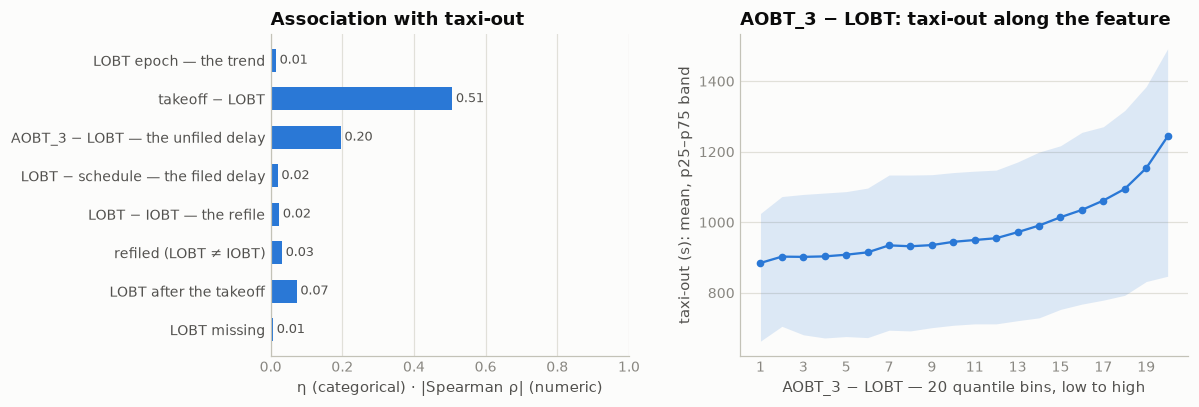

In [8]:
# correlation with the target: the stamp itself is a calendar; its model-facing forms are the gap to takeoff, the two delays it splits
# the pushback delay into, the refile, and the two flags
a = target_assoc([("LOBT epoch — the trend", "num", "epoch(LOBT_flt)"),
                  ("takeoff − LOBT", "num", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)"),
                  ("AOBT_3 − LOBT — the unfiled delay", "num", "epoch(AOBT_3_flt - LOBT_flt)"),
                  ("LOBT − schedule — the filed delay", "num", "epoch(LOBT_flt - SCHED_TIME_UTC_mvt)"),
                  ("LOBT − IOBT — the refile", "num", "epoch(LOBT_flt - IOBT_flt)"),
                  ("refiled (LOBT ≠ IOBT)", "cat", "LOBT_flt != IOBT_flt"),
                  ("LOBT after the takeoff", "cat", "LOBT_flt > MVT_TIME_UTC_mvt"),
                  ("LOBT missing", "cat", "LOBT_flt IS NULL")])
assoc_chart(a, "epoch(AOBT_3_flt - LOBT_flt)", kind="num", title="AOBT_3 − LOBT")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present wherever a plan is — and 53 IDs have nothing behind them** | null on 22,470 training departures: 22,424 without a plan and 46 with a `FLIGHT_ID` whose whole plan block is empty (no callsign, operator or clock); 5,290 in the ranking file (5,283 + 7). On arrivals the empty block is common: 6,943 + 1,143 rows | the "no plan" flag should read the block, not the ID — `LOBT_flt IS NULL` differs from `FLIGHT_ID_mvt IS NULL` on 53 departures; otherwise nothing to repair |
| **A whole minute on the timetable's grid, and usually the timetable itself** | 99.7% on the minute, 94.9% on the 5-minute grid, 186,897 distinct values; equal to the schedule on 74.0% of departures with a plan, and where different later 87.9% of the time, by a median 20 min (p90 70) | the plan's clock is the schedule plus the slot moved at filing — the *filed* delay, LOBT − schedule, zero on three flights in four |
| **"Last known" is the initial one: the day's delay is never refiled** | equal to `IOBT_flt` on 99.45%; 11,267 refiled rows (0.55%), moved by a median +1 min (p10 −8, p90 +15, p99 +42); refiled flights taxi longer either way — medians 1,023 s (earlier), 1,043 to 1,219 s (later), 911 not refiled; LTFM refiles most, 2.08%, EHAM 0.02%. `EOBT_1` is the clock that moves: it differs on 30.0% of departures, by a median −4 min | §2b's mechanism in the whole file: a matcher keyed on the plan's off-block loses the flights that ran late. `IOBT_flt` (§16) is this column's copy on 99.45% of rows; the differences belong to `EOBT_1`'s section |
| **The pushback comes 4 min after the plan's clock — and before it on 30%** | `AOBT_3` − LOBT p10 −7, median +4, p90 +20, p99 +46 min; the hidden off-block − LOBT −4.5 / +4.2 / +18.9; takeoff − LOBT 9.4 / 20.6 / 38.0, p99 64. Early pushers per hub: LSZH 12.9%, EDDF to LFPG 23–27%, EGLL 39.7%, **LTFM 52.0%** with a median unfiled delay of −1 min | the *unfiled* delay, `AOBT_3` − LOBT, is what happened on the day, and its sign and size are per hub |
| **After the actual takeoff on 0.83% — stale plans of flights that left early** | 17,133 rows, LOBT a median 2.6 min (p90 11) after the takeoff; 99.9% never refiled; `AOBT_3` within 5 min of the block stamp on 62.2% and itself after the takeoff on 1.4%; median label 624 s. Business 6.73%, Military 6.45%, Cargo 3.68%, Mainline 0.49% | the plan is the right flight, with a filed slot the aircraft did not wait for; takeoff − LOBT goes negative and says so. No repair — the flag adds 0.4 s on the ladder |
| **The anchor's error runs with the unfiled delay** | mean label − mean (takeoff − `AOBT_3`) by band of `AOBT_3` − LOBT: −378 s at 10–30 min early, −191 at 2–10 early, −79 on the plan, +10 at 2–10 late, +136 at 10–30, **+295 at 30–60 late**, +1,466 over an hour (2,749 rows, §14's defect); taxi-out itself 833 → 1,117 s median across the same bands | the two clocks are two estimates of the hidden off-block, and where they disagree the truth lies between: the further the pushback ran ahead of the plan the more the anchor overstates the taxi, the further behind the more it understates. This is the mechanism behind the gains §9 and §10 found in delay features |
| **The unfiled delay buys 32 s on the anchor; the filed delay nothing** | airport 357.3 → × takeoff − LOBT 301.2 (§9's number); the anchor 293.5 → × `AOBT_3` − LOBT **261.0** → × LOBT − schedule on top 259.2; the filed delay alone 292.4; §10's `AOBT_3` − schedule 268.4 and `AOBT_3` − `EOBT_1` 257.1; the unfiled delay × the `EOBT_1` one 255.3; the refiled flag 293.0, the after-takeoff flag 293.1 | LOBT's delay beats the schedule's by 7 s because the schedule's mixes the filed slot in; `EOBT_1`'s beats it by 4 s because that clock moved on the day. The feature is `AOBT_3` − LOBT per airport; LOBT − schedule, the refile and the flags are not |
| **2026 sits on 2025** | with a plan: January 99.07% → 98.39%, July 97.94% → 98.52%; takeoff − LOBT median January 19.0 → 20.9 min (p90 36.9 → 40.7), July 23.2 → 21.6 (44.4 → 40.0); the unfiled delay January 2 → 3 min, July 7 → 5; refiled 0.19 → 0.24%, 0.71 → 0.96%; after the takeoff 1.23 → 1.00%, 0.50 → 0.51% | January 2026 runs later than its twin and July earlier, as §10 saw on the schedule; the plan's clock carries the same drift into the prediction |
| Marginal | takeoff − LOBT ρ 0.507; the unfiled delay r 0.230 (ρ 0.196); the filed delay 0.028; the refile 0.015; the flags η 0.032 (refiled), 0.073 (after the takeoff), 0.007 (missing); the stamp 0.011 | the gap to takeoff is the label plus the unfiled delay, so it correlates like the anchor's cousin; the rest is small, and the ladder says the same |

**Decisions**

| issue | decision | why |
|---|---|---|
| the 46 + 7 IDs with an empty block | define "no plan" on the block (`LOBT_flt IS NULL`), not on the ID | the same on all but 53 departures, and the block is what the features read |
| the twin layers' clock | adopted: 1,898 training and 479 ranking departures take their twin's LOBT (§2) | the same leg's plan, verbatim |
| feature forms | takeoff − LOBT (the pipeline builds it) and **`AOBT_3` − LOBT per airport**; not LOBT − schedule, not the refile, not the after-takeoff flag | 261.0 against 293.5; 292.4, 293.0 and 293.1 for the rest |
| LOBT after the takeoff | no repair | a stale slot on the right flight; the negative gap is the information |
| which of the filed clocks carries the role | LOBT; `IOBT_flt` is its copy (§16 to confirm), `EOBT_1_flt` the one that moved | 99.45% equal; `EOBT_1` differs on 30.0% |

**State after §15** — the twin layers of §2, departures:

| `LOBT_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

takeoff − LOBT after, minutes: p10 9.4 / 10.0, median 20.6 / 21.1, p90 38.0 / 40.2 (training / ranking).

**Use in modeling.** Two features per airport: takeoff − LOBT, which `build_features` in
`pipeline/common.py` already makes, and the unfiled delay `AOBT_3` − LOBT, which it does not —
the second is the one that corrects the anchor. Take the clock from the twin layers where the raw
one is missing, and read "no plan" off the block. Nothing from LOBT − schedule, the refile or the
after-takeoff rows. In the closing matrix the column enters as epoch seconds, the twins' clock
included: 1.00 with the three movement clocks, 0.01 with the target — the fourth copy of the calendar.


## 16 · `CALLSIGN_flt` — the callsign the flight flew under

The identifier the flight plan carries for air traffic control: what the crew says on the radio and
what the controller reads off the strip. It is not quite the boarding-pass number of §3 — airlines
file an ATC callsign of their own, and for one departure in five it is a different number
altogether. The column arrives with the plan, so it is missing on exactly the rows §15's `LOBT_flt`
is, and it survives in the ranking file wherever a plan was matched.

Two questions make the section: what the callsign adds to the identity §3 already gave us, and what
its three-letter prefix is worth — the code of the carrier **operating** the flight, which matters
because `AIRCRAFT_OPERATOR_flt` beside it is a hash. That prefix is a derived form of this column,
not this column: §16 establishes it and hands it over, and **`AIRCRAFT_OPERATOR_flt`'s own section (§26)
owns what a model should do with an operator**. The verdict on `CALLSIGN_flt` itself is here, and it
is a short one.

A callsign prefix is *not* "the airline": a flight can be sold by several carriers and flown by one,
so the prefix names the operator while the ticket's flight number names the marketing airline. The
two diverge on 5,105 departures below, and 16 prefixes cover more than one operator — franchising
and wet-leasing, where even the operator is not one company.

| step | question | what came out |
|---|---|---|
| **census** | present where; in which spelling; and does it agree with the movement's number? | null exactly where the plan block is; 99.43% in ICAO spelling against the number's 78.03%; the same string on 73%, a different number on 19% |
| **the operator** | `AIRCRAFT_OPERATOR_flt` is a 64-character hash — does this column's prefix match what it hides? | one-to-one on 99.93% of departures, V = 0.9966, and the pair is the same in both files |
| **coverage** | which level still has a 2025 history in 2026 — the callsign, the number, or the prefix? | the prefix: 97.7% of 2026 departures on a level with ≥ 20 training departures, against 74.9% and 69.8% |
| **16a · the operator token, handed over** | can the token be filled where the plan is missing? | three layers take it from 2.07% of predictions to 0.65%; a fourth, read off the hash, is rejected |
| **signal** | what the callsign and the operator buy, and what survives §13's pier and §11's fleet | the operator is 21 s on the airport and 8.5 s on the anchor base — but 0.8 s once pier and type are in; its job is the identity's fallback rung |

In [4]:
# census: presence by file × phase, the spelling the plan uses against the movement's, and whether the two agree
display(cat_stats("CALLSIGN_flt"))
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"

print("CALLSIGN_flt by file × phase — and the rows where each identifier stands in for the other:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (CALLSIGN_flt IS NULL) n_null,
           round(100.0*count(*) FILTER (CALLSIGN_flt IS NULL)/count(*), 2) pct_null,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (CALLSIGN_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           count(*) FILTER (CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NULL) callsign_but_no_number,
           count(DISTINCT CALLSIGN_flt) n_unique,
           min(length(CALLSIGN_flt)) min_len, max(length(CALLSIGN_flt)) max_len
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe spelling, through §2c's id_style — the plan's callsign against the movement's number (departures with a plan):")
print(con.sql(f"""
    SELECT coalesce(style, '∅') style,
           count(*) FILTER (which = 'callsign' AND src = 'training') callsign_train,
           round(100.0*count(*) FILTER (which = 'callsign' AND src = 'training')
                 /sum(count(*) FILTER (which = 'callsign' AND src = 'training')) OVER (), 2) pct_train,
           count(*) FILTER (which = 'callsign' AND src = 'ranking') callsign_rank,
           round(100.0*count(*) FILTER (which = 'callsign' AND src = 'ranking')
                 /sum(count(*) FILTER (which = 'callsign' AND src = 'ranking')) OVER (), 2) pct_rank,
           count(*) FILTER (which = 'number' AND src = 'training') number_train,
           round(100.0*count(*) FILTER (which = 'number' AND src = 'training')
                 /sum(count(*) FILTER (which = 'number' AND src = 'training')) OVER (), 2) number_pct_train
    FROM (SELECT src, 'callsign' which, id_style(CALLSIGN_flt) style FROM {BOTH}
          WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL
          UNION ALL SELECT src, 'number', id_style(FLIGHT_mvt) FROM {BOTH}
          WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL)
    GROUP BY 1 ORDER BY callsign_train DESC""").df().to_string(index=False))

print("\ncallsign against FLIGHT_mvt, departures carrying both — equal, one flight in two spellings, or another number entirely:")
print(con.sql(f"""
    SELECT src, count(*) n,
           round(100.0*count(*) FILTER (CALLSIGN_flt = FLIGHT_mvt)/count(*), 2) pct_identical,
           round(100.0*count(*) FILTER (CALLSIGN_flt != FLIGHT_mvt AND id_tail(CALLSIGN_flt) IS NOT NULL
                 AND id_tail(CALLSIGN_flt) = id_tail(FLIGHT_mvt))/count(*), 2) pct_same_number_other_spelling,
           round(100.0*count(*) FILTER (CALLSIGN_flt != FLIGHT_mvt AND (id_tail(CALLSIGN_flt) IS NULL
                 OR id_tail(CALLSIGN_flt) IS DISTINCT FROM id_tail(FLIGHT_mvt)))/count(*), 2) pct_another_number
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NOT NULL
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe shape of the callsign, and how much each of the biggest operators uses a letter suffix (training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT CASE WHEN CALLSIGN_flt IS NULL THEN '∅'
                WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[0-9]+$') THEN 'digits (THY123)'
                WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[0-9]+[A-Z]+$') THEN 'digits + letters (THY43K)'
                WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[A-Z]') THEN 'letters after the prefix'
                ELSE 'other' END shape,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(avg(TAXITIME_SEC_mvt)) mean_taxi, mode(coalesce(MARKET_SEGMENT_flt, '∅')) segment
    FROM {TGT} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
print(con.sql(f"""
    SELECT id_prefix(CALLSIGN_flt) prefix, count(*) n,
           round(100.0*count(*) FILTER (regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[0-9]+[A-Z]+$'))/count(*)) pct_letter_suffix
    FROM {TGT} WHERE CALLSIGN_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

print("\nthe pairs whose numbers differ — one row per pair, busiest first (training departures):")
print(con.sql(f"""
    SELECT FLIGHT_mvt, CALLSIGN_flt, count(*) n, mode(ADEP_mvt) hub, mode(MARKET_SEGMENT_flt) segment
    FROM {T} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NOT NULL
      AND CALLSIGN_flt != FLIGHT_mvt
      AND (id_tail(CALLSIGN_flt) IS NULL OR id_tail(CALLSIGN_flt) IS DISTINCT FROM id_tail(FLIGHT_mvt))
    GROUP BY 1, 2 ORDER BY n DESC, FLIGHT_mvt LIMIT 8""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,73054
ranking 2026,689534,7842,1.14,35077


CALLSIGN_flt by file × phase — and the rows where each identifier stands in for the other:
     src  ph       n  n_null  pct_null  no_plan  null_with_an_id  callsign_but_no_number  n_unique  min_len  max_len
training ARR 2082750   15449      0.74     8506             6943                     186     45937        3        7
training DEP 2085047   22470      1.08    22424               46                     123     44824        3        7
 ranking ARR  344693    2552      0.74     1409             1143                      30     20708        3        7
 ranking DEP  344841    5290      1.53     5283                7                      35     20375        3        7

the spelling, through §2c's id_style — the plan's callsign against the movement's number (departures with a plan):
style  callsign_train  pct_train  callsign_rank  pct_rank  number_train  number_pct_train
 icao         2050784      99.43         337621     99.43       1609513             78.03
other           11352       

     src       n  pct_identical  pct_same_number_other_spelling  pct_another_number
training 2062454          72.82                            8.60               18.58
 ranking  339516          74.04                            7.84               18.12

the shape of the callsign, and how much each of the biggest operators uses a letter suffix (training departures, 1–3600 s):
                    shape       n   pct  mean_taxi  segment
digits + letters (THY43K) 1279784 61.51      947.0 Mainline
          digits (THY123)  767847 36.91     1042.0 Mainline
                        ∅   21132  1.02      953.0        ∅
 letters after the prefix    7924  0.38      727.0 Business
                    other    3846  0.18      896.0 Business
prefix      n  pct_letter_suffix
   DLH 222843               77.0
   THY 222083               80.0
   KLM 141460               60.0
   AFR 140207               67.0
   BAW 120094               62.0
   VLG  86644               88.0
   SWR  78012               89.0

FLIGHT_mvt CALLSIGN_flt   n  hub  segment
   SWR1266      SWR193T 365 LSZH Mainline
     LO264       LOT2PJ 364 EHAM Regional
   SWR1100       SWR2MC 364 LSZH Mainline
   SWR1210       SWR5CP 364 LSZH Mainline
   SWR1254       SWR1KV 364 LSZH Mainline
   SWR2110       SWR98P 364 LSZH Mainline
   SWR2804      SWR291X 364 LSZH Mainline
    KL0735       KLM163 363 EHAM Mainline


In [5]:
# the operator: AIRCRAFT_OPERATOR_flt is a 64-character hash — the callsign's three-letter prefix names what it hides
OPD = f"""(SELECT * FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
           WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND AIRCRAFT_OPERATOR_flt IS NOT NULL)"""

print("the busiest operators — the hash, abbreviated, and the prefixes its flights fly under (training departures):")
print(con.sql(f"""
    SELECT substr(AIRCRAFT_OPERATOR_flt, 1, 8) || '…' operator_hash, count(*) n,
           count(DISTINCT id_prefix(CALLSIGN_flt)) n_prefixes, mode(id_prefix(CALLSIGN_flt)) prefix,
           round(100.0*max(c)/count(*)) pct_on_that_prefix, mode(MARKET_SEGMENT_flt) segment
    FROM (SELECT *, count(*) OVER (PARTITION BY AIRCRAFT_OPERATOR_flt, id_prefix(CALLSIGN_flt)) c
          FROM {OPD} WHERE src = 'training')
    GROUP BY 1 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nis the pairing one-to-one? (training departures with both)")
print(con.sql(f"""
    SELECT count(*) n_prefixes, count(*) FILTER (n_ops > 1) prefixes_on_several_hashes,
           round(100.0*sum(n) FILTER (n_ops = 1)/sum(n), 2) pct_rows_on_a_1to1_prefix
    FROM (SELECT id_prefix(CALLSIGN_flt) p, count(*) n, count(DISTINCT AIRCRAFT_OPERATOR_flt) n_ops
          FROM {OPD} WHERE src = 'training' GROUP BY 1)""").df().to_string(index=False))
print(con.sql(f"""
    SELECT count(*) n_hashes, count(*) FILTER (n_pfx > 1) hashes_on_several_prefixes,
           round(100.0*sum(n) FILTER (n_pfx = 1)/sum(n), 2) pct_rows_on_a_1to1_hash
    FROM (SELECT AIRCRAFT_OPERATOR_flt h, count(*) n, count(DISTINCT id_prefix(CALLSIGN_flt)) n_pfx
          FROM {OPD} WHERE src = 'training' GROUP BY 1)""").df().to_string(index=False))
print("  Cramér's V, prefix × hash:", round(cramers_v("id_prefix(CALLSIGN_flt)", "AIRCRAFT_OPERATOR_flt",
                                                      f"(SELECT * FROM {OPD} WHERE src = 'training')", 30, 30), 4))

print("\nthe prefixes that are not one hash — every one of them (training departures):")
print(con.sql(f"""
    SELECT id_prefix(CALLSIGN_flt) prefix, count(*) n, count(DISTINCT AIRCRAFT_OPERATOR_flt) n_hashes,
           round(100.0*max(c)/count(*)) pct_top_hash, mode(ADEP_mvt) hub, mode(MARKET_SEGMENT_flt) segment
    FROM (SELECT *, count(*) OVER (PARTITION BY id_prefix(CALLSIGN_flt), AIRCRAFT_OPERATOR_flt) c
          FROM {OPD} WHERE src = 'training')
    GROUP BY 1 HAVING count(DISTINCT AIRCRAFT_OPERATOR_flt) > 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nand the one hash that is not one operator — the bucket the small operators land in (training, both phases):")
print(con.sql(f"""
    SELECT count(*) movements, count(*) FILTER (PHASE_mvt = 'DEP') departures,
           count(DISTINCT id_prefix(CALLSIGN_flt)) prefixes, count(DISTINCT CALLSIGN_flt) callsigns,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Business')/count(*)) pct_business,
           round(100.0*count(*) FILTER (PHASE_mvt = 'DEP')
                 /(SELECT count(*) FROM {T} WHERE PHASE_mvt = 'DEP' AND MARKET_SEGMENT_flt = 'Business')) pct_of_business_departures,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)
                 FILTER (PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) med_taxi_out
    FROM {T} WHERE AIRCRAFT_OPERATOR_flt = (
        SELECT h FROM (SELECT AIRCRAFT_OPERATOR_flt h, count(DISTINCT id_prefix(CALLSIGN_flt)) k
                       FROM {OPD} GROUP BY 1 ORDER BY k DESC LIMIT 1))""").df().to_string(index=False))

print("\nand is the hash the same code in both files? (if it were re-salted per file it could not be a category at all)")
print(con.sql(f"""
    WITH t AS (SELECT DISTINCT AIRCRAFT_OPERATOR_flt o FROM {T} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL),
         r AS (SELECT DISTINCT AIRCRAFT_OPERATOR_flt o FROM {R} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL)
    SELECT (SELECT count(*) FROM t) hashes_2025, (SELECT count(*) FROM r) hashes_2026,
           (SELECT count(*) FROM r WHERE o IN (SELECT o FROM t)) shared,
           (SELECT count(*) FROM r WHERE o NOT IN (SELECT o FROM t)) new_in_2026,
           (SELECT round(100.0*count(*) FILTER (AIRCRAFT_OPERATOR_flt IN (SELECT o FROM t))/count(*), 2)
            FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_OPERATOR_flt IS NOT NULL) pct_2026_rows_on_a_2025_hash""").df().to_string(index=False))
# the busiest hash per prefix, ties broken on the hash itself so the count is the same on every run
TOPH = """SELECT p, h, n FROM (SELECT id_prefix(CALLSIGN_flt) p, AIRCRAFT_OPERATOR_flt h, count(*) n
                               FROM {src} GROUP BY 1, 2)
           QUALIFY row_number() OVER (PARTITION BY p ORDER BY n DESC, h) = 1"""
print(con.sql(f"""
    WITH t AS ({TOPH.format(src=f"(SELECT * FROM {OPD} WHERE src = 'training')")}),
         r AS ({TOPH.format(src=f"(SELECT * FROM {OPD} WHERE src = 'ranking')")})
    SELECT count(*) prefixes_in_both_files, count(*) FILTER (t.h = r.h) same_hash_in_both,
           round(100.0*sum(r.n) FILTER (t.h = r.h)/sum(r.n), 2) pct_2026_rows_on_a_stable_pair
    FROM t JOIN r USING (p)""").df().to_string(index=False))

the busiest operators — the hash, abbreviated, and the prefixes its flights fly under (training departures):
operator_hash      n  n_prefixes prefix  pct_on_that_prefix  segment
    11dca3fa… 222892           1    DLH               100.0 Mainline
    95828822… 222550           1    THY               100.0 Mainline
    6251e0ee… 141486           1    KLM               100.0 Mainline
    aa14d43d… 140388           1    AFR               100.0 Mainline
    8e92b7d7… 120747           1    BAW               100.0 Mainline
    4c1c009e…  86686           1    VLG               100.0  Lowcost
    813bafd4…  78044           1    SWR               100.0 Mainline
    3ba01c3b…  69958           1    RYR               100.0  Lowcost

is the pairing one-to-one? (training departures with both)


 n_prefixes  prefixes_on_several_hashes  pct_rows_on_a_1to1_prefix
        976                          16                      99.93
 n_hashes  hashes_on_several_prefixes  pct_rows_on_a_1to1_hash
      676                           1                     98.9


  Cramér's V, prefix × hash: 0.9966

the prefixes that are not one hash — every one of them (training departures):
prefix   n  n_hashes  pct_top_hash  hub  segment
   HLF 316         2          96.0 LFPG    Cargo
   CBJ 252         2          78.0 LEMD Mainline
   SFG 144         2          88.0 LSZH Business
   AYN 131         2          98.0 LTFM Mainline
   AIH 118         2          97.0 EDDF Mainline
   BYD 117         2          56.0 LSZH Mainline
   ALE 107         2          51.0 LSZH Business
   LEJ  93         2          81.0 LSZH Business
   JSD  84         2          94.0 LEBL Business
   RXI  67         2          99.0 EGLL Mainline
   RMB  66         2          70.0 LTFM Business
   FXJ  19         2          68.0 LSZH Business
   PIZ  11         2          91.0 LSZH Business
   JSF  11         2          82.0 LEMD Business
   EMO   6         2          67.0 EHAM Business
   FLW   2         2          50.0 LEBL Business

and the one hash that is not one operator — the buc

 movements  departures  prefixes  callsigns  pct_business  pct_of_business_departures  med_taxi_out
     45275       22627       338       4545          61.0                        51.0         836.0

and is the hash the same code in both files? (if it were re-salted per file it could not be a category at all)
 hashes_2025  hashes_2026  shared  new_in_2026  pct_2026_rows_on_a_2025_hash
         682          587     557           30                         99.95
 prefixes_in_both_files  same_hash_in_both  pct_2026_rows_on_a_stable_pair
                    697                688                           99.97


In [6]:
# which level survives into 2026 — the callsign, the movement's number, or the operator prefix; and how stable the
# number → callsign map is, which is also what decides whether §2c's twin waterfall can see a leg at all
print("movements per callsign (training departures):")
print(con.sql(f"""
    SELECT count(*) n_callsigns, round(avg(c)) mean, quantile_cont(c, 0.5) med, quantile_cont(c, 0.9) p90,
           max(c) max, count(*) FILTER (c = 1) seen_once
    FROM (SELECT count(*) c FROM {T} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL GROUP BY CALLSIGN_flt)""")
      .df().to_string(index=False))

print("\nwhat 2026 reuses, level by level (ranking departures; §3 measured the number's 80.7%):")
print(con.sql(f"""
    WITH cs AS (SELECT DISTINCT CALLSIGN_flt k FROM {T} WHERE CALLSIGN_flt IS NOT NULL),
         fn AS (SELECT DISTINCT FLIGHT_mvt k FROM {T} WHERE FLIGHT_mvt IS NOT NULL),
         pf AS (SELECT DISTINCT id_prefix(CALLSIGN_flt) k FROM {T} WHERE id_prefix(CALLSIGN_flt) IS NOT NULL)
    SELECT count(*) rank_dep_with_a_callsign,
           round(100.0*count(*) FILTER (CALLSIGN_flt IN (SELECT k FROM cs))/count(*), 2) pct_callsign_seen_2025,
           count(*) FILTER (CALLSIGN_flt NOT IN (SELECT k FROM cs)) rows_on_a_new_callsign,
           count(DISTINCT CALLSIGN_flt) FILTER (CALLSIGN_flt NOT IN (SELECT k FROM cs)) new_callsigns,
           round(100.0*count(*) FILTER (FLIGHT_mvt IN (SELECT k FROM fn))/count(*), 2) pct_number_seen_2025,
           round(100.0*count(*) FILTER (id_prefix(CALLSIGN_flt) IN (SELECT k FROM pf))/count(*), 2) pct_prefix_seen_2025
    FROM {R} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL""").df().to_string(index=False))

print("\nand the level a group mean could actually be fitted on — share of ALL 2026 departures whose level has ≥ 20 training departures:")
print(con.sql(f"""
    WITH cs AS (SELECT CALLSIGN_flt k FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 HAVING count(*) >= 20),
         fn AS (SELECT FLIGHT_mvt k FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 HAVING count(*) >= 20),
         pf AS (SELECT id_prefix(CALLSIGN_flt) k FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 HAVING count(*) >= 20)
    SELECT count(*) rank_dep,
           round(100.0*count(*) FILTER (CALLSIGN_flt IN (SELECT k FROM cs))/count(*), 1) pct_callsign_ge20,
           round(100.0*count(*) FILTER (FLIGHT_mvt IN (SELECT k FROM fn))/count(*), 1) pct_number_ge20,
           round(100.0*count(*) FILTER (id_prefix(CALLSIGN_flt) IN (SELECT k FROM pf))/count(*), 1) pct_prefix_ge20
    FROM {R} WHERE PHASE_mvt = 'DEP'""").df().to_string(index=False))

print("\nthe number → callsign map: does a number keep one callsign, and does 2026 keep 2025's?")
print(con.sql(f"""
    SELECT count(*) numbers, count(*) FILTER (n >= 100) numbers_flown_100_plus,
           round(100.0*sum(n) FILTER (purity >= 0.95)/sum(n), 1) pct_rows_whose_number_keeps_one_callsign
    FROM (SELECT FLIGHT_mvt, count(*) n, max(c)/count(*) purity
          FROM (SELECT *, count(*) OVER (PARTITION BY FLIGHT_mvt, CALLSIGN_flt) c FROM {T}
                WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NOT NULL)
          GROUP BY 1)""").df().to_string(index=False))
print(con.sql(f"""
    WITH m AS (SELECT FLIGHT_mvt f, arg_max(CALLSIGN_flt, c) cs25
               FROM (SELECT *, count(*) OVER (PARTITION BY FLIGHT_mvt, CALLSIGN_flt) c FROM {T}
                     WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NOT NULL)
               GROUP BY 1 HAVING count(*) >= 20)
    SELECT count(*) rank_dep_on_a_2025_number,
           round(100.0*count(*) FILTER (r.CALLSIGN_flt = m.cs25)/count(*), 1) pct_same_callsign_as_2025
    FROM {R} r JOIN m ON m.f = r.FLIGHT_mvt
    WHERE r.PHASE_mvt = 'DEP' AND r.CALLSIGN_flt IS NOT NULL""").df().to_string(index=False))

print("\nwhich identifier the two ends of one leg log — the reason §2c needed a stage that reads no identifier at all:")
print(con.sql(f"""
    WITH dep AS (SELECT FLIGHT_ID_mvt, FLIGHT_mvt fn_dep, CALLSIGN_flt cs FROM {T}
                 WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
                   AND CALLSIGN_flt IS NOT NULL AND FLIGHT_mvt IS NOT NULL),
         arr AS (SELECT FLIGHT_ID_mvt, FLIGHT_mvt fn_arr FROM {T}
                 WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL)
    SELECT CASE WHEN cs = fn_dep THEN '1 · the callsign IS the departure''s number'
                ELSE '2 · the two differ' END leg_kind, count(*) legs,
           round(100.0*count(*) FILTER (fn_arr = fn_dep)/count(*), 1) arrival_logs_the_departures_number,
           round(100.0*count(*) FILTER (fn_arr = cs)/count(*), 1) arrival_logs_the_callsign,
           round(100.0*count(*) FILTER (fn_arr != fn_dep AND fn_arr != cs)/count(*), 1) arrival_logs_a_third_string
    FROM dep JOIN arr USING (FLIGHT_ID_mvt) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

movements per callsign (training departures):
 n_callsigns  mean  med   p90  max  seen_once
       44824  46.0  3.0 187.0  511      18676

what 2026 reuses, level by level (ranking departures; §3 measured the number's 80.7%):


 rank_dep_with_a_callsign  pct_callsign_seen_2025  rows_on_a_new_callsign  new_callsigns  pct_number_seen_2025  pct_prefix_seen_2025
                   339551                   77.42                   76667           7081                 80.67                 99.37

and the level a group mean could actually be fitted on — share of ALL 2026 departures whose level has ≥ 20 training departures:


 rank_dep  pct_callsign_ge20  pct_number_ge20  pct_prefix_ge20
   344841               69.8             74.9             97.7

the number → callsign map: does a number keep one callsign, and does 2026 keep 2025's?
 numbers  numbers_flown_100_plus  pct_rows_whose_number_keeps_one_callsign
   44861                    6618                                      88.4


 rank_dep_on_a_2025_number  pct_same_callsign_as_2025
                    254354                       85.5

which identifier the two ends of one leg log — the reason §2c needed a stage that reads no identifier at all:
                                  leg_kind   legs  arrival_logs_the_departures_number  arrival_logs_the_callsign  arrival_logs_a_third_string
1 · the callsign IS the departure's number 222759                                67.5                       67.5                         32.5
                        2 · the two differ  92482                                 8.9                       76.7                         14.4


### 16a · The operator token, for `AIRCRAFT_OPERATOR_flt`'s section

The prefix is the level worth having, and it is missing on 2.07% of the departures we predict —
more often than the callsign itself, because a business jet flying under its registration
(`HBLVC`) has no airline prefix to read. Three layers fill what can be filled, in §2c's order:
strictest evidence first, provenance kept. The token is built here because this is the column that
carries it; **what the model does with it is `AIRCRAFT_OPERATOR_flt`'s section (§26) to decide**, and the
cells below should move there once that section exists.

| layer | the operator comes from | confidence |
|---|---|---|
| **1 · the callsign** | `id_prefix(CALLSIGN_flt)` on the raw plan block | exact |
| **2 · the twin** | the prefix of the callsign §2b/§2c recovered from the leg's other end | exact — the same leg's plan |
| **3 · the movement's number** | `FLIGHT_mvt`'s own ICAO prefix, else its IATA prefix through §2c's learned IATA→ICAO map | 99.75% agreement where both exist |
| 4 · the hash — **rejected** | the operator hash read backwards through §16's bijection | almost every row it reaches belongs to the one impure hash, where a modal prefix is a guess between 338 operators |

A fourth layer is tempting because the hash is itself recoverable — §2c imputes
`AIRCRAFT_OPERATOR_flt` from a flight number's history at 99.96% accuracy. The cell below measures
what it would actually answer before deciding.

In [7]:
# 16a — build the operator token with provenance -> data/derived/operator_token.parquet, and test the fourth layer
TWINCS = (f"(SELECT MVT_ID_mvt, CALLSIGN_flt cs_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
          f" UNION ALL SELECT MVT_ID_mvt, CALLSIGN_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
IMP = f"read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet')"
# the movement number's own operator token: its ICAO prefix, else its IATA prefix through §2c's learned map
MVPFX = "coalesce(CASE id_style(d.FLIGHT_mvt) WHEN 'icao' THEN id_prefix(d.FLIGHT_mvt) END, im.icao3)"

con.sql(f"""
    CREATE OR REPLACE TABLE hash_pfx AS   -- §16's bijection, read backwards: hash -> the prefix it flies under
    SELECT AIRCRAFT_OPERATOR_flt h, arg_max(p, n) pfx_from_hash, sum(n) n, max(n)/sum(n) purity FROM (
        SELECT AIRCRAFT_OPERATOR_flt, id_prefix(CALLSIGN_flt) p, count(*) n
        FROM (SELECT * FROM {T} UNION ALL SELECT * FROM {R})
        WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL AND id_prefix(CALLSIGN_flt) IS NOT NULL GROUP BY 1, 2)
    GROUP BY 1""")

con.sql(f"""
    CREATE OR REPLACE TABLE op_layers AS
    SELECT d.MVT_ID_mvt, d.ds dataset, id_prefix(d.CALLSIGN_flt) p_raw, id_prefix(w.cs_twin) p_twin, {MVPFX} p_number,
           CASE WHEN hp.purity >= 0.98 THEN hp.pfx_from_hash
                WHEN hi.purity >= 0.98 THEN hi.pfx_from_hash END p_hash_gated,
           coalesce(hp.pfx_from_hash, hi.pfx_from_hash) p_hash_ungated,
           coalesce(hp.purity, hi.purity) hash_purity,
           id_style(d.CALLSIGN_flt) cs_style, (d.CALLSIGN_flt IS NULL) no_block
    FROM (SELECT 'training' ds, * FROM {T} WHERE PHASE_mvt = 'DEP'
          UNION ALL SELECT 'ranking', * FROM {R} WHERE PHASE_mvt = 'DEP') d
    LEFT JOIN {TWINCS} w USING (MVT_ID_mvt)
    LEFT JOIN iata_map im ON id_style(d.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(d.FLIGHT_mvt)
    LEFT JOIN hash_pfx hp ON hp.h = d.AIRCRAFT_OPERATOR_flt
    LEFT JOIN {IMP} ip USING (MVT_ID_mvt) LEFT JOIN hash_pfx hi ON hi.h = ip.AIRCRAFT_OPERATOR_flt""")

rec = con.sql("""
    SELECT MVT_ID_mvt, dataset,
           coalesce(p_twin, p_number) op_rec,
           CASE WHEN p_twin IS NOT NULL THEN 'twin' ELSE 'movement_number' END op_src
    FROM op_layers WHERE p_raw IS NULL AND coalesce(p_twin, p_number) IS NOT NULL""").df()
out = ROOT / "data/derived/operator_token.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "op_src"]).size().unstack(fill_value=0).to_string())

print("\nlayer 3, validated where it can be: rows that have BOTH a callsign and a usable movement number:")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER ({MVPFX} IS NOT NULL)/count(*), 2) pct_number_gives_a_prefix,
           round(100.0*count(*) FILTER ({MVPFX} = id_prefix(d.CALLSIGN_flt))
                 /count(*) FILTER ({MVPFX} IS NOT NULL), 2) pct_agrees_with_the_callsign,
           count(*) FILTER ({MVPFX} IS NOT NULL AND {MVPFX} != id_prefix(d.CALLSIGN_flt)) n_disagree
    FROM {T} d LEFT JOIN iata_map im ON id_style(d.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(d.FLIGHT_mvt)
    WHERE d.PHASE_mvt = 'DEP' AND id_prefix(d.CALLSIGN_flt) IS NOT NULL""").df().to_string(index=False))
print("  where they disagree — the marketing airline's number against the operating airline's callsign:")
print(con.sql(f"""
    SELECT {MVPFX} number_says, id_prefix(d.CALLSIGN_flt) callsign_says, count(*) n,
           mode(d.FLIGHT_mvt) a_number, mode(d.CALLSIGN_flt) a_callsign, mode(d.ADEP_mvt) hub
    FROM {T} d LEFT JOIN iata_map im ON id_style(d.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(d.FLIGHT_mvt)
    WHERE d.PHASE_mvt = 'DEP' AND id_prefix(d.CALLSIGN_flt) IS NOT NULL AND {MVPFX} IS NOT NULL
      AND {MVPFX} != id_prefix(d.CALLSIGN_flt)
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nthe token, layer by layer — departures still without an operator:")
print(con.sql("""
    SELECT dataset, count(*) departures,
           count(*) FILTER (p_raw IS NULL) missing_raw,
           count(*) FILTER (coalesce(p_raw, p_twin) IS NULL) after_the_twins,
           count(*) FILTER (coalesce(p_raw, p_twin, p_number) IS NULL) after_the_movement_number,
           round(100.0*count(*) FILTER (p_raw IS NULL)/count(*), 2) pct_raw,
           round(100.0*count(*) FILTER (coalesce(p_raw, p_twin, p_number) IS NULL)/count(*), 2) pct_after
    FROM op_layers GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe fourth layer, read off the hash — what it would answer, and on which hashes:")
print(con.sql("""
    SELECT dataset, count(*) FILTER (reach) reach_the_hash_layer,
           count(*) FILTER (reach AND p_hash_ungated IS NOT NULL) it_answers,
           count(*) FILTER (reach AND p_hash_gated IS NOT NULL) of_which_from_a_pure_hash,
           count(*) FILTER (reach AND p_hash_ungated IS NOT NULL AND hash_purity < 0.98) of_which_from_the_bucket
    FROM (SELECT *, coalesce(p_raw, p_twin, p_number) IS NULL reach FROM op_layers)
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
print(con.sql("""
    SELECT count(*) hashes_in_the_map, count(*) FILTER (purity < 0.98) impure_hashes,
           round(100.0*sum(n) FILTER (purity >= 0.98)/sum(n), 2) pct_rows_under_a_pure_hash
    FROM hash_pfx""").df().to_string(index=False))

wrote 25,235 rows → data/derived/operator_token.parquet
op_src    movement_number  twin
dataset                        
ranking              4407   478
training            18465  1885

layer 3, validated where it can be: rows that have BOTH a callsign and a usable movement number:


      n  pct_number_gives_a_prefix  pct_agrees_with_the_callsign  n_disagree
2051225                      98.81                         99.75        5105
  where they disagree — the marketing airline's number against the operating airline's callsign:


number_says callsign_says    n a_number a_callsign  hub
        DLH           GEC 4108   LH8400    GEC8400 EDDF
        AMC           KMM  393   AMC491     KMM491 LSZH
        FDX           FPO  202  FDX5202     FPO7SN LFPG
        FDX           TAY  199   FX4335     TAY9MS EHAM
        IBE           ANE   40  IBE1286    ANE1286 LSZH
        EJU           EZY   21  EJU7843    EZY7843 EHAM

the token, layer by layer — departures still without an operator:
 dataset  departures  missing_raw  after_the_twins  after_the_movement_number  pct_raw  pct_after
training     2085047        33822            31937                      13472     1.62       0.65
 ranking      344841         7131             6653                       2246     2.07       0.65

the fourth layer, read off the hash — what it would answer, and on which hashes:
 dataset  reach_the_hash_layer  it_answers  of_which_from_a_pure_hash  of_which_from_the_bucket
training                 13472       12268                        282

In [8]:
# closing state — the callsign after §2's twin layers, and what the operator token looks like once 16a has run
FINALOP = f"""
    SELECT d.*, CASE WHEN id_prefix(d.CALLSIGN_flt) IS NOT NULL THEN id_prefix(d.CALLSIGN_flt)
                     ELSE r.op_rec END op_final,
           CASE WHEN id_prefix(d.CALLSIGN_flt) IS NOT NULL THEN 'callsign'
                ELSE coalesce(r.op_src, 'none') END op_prov
    FROM (SELECT 'training' ds, * FROM {T} WHERE PHASE_mvt = 'DEP'
          UNION ALL SELECT 'ranking', * FROM {R} WHERE PHASE_mvt = 'DEP') d
    LEFT JOIN read_parquet('{ROOT}/data/derived/operator_token.parquet') r USING (MVT_ID_mvt)"""

st = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (d.CALLSIGN_flt IS NULL) null_before,
           count(*) FILTER (coalesce(d.CALLSIGN_flt, w.cs_twin) IS NULL) null_after,
           count(*) FILTER (d.CALLSIGN_flt IS NULL AND w.cs_twin IS NOT NULL) filled_by_twins,
           round(100.0*count(*) FILTER (coalesce(d.CALLSIGN_flt, w.cs_twin) IS NULL)/count(*), 2) pct_after
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R}) d
    LEFT JOIN {TWINCS} w USING (MVT_ID_mvt)
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print("CALLSIGN_flt, raw → after §2's twin layers, by file × phase:")
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("every callsign still missing is a departure with no plan block behind it — nothing else to fill from")

print("\nthe operator token after 16a — where each departure's token comes from, and how those rows taxi:")
print(con.sql(f"""WITH f AS ({FINALOP})
    SELECT op_prov, count(*) FILTER (ds = 'training') training, count(*) FILTER (ds = 'ranking') ranking,
           count(DISTINCT op_final) operators,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (ds = 'training'
                 AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) med_taxi_out
    FROM f GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))

print("\nand the departures that still have no operator — who they are:")
print(con.sql(f"""WITH f AS ({FINALOP})
    SELECT ds dataset, CASE WHEN CALLSIGN_flt IS NULL THEN '1 · no plan block'
                            WHEN id_style(CALLSIGN_flt) = 'other' THEN '2 · the callsign is a registration'
                            ELSE '3 · other' END why, count(*) n,
           round(100.0*count(*)/any_value(tot), 3) pct_of_departures, mode(ADEP_mvt) hub,
           mode(coalesce(MARKET_SEGMENT_flt, '∅')) segment, mode(AIRCRAFT_TYPE_mvt) typ
    FROM f JOIN (SELECT 'training' ds, count(*) tot FROM {T} WHERE PHASE_mvt = 'DEP'
                 UNION ALL SELECT 'ranking', count(*) FROM {R} WHERE PHASE_mvt = 'DEP') USING (ds)
    WHERE op_final IS NULL GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

CALLSIGN_flt, raw → after §2's twin layers, by file × phase:
     src  ph       n  null_before  null_after  filled_by_twins  pct_after
training ARR 2082750        15449       15449                0       0.74
training DEP 2085047        22470       20572             1898       0.99
 ranking ARR  344693         2552        2552                0       0.74
 ranking DEP  344841         5290        4811              479       1.40
every callsign still missing is a departure with no plan block behind it — nothing else to fill from

the operator token after 16a — where each departure's token comes from, and how those rows taxi:
        op_prov  training  ranking  operators  med_taxi_out
       callsign   2051225   337710       1032         912.0
movement_number     18465     4407        490         953.0
           none     13472     2246          0         667.0
           twin      1885      478         84         920.0

and the departures that still have no operator — who they are:


 dataset                                why     n  pct_of_departures  hub  segment  typ
training 2 · the callsign is a registration 11337              0.544 LSZH Business C25A
training                  1 · no plan block  2135              0.102 LSZH        ∅ DA40
 ranking 2 · the callsign is a registration  1841              0.534 LSZH Business GLEX
 ranking                  1 · no plan block   405              0.117 LSZH        ∅ DA40


In [9]:
# what the callsign and the operator buy — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser
# rung: on the airport mean, then on §9's anchor base, then against the stand's pier and the type that explain it
con.sql(f"""
    CREATE OR REPLACE TABLE cs_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} spfx, {TYPE_FINAL} typ,
           CALLSIGN_flt cs, id_prefix(CALLSIGN_flt) pfx, AIRCRAFT_OPERATOR_flt hash, FLIGHT_mvt fn,
           CASE WHEN CALLSIGN_flt IS NULL THEN '∅'
                WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[0-9]+$') THEN 'digits'
                WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{{3}}[0-9]+[A-Z]+$') THEN 'digits + letters'
                ELSE 'other' END shape,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM {TGT}""")
con.sql("""
    CREATE OR REPLACE TABLE cs_b AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM cs_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT cs_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM cs_d JOIN cuts USING (hub)
    WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")


def cs_rungs(rungs, tbl="cs_d", MIN_N=30):
    """Sequential ladder: the RMSE after the last rung, each cell under MIN_N rows falling back to the coarser one."""
    joins, preds = [], []
    for i, keys in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE cs_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN cs_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN cs_s{i}.c >= {MIN_N} THEN cs_s{i}.m END")
    return con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM {tbl} v {' '.join(joins)}
        CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]


def ladder(base, extra, tbl="cs_d"):
    return cs_rungs(base + [base[-1] + extra[:i + 1] for i in range(len(extra))], tbl)


n_val = con.sql("SELECT count(*) FROM cs_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures (a missing callsign is its own level):")
for name, extra in [("airport", []), ("+ the callsign", ["cs"]), ("+ the operator, the callsign's prefix", ["pfx"]),
                    ("+ the operator, AIRCRAFT_OPERATOR_flt's hash", ["hash"]), ("+ the movement's number (§3)", ["fn"]),
                    ("+ the callsign's shape", ["shape"]), ("+ the operator, then the callsign", ["pfx", "cs"]),
                    ("+ the operator, then the movement's number", ["pfx", "fn"]),
                    ("+ the operator, then the shape", ["pfx", "shape"])]:
    print(f"    {name:48s} {ladder([['hub']], extra):7.1f} s")

n2 = con.sql("SELECT count(*) FROM cs_b WHERE is_val").fetchone()[0]
B = [["hub"], ["hub", "rwy"], ["hub", "rwy", "q_anc"]]
print(f"\n(2) on top of airport × runway × AOBT_3 anchor — the {n2:,} Nov+Dec departures with runway, stand and anchor:")
for name, extra in [("airport × runway × anchor (§9's base)", []), ("+ the operator", ["pfx"]),
                    ("+ the operator, then the callsign", ["pfx", "cs"]),
                    ("+ the operator, then the movement's number", ["pfx", "fn"]),
                    ("+ the operator's hash instead of the prefix", ["hash"])]:
    print(f"    {name:48s} {ladder(B, extra, 'cs_b'):7.1f} s")

print("\n(3) what the operator is a proxy for — the stand's pier (§13) and the type (§11), on the same base:")
for name, extra in [("+ the stand's prefix", ["spfx"]), ("+ the type", ["typ"]),
                    ("+ the stand's prefix, then the operator", ["spfx", "pfx"]),
                    ("+ the stand's prefix, then the type", ["spfx", "typ"]),
                    ("+ the stand's prefix, then the type, then the operator", ["spfx", "typ", "pfx"])]:
    print(f"    {name:48s} {ladder(B, extra, 'cs_b'):7.1f} s")

(1) on top of the airport mean — 327,485 Nov+Dec departures (a missing callsign is its own level):
    airport                                            357.3 s
    + the callsign                                     340.4 s
    + the operator, the callsign's prefix              336.0 s
    + the operator, AIRCRAFT_OPERATOR_flt's hash       335.6 s
    + the movement's number (§3)                       337.7 s
    + the callsign's shape                             355.2 s
    + the operator, then the callsign                  330.3 s


    + the operator, then the movement's number         329.7 s
    + the operator, then the shape                     335.0 s

(2) on top of airport × runway × AOBT_3 anchor — the 324,629 Nov+Dec departures with runway, stand and anchor:
    airport × runway × anchor (§9's base)              283.6 s
    + the operator                                     275.1 s


    + the operator, then the callsign                  274.9 s
    + the operator, then the movement's number         274.8 s
    + the operator's hash instead of the prefix        274.9 s

(3) what the operator is a proxy for — the stand's pier (§13) and the type (§11), on the same base:


    + the stand's prefix                               268.6 s
    + the type                                         274.4 s
    + the stand's prefix, then the operator            265.0 s
    + the stand's prefix, then the type                265.4 s


    + the stand's prefix, then the type, then the operator   264.6 s


per-hub holdout RMSE on airport × runway × anchor, before and after the operator:
 hub  n_val  base  with_op  gain
LTFM  44125 323.6    321.5   2.1
EHAM  38132 202.9    196.2   6.7
LEBL  27011 248.6    240.7   7.9
EDDF  35237 249.2    241.3   7.9
EDDM  24422 304.6    295.8   8.8
LSZH  20453 247.1    238.2   9.0
LFPG  37647 337.0    326.7  10.3
EGLL  39138 280.0    269.3  10.6
LEMD  35297 235.1    224.0  11.0
LIRF  23167 375.1    359.9  15.2


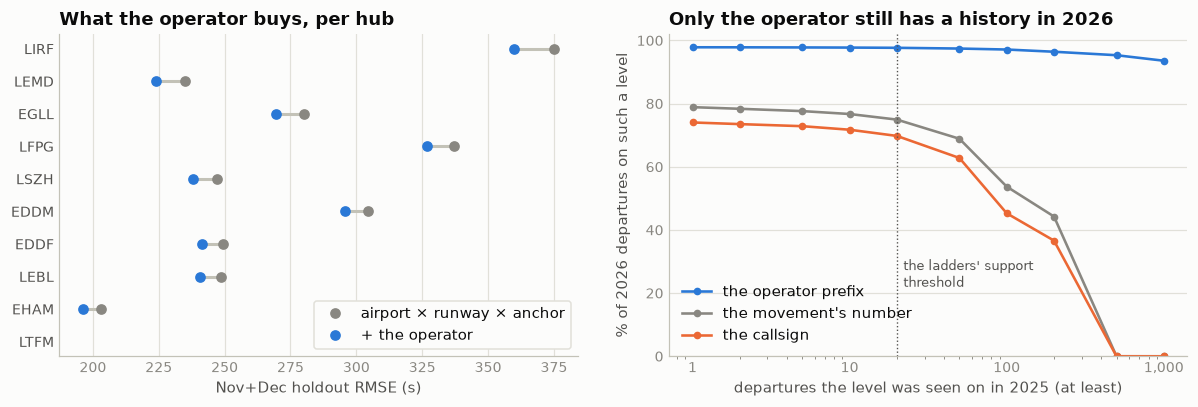

In [10]:
# the two pictures: what the operator buys at each hub on §9's base, and which level still has history in 2026
for i, keys in enumerate([["hub"], ["hub", "rwy"], ["hub", "rwy", "q_anc"], ["hub", "rwy", "q_anc", "pfx"]]):
    con.sql(f"CREATE OR REPLACE TABLE cg{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
            f"FROM cs_b WHERE NOT is_val GROUP BY ALL")
gain = con.sql("""
    SELECT hub, count(*) n_val,
           sqrt(avg((v.y - coalesce(CASE WHEN cg2.c >= 30 THEN cg2.m END,
                                    CASE WHEN cg1.c >= 30 THEN cg1.m END, cg0.m))^2)) base,
           sqrt(avg((v.y - coalesce(CASE WHEN cg3.c >= 30 THEN cg3.m END, CASE WHEN cg2.c >= 30 THEN cg2.m END,
                                    CASE WHEN cg1.c >= 30 THEN cg1.m END, cg0.m))^2)) with_op
    FROM cs_b v LEFT JOIN cg3 USING (hub, rwy, q_anc, pfx) LEFT JOIN cg2 USING (hub, rwy, q_anc)
    LEFT JOIN cg1 USING (hub, rwy) LEFT JOIN cg0 USING (hub)
    WHERE v.is_val GROUP BY 1 ORDER BY base - with_op""").df()
print("per-hub holdout RMSE on airport × runway × anchor, before and after the operator:")
print(gain.assign(gain=(gain.base - gain.with_op)).round(1).to_string(index=False))

cov = con.sql(f"""
    WITH cs AS (SELECT CALLSIGN_flt k, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL GROUP BY 1),
         fn AS (SELECT FLIGHT_mvt k, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL GROUP BY 1),
         pf AS (SELECT id_prefix(CALLSIGN_flt) k, count(*) n FROM {T}
                WHERE PHASE_mvt = 'DEP' AND id_prefix(CALLSIGN_flt) IS NOT NULL GROUP BY 1),
         r AS (SELECT coalesce(cs.n, 0) c_cs, coalesce(fn.n, 0) c_fn, coalesce(pf.n, 0) c_pf
               FROM {R} d LEFT JOIN cs ON cs.k = d.CALLSIGN_flt LEFT JOIN fn ON fn.k = d.FLIGHT_mvt
               LEFT JOIN pf ON pf.k = id_prefix(d.CALLSIGN_flt) WHERE d.PHASE_mvt = 'DEP')
    SELECT t.n threshold, 100.0*count(*) FILTER (c_cs >= t.n)/count(*) callsign,
           100.0*count(*) FILTER (c_fn >= t.n)/count(*) number,
           100.0*count(*) FILTER (c_pf >= t.n)/count(*) prefix
    FROM r CROSS JOIN (VALUES (1), (2), (5), (10), (20), (50), (100), (200), (500), (1000)) t(n)
    GROUP BY 1 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(gain))
a1.hlines(y, gain.with_op, gain.base, color=BASELINE, lw=2)
a1.plot(gain.base, y, "o", color=MUTED, ms=6, label="airport × runway × anchor")
a1.plot(gain.with_op, y, "o", color=BLUE, ms=6, label="+ the operator")
a1.set_yticks(y, gain.hub, color=INK2)
a1.set_title("What the operator buys, per hub")
a1.set_xlabel("Nov+Dec holdout RMSE (s)")
a1.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a1, x_grid=True, y_grid=False)

for col, c, lbl in [("prefix", BLUE, "the operator prefix"), ("number", MUTED, "the movement's number"),
                    ("callsign", ORANGE, "the callsign")]:
    a2.plot(cov.threshold, cov[col], "o-", color=c, ms=4, lw=1.7, label=lbl)
a2.axvline(20, color=INK2, lw=0.9, ls=":")
a2.text(22, 22, "the ladders' support\nthreshold", fontsize=8.5, color=INK2)
a2.set_xscale("log")
a2.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
a2.set_ylim(0, 102)
a2.set_title("Only the operator still has a history in 2026")
a2.set_xlabel("departures the level was seen on in 2025 (at least)")
a2.set_ylabel("% of 2026 departures on such a level")
a2.legend(loc="lower left")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

                                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
  CALLSIGN_flt — levels with ≥ 20 departures, the rest pooled categorical       15257                        0.604
            the operator — the callsign's prefix, ≥ 30 pooled categorical         488                        0.463
     the operator — AIRCRAFT_OPERATOR_flt's hash, ≥ 30 pooled categorical         434                        0.461
         FLIGHT_mvt — the movement's number, ≥ 20 pooled (§3) categorical       14237                        0.608
the callsign's shape — digits, digits + letters, registration categorical           4                        0.123
                    the callsign is not the movement's number categorical           3                        0.261
                                             callsign missing categorical           2                        0.007


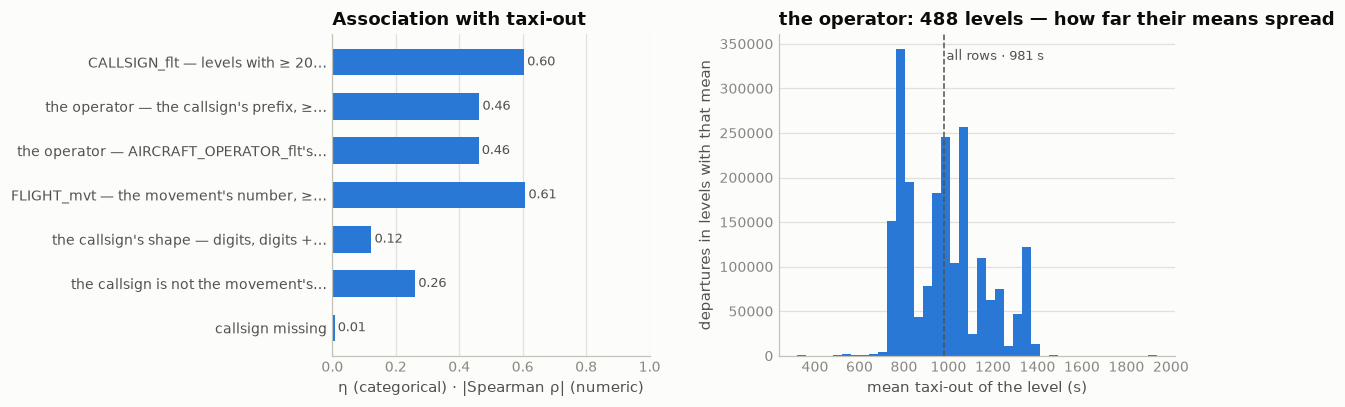

In [11]:
# correlation with the target: the raw callsign, the operator it contains in two spellings, the movement's number
# beside it, the shape, and the two flags — then the operator, which is the form §16 hands the pipeline
a = target_assoc([("CALLSIGN_flt — levels with ≥ 20 departures, the rest pooled", "cat", "CALLSIGN_flt", 20),
              ("the operator — the callsign's prefix, ≥ 30 pooled", "cat", "id_prefix(CALLSIGN_flt)", 30),
              ("the operator — AIRCRAFT_OPERATOR_flt's hash, ≥ 30 pooled", "cat", "AIRCRAFT_OPERATOR_flt", 30),
              ("FLIGHT_mvt — the movement's number, ≥ 20 pooled (§3)", "cat", "FLIGHT_mvt", 20),
              ("the callsign's shape — digits, digits + letters, registration", "cat",
               "CASE WHEN CALLSIGN_flt IS NULL THEN '∅'"
               " WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{3}[0-9]+$') THEN 'digits'"
               " WHEN regexp_matches(CALLSIGN_flt, '^[A-Z]{3}[0-9]+[A-Z]+$') THEN 'digits + letters'"
               " ELSE 'other' END"),
              ("the callsign is not the movement's number", "cat", "CALLSIGN_flt != FLIGHT_mvt"),
              ("callsign missing", "cat", "CALLSIGN_flt IS NULL")])
assoc_chart(a, "id_prefix(CALLSIGN_flt)", kind="cat", min_support=30, title="the operator")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Null exactly where the plan block is** | 22,470 training departures and 5,290 ranking (1.08% / 1.53%): the 22,424 + 5,283 with no plan, plus the 46 + 7 empty blocks §15 found sitting behind a `FLIGHT_ID`; 0.74% on arrivals. Three to seven characters, never padded, 44,824 distinct on training departures | the `_flt` block's own missing-ness, so "no plan" reads the same off this column as off `LOBT_flt`. It also fills §3's hole in reverse: 123 training and 35 ranking departures carry a callsign but no `FLIGHT_mvt` |
| **It is the ICAO spelling, which the movement's number is not** | 99.43% ICAO style (`THY43K`) in both files, 0.55% registrations, 0.02% IATA — against the same rows' `FLIGHT_mvt` at 78.03% ICAO, 21.14% IATA, 0.82% registrations | the callsign is the identity in one spelling. §2c's learned IATA→ICAO map exists only because `FLIGHT_mvt` lacks that discipline; where a plan exists, this column has already done that work |
| **Three departures in four carry the same string twice — and one in five a different flight number altogether** | identical on 72.82% of training departures (74.04% in ranking), the same number in the other spelling on 8.60%, **another number entirely on 18.58%**: `SWR1266`→`SWR193T`, `SWR1100`→`SWR2MC`, `LO264`→`LOT2PJ`, each pair some 364 times a year | callsign deconfliction — a filed ATC callsign deliberately unlike the commercial number, so that similar-sounding flights do not share a frequency. A stable second identity, not noise: 88.4% of departures fly a number that keeps one callsign all year, and 85.5% of 2026's rows on a 2025 number keep 2025's callsign |
| **`AIRCRAFT_OPERATOR_flt` is a hash, and this column's prefix matches what it hides** | the operator column is 64 hex characters; its pairing with the callsign's three-letter prefix is one-to-one on **99.93%** of training departures (976 prefixes, 16 on more than one hash; 676 hashes, 1 on more than one prefix), **Cramér's V 0.9966**. `11dca3fa…` is `DLH`, `95828822…` is `THY`, `6251e0ee…` is `KLM` | both columns name the **operator**, so they agree by construction, and the hash adds nothing the prefix does not already say — the ladder cannot separate them (336.0 against 335.6 s) and one of them is readable. The 16 prefixes on several hashes are the franchise and wet-lease cases, where one callsign covers more than one operating company: 0.07% of rows. Neither column names the *marketing* airline — that is the flight number's job (§3), and the 5,105 rows where the two prefixes differ are exactly that distinction |
| **One hash is a bucket, and there the prefix is the finer column** | the hash covering the most prefixes holds 45,275 movements and 22,627 departures under **338 prefixes** and 4,545 callsigns, 61% business aviation — **51% of every business-aviation departure** in 2025 — median taxi-out 836 s | whatever the bucket is, the operator column has lost a distinction the callsign keeps. Business aviation is the traffic §4a and §6a found the systems barely know, and it is where this matters |
| **The hash means the same thing in both files** | 682 hashes in 2025, 587 in 2026, 557 shared and 30 new; **99.95%** of 2026 departures carry a hash seen in 2025, and 688 of the 697 prefixes present in both files map to the same hash — 99.97% of 2026 rows on a stable pair | not re-salted per file, which it had no obligation not to be: the operator survives as a category across the two years, by either spelling |
| **The operator is the only identity level that still has a history in 2026** | 77.42% of ranking departures reuse a 2025 callsign — 76,667 rows on 7,081 new ones — against 80.67% for the movement's number and **99.37%** for the prefix. At the ladders' own support threshold, a level with ≥ 20 training departures: the callsign covers 69.8% of 2026 departures, the number 74.9%, the prefix **97.7%**. The median callsign flies 3 times a year, 18,676 fly once | schedules churn every year and airlines do not. Any target encoding of the callsign or the number needs the operator underneath it — which is what §3 asked for and could not name |
| **Worth 21 s over the airport, and it is the rung that makes the identity pay** | Nov+Dec holdout, 327,485 departures: airport 357.3 → + the callsign 340.4 · + **the operator 336.0** · + the hash 335.6 · + the movement's number 337.7. Cascading, **the operator then the callsign 330.3** and the operator then the number **329.7** | the coarse level beats both fine ones alone, and underneath them it is worth another 8–10 s. This is the honest reading of §3's "a number bundles airline, route, slot and terminal": most of what §3 measured was the airline |
| **On top of the anchor it is 8.5 s — and 0.8 s once the pier and the fleet are in** | airport × runway × anchor 283.6 → + the operator **275.1**, every hub gaining (LIRF −15.2, LEMD −11.0, EGLL −10.6, LFPG −10.3, LSZH −9.0 … LTFM −2.1). But + §13's stand prefix 268.6 → then the operator 265.0; + the stand prefix then §11's type 265.4 → then the operator **264.6**. The callsign on top of the operator adds 0.2 s (275.1 → 274.9) | the operator is largely a proxy for **where an airline parks and what it flies**. What survives both is under a second — so it earns its place as the identity's fallback level and as a cheap never-missing categorical, not as a feature with 8 s of its own |
| The letter suffix is the airline's filing habit | `digits + letters` 61.51% of departures (mean taxi 947 s), `digits` only 36.91% (1,042 s) — but the rate is per airline: `SWR` 89%, `VLG` 88%, `RYR` 87%, `THY` 80% against `KLM` 60%, `BAW` 62% and **`ITY` 1%**. On the ladder the shape alone is 355.2 s against the airport's 357.3, and 335.0 on top of the operator against 336.0; η 0.123 | a habit, not a property of the flight. The 0.38% whose callsign is letters after the prefix are business aviation (mean 727 s), which the operator and §13's GA aprons already describe |
| **The two ends of one leg do not log the same identifier** | of the legs 2025 saw from both ends, 222,759 whose callsign *is* the departure's own number and 92,482 where the two differ: on the first the arrival logs that string 67.5% of the time; on the second it logs **the callsign 76.7%** and the departure's number only 8.9% | the destination airport records what the aircraft flew under, the origin what the ticket said. This is why §2b's exact-twin test located a twin for fewer than half its candidates (907 of 2,207), and why §2c needed stage C, which reads no identifier at all: on a deconfliction leg the probe's `FLIGHT_mvt` matches neither of the arrival's strings. Mapping a probe's number to its historical callsign — 88.4% stable — would give the waterfall a fourth key. **Unmeasured; a candidate for the next pass at §2c** |

**Decisions**

| issue | decision | why |
|---|---|---|
| the column's model-facing form | **the operator token — the callsign's three-letter prefix**, per airport, as the fallback level under any encoding of the callsign or the movement's number | 336.0 s against the callsign's 340.4 alone, 330.3 with the identity above it, and 97.7% of 2026 departures on a prefix with ≥ 20 training departures against 69.8% for the callsign |
| the raw callsign as a category of its own | **no** — only above the operator | 340.4 s alone; 0.2 s on top of the operator on §9's base (275.1 → 274.9) |
| `AIRCRAFT_OPERATOR_flt`'s hash | **the prefix instead** — but the choice, and the operator's whole place in the model, is deferred to that column's own section (§26) | one-to-one on 99.93% of rows and within 0.4 s on every ladder; the prefix is readable and it is finer inside the 338-prefix bucket |
| the callsign's shape, and a "callsign ≠ number" flag | neither | 355.2 s and 335.0 s on the two ladders, η 0.123; the flag's η 0.261 is the same airline habit, which the operator carries |
| the fourth recovery layer, hash → prefix | **rejected** | of the 13,472 + 2,246 departures it can reach it answers 12,268 + 2,001 — but 11,986 + 1,927 of those answers come from the single impure hash, where a modal prefix is a guess between 338 operators. Gated at 98% purity it buys 282 + 74 rows, and the gate is the whole of its value |
| the departures left without an operator | **left as they are** — they have no airline, not a missing one | 0.54% of departures in either file fly under a registration, Zurich business aviation; 0.10% / 0.12% have no plan block and no usable number |

**State after §16**

The column itself, after §2's twin layers — the same rows and counts as §15's `LOBT_flt`, the block being copied whole:

| `CALLSIGN_flt` null | training DEP | training ARR | ranking DEP | ranking ARR |
|---|---:|---:|---:|---:|
| before → after | 22,470 → **20,572** (1,898 from the twins) | 15,449 → 15,449 | 5,290 → **4,811** (479) | 2,552 → 2,552 |

The operator token 16a builds on top of it, departures:

| | training | ranking |
|---|---:|---:|
| no prefix, raw | 33,822 — 1.62% | 7,131 — **2.07%** |
| after layer 2, the twins | 31,937 | 6,653 |
| after layer 3, the movement's number | **13,472 — 0.65%** | **2,246 — 0.65%** |
| of which fly under a registration | 11,337 | 1,841 |
| of which have no plan block at all | 2,135 | 405 |

| where the token comes from | training | ranking | operators | median taxi-out |
|---|---:|---:|---:|---:|
| the callsign | 2,051,225 | 337,710 | 1,032 | 912 s |
| the movement's number | 18,465 | 4,407 | 490 | 953 s |
| the twin | 1,885 | 478 | 84 | 920 s |
| none | 13,472 | 2,246 | — | 667 s |

**Use in modeling.** `CALLSIGN_flt` itself is **not a feature**: 340.4 s alone against the airport's
357.3, and 0.2 s on top of the operator on §9's base. That is this section's verdict, and it is the
whole of what §16 decides. What the column contributes is its prefix — the **operator token** built
in 16a — and the case for it is coverage rather than gain: 97.7% of 2026 departures sit on a prefix
with ≥ 20 training departures, against 69.8% for the callsign, so it is the level a smoothed
encoding of the callsign or of `FLIGHT_mvt` can fall back to, which is the part of §3's
recommendation this section can now name. **How much of that to spend a feature on is
`AIRCRAFT_OPERATOR_flt`'s section (§26) to settle** — including whether the 8.5 s it shows on the anchor
base survives §13's stand prefix and §11's type, where the ladder above says only 0.8 s does.

**Pipeline recipe:** `op_final` = `id_prefix(CALLSIGN_flt)` where the plan block is there, else
`op_rec` from `data/derived/operator_token.parquet` (the `CASE` in the closing-state cell, verbatim),
joined on `MVT_ID_mvt`. The parquet holds the 25,235 recovered departures with their provenance; its
inputs are §2's two twin layers and §2c's `iata_map`, so it regenerates by running this notebook top
to bottom.

## 17 · `ADEP_flt` — the plan's departure airport

The flight plan's aerodrome of departure: the `_flt` twin of §5's `ADEP_mvt`. A plan is filed for the
leg the movement records, so on a departure from one of the ten hubs the two should name the same
airport. The question is therefore not what the column predicts — §5 already owns the airport — but
whether the plan ever contradicts the movement, and what a contradiction would say about the rest of
the `_flt` block it arrives with.

| step | question | what came out |
|---|---|---|
| census | does the plan ever name a different departure airport? | never: all 2,062,577 present values in training and all 339,551 in ranking agree with `ADEP_mvt` |
| the empty blocks | is it missing exactly where §2's `FLIGHT_ID_mvt` is missing? | almost — 46 training and 7 ranking departures carry a flight id and an entirely empty `_flt` block |
| the audit | do §2b/§2c's recovered blocks start at the right airport? | 2,375 of 2,378 do; the three that do not were copied from an arrival whose own plan origin was wrong or absent |
| the ladder | is it worth anything as a feature? | no — as the airport key it scores 357.7 s against `ADEP_mvt`'s 357.3 s |
| arrivals | is it a copy there too? | no — 1.19% of training arrivals and 1.25% of ranking ones name a different origin. §7a owns the arrival stream |

In [58]:
# census: how often the plan's departure airport agrees with the movement's, per file × phase, and
# whether the column goes missing exactly where §2's flight id does
display(cat_stats("ADEP_flt", "PHASE_mvt = 'DEP'"))

ADF = f"(SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})"

print("agreement with ADEP_mvt — a departure's plan must start where the movement starts:")
print(con.sql(f"""
    SELECT ds, PHASE_mvt ph, count(*) n,
           count(*) FILTER (ADEP_flt IS NULL) n_null,
           round(100.0*count(*) FILTER (ADEP_flt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT ADEP_flt) n_levels,
           count(*) FILTER (ADEP_flt = ADEP_mvt) n_agree,
           round(100.0*count(*) FILTER (ADEP_flt = ADEP_mvt)
                 / nullif(count(*) FILTER (ADEP_flt IS NOT NULL), 0), 3) pct_agree,
           count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt <> ADEP_mvt) n_disagree
    FROM {ADF} GROUP BY ALL ORDER BY 1, 2""").df().to_string(index=False))

print("\nthe column against §2's flight id, departures only:")
print(con.sql(f"""
    SELECT ds, FLIGHT_ID_mvt IS NULL id_missing, ADEP_flt IS NULL plan_adep_missing, count(*) n
    FROM {ADF} WHERE PHASE_mvt = 'DEP' GROUP BY ALL ORDER BY 1, 2, 3""").df().to_string(index=False))

print("\nthe departures with an id but no plan airport — what else their _flt block carries:")
print(con.sql(f"""
    SELECT ds, count(*) n,
           count(*) FILTER (ADES_flt IS NOT NULL) ades,
           count(*) FILTER (CALLSIGN_flt IS NOT NULL) callsign,
           count(*) FILTER (LOBT_flt IS NOT NULL) lobt,
           count(*) FILTER (AOBT_3_flt IS NOT NULL) aobt3,
           count(*) FILTER (MARKET_SEGMENT_flt IS NOT NULL) segment,
           count(*) FILTER (AIRCRAFT_TYPE_flt IS NOT NULL) actype,
           count(*) FILTER (FLIGHT_RULE_flt IS NOT NULL) plan_rule,
           count(*) FILTER (WK_TBL_CAT_flt IS NOT NULL) wake
    FROM {ADF} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL AND ADEP_flt IS NULL
    GROUP BY ALL ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,2085047,22470,1.08,10
ranking 2026,344841,5290,1.53,10


agreement with ADEP_mvt — a departure's plan must start where the movement starts:
      ds  ph       n  n_null  pct_null  n_levels  n_agree  pct_agree  n_disagree
 ranking ARR  344693    2552      0.74      1045   337879     98.754        4260
 ranking DEP  344841    5290      1.53        10   339551    100.000           0
training ARR 2082750   15449      0.74      1461  2042696     98.810       24554
training DEP 2085047   22470      1.08        10  2062577    100.000           0

the column against §2's flight id, departures only:
      ds  id_missing  plan_adep_missing       n
 ranking       False              False  339551
 ranking       False               True       7
 ranking        True               True    5283
training       False              False 2062577
training       False               True      46
training        True               True   22424

the departures with an id but no plan airport — what else their _flt block carries:
      ds  n  ades  callsign  lobt  aob

In [59]:
# the check §2b/§2c never made: a recovered plan block must start at the departure's own airport.
# The twin join keys on the source arrival's *movement* fields and takes its _flt block on trust.
ADF_REC = (f"(SELECT 'exact (§2b)' layer, dataset, MVT_ID_mvt, recovered_from_arr_mvt_id src, ADEP_flt"
           f" FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
           f" UNION ALL SELECT 'relaxed (§2c) ' || matcher_variant, dataset, MVT_ID_mvt,"
           f" recovered_from_arr_mvt_id, ADEP_flt FROM {RELAXED})")

print("recovered blocks, by whether the plan starts at the departure's own airport:")
print(con.sql(f"""
    SELECT r.layer, r.dataset, count(*) n,
           count(*) FILTER (r.ADEP_flt = d.ADEP_mvt) n_starts_at_hub,
           count(*) FILTER (r.ADEP_flt IS NULL) n_no_plan_adep,
           count(*) FILTER (r.ADEP_flt IS NOT NULL AND r.ADEP_flt <> d.ADEP_mvt) n_other_airport
    FROM {ADF_REC} r JOIN {ADF} d USING (MVT_ID_mvt)
    GROUP BY ALL ORDER BY 1, 2""").df().to_string(index=False))

print("\nwhere a rejected block comes from — the state of the arrival it was copied from:")
print(con.sql(f"""
    SELECT CASE WHEN a.ADEP_flt IS NULL THEN 'source arrival has no plan origin'
                WHEN a.ADEP_flt = a.ADEP_mvt THEN 'source arrival agrees'
                ELSE 'source arrival names another origin' END source_state,
           count(*) n,
           count(*) FILTER (r.ADEP_flt IS DISTINCT FROM d.ADEP_mvt) n_rejected
    FROM {ADF_REC} r JOIN {ADF} d USING (MVT_ID_mvt)
    LEFT JOIN {ADF} a ON a.MVT_ID_mvt = r.src
    GROUP BY ALL ORDER BY 1""").df().to_string(index=False))

print("\nthe rejected blocks, traced to their source arrival:")
print(con.sql(f"""
    SELECT r.layer, r.dataset, d.ADEP_mvt departs_from, d.ADES_mvt bound_for, d.FLIGHT_mvt flight,
           a.ADEP_mvt arr_origin_mvt, a.ADEP_flt arr_origin_plan, a.ADES_mvt arr_lands_at
    FROM {ADF_REC} r JOIN {ADF} d USING (MVT_ID_mvt)
    LEFT JOIN {ADF} a ON a.MVT_ID_mvt = r.src
    WHERE r.ADEP_flt IS DISTINCT FROM d.ADEP_mvt
    ORDER BY r.layer, r.dataset, d.FLIGHT_mvt""").df().to_string(index=False))

recovered blocks, by whether the plan starts at the departure's own airport:
          layer  dataset   n  n_starts_at_hub  n_no_plan_adep  n_other_airport
    exact (§2b)  ranking 226              225               0                1
    exact (§2b) training 892              891               0                1
relaxed (§2c) A  ranking 102              102               0                0
relaxed (§2c) A training 527              526               1                0
relaxed (§2c) B  ranking  50               50               0                0
relaxed (§2c) B training 217              217               0                0
relaxed (§2c) C  ranking 101              101               0                0
relaxed (§2c) C training 263              263               0                0

where a rejected block comes from — the state of the arrival it was copied from:


                       source_state    n  n_rejected
              source arrival agrees 2375           0
  source arrival has no plan origin    1           1
source arrival names another origin    2           2

the rejected blocks, traced to their source arrival:


          layer  dataset departs_from bound_for  flight arr_origin_mvt arr_origin_plan arr_lands_at
    exact (§2b)  ranking         LIRF      LIRF  ITY614           LIRF            EGLL         LIRF
    exact (§2b) training         LTFM      LSZH THY6031           LTFM            DAAG         LSZH
relaxed (§2c) A training         LFPG      LTFM AFR1390           LFPG             NaN         LTFM


In [60]:
# the other phase: on an arrival the column is the origin, and there it is not a copy
print("arrivals — the plan's origin against the movement's:")
print(con.sql(f"""
    SELECT ds, count(*) n, count(*) FILTER (ADEP_flt IS NULL) n_null,
           count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt <> ADEP_mvt) n_disagree,
           round(100.0*count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt <> ADEP_mvt)
                 / nullif(count(*) FILTER (ADEP_flt IS NOT NULL), 0), 2) pct_disagree,
           count(DISTINCT ADEP_flt) n_origins
    FROM {ADF} WHERE PHASE_mvt = 'ARR' GROUP BY ALL ORDER BY 1""").df().to_string(index=False))

print("\nis a disagreement a diversion? (§6a's test: the filed destination against the flown one)")
print(con.sql(f"""
    SELECT ADEP_flt = ADEP_mvt origin_agrees,
           CASE WHEN ADES_FILED_flt IS NULL THEN 'filed destination null'
                WHEN ADES_FILED_flt = ADES_flt THEN 'not diverted' ELSE 'diverted' END diversion,
           count(*) n
    FROM {ADF} WHERE ds = 'training' AND PHASE_mvt = 'ARR' AND ADEP_flt IS NOT NULL
    GROUP BY ALL ORDER BY 1, 2""").df().to_string(index=False))

print("\nhow the disagreeing arrivals split, and the pairs behind them (training):")
print(con.sql(f"""
    SELECT CASE WHEN substr(ADEP_flt, 1, 2) = substr(ADEP_mvt, 1, 2) THEN 'same 2-letter ICAO region'
                ELSE 'different region' END kind,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct,
           count(DISTINCT ADEP_mvt || '>' || ADEP_flt) n_pairs
    FROM {ADF} WHERE ds = 'training' AND PHASE_mvt = 'ARR'
      AND ADEP_flt IS NOT NULL AND ADEP_flt <> ADEP_mvt
    GROUP BY ALL ORDER BY n DESC""").df().to_string(index=False))
print(con.sql(f"""
    SELECT ADEP_mvt movement_says, ADEP_flt plan_says, count(*) n
    FROM {ADF} WHERE ds = 'training' AND PHASE_mvt = 'ARR'
      AND ADEP_flt IS NOT NULL AND ADEP_flt <> ADEP_mvt
    GROUP BY ALL ORDER BY n DESC, 1, 2 LIMIT 8""").df().to_string(index=False))

arrivals — the plan's origin against the movement's:
      ds       n  n_null  n_disagree  pct_disagree  n_origins
 ranking  344693    2552        4260          1.25       1045
training 2082750   15449       24554          1.19       1461

is a disagreement a diversion? (§6a's test: the filed destination against the flown one)
 origin_agrees    diversion       n
         False     diverted     148
         False not diverted   24406
          True     diverted    1849
          True not diverted 2040847
          <NA> not diverted      51

how the disagreeing arrivals split, and the pairs behind them (training):


                     kind     n  pct  n_pairs
         different region 18371 74.8     1004
same 2-letter ICAO region  6183 25.2      287
movement_says plan_says    n
         ETNB      EDDB 2430
         LSSB      LFSB 1037
         OKBK      OKKK  826
         EVRS      EVRA  546
         NTTT      KLAX  538
         SKBO      SKCG  395
         KBSZ      UCFM  390
         TNCA      TNCB  364


In [61]:
# what it buys — the honest ladder, fit Jan–Oct 2025 and scored on Nov+Dec, cell support ≥ 30 else
# the global mean: §5's airport key, the same key read off the plan instead, and the airport with
# §2's plan-present flag on top
print("group-mean ladder, training departures 1–3600 s:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, coalesce(ADEP_flt, '∅') pflt, ADEP_flt IS NOT NULL has_plan,
                      TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val
               FROM {TGT}),
         g AS (SELECT avg(y) m FROM d WHERE NOT is_val),
         f1 AS (SELECT hub, avg(y) m, count(*) c FROM d WHERE NOT is_val GROUP BY 1),
         f2 AS (SELECT hub, has_plan, avg(y) m, count(*) c FROM d WHERE NOT is_val GROUP BY 1, 2),
         f3 AS (SELECT pflt, avg(y) m, count(*) c FROM d WHERE NOT is_val GROUP BY 1)
    SELECT count(*) n_val,
           round(sqrt(avg((v.y - (SELECT m FROM g))^2)), 1) "global mean",
           round(sqrt(avg((v.y - coalesce(CASE WHEN f1.c >= 30 THEN f1.m END,
                                          (SELECT m FROM g)))^2)), 1) "ADEP_mvt (§5)",
           round(sqrt(avg((v.y - coalesce(CASE WHEN f3.c >= 30 THEN f3.m END,
                                          (SELECT m FROM g)))^2)), 1) "ADEP_flt as the key",
           round(sqrt(avg((v.y - coalesce(CASE WHEN f2.c >= 30 THEN f2.m END,
                                          CASE WHEN f1.c >= 30 THEN f1.m END,
                                          (SELECT m FROM g)))^2)), 1) "ADEP_mvt × plan present (§2)"
    FROM d v LEFT JOIN f1 USING (hub) LEFT JOIN f2 USING (hub, has_plan) LEFT JOIN f3 USING (pflt)
    WHERE v.is_val""").df().to_string(index=False))

group-mean ladder, training departures 1–3600 s:


 n_val  global mean  ADEP_mvt (§5)  ADEP_flt as the key  ADEP_mvt × plan present (§2)
327485        392.5          357.3                357.7                         357.1


                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
      ADEP_flt — the plan's departure airport categorical          11                        0.447
       ADEP_mvt — the movement's, §5's anchor categorical          10                        0.450
ADEP_flt IS NOT NULL — §2's matched-plan flag categorical           2                        0.007


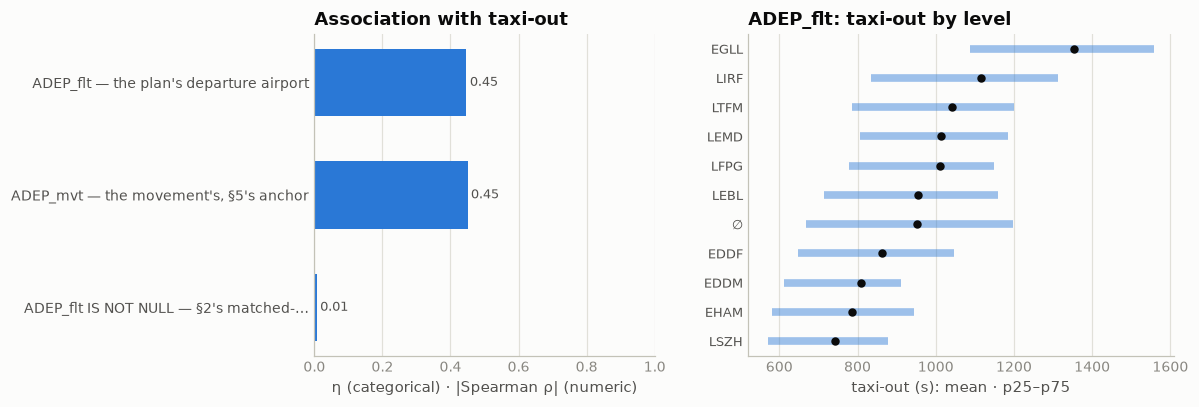

In [62]:
# correlation with the target: the plan's airport, the movement's airport that it copies, and the
# one thing its absence really carries — §2's matched-plan flag
a = target_assoc([
    ("ADEP_flt — the plan's departure airport", "cat", "ADEP_flt"),
    ("ADEP_mvt — the movement's, §5's anchor", "cat", "ADEP_mvt"),
    ("ADEP_flt IS NOT NULL — §2's matched-plan flag", "cat", "ADEP_flt IS NOT NULL"),
])
assoc_chart(a, "ADEP_flt", title="ADEP_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **On a departure the plan never names another airport.** | 2,062,577 of 2,062,577 present values in training and 339,551 of 339,551 in ranking equal `ADEP_mvt` — 100.000%, no exceptions in either file | the column is a spelling of §5's anchor, not a second opinion. There is nothing here to reconcile |
| **As a feature it is strictly worse than the column it copies.** | honest ladder over 327,485 Nov+Dec departures: global mean 392.5 s, `ADEP_mvt` **357.3 s**, `ADEP_flt` as the airport key **357.7 s** | keying the airport on the plan costs 0.4 s, because the 1.08% of departures with no plan pool all ten hubs into one `∅` level. Key on `ADEP_mvt` |
| **What little the plan side adds is §2's flag, not the airport.** | `ADEP_mvt` × plan-present 357.1 s; η 0.450 for the movement's airport against 0.447 for the plan's | the 0.2 s belongs to the matched-plan flag §2 already owns, and it is the *presence* of the plan that carries it |
| **A flight id does not guarantee a plan block.** | 46 training and 7 ranking departures have a `FLIGHT_ID_mvt` but no `ADEP_flt` — and no `ADES_flt`, callsign, `LOBT_flt`, `AOBT_3_flt`, segment, plan type, plan rule or wake either. The block is empty, not partial | §2's rule holds one way only: no id ⇒ no block, but an id ⇒ nothing. Read the matched-plan flag off a `_flt` field — `ADEP_flt IS NULL` gives 22,470 training and 5,290 ranking departures, against the id's 22,424 and 5,283 |
| **The twin recovery is 99.87% clean, and this column is what measures it.** | 2,375 of the 2,378 blocks recovered in §2b and §2c start at the departure's own airport | a departure's plan must start where the departure starts, so the test needs no data we do not already hold |
| **All three exceptions have one cause.** | every rejected block was copied from an arrival whose own plan origin was wrong (2) or absent (1); the 2,375 blocks taken from a clean arrival produced no rejects at all | §2b's join keys on the arrival's `FLIGHT_mvt`, `ADEP_mvt` and `ADES_mvt` — all movement fields — and trusts its `_flt` block. A mis-joined arrival passes straight through into a recovered departure |
| **What a rejected block costs is a clock, not a category.** | THY6031 departs LTFM for LSZH and was given a plan for a DAAG→LSZH leg; ITY614 at LIRF was given an EGLL→LIRF plan | the `LOBT_flt` and `AOBT_3_flt` on those rows were measured at another airport, and those two fields are what §9's anchor and §15's unfiled delay are built from |
| **On arrivals the column is not a copy.** | 24,554 training arrivals (1.19%) and 4,260 ranking ones (1.25%) name a different origin than the movement, spread over 1,004 cross-region and 287 same-region code pairs; 74.8% of the rows cross ICAO regions | and it is not a diversion effect — only 148 of the 24,554 have `ADES_FILED_flt ≠ ADES_flt`. Some pairs are two registries for one airport (`LSSB`/`LFSB` are Basel's Swiss and French codes, `ETNB`/`EDDB`, `OKBK`/`OKKK`), some are genuine mis-joins (`NTTT`/`KLAX`) |

**Decisions**

| issue | decision | why |
|---|---|---|
| `ADEP_flt` as a feature | drop it — the airport is `ADEP_mvt` | 357.7 s against 357.3 s on the same rows, and nothing it says is new |
| the 53 matched-but-empty blocks | read the matched-plan flag as `ADEP_flt IS NULL`, not `FLIGHT_ID_mvt IS NULL` | 53 departures carry an id over an entirely empty block; every `_flt` feature is absent there whatever the id says |
| the 3 rejected recovered blocks | **recommended, not applied here:** §2b and §2c should require the source arrival's `ADEP_flt` to equal the departure's `ADEP_mvt` | one predicate on data already in the join, and it removes the only class of mis-recovery that is detectable at all. Left for §2 to apply rather than reached in from here, because it changes `recovered_flt_blocks` (1,118 rows) and `recovered_flt_relaxed` (1,260) and every count downstream of them — for 2 training rows and 1 ranking row |
| the arrival stream's origin | key it on `ADEP_mvt` | §7a owns what is built from arrivals; the plan's origin disagrees on 1.19% of them, and the movement's is the field §2b's join already uses |

**Use in modeling.** Nothing new enters the model from this column — §5 already holds the airport, and reading it off the plan is measurably worse. Its worth is one correction and two guards: the matched-plan flag is `ADEP_flt IS NULL` rather than `FLIGHT_ID_mvt IS NULL` (53 departures differ, all of them plan-less in fact); a recovered `_flt` block should be required to start at the departure's own airport; and the plan's origin is not the origin key on arrivals. None of this moves RMSE on its own — the rows it rejects are 2 in training and 1 of the 344,841 we predict — but each of those rows would otherwise hand §9's anchor and §15's unfiled delay an off-block time recorded at a different airport.

## 18 · `ADES_flt` — the plan's destination

The flight plan's aerodrome of destination, the `_flt` twin of §6's `ADES_mvt`. §17 found the
departure end of a plan to be a perfect copy of the movement's; the destination end is not. On 1.4%
of departures the two systems name different airports, and §6a already leans on the plan to settle
its sentinel rows — so the question here is which of the two is telling the truth, and whether the
answer is worth anything at the taxiway.

| step | question | what came out |
|---|---|---|
| census | which end of a flight do the two systems agree about? | the hub end always: 100.000% on a departure's `ADEP` (§17) and on an arrival's `ADES`. The outstation end disagrees on 1.42% of departures |
| the two causes | what is a disagreement made of? | 7,399 training rows where the movement uses a code the plan's registry has never once used, and 21,622 where both codes are ordinary — a different airport, not a different spelling |
| the referee | who is right? | the flight itself: on the 1,908 disagreements whose landing we can find, the plan named it **1,908 times and the movement 0** |
| the ladder | is being right worth anything? | no — the plan's code in place of `dest_final` moves the holdout from 335.2 s to 335.1 s, and the disagreement flag to 334.9 s |
| our own rows | do §2b/§2c's recovered blocks add any of it? | none, and none is possible: all 2,378 carry the departure's own destination, because each was copied from an arrival that landed there |
| the flag | why so little? | it is a stand in disguise: 18.03% of cargo departures disagree against 1.17% of mainline, half of Charles de Gaulle's pier I — and on §13's stand base the flag is worth **nothing** (274.0 → 274.1 s) |

In [64]:
# census: the plan's destination against the movement's, per file × phase — and which end of a
# flight the two systems actually agree about
display(cat_stats("ADES_flt", "PHASE_mvt = 'DEP'"))

ADS = f"(SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})"

print("agreement with ADES_mvt — on an arrival the destination is the hub itself:")
print(con.sql(f"""
    SELECT ds, PHASE_mvt ph, count(*) n,
           count(*) FILTER (ADES_flt IS NULL) n_null,
           round(100.0*count(*) FILTER (ADES_flt IS NULL)/count(*), 2) pct_null,
           count(*) FILTER (ADES_flt = 'ZZZZ') n_zzzz,
           count(DISTINCT ADES_flt) n_levels,
           count(*) FILTER (ADES_flt = ADES_mvt) n_agree,
           round(100.0*count(*) FILTER (ADES_flt = ADES_mvt)
                 / nullif(count(*) FILTER (ADES_flt IS NOT NULL), 0), 3) pct_agree,
           count(*) FILTER (ADES_flt IS NOT NULL AND ADES_flt <> ADES_mvt) n_disagree
    FROM {ADS} GROUP BY ALL ORDER BY 1, 2""").df().to_string(index=False))

print("\nwhat a disagreeing departure is made of (the first two kinds are §6a's sentinel rows):")
print(con.sql(f"""
    SELECT ds,
           CASE WHEN ADES_mvt IS NULL THEN 'movement ∅ — §6a'
                WHEN ADES_mvt = 'ZZZZ' THEN 'movement ZZZZ — §6a'
                WHEN ADES_flt = 'ZZZZ' THEN 'plan ZZZZ'
                ELSE 'two different real codes' END kind,
           CASE WHEN ADES_FILED_flt IS NULL THEN 'filed ∅'
                WHEN ADES_FILED_flt = ADES_flt THEN 'not diverted' ELSE 'diverted' END diversion,
           count(*) n
    FROM {ADS} WHERE PHASE_mvt = 'DEP' AND ADES_flt IS NOT NULL AND ADES_flt IS DISTINCT FROM ADES_mvt
    GROUP BY ALL ORDER BY 1, 2, 3""").df().to_string(index=False))

print("\nand the blocks §2b/§2c recovered — is any of this disagreement our own doing:")
ADS_REC = (f"(SELECT dataset, MVT_ID_mvt, recovered_from_arr_mvt_id src, ADES_flt"
           f" FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
           f" UNION ALL SELECT dataset, MVT_ID_mvt, recovered_from_arr_mvt_id, ADES_flt FROM {RELAXED})")
print(con.sql(f"""
    SELECT count(*) n_recovered,
           count(*) FILTER (r.ADES_flt = d.ADES_mvt) n_agree,
           count(*) FILTER (r.ADES_flt IS NULL) n_null,
           count(*) FILTER (r.ADES_flt IS NOT NULL AND r.ADES_flt <> d.ADES_mvt) n_disagree,
           count(*) FILTER (d.ADES_mvt = a.ADES_mvt) n_source_arrival_landed_there
    FROM {ADS_REC} r JOIN {ADS} d USING (MVT_ID_mvt)
    LEFT JOIN {ADS} a ON a.MVT_ID_mvt = r.src""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,2085047,22470,1.08,1438
ranking 2026,344841,5290,1.53,1033


agreement with ADES_mvt — on an arrival the destination is the hub itself:
      ds  ph       n  n_null  pct_null  n_zzzz  n_levels  n_agree  pct_agree  n_disagree
 ranking ARR  344693    2552      0.74       0        10   342141    100.000           0
 ranking DEP  344841    5290      1.53       6      1033   334644     98.555        4900
training ARR 2082750   15449      0.74       0        10  2067301    100.000           0
training DEP 2085047   22470      1.08      31      1438  2033337     98.582       29160

what a disagreeing departure is made of (the first two kinds are §6a's sentinel rows):
      ds                     kind    diversion     n
 ranking      movement ZZZZ — §6a not diverted     2
 ranking         movement ∅ — §6a not diverted     7
 ranking                plan ZZZZ not diverted     5
 ranking two different real codes     diverted   305
 ranking two different real codes not diverted  4588
training      movement ZZZZ — §6a     diverted     1
training      movemen

In [65]:
# the two causes behind "two different real codes": a registry the other system does not use, or a
# genuinely different airport. The test is whether each code appears in the other system's vocabulary.
DIFFS = f"""(SELECT * FROM {ADS} WHERE PHASE_mvt = 'DEP'
             AND ADES_mvt IS NOT NULL AND ADES_mvt <> 'ZZZZ'
             AND ADES_flt IS NOT NULL AND ADES_flt <> 'ZZZZ' AND ADES_flt <> ADES_mvt)"""

print("the top disagreeing pairs, with how often each system uses each code anywhere:")
print(con.sql(f"""
    WITH pairs AS (SELECT ADES_mvt m, ADES_flt p, count(*) n FROM {DIFFS} GROUP BY 1, 2),
         usem AS (SELECT ADES_mvt c, count(*) n FROM {ADS} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         usep AS (SELECT ADES_flt c, count(*) n FROM {ADS} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT pairs.m movement_says, pairs.p plan_says, pairs.n,
           coalesce(mm.n, 0) movement_uses_its_code, coalesce(pm.n, 0) plan_uses_it,
           coalesce(pp.n, 0) plan_uses_its_code, coalesce(mp.n, 0) movement_uses_it
    FROM pairs LEFT JOIN usem mm ON mm.c = pairs.m LEFT JOIN usep pm ON pm.c = pairs.m
               LEFT JOIN usem mp ON mp.c = pairs.p LEFT JOIN usep pp ON pp.c = pairs.p
    ORDER BY pairs.n DESC, 1, 2 LIMIT 10""").df().to_string(index=False))

print("\nthe split — a code foreign to the other registry, or two codes both systems know:")
print(con.sql(f"""
    WITH usep AS (SELECT DISTINCT ADES_flt c FROM {ADS} WHERE ADES_flt IS NOT NULL),
         usem AS (SELECT DISTINCT ADES_mvt c FROM {ADS} WHERE ADES_mvt IS NOT NULL)
    SELECT ds, count(*) n_disagree,
           count(*) FILTER (ADES_mvt NOT IN (SELECT c FROM usep)) movement_code_foreign_to_plan,
           count(*) FILTER (ADES_flt NOT IN (SELECT c FROM usem)) plan_code_foreign_to_movement,
           count(*) FILTER (ADES_mvt IN (SELECT c FROM usep)
                            AND ADES_flt IN (SELECT c FROM usem)) both_codes_shared
    FROM {DIFFS} GROUP BY ALL ORDER BY 1""").df().to_string(index=False))

the top disagreeing pairs, with how often each system uses each code anywhere:
movement_says plan_says    n  movement_uses_its_code  plan_uses_it  plan_uses_its_code  movement_uses_it
         ETNB      EDDB 2804                    2813             0               30962             28127
         LSSB      LFSB 1177                    1208             0               10343              9363
         OKBK      OKKK  927                     935             0                3792              2721
         NTTT      KLAX  649                     655             0                9855              9258
         EVRS      EVRA  637                     907             0                6367              5752
         MMUN      MMMX  554                    2388          1798                7132              6615
         SAEZ      SBGR  539                    5367          4805                8219              7554
         HUEN      HRYR  424                     499            72               

      ds  n_disagree  movement_code_foreign_to_plan  plan_code_foreign_to_movement  both_codes_shared
 ranking        4893                           1226                             32               3649
training       29119                           7399                            148              21622


In [66]:
# the referee: where did the flight actually land? The arrival row carrying the same FLIGHT_ID is
# the movement system's own record of the landing, so it can settle the two claims — for the
# disagreements bound for one of the ten hubs, which are the ones we can see
ARRIV = f"""(SELECT FLIGHT_ID_mvt, ADES_mvt landed_at, MVT_TIME_UTC_mvt t
             FROM {ADS} WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL)"""

print("on the disagreements whose landing we can find:")
print(con.sql(f"""
    SELECT d.ds, count(*) n_settled,
           count(*) FILTER (a.landed_at = d.ADES_mvt) movement_was_right,
           count(*) FILTER (a.landed_at = d.ADES_flt) plan_was_right,
           count(*) FILTER (a.landed_at <> d.ADES_mvt AND a.landed_at <> d.ADES_flt) neither
    FROM (SELECT * FROM {DIFFS} WHERE FLIGHT_ID_mvt IS NOT NULL) d
    JOIN {ARRIV} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
      AND a.t > d.MVT_TIME_UTC_mvt AND a.t < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe control — the same referee on departures where the two agree and the destination is a hub:")
print(con.sql(f"""
    SELECT d.ds, count(*) n, count(*) FILTER (a.landed_at = d.ADES_mvt) landed_where_both_said
    FROM (SELECT * FROM {ADS} WHERE PHASE_mvt = 'DEP' AND ADES_flt = ADES_mvt
            AND ADES_mvt IN {APS} AND FLIGHT_ID_mvt IS NOT NULL) d
    JOIN {ARRIV} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
      AND a.t > d.MVT_TIME_UTC_mvt AND a.t < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nwhat the settled rows look like — the movement names a leg further down the rotation:")
print(con.sql(f"""
    SELECT d.ADES_mvt movement_says, d.ADES_flt plan_says, a.landed_at, count(*) n
    FROM (SELECT * FROM {DIFFS} WHERE FLIGHT_ID_mvt IS NOT NULL) d
    JOIN {ARRIV} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
      AND a.t > d.MVT_TIME_UTC_mvt AND a.t < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    GROUP BY ALL ORDER BY n DESC, 1, 2 LIMIT 8""").df().to_string(index=False))

on the disagreements whose landing we can find:


      ds  n_settled  movement_was_right  plan_was_right  neither
 ranking        279                   0             279        0
training       1629                   0            1629        0

the control — the same referee on departures where the two agree and the destination is a hub:


      ds      n  landed_where_both_said
 ranking  50642                   50642
training 313637                  313637

what the settled rows look like — the movement names a leg further down the rotation:
movement_says plan_says landed_at   n
         LMML      LIRF      LIRF 296
         KMEM      EDDF      EDDF 225
         EDDS      EDDF      EDDF 184
         LRTR      EDDM      EDDM 155
         ZSHC      LEMD      LEMD 155
         LEZL      LEMD      LEMD 133
         VCBI      EDDF      EDDF  59
         VHHH      EHAM      EHAM  51


In [67]:
# what it buys — honest ladders, fit Jan–Oct 2025 and scored on Nov+Dec, support ≥ 30 cascading to
# the coarser rung. §6a's dest_final is the destination we already have; the two candidates this
# section could add are the plan's code in its place, and a flag for the rows where they differ.
con.sql(f"""
    CREATE OR REPLACE TABLE ads_d AS
    WITH f AS ({FINALD})
    SELECT f.ADEP_mvt hub, f.RUNWAY_mvt rwy, f.STAND_mvt stand, {PFX} pfx, f.dest_final,
           substr(f.dest_final, 1, 2) dpfx,
           CASE WHEN f.ADES_flt IS NOT NULL AND f.ADES_flt <> 'ZZZZ' THEN f.ADES_flt
                ELSE f.dest_final END dest_plan_first,
           CASE WHEN f.ADES_flt IS NULL THEN 'no plan'
                WHEN f.ADES_flt = f.dest_final THEN 'agrees' ELSE 'differs' END agree,
           epoch(f.MVT_TIME_UTC_mvt - f.AOBT_3_flt) anchor,
           f.TAXITIME_SEC_mvt::DOUBLE y, month(f.MVT_TIME_UTC_mvt) >= 11 is_val
    FROM f WHERE f.ds = 'training' AND f.TAXITIME_SEC_mvt BETWEEN 1 AND 3600""")


def ads_rungs(rungs, tbl="ads_d"):
    """Cascading group-mean ladder: each rung falls back to the rung before it, then the global mean."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE ads_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN ads_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN ads_s{i}.c >= 30 THEN ads_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


n_val = con.sql("SELECT count(*) FROM ads_d WHERE is_val").fetchone()[0]
print(f"(1) on the airport — {n_val:,} Nov+Dec departures, the destination keyed three ways:")
DEST = [("airport (§5)", ["hub"]), ("+ destination country (§6)", ["hub", "dpfx"])]
for name, r in ads_rungs(DEST + [("+ dest_final (§6a)", ["hub", "dpfx", "dest_final"])]):
    print(f"    {name:46s} {r:7.1f} s")
for name, keys in [("+ the plan's code in its place", ["dest_plan_first"]),
                   ("+ dest_final, then the disagreement flag", ["dest_final", "agree"])]:
    print(f"    {name:46s} {ads_rungs(DEST + [('x', DEST[-1][1] + keys)])[-1][1]:7.1f} s")

con.sql("CREATE OR REPLACE TABLE ads_w AS WITH cuts AS (SELECT hub, quantile_cont(anchor, "
        "[0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa FROM ads_d WHERE NOT is_val AND anchor IS NOT NULL "
        "GROUP BY 1) SELECT ads_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM ads_d JOIN cuts "
        "USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL")
n_val = con.sql("SELECT count(*) FROM ads_w WHERE is_val").fetchone()[0]
print(f"\n(2) on §13's base instead — the {n_val:,} Nov+Dec departures with runway, stand and anchor:")
BASE = [("airport", ["hub"]), ("+ runway × anchor (§9, §12)", ["hub", "rwy", "q_anc"]),
        ("+ stand (§13)", ["hub", "rwy", "q_anc", "pfx", "stand"])]
for name, r in ads_rungs(BASE, "ads_w"):
    print(f"    {name:46s} {r:7.1f} s")
print(f"    {'+ the disagreement flag, on top':46s} "
      f"{ads_rungs(BASE + [('x', BASE[-1][1] + ['agree'])], 'ads_w')[-1][1]:7.1f} s")

(1) on the airport — 327,485 Nov+Dec departures, the destination keyed three ways:
    airport (§5)                                     357.3 s
    + destination country (§6)                       338.6 s
    + dest_final (§6a)                               335.2 s
    + the plan's code in its place                   335.1 s
    + dest_final, then the disagreement flag         334.9 s



(2) on §13's base instead — the 324,629 Nov+Dec departures with runway, stand and anchor:
    airport                                          355.4 s
    + runway × anchor (§9, §12)                      283.7 s
    + stand (§13)                                    274.0 s


    + the disagreement flag, on top                  274.1 s


In [68]:
# why the flag dies against the stand: it is not a property of the flight, it is a property of where
# the flight parks — the disagreeing departures are the cargo apron
print("who disagrees, by market segment (training departures 1–3600 s with a plan):")
print(con.sql(f"""
    WITH f AS ({FINALD})
    SELECT coalesce(MARKET_SEGMENT_flt, '∅') segment,
           count(*) FILTER (ADES_flt = dest_final) n_agrees,
           count(*) FILTER (ADES_flt <> dest_final) n_differs,
           round(100.0*count(*) FILTER (ADES_flt <> dest_final)/count(*), 2) pct_differs,
           round(avg(TAXITIME_SEC_mvt) FILTER (ADES_flt = dest_final)) mean_taxi_agrees,
           round(avg(TAXITIME_SEC_mvt) FILTER (ADES_flt <> dest_final)) mean_taxi_differs
    FROM f WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 AND ADES_flt IS NOT NULL
    GROUP BY ALL ORDER BY n_differs DESC""").df().to_string(index=False))

print("\nand where they park — the piers where a disagreement is not the exception (§13's prefix):")
print(con.sql(f"""
    WITH f AS ({FINALD})
    SELECT ADEP_mvt hub, {PFX} pier, count(*) n_departures,
           count(*) FILTER (ADES_flt IS NOT NULL AND ADES_flt <> dest_final) n_differs,
           round(100.0*count(*) FILTER (ADES_flt IS NOT NULL AND ADES_flt <> dest_final)/count(*), 2) pct_differs
    FROM f WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 AND STAND_mvt IS NOT NULL
    GROUP BY ALL HAVING count(*) FILTER (ADES_flt IS NOT NULL AND ADES_flt <> dest_final) >= 200
    ORDER BY pct_differs DESC LIMIT 8""").df().to_string(index=False))

who disagrees, by market segment (training departures 1–3600 s with a plan):
      segment  n_agrees  n_differs  pct_differs  mean_taxi_agrees  mean_taxi_differs
     Mainline   1307981      15510         1.17            1025.0             1192.0
        Cargo     49134      10805        18.03            1014.0             1011.0
     Regional    209977        817         0.39             769.0              851.0
      Lowcost    398124        786         0.20             964.0             1095.0
     Business     43739        695         1.56             782.0              591.0
Non-Scheduled     14150        316         2.18             969.0              992.0
        Other      6542        113         1.70             886.0              865.0
     Military       685         27         3.79             835.0              708.0

and where they park — the piers where a disagreement is not the exception (§13's prefix):
 hub pier  n_departures  n_differs  pct_differs
LFPG    I         1

                          feature        kind  n / levels  pearson_r  spearman_ρ     η
ADES_flt — the plan's destination categorical         537                        0.324
   ADES_mvt — the movement's, raw categorical         551                        0.328
                 the two disagree categorical           3                        0.035


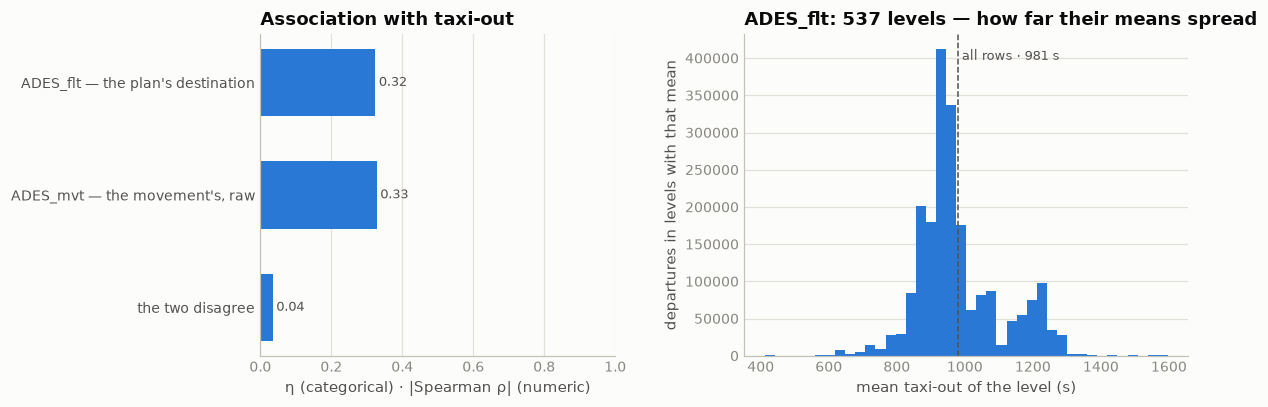

In [69]:
# correlation with the target: the plan's destination, §6a's dest_final that it would replace, and
# the flag for the rows where the two differ
a = target_assoc([
    ("ADES_flt — the plan's destination", "cat", "ADES_flt", 200),
    ("ADES_mvt — the movement's, raw", "cat", "ADES_mvt", 200),
    ("the two disagree", "cat", "ADES_flt IS NOT NULL AND ADES_flt <> ADES_mvt"),
])
assoc_chart(a, "ADES_flt", min_support=200, title="ADES_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The two systems agree perfectly about the hub, and only about the hub.** | an arrival's `ADES_flt` equals `ADES_mvt` on 2,067,301 of 2,067,301 training rows and 342,141 of 342,141 ranking rows — 100.000%, the mirror of §17's departure result. The outstation end disagrees on 29,160 training and 4,900 ranking departures — 1.42% and 1.45% of those carrying a plan | each system records its own aerodrome exactly and the far end approximately. Any feature built on the *other* airport inherits that 1.42% |
| **A disagreement is two different faults, not one.** | of the two-real-code rows, 7,399 training and 1,226 ranking use a movement code the plan's registry has never once used — `ETNB` for Berlin, `LSSB` for Basel, `OKBK` for Kuwait, `NTTT`, `EVRS`, `APPH` all read 0 uses on the plan side — while 21,622 training and 3,649 ranking use codes both systems know | the first kind is one airport under two registries and splits a level in two; the second kind is a genuinely different airport |
| **Where a disagreement can be settled, the plan is right every single time.** | matching the departure to the arrival row carrying the same `FLIGHT_ID_mvt`: 1,629 training and 279 ranking disagreements have a findable landing, and the aircraft landed where the plan said in **1,908 of 1,908**, where the movement said in **0** | the control says the referee is sound — on 313,637 training and 50,642 ranking departures where the two agree, the flight landed there every time |
| **The movement names a leg further down the rotation.** | the settled pairs are `LMML`→landed `LIRF` (296), `KMEM`→`EDDF` (225), `EDDS`→`EDDF` (184), `LRTR`→`EDDM` (155), `ZSHC`→`LEMD` (155) | the plan is filed for the next landing; the movement records where the aircraft is ultimately going. Neither is wrong about the world — they answer different questions |
| **Being right is worth nothing at the taxiway.** | honest ladder over 327,485 Nov+Dec departures: airport 357.3 s, + destination country 338.6 s, + `dest_final` **335.2 s**, + the plan's code in its place **335.1 s**, + the disagreement flag 334.9 s | swapping the destination for the truthful one is worth a tenth of a second on a single holdout, which is noise. §6a's `dest_final` stays the destination |
| **And the flag is a stand in disguise.** | on §13's base over the 324,629 departures that have a runway, a stand and an anchor — where the airport mean is 355.4 s rather than 357.3 s: runway × anchor 283.7 → stand **274.0** → + the flag **274.1 s**. It is cargo — 18.03% of cargo departures disagree against 1.17% of mainline — and cargo parks apart: 51.20% of Charles de Gaulle's pier `I` and 34.90% of Istanbul's pier `K` | the +165 s the disagreeing rows show against the airport mean is composition, not signal. §13's stand already holds all of it, so the flag adds a column and nothing else |
| **None of the disagreement is ours.** | all 2,378 blocks recovered in §2b and §2c carry a destination equal to the departure's own `ADES_mvt` — 2,377 of them, the odd one being the empty block §17 found — and every one was copied from an arrival that landed at exactly that airport | the mirror of §17, where the twin join let three wrong *origins* through. It cannot happen at this end: the block is taken from an arrival at the destination, and an arrival's own `ADES_flt` is its hub 100.000% of the time. Every one of the 29,160 disagreements is in the challenge data as delivered |
| **The plan has its own sentinel, and it is rare.** | `ADES_flt` is `ZZZZ` on 31 training and 6 ranking departures, of which 27 and 5 sit against a real movement code | too few to matter, and §6a's waterfall already prefers a real code over either system's `ZZZZ` |

**Decisions**

| issue | decision | why |
|---|---|---|
| `ADES_flt` as the destination feature | keep §6a's `dest_final`; the plan's code is not worth swapping in | 335.1 s against 335.2 s on the same rows — a tenth of a second, inside the noise of one holdout. It would also make the destination depend on a field absent from 1.08% of departures, and the same 99.95% of 2026 departures land on a level with a 2025 history either way |
| the disagreement flag as a feature | drop it | worth 0.3 s on the airport and **−0.1 s** on §13's base. It is a cargo-apron indicator, and the stand is a better one |
| which field means "where the aircraft is going" | `ADES_flt`, wherever a feature needs the actual next landing | 1,908–0 against the movement, verified on the flights we can follow. A route-distance, great-circle or turnaround feature must read the plan's code, not `ADES_mvt` — this is the one place the distinction bites |
| §6a's sentinel waterfall | unchanged, and confirmed | its layer 1 already reads `ADES_flt` before `ADES_FILED_flt` for 94 training and 9 ranking rows. The referee here is independent evidence that the layer is ordered correctly |

**Use in modeling.** The destination stays as §6a left it — `dest_final`, keyed whole, with the country prefix as the fallback rung. This column changes no feature and adds none: the plan's destination is the *truer* field but not the more useful one, because the 1.42% where it differs is a cargo population that §13's stand already separates far better than a flag could. What the section does fix is a fact worth holding on to when a later feature needs geography rather than a category — distance flown, great-circle bearing, a turnaround chain across legs — and there `ADES_flt` is the field to read, because on every disagreement we could independently settle, it was the one that named the airport the aircraft actually landed at.

## 19 · `ADES_FILED_flt` — the destination the flight plan started with

The destination as it was first filed, before anything changed in the air. Where it still equals
§18's `ADES_flt` the flight went where it meant to; where it differs, the flight was **diverted**
and the plan's destination was rewritten en route. §18 asked which of the movement and the plan
tells the truth about where a flight is going; this column asks a narrower question — *when* the
plan started telling it — and it is the only place in the data where a diversion is visible at all.

| step | question | what came out |
|---|---|---|
| census | is it ever an independent source? | no. It is present on exactly the rows `ADES_flt` is present on — not one of 4,857,331 rows carries either code without the other — and it agrees with it on 99.90% of departures |
| the difference | what is a diversion made of? | 2,070 training and 410 ranking departures; half of them stay inside the same country — Florence → Pisa, Kraków → Katowice, Gibraltar → Málaga |
| §18's leftover | does it explain any of §18's 29,160 disagreements? | 1,397 of them, 4.79%. There the movement kept the *filed* code and the plan moved — the opposite of the story §18 told for the other 95.10% |
| the referee | which of the two codes is the landing? | `ADES_flt`, on **457 of 457** training and **94 of 94** ranking diversions whose landing can be found; `ADES_FILED_flt` **0 of 457** and **0 of 94**. So `ADES_flt` is a field that can be rewritten after our taxi has ended |
| the arrival end | can it see a hub in trouble? | it is the only column that detects a flight diverting *into* a hub — 1,997 training, 436 ranking — but the rate is filing practice, not weather: Madrid 0.155%, Charles de Gaulle 0.010% |
| the ladder | worth anything? | no. The diverted flag is 335.2 → 335.1 s on the destination and 274.0 → 274.0 s on §13's stand base; the arrival-side counter is 274.1 s |


In [71]:
# census: the filed destination against the plan's, by file × phase — presence, the ZZZZ sentinel,
# and how often the two differ (a difference means the flight was diverted after it left)
display(cat_stats("ADES_FILED_flt"))
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"

print("ADES_FILED_flt by file × phase — it is present on exactly the rows ADES_flt is present on:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ADES_FILED_flt IS NULL) n_null,
           round(100.0*count(*) FILTER (ADES_FILED_flt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT ADES_FILED_flt) n_values, count(*) FILTER (ADES_FILED_flt = 'ZZZZ') zzzz,
           count(*) FILTER (ADES_FILED_flt IS NOT NULL AND ADES_flt IS NULL) filed_without_plan,
           count(*) FILTER (ADES_FILED_flt IS NULL AND ADES_flt IS NOT NULL) plan_without_filed,
           count(*) FILTER (ADES_flt <> ADES_FILED_flt) differ,
           round(100.0*count(*) FILTER (ADES_flt <> ADES_FILED_flt)
                 / count(*) FILTER (ADES_flt IS NOT NULL), 3) pct_of_planned
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ncan it fill a destination ADES_flt cannot? §6a's waterfall reads it second — departures:")
print(con.sql(f"""
    SELECT src, count(*) FILTER (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ') mvt_unusable,
           count(*) FILTER ((ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ')
                            AND ADES_flt IS NOT NULL AND ADES_flt <> 'ZZZZ') filled_by_ades_flt,
           count(*) FILTER ((ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ') AND (ADES_flt IS NULL OR ADES_flt = 'ZZZZ')
                            AND ADES_FILED_flt IS NOT NULL AND ADES_FILED_flt <> 'ZZZZ') filled_by_filed_only,
           count(*) FILTER (ADES_FILED_flt = 'ZZZZ') filed_zzzz, count(*) FILTER (ADES_flt = 'ZZZZ') plan_zzzz,
           count(*) FILTER (ADES_FILED_flt = 'ZZZZ' AND ADES_flt = 'ZZZZ') both_zzzz
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,1436
ranking 2026,689534,7842,1.14,1032


ADES_FILED_flt by file × phase — it is present on exactly the rows ADES_flt is present on:
     src  ph       n  n_null  pct_null  n_values  zzzz  filed_without_plan  plan_without_filed  differ  pct_of_planned
training ARR 2082750   15449      0.74       372     0                   0                   0    1997           0.097
training DEP 2085047   22470      1.08      1435    32                   0                   0    2070           0.100
 ranking ARR  344693    2552      0.74       200     0                   0                   0     436           0.127
 ranking DEP  344841    5290      1.53      1031     6                   0                   0     410           0.121

can it fill a destination ADES_flt cannot? §6a's waterfall reads it second — departures:
     src  mvt_unusable  filled_by_ades_flt  filled_by_filed_only  filed_zzzz  plan_zzzz  both_zzzz
training           214                  94                     0          32         31         31
 ranking            29    

In [72]:
# what a difference is made of: whether the new destination stays nearby, the commonest filed → flown
# pairs, and the question §18 left open — on its 1.42%, does the filed code back the movement?
print("the diversions, by file (departures carrying both codes):")
print(con.sql(f"""
    SELECT src, count(*) n,
           count(*) FILTER (substr(ADES_FILED_flt, 1, 2) = substr(ADES_flt, 1, 2)) same_country,
           round(100.0*count(*) FILTER (substr(ADES_FILED_flt, 1, 2) = substr(ADES_flt, 1, 2))/count(*), 1) pct_same_country,
           count(*) FILTER (ADES_FILED_flt = ADES_mvt) mvt_kept_the_filed_code,
           count(*) FILTER (ADES_flt = ADES_mvt) mvt_followed_the_diversion,
           count(*) FILTER (ADES_FILED_flt <> ADES_mvt AND ADES_flt <> ADES_mvt) mvt_says_a_third_thing
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL
      AND ADES_flt <> ADES_FILED_flt GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe ten commonest filed → flown pairs (training departures):")
print(con.sql(f"""
    SELECT ADES_FILED_flt filed, ADES_flt flown, count(*) n,
           round(avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) mean_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL
      AND ADES_flt <> ADES_FILED_flt GROUP BY 1, 2 ORDER BY n DESC, filed, flown LIMIT 10""").df().to_string(index=False))

print("\n§18's disagreements — where the movement and the plan name different airports, who does the")
print("filed code back? If it backs the movement, the plan moved; if it backs the plan, the movement is")
print("naming another leg:")
print(con.sql(f"""
    SELECT src, count(*) n_disagreements,
           count(*) FILTER (ADES_FILED_flt = ADES_mvt) backs_the_movement,
           round(100.0*count(*) FILTER (ADES_FILED_flt = ADES_mvt)/count(*), 2) pct,
           count(*) FILTER (ADES_FILED_flt = ADES_flt) backs_the_plan,
           count(*) FILTER (ADES_FILED_flt <> ADES_mvt AND ADES_FILED_flt <> ADES_flt) backs_neither
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADES_flt IS NOT NULL AND ADES_mvt IS NOT NULL
      AND ADES_flt <> ADES_mvt GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

the diversions, by file (departures carrying both codes):
     src    n  same_country  pct_same_country  mvt_kept_the_filed_code  mvt_followed_the_diversion  mvt_says_a_third_thing
training 2070          1069              51.6                     1397                         641                      32
 ranking  410           240              58.5                      302                         105                       3

the ten commonest filed → flown pairs (training departures):
filed flown  n  mean_taxi_out
 LIRQ  LIRP 28          884.0
 EPKK  EPKT 25          773.0
 LXGB  LEMG 25         1400.0
 UUWW  LTFM 19          953.0
 LTAZ  LTAU 14          968.0
 LIRQ  LIPE 11          857.0
 LTCB  LTFH 11         1080.0
 URSS  URMM 11         1168.0
 LEBB  LEMD 10          837.0
 LICC  LICJ 10         1085.0

§18's disagreements — where the movement and the plan name different airports, who does the
filed code back? If it backs the movement, the plan moved; if it backs the plan, the mov

In [73]:
# the referee, as in §18: find the arrival row carrying the same FLIGHT_ID_mvt and ask where the
# aircraft actually landed. Only diversions that ended at one of the ten hubs leave an arrival row,
# so this settles which code means what — not how often a diversion happens.
print("where the aircraft landed, by whether the plan was rewritten in the air:")
print(con.sql(f"""
    WITH d AS (SELECT src, FLIGHT_ID_mvt, ADES_mvt, ADES_flt, ADES_FILED_flt
               FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
                 AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL),
         a AS (SELECT FLIGHT_ID_mvt, min(ADES_mvt) landed FROM {BOTH}
               WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 HAVING count(*) = 1)
    SELECT d.src, CASE WHEN d.ADES_flt = d.ADES_FILED_flt THEN 'flown as filed' ELSE 'diverted' END plan_moved,
           count(*) n_with_a_findable_landing,
           count(*) FILTER (landed = d.ADES_flt) landed_where_ADES_flt_says,
           count(*) FILTER (landed = d.ADES_FILED_flt) landed_where_ADES_FILED_flt_says,
           count(*) FILTER (landed = d.ADES_mvt) landed_where_the_movement_says
    FROM d JOIN a USING (FLIGHT_ID_mvt) GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

where the aircraft landed, by whether the plan was rewritten in the air:


     src     plan_moved  n_with_a_findable_landing  landed_where_ADES_flt_says  landed_where_ADES_FILED_flt_says  landed_where_the_movement_says
training       diverted                        457                         457                                 0                             197
training flown as filed                     314816                      314816                            314816                          313446
 ranking       diverted                         94                          94                                 0                              33
 ranking flown as filed                      50829                       50829                             50829                           50611


In [74]:
# the other end of the column. On an arrival, a filed destination that is not the hub means the flight
# diverted *into* it — the only trace in the data of a hub taking in traffic nobody planned to send it.
# Is a hub that is taking diversions a hub that is taxiing slowly?
DIV = "ADES_FILED_flt IS NOT NULL AND ADES_FILED_flt <> ADES_mvt"
print("diversions into each hub, arrivals — 2025 against the two 2026 months:")
print(con.sql(f"""
    SELECT ADES_mvt hub, count(*) FILTER (src = 'training') arrivals_2025,
           count(*) FILTER (src = 'training' AND {DIV}) diverted_in_2025,
           round(100.0*count(*) FILTER (src = 'training' AND {DIV})/count(*) FILTER (src = 'training'), 3) pct_2025,
           count(*) FILTER (src = 'ranking' AND {DIV}) diverted_in_2026,
           round(100.0*count(*) FILTER (src = 'ranking' AND {DIV})/count(*) FILTER (src = 'ranking'), 3) pct_2026
    FROM {BOTH} WHERE PHASE_mvt = 'ARR' GROUP BY 1 ORDER BY pct_2025 DESC""").df().to_string(index=False))

con.sql(f"""CREATE OR REPLACE TABLE div_day AS
    SELECT ADES_mvt hub, date_trunc('day', MVT_TIME_UTC_mvt) d, count(*) FILTER ({DIV}) n_div
    FROM {T} WHERE PHASE_mvt = 'ARR' GROUP BY 1, 2""")
print("\nhow the event clusters — 2025 hub-days by the number of diversions that arrived:")
print(con.sql("""SELECT least(n_div, 5) diversions_in, count(*) hub_days FROM div_day
                 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\ntaxi-out on those days (training departures, 1–3600 s) — pooled, then inside four hubs so the")
print("airport mean cannot drive it:")
con.sql(f"""CREATE OR REPLACE TABLE dep_day AS
    SELECT ADEP_mvt hub, date_trunc('day', MVT_TIME_UTC_mvt) d, TAXITIME_SEC_mvt y
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""")
print(con.sql("""SELECT least(n_div, 4) diversions_in_that_day, count(*) n_dep, round(avg(y)) mean_taxi_out,
                        round(quantile_cont(y, 0.5)) median
                 FROM dep_day JOIN div_day USING (hub, d) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print(con.sql("""SELECT hub, least(n_div, 2) diversions_in_that_day, count(*) n_dep, round(avg(y)) mean_taxi_out
                 FROM dep_day JOIN div_day USING (hub, d) WHERE hub IN ('EDDF', 'EHAM', 'LFPG', 'LTFM')
                 GROUP BY 1, 2 ORDER BY hub, 2""").df().to_string(index=False))

# the same idea at the resolution a feature would use: diversions that landed in the 3 h before takeoff
con.sql(f"""CREATE OR REPLACE TABLE arr_div AS
    SELECT ADES_mvt hub, MVT_TIME_UTC_mvt t FROM {T} WHERE PHASE_mvt = 'ARR' AND {DIV}""")
con.sql(f"""CREATE OR REPLACE TABLE div_w AS
    SELECT d.MVT_ID_mvt, (SELECT count(*) FROM arr_div a WHERE a.hub = d.ADEP_mvt
             AND a.t BETWEEN d.MVT_TIME_UTC_mvt - INTERVAL 3 HOUR AND d.MVT_TIME_UTC_mvt) n_div_3h
    FROM {T} d WHERE d.PHASE_mvt = 'DEP'""")
print("\ndiversions that landed at the hub in the 3 h before takeoff (training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT least(n_div_3h, 3) diversions_in_3h, count(*) n_dep, round(avg(TAXITIME_SEC_mvt)) mean_taxi_out,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) median
    FROM {T} JOIN div_w USING (MVT_ID_mvt)
    WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

diversions into each hub, arrivals — 2025 against the two 2026 months:
 hub  arrivals_2025  diverted_in_2025  pct_2025  diverted_in_2026  pct_2026
LEMD         211091               328     0.155                60     0.162
LSZH         134691               203     0.151                48     0.208
LIRF         160504               243     0.151                96     0.358
EDDM         167323               227     0.136                51     0.197
LEBL         179081               204     0.114                42     0.140
LTFM         273886               253     0.092                49     0.103
EDDF         230122               202     0.088                40     0.110
EHAM         247706               205     0.083                30     0.079
EGLL         239511               107     0.045                16     0.040
LFPG         238835                25     0.010                 4     0.010



how the event clusters — 2025 hub-days by the number of diversions that arrived:
 diversions_in  hub_days
             0      2362
             1       914
             2       236
             3        70
             4        26
             5        42

taxi-out on those days (training departures, 1–3600 s) — pooled, then inside four hubs so the
airport mean cannot drive it:


 diversions_in_that_day   n_dep  mean_taxi_out  median
                      0 1356845          988.0   920.0
                      1  517261          971.0   907.0
                      2  130148          949.0   897.0
                      3   39511          980.0   907.0
                      4   36768          986.0   916.0
 hub  diversions_in_that_day  n_dep  mean_taxi_out
EDDF                       0 142922          858.0
EDDF                       1  62657          871.0
EDDF                       2  24489          867.0
EHAM                       0 150407          774.0
EHAM                       1  71825          792.0
EHAM                       2  25634          817.0
LFPG                       0 225993         1013.0
LFPG                       1  11061         1009.0
LFPG                       2   2037         1021.0
LTFM                       0 163859         1037.0
LTFM                       1  76440         1045.0
LTFM                       2  31870         1067.0



diversions that landed at the hub in the 3 h before takeoff (training departures, 1–3600 s):
 diversions_in_3h   n_dep  mean_taxi_out  median
                0 1942041          982.0   911.0
                1  123549          973.0   907.0
                2   10434          973.0   908.0
                3    4509          992.0   909.0


In [75]:
# what it buys — honest ladders, fit Jan–Oct 2025 and scored on Nov+Dec, support ≥ 30 cascading to the
# coarser rung. Three candidates: the filed code in dest_final's place, a diverted flag, and the count
# of diversions that arrived in the 3 h before takeoff.
con.sql(f"""
    CREATE OR REPLACE TABLE afl_d AS
    WITH f AS ({FINALD})
    SELECT f.ADEP_mvt hub, f.RUNWAY_mvt rwy, f.STAND_mvt stand, {PFX} pfx, f.dest_final,
           substr(f.dest_final, 1, 2) dpfx,
           CASE WHEN f.ADES_FILED_flt IS NOT NULL AND f.ADES_FILED_flt <> 'ZZZZ' THEN f.ADES_FILED_flt
                ELSE f.dest_final END filed_first,
           CASE WHEN f.ADES_FILED_flt IS NULL THEN 'no plan'
                WHEN f.ADES_FILED_flt = f.ADES_flt THEN 'as filed' ELSE 'diverted' END divf,
           least(coalesce(w.n_div_3h, 0), 3) n_div_3h,
           epoch(f.MVT_TIME_UTC_mvt - f.AOBT_3_flt) anchor,
           f.TAXITIME_SEC_mvt::DOUBLE y, month(f.MVT_TIME_UTC_mvt) >= 11 is_val
    FROM f LEFT JOIN div_w w USING (MVT_ID_mvt)
    WHERE f.ds = 'training' AND f.TAXITIME_SEC_mvt BETWEEN 1 AND 3600""")


def afl_rungs(rungs, tbl="afl_d"):
    """Cascading group-mean ladder: each rung falls back to the rung before it, then the global mean."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE afl_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN afl_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN afl_s{i}.c >= 30 THEN afl_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


n_val = con.sql("SELECT count(*) FROM afl_d WHERE is_val").fetchone()[0]
print(f"(1) on the destination — {n_val:,} Nov+Dec departures:")
DEST = [("airport (§5)", ["hub"]), ("+ destination country (§6)", ["hub", "dpfx"])]
for name, r in afl_rungs(DEST + [("+ dest_final (§6a)", ["hub", "dpfx", "dest_final"])]):
    print(f"    {name:48s} {r:7.1f} s")
for name, keys in [("+ the filed code in dest_final's place", ["filed_first"]),
                   ("+ dest_final, then the diverted flag", ["dest_final", "divf"]),
                   ("+ dest_final, then diversions-in (3 h)", ["dest_final", "n_div_3h"])]:
    print(f"    {name:48s} {afl_rungs(DEST + [('x', DEST[-1][1] + keys)])[-1][1]:7.1f} s")

con.sql("CREATE OR REPLACE TABLE afl_w AS WITH cuts AS (SELECT hub, quantile_cont(anchor, "
        "[0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa FROM afl_d WHERE NOT is_val AND anchor IS NOT NULL "
        "GROUP BY 1) SELECT afl_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM afl_d JOIN cuts "
        "USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL")
n_val = con.sql("SELECT count(*) FROM afl_w WHERE is_val").fetchone()[0]
print(f"\n(2) on §13's base — the {n_val:,} Nov+Dec departures with runway, stand and anchor:")
BASE = [("airport", ["hub"]), ("+ runway × anchor (§9, §12)", ["hub", "rwy", "q_anc"]),
        ("+ stand (§13)", ["hub", "rwy", "q_anc", "pfx", "stand"])]
for name, r in afl_rungs(BASE, "afl_w"):
    print(f"    {name:48s} {r:7.1f} s")
for name, keys in [("+ the diverted flag, on top", ["divf"]), ("+ diversions-in (3 h), on top", ["n_div_3h"])]:
    print(f"    {name:48s} {afl_rungs(BASE + [('x', BASE[-1][1] + keys)], 'afl_w')[-1][1]:7.1f} s")

print("\nhow many target rows each candidate actually touches:")
print(con.sql("""SELECT divf, count(*) n, count(*) FILTER (is_val) n_in_holdout, round(avg(y)) mean_taxi_out
                 FROM afl_d GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

(1) on the destination — 327,485 Nov+Dec departures:
    airport (§5)                                       357.3 s
    + destination country (§6)                         338.6 s
    + dest_final (§6a)                                 335.2 s
    + the filed code in dest_final's place             335.0 s
    + dest_final, then the diverted flag               335.1 s
    + dest_final, then diversions-in (3 h)             335.4 s



(2) on §13's base — the 324,629 Nov+Dec departures with runway, stand and anchor:
    airport                                            355.4 s
    + runway × anchor (§9, §12)                        283.7 s
    + stand (§13)                                      274.0 s


    + the diverted flag, on top                        274.0 s
    + diversions-in (3 h), on top                      274.1 s

how many target rows each candidate actually touches:
    divf       n  n_in_holdout  mean_taxi_out
as filed 2057342        324172          982.0
 no plan   21132          2854          953.0
diverted    2059           459          959.0


                                    feature        kind  n / levels  pearson_r  spearman_ρ     η
  ADES_FILED_flt — the destination as filed categorical         537                        0.324
  ADES_flt — the destination as flown (§18) categorical         537                        0.324
          the plan was rewritten in the air categorical           2                        0.002
diversions into the hub, 3 h before takeoff     numeric     2080533     -0.003      -0.006      


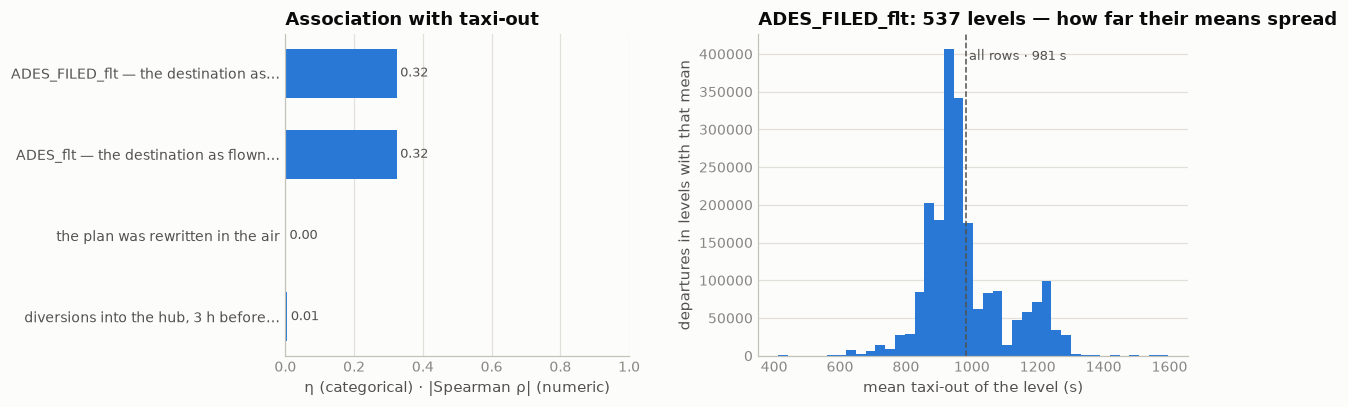

In [76]:
# correlation with the target: the filed destination, the flown one it is a copy of (§18), the diverted
# flag, and the arrival-side counter this section built out of the same column
TGTD = f"(SELECT t.*, coalesce(w.n_div_3h, 0) n_div_3h FROM {TGT} t LEFT JOIN div_w w USING (MVT_ID_mvt))"
a = target_assoc([
    ("ADES_FILED_flt — the destination as filed", "cat", "ADES_FILED_flt", 200),
    ("ADES_flt — the destination as flown (§18)", "cat", "ADES_flt", 200),
    ("the plan was rewritten in the air", "cat", "ADES_FILED_flt IS NOT NULL AND ADES_FILED_flt <> ADES_flt"),
    ("diversions into the hub, 3 h before takeoff", "num", "n_div_3h", 1, TGTD),
])
assoc_chart(a, "ADES_FILED_flt", min_support=200, title="ADES_FILED_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **It can never be an independent source.** | not one row in either file, in either phase, carries `ADES_FILED_flt` without `ADES_flt` or `ADES_flt` without `ADES_FILED_flt` — 0 and 0 across 4,857,331 rows. It is null on 22,470 training and 5,290 ranking departures: §2's plan-missing rate exactly, 1.08% and 1.53% | it cannot fill a hole the plan does not already fill. §6a's waterfall reads it second and it has **never fired**: of the 214 training and 29 ranking departures whose movement code is unusable, `ADES_flt` rescues 94 and 9 and the filed code rescues **0 more**. `ADES_flt = 'ZZZZ'` implies `ADES_FILED_flt = 'ZZZZ'` on 31 of 31 and 6 of 6 |
| **And it is a near-copy of the column §18 already covered.** | the two differ on 2,070 of 2,062,577 training departures (**0.100%**) and 410 of 339,551 ranking (0.121%); on arrivals, 1,997 of 2,067,301 and 436 of 342,141 | 99.90% of this column is a second spelling of one we have. Everything it is worth lives in the last tenth of a per cent |
| **A difference is a diversion, and the plan is where the aircraft landed.** | the arrival row carrying the same `FLIGHT_ID_mvt` settles it: on the 457 training and 94 ranking diversions with a findable landing, the aircraft landed where `ADES_flt` said **457 of 457** and **94 of 94**, and where `ADES_FILED_flt` said **0 of 457** and **0 of 94**. On the 314,816 and 50,829 undiverted controls both codes name the landing | the semantics are settled: `ADES_FILED_flt` is the destination before the diversion, `ADES_flt` the one after. Only diversions that ended at one of the ten hubs leave an arrival row, so this fixes the *direction* of the pair, not a rate |
| **Which means `ADES_flt` carries post-takeoff information.** | it is rewritten in the air on 0.100% of departures, and §18 recommended it for anything geographic | one departure in a thousand, so no prediction turns on it — but a route-distance or great-circle feature meant as a *cause* of taxi-out should read `ADES_FILED_flt`, the flight the crew pushed back for. `ADES_flt` describes the flight afterwards |
| **It closes 4.79% of §18's mystery, and confirms the rest.** | of the 29,160 training and 4,900 ranking departures where `ADES_flt` and `ADES_mvt` name different airports, the filed code backs the movement on **1,397** (4.79%) and **302** (6.16%), backs the plan on 27,731 (95.10%) and 4,595, and neither on 32 and 3 | §18 read the whole 1.42% as the movement naming a leg further down the rotation. That holds for 95.10% of it. The other 4.79% is the opposite fault — the movement is right about what was filed and was never told about the diversion. Two faults that looked like one now have separate names |
| **The diversions are the ones an airline would expect.** | training pairs: `LIRQ`→`LIRP` 28, `EPKK`→`EPKT` 25, `LXGB`→`LEMG` 25, `UUWW`→`LTFM` 19, `LTAZ`→`LTAU` 14 — Florence to Pisa, Kraków to Katowice, Gibraltar to Málaga; 51.6% of training and 58.5% of ranking diversions stay in the same country | the column behaves as documented. There is no data fault here to repair, which is why the section produces no derived file |
| **Being diverted says nothing about the taxi out.** | training departures 1–3600 s: **959 s** mean over the 2,059 diverted rows against **982 s** over the 2,057,342 flown as filed — *faster* — and the per-hub signs disagree: Istanbul 1,009 against 1,043, Schiphol 726 against 787, Frankfurt 903 against 861, Barcelona 1,414 against 956 on 33 rows | it could hardly be otherwise: the diversion is decided in the air, an hour or more after the taxi ended. The flag is an outcome of the flight, not a cause of its taxi, and 459 holdout rows could not measure one if it existed |
| **The ladders agree, on both bases.** | over the 327,485 Nov+Dec departures: airport 357.3 s, + destination country 338.6, + `dest_final` **335.2**, + the filed code in its place **335.0**, + the diverted flag 335.1, + the arrival-side counter 335.4. On §13's base over 324,629 rows: runway × anchor 283.7 → stand **274.0** → + the flag **274.0** | the three destinations — the movement's, the plan's (§18: 335.1) and the filed one — read the target identically to within a fifth of a second. There is nothing to choose between them and nothing to add on top |
| **The arrival end is the one thing no other column can see — and it is still worth nothing.** | 1,997 training and 436 ranking arrivals landed at a hub they had not filed for. Hub-days are not slower for it: 988 s with none, 971 with one, 949 with two, 980 with three. Within a hub the sign is not stable either — Schiphol 774 → 792 → 817 s but Charles de Gaulle 1,013 → 1,009 → 1,021 — and a 3 h trailing count moves §13's base from 274.0 to **274.1 s** | a hub taking diversions is not a hub taxiing slowly. At roughly one diversion per hub every other day (2,362 of ~3,650 hub-days see none) the event is too rare to move an RMSE, and where it moves a mean the direction is not consistent across hubs |
| **The rate is a recording convention, not a climate.** | diversions in per arrival, 2025: Madrid 0.155%, Zurich 0.151%, Fiumicino 0.151%, Munich 0.136%, Barcelona 0.114%, Istanbul 0.092%, Frankfurt 0.088%, Schiphol 0.083%, Heathrow 0.045%, **Charles de Gaulle 0.010%** — a fifteen-fold spread; and seven of the ten read higher in 2026 than in 2025 (Fiumicino 0.358% against 0.151%) | Paris does not divert fifteen times less often than Madrid; it files it fifteen times less often. A feature built on this count would be fitting each tower's paperwork, and would be mis-calibrated on the 2026 months on top of that |
| **Marginally it reads the target exactly as `ADES_flt` does.** | η 0.324 against 0.324 for the flown code, on the same 200-row support; the diverted flag 0.002 and the 3 h counter −0.006 | the correlation cell says the same as the ladder from the other side: two names for one category, and the two derived forms are flat against the target |

**Decisions**

| issue | decision | why |
|---|---|---|
| `ADES_FILED_flt` as the destination feature | drop it; §6a's `dest_final` stays the destination | 335.0 s against 335.2 s on the same 327,485 holdout rows — a fifth of a second, the same noise §18 measured for the plan's code. It is also the semantically *worse* of the two: on the 2,070 rows where the choice exists, it names an airport the aircraft did not go to |
| the diverted flag as a feature | drop it | 335.2 → 335.1 s on the destination, 274.0 → 274.0 s on §13's stand base, from 459 holdout rows. Nothing it marks had happened yet when the aircraft left the stand |
| diversions arriving into the hub, as a disruption sensor | drop it, and record why it was tested | it is the one idea in this column that no other column can supply, so it was built and measured rather than argued away: 274.0 → **274.1 s** on §13's base. The event is ~0.55 per hub per day, its per-hub rate varies fifteen-fold on filing practice, and the 2026 rate differs from 2025's at nine of the ten hubs |
| which destination a geographic feature should read | `ADES_flt` for where the aircraft went, `ADES_FILED_flt` for what was known at off-block | §18 settled the first on 1,908 landings and this section settles the second on 457 more. The two agree on 99.90% of departures, so the choice cannot move a score — it decides whether a feature is honest about what was knowable when the taxi started |
| §6a's sentinel waterfall | leave the `ADES_FILED_flt` layer in place, knowing it has never fired | 0 rescues in either file, because the two sentinels always appear together. The layer costs nothing and the order is right if the 2026 data ever splits the pair |

**Use in modeling.** Nothing from this column enters the model, and the section writes no derived file: the destination stays exactly as §6a left it. What §19 leaves behind is a definition and a caution. The definition is that `ADES_flt` minus `ADES_FILED_flt` is a diversion, verified on all 551 diversions whose landing we can see — the plan's code is where the aircraft went, the filed code where it had meant to go. The caution is the same fact read the other way: `ADES_flt`, which §18 recommended for anything geographic, is a field the data rewrites after our taxi has ended, so a distance or bearing feature built as a *cause* of taxi-out should read the filed code instead. And the one genuinely new idea the column offered — counting the flights that diverted *into* a hub as a sensor for a hub in trouble — was built and measured rather than assumed away; it moves §13's base by a tenth of a second, on an event that happens about once every other day per airport and whose rate says more about each tower's filing habits than about its weather.


## 20 · `MARKET_SEGMENT_flt` — what kind of airline is taxiing

The flight plan's commercial label for the operator: a legacy carrier's mainline service, its regional
subsidiary, a low-cost airline, a freighter, a business jet. It is the first column of the sweep that
describes the *business* behind a movement rather than the movement itself, and the question is whether
that business is still visible on the taxiway once we know where the aircraft parked and which runway
it is taxiing to.

| step | question | what came out |
|---|---|---|
| the levels | which values does the column take? | eight — `data/FEATURES.md` documents nine, under four spellings the data never uses |
| presence | when is it missing? | exactly when the flight plan is missing: 0 rows in 4.81 M carry a plan without a segment |
| on its own | does the segment move the taxi clock? | yes — 357.3 → 350.7 s, and on raw labels 496.5 → 470.0 s |
| whose gain is that? | is the raw-label jump the segment's? | no: 21.5 s of the 26.5 s is §2's missing-plan flag, 5.0 s is the segment |
| against the stand | does it survive §13? | 265.5 → 265.3 s — the hubs have already sorted the segments onto piers |
| against the operator | is it the carrier under another name? | no: inside Lufthansa, mainline taxis 817 s and the regional arm 578 s |
| the blanks | fill the 5,290 bare 2026 departures? | 4,110 are reachable from operator history — not worth a derived file at 0.2 s |

In [4]:
# what the column is: its levels, and the presence rule — a segment is missing exactly when the flight
# plan is missing, so these nulls are §2's flag over again and not a second piece of information
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
display(cat_stats("MARKET_SEGMENT_flt"))

print("presence by file × phase — and whether a plan ever arrives without a segment (§17: the plan is missing iff ADEP_flt IS NULL):")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (MARKET_SEGMENT_flt IS NULL) seg_null,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt IS NULL)/count(*), 2) pct_null,
           count(*) FILTER (ADEP_flt IS NULL) plan_missing,
           count(*) FILTER (ADEP_flt IS NOT NULL AND MARKET_SEGMENT_flt IS NULL) plan_but_no_seg
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
assert con.sql(f"SELECT count(*) FROM {BOTH} WHERE ADEP_flt IS NOT NULL AND MARKET_SEGMENT_flt IS NULL").fetchone()[0] == 0

print("\nthe levels — training departures 1–3600 s beside the 2026 departures we must predict:")
print(con.sql(f"""
    WITH t AS (SELECT coalesce(MARKET_SEGMENT_flt, '(no plan)') seg, count(*) n, avg(TAXITIME_SEC_mvt) mean_taxi,
                      quantile_cont(TAXITIME_SEC_mvt, 0.5) med, quantile_cont(TAXITIME_SEC_mvt, 0.9) p90,
                      stddev(TAXITIME_SEC_mvt) sd
               FROM {TGT} GROUP BY 1),
         r AS (SELECT coalesce(MARKET_SEGMENT_flt, '(no plan)') seg, count(*) n
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT t.seg, t.n train_n, round(100.0*t.n/sum(t.n) OVER (), 2) train_pct,
           r.n rank_n, round(100.0*r.n/sum(r.n) OVER (), 2) rank_pct,
           round(t.mean_taxi) mean_taxi, round(t.med) med, round(t.p90) p90, round(t.sd) sd
    FROM t JOIN r USING (seg) ORDER BY train_n DESC, seg""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,8
ranking 2026,689534,7842,1.14,8


presence by file × phase — and whether a plan ever arrives without a segment (§17: the plan is missing iff ADEP_flt IS NULL):
     src  ph       n  seg_null  pct_null  plan_missing  plan_but_no_seg
training ARR 2082750     15449      0.74         15449                0
training DEP 2085047     22470      1.08         22470                0
 ranking ARR  344693      2552      0.74          2552                0
 ranking DEP  344841      5290      1.53          5290                0

the levels — training departures 1–3600 s beside the 2026 departures we must predict:
          seg  train_n  train_pct  rank_n  rank_pct  mean_taxi   med    p90    sd
     Mainline  1323491      63.61  223574     64.83     1027.0 957.0 1515.0 392.0
      Lowcost   398910      19.17   65285     18.93      964.0 911.0 1368.0 341.0
     Regional   210794      10.13   29590      8.58      769.0 724.0 1151.0 320.0
        Cargo    59939       2.88    9908      2.87     1014.0 953.0 1511.0 398.0
     Business    

In [5]:
# the segment is geography: how the hubs are composed, and how completely each pier belongs to one segment
print("segment mix per hub — % of the hub's training departures (1–3600 s):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Mainline')/count(*), 1) mainline,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Lowcost')/count(*), 1) lowcost,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Regional')/count(*), 1) regional,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Cargo')/count(*), 1) cargo,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Business')/count(*), 1) business,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt = 'Non-Scheduled')/count(*), 1) nonsched,
           round(100.0*count(*) FILTER (MARKET_SEGMENT_flt IS NULL)/count(*), 1) no_plan
    FROM {TGT} GROUP BY 1 ORDER BY n DESC, hub""").df().to_string(index=False))

print("\nthe piers that belong to one non-mainline segment (≥ 200 departures, ≥ 60% one segment) — §13's stand already knows this:")
print(con.sql(f"""
    WITH s AS (SELECT ADEP_mvt hub, {PFX} pfx, MARKET_SEGMENT_flt seg, count(*) n FROM {TGT}
               WHERE STAND_mvt IS NOT NULL AND MARKET_SEGMENT_flt IS NOT NULL GROUP BY 1, 2, 3),
         q AS (SELECT hub, pfx, sum(n) n, max(n)/sum(n) top_share FROM s GROUP BY 1, 2),
         top AS (SELECT hub, pfx, seg FROM s QUALIFY row_number() OVER (PARTITION BY hub, pfx ORDER BY n DESC, seg) = 1)
    SELECT q.hub, q.pfx, q.n, top.seg top_segment, round(100.0*q.top_share, 1) share_pct
    FROM q JOIN top USING (hub, pfx)
    WHERE q.n >= 200 AND q.top_share >= 0.6 AND top.seg <> 'Mainline'
    ORDER BY q.n DESC, q.hub, q.pfx LIMIT 15""").df().to_string(index=False))

segment mix per hub — % of the hub's training departures (1–3600 s):
 hub      n  mainline  lowcost  regional  cargo  business  nonsched  no_plan
LTFM 272169      87.6      2.9       1.8    4.3       0.8       0.8      1.3
EHAM 247866      48.5     21.0      22.8    2.6       2.4       0.9      1.6
LFPG 239091      66.7     11.5      11.8    7.0       0.2       0.8      1.6
EGLL 238818      95.3      2.4       1.0    0.5       0.0       0.1      0.6
EDDF 230068      63.3     13.6      15.3    4.9       1.5       0.4      0.8
LEMD 212242      54.5     24.5      12.3    2.7       4.0       1.2      0.4
LEBL 179699      23.2     68.7       1.4    1.7       3.2       0.6      1.0
EDDM 167275      62.2     13.0      18.0    1.1       3.7       0.9      0.6
LIRF 158737      53.7     40.8       3.0    1.1       0.0       0.6      0.5
LSZH 134568      63.7      9.3      14.9    0.3       8.9       0.6      1.5

the piers that belong to one non-mainline segment (≥ 200 departures, ≥ 60% one segm

In [6]:
# what the segment buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 else the
# coarser rung. First against the airport mean, beside the two columns it might be standing in for;
# then on top of §13's base, where the stand has already placed the aircraft on the airfield
con.sql(f"""
    CREATE OR REPLACE TABLE seg_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, {TYPE_FINAL} typ,
           coalesce(MARKET_SEGMENT_flt, '(no plan)') seg, id_prefix(CALLSIGN_flt) op,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""")


def seg_cat(keys, tbl="seg_d", where="TRUE"):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val AND {where} GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM {tbl} WHERE NOT is_val AND {where} GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM {tbl} v LEFT JOIN f USING ({keys}) JOIN h USING (hub)
        WHERE v.is_val AND {where}""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM seg_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures ('(no plan)' is its own level):")
for name, keys in [("airport (§5)", "hub"), ("+ segment", "hub, seg"), ("+ aircraft type (§11)", "hub, typ"),
                   ("+ operator token (§16)", "hub, op"), ("+ segment × type", "hub, seg, typ")]:
    print(f"    {name:44s} {seg_cat(keys):7.1f} s")

con.sql("""
    CREATE OR REPLACE TABLE seg_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM seg_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT seg_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
    FROM seg_d JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")


def seg_rungs(rungs, tbl="seg_wb"):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE seg_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN seg_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN seg_s{i}.c >= 30 THEN seg_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway (§12)", ["hub", "rwy"]), ("+ AOBT_3 anchor (§9)", ["hub", "rwy", "q_anc"]),
        ("+ prefix (§13)", ["hub", "rwy", "q_anc", "pfx"]), ("+ stand (§13's base)", ["hub", "rwy", "q_anc", "pfx", "stand"])]
n2 = con.sql("SELECT count(*) FROM seg_wb WHERE is_val").fetchone()[0]
print(f"\n(2) on §13's base — the {n2:,} Nov+Dec departures with a runway, a stand and an anchor:")
for name, r in seg_rungs(BASE):
    print(f"    {name:44s} {r:7.1f} s")
for name, keys in [("+ segment, on top", ["seg"]), ("+ type, on top", ["typ"]),
                   ("+ type then segment", ["typ", "seg"]), ("+ operator token, on top", ["op"])]:
    print(f"    {name:44s} {seg_rungs(BASE + [('x', BASE[-1][1] + keys)])[-1][1]:7.1f} s")

(1) on top of the airport mean — 327,485 Nov+Dec departures ('(no plan)' is its own level):
    airport (§5)                                   357.3 s
    + segment                                      350.7 s
    + aircraft type (§11)                          337.9 s
    + operator token (§16)                         336.0 s
    + segment × type                               335.9 s



(2) on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor:
    airport                                        355.4 s
    + runway (§12)                                 341.8 s
    + AOBT_3 anchor (§9)                           283.6 s
    + prefix (§13)                                 268.6 s
    + stand (§13's base)                           265.5 s


    + segment, on top                              265.3 s
    + type, on top                                 265.3 s


    + type then segment                            265.3 s
    + operator token, on top                       265.2 s


In [7]:
# the score sees raw labels (§14), where the segment looks four times as valuable — so split the gain:
# how much is the null level (§2's missing plan) and how much is the segment's eight real levels
con.sql(f"""
    CREATE OR REPLACE TABLE seg_raw AS
    SELECT ADEP_mvt hub, coalesce(MARKET_SEGMENT_flt, '(no plan)') seg, MARKET_SEGMENT_flt IS NULL no_plan,
           coalesce(MARKET_SEGMENT_flt, 'x') seg_only, {TYPE_FINAL} typ,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1""")

n = con.sql("SELECT count(*) FROM seg_raw WHERE is_val").fetchone()[0]
print(f"raw labels, no ceiling — all {n:,} Nov+Dec departures. Who owns the gain?")
for name, keys in [("airport (§14's baseline)", "hub"), ("+ the missing-plan flag alone (§2)", "hub, no_plan"),
                   ("+ the whole segment (8 levels + null)", "hub, seg"), ("+ aircraft type (§11)", "hub, typ")]:
    print(f"    {name:48s} {seg_cat(keys, 'seg_raw'):7.1f} s")

n2 = con.sql("SELECT count(*) FROM seg_raw WHERE is_val AND NOT no_plan").fetchone()[0]
print(f"\nthe same ladder on the {n2:,} Nov+Dec departures that DO carry a plan — the segment with the flag taken away:")
for lbl, where in [("raw labels, no ceiling", "NOT no_plan"), ("labels 1–3600 s", "NOT no_plan AND y BETWEEN 1 AND 3600")]:
    a = seg_cat("hub", "seg_raw", where)
    b = seg_cat("hub, seg_only", "seg_raw", where)
    print(f"    {lbl:28s} airport {a:7.1f} s  →  + segment {b:7.1f} s   ({a - b:.1f} s)")

print("\nwhy the null level is worth so much — the tail per segment, training departures, raw labels:")
print(con.sql("""
    SELECT seg, count(*) n, round(avg(y)) mean_taxi, round(quantile_cont(y, 0.99)) p99, round(max(y)) max_taxi,
           count(*) FILTER (y > 3600) over_1h, round(100.0*count(*) FILTER (y > 3600)/count(*), 3) pct_over_1h
    FROM seg_raw GROUP BY 1 ORDER BY n DESC, seg""").df().to_string(index=False))

raw labels, no ceiling — all 327,968 Nov+Dec departures. Who owns the gain?
    airport (§14's baseline)                           496.5 s
    + the missing-plan flag alone (§2)                 475.0 s
    + the whole segment (8 levels + null)              470.0 s
    + aircraft type (§11)                              481.3 s

the same ladder on the 324,990 Nov+Dec departures that DO carry a plan — the segment with the flag taken away:
    raw labels, no ceiling       airport   373.7 s  →  + segment   367.3 s   (6.4 s)
    labels 1–3600 s              airport   355.4 s  →  + segment   348.8 s   (6.5 s)

why the null level is worth so much — the tail per segment, training departures, raw labels:


          seg       n  mean_taxi     p99  max_taxi  over_1h  pct_over_1h
     Mainline 1325700     1033.0  2399.0   15059.0     2209        0.167
      Lowcost  399475      969.0  2156.0   87002.0      565        0.141
     Regional  210854      770.0  1796.0   10779.0       60        0.028
        Cargo   60014     1018.0  2348.0   21308.0       75        0.125
     Business   44446      780.0  1977.0    5699.0       12        0.027
    (no plan)   22219     1400.0 10254.0  131167.0     1087        4.892
Non-Scheduled   14573      996.0  3202.0   10972.0      107        0.734
        Other    6665      891.0  2347.0    5936.0       10        0.150
     Military     713      835.0  2626.0    4324.0        1        0.140


In [8]:
# is the segment just the operator? If every carrier flew one segment the column would be §16's token
# in disguise — it is not, and the gap is exactly the mainline/regional split inside the flag carriers
print("segment against the operator token (§16), training departures with an ICAO callsign prefix:")
print(con.sql(f"""
    WITH o AS (SELECT id_prefix(CALLSIGN_flt) op, MARKET_SEGMENT_flt seg, count(*) n FROM {TGT}
               WHERE id_prefix(CALLSIGN_flt) IS NOT NULL AND MARKET_SEGMENT_flt IS NOT NULL GROUP BY 1, 2),
         p AS (SELECT op, sum(n) n, count(*) n_seg, max(n)/sum(n) purity FROM o GROUP BY 1)
    SELECT count(*) n_operators, sum(n)::BIGINT n_rows,
           round(100.0*count(*) FILTER (n_seg = 1)/count(*), 2) pct_operators_one_segment,
           round(100.0*sum(n) FILTER (n_seg = 1)/sum(n), 2) pct_rows_one_segment,
           round(100.0*sum(n*purity)/sum(n), 2) pct_rows_in_operator_modal_segment
    FROM p""").df().to_string(index=False))

print("\nthe carriers that really do split (≥ 500 departures, modal segment under 95%):")
print(con.sql(f"""
    WITH o AS (SELECT id_prefix(CALLSIGN_flt) op, MARKET_SEGMENT_flt seg, count(*) n FROM {TGT}
               WHERE id_prefix(CALLSIGN_flt) IS NOT NULL AND MARKET_SEGMENT_flt IS NOT NULL GROUP BY 1, 2)
    SELECT op, sum(n)::BIGINT n, count(*) n_seg, round(100.0*max(n)/sum(n), 1) modal_pct,
           string_agg(seg || ':' || n, ' | ' ORDER BY n DESC, seg) split
    FROM o GROUP BY 1 HAVING sum(n) >= 500 AND max(n)/sum(n) < 0.95
    ORDER BY n DESC, op LIMIT 8""").df().to_string(index=False))

print("\nand what the split is worth — mainline vs its regional arm, same carrier, training departures 1–3600 s:")
print(con.sql(f"""
    SELECT id_prefix(CALLSIGN_flt) op, MARKET_SEGMENT_flt seg, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med
    FROM {TGT} WHERE id_prefix(CALLSIGN_flt) IN ('DLH', 'KLM', 'AFR', 'SWR', 'LOT')
      AND MARKET_SEGMENT_flt IN ('Mainline', 'Regional')
    GROUP BY 1, 2 ORDER BY op, seg""").df().to_string(index=False))

print("\nthe 2026 departures with no segment — how far operator history could get us, if it were worth it:")
print(con.sql(f"""
    WITH hist AS (SELECT id_prefix(CALLSIGN_flt) op, MARKET_SEGMENT_flt seg, count(*) n FROM {BOTH}
                  WHERE id_prefix(CALLSIGN_flt) IS NOT NULL AND MARKET_SEGMENT_flt IS NOT NULL GROUP BY 1, 2
                  QUALIFY row_number() OVER (PARTITION BY op ORDER BY n DESC, seg) = 1),
         miss AS (SELECT MVT_ID_mvt, id_prefix(FLIGHT_mvt) op FROM {R}
                  WHERE PHASE_mvt = 'DEP' AND MARKET_SEGMENT_flt IS NULL)
    SELECT count(*) bare_departures, count(*) FILTER (miss.op IS NOT NULL) with_a_movement_token,
           count(*) FILTER (h.op IS NOT NULL) fillable_from_history
    FROM miss LEFT JOIN hist h USING (op)""").df().to_string(index=False))

segment against the operator token (§16), training departures with an ICAO callsign prefix:
 n_operators  n_rows  pct_operators_one_segment  pct_rows_one_segment  pct_rows_in_operator_modal_segment
         975 2048071                       68.0                 19.08                               91.42

the carriers that really do split (≥ 500 departures, modal segment under 95%):
 op      n  n_seg  modal_pct                                                                                    split
DLH 222843      5       88.8            Mainline:197777 | Regional:24364 | Other:357 | Non-Scheduled:343 | Business:2
KLM 141460      4       62.5                            Mainline:88365 | Regional:52779 | Other:313 | Non-Scheduled:3
AFR 140207      6       79.2 Mainline:111044 | Regional:27880 | Other:662 | Cargo:578 | Non-Scheduled:39 | Business:4
SWR  78012      4       75.3                           Mainline:58738 | Regional:19093 | Other:166 | Non-Scheduled:15
ITY  52349      5       90

 bare_departures  with_a_movement_token  fillable_from_history
            5290                   4944                   4110


                                    feature        kind  n / levels  pearson_r  spearman_ρ     η
MARKET_SEGMENT_flt — the commercial segment categorical           9                        0.214
   its null level alone — §2's missing plan categorical           2                        0.007
                       operator token (§16) categorical         545                        0.463
                       aircraft type (§11a) categorical         107                        0.358
                  stand prefix / pier (§13) categorical         130                        0.551


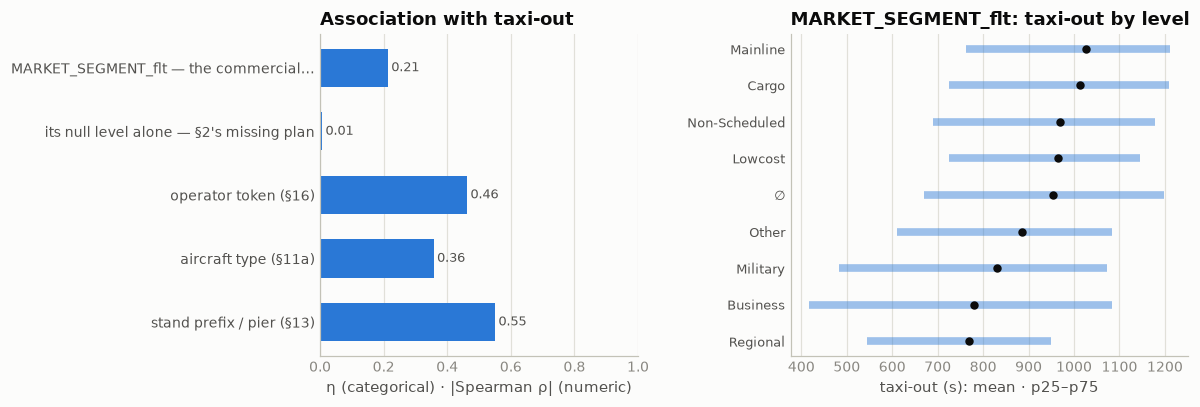

In [9]:
# correlation with the target: the segment, the missing-plan flag hiding inside its nulls, and the
# three columns it could be standing in for — the operator (§16), the type (§11a), the pier (§13)
a = target_assoc([
    ("MARKET_SEGMENT_flt — the commercial segment", "cat", "MARKET_SEGMENT_flt"),
    ("its null level alone — §2's missing plan", "cat", "MARKET_SEGMENT_flt IS NULL"),
    ("operator token (§16)", "cat", "id_prefix(CALLSIGN_flt)", 20),
    ("aircraft type (§11a)", "cat", TYPE_FINAL, 200),
    ("stand prefix / pier (§13)", "cat", f"ADEP_mvt || '/' || {PFX}", 30),
])
assoc_chart(a, "MARKET_SEGMENT_flt", title="MARKET_SEGMENT_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The column has eight levels, not the nine `FEATURES.md` documents.** | `Mainline` 63.61%, `Lowcost` 19.17%, `Regional` 10.13%, `Cargo` 2.88%, `Business` 2.14%, `Non-Scheduled` 0.70%, `Other` 0.32%, `Military` 0.03%. The documented `Low-Cost`, `Business Aviation`, `All-Cargo`, `Charter` and `Not classified` never appear. | Encode against the values in the data, not the doc. `data/FEATURES.md` needs the correction. |
| **A segment is missing exactly when the flight plan is missing.** | 0 of the 4,811,570 rows carrying a plan lack a segment, in either file; the null count equals §17's `ADEP_flt IS NULL` count in every file × phase cell (1.08% of training departures, 1.53% of ranking). | The nulls are §2's missing-plan flag over again. Keep them as a level, but do not count them as a second feature. |
| **On its own the segment is worth 6.6 s.** | Airport mean 357.3 → 350.7 s on the honest holdout. The aircraft type is 337.9 s and §16's operator token 336.0 s on the same rows. | Real, but the weakest of the three identity columns. |
| **Most of its raw-label value belongs to §2, not here.** | Raw labels: 496.5 → 475.0 s with the missing-plan flag alone, → 470.0 s with the whole segment. Of the 26.5 s, **21.5 s is the flag and 5.0 s is the segment**. On plan-carrying rows only the segment is 373.7 → 367.3 s raw (6.4 s) and 355.4 → 348.8 s filtered (6.5 s). | Quote the segment at 5–7 s and let §2's flag carry the tail. A ladder that adds the segment to raw labels and claims 26 s is crediting this column with another section's feature. |
| **The null level is a tail marker, which is why it dominates the raw ladder.** | Departures with no plan: mean 1,400 s, p99 10,254 s, max 131,167 s, and **4.892% run over an hour** against 0.167% for `Mainline` and 0.028% for `Regional`. Its η against the target is only 0.007 on the 1–3600 s rows — all of its worth is in the tail the filter removes. | §14's point restated: a few dozen tail rows decide the score, and the missing-plan rows are where they live. |
| **On top of §13's stand the segment is worth 0.2 s.** | 265.5 → 265.3 s. The type adds 0.2 s, type-then-segment 0.2 s, the operator token 0.3 s — the whole identity block collapses once the anchor and the stand are in. | Do not build a segment feature *for* a model that already has the stand. |
| **Because the segment is geography.** | Each hub sorts its segments onto piers: LEBL pier `1` is 88.0% `Lowcost`, EHAM `H` is 100.0%, LFPG `J` is 94.6% `Regional`, LFPG `I` 84.8% and LTFM `K` 88.7% `Cargo`, EHAM `K` 91.8% `Business`. Hub mixes differ as sharply — EGLL is 95.3% `Mainline`, LEBL 68.7% `Lowcost`, LSZH 8.9% `Business`. The matrix agrees: `MARKET_SEGMENT_flt` × `STAND_mvt` is 0.53. | §13's stand already encodes the segment spatially. This is the §16 result again: an identity column the airfield has pre-sorted. |
| **It is not the operator under another name.** | Only 19.08% of departures belong to an operator that flies a single segment (68.0% of the 975 operators, but they are small); 91.42% of rows sit in their operator's modal segment. KLM is 62.5% modal, LOT 52.6%, SWR 75.3%. Cramér's V against `CALLSIGN_flt` is 0.78 — high, not a copy. | The segment carries something the operator token cannot: which *arm* of a carrier is flying. |
| **And that split is large.** | Same carrier, mainline vs its regional arm: DLH 817 → 578 s, SWR 828 → 687 s, LOT 1,068 → 844 s, KLM 801 → 701 s, AFR 1,010 → 894 s. | Where a model has the operator but not the stand, the segment is the cheapest way to separate a flag carrier's two fleets. |

**Decisions**

| issue | decision | why |
|---|---|---|
| 5,290 ranking departures carry no segment | **Leave them null; no derived file.** | 4,110 are reachable from the operator's modal segment, but the column is worth 0.2 s on §13's base and the modal map is only 91.42% pure on rows — the imputation would be wrong precisely on the flag carriers the column exists to split. Cost without benefit. |
| the null level | **Keep it as an explicit level**, not an imputed value | It is §2's missing-plan flag, and §14's tail lives there — 4.892% over an hour against `Mainline`'s 0.167%. Folding it into a real segment would hide the one thing it is good for. |
| which form the pipeline consumes | **The raw column**, nulls included | No recovery, no derived form; at nine levels there is nothing to pool. |
| `FEATURES.md` disagrees with the data | **Flag it, do not silently rewrite** | The doc is tracked and shared, and the fix is a one-line change that belongs in its own commit rather than buried in a notebook section. |

**Use in modeling.** Feed `MARKET_SEGMENT_flt` as a plain categorical with null kept as its own level —
eight real levels plus `(no plan)`, no pooling needed at this cardinality. Expect it to earn its 5–7 s
only in a model that lacks the stand; in the ladder this sweep has been building it is a 0.2 s rounding
error, because §13's stand already places the aircraft on the pier its segment uses. The one thing it
knows that no neighbour does is the mainline-versus-regional split inside a flag carrier — 239 s of mean
taxi at Lufthansa — so keep it in a model built on the operator and drop it from one built on the stand.
Its nulls belong to §2's missing-plan flag; do not double-count them.

## 21 · `IOBT_flt` — the off-block the plan was first filed with

The second of the flight plan's four clocks: the **initial off-block time**, the estimate the
Network Manager held when the plan was first filed, before any revision. §15's clock, `LOBT_flt`,
is the *last* value of that same field — this one is the first. Where a flight never refiled, and
almost none do, the two are the same stamp, so the section's question is not what the initial clock
is worth on its own but a narrower one: **on the rows where the two disagree, which of them was
right?**

That question has a referee. In training the actual off-block is visible, so both clocks can be
scored against the thing they were each estimating. §19 put the two destination codes to the same
test and the *later* one won, 551 of 551; here the answer goes the other way.

| step | question | what came out |
|---|---|---|
| **census** | present where; which grid; against the schedule and the plan's other clocks | on **exactly** the rows `LOBT_flt` is — no departure in either file carries one without the other; always a whole minute; the schedule on 74.4% |
| **the copy** | how often is the initial clock still the last one | 99.45% of departures with a plan; 11,267 differ, a median 1 min apart, as often earlier as later |
| **the referee** | where they differ, which clock sat closer to the actual off-block | **the initial one, on 73.8%** — median error 7.0 min against 12.0, within 5 min on 40.0% against 11.6%. The refile moves the plan's clock *away* from the pushback |
| **signal** | honest ladders: the initial clock's gap and its delay against §15's, the refile on top of §15's base | 300.9 and 260.4 against §15's 301.2 and 261.0; the refile itself buys nothing |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures as §15 — one plan block carries both clocks |


In [4]:
# census by file × phase: the initial clock against the last one — where each is present, whether either ever appears without
# the other, which grid it sits on; then the rows with a FLIGHT_ID and no clock, and the initial clock against the plan's others
print("IOBT_flt by file × phase — and the rows where only one of the two clocks is there:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (IOBT_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (IOBT_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           count(*) FILTER (IOBT_flt IS NOT NULL AND LOBT_flt IS NULL) iobt_without_lobt,
           count(*) FILTER (IOBT_flt IS NULL AND LOBT_flt IS NOT NULL) lobt_without_iobt,
           round(100.0*count(*) FILTER (extract(second FROM IOBT_flt) = 0)/count(IOBT_flt), 1) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM IOBT_flt) % 5 = 0 AND extract(second FROM IOBT_flt) = 0)/count(IOBT_flt), 1) pct_on_5min_grid,
           count(DISTINCT IOBT_flt) n_unique, strftime(min(IOBT_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(IOBT_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndepartures with a plan: the initial clock against the schedule and the plan's other three (training):")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (IOBT_flt = LOBT_flt)/count(*), 2) eq_lobt, count(*) FILTER (IOBT_flt != LOBT_flt) n_refiled,
           round(100.0*count(*) FILTER (IOBT_flt < LOBT_flt)/count(*), 2) iobt_earlier, round(100.0*count(*) FILTER (IOBT_flt > LOBT_flt)/count(*), 2) iobt_later,
           round(100.0*count(*) FILTER (IOBT_flt = SCHED_TIME_UTC_mvt)/count(*), 1) eq_schedule,
           round(100.0*count(*) FILTER (IOBT_flt = EOBT_1_flt)/count(*), 1) eq_eobt1,
           round(100.0*count(*) FILTER (IOBT_flt > MVT_TIME_UTC_mvt)/count(*), 2) after_the_takeoff,
           round(100.0*count(*) FILTER (IOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) after_aobt3
    FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL AND LOBT_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):")
for name, expr in [("LOBT − IOBT, the refile, where it moved", "CASE WHEN LOBT_flt != IOBT_flt THEN epoch(LOBT_flt - IOBT_flt)/60 END"),
                   ("IOBT − schedule, filed at first", "epoch(IOBT_flt - SCHED_TIME_UTC_mvt)/60"),
                   ("AOBT_3 − IOBT, the delay from the first filing", "epoch(AOBT_3_flt - IOBT_flt)/60"),
                   ("AOBT_3 − LOBT, §15's unfiled delay", "epoch(AOBT_3_flt - LOBT_flt)/60"),
                   ("off-block − IOBT (hidden)", "epoch(BLOCK_TIME_UTC_mvt - IOBT_flt)/60"),
                   ("takeoff − IOBT", "epoch(MVT_TIME_UTC_mvt - IOBT_flt)/60")]:
    q, n = con.sql(f"SELECT quantile_cont({expr}, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]), count({expr}) FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL").fetchone()
    print(f"  {name:44s} n = {n:>9,}   " + "  ".join(f"{x:7.1f}" for x in q))

IOBT_flt by file × phase — and the rows where only one of the two clocks is there:


     src  ph       n  n_null  no_plan  null_with_an_id  iobt_without_lobt  lobt_without_iobt  pct_on_minute  pct_on_5min_grid  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506             6943                  0                  0          100.0              95.0    192129 2025-01-01 00:00 2025-12-31 23:02
training DEP 2085047   22470    22424               46                  0                  0          100.0              95.4    178164 2025-01-01 00:20 2025-12-31 23:40
 ranking ARR  344693    2552     1409             1143                  0                  0          100.0              94.7     33156 2026-01-01 00:00 2026-07-31 22:55
 ranking DEP  344841    5290     5283                7                  0                  0          100.0              94.9     31284 2026-01-01 00:04 2026-07-31 23:30

departures with a plan: the initial clock against the schedule and the plan's other three (training):
      n  eq_lobt  n_refiled  iobt_earlier  iobt

  IOBT − schedule, filed at first              n = 2,062,577     -10.0      0.0      0.0      0.0      0.0     25.0    120.0


  AOBT_3 − IOBT, the delay from the first filing n = 2,062,577     -18.0     -7.0     -2.0      4.0     11.0     20.0     46.0


  AOBT_3 − LOBT, §15's unfiled delay           n = 2,062,577     -18.0     -7.0     -2.0      4.0     11.0     20.0     46.0


  off-block − IOBT (hidden)                    n = 2,062,577     -13.9     -4.2     -0.1      4.2     11.0     18.9     43.8


  takeoff − IOBT                               n = 2,062,577       0.9      9.5     14.2     20.6     28.4     38.0     64.0


In [5]:
# the referee: on the rows where the two clocks disagree, the actual off-block is visible in training, so score both against it.
# Overall, then by the direction the refile moved the clock, then per hub. DIFF is the 11,267 disagreeing departures with a block stamp
DIFF = (f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL AND LOBT_flt IS NOT NULL"
        f" AND IOBT_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL)")
E_I, E_L = "abs(epoch(BLOCK_TIME_UTC_mvt - IOBT_flt))", "abs(epoch(BLOCK_TIME_UTC_mvt - LOBT_flt))"

print("where the two clocks differ — each against the actual off-block (training departures):")
print(con.sql(f"""
    SELECT count(*) n, round(avg({E_I})/60, 1) mean_err_iobt_min, round(avg({E_L})/60, 1) mean_err_lobt_min,
           round(quantile_cont({E_I}/60, 0.5), 1) med_err_iobt, round(quantile_cont({E_L}/60, 0.5), 1) med_err_lobt,
           count(*) FILTER ({E_I} < {E_L}) iobt_closer, count(*) FILTER ({E_L} < {E_I}) lobt_closer, count(*) FILTER ({E_I} = {E_L}) tie,
           round(100.0*count(*) FILTER ({E_I} < {E_L})/count(*), 1) pct_iobt_closer,
           round(100.0*count(*) FILTER ({E_I} <= 300)/count(*), 1) pct_iobt_within_5min, round(100.0*count(*) FILTER ({E_L} <= 300)/count(*), 1) pct_lobt_within_5min
    FROM {DIFF}""").df().to_string(index=False))

print("\nthe same two clocks on every departure that has both — the 99.45% that agree drown the difference:")
print(con.sql(f"""
    SELECT count(*) n, round(avg({E_I})/60, 2) mean_err_iobt_min, round(avg({E_L})/60, 2) mean_err_lobt_min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL AND LOBT_flt IS NOT NULL AND BLOCK_TIME_UTC_mvt IS NOT NULL""").df().to_string(index=False))

print("\nby the direction the refile moved the clock (the disagreeing departures):")
print(con.sql(f"""
    SELECT CASE WHEN d < 0 THEN '1 · refiled earlier' WHEN d <= 900 THEN '2 · later by ≤ 15 min' WHEN d <= 3600 THEN '3 · 15–60 min later' ELSE '4 · over 1 h later' END refile,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(100.0*count(*) FILTER ({E_I} < {E_L})/count(*), 1) pct_iobt_closer,
           round(avg({E_I})/60, 1) mean_err_iobt_min, round(avg({E_L})/60, 1) mean_err_lobt_min,
           round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM (SELECT *, epoch(LOBT_flt - IOBT_flt) d FROM {DIFF}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nper hub — who refiles, and whether the refile helped (training departures with both clocks):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, count(*) FILTER (IOBT_flt != LOBT_flt) n_refiled,
           round(100.0*count(*) FILTER (IOBT_flt != LOBT_flt)/count(*), 2) pct_refiled,
           round(100.0*count(*) FILTER (IOBT_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL AND {E_I} < {E_L})
                 /nullif(count(*) FILTER (IOBT_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL), 0), 1) pct_iobt_closer
    FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL AND LOBT_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

where the two clocks differ — each against the actual off-block (training departures):
    n  mean_err_iobt_min  mean_err_lobt_min  med_err_iobt  med_err_lobt  iobt_closer  lobt_closer  tie  pct_iobt_closer  pct_iobt_within_5min  pct_lobt_within_5min
11267               11.4               14.3           7.0          12.0         8321         2936   10             73.9                  40.0                  11.6

the same two clocks on every departure that has both — the 99.45% that agree drown the difference:


      n  mean_err_iobt_min  mean_err_lobt_min
2062577               8.57               8.59

by the direction the refile moved the clock (the disagreeing departures):
               refile    n  pct  pct_iobt_closer  mean_err_iobt_min  mean_err_lobt_min  mean_taxi  med_taxi
  1 · refiled earlier 5264 46.7             86.8               12.1               15.9     1163.0    1025.0
2 · later by ≤ 15 min 4818 42.8             63.4                9.7               12.7     1177.0    1051.0
  3 · 15–60 min later 1147 10.2             60.2               13.9               13.7     1270.0    1164.0
   4 · over 1 h later   38  0.3             13.2               73.9               17.3     1562.0    1246.0

per hub — who refiles, and whether the refile helped (training departures with both clocks):


 hub      n  n_refiled  pct_refiled  pct_iobt_closer
EDDF 228185        832         0.36             72.1
EDDM 166324        209         0.13             55.0
EGLL 238132       1377         0.58             59.1
EHAM 243867         47         0.02             66.0
LEBL 177843       1601         0.90             83.9
LEMD 211295       1144         0.54             87.8
LFPG 235779        148         0.06             54.1
LIRF 159216        237         0.15             41.8
LSZH 132616         46         0.03             58.7
LTFM 269320       5626         2.09             74.8


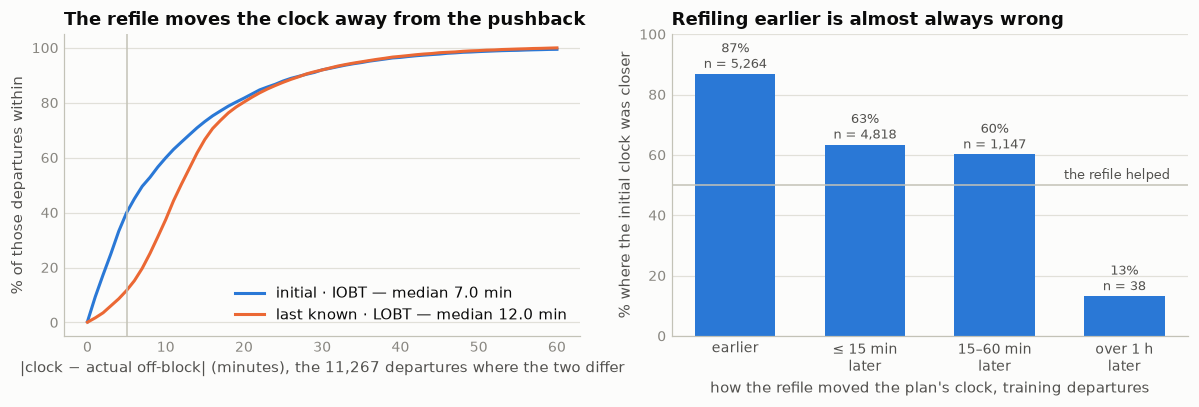

In [6]:
# the picture: how close each clock sat to the actual off-block on the departures where they differ, and which one wins
# by the direction of the refile — the mechanism behind the referee's verdict
ref = con.sql(f"""
    SELECT {E_I}/60 e_iobt, {E_L}/60 e_lobt,
           CASE WHEN epoch(LOBT_flt - IOBT_flt) < 0 THEN 'earlier' WHEN epoch(LOBT_flt - IOBT_flt) <= 900 THEN '≤ 15 min\nlater'
                WHEN epoch(LOBT_flt - IOBT_flt) <= 3600 THEN '15–60 min\nlater' ELSE 'over 1 h\nlater' END dirn
    FROM {DIFF}""").df()
ORDER = ["earlier", "≤ 15 min\nlater", "15–60 min\nlater", "over 1 h\nlater"]
win = (ref.assign(iobt_closer=ref.e_iobt < ref.e_lobt).groupby("dirn")
          .agg(n=("dirn", "size"), pct=("iobt_closer", "mean")).assign(pct=lambda d: 100 * d.pct).reindex(ORDER))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
grid = np.arange(0, 61)
for lab, col, v in [("initial · IOBT", BLUE, ref.e_iobt), ("last known · LOBT", ORANGE, ref.e_lobt)]:
    a1.plot(grid, [100 * (v <= g).mean() for g in grid], lw=2, color=col, label=f"{lab} — median {v.median():.1f} min")
a1.axvline(5, color=BASELINE, lw=1)
a1.set_title("The refile moves the clock away from the pushback")
a1.set_xlabel(f"|clock − actual off-block| (minutes), the {len(ref):,} departures where the two differ")
a1.set_ylabel("% of those departures within")
a1.legend(loc="lower right")
style(a1)
a2.bar(range(len(win)), win.pct, color=BLUE, width=0.62)
a2.axhline(50, color=BASELINE, lw=1)
a2.text(3.35, 52, "the refile helped", fontsize=8.5, color=INK2, ha="right")
for i, (p, n) in enumerate(zip(win.pct, win.n)):
    a2.text(i, p + 2, f"{p:.0f}%\nn = {n:,}", ha="center", fontsize=8.5, color=INK2)
a2.set_xticks(range(len(win)), win.index, color=INK2)
a2.set_ylim(0, 100)
a2.set_title("Refiling earlier is almost always wrong")
a2.set_xlabel("how the refile moved the plan's clock, training departures")
a2.set_ylabel("% where the initial clock was closer")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

In [7]:
# what the initial clock buys — the same honest ladders as §15, fit Jan–Oct → Nov+Dec, quantile bins cut on the fit rows per airport,
# cell support ≥ 30 else the coarser rung: its gap to takeoff against §15's, its delay against §15's unfiled one, the refile on top of
# §15's base. iob_ladder is §15's lob_ladder with its tables renamed. Then look both ways: the feature in the scored months against 2025
con.sql(f"""
    CREATE OR REPLACE TABLE iob_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - IOBT_flt) g_iobt,
           epoch(AOBT_3_flt - LOBT_flt) unfiled, epoch(AOBT_3_flt - IOBT_flt) from_initial,
           epoch(IOBT_flt - SCHED_TIME_UTC_mvt) ifiled, epoch(LOBT_flt - IOBT_flt) refile,
           CASE WHEN IOBT_flt IS NULL THEN NULL WHEN LOBT_flt != IOBT_flt THEN 1 ELSE 0 END refiled
    FROM {TGT}""")


def iob_ladder(*bins):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}, -1) q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE iob_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM iob_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM iob_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE iob_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM iob_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN iob_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN iob_r{k}.c >= 30 THEN iob_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2)) FROM iob_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM iob_d WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × takeoff − IOBT, 20 bins", (("g_iobt", 20),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (("g_aobt3", 20),)),
                   ("anchor × AOBT_3 − LOBT, 5 bins — §15's unfiled delay", (("g_aobt3", 20), ("unfiled", 5))),
                   ("anchor × AOBT_3 − IOBT, 5 bins — from the first filing", (("g_aobt3", 20), ("from_initial", 5))),
                   ("anchor × IOBT − schedule, 5 bins — filed at first", (("g_aobt3", 20), ("ifiled", 5))),
                   ("anchor × §15's delay × the refile, 5 bins", (("g_aobt3", 20), ("unfiled", 5), ("refile", 5))),
                   ("anchor × §15's delay × refiled flag", (("g_aobt3", 20), ("unfiled", 5), ("refiled", 0))),
                   ("anchor × AOBT_3 − IOBT × the refile, 5 bins", (("g_aobt3", 20), ("from_initial", 5), ("refile", 5))),
                   ("anchor × refiled flag", (("g_aobt3", 20), ("refiled", 0)))]:
    print(f"  {name:56s} {iob_ladder(*bins):6.1f}")

print("\nlook both ways — the feature in the scored months against their 2025 twins (all departures):")
print(con.sql(f"""
    SELECT yr, mon, count(*) n, round(100.0*count(IOBT_flt)/count(*), 2) pct_with_iobt,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - IOBT_flt)/60, 0.5), 1) med_takeoff_minus_iobt, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - IOBT_flt)/60, 0.9), 1) p90,
           round(quantile_cont(epoch(AOBT_3_flt - IOBT_flt)/60, 0.5), 1) med_delay_from_initial,
           round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(IOBT_flt), 2) pct_refiled,
           round(100.0*count(*) FILTER (IOBT_flt = SCHED_TIME_UTC_mvt)/count(IOBT_flt), 1) pct_equal_to_schedule
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP') WHERE mon IN (1, 7)
    GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                   357.3


  airport × takeoff − IOBT, 20 bins                         300.9
  airport × takeoff − AOBT_3, 20 bins — §9's anchor         293.5


  anchor × AOBT_3 − LOBT, 5 bins — §15's unfiled delay      261.0


  anchor × AOBT_3 − IOBT, 5 bins — from the first filing    260.4


  anchor × IOBT − schedule, 5 bins — filed at first         292.5


  anchor × §15's delay × the refile, 5 bins                 260.9


  anchor × §15's delay × refiled flag                       260.3


  anchor × AOBT_3 − IOBT × the refile, 5 bins               260.3


  anchor × refiled flag                                     293.0

look both ways — the feature in the scored months against their 2025 twins (all departures):


  yr  mon      n  pct_with_iobt  med_takeoff_minus_iobt  p90  med_delay_from_initial  pct_refiled  pct_equal_to_schedule
2025    1 153706          99.07                    19.0 36.9                     2.0         0.19                   76.0
2026    1 152719          98.39                    20.9 40.8                     3.0         0.24                   70.5
2025    7 190713          97.94                    23.2 44.4                     7.0         0.71                   69.0
2026    7 192122          98.52                    21.5 40.0                     5.0         0.96                   74.5


In [8]:
# closing state — the column after §21: nothing of its own repaired; §2's twin layers hand the departures they recover the whole
# plan block, this clock with it. Before → after per file, and the final distribution of takeoff − IOBT
TWINSI = (f"(SELECT MVT_ID_mvt, IOBT_flt iobt_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, IOBT_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (IOBT_flt IS NULL) null_before, count(*) FILTER (coalesce(IOBT_flt, iobt_twin) IS NULL) null_after,
           count(*) FILTER (IOBT_flt IS NULL AND iobt_twin IS NOT NULL) filled_by_twins,
           round(100.0*count(*) FILTER (coalesce(IOBT_flt, iobt_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(IOBT_flt, iobt_twin))/60, 0.1), 1) p10_takeoff_minus_iobt_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(IOBT_flt, iobt_twin))/60, 0.5), 1) p50, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(IOBT_flt, iobt_twin))/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINSI} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nthe same 1,898 + 479 departures §15's clock gained: one recovered plan block carries every clock in it")

     src       n  null_before  null_after  filled_by_twins  pct_null_after  p10_takeoff_minus_iobt_after  p50  p90
training 2085047        22470       20572             1898            0.99                           9.5 20.7 38.0
 ranking  344841         5290        4811              479            1.40                          10.0 21.1 40.2

the same 1,898 + 479 departures §15's clock gained: one recovered plan block carries every clock in it


                                        feature        kind  n / levels  pearson_r  spearman_ρ     η
                         IOBT epoch — the trend     numeric     2059401      0.011       0.015      
                                 takeoff − IOBT     numeric     2059401      0.500       0.509      
AOBT_3 − IOBT — the delay from the first filing     numeric     2059401      0.231       0.197      
               IOBT − schedule — filed at first     numeric     2059401      0.027       0.018      
                       LOBT − IOBT — the refile     numeric     2059401      0.015       0.024      
                          refiled (LOBT ≠ IOBT) categorical           3                        0.032
                         IOBT after the takeoff categorical           3                        0.072
                                   IOBT missing categorical           2                        0.007


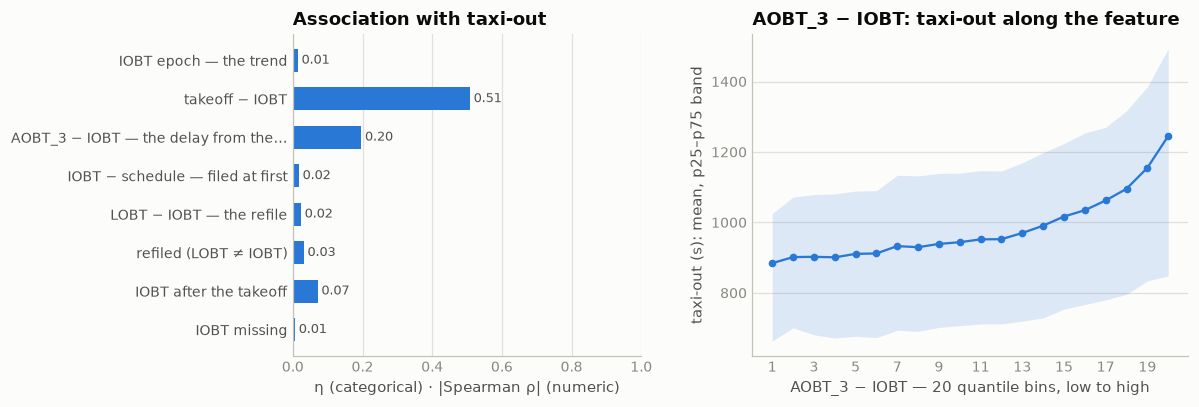

In [9]:
# correlation with the target: the stamp is a calendar, like the plan's other clocks; its model-facing forms are the gap to takeoff,
# the delay measured from the first filing, the slot it was filed into, and the refile that separates it from §15's clock
a = target_assoc([("IOBT epoch — the trend", "num", "epoch(IOBT_flt)"),
                  ("takeoff − IOBT", "num", "epoch(MVT_TIME_UTC_mvt - IOBT_flt)"),
                  ("AOBT_3 − IOBT — the delay from the first filing", "num", "epoch(AOBT_3_flt - IOBT_flt)"),
                  ("IOBT − schedule — filed at first", "num", "epoch(IOBT_flt - SCHED_TIME_UTC_mvt)"),
                  ("LOBT − IOBT — the refile", "num", "epoch(LOBT_flt - IOBT_flt)"),
                  ("refiled (LOBT ≠ IOBT)", "cat", "LOBT_flt != IOBT_flt"),
                  ("IOBT after the takeoff", "cat", "IOBT_flt > MVT_TIME_UTC_mvt"),
                  ("IOBT missing", "cat", "IOBT_flt IS NULL")])
assoc_chart(a, "epoch(AOBT_3_flt - IOBT_flt)", kind="num", title="AOBT_3 − IOBT")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The same rows as §15's clock, exactly** | null on 22,470 training departures (22,424 without a plan, 46 with a `FLIGHT_ID` whose plan block is empty) and 5,290 in the ranking file (5,283 + 7); on arrivals 6,943 + 1,143 empty blocks. **No row in either file carries one of the two clocks without the other** — `iobt_without_lobt` and `lobt_without_iobt` are 0 in all four file × phase groups | its nulls are §2's missing plan again, not new information, and there is no coverage to gain: the initial clock can never stand in where §15's is missing |
| **Always a whole minute** | 100.0% on the minute against `LOBT_flt`'s 99.7%, 95.4% on the 5-minute grid, 178,164 distinct values on training departures | the first filing is a timetable entry; the odd seconds `LOBT_flt` carries are put there by the revision, which is the only thing that separates the two columns |
| **The initial clock is still the last one on 99.45%** | equal on 99.45% of the 2,062,577 training departures that have both; 11,267 differ, as often earlier (0.29%) as later (0.26%), a median 1 min apart (p10 −8.3, p90 +15.4, p99 +42.2). Equal to the schedule on 74.4%, to `EOBT_1` on 69.5%; after the takeoff on 0.83% and after `AOBT_3` on 29.6% — §15's numbers, read from this side | §15's reading confirmed: the day's delay is never refiled, so on all but half a per cent of departures this column is a second copy of `LOBT_flt` |
| **Where they differ, the *initial* clock is the right one** | on the 11,267 disagreeing departures, scored against the actual off-block: initial closer **8,321**, last known 2,936, 10 ties — **73.9%**. Mean error 11.4 min against 14.3, median 7.0 against 12.0, within 5 minutes **40.0% against 11.6%** | the referee §19 applied to the two destination codes, applied to the two off-block clocks — and the answer is the opposite one. "Last known" does not mean "best known": the revision carries the flight *away* from the time it actually pushed back |
| **Because the refile is a slot move, not news about the aircraft** | by direction: refiled **earlier** 5,264 rows (46.7%) — the initial clock closer on **86.8%**; later by ≤ 15 min 4,818 (42.8%) — 63.4%; 15–60 min later 1,147 (10.2%) — 60.2%; over an hour later 38 rows (0.3%) — 13.2%, mean error 73.9 min against 17.3 | a plan refiled earlier is an airline claiming a slot it does not take, and it is wrong almost nine times in ten. Only the 38 flights that refiled more than an hour late were reporting something real — and they are 0.3% of an 0.55% |
| **Refiling is a per-hub habit, and the hubs that do it most do it worst** | LTFM refiles most, 5,626 rows (2.09%), initial clock closer on 74.8%; then LEBL 1,601 (0.90%) at 83.9% and LEMD 1,144 (0.54%) at **87.8%**; EGLL 1,377 (0.58%) at 59.1%. LIRF, 237 rows (0.15%) at 41.8%, is the only hub where the refile helps more often than not; EHAM never refiles at all (47 rows, 0.02%) | the same shape §15 found in the unfiled delay and §19 in diversion filing: a plan-system behaviour that is a property of the airport, not of the flight |
| **And it is diluted to nothing by the 99.45% that agree** | across all 2,062,577 departures with both clocks the mean error to the actual off-block is 8.57 min for the initial clock and 8.59 for the last known — **1.2 seconds** of clock accuracy over the whole file | a three-minute edge on 0.55% of rows is a second on the file. The referee's verdict is clear and its size is small — both halves are the finding |
| **On the ladder the better clock is worth 0.6 s** | airport 357.3 → × takeoff − IOBT **300.9** (§15's takeoff − LOBT 301.2); §9's anchor 293.5 → × `AOBT_3` − IOBT **260.4** against §15's `AOBT_3` − LOBT **261.0**; × IOBT − schedule 292.5 (§15's filed delay 292.4). The refile itself: on §15's base 260.9 as 5 bins, 260.3 as a flag; `AOBT_3` − IOBT × the refile 260.3; the flag alone on the anchor 293.0 | every form of this column lands within a second of the form of §15's that it mirrors. The gain has the right sign and a mechanism behind it, but 0.6 s is inside what a single Nov+Dec holdout can resolve |
| **2026 sits on 2025** | with a plan: January 99.07% → 98.39%, July 97.94% → 98.52%; takeoff − IOBT median January 19.0 → 20.9 min (p90 36.9 → 40.8), July 23.2 → 21.5 (44.4 → 40.0); refiled 0.19 → 0.24% and 0.71 → 0.96%; equal to the schedule January 76.0 → 70.5%, July 69.0 → 74.5% | the January-later / July-earlier drift §10 and §15 saw, on this clock too. Refiling is becoming slightly more common in both months, which makes the disagreeing rows a growing sliver rather than a shrinking one |
| Marginal | takeoff − IOBT ρ 0.509 (§15's LOBT 0.507); `AOBT_3` − IOBT r 0.231 (0.230); IOBT − schedule r 0.027; the refile r 0.015, ρ 0.024; the refiled flag η 0.032, after-the-takeoff η 0.072, missing η 0.007; the stamp itself r 0.011 | pair by pair, this column reads the target exactly as §15's does, to the third decimal — which is what a 99.45% copy should do |

**Decisions**

| issue | decision | why |
|---|---|---|
| does the pipeline swap `AOBT_3` − LOBT for `AOBT_3` − IOBT | **no — §15's feature stays as it is** | 260.4 against 261.0 is 0.6 s on one holdout, below what a single Nov+Dec split resolves. The referee says which clock is *truer*; it does not say the model can tell. If a second split agrees the swap is free — same coverage, same shape, one name changed |
| the referee's verdict | recorded here as a finding, not carried into §15 | one column per section: §15 owns the feature and the number that justifies it. This section owns the evidence about which clock is right, and hands it over rather than reaching in |
| the refile as a feature of its own | no | 260.9 and 260.3 on §15's base, 293.0 on the anchor — nothing, on 0.55% of rows |
| the initial clock as a fallback where §15's is missing | nothing to do | 0 departures in either file have one clock without the other |
| the twin layers' clock | adopted: the same 1,898 training and 479 ranking departures §15's clock gained | one recovered plan block carries every clock in it (§2) |

**State after §21** — the twin layers of §2, departures:

| `IOBT_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

takeoff − IOBT after, minutes: p10 9.5 / 10.0, median 20.7 / 21.1, p90 38.0 / 40.2 (training / ranking).

**Use in modeling.** Nothing changes in `build_features`. The column is `LOBT_flt` on 99.45% of
departures, it covers exactly the same rows, and every feature form built on it lands within a
second of §15's. What it contributes is a piece of knowledge about the data rather than a feature:
**where the flight plan's off-block time was revised, the revision made it worse** — 73.9% of the
time, by a median of five minutes — so any later use of the plan's clock should read the first
filing, not the last, and any feature that treats a refile as fresh information has it backwards.
Keep that in hand for `EOBT_1_flt`'s section, which owns the one plan clock that does move on the
day and moves on 30% of departures. The closing matrix reads the twin layers' clock as `TWINSI`,
the initial-clock twin of §15's `TWINS`; the column enters as epoch seconds with those 1,898 + 479
filled in — 1.00 with `LOBT_flt` and with the three movement clocks, 0.01 with the target, the
fifth copy of the calendar.


## 22 · `FLIGHT_RULE_flt` — the flight rules the plan was filed under

The flight plan's own copy of §4's rule, in the finer code set a flight plan uses: `I` instrument
rules (IFR) throughout, `V` visual rules (VFR) throughout, `Y` IFR first and then a change to VFR,
`Z` VFR first and then a change to IFR. §4 already reads this column twice: its `Y`/`Z` refine the
movement's flat `I` in `rule_final`, and §4a fills 646 of the movement's nulls from it. So this
section's main question is narrow: **does the plan's rule know anything `rule_final` has not
already taken from it?** The codes raise a second one. §4 found that a `Y` departure taxis about four
minutes less than an `I` departure. **Is that the rule, or the kind of flight that files it?**

| step | question | what came out |
|---|---|---|
| **census** | which codes appear, and where the column is missing | `I` on 99.9%, `Y` 1,768 rows, `Z` 1,170, `V` only 4. Null wherever the plan is missing, plus 167 plans that carry every field except this one and the wake class |
| **the copy** | the plan's rule against the movement's | equal on 99.92–99.93% of rows with a plan; almost every difference is the plan being finer or one side being empty; 9 training departures truly contradict it. The change of rules sits at the far end: departures file `Y`, arrivals `Z` |
| **who files a change** | segment, aircraft, destination, season | business aviation to airfields no `I` departure flies to; at Zurich, a winter peak to Samedan and Gstaad |
| **rule or aircraft** | does a `Y` departure taxi less than an `I` departure of the same kind | no: +3 s and +12 s inside business aviation's light and medium classes, −19 s inside hub × type, −14 s inside hub × stand, against −235 s overall |
| **signal** | honest ladders on the airport, on §4's rule, on §13's base, on raw labels | 357.3 → 357.0, the same as `rule_final`; 265.5 → 265.5 on §13's base; on raw labels the null level is §2's flag and the rule adds 0.05 s |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures as §15 and §21 |

In [4]:
# census by file × phase: the plan's four codes, and the presence rule — missing where the plan is missing (§17: the plan is
# missing iff ADEP_flt IS NULL), plus a handful of plans that carry every field but this one and the wake class; then the plan's V
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
display(cat_stats("FLIGHT_RULE_flt"))

print("the levels by file × phase — and the rows where the rule is missing with a plan, or present without one:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (FLIGHT_RULE_flt = 'I') i, count(*) FILTER (FLIGHT_RULE_flt = 'Y') y,
           count(*) FILTER (FLIGHT_RULE_flt = 'Z') z, count(*) FILTER (FLIGHT_RULE_flt = 'V') v,
           count(*) FILTER (FLIGHT_RULE_flt NOT IN ('I', 'Y', 'Z', 'V')) other, count(*) FILTER (FLIGHT_RULE_flt IS NULL) n_null,
           count(*) FILTER (ADEP_flt IS NULL) plan_missing, count(*) FILTER (ADEP_flt IS NOT NULL AND FLIGHT_RULE_flt IS NULL) plan_but_no_rule,
           count(*) FILTER (ADEP_flt IS NULL AND FLIGHT_RULE_flt IS NOT NULL) rule_but_no_plan
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
assert con.sql(f"SELECT count(*) FROM {BOTH} WHERE ADEP_flt IS NULL AND FLIGHT_RULE_flt IS NOT NULL").fetchone()[0] == 0

NORULE = (f"(SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub FROM {BOTH}"
          f" WHERE ADEP_flt IS NOT NULL AND FLIGHT_RULE_flt IS NULL)")
print("\nthe plans without a rule, both files and phases — which of the plan's other fields they lack, and who they are:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (WK_TBL_CAT_flt IS NULL) wake_null, count(*) FILTER (FLIGHT_TYPE_flt IS NULL) flight_type_null,
           count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL) aircraft_type_null, count(*) FILTER (AIRCRAFT_OPERATOR_flt IS NULL) operator_null,
           count(*) FILTER (MARKET_SEGMENT_flt IS NULL) segment_null, count(*) FILTER (LOBT_flt IS NULL) lobt_null,
           count(*) FILTER (AOBT_3_flt IS NULL) aobt3_null, count(*) FILTER (MARKET_SEGMENT_flt = 'Business') business,
           count(*) FILTER (FLIGHT_TYPE_flt = 'G') general_aviation, count(*) FILTER (FLIGHT_RULE_mvt = 'I') movement_says_i,
           count(DISTINCT MVT_TIME_UTC_mvt::DATE) n_dates
    FROM {NORULE}""").df().to_string(index=False))
print("plans without a wake class that do carry a rule:",
      con.sql(f"SELECT count(*) FROM {BOTH} WHERE ADEP_flt IS NOT NULL AND WK_TBL_CAT_flt IS NULL AND FLIGHT_RULE_flt IS NOT NULL").fetchone()[0])
print(con.sql(f"SELECT hub, count(*) n, count(*) FILTER (src = 'ranking') of_which_ranking FROM {NORULE} GROUP BY 1 ORDER BY n DESC, hub")
      .df().set_index("hub").T.to_string())

print("\nthe plan's V — every such row, by destination:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, ADES_flt dest, count(*) n, string_agg(DISTINCT ADEP_mvt, ', ' ORDER BY ADEP_mvt) hubs,
           string_agg(DISTINCT AIRCRAFT_TYPE_mvt, ', ' ORDER BY AIRCRAFT_TYPE_mvt) aircraft_types,
           string_agg(DISTINCT MARKET_SEGMENT_flt, ', ' ORDER BY MARKET_SEGMENT_flt) segments,
           string_agg(DISTINCT FLIGHT_RULE_mvt, ', ' ORDER BY FLIGHT_RULE_mvt) movement_rule, round(avg(TAXITIME_SEC_mvt)) mean_taxi
    FROM {BOTH} WHERE FLIGHT_RULE_flt = 'V' GROUP BY ALL ORDER BY n DESC, src, ph, dest""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,38060,0.91,4
ranking 2026,689534,7868,1.14,3


the levels by file × phase — and the rows where the rule is missing with a plan, or present without one:
     src  ph       n       i    y   z  v  other  n_null  plan_missing  plan_but_no_rule  rule_but_no_plan
training ARR 2082750 2066185   85 964  0      0   15516         15449                67                 0
training DEP 2085047 2061075 1419   5  4      0   22544         22470                74                 0
 ranking ARR  344693  341914   17 198  0      0    2564          2552                12                 0
 ranking DEP  344841  339287  247   3  0      0    5304          5290                14                 0

the plans without a rule, both files and phases — which of the plan's other fields they lack, and who they are:
  n  wake_null  flight_type_null  aircraft_type_null  operator_null  segment_null  lobt_null  aobt3_null  business  general_aviation  movement_says_i  n_dates
167        167                 0                   0              0             0          0 

In [5]:
# the copy: on rows with a plan, the plan's rule against the movement's (§4) — where they differ the plan is finer, never contrary.
# Then the phase shape: Y (IFR first) belongs to departures and Z (VFR first) to arrivals, so the leg the hub sees is the IFR one
print("the plan's rule against FLIGHT_RULE_mvt on rows with a plan — agreement, then every kind of disagreement (movement · plan):")
cp = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, round(100.0*count(*) FILTER (FLIGHT_RULE_mvt = FLIGHT_RULE_flt)/count(*), 3) pct_equal,
           count(*) FILTER (FLIGHT_RULE_mvt IS DISTINCT FROM FLIGHT_RULE_flt) n_differ,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I' AND FLIGHT_RULE_flt = 'Y') "I·Y", count(*) FILTER (FLIGHT_RULE_mvt = 'I' AND FLIGHT_RULE_flt = 'Z') "I·Z",
           count(*) FILTER (FLIGHT_RULE_mvt = 'I' AND FLIGHT_RULE_flt = 'V') "I·V", count(*) FILTER (FLIGHT_RULE_mvt = 'V') "V·any",
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL AND FLIGHT_RULE_flt = 'I') "∅·I",
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL AND FLIGHT_RULE_flt IN ('Y', 'Z')) "∅·Y/Z",
           count(*) FILTER (FLIGHT_RULE_mvt = 'I' AND FLIGHT_RULE_flt IS NULL) "I·∅"
    FROM {BOTH} WHERE ADEP_flt IS NOT NULL GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(cp.to_string(index=False))
assert (cp.n_differ == cp[["I·Y", "I·Z", "I·V", "V·any", "∅·I", "∅·Y/Z", "I·∅"]].sum(axis=1)).all()

print("\nthe phase shape per hub, training — Y on departures and Z on arrivals put the change at the far end; the other two do not:")
print(con.sql(f"""
    SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           count(*) FILTER (PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'Y') dep_y, count(*) FILTER (PHASE_mvt = 'ARR' AND FLIGHT_RULE_flt = 'Z') arr_z,
           count(*) FILTER (PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'Z') dep_z, count(*) FILTER (PHASE_mvt = 'ARR' AND FLIGHT_RULE_flt = 'Y') arr_y,
           round(1e4*count(*) FILTER (PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'Y')/count(FLIGHT_RULE_flt) FILTER (PHASE_mvt = 'DEP'), 1) dep_y_per_10k,
           round(1e4*count(*) FILTER (PHASE_mvt = 'ARR' AND FLIGHT_RULE_flt = 'Z')/count(FLIGHT_RULE_flt) FILTER (PHASE_mvt = 'ARR'), 1) arr_z_per_10k,
           count(*) FILTER (FLIGHT_RULE_flt IN ('Y', 'Z') AND FLIGHT_RULE_mvt IS NULL) y_z_where_movement_null
    FROM {T} GROUP BY 1 ORDER BY dep_y_per_10k DESC, hub""").df().to_string(index=False))

print("\nthe wrong-way codes — Z departures and Y arrivals, training: the three biggest callsign prefixes of each")
print(con.sql(f"""
    WITH w AS (SELECT PHASE_mvt ph, FLIGHT_RULE_flt plan_rule, substr(CALLSIGN_flt, 1, 3) prefix, count(*) n,
                      sum(count(*)) OVER (PARTITION BY PHASE_mvt) of_all,
                      string_agg(DISTINCT AIRCRAFT_TYPE_mvt, ', ' ORDER BY AIRCRAFT_TYPE_mvt) aircraft_types,
                      count(*) FILTER (ADEP_flt = ADES_flt) round_trips, count(*) FILTER (FLIGHT_RULE_mvt = 'I') movement_says_i
               FROM {T} WHERE (PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'Z') OR (PHASE_mvt = 'ARR' AND FLIGHT_RULE_flt = 'Y')
               GROUP BY 1, 2, 3)
    SELECT * FROM w QUALIFY row_number() OVER (PARTITION BY ph ORDER BY n DESC, prefix) <= 3 ORDER BY ph DESC, n DESC, prefix""").df().to_string(index=False))

the plan's rule against FLIGHT_RULE_mvt on rows with a plan — agreement, then every kind of disagreement (movement · plan):
     src  ph       n  pct_equal  n_differ  I·Y  I·Z  I·V  V·any  ∅·I  ∅·Y/Z  I·∅
training ARR 2067301     99.929      1464   85  890    0      0  348     74   67
training DEP 2062577     99.923      1586 1340    5    4      0   84     79   74
 ranking ARR  342141     99.921       270   17  192    0      0   43      6   12
 ranking DEP  339551     99.921       268  239    3    0      0    4      8   14

the phase shape per hub, training — Y on departures and Z on arrivals put the change at the far end; the other two do not:


 hub  dep_y  arr_z  dep_z  arr_y  dep_y_per_10k  arr_z_per_10k  y_z_where_movement_null
LSZH    577    548      2     16           43.5           41.1                        0
LEMD    267      0      0     11           12.6            0.0                        0
EDDM    196    193      0      1           11.8           11.6                        0
LEBL    122     20      0      8            6.9            1.1                        0
EHAM    139    103      3     23            5.7            4.2                        2
EDDF     89     75      0     24            3.9            3.3                      151
LTFM     14      7      0      0            0.5            0.3                        0
EGLL     10     10      0      0            0.4            0.4                        0
LIRF      3      4      0      1            0.2            0.3                        0
LFPG      2      4      0      1            0.1            0.2                        0

the wrong-way codes — Z departu

In [6]:
# who files a rule change: the segment, flight type, wake class, aircraft, destination and operator of the Y departures; the season;
# then whether their short taxi is the rule or the aircraft — I against Y inside the same kind of flight (training, taxi on 1–3600 s)
YDEP = f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'Y')"
print("the Y departures, training — the four biggest levels of each column, with the level's share of all departures with a plan:")
print(con.sql(f"""
    WITH ydep AS (SELECT * FROM {YDEP}),
         alld AS (SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_flt IS NOT NULL),
         u AS (SELECT 1 o, 'segment (§20)' col, MARKET_SEGMENT_flt v, count(*) n FROM ydep GROUP BY 3
               UNION ALL SELECT 2, 'flight type', FLIGHT_TYPE_flt, count(*) FROM ydep GROUP BY 3
               UNION ALL SELECT 3, 'wake class', WK_TBL_CAT_flt, count(*) FROM ydep GROUP BY 3
               UNION ALL SELECT 4, 'aircraft type (§11a)', {TYPE_FINAL}, count(*) FROM ydep GROUP BY 3
               UNION ALL SELECT 5, 'destination (ADES_flt)', ADES_flt, count(*) FROM ydep GROUP BY 3
               UNION ALL SELECT 6, 'callsign prefix', substr(CALLSIGN_flt, 1, 3), count(*) FROM ydep GROUP BY 3),
         base AS (SELECT o, v, 100.0*n/sum(n) OVER (PARTITION BY o) pct FROM
                      (SELECT 1 o, MARKET_SEGMENT_flt v, count(*) n FROM alld GROUP BY 2
                       UNION ALL SELECT 2, FLIGHT_TYPE_flt, count(*) FROM alld GROUP BY 2
                       UNION ALL SELECT 3, WK_TBL_CAT_flt, count(*) FROM alld GROUP BY 2))
    SELECT u.col, u.v AS level, u.n, round(100.0*u.n/sum(u.n) OVER (PARTITION BY u.o), 1) pct_of_y,
           round(b.pct, 1) pct_of_all_departures
    FROM u LEFT JOIN base b ON b.o = u.o AND b.v IS NOT DISTINCT FROM u.v
    QUALIFY row_number() OVER (PARTITION BY u.o ORDER BY u.n DESC, u.v) <= 4 ORDER BY u.o, u.n DESC, u.v""").df().to_string(index=False))

print("\nwhere they go — how many of the Y departures' destinations a departure without a rule change ever flies to:")
print(con.sql(f"""
    WITH y AS (SELECT ADES_flt a, count(*) n_y FROM {YDEP} GROUP BY 1),
         i AS (SELECT ADES_flt a, count(*) n_i FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt = 'I' GROUP BY 1)
    SELECT count(*) destinations, sum(n_y) y_departures, count(*) FILTER (n_i IS NULL) never_an_i_destination,
           sum(n_y) FILTER (n_i IS NULL) y_departures_there, sum(n_y) FILTER (coalesce(n_i, 0) < n_y) y_where_y_outnumbers_i
    FROM y LEFT JOIN i USING (a)""").df().to_string(index=False))

print("\nthe season — Y departures per 10,000 departures with a plan, Zurich against the other nine; and how many fly to "
      "Samedan/St. Moritz (LSZS) or Saanen/Gstaad (LSGK):")
sea = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) mon,
           1e4*count(*) FILTER (FLIGHT_RULE_flt = 'Y' AND ADEP_mvt = 'LSZH')/count(FLIGHT_RULE_flt) FILTER (ADEP_mvt = 'LSZH') lszh_per_10k,
           1e4*count(*) FILTER (FLIGHT_RULE_flt = 'Y' AND ADEP_mvt != 'LSZH')/count(FLIGHT_RULE_flt) FILTER (ADEP_mvt != 'LSZH') other_nine_per_10k,
           count(*) FILTER (FLIGHT_RULE_flt = 'Y') y_all_hubs, count(*) FILTER (FLIGHT_RULE_flt = 'Y' AND ADES_flt IN ('LSZS', 'LSGK')) y_to_lszs_lsgk
    FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1""").df()
print(sea.round(1).set_index("mon").T.to_string())

print("\nis it the rule or the aircraft? median taxi, I against Y — all departures, then each segment × wake class with ≥ 50 Y departures:")
comp = con.sql(f"""
    WITH s AS (SELECT 'all departures' grp, FLIGHT_RULE_flt fr, count(*) n, quantile_cont(TAXITIME_SEC_mvt, 0.5) med, avg(TAXITIME_SEC_mvt) mean
               FROM {TGT} WHERE FLIGHT_RULE_flt IN ('I', 'Y') GROUP BY 1, 2
               UNION ALL
               SELECT MARKET_SEGMENT_flt || ' · ' || WK_TBL_CAT_flt, FLIGHT_RULE_flt, count(*), quantile_cont(TAXITIME_SEC_mvt, 0.5), avg(TAXITIME_SEC_mvt)
               FROM {TGT} WHERE FLIGHT_RULE_flt IN ('I', 'Y') AND WK_TBL_CAT_flt IS NOT NULL GROUP BY 1, 2)
    SELECT i.grp, i.n n_i, y.n n_y, round(i.med) med_i, round(y.med) med_y, round(y.med - i.med) med_gap, round(y.mean - i.mean) mean_gap
    FROM s i JOIN s y ON i.grp = y.grp AND i.fr = 'I' AND y.fr = 'Y'
    WHERE y.n >= 50 ORDER BY i.grp != 'all departures', n_y DESC, i.grp""").df()
print(comp.to_string(index=False))

print("\n... and inside the same hub × aircraft type, then the same hub × stand — cells with ≥ 30 I departures, the mean gap weighted by Y rows:")
rows = []
for name, key in [("hub × aircraft type (§11a)", TYPE_FINAL), ("hub × stand (§13)", "STAND_mvt")]:
    rows.append(con.sql(f"""
        WITH s AS (SELECT ADEP_mvt hub, {key} k, FLIGHT_RULE_flt fr, count(*) n, avg(TAXITIME_SEC_mvt) mean
                   FROM {TGT} WHERE FLIGHT_RULE_flt IN ('I', 'Y') AND {key} IS NOT NULL GROUP BY ALL)
        SELECT '{name}' inside_the_same, count(*) cells, sum(y.n) y_rows_matched,
               (SELECT count(*) FROM {TGT} WHERE FLIGHT_RULE_flt = 'Y') y_rows_all, round(sum(y.n*(y.mean - i.mean))/sum(y.n)) mean_gap
        FROM s i JOIN s y ON i.hub = y.hub AND i.k = y.k AND i.fr = 'I' AND y.fr = 'Y' WHERE i.n >= 30""").df())
print(pd.concat(rows, ignore_index=True).to_string(index=False))

the Y departures, training — the four biggest levels of each column, with the level's share of all departures with a plan:


                   col         level    n  pct_of_y  pct_of_all_departures
         segment (§20)      Business 1153      81.3                    2.2
         segment (§20)         Other  209      14.7                    0.3
         segment (§20) Non-Scheduled   40       2.8                    0.7
         segment (§20)      Military    6       0.4                    0.0
           flight type             N  667      47.0                    2.6
           flight type             G  556      39.2                    0.5
           flight type             X  179      12.6                    0.5
           flight type             S   11       0.8                   96.3
            wake class             L  770      54.3                    0.5
            wake class             M  612      43.1                   78.4
            wake class             H   37       2.6                   20.4
  aircraft type (§11a)          PC12  352      24.8                    NaN
  aircraft type (§11a)   

           grp     n_i  n_y  med_i  med_y  med_gap  mean_gap
all departures 2057904 1414  911.0  654.0   -257.0    -235.0
  Business · L    8494  618  601.0  604.0      3.0      13.0
  Business · M   34668  533  722.0  734.0     12.0       1.0
     Other · L     816  130  640.0  693.0     54.0      56.0
     Other · M    4500   52  801.0  288.0   -513.0    -505.0

... and inside the same hub × aircraft type, then the same hub × stand — cells with ≥ 30 I departures, the mean gap weighted by Y rows:


           inside_the_same  cells  y_rows_matched  y_rows_all  mean_gap
hub × aircraft type (§11a)    162          1222.0        1414     -19.0
         hub × stand (§13)    248          1349.0        1414     -14.0


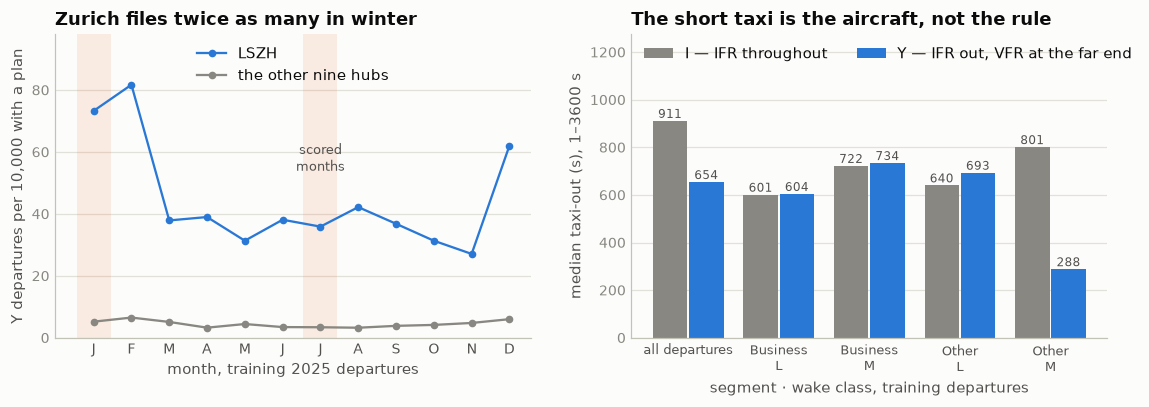

In [7]:
# the picture: the season behind the rule change at Zurich, and the taxi of a Y departure beside an I departure of the same kind
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for m in (1, 7):
    a1.axvspan(m - 0.45, m + 0.45, color=ORANGE, alpha=0.12, lw=0)
a1.plot(sea.mon, sea.lszh_per_10k, "o-", color=BLUE, ms=4, label="LSZH")
a1.plot(sea.mon, sea.other_nine_per_10k, "o-", color=MUTED, ms=4, label="the other nine hubs")
a1.set_ylim(0, sea.lszh_per_10k.max() * 1.2)
a1.text(7, sea.lszh_per_10k.max() * 0.66, "scored\nmonths", ha="center", fontsize=8.5, color=INK2)
a1.set_xticks(range(1, 13), list("JFMAMJJASOND"), color=INK2)
a1.set_title("Zurich files twice as many in winter")
a1.set_xlabel("month, training 2025 departures")
a1.set_ylabel("Y departures per 10,000 with a plan")
a1.legend(loc="upper center")
style(a1)
x = np.arange(len(comp))
b1 = a2.bar(x - 0.2, comp.med_i, width=0.38, color=MUTED, label="I — IFR throughout")
b2 = a2.bar(x + 0.2, comp.med_y, width=0.38, color=BLUE, label="Y — IFR out, VFR at the far end")
for b in (b1, b2):
    a2.bar_label(b, fmt="%.0f", fontsize=8, color=INK2)
a2.set_xticks(x, [g.replace(" · ", "\n") for g in comp.grp], color=INK2, fontsize=8.5)
a2.set_ylim(0, max(comp.med_i.max(), comp.med_y.max()) * 1.4)
a2.set_title("The short taxi is the aircraft, not the rule")
a2.set_ylabel("median taxi-out (s), 1–3600 s")
a2.set_xlabel("segment · wake class, training departures")
a2.legend(loc="upper left", ncol=2)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

In [8]:
# what the plan's rule buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 cascading rung by rung to the coarser
# key (§13's std_rungs). On the airport mean beside §4's rule_final and the columns the rule is a shadow of; on §13's base; on raw
# labels, where its null level is §2's missing plan. The second number is the RMSE on the holdout rows the plan marks Y or Z
con.sql(f"""
    CREATE OR REPLACE TABLE fr_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, {TYPE_FINAL} typ, coalesce(MARKET_SEGMENT_flt, '(no plan)') seg,
           coalesce(FLIGHT_RULE_flt, '(no rule)') fr, ADEP_flt IS NULL no_plan, rule_final rf, coalesce(FLIGHT_RULE_flt IN ('Y', 'Z'), FALSE) yz,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM ({FINAL}) WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE fr_t AS SELECT * FROM fr_d WHERE y <= 3600")


def fr_rungs(rungs, tbl="fr_t", where="TRUE"):
    """§13's std_rungs on this section's tables: each rung's cell mean where it has ≥ 30 fit rows, else the rung before it.
    Returns (name, RMSE, RMSE on the Y/Z rows, number of Y/Z rows) per rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE fr_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val AND {where} GROUP BY ALL")
        joins.append(f"LEFT JOIN fr_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN fr_s{i}.c >= 30 THEN fr_s{i}.m END")
        pred = f"coalesce({', '.join(reversed(preds))}, g.m)"
        out.append((name, *con.sql(f"""
            SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (v.yz)), count(*) FILTER (v.yz)
            FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val AND {where}) g WHERE v.is_val AND {where}""").fetchone()))
    return out


def fr_show(title, base, extras, tbl="fr_t", where="TRUE"):
    print(title)
    _, r, ryz, _ = fr_rungs(base, tbl, where)[-1]
    print(f"    {base[-1][0]:52s} {r:7.1f} s · {ryz:6.1f} s")
    for name, steps in extras:
        _, r, ryz, _ = fr_rungs(base + [(name, base[-1][1] + keys) for keys in steps], tbl, where)[-1]
        print(f"    {name:52s} {r:7.1f} s · {ryz:6.1f} s")


AP = [("airport (§5)", ["hub"])]
n_val, n_yz = con.sql("SELECT count(*), count(*) FILTER (yz) FROM fr_t WHERE is_val").fetchone()
fr_show(f"(1) on the airport mean — {n_val:,} Nov+Dec departures 1–3,600 s, {n_yz} of them Y or Z (RMSE · on the Y/Z rows):", AP,
     [("+ the plan's rule, '(no rule)' a level", [["fr"]]),
      ("+ the missing-plan flag alone (§2)", [["no_plan"]]),
      ("+ rule_final (§4)", [["rf"]]),
      ("+ aircraft type (§11a)", [["typ"]]),
      ("+ aircraft type, then the plan's rule", [["typ"], ["typ", "fr"]]),
      ("+ segment (§20)", [["seg"]]),
      ("+ segment, then the plan's rule", [["seg"], ["seg", "fr"]])])

con.sql("""
    CREATE OR REPLACE TABLE fr_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM fr_t WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT fr_t.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
    FROM fr_t JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")
BASE = [("airport", ["hub"]), ("+ runway (§12)", ["hub", "rwy"]), ("+ AOBT_3 anchor (§9)", ["hub", "rwy", "q_anc"]),
        ("+ prefix (§13)", ["hub", "rwy", "q_anc", "pfx"]), ("+ stand (§13's base)", ["hub", "rwy", "q_anc", "pfx", "stand"])]
n2, n2yz = con.sql("SELECT count(*), count(*) FILTER (yz) FROM fr_wb WHERE is_val").fetchone()
print()
fr_show(f"(2) on §13's base — the {n2:,} Nov+Dec departures with a runway, a stand and an anchor, {n2yz} Y or Z:", BASE,
     [("+ the plan's rule, on top", [["fr"]]), ("+ rule_final (§4), on top", [["rf"]]),
      ("+ aircraft type, on top", [["typ"]]), ("+ aircraft type, then the plan's rule", [["typ"], ["typ", "fr"]])], tbl="fr_wb")

n3 = con.sql("SELECT count(*) FROM fr_d WHERE is_val").fetchone()[0]
print()
fr_show(f"(3) raw labels, no ceiling (§14) — all {n3:,} Nov+Dec departures: who owns the rule's null level?", AP,
     [("+ the missing-plan flag alone (§2)", [["no_plan"]]), ("+ the plan's rule, '(no rule)' a level", [["fr"]]),
      ("+ the flag, then the plan's rule", [["no_plan"], ["no_plan", "fr"]])], tbl="fr_d")
print("\n    the plan's rule with the flag taken away — only the departures that carry a plan:")
for lbl, tbl in [("raw labels", "fr_d"), ("labels 1–3,600 s", "fr_t")]:
    a = fr_rungs(AP, tbl, "NOT no_plan")[-1][1]
    b = fr_rungs(AP + [("x", ["hub", "fr"])], tbl, "NOT no_plan")[-1][1]
    print(f"    {lbl:20s} airport {a:7.2f} s  →  + the plan's rule {b:7.2f} s   ({a - b:.2f} s)")

print("\nlook both ways — the rule change in the scored months against their 2025 twins (all departures):")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(FLIGHT_RULE_flt)/count(*), 2) pct_with_rule,
           count(*) FILTER (FLIGHT_RULE_flt = 'Y') y, count(*) FILTER (FLIGHT_RULE_flt = 'Z') z, count(*) FILTER (FLIGHT_RULE_flt = 'V') v,
           count(*) FILTER (ADEP_flt IS NOT NULL AND FLIGHT_RULE_flt IS NULL) plan_but_no_rule,
           round(1e4*count(*) FILTER (FLIGHT_RULE_flt = 'Y')/count(FLIGHT_RULE_flt), 1) y_per_10k,
           count(*) FILTER (FLIGHT_RULE_flt = 'Y' AND ADEP_mvt = 'LSZH') y_from_lszh
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

(1) on the airport mean — 327,485 Nov+Dec departures 1–3,600 s, 255 of them Y or Z (RMSE · on the Y/Z rows):
    airport (§5)                                           357.3 s ·  420.4 s
    + the plan's rule, '(no rule)' a level                 357.0 s ·  367.4 s
    + the missing-plan flag alone (§2)                     357.1 s ·  420.9 s
    + rule_final (§4)                                      357.0 s ·  367.4 s
    + aircraft type (§11a)                                 337.9 s ·  350.2 s
    + aircraft type, then the plan's rule                  337.8 s ·  349.3 s
    + segment (§20)                                        350.7 s ·  370.1 s


    + segment, then the plan's rule                        350.7 s ·  365.4 s

(2) on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor, 255 Y or Z:


    + stand (§13's base)                                   265.5 s ·  319.1 s


    + the plan's rule, on top                              265.5 s ·  319.4 s
    + rule_final (§4), on top                              265.5 s ·  319.4 s


    + aircraft type, on top                                265.3 s ·  320.0 s


    + aircraft type, then the plan's rule                  265.3 s ·  320.0 s

(3) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures: who owns the rule's null level?
    airport (§5)                                           496.5 s ·  420.4 s
    + the missing-plan flag alone (§2)                     475.0 s ·  421.0 s
    + the plan's rule, '(no rule)' a level                 474.9 s ·  366.8 s
    + the flag, then the plan's rule                       474.9 s ·  367.2 s

    the plan's rule with the flag taken away — only the departures that carry a plan:
    raw labels           airport  373.72 s  →  + the plan's rule  373.66 s   (0.05 s)
    labels 1–3,600 s     airport  355.36 s  →  + the plan's rule  355.30 s   (0.06 s)

look both ways — the rule change in the scored months against their 2025 twins (all departures):


  yr  mon      n  pct_with_rule   y  z  v  plan_but_no_rule  y_per_10k  y_from_lszh
2025    1 153706          99.07 144  0  0                 0        9.5           70
2026    1 152719          98.39 140  0  0                 9        9.3           67
2025    7 190713          97.93 103  0  1                 7        5.5           44
2026    7 192122          98.52 107  3  0                 5        5.7           41


In [4]:
# closing state — the column after §22: nothing of its own repaired (§4a already reads it first to fill the movement's nulls); §2's
# twin layers hand the departures they recover the whole plan block, this rule with it. Before → after per file, then the final levels
TWINSR = (f"(SELECT MVT_ID_mvt, FLIGHT_RULE_flt rule_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, FLIGHT_RULE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (FLIGHT_RULE_flt IS NULL) null_before, count(*) FILTER (coalesce(FLIGHT_RULE_flt, rule_twin) IS NULL) null_after,
           count(*) FILTER (FLIGHT_RULE_flt IS NULL AND rule_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (FLIGHT_RULE_flt IS NULL AND rule_twin IN ('Y', 'Z')) of_which_y_z,
           round(100.0*count(*) FILTER (coalesce(FLIGHT_RULE_flt, rule_twin) IS NULL)/count(*), 2) pct_null_after
    FROM {BOTH} d LEFT JOIN {TWINSR} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("twin rows whose recovered plan carries no rule:", con.sql(f"SELECT count(*) FROM {TWINSR} WHERE rule_twin IS NULL").fetchone()[0])

print("\nevery twin row — the movement's rule against the recovered plan's (§4a's precedence keeps a movement V):")
print(con.sql(f"""
    SELECT src, coalesce(FLIGHT_RULE_mvt, '∅') movement, coalesce(rule_twin, '∅') plan, count(*) n,
           CASE WHEN rule_twin IS NULL THEN 'the plan has no rule' WHEN FLIGHT_RULE_mvt IS NULL THEN 'the movement is empty'
                WHEN FLIGHT_RULE_mvt = rule_twin THEN 'same' WHEN FLIGHT_RULE_mvt = 'V' AND rule_twin = 'Z' THEN 'agrees: a Z plan departs VFR'
                WHEN FLIGHT_RULE_mvt = 'I' AND rule_twin = 'Y' THEN 'finer: a Y plan departs IFR' ELSE 'contradicts' END reading
    FROM {BOTH} JOIN {TWINSR} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_flt IS NULL
    GROUP BY ALL ORDER BY src DESC, n DESC, movement, plan""").df().to_string(index=False))

print("\nthe final levels, departures — the plan's rule with the twins filled in, and how each taxies (training, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_flt, rule_twin, '∅') AS plan_rule, count(*) FILTER (src = 'training') training,
           round(100.0*count(*) FILTER (src = 'training')/sum(count(*) FILTER (src = 'training')) OVER (), 3) pct_training,
           count(*) FILTER (src = 'ranking') ranking,
           round(avg(TAXITIME_SEC_mvt) FILTER (src = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) mean_taxi,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (src = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) med_taxi
    FROM {BOTH} LEFT JOIN {TWINSR} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY training DESC, plan_rule""").df().to_string(index=False))

     src       n  null_before  null_after  filled_by_twins  of_which_y_z  pct_null_after
training 2085047        22544       20646             1898             6            0.99
 ranking  344841         5304        4825              479             0            1.40
twin rows whose recovered plan carries no rule: 1

every twin row — the movement's rule against the recovered plan's (§4a's precedence keeps a movement V):
     src movement plan    n                      reading
training        I    I 1890                         same
training        V    Z    5 agrees: a Z plan departs VFR
training        V    I    2                  contradicts
training        I    ∅    1         the plan has no rule
training        V    Y    1                  contradicts
 ranking        I    I  479                         same

the final levels, departures — the plan's rule with the twins filled in, and how each taxies (training, 1–3600 s):
plan_rule  training  pct_training  ranking  mean_taxi  med_tax

                                     feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_RULE_flt — the plan's rule, ∅ a level categorical           5                        0.018
                        its null level alone categorical           2                        0.008
                a rule change filed — Y or Z categorical           2                        0.016
                        market segment (§20) categorical           9                        0.214
                        aircraft type (§11a) categorical         107                        0.358


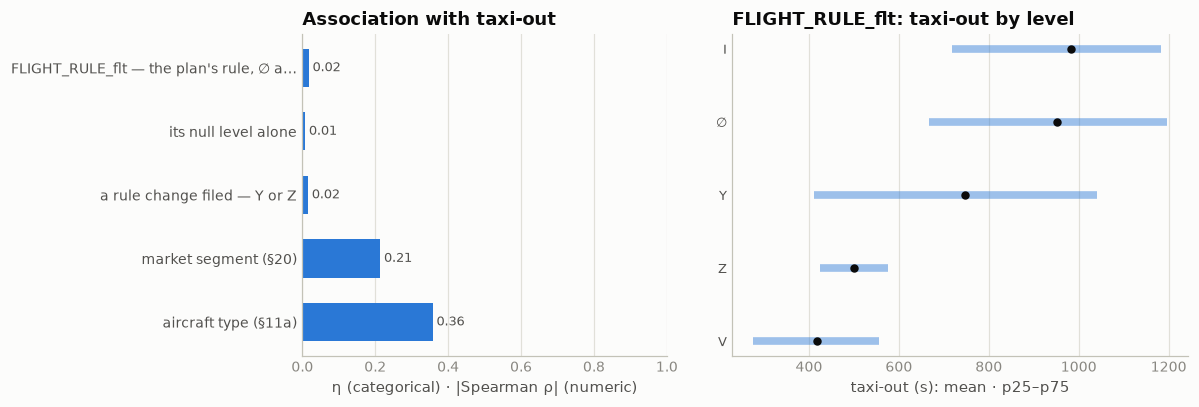

In [10]:
# correlation with the target: the plan's rule (its null a level), the null level alone — §2's missing plan and a few rule-less
# plans — the rule change as a flag, and the two columns it is a shadow of: the segment (§20) and the aircraft type (§11a)
a = target_assoc([
    ("FLIGHT_RULE_flt — the plan's rule, ∅ a level", "cat", "FLIGHT_RULE_flt"),
    ("its null level alone", "cat", "FLIGHT_RULE_flt IS NULL"),
    ("a rule change filed — Y or Z", "cat", "coalesce(FLIGHT_RULE_flt IN ('Y', 'Z'), FALSE)"),
    ("market segment (§20)", "cat", "MARKET_SEGMENT_flt"),
    ("aircraft type (§11a)", "cat", TYPE_FINAL, 200),
])
assoc_chart(a, "FLIGHT_RULE_flt", title="FLIGHT_RULE_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Four codes, and `V` is almost absent** | training `I` 4,127,260, `Y` 1,504, `Z` 969, `V` **4**; ranking `I` 681,201, `Y` 264, `Z` 201, `V` 0. The four `V`s are business departures (E55P, P180, PC12) from four different hubs, all to Cannes–Mandelieu (`LFMD`); the movement says `I` on each | `data/FEATURES.md` lists these four codes correctly. The VFR traffic §4 found never has a plan (all unmatched), so the plan's `V` is a filing habit for one destination, not visual traffic |
| **Missing where the plan is missing — and on 167 plans besides** | null on 22,544 training departures (22,470 without a plan + 74), 15,516 arrivals (15,449 + 67), 5,304 ranking departures (5,290 + 14), 2,564 arrivals (2,552 + 12); 0 rows carry a rule without a plan. The 167 have a flight type, aircraft type, operator, segment, `LOBT` and `AOBT_3`; **all 167 lack the wake class, and no plan lacks the wake class while carrying a rule**. 129 business, 111 general aviation, the movement says `I` on all 167, spread over 119 dates, 83 at LSZH | one defect that blanks two fields together, on small business plans. The movement's `I` is already the rule for these rows in `rule_final`; the wake class is `WK_TBL_CAT_flt`'s section's to repair |
| **A finer copy of the movement's rule, almost never a contrary one** | on rows with a plan: equal on 99.923% of training departures, 99.929% of arrivals, 99.921% of both ranking groups. The 1,586 training departures that differ are 1,340 `I`·`Y`, 5 `I`·`Z`, 4 `I`·`V`, 84 + 79 where the movement is empty and the plan says `I` / `Y`/`Z`, 74 where the plan is empty. The movement says `V` on **0** rows with a plan. Only **9** training departures contradict the movement about the leg flown at the hub: the 4 `I`·`V` and the 5 `I`·`Z` (a `Z` plan departs VFR); ranking has 3 `I`·`Z`. The 85 `Y` arrivals are not contradictions, since a `Y` plan may change back to IFR before landing. The twin layers add 3 more: movement `V`, recovered plan `I` 2 and `Y` 1 (closing state below) | §4's reading, confirmed from this side: the airport records one bit (IFR or not) and the plan records which end of the flight changes. A dozen contradictions in 4.8 M rows, all kept on the movement's side by `rule_final` — nothing to reconcile |
| **The change sits at the far end** | training departures carry `Y` 1,419 times and `Z` 5; arrivals `Z` 964 and `Y` 85. Per hub, departures' `Y` per 10,000: LSZH 43.5, LEMD 12.6, EDDM 11.8, LEBL 6.9, EHAM 5.7, EDDF 3.9, the other four under 1. EDDF leaves the movement rule empty on 151 of its `Y`/`Z` rows (§4a). The wrong-way codes are single flights (5 `Z` departures, one callsign each) or a special fleet: 17 of the 85 `Y` arrivals are §4's `NCG` coastguard Dash-8s on round trips | a `Y` or `Z` says the hub leg was flown IFR, which the movement's `I` already said. The code describes the other end of the flight |
| **Who files it: business aviation to small airfields** | `Y` departures: segment Business **81.3%** (2.2% of departures with a plan), flight type `N` non-scheduled 47.0% and `G` general aviation 39.2% (scheduled 0.8%, against 96.3%), wake class `L` 54.3% (0.5%). PC12 352, PC24 108, C56X 99; callsigns JFA 115, NJE 80, GES 73. 191 destinations — Samedan/St. Moritz `LSZS` 204, Madrid–Cuatro Vientos `LECU` 125, Saanen/Gstaad `LSGK` 90, Speyer `EDRY` 62 — and **122 of them no `I` departure from the ten hubs ever flies to**, taking 753 of the 1,419; on 1,200 the destination sees more `Y` than `I` | the code belongs to the destination airfield. It is the flight plan's way of saying "a small aircraft to a small airfield" |
| **Zurich's `Y` departures double in winter** | LSZH `Y` per 10,000: January 73.3, February 81.7, December 62.0, against 27.1–42.2 from March to November; those three months carry 65, 64 and 61 flights to `LSZS` or `LSGK`, the other nine 7–22. The other nine hubs stay at 3.2–6.5 all year | winter traffic to the Alpine resorts. January, a scored month, has more `Y` departures than July: 144 against 103 in 2025 |
| **The short taxi is the aircraft, not the rule** | median `Y` 654 s against `I` 911 s (−257 s; mean −235 s). Inside business aviation the gap disappears: light +3 s (618 `Y`), medium +12 s (533); Other light +54 s (130); only Other medium, 52 rows, sits at −513 s. Inside the same hub × aircraft type the mean gap is **−19 s** (1,222 of the 1,414 `Y` rows matched), inside the same hub × stand **−14 s** (1,349) | §4's "`Y` plans taxi ~4 min shorter" is composition: small business aircraft at general-aviation aprons. A model that knows the type or the stand already has it |
| **Worth nothing on top of §4, nothing on top of §13** | honest ladders, 327,485 Nov+Dec departures: airport 357.3 → + the plan's rule **357.0** = + `rule_final` **357.0**; on the 255 `Y`/`Z` rows both 420.4 → 367.4. Type then the rule 337.9 → 337.8; segment then the rule 350.7 → 350.7. On §13's base, 324,629 departures: 265.5 → 265.5 with the plan's rule and with `rule_final` alike (`Y`/`Z` rows 319.1 → 319.4) | the rule's whole signal is the `Y`/`Z` refinement §4 already took, and it is gone once the stand is known |
| **On raw labels its null level is §2's flag** | 327,968 Nov+Dec departures, no ceiling: airport 496.5 → + the missing-plan flag 475.0 → + the plan's rule 474.9; the flag then the rule 474.9. Departures with a plan only: 373.72 → 373.66 raw, 355.36 → 355.30 on 1–3,600 s — **0.05 and 0.06 s** | the 21.5 s the raw column seems to carry belongs to §2, as it did for §20's segment |
| **2026 sits on 2025** | with a rule: January 99.07% → 98.39%, July 97.93% → 98.52%. `Y` January 144 → 140 (from LSZH 70 → 67), July 103 → 107; per 10,000, 9.5 → 9.3 and 5.5 → 5.7. `Z` 0 → 0 and 0 → 3; `V` 0 → 0 and 1 → 0; plans without a rule 0 → 9 and 7 → 5 | the traffic that files a rule change is as stable as the timetable; January stays the heavier month |
| Marginal | η: the plan's rule, ∅ a level, 0.018; its null level alone 0.008; the `Y`/`Z` flag 0.016 — against the segment's 0.214 and the aircraft type's 0.358 | too few rows carry anything but `I` to register in a marginal measure |

**Decisions**

| issue | decision | why |
|---|---|---|
| a feature built from the plan's rule | **no — §4's `rule_final` stays the model's rule** | 357.0 against 357.0 on the airport mean, 265.5 against 265.5 on §13's base: the `Y`/`Z` refinement is already in `rule_final`, and it reads the twin layers' copy of this column too |
| a "`Y` departure" flag as a stand-in for business aviation to small airfields | not adopted | inside business aviation × wake class the gap is +3 s and +12 s; the type and the stand carry the same information on every row, not on 0.07% of them |
| the 167 plans with no rule | nothing to do here | the movement says `I` on all 167, and that is what `rule_final` uses. The wake class goes missing on exactly the same rows; that repair belongs to `WK_TBL_CAT_flt` (§25) |
| the plan's four `V`s | left as they are | 4 training rows, 0 in ranking; `rule_final`'s precedence reads the movement's `I` there |
| the twin layers' rule | adopted for the matrix, as `TWINSR` | the same 1,898 training and 479 ranking departures §15's and §21's clocks gained, 6 of them `Y`/`Z`. On the 8 twin rows over a movement `V`, the recovered plan says `Z` 5 times — VFR out of the hub, agreeing with the movement — and §4a's precedence keeps the `V` on all 8. Every other twin row matches: 1,890 training and 479 ranking departures are `I` on both sides, and 1 recovered plan carries no rule |

**State after §22** — departures:

| `FLIGHT_RULE_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,544 → 20,646 (1,898 from the twins) | 5,304 → 4,825 (479) |
| left, and why | 0.99% — no plan block, or one of the rule-less plans | 1.40% — the same |

| final level | training | ranking | median DEP taxi, 1–3600 s |
|---|---:|---:|---:|
| `I` | 2,062,967 | 339,766 | 911 s |
| ∅ | 20,646 | 4,825 | 911 s |
| `Y` | 1,420 | 247 | 654 s |
| `Z` | 10 | 3 | 608 s |
| `V` | 4 | 0 | 413 s |

**Use in modeling.** Nothing new to feed. The model's rule is §4's `rule_final`, which already takes
this column's `Y`/`Z` and the twin layers' copy of it, and the ladders put the plan's own rule at
exactly `rule_final`'s value. `pipeline/common.py` still feeds the raw `FLIGHT_RULE_mvt`; switching to
`rule_final` is §4's recipe, worth at most the 0.3 s between 357.3 and 357.0, and is not made from
here. What the column contributes is knowledge about the data. **A `Y` or `Z` describes the far end of
the flight, not the taxi**: a small, mostly business aircraft bound for an airfield IFR traffic does
not use, and its short taxi belongs to the aircraft and the apron. Expect to meet the same traffic
in §23: flight types `N` and `G` are 86% of `Y` departures. The closing matrix
reads the twin layers' rule as `TWINSR` and enters the column with those 1,898 + 479 filled in and
its nulls kept as a level.

## 23 · `FLIGHT_TYPE_flt` — scheduled, charter, private, military or other

The flight plan's type of flight, in the code set a flight plan uses: `S` a scheduled air service, `N` a
non-scheduled air transport operation (charter, air taxi, a business jet flown for hire), `G` general
aviation, `M` military, `X` anything else. §20's segment classifies the *operator's* business; this
code is filed per *flight*. §22 has already met it: `N` and `G` are 86% of the departures that file a
change of rules. So the section asks two questions. **What does the code know that the segment does
not?** And the question §22 asked of the rule: **is a short taxi the code, or the aircraft and apron
that come with it?** The column's documentation raises a third. The organisers say military movements
were removed, yet `M` is one of the codes.

| step | question | what came out |
|---|---|---|
| **census** | which codes appear, and where the column is missing | all five documented codes: `S` 96.32% of departures with a plan, `N` 2.63%, `X` 0.54%, `G` 0.48%, `M` 0.03%. Missing exactly where the plan is missing, with no gaps of its own |
| **the segment's finer cut** | the code against §20's segment | Cramér's V 0.744. Mainline and Regional are 100% `S`, Non-Scheduled 100% `N`; the code only splits Business, Cargo, Lowcost, Military and Other |
| **who files what** | callsign prefixes, aircraft, stands, hubs; the operator's code or the flight's | `N` and `G` are business aviation, `M` air-force transports, `X` flights outside the timetable. The code belongs to the flight: 97.37% of departures fly for an operator that files more than one code, 4.41% under a callsign that does |
| **military and other** | when the `M` flights come; where the `X` flights go | `M` clusters in three weeks, one a week of January 2026 at Zurich. `X` is positioning, charter and air-ambulance flying, mostly by airlines |
| **code or aircraft** | does a departure that is not `S` taxi less than an `S` departure at the same stand | no for `N` (+10 s), `G` (+46 s) and `M` (+4 s), against −130 to −177 s overall; `X` keeps −33 s |
| **signal** | honest ladders on the airport, the segment, the type, §13's base, raw labels | 357.3 → 355.2 alone, 0.3–0.4 s after the segment or the type, 265.5 → 265.5 on §13's base. On raw labels the null level is §2's flag |
| **the filled forms** | what §2's twins and §2c's history fill add | on raw labels, on top of the flag and `rule_final`, the twins 2.3 s, the twins and the history 7.7 s. But 6.2 s of that is the flag "no layer reaches the row", §2c's signal, not the code |
| **closing state** | what the twins fill | the same 1,898 + 479 departures as §15, §21 and §22 |

In [4]:
# census by file × phase: the plan's five codes and the presence rule — missing exactly where the plan is missing (§17: the plan is
# missing iff ADEP_flt IS NULL), with no holes of its own; then the code against §20's segment, on training departures with a plan
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
DEPP = f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_flt IS NOT NULL)"
display(cat_stats("FLIGHT_TYPE_flt"))

print("the levels by file × phase — and the rows where the code is missing with a plan, or present without one:")
cen = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) total, count(*) FILTER (FLIGHT_TYPE_flt = 'S') S_scheduled, count(*) FILTER (FLIGHT_TYPE_flt = 'N') N_non_scheduled,
           count(*) FILTER (FLIGHT_TYPE_flt = 'G') G_general, count(*) FILTER (FLIGHT_TYPE_flt = 'M') M_military,
           count(*) FILTER (FLIGHT_TYPE_flt = 'X') X_other, count(*) FILTER (FLIGHT_TYPE_flt NOT IN ('S', 'N', 'G', 'M', 'X')) other_code,
           count(*) FILTER (FLIGHT_TYPE_flt IS NULL) n_null, count(*) FILTER (ADEP_flt IS NULL) plan_missing,
           count(*) FILTER (ADEP_flt IS NOT NULL AND FLIGHT_TYPE_flt IS NULL) plan_but_no_code,
           count(*) FILTER (ADEP_flt IS NULL AND FLIGHT_TYPE_flt IS NOT NULL) code_but_no_plan
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(cen.to_string(index=False))
assert (cen.other_code == 0).all() and (cen.plan_but_no_code == 0).all() and (cen.code_but_no_plan == 0).all()
print("\nshare of training departures with a plan (%):")
print(con.sql(f"SELECT FLIGHT_TYPE_flt ft, round(100.0*count(*)/sum(count(*)) OVER (), 3) pct FROM {DEPP} GROUP BY 1 ORDER BY pct DESC, ft")
      .df().set_index("ft").T.to_string())

print("\nthe code against the segment (§20) — training departures with a plan, one row per segment:")
seg_ft = con.sql(f"""PIVOT (SELECT MARKET_SEGMENT_flt segment, FLIGHT_TYPE_flt ft FROM {DEPP}) ON ft IN ('S', 'N', 'G', 'X', 'M')
                     USING count(*) GROUP BY segment ORDER BY segment""").df()
seg_ft["pct_S"] = (100 * seg_ft.S / seg_ft[["S", "N", "G", "X", "M"]].sum(axis=1)).round(2)
print(seg_ft.to_string(index=False))
print("Cramér's V, flight type × segment:", round(cramers_v("FLIGHT_TYPE_flt", "MARKET_SEGMENT_flt", DEPP), 3))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,5
ranking 2026,689534,7842,1.14,5


the levels by file × phase — and the rows where the code is missing with a plan, or present without one:
     src  ph   total  S_scheduled  N_non_scheduled  G_general  M_military  X_other  other_code  n_null  plan_missing  plan_but_no_code  code_but_no_plan
training ARR 2082750      1990229            54048      10011         584    12429           0   15449         15449                 0                 0
training DEP 2085047      1986754            54312       9867         581    11063           0   22470         22470                 0                 0
 ranking ARR  344693       329417             8626       1745         132     2221           0    2552          2552                 0                 0
 ranking DEP  344841       327154             8553       1734         133     1977           0    5290          5290                 0                 0

share of training departures with a plan (%):
ft        S      N      X      G      M
pct  96.324  2.633  0.536  0.478  0.028

th

In [5]:
# who files each code other than S: the four biggest callsign prefixes, aircraft types, stands and segments per code (training departures
# with a plan); each code's share per hub; then whether the code belongs to the operator or to the flight
print("the four biggest levels per code, training departures with a plan:")
print(con.sql(f"""
    WITH d AS (SELECT * FROM {DEPP} WHERE FLIGHT_TYPE_flt != 'S'),
         u AS (SELECT FLIGHT_TYPE_flt ft, 1 o, 'callsign prefix' col, substr(CALLSIGN_flt, 1, 3) v, count(*) n FROM d GROUP BY 1, 4
               UNION ALL SELECT FLIGHT_TYPE_flt, 2, 'aircraft type (§11a)', {TYPE_FINAL}, count(*) FROM d GROUP BY 1, 4
               UNION ALL SELECT FLIGHT_TYPE_flt, 3, 'hub:stand (§13)', ADEP_mvt || ':' || STAND_mvt, count(*) FROM d GROUP BY 1, 4
               UNION ALL SELECT FLIGHT_TYPE_flt, 4, 'segment (§20)', MARKET_SEGMENT_flt, count(*) FROM d GROUP BY 1, 4)
    SELECT ft, col, string_agg(coalesce(v, '∅') || ' ' || n, ', ' ORDER BY n DESC, v) top_four
    FROM (SELECT * FROM u QUALIFY row_number() OVER (PARTITION BY ft, o ORDER BY n DESC, v) <= 4)
    GROUP BY ft, o, col ORDER BY list_position(['N', 'X', 'G', 'M'], ft), o""").df().to_string(index=False))

print("\neach code's share of the hub's departures with a plan (%), training:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'N')/count(*), 2) pct_N,
           round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'X')/count(*), 2) pct_X, round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'G')/count(*), 2) pct_G,
           round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'M')/count(*), 3) pct_M
    FROM {DEPP} GROUP BY 1 ORDER BY pct_N DESC, hub""").df().to_string(index=False))

print("\nthe operator's code or the flight's? rows in their group's most common code, and rows in groups that file more than one code:")
pur = []
for name, key in [("operator (hashed)", "AIRCRAFT_OPERATOR_flt"), ("callsign prefix (§16)", "substr(CALLSIGN_flt, 1, 3)"),
                  ("segment (§20)", "MARKET_SEGMENT_flt"), ("callsign (§16)", "CALLSIGN_flt")]:
    pur.append(con.sql(f"""
        WITH c AS (SELECT {key} k, FLIGHT_TYPE_flt ft, count(*) n FROM {DEPP} GROUP BY 1, 2),
             m AS (SELECT k, max(n) mx, sum(n) tot, count(*) n_codes FROM c GROUP BY 1)
        SELECT '{name}' grouped_by, count(*) n_groups, round(100.0*sum(mx)/sum(tot), 2) pct_rows_in_modal_code,
               round(100.0*sum(tot) FILTER (n_codes > 1)/sum(tot), 2) pct_rows_in_mixed_groups FROM m""").df())
print(pd.concat(pur, ignore_index=True).to_string(index=False))
print("\n... per code: departures per callsign, and the share of round trips (the plan's ADEP = ADES):")
print(con.sql(f"""
    SELECT FLIGHT_TYPE_flt ft, count(*) n, count(DISTINCT CALLSIGN_flt) callsigns, round(count(*)/count(DISTINCT CALLSIGN_flt), 1) rows_per_callsign,
           round(100.0*count(*) FILTER (ADEP_flt = ADES_flt)/count(*), 2) pct_round_trip
    FROM {DEPP} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

the four biggest levels per code, training departures with a plan:


ft                  col                                                      top_four
 N      callsign prefix                        NJE 6453, VJT 2235, SWT 1656, GES 1605
 N aircraft type (§11a)                    A320 3863, C56X 3807, E55P 3618, B738 3283
 N      hub:stand (§13)     LSZH:GA6 1670, EHAM:K38 1417, EDDF:V701 805, LSZH:102 648
 N        segment (§20) Business 32871, Non-Scheduled 14577, Cargo 4109, Lowcost 2646
 X      callsign prefix                           THY 1278, SAZ 723, AFR 662, ANE 622
 X aircraft type (§11a)                      B738 1599, A320 1189, CL60 768, A321 665
 X      hub:stand (§13)       LSZH:REG 703, LSZH:MFG 225, EDDF:V701 114, EDDM:581 109
 X        segment (§20)            Other 5888, Business 2547, Lowcost 2076, Cargo 535
 G      callsign prefix                            HBV 270, JFA 266, HBF 206, HBJ 192
 G aircraft type (§11a)                        PC12 762, GLEX 664, GLF6 654, GLF5 564
 G      hub:stand (§13)        LSZH:GA6 465, LSZH:MFG 

In [6]:
# the two codes the column's documentation says least about: M, military flights in a dataset the organisers say had them removed, and
# their calendar; X, "other" — what the biggest X filers' flights are, read from where they go (training departures unless stated)
print("M — the segment it sits in, departures:")
print(con.sql(f"""
    SELECT src, count(*) FILTER (FLIGHT_TYPE_flt = 'M') m, count(*) FILTER (FLIGHT_TYPE_flt = 'M' AND MARKET_SEGMENT_flt = 'Military') m_in_military_segment,
           count(*) FILTER (MARKET_SEGMENT_flt = 'Military') military_segment
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
ft_mon = con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, count(*) FILTER (ADEP_mvt = 'EDDM') eddm,
           count(*) FILTER (ADEP_mvt = 'EHAM') eham, count(*) FILTER (ADEP_mvt = 'LSZH') lszh
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND FLIGHT_TYPE_flt = 'M' GROUP BY 1, 2 ORDER BY 1, 2""").df()
print("\nM departures per month, both files — all ten hubs, then Munich, Amsterdam and Zurich:")
print(ft_mon.set_index(["yr", "mon"]).T.to_string())
print("\nthe weeks with ≥ 15 M departures from one hub, both files:")
print(con.sql(f"""
    SELECT date_trunc('week', MVT_TIME_UTC_mvt)::DATE week_of, ADEP_mvt hub, count(*) n, min(MVT_TIME_UTC_mvt)::DATE first_day,
           max(MVT_TIME_UTC_mvt)::DATE last_day, count(DISTINCT substr(CALLSIGN_flt, 1, 3)) callsign_prefixes
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND FLIGHT_TYPE_flt = 'M' GROUP BY 1, 2 HAVING count(*) >= 15 ORDER BY 1, 2""").df().to_string(index=False))

print("\nX — the eight biggest X filers: their segment, round trips, how many go where the same prefix flies scheduled, the four biggest destinations:")
print(con.sql(f"""
    WITH x AS (SELECT substr(CALLSIGN_flt, 1, 3) p, ADES_flt a, MARKET_SEGMENT_flt seg, ADEP_flt = ADES_flt rt FROM {DEPP} WHERE FLIGHT_TYPE_flt = 'X'),
         s AS (SELECT DISTINCT substr(CALLSIGN_flt, 1, 3) p, ADES_flt a, TRUE hit FROM {DEPP} WHERE FLIGHT_TYPE_flt = 'S'),
         top AS (SELECT p, count(*) n FROM x GROUP BY 1 ORDER BY n DESC, p LIMIT 8),
         agg AS (SELECT p, string_agg(DISTINCT seg, ', ' ORDER BY seg) segments, round(100.0*count(*) FILTER (rt)/count(*), 1) pct_round_trip,
                        round(100.0*count(hit)/count(*), 1) pct_to_own_scheduled_destination
                 FROM x LEFT JOIN s USING (p, a) GROUP BY 1),
         dest AS (SELECT p, a, count(*) n FROM x GROUP BY 1, 2 QUALIFY row_number() OVER (PARTITION BY p ORDER BY count(*) DESC, a) <= 4),
         dd AS (SELECT p, string_agg(a || ' ' || n, ', ' ORDER BY n DESC, a) top_destinations FROM dest GROUP BY 1)
    SELECT top.p prefix, top.n, agg.segments, agg.pct_round_trip, agg.pct_to_own_scheduled_destination, dd.top_destinations
    FROM top JOIN agg USING (p) JOIN dd USING (p) ORDER BY top.n DESC, prefix""").df().to_string(index=False))

M — the segment it sits in, departures:
     src   m  m_in_military_segment  military_segment
training 581                    581               713
 ranking 133                    133               211



M departures per month, both files — all ten hubs, then Munich, Amsterdam and Zurich:
yr   2025                                             2026    
mon    1   2   3   4   5   6   7   8   9   10  11  12   1   7 
n      34  76  43  45  54  85  49  24  43  34  56  38   99  34
eddm    6  54   5   8  18   6  16  16  14  15  14  12   24   8
eham    6   7   4   9   4  51   1   1   3   3   7   3    8   9
lszh   16   3  17   4   8   7   9   4   5   4   7   4   58   4

the weeks with ≥ 15 M departures from one hub, both files:


   week_of  hub  n  first_day   last_day  callsign_prefixes
2025-02-10 EDDM 46 2025-02-10 2025-02-16                 17
2025-06-23 EHAM 37 2025-06-23 2025-06-27                 19
2026-01-19 LSZH 41 2026-01-19 2026-01-25                 19

X — the eight biggest X filers: their segment, round trips, how many go where the same prefix flies scheduled, the four biggest destinations:
prefix    n     segments  pct_round_trip  pct_to_own_scheduled_destination                       top_destinations
   THY 1278 Cargo, Other             0.2                              92.1 LTAI 159, OEMA 124, OEJN 106, LTFJ 103
   SAZ  723     Business             0.6                               0.0     BKPR 24, LEPA 20, LSZH 17, LWSK 16
   AFR  662        Other             2.1                              53.3    LFPO 174, LFPG 82, LFLL 69, LFLC 55
   ANE  622        Other             0.0                              68.6    LEVC 177, LEPA 78, GCLP 37, LEMD 29
   RYR  446      Lowcost             0.7       

In [7]:
# the short taxi of a flight that is not scheduled: the code, or the aircraft and apron that come with it? Taxi per code (training, 1–3600 s)
# and the raw-label tail; per code inside each segment; then each code against S inside the same kind of flight
print("taxi per code — training departures, 1–3,600 s; then the raw-label tail (labels ≥ 1 s):")
print(con.sql(f"""
    SELECT coalesce(t.ft, '∅') ft, t.n, t.mean, t.med, t.p90, r.n_raw, r.pct_over_hour, r.p99_raw FROM
      (SELECT FLIGHT_TYPE_flt ft, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med,
              round(quantile_cont(TAXITIME_SEC_mvt, 0.9)) p90 FROM {TGT} GROUP BY 1) t
    JOIN (SELECT FLIGHT_TYPE_flt ft, count(*) n_raw, round(100.0*count(*) FILTER (TAXITIME_SEC_mvt > 3600)/count(*), 3) pct_over_hour,
                 round(quantile_cont(TAXITIME_SEC_mvt, 0.99)) p99_raw FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1 GROUP BY 1) r
      ON t.ft IS NOT DISTINCT FROM r.ft ORDER BY t.n DESC""").df().to_string(index=False))

print("\ninside each segment (§20) — taxi per code, levels with ≥ 100 departures:")
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, FLIGHT_TYPE_flt ft, count(*) n, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.25)) p25, round(quantile_cont(TAXITIME_SEC_mvt, 0.75)) p75
    FROM {TGT} WHERE MARKET_SEGMENT_flt IS NOT NULL GROUP BY ALL HAVING count(*) >= 100 ORDER BY segment, n DESC, ft""").df().to_string(index=False))

print("\neach code against S inside the same cell — cells with ≥ 30 S departures, the gap weighted by the code's rows:")
gaps = []
for lv in ["N", "X", "G", "M"]:
    for name, key in [("all departures", "'all'"), ("segment × wake class", "MARKET_SEGMENT_flt || '·' || WK_TBL_CAT_flt"),
                      ("hub × aircraft type (§11a)", f"ADEP_mvt || '·' || {TYPE_FINAL}"), ("hub × stand (§13)", "ADEP_mvt || '·' || STAND_mvt"),
                      ("hub × stand × aircraft type", f"ADEP_mvt || '·' || STAND_mvt || '·' || {TYPE_FINAL}")]:
        gaps.append(con.sql(f"""
            WITH s AS (SELECT {key} k, FLIGHT_TYPE_flt ft, count(*) n, avg(TAXITIME_SEC_mvt) mean, quantile_cont(TAXITIME_SEC_mvt, 0.5) med
                       FROM {TGT} WHERE FLIGHT_TYPE_flt IN ('S', '{lv}') AND {key} IS NOT NULL GROUP BY ALL)
            SELECT '{lv}' ft, '{name}' inside_the_same, count(*) cells, coalesce(sum(c.n), 0) rows_matched,
                   (SELECT count(*) FROM {TGT} WHERE FLIGHT_TYPE_flt = '{lv}') rows_all,
                   round(sum(c.n*(c.mean - i.mean))/sum(c.n)) mean_gap, round(sum(c.n*(c.med - i.med))/sum(c.n)) median_gap
            FROM s i JOIN s c ON i.k = c.k AND i.ft = 'S' AND c.ft = '{lv}' WHERE i.n >= 30""").df())
ft_gap = pd.concat(gaps, ignore_index=True)
print(ft_gap.to_string(index=False))

taxi per code — training departures, 1–3,600 s; then the raw-label tail (labels ≥ 1 s):
ft       n  mean   med    p90   n_raw  pct_over_hour  p99_raw
 S 1983831 987.0 915.0 1455.0 1986683          0.144   2308.0
 N   54156 857.0 817.0 1424.0   54277          0.223   2224.0
 ∅   21132 953.0 912.0 1504.0   22219          4.892  10254.0
 X   10991 833.0 778.0 1364.0   11046          0.498   2825.0
 G    9843 822.0 727.0 1477.0    9853          0.101   2132.0
 M     580 810.0 680.0 1416.0     581          0.172   2563.0

inside each segment (§20) — taxi per code, levels with ≥ 100 departures:


      segment ft       n    med   p25    p75
     Business  N   32838  711.0 418.0 1090.0
     Business  G    9052  736.0 463.0 1147.0
     Business  X    2536  476.0 303.0  716.0
        Cargo  S   55298  953.0 725.0 1210.0
        Cargo  N    4101  938.0 718.0 1202.0
        Cargo  X     534 1019.0 827.0 1285.0
      Lowcost  S  394235  911.0 726.0 1146.0
      Lowcost  N    2643  884.0 695.0 1130.0
      Lowcost  X    2029  825.0 598.0 1071.0
     Mainline  S 1323491  957.0 763.0 1211.0
     Military  M     580  680.0 461.0 1072.0
     Military  N     103  801.0 653.0 1065.0
Non-Scheduled  N   14466  903.0 690.0 1179.0
        Other  X    5875  842.0 652.0 1091.0
        Other  G     775  606.0 392.0  962.0
     Regional  S  210794  724.0 544.0  949.0

each code against S inside the same cell — cells with ≥ 30 S departures, the gap weighted by the code's rows:


ft             inside_the_same  cells  rows_matched  rows_all  mean_gap  median_gap
 N              all departures      1       54156.0     54156    -130.0       -98.0
 N        segment × wake class      4        6741.0     54156     -24.0       -23.0
 N  hub × aircraft type (§11a)    300       18816.0     54156      17.0        22.0
 N           hub × stand (§13)   1453       19612.0     54156      10.0        15.0
 N hub × stand × aircraft type   2566       11462.0     54156      16.0        39.0
 X              all departures      1       10991.0     10991    -154.0      -137.0
 X        segment × wake class      4        2563.0     10991     -31.0       -61.0
 X  hub × aircraft type (§11a)    255        7855.0     10991     -43.0       -54.0
 X           hub × stand (§13)   1399        7388.0     10991     -33.0       -27.0
 X hub × stand × aircraft type   2457        5917.0     10991     -33.0        -2.0
 G              all departures      1        9843.0      9843    -165.0     

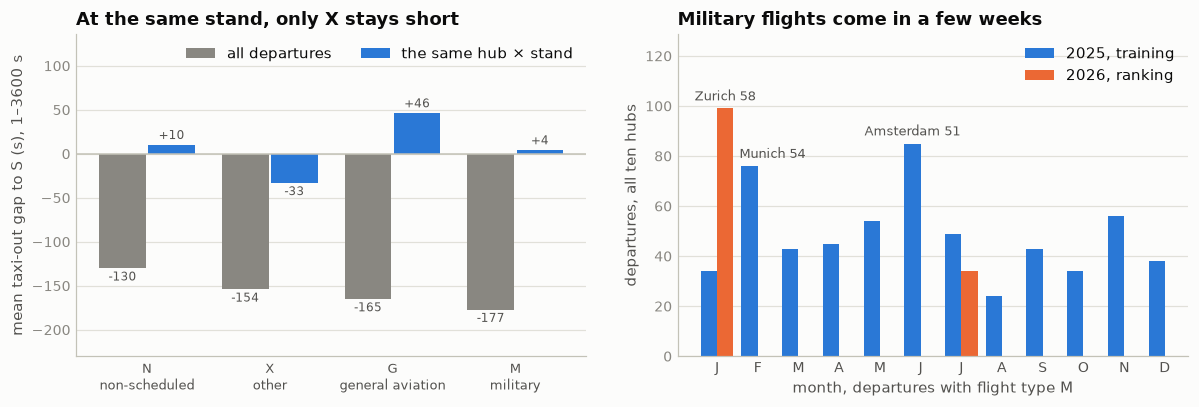

In [8]:
# the picture: each code's taxi gap to a scheduled flight, over all departures and at the same stand; and the calendar of the military flights
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
lv = ["N", "X", "G", "M"]
g_all = ft_gap[ft_gap.inside_the_same == "all departures"].set_index("ft").loc[lv]
g_std = ft_gap[ft_gap.inside_the_same == "hub × stand (§13)"].set_index("ft").loc[lv]
x = np.arange(len(lv))
b1 = a1.bar(x - 0.2, g_all.mean_gap, width=0.38, color=MUTED, label="all departures")
b2 = a1.bar(x + 0.2, g_std.mean_gap, width=0.38, color=BLUE, label="the same hub × stand")
for b in (b1, b2):
    a1.bar_label(b, fmt="%+.0f", fontsize=8, color=INK2, padding=2)
a1.axhline(0, color=BASELINE, lw=1)
a1.set_ylim(min(g_all.mean_gap.min(), g_std.mean_gap.min()) * 1.3, max(g_std.mean_gap.max(), 0) + 90)
a1.set_xticks(x, ["N\nnon-scheduled", "X\nother", "G\ngeneral aviation", "M\nmilitary"], color=INK2, fontsize=8.5)
a1.set_ylabel("mean taxi-out gap to S (s), 1–3600 s")
a1.set_title("At the same stand, only X stays short")
a1.legend(loc="upper right", ncol=2)
style(a1)
m25 = ft_mon[ft_mon.yr == 2025].set_index("mon").reindex(range(1, 13), fill_value=0)
m26 = ft_mon[ft_mon.yr == 2026].set_index("mon")
a2.bar(m25.index - 0.2, m25.n, width=0.4, color=BLUE, label="2025, training")
a2.bar(m26.index + 0.2, m26.n, width=0.4, color=ORANGE, label="2026, ranking")
for px, n, lbl, ha in [(1.55, m25.loc[2, "n"], f"Munich {m25.loc[2, 'eddm']}", "left"), (5.8, m25.loc[6, "n"], f"Amsterdam {m25.loc[6, 'eham']}", "center"),
                        (1.2, m26.loc[1, "n"], f"Zurich {m26.loc[1, 'lszh']}", "center")]:
    a2.text(px, n + 2, lbl, ha=ha, va="bottom", fontsize=8.5, color=INK2)
a2.set_ylim(0, max(m25.n.max(), m26.n.max()) * 1.3)
a2.set_xticks(range(1, 13), list("JFMAMJJASOND"), color=INK2)
a2.set_title("Military flights come in a few weeks")
a2.set_xlabel("month, departures with flight type M")
a2.set_ylabel("departures, all ten hubs")
a2.legend(loc="upper right")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

In [9]:
# what the flight type buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 cascading rung by rung to the coarser key
# (§13's std_rungs). On the airport mean beside the columns it is a finer cut of; on §9's anchor and §13's base; on raw labels, where its
# null level is §2's missing plan; then the filled forms. The second number is the RMSE on the holdout rows whose code is not S
con.sql(f"""
    CREATE OR REPLACE TABLE ft_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, {TYPE_FINAL} typ, coalesce(MARKET_SEGMENT_flt, '(no plan)') seg,
           coalesce(FLIGHT_TYPE_flt, '(no plan)') ft, ADEP_flt IS NULL no_plan, coalesce(rule_final, '∅') rf,
           coalesce(FLIGHT_TYPE_flt, ft_twin, '(no plan)') ft_tw,
           coalesce(FLIGHT_TYPE_flt, ft_twin, CASE WHEN NOT ft_low THEN ft_imp END, '(no plan)') ft_hist,
           ADEP_flt IS NULL AND ft_twin IS NULL AND (ft_imp IS NULL OR ft_low) unreached,
           coalesce(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) >= 7200, FALSE) late2h,
           coalesce(FLIGHT_TYPE_flt != 'S', FALSE) non_s, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM (SELECT f.*, w.ft_twin, i.ft_imp, i.ft_low FROM ({FINAL}) f
          LEFT JOIN (SELECT MVT_ID_mvt, FLIGHT_TYPE_flt ft_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')
                     UNION ALL SELECT MVT_ID_mvt, FLIGHT_TYPE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet')) w USING (MVT_ID_mvt)
          LEFT JOIN (SELECT MVT_ID_mvt, FLIGHT_TYPE_flt ft_imp, FLIGHT_TYPE_low_conf ft_low
                     FROM read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet')) i USING (MVT_ID_mvt)
          WHERE f.ds = 'training' AND f.PHASE_mvt = 'DEP' AND f.TAXITIME_SEC_mvt >= 1)""")
con.sql("CREATE OR REPLACE TABLE ft_t AS SELECT * FROM ft_d WHERE y <= 3600")


def ft_rungs(rungs, tbl="ft_t", where="TRUE"):
    """§13's std_rungs on this section's tables: each rung's cell mean where it has ≥ 30 fit rows, else the rung before it.
    Returns (name, RMSE, RMSE on the rows whose code is not S, number of those rows) per rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE ft_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val AND {where} GROUP BY ALL")
        joins.append(f"LEFT JOIN ft_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN ft_s{i}.c >= 30 THEN ft_s{i}.m END")
        pred = f"coalesce({', '.join(reversed(preds))}, g.m)"
        out.append((name, *con.sql(f"""
            SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (v.non_s)), count(*) FILTER (v.non_s)
            FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val AND {where}) g WHERE v.is_val AND {where}""").fetchone()))
    return out


def ft_show(title, base, extras, tbl="ft_t", where="TRUE"):
    print(title)
    _, r, rn, _ = ft_rungs(base, tbl, where)[-1]
    print(f"    {base[-1][0]:52s} {r:7.1f} s · {rn:6.1f} s")
    for name, steps in extras:
        _, r, rn, _ = ft_rungs(base + [(name, base[-1][1] + keys) for keys in steps], tbl, where)[-1]
        print(f"    {name:52s} {r:7.1f} s · {rn:6.1f} s")


n_val, n_ns = con.sql("SELECT count(*), count(*) FILTER (non_s) FROM ft_t WHERE is_val").fetchone()
ft_show(f"(1) on the airport mean — {n_val:,} Nov+Dec departures 1–3,600 s, {n_ns:,} of them not S (RMSE · on the rows not S):", AP,
        [("+ the flight type, '(no plan)' a level", [["ft"]]),
         ("+ the missing-plan flag alone (§2)", [["no_plan"]]),
         ("+ segment (§20)", [["seg"]]),
         ("+ segment, then the flight type", [["seg"], ["seg", "ft"]]),
         ("+ aircraft type (§11a)", [["typ"]]),
         ("+ aircraft type, then the flight type", [["typ"], ["typ", "ft"]])])

con.sql("""
    CREATE OR REPLACE TABLE ft_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM ft_t WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT ft_t.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
    FROM ft_t JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")
n2, n2ns = con.sql("SELECT count(*), count(*) FILTER (non_s) FROM ft_wb WHERE is_val").fetchone()
print()
ft_show(f"(2) on §9's anchor, then on §13's base — the {n2:,} Nov+Dec departures with a runway, a stand and an anchor, {n2ns:,} not S:",
        BASE[:3], [("+ the flight type, on the anchor", [["ft"]]), ("+ segment, on the anchor", [["seg"]])], tbl="ft_wb")
ft_show("", BASE, [("+ the flight type, on top", [["ft"]]), ("+ segment, on top", [["seg"]]),
                   ("+ aircraft type, on top", [["typ"]]), ("+ aircraft type, then the flight type", [["typ"], ["typ", "ft"]])], tbl="ft_wb")

n3 = con.sql("SELECT count(*) FROM ft_d WHERE is_val").fetchone()[0]
print()
ft_show(f"(3) raw labels, no ceiling (§14) — all {n3:,} Nov+Dec departures: who owns the null level?", AP,
        [("+ the missing-plan flag alone (§2)", [["no_plan"]]), ("+ the flight type, '(no plan)' a level", [["ft"]]),
         ("+ the flag, then the flight type", [["no_plan"], ["no_plan", "ft"]])], tbl="ft_d")
print("\n    the flight type with the flag taken away — only the departures that carry a plan:")
for lbl, tbl in [("raw labels", "ft_d"), ("labels 1–3,600 s", "ft_t")]:
    a = ft_rungs(AP, tbl, "NOT no_plan")[-1][1]
    b = ft_rungs(AP + [("x", ["hub", "ft"])], tbl, "NOT no_plan")[-1][1]
    print(f"    {lbl:20s} airport {a:7.2f} s  →  + the flight type {b:7.2f} s   ({a - b:.2f} s)")

FLAG_RULE = AP + [("+ the missing-plan flag (§2)", ["hub", "no_plan"]), ("+ the flag, then rule_final (§4)", ["hub", "no_plan", "rf"])]
print()
ft_show("(4) the filled forms, raw labels — the no-plan rows split by §2's twins and §2c's history (high-confidence values only):", FLAG_RULE,
        [("+ the flight type, twins filled", [["ft_tw"]]),
         ("+ the flight type, twins and history filled", [["ft_hist"]]),
         ("+ 'no layer reaches the row' alone (§2c)", [["unreached"]]),
         ("+ that flag, then the history-filled type", [["unreached"], ["unreached", "ft_hist"]]),
         ("+ takeoff ≥ 2 h after schedule (§10a's clock)", [["late2h"]]),
         ("+ ≥ 2 h late, then 'no layer reaches'", [["late2h"], ["late2h", "unreached"]]),
         ("+ ≥ 2 h late, 'no layer', then history-filled", [["late2h"], ["late2h", "unreached"], ["late2h", "unreached", "ft_hist"]])], tbl="ft_d")
ft_show("    ... the same on labels 1–3,600 s:", FLAG_RULE,
        [("+ the flight type, twins filled", [["ft_tw"]]), ("+ the flight type, twins and history filled", [["ft_hist"]])])
print("\n    the no-plan departures by rule and by whether any layer reaches them (training, labels ≥ 1 s):")
print(con.sql("""
    SELECT rf rule_final, unreached, count(*) n, round(avg(y)) mean_raw, round(100.0*count(*) FILTER (y > 3600)/count(*), 2) pct_over_hour,
           round(100.0*count(*) FILTER (hub = 'LIRF')/count(*), 1) pct_lirf, round(100.0*count(*) FILTER (late2h)/count(*), 1) pct_late_2h
    FROM ft_d WHERE no_plan GROUP BY ALL ORDER BY rule_final, unreached""").df().to_string(index=False))

print("\nlook both ways — the codes in the scored months against their 2025 twins (all departures):")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(FLIGHT_TYPE_flt)/count(*), 2) pct_with_code,
           round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'S')/count(FLIGHT_TYPE_flt), 2) pct_S, round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'N')/count(FLIGHT_TYPE_flt), 2) pct_N,
           round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'X')/count(FLIGHT_TYPE_flt), 2) pct_X, round(100.0*count(*) FILTER (FLIGHT_TYPE_flt = 'G')/count(FLIGHT_TYPE_flt), 2) pct_G,
           count(*) FILTER (FLIGHT_TYPE_flt = 'M') m, count(*) FILTER (FLIGHT_TYPE_flt = 'M' AND ADEP_mvt = 'LSZH') m_from_lszh
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

(1) on the airport mean — 327,485 Nov+Dec departures 1–3,600 s, 11,445 of them not S (RMSE · on the rows not S):
    airport (§5)                                           357.3 s ·  409.9 s
    + the flight type, '(no plan)' a level                 355.2 s ·  371.1 s
    + the missing-plan flag alone (§2)                     357.1 s ·  410.3 s
    + segment (§20)                                        350.7 s ·  357.0 s
    + segment, then the flight type                        350.4 s ·  350.3 s
    + aircraft type (§11a)                                 337.9 s ·  352.9 s


    + aircraft type, then the flight type                  337.5 s ·  345.7 s



(2) on §9's anchor, then on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor, 11,445 not S:
    + AOBT_3 anchor (§9)                                   283.6 s ·  334.3 s
    + the flight type, on the anchor                       282.3 s ·  310.5 s
    + segment, on the anchor                               277.2 s ·  308.2 s



    + stand (§13's base)                                   265.5 s ·  297.6 s


    + the flight type, on top                              265.5 s ·  297.6 s
    + segment, on top                                      265.3 s ·  297.7 s


...

    + aircraft type, then the flight type                  265.3 s ·  297.5 s

(3) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures: who owns the null level?
    airport (§5)                                           496.5 s ·  438.6 s
    + the missing-plan flag alone (§2)                     475.0 s ·  439.5 s
    + the flight type, '(no plan)' a level                 473.5 s ·  401.6 s
    + the flag, then the flight type                       473.5 s ·  401.6 s

    the flight type with the flag taken away — only the departures that carry a plan:
    raw labels           airport  373.72 s  →  + the flight type  371.79 s   (1.93 s)
    labels 1–3,600 s     airport  355.36 s  →  + the flight type  353.46 s   (1.90 s)

(4) the filled forms, raw labels — the no-plan rows split by §2's twins and §2c's history (high-confidence values only):


    + the flag, then rule_final (§4)                       474.7 s ·  438.6 s
    + the flight type, twins filled                        472.4 s ·  401.7 s
    + the flight type, twins and history filled            467.0 s ·  401.7 s
    + 'no layer reaches the row' alone (§2c)               468.5 s ·  438.6 s


    + that flag, then the history-filled type              467.0 s ·  401.7 s
    + takeoff ≥ 2 h after schedule (§10a's clock)          461.4 s ·  438.7 s
    + ≥ 2 h late, then 'no layer reaches'                  453.2 s ·  438.7 s


    + ≥ 2 h late, 'no layer', then history-filled          451.7 s ·  401.7 s
    ... the same on labels 1–3,600 s:
    + the flag, then rule_final (§4)                       356.8 s ·  409.3 s
    + the flight type, twins filled                        355.0 s ·  371.1 s
    + the flight type, twins and history filled            354.9 s ·  371.1 s

    the no-plan departures by rule and by whether any layer reaches them (training, labels ≥ 1 s):
rule_final  unreached     n  mean_raw  pct_over_hour  pct_lirf  pct_late_2h
         I      False 16546    1441.0           5.06       7.2         27.0
         I       True  2959    2089.0           8.31      10.2         14.5
         V      False  1216     293.0           0.08       0.0          2.5
         V       True  1498     483.0           0.20       0.0          1.3

look both ways — the codes in the scored months against their 2025 twins (all departures):


  yr  mon      n  pct_with_code  pct_S  pct_N  pct_X  pct_G  m  m_from_lszh
2025    1 153706          99.07  96.34   2.50   0.61   0.53 34           16
2026    1 152719          98.39  96.16   2.48   0.75   0.55 99           58
2025    7 190713          97.94  96.30   2.71   0.45   0.51 49            9
2026    7 192122          98.52  96.50   2.55   0.45   0.48 34            4


In [10]:
# closing state — the column after §23: nothing of its own to repair (it is missing only where the plan is); §2's twin layers hand the
# departures they recover the whole plan block, this code with it. §2c's history fill is counted here, not applied (ladder 4 above)
TWINSFT = (f"(SELECT MVT_ID_mvt, FLIGHT_TYPE_flt ft_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
           f"UNION ALL SELECT MVT_ID_mvt, FLIGHT_TYPE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
IMPFT = (f"(SELECT MVT_ID_mvt, FLIGHT_TYPE_flt ft_imp, FLIGHT_TYPE_low_conf ft_low "
         f"FROM read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (FLIGHT_TYPE_flt IS NULL) null_before,
           count(*) FILTER (FLIGHT_TYPE_flt IS NULL AND ft_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(FLIGHT_TYPE_flt, ft_twin) IS NULL) null_after,
           round(100.0*count(*) FILTER (coalesce(FLIGHT_TYPE_flt, ft_twin) IS NULL)/count(*), 2) pct_null_after,
           count(*) FILTER (coalesce(FLIGHT_TYPE_flt, ft_twin) IS NULL AND ft_imp IS NOT NULL AND NOT ft_low) history_could_fill,
           count(*) FILTER (coalesce(FLIGHT_TYPE_flt, ft_twin) IS NULL AND ft_imp IS NOT NULL AND ft_low) history_low_confidence,
           count(*) FILTER (coalesce(FLIGHT_TYPE_flt, ft_twin) IS NULL AND ft_imp IS NULL) no_layer_reaches
    FROM {BOTH} d LEFT JOIN {TWINSFT} w USING (MVT_ID_mvt) LEFT JOIN {IMPFT} i USING (MVT_ID_mvt)
    WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
assert (st.history_could_fill + st.history_low_confidence + st.no_layer_reaches == st.null_after).all()
print("twin rows whose recovered plan carries no flight type:", con.sql(f"SELECT count(*) FROM {TWINSFT} WHERE ft_twin IS NULL").fetchone()[0])

print("\nwhat each layer would put in, departures — the twins' codes, and the high-confidence history values:")
print(con.sql(f"""
    SELECT src, count(*) FILTER (d.FLIGHT_TYPE_flt IS NULL AND ft_twin = 'S') twins_S, count(*) FILTER (d.FLIGHT_TYPE_flt IS NULL AND ft_twin != 'S') twins_not_S,
           count(*) FILTER (coalesce(d.FLIGHT_TYPE_flt, ft_twin) IS NULL AND NOT ft_low AND ft_imp = 'S') history_S,
           count(*) FILTER (coalesce(d.FLIGHT_TYPE_flt, ft_twin) IS NULL AND NOT ft_low AND ft_imp = 'M') history_M,
           count(*) FILTER (coalesce(d.FLIGHT_TYPE_flt, ft_twin) IS NULL AND NOT ft_low AND ft_imp = 'X') history_X,
           count(*) FILTER (coalesce(d.FLIGHT_TYPE_flt, ft_twin) IS NULL AND NOT ft_low AND ft_imp IN ('N', 'G')) history_N_G,
           count(*) FILTER (coalesce(d.FLIGHT_TYPE_flt, ft_twin) IS NULL AND NOT ft_low AND ft_imp IN ('M', 'X', 'G') AND FLIGHT_RULE_mvt = 'V') history_M_X_G_on_vfr
    FROM {BOTH} d LEFT JOIN {TWINSFT} w USING (MVT_ID_mvt) LEFT JOIN {IMPFT} i USING (MVT_ID_mvt)
    WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe final levels, departures — the plan's code with the twins filled in, and how each taxies (training, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_TYPE_flt, ft_twin, '∅') AS flight_type, count(*) FILTER (src = 'training') training,
           round(100.0*count(*) FILTER (src = 'training')/sum(count(*) FILTER (src = 'training')) OVER (), 3) pct_training,
           count(*) FILTER (src = 'ranking') ranking,
           round(avg(TAXITIME_SEC_mvt) FILTER (src = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) mean_taxi,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (src = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) med_taxi
    FROM {BOTH} LEFT JOIN {TWINSFT} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY training DESC, flight_type""").df().to_string(index=False))

     src       n  null_before  filled_by_twins  null_after  pct_null_after  history_could_fill  history_low_confidence  no_layer_reaches
training 2085047        22470             1898       20572            0.99               15878                    2460              2234
 ranking  344841         5290              479        4811            1.40                3780                     627               404
twin rows whose recovered plan carries no flight type: 1

what each layer would put in, departures — the twins' codes, and the high-confidence history values:
     src  twins_S  twins_not_S  history_S  history_M  history_X  history_N_G  history_M_X_G_on_vfr
training     1816           82      14181        541        522          634                  1207
 ranking      452           27       3490         91         69          130                   178

the final levels, departures — the plan's code with the twins filled in, and how each taxies (training, 1–3600 s):
flight_type  trai

                                     feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_TYPE_flt — the plan's code, ∅ a level categorical           6                        0.067
                        its null level alone categorical           2                        0.007
              not scheduled — any code but S categorical           2                        0.067
                 X alone — the other flights categorical           2                        0.028
                        market segment (§20) categorical           9                        0.214
                        aircraft type (§11a) categorical         107                        0.358


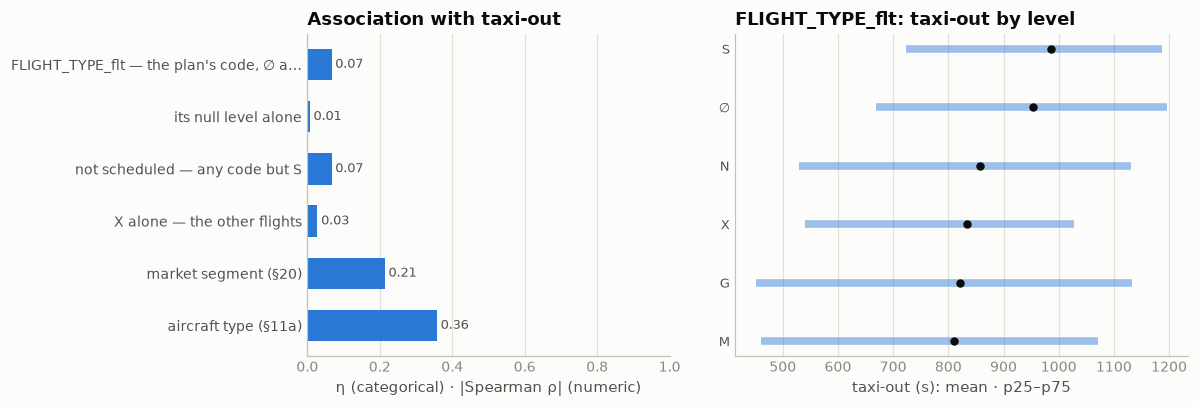

In [11]:
# correlation with the target: the plan's code (its null a level), the null level alone — §2's missing plan, nothing else — the
# not-scheduled flag, X alone, and the two columns it is a finer cut of: the segment (§20) and the aircraft type (§11a)
a = target_assoc([
    ("FLIGHT_TYPE_flt — the plan's code, ∅ a level", "cat", "FLIGHT_TYPE_flt"),
    ("its null level alone", "cat", "FLIGHT_TYPE_flt IS NULL"),
    ("not scheduled — any code but S", "cat", "coalesce(FLIGHT_TYPE_flt != 'S', FALSE)"),
    ("X alone — the other flights", "cat", "coalesce(FLIGHT_TYPE_flt = 'X', FALSE)"),
    ("market segment (§20)", "cat", "MARKET_SEGMENT_flt"),
    ("aircraft type (§11a)", "cat", TYPE_FINAL, 200),
])
assoc_chart(a, "FLIGHT_TYPE_flt", title="FLIGHT_TYPE_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Five codes, as documented, missing only where the plan is** | training departures `S` 1,986,754, `N` 54,312, `X` 11,063, `G` 9,867, `M` 581: 96.324%, 2.633%, 0.536%, 0.478%, 0.028% of those with a plan. Null on 22,470 training and 5,290 ranking departures and on 15,449 and 2,552 arrivals, each exactly the rows without a plan: 0 plans lack a code, 0 codes lack a plan. So §22's 167 plans with no rule and no wake class do carry one | `data/FEATURES.md` lists the five codes correctly. The column's null level *is* §2's missing-plan flag, with nothing added |
| **A finer cut of the segment, and only of five of its eight levels** | Cramér's V **0.744** on departures with a plan. Mainline (1,325,748) and Regional (210,865) are 100.00% `S`, Non-Scheduled (14,577) 100% `N`. The code splits the rest: Business `N` 32,871, `G` 9,072, `X` 2,547, `S` 8; Cargo 92.25% `S`, `N` 4,109; Lowcost 98.82% `S`, `N` 2,646, `X` 2,076; Other `X` 5,888, `G` 779; Military `M` 581, `N` 103 | where the segment says an airline is flying its timetable, the code has nothing to add. It only speaks inside business aviation, cargo, low-cost and the two catch-all segments |
| **The code belongs to the flight, not the operator** | 97.37% of departures fly for an operator (hashed) that files more than one code, 97.01% under a callsign prefix that does, but only **4.41%** under a callsign that does; 99.71% carry their callsign's most common code. An `S` callsign flies 90.5 departures a year; `N` 3.1, `X` 3.2, `G` 2.8, `M` 1.5 | an encoding keyed on the operator blurs the code; the callsign carries it. Outside `S`, most callsigns are near one-offs |
| **`N` and `G` are business aviation** | `N`: NetJets `NJE` 6,453, VistaJet `VJT` 2,235, Swiftair `SWT` 1,656, Gestair `GES` 1,605; A320 3,863, C56X 3,807, E55P 3,618; stands LSZH:GA6 1,670, EHAM:K38 1,417, EDDF:V701 805. `G`: Swiss private registrations (`HBV` 270, `HBF` 206, `HBJ` 192) and `JFA` 266; PC12 762, GLEX 664, GLF6 654; LSZH:GA6 465. Share of the hub's departures: LSZH `N` 7.10%, `G` 2.36%; LEMD 4.77% and 0.85%; EGLL 0.12% and 0.00% | the two codes mark the business jets and their aprons, which §11's type and §13's stand already name. Zurich is the business-aviation hub; Heathrow has almost none |
| **`M` is there, although military movements were said to be removed** | 581 training and 133 ranking departures, every one in the Military segment (713 and 211 departures). Air-force transports: `GAF` 104, `SUI` 46, `CTM` 41, `RRR` 32; A332 58, F900 46, C17 35. They come in weeks: **46 from Munich on 10–16 February 2025** (17 callsign prefixes), the Munich Security Conference; **37 from Amsterdam on 23–27 June 2025** (19), the NATO summit in The Hague; **41 from Zurich on 19–25 January 2026** (19), the World Economic Forum in Davos | the removal did not reach state transport filed on an ordinary flight plan. One of these weeks falls in a scored month: January 2026 has 99 `M` departures against 34 in January 2025, 58 of them from Zurich against 16 |
| **`X` is flying outside the timetable** | Turkish `THY` 1,278 (Antalya 159, Medina 124, Jeddah 106), `SAZ` 723 (the Swiss air-ambulance jets: Pristina 24, Palma 20, Zurich 17, Katowice 16, and no scheduled flights at all), Air France `AFR` 662 (Orly 174, Charles de Gaulle 82, Lyon 69, Clermont-Ferrand 55), Air Nostrum `ANE` 622 (Valencia 177), then `RYR` 446, `VLG` 412, `DLH` 354 (Frankfurt, Düsseldorf, Munich, Sofia) and `ITY` 339. Round trips 1.96% against `S`'s 0.02%; biggest stand LSZH:REG (703) | positioning between an airline's own bases, charters and ambulance flights, mostly on the airline's normal aircraft (B738 1,599, A320 1,189). The only code that marks a different *kind of flight* for the same aircraft, which is why its short taxi is the one that survives the stand (next row) |
| **The short taxi is the aircraft and the apron, except for `X`** | mean gap to `S` over all departures: `N` −130 s, `X` −154, `G` −165, `M` −177. At the same hub × stand: `N` **+10 s** (19,612 of 54,156 rows matched), `G` **+46** (793 of 9,843), `M` **+4** (106 of 580), `X` **−33** (7,388 of 10,991); at the same hub × aircraft type `N` +17, `G` +93, `M` +115, `X` −43. Inside Business, `X` has a 476 s median against `N` 711 and `G` 736; inside Lowcost, `X` 825 against `S` 911. At hub × stand × type `X`'s mean gap stays −33 s but its median gap is −2 s | the two-to-three-minute shortfalls are composition, a business jet at a GA apron, and they vanish at the stand, as `Y`'s did in §22. `X` keeps half a minute at the same stand, carried by a short-taxiing minority rather than the typical `X` flight |
| **Worth 2 s alone, nothing once the stand is known** | honest ladders, 327,485 Nov+Dec departures: airport 357.3 → + the code **355.2** (the 11,445 rows not `S`: 409.9 → 371.1). Segment 350.7 → then the code 350.4; aircraft type 337.9 → then the code 337.5. On §9's anchor, 324,629 departures: 283.6 → 282.3, the segment 277.2. On §13's base: 265.5 → **265.5** with the code, 265.3 with the segment or the type; the rows not `S` 297.6 → 297.6 | everything the code knows, the segment, the aircraft and the stand already say |
| **On raw labels its null level is §2's flag** | 327,968 Nov+Dec departures, no ceiling: airport 496.5 → + the missing-plan flag 475.0 → + the code 473.5; the flag then the code 473.5. Departures with a plan only: 373.72 → 371.79 raw, 355.36 → 353.46 on 1–3,600 s, **1.93 and 1.90 s**. Over an hour: the null level 4.892% of rows, `X` 0.498%, `S` 0.144% | of the 23.0 s the raw column seems to carry, 21.5 s belong to §2 and 1.5 s to the code, the same split as §20's segment and §22's rule |
| **Filling the nulls: the twins add a little; §2c's history mostly flags the rows it cannot reach** | raw labels, on the flag and `rule_final` (474.7): the code with the twins filled **472.4**; with the twins and §2c's high-confidence history **467.0**. But "no layer reaches the row" alone gives **468.5**, 6.2 of those 7.7 s, and the history's values add 1.5 s on top of it. On 1–3,600 s: 356.8 → 355.0 (twins) → 354.9 (history). The unreached no-plan `I` departures average 2,089 s raw and run over an hour on 8.31%, against 1,441 s and 5.06% for the ones a layer reaches. The flag is not §10a's lateness: with takeoff ≥ 2 h after schedule in first, 461.4 → 453.2 | the history's values are worth 1.5 s on raw labels and 0.1 s on 1–3,600 s; 1,207 of its `M`, `X` and `G` values fall on VFR movements, the special-mission fleets §4 already separates. The larger signal, whether any layer reaches the row, describes the flight number, not the code, and belongs to §2c |
| **2026 sits on 2025, except for one week in Zurich** | with a code: January 99.07% → 98.39%, July 97.94% → 98.52%. `N` 2.50% → 2.48% and 2.71% → 2.55%; `X` 0.61% → 0.75% and 0.45% → 0.45%; `G` 0.53% → 0.55% and 0.51% → 0.48%. `M` January 34 → 99 (Zurich 16 → 58), July 49 → 34 | the code mix is as stable as the timetable. The January `M` rise is 65 extra departures in 152,719 |
| Marginal | η: the code, ∅ a level, 0.067; the not-`S` flag 0.067; `X` alone 0.028; the null level alone 0.007. The segment 0.214, the aircraft type 0.358 | the code's whole marginal signal is the not-`S` bit, a third of the segment's |

**Decisions**

| issue | decision | why |
|---|---|---|
| the code as a feature | **a plain category with its null a level, the twins filled in; no derived form** | 355.2 on the airport mean, but 350.4 after the segment, 337.5 after the type and 265.5 on §13's base. Nothing to engineer from a column the stand has already absorbed |
| an "`X` flight" flag, the one gap that survives the stand | not adopted | −33 s mean at the same hub × stand, but on 0.54% of departures, with a −2 s median gap at stand × type, and 297.6 s on §13's base for the rows not `S` with or without the code |
| §2c's history fill of this column | **measured, not adopted here** | its values are worth 1.5 s on raw labels and 0.1 s on 1–3,600 s. The other 6.2 s is whether any layer reaches the row, which the code does not own; it goes to §2c (see the map's open list) |
| the twin layers' code | adopted for the matrix, as `TWINSFT` | the same 1,898 training and 479 ranking departures §15, §21 and §22 gained; 82 and 27 of them not `S`. One recovered plan carries no code |
| `data/FEATURES.md`'s note that military movements were removed | flagged, not edited | the note quotes the organisers; `M` shows that state transport flights on ordinary plans stayed in. A tracked, shared doc deserves its own commit (as §20's segment fix) |

**State after §23** (departures):

| `FLIGHT_TYPE_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| of those left, §2c's history could fill (not applied) | 15,878, plus 2,460 low-confidence | 3,780, plus 627 |
| left, and why | 0.99%: no plan block | 1.40%: the same |

| final level | training | ranking | median DEP taxi, 1–3600 s |
|---|---:|---:|---:|
| `S` | 1,988,570 | 327,606 | 916 s |
| `N` | 54,356 | 8,571 | 817 s |
| ∅ | 20,572 | 4,811 | 912 s |
| `X` | 11,090 | 1,985 | 778 s |
| `G` | 9,877 | 1,735 | 728 s |
| `M` | 582 | 133 | 678 s |

**Use in modeling.** Nothing new to feed. The code is a finer cut of §20's segment that only speaks
inside business aviation, cargo and low-cost. What it says there, a small aircraft at a GA apron, is
what §11's type and §13's stand already say: 265.5 s on §13's base with or without it. Keep it as a
plain category, its null level being §2's flag and the twins filled in. What the column contributes
is knowledge about the data. **`M` is state transport that survived the organisers' filter and comes in
summit weeks**, and one of those weeks (Davos, January 2026) is in a scored month. **`X` is airlines
flying outside the timetable**, the one code that marks a different kind of flight for the same
aircraft at the same stand. The history fill §2c built for this column is mostly a flag for the rows
it cannot reach, and that finding goes back to §2c. The closing matrix reads the twin layers' code as
`TWINSFT` and enters the column with those 1,898 + 479 filled in and its nulls kept as a level.

## 24 · `AIRCRAFT_TYPE_flt` — the aircraft the plan was filed for

The ICAO type designator as the operator filed it: the plan's copy of §11's `AIRCRAFT_TYPE_mvt`. §11a has
already settled how the two combine. They disagree on 0.34% of matched departures, almost always as two
spellings of one aircraft, and Schiphol changed its spelling in November 2025, so the type the pipeline
reads is `TYPE_FINAL`, the plan's code first. This section does not repeat that study. It asks what is
left. **Where is the column missing, and what does it name that the movement does not?** And a question
§11a could not ask: §2's recovered plan blocks each carry a type, and the movement they were recovered
for carries its own, so **the movement's code can referee every recovery layer**.

| step | question | what came out |
|---|---|---|
| **census** | where it is missing; the vocabulary against the movement's; `ZZZZ`; 2026's new codes | missing exactly where the plan is missing, every code well-formed. 239 codes on training departures against the movement's 269: the 42 codes only the movement uses are light aircraft, gliders and helicopters that file no plan. The plan names 30 of the 31 departures the movement leaves as `ZZZZ` |
| **the referee** | does a recovered plan's type match the movement's? | the twins match on **100.00%** of 1,781 training and 436 ranking departures, against 99.66% and 99.82% for ordinary matches. §2c's history is no referee: its first step looks the type up from the movement's own code |
| **the type-less slice** | what reaches Fiumicino's departures without a type, and what their labels look like | a twin reaches 117 training and 43 ranking departures. Their median label is an ordinary Fiumicino taxi (1,022 s, 12.0% over 2 h); the 776 nothing reaches have a median of 4,799 s (33.0%) |
| **signal** | the plan's code against the movement's and the plan-first form, with the twins' type filled in | 357.3 → 338.2 against 338.0 and 337.9; 265.3 for all three on §13's base. On raw labels the plan's ∅ is §2's flag exactly, and the plan-first form with the twins' type is 459.5 against 460.3 |
| **closing state** | what the twins fill | 1,898 + 479 plan codes, as in §23, and a type for 117 + 43 departures that have none on either side |

In [4]:
# census by file × phase: the plan's type and the presence rule — missing exactly where the plan is missing (§17: the plan is missing iff
# ADEP_flt IS NULL), with no holes of its own; the two vocabularies (§11's movement code against the plan's), ZZZZ, and 2026's new codes
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
display(cat_stats("AIRCRAFT_TYPE_flt"))

print("by file × phase — the presence rule, the two vocabularies, and §22's plans that lack both the rule and the wake class:")
cen = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL) n_null, count(*) FILTER (ADEP_flt IS NULL) plan_missing,
           count(*) FILTER (ADEP_flt IS NOT NULL AND AIRCRAFT_TYPE_flt IS NULL) plan_but_no_type,
           count(*) FILTER (ADEP_flt IS NULL AND AIRCRAFT_TYPE_flt IS NOT NULL) type_but_no_plan,
           count(*) FILTER (NOT regexp_full_match(AIRCRAFT_TYPE_flt, '[A-Z][A-Z0-9]{{1,3}}')) malformed_plan,
           count(*) FILTER (NOT regexp_full_match(AIRCRAFT_TYPE_mvt, '[A-Z][A-Z0-9]{{1,3}}')) malformed_movement,
           count(DISTINCT AIRCRAFT_TYPE_flt) codes_plan, count(DISTINCT AIRCRAFT_TYPE_mvt) codes_movement,
           count(*) FILTER (ADEP_flt IS NOT NULL AND FLIGHT_RULE_flt IS NULL AND WK_TBL_CAT_flt IS NULL) plans_no_rule_no_wake,
           count(*) FILTER (ADEP_flt IS NOT NULL AND FLIGHT_RULE_flt IS NULL AND WK_TBL_CAT_flt IS NULL AND AIRCRAFT_TYPE_flt IS NOT NULL) of_which_typed
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(cen.to_string(index=False))
assert (cen.plan_but_no_type == 0).all() and (cen.type_but_no_plan == 0).all()
assert (cen.malformed_plan == 0).all() and (cen.malformed_movement == 0).all() and (cen.plans_no_rule_no_wake == cen.of_which_typed).all()

print("\nthe codes only the plan ever uses (both files, both phases), beside what the movement recorded on the same rows:")
print(con.sql(f"""
    WITH m AS (SELECT DISTINCT AIRCRAFT_TYPE_mvt c FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt IS NOT NULL)
    SELECT AIRCRAFT_TYPE_flt plan, AIRCRAFT_TYPE_mvt movement, count(*) n, string_agg(DISTINCT hub, ' ' ORDER BY hub) hubs
    FROM (SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub FROM {BOTH})
    WHERE AIRCRAFT_TYPE_flt NOT IN (SELECT c FROM m) GROUP BY 1, 2 ORDER BY n DESC, 1, 2""").df().to_string(index=False))
print("... and the codes only the movement ever uses — who flies them:")
print(con.sql(f"""
    WITH f AS (SELECT DISTINCT AIRCRAFT_TYPE_flt c FROM {BOTH} WHERE AIRCRAFT_TYPE_flt IS NOT NULL),
         o AS (SELECT * FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt NOT IN (SELECT c FROM f)),
         top AS (SELECT AIRCRAFT_TYPE_mvt c, count(*) n FROM o GROUP BY 1 ORDER BY n DESC, c LIMIT 8)
    SELECT count(DISTINCT AIRCRAFT_TYPE_mvt) codes, count(*) n, count(*) FILTER (ADEP_flt IS NULL) no_plan, count(*) FILTER (FLIGHT_RULE_mvt = 'V') vfr,
           count(*) FILTER (AIRCRAFT_TYPE_mvt IN {ROTORCRAFT}) rotorcraft,
           (SELECT string_agg(c || ' ' || n, ', ' ORDER BY n DESC, c) FROM top) biggest_eight
    FROM o""").df().to_string(index=False))

print("\nZZZZ, a type the filer did not declare (§11) — departures: the movement's ZZZZ that the plan names, and the reverse:")
print(con.sql(f"""
    SELECT src, count(*) FILTER (AIRCRAFT_TYPE_mvt = 'ZZZZ') movement_zzzz, count(*) FILTER (AIRCRAFT_TYPE_mvt = 'ZZZZ' AND AIRCRAFT_TYPE_flt != 'ZZZZ') plan_names_it,
           count(*) FILTER (AIRCRAFT_TYPE_mvt = 'ZZZZ' AND AIRCRAFT_TYPE_flt IS NULL) no_plan,
           count(*) FILTER (AIRCRAFT_TYPE_flt = 'ZZZZ') plan_zzzz, count(*) FILTER (AIRCRAFT_TYPE_flt = 'ZZZZ' AND AIRCRAFT_TYPE_mvt != 'ZZZZ') movement_names_it
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
print(con.sql(f"""
    SELECT string_agg(p || ' ' || n, ', ' ORDER BY n DESC, p) plan_codes_for_movement_zzzz
    FROM (SELECT AIRCRAFT_TYPE_flt p, count(*) n FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt = 'ZZZZ' AND AIRCRAFT_TYPE_flt != 'ZZZZ' GROUP BY 1)""").df().to_string(index=False))

print("\nlook both ways — 2026 departures on a code no 2025 row carries in the same form:")
print(pd.DataFrame([(name, *con.sql(f"""
    WITH seen AS (SELECT DISTINCT {e} c FROM {T} WHERE {e} IS NOT NULL)
    SELECT count(*), string_agg(DISTINCT {e}, ' ' ORDER BY {e}) FROM {R} WHERE PHASE_mvt = 'DEP' AND {e} NOT IN (SELECT c FROM seen)""").fetchone())
    for name, e in [("the plan's code", "AIRCRAFT_TYPE_flt"), ("the movement's code (§11)", "AIRCRAFT_TYPE_mvt"), ("plan first (§11a)", TYPE_FINAL)]],
    columns=["form", "departures_2026", "codes"]).to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,242
ranking 2026,689534,7842,1.14,182


by file × phase — the presence rule, the two vocabularies, and §22's plans that lack both the rule and the wake class:
     src  ph       n  n_null  plan_missing  plan_but_no_type  type_but_no_plan  malformed_plan  malformed_movement  codes_plan  codes_movement  plans_no_rule_no_wake  of_which_typed
training ARR 2082750   15449         15449                 0                 0               0                   0         237             267                     67              67
training DEP 2085047   22470         22470                 0                 0               0                   0         239             269                     74              74
 ranking ARR  344693    2552          2552                 0                 0               0                   0         178             196                     12              12
 ranking DEP  344841    5290          5290                 0                 0               0                   0         180             199           

                     form  departures_2026                                  codes
          the plan's code                9          A358 B462 EVOT IL62 P212 PA44
the movement's code (§11)               18  AS65 B462 C10T EVOT F35 IL62 PA44 PL2
        plan first (§11a)               18 A358 AS65 B462 EVOT F35 IL62 P212 PA44


In [5]:
# the referee §11a did not have: every recovered plan block (§2b's exact twins, §2c's relaxed twins and history) carries a type, and the
# movement it was recovered for carries its own, so the movement's code checks each layer — against the agreement of plans matched the
# ordinary way. §2c's history fills the type in two steps: a lookup keyed on the row's own movement type, then flight number × airport
TWINSTY = (f"(SELECT MVT_ID_mvt, 'exact twin (§2b)' layer, AIRCRAFT_TYPE_flt typ_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
           f"UNION ALL SELECT MVT_ID_mvt, 'relaxed twin ' || matcher_variant || ' (§2c)', AIRCRAFT_TYPE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
IMPTY = (f"(SELECT MVT_ID_mvt, AIRCRAFT_TYPE_flt typ_imp, AIRCRAFT_TYPE_low_conf typ_low "
         f"FROM read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet'))")
print("each source of a plan type against the movement's own code — departures, both files:")
ref = con.sql(f"""
    WITH s AS (SELECT src, '1 plan matched (§2)' origin, AIRCRAFT_TYPE_flt typ, AIRCRAFT_TYPE_mvt mvt FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADEP_flt IS NOT NULL
               UNION ALL SELECT src, '2 ' || layer, typ_twin, AIRCRAFT_TYPE_mvt FROM {BOTH} JOIN {TWINSTY} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP'
               UNION ALL SELECT src, CASE WHEN typ_low THEN '4 §2c history: flight × airport (low confidence)' ELSE '3 §2c history: lookup of the movement''s type' END,
                                typ_imp, AIRCRAFT_TYPE_mvt FROM {BOTH} JOIN {IMPTY} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND typ_imp IS NOT NULL)
    SELECT src, origin, count(*) n, count(*) FILTER (typ IS NULL) no_type, count(*) FILTER (mvt IS NULL) movement_has_none,
           count(*) FILTER (typ = mvt) agree, count(*) FILTER (typ != mvt) differ,
           round(100.0*count(*) FILTER (typ = mvt)/count(*) FILTER (typ IS NOT NULL AND mvt IS NOT NULL), 2) pct_agree
    FROM s GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(ref.to_string(index=False))
print("    all twin layers together:")
print(ref[ref.origin.str.startswith("2 ")].groupby("src", sort=False)[["n", "no_type", "movement_has_none", "agree", "differ"]].sum().to_string())

print("\nthe pairs where a recovered type differs from the movement's (the twins never do) — recovered → movement, both files:")
print(con.sql(f"""
    SELECT CASE WHEN typ_low THEN 'flight × airport' ELSE 'movement-type lookup' END step, typ_imp || '→' || AIRCRAFT_TYPE_mvt pair, count(*) n
    FROM {BOTH} JOIN {IMPTY} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND typ_imp != AIRCRAFT_TYPE_mvt GROUP BY 1, 2 ORDER BY 1 DESC, n DESC, 2""").df().to_string(index=False))

print("\nthe departures with no type on either side (§11: Fiumicino's plan-less slice, 10a's corrupt labels) — what reaches them, beside LIRF's typed departures;")
print("labels ≥ 1 s, training only (the ranking labels are hidden):")
print(con.sql(f"""
    SELECT src, CASE WHEN AIRCRAFT_TYPE_mvt IS NOT NULL THEN '1 LIRF, a type of its own' WHEN w.typ_twin IS NOT NULL THEN '2 no type · a twin brings one'
                     WHEN i.typ_imp IS NOT NULL THEN '3 no type · low-confidence history only' ELSE '4 no type · nothing reaches it' END reach,
           count(*) n, count(*) FILTER (ADEP_mvt = 'LIRF') at_lirf, count(*) FILTER (month(MVT_TIME_UTC_mvt) >= 11) nov_dec,
           round(100.0*count(*) FILTER (epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) >= 7200)/count(*), 1) pct_2h_late,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (TAXITIME_SEC_mvt >= 1)) med_raw, round(avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt >= 1)) mean_raw,
           round(100.0*count(*) FILTER (TAXITIME_SEC_mvt > 3600)/count(*) FILTER (TAXITIME_SEC_mvt >= 1), 1) pct_over_hour,
           round(100.0*count(*) FILTER (TAXITIME_SEC_mvt > 7200)/count(*) FILTER (TAXITIME_SEC_mvt >= 1), 1) pct_over_2h
    FROM {BOTH} d LEFT JOIN {TWINSTY} w USING (MVT_ID_mvt) LEFT JOIN {IMPTY} i USING (MVT_ID_mvt)
    WHERE PHASE_mvt = 'DEP' AND (AIRCRAFT_TYPE_mvt IS NULL OR ADEP_mvt = 'LIRF') GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

each source of a plan type against the movement's own code — departures, both files:
     src                                           origin       n  no_type  movement_has_none   agree  differ  pct_agree
training                              1 plan matched (§2) 2062577        0                  0 2055564    7013      99.66
training                               2 exact twin (§2b)     892        0                117     775       0     100.00
training                           2 relaxed twin A (§2c)     527        1                  0     526       0     100.00
training                           2 relaxed twin B (§2c)     217        0                  0     217       0     100.00
training                           2 relaxed twin C (§2c)     263        0                  0     263       0     100.00
training     3 §2c history: lookup of the movement's type   18308        0                  0   18307       1      99.99
training 4 §2c history: flight × airport (low confidence)     642   

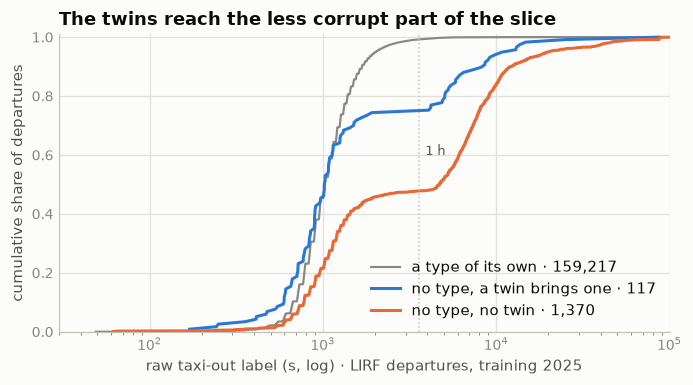

In [6]:
# the picture: the raw labels of Fiumicino's departures without a type, split by whether a twin brings one, beside its departures with a type
lab = con.sql(f"""
    SELECT CASE WHEN AIRCRAFT_TYPE_mvt IS NOT NULL THEN 'a type of its own' WHEN w.typ_twin IS NOT NULL THEN 'no type, a twin brings one'
                ELSE 'no type, no twin' END grp, TAXITIME_SEC_mvt y
    FROM {T} d LEFT JOIN {TWINSTY} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LIRF' AND TAXITIME_SEC_mvt >= 1""").df()
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for grp, color, lw in [("a type of its own", MUTED, 1.4), ("no type, a twin brings one", BLUE, 2), ("no type, no twin", ORANGE, 2)]:
    v = np.sort(lab.y[lab.grp == grp].to_numpy())
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=color, lw=lw, label=f"{grp} · {len(v):,}")
ax.set_xscale("log")
ax.axvline(3600, color=BASELINE, lw=1, ls=":")
ax.text(3900, 0.6, "1 h", fontsize=8.5, color=INK2)
ax.set_xlim(30, 1e5)
ax.set_ylim(0, 1.01)
ax.set_title("The twins reach the less corrupt part of the slice")
ax.set_xlabel("raw taxi-out label (s, log) · LIRF departures, training 2025")
ax.set_ylabel("cumulative share of departures")
ax.legend(loc="lower right")
style(ax, x_grid=True)
fig.tight_layout()
plt.show()

In [7]:
# what the plan's type buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 cascading rung by rung to the coarser key
# (§13's std_rungs): the plan's code, the movement's and §11a's plan-first form, each with ∅ a level, and the twins' type filled in. On the
# airport mean and on §13's base; then on raw labels, where the plan's ∅ is §2's missing plan and the plan-first ∅ is Fiumicino's type-less
# slice. The three numbers: all holdout rows · the rows without a plan · the rows without a type of their own
con.sql(f"""
    CREATE OR REPLACE TABLE tyf_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx,
           coalesce(AIRCRAFT_TYPE_mvt, '∅') tm, coalesce(AIRCRAFT_TYPE_flt, '∅') tp, coalesce(AIRCRAFT_TYPE_flt, typ_twin, '∅') tp_tw,
           coalesce({TYPE_FINAL}, '∅') tf, coalesce(AIRCRAFT_TYPE_flt, typ_twin, AIRCRAFT_TYPE_mvt, '∅') tf_tw,
           ADEP_flt IS NULL no_plan, AIRCRAFT_TYPE_mvt IS NULL typeless, AIRCRAFT_TYPE_mvt IS NULL AND typ_twin IS NOT NULL twin_typed,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM {T} LEFT JOIN {TWINSTY} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE tyf_t AS SELECT * FROM tyf_d WHERE y <= 3600")


def tyf_rungs(rungs, tbl="tyf_t", where="TRUE"):
    """§13's std_rungs on this section's tables: each rung's cell mean where it has ≥ 30 fit rows, else the rung before it.
    Returns (name, RMSE, RMSE on the rows without a plan, RMSE on the rows without a type of their own) per rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE tyf_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val AND {where} GROUP BY ALL")
        joins.append(f"LEFT JOIN tyf_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN tyf_s{i}.c >= 30 THEN tyf_s{i}.m END")
        pred = f"coalesce({', '.join(reversed(preds))}, g.m)"
        out.append((name, *con.sql(f"""
            SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (v.no_plan)), sqrt(avg((v.y - {pred})^2) FILTER (v.typeless))
            FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val AND {where}) g WHERE v.is_val AND {where}""").fetchone()))
    return out


def tyf_show(title, base, extras, tbl="tyf_t"):
    def f(v):
        return "      —" if v is None else f"{v:7.1f}"
    print(title)
    _, r, rn, rt = tyf_rungs(base, tbl)[-1]
    print(f"    {base[-1][0]:56s} {f(r)} · {f(rn)} · {f(rt)} s")
    for name, steps in extras:
        _, r, rn, rt = tyf_rungs(base + [(name, base[-1][1] + keys) for keys in steps], tbl)[-1]
        print(f"    {name:56s} {f(r)} · {f(rn)} · {f(rt)} s")


n1 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (typeless) FROM tyf_t WHERE is_val").fetchone()
tyf_show(f"(1) on the airport mean — {n1[0]:,} Nov+Dec departures 1–3,600 s, {n1[1]:,} without a plan, {n1[2]} without a type:", AP,
         [("+ the movement's code (§11)", [["tm"]]),
          ("+ the plan's code", [["tp"]]),
          ("+ the plan's code, twins filled", [["tp_tw"]]),
          ("+ plan first, else the movement's (§11a)", [["tf"]]),
          ("+ plan first, twins filled", [["tf_tw"]])])

con.sql("""
    CREATE OR REPLACE TABLE tyf_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM tyf_t WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT tyf_t.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
    FROM tyf_t JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")
n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan) FROM tyf_wb WHERE is_val").fetchone()
print()
tyf_show(f"(2) on §13's base — the {n2[0]:,} Nov+Dec departures with a runway, a stand and an anchor ({n2[1]} without a plan):", BASE,
         [("+ the movement's code, on top", [["tm"]]), ("+ the plan's code, on top", [["tp"]]), ("+ plan first, on top", [["tf"]])], tbl="tyf_wb")

n3 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (typeless), count(*) FILTER (twin_typed) FROM tyf_d WHERE is_val").fetchone()
print()
tyf_show(f"(3) raw labels, no ceiling (§14) — all {n3[0]:,} Nov+Dec departures, {n3[1]:,} without a plan, {n3[2]} without a type, "
         f"{n3[3]} of those typed by a twin: who owns each ∅?", AP,
         [("+ the missing-plan flag alone (§2)", [["no_plan"]]),
          ("+ the plan's code", [["tp"]]),
          ("+ the flag, then the plan's code", [["no_plan"], ["no_plan", "tp"]]),
          ("+ plan first (§11a)", [["tf"]]),
          ("+ the flag, then plan first", [["no_plan"], ["no_plan", "tf"]]),
          ("+ the flag, then plan first, twins filled", [["no_plan"], ["no_plan", "tf_tw"]]),
          ("+ the flag, 'no type', then 'a twin brings one'", [["no_plan"], ["no_plan", "typeless"], ["no_plan", "typeless", "twin_typed"]]),
          ("+ the flag, 'no type', then twins filled", [["no_plan"], ["no_plan", "typeless"], ["no_plan", "typeless", "tf_tw"]])], tbl="tyf_d")

(1) on the airport mean — 327,485 Nov+Dec departures 1–3,600 s, 2,854 without a plan, 51 without a type:
    airport (§5)                                               357.3 ·   538.6 ·   512.6 s
    + the movement's code (§11)                                338.0 ·   492.7 ·   501.9 s
    + the plan's code                                          338.2 ·   518.1 ·   504.2 s
    + the plan's code, twins filled                            338.3 ·   520.4 ·   503.7 s
    + plan first, else the movement's (§11a)                   337.9 ·   492.5 ·   501.9 s
    + plan first, twins filled                                 337.9 ·   492.5 ·   501.7 s



(2) on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor (0 without a plan):
    + stand (§13's base)                                       265.5 ·       — ·       — s


    + the movement's code, on top                              265.3 ·       — ·       — s


    + the plan's code, on top                                  265.3 ·       — ·       — s


    + plan first, on top                                       265.3 ·       — ·       — s

(3) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 144 without a type, 17 of those typed by a twin: who owns each ∅?
    airport (§5)                                               496.5 ·  3436.1 · 15320.3 s
    + the missing-plan flag alone (§2)                         475.0 ·  3098.8 · 13759.6 s
    + the plan's code                                          460.6 ·  3098.8 · 13759.6 s
    + the flag, then the plan's code                           460.6 ·  3098.8 · 13759.6 s
    + plan first (§11a)                                        460.1 ·  3091.1 · 13758.7 s
    + the flag, then plan first                                460.3 ·  3094.2 · 13759.2 s


    + the flag, then plan first, twins filled                  459.5 ·  3081.2 · 13698.8 s
    + the flag, 'no type', then 'a twin brings one'            474.0 ·  3082.3 · 13682.6 s
    + the flag, 'no type', then twins filled                   459.5 ·  3081.2 · 13698.9 s


In [8]:
# closing state — the column after §24: nothing of its own to repair (it is missing only where the plan is); §2's twin layers hand the
# departures they recover the whole plan block, this code with it — and with it a type for departures that have none on either side
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL) null_before, count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL AND typ_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin) IS NULL) null_after,
           round(100.0*count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin) IS NULL)/count(*), 2) pct_null_after,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin) IS NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL) movement_has_one,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin, AIRCRAFT_TYPE_mvt) IS NULL AND typ_imp IS NOT NULL) low_confidence_history_only,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin, AIRCRAFT_TYPE_mvt, typ_imp) IS NULL) no_type_anywhere,
           count(*) FILTER ({TYPE_FINAL} IS NULL) plan_first_null_before,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_flt, typ_twin, AIRCRAFT_TYPE_mvt) IS NULL) plan_first_null_twins_filled
    FROM {BOTH} d LEFT JOIN {TWINSTY} w USING (MVT_ID_mvt) LEFT JOIN {IMPTY} i USING (MVT_ID_mvt)
    WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
assert (st.movement_has_one + st.low_confidence_history_only + st.no_type_anywhere == st.null_after).all()
print("twin rows whose recovered plan carries no type:", con.sql(f"SELECT count(*) FROM {TWINSTY} WHERE typ_twin IS NULL").fetchone()[0])

print("\nthe codes a twin brings to departures with no type on either side:")
print(con.sql(f"""
    SELECT src, sum(n) n, string_agg(DISTINCT hub, ' ' ORDER BY hub) hubs, string_agg(typ_twin || ' ' || n, ', ' ORDER BY n DESC, typ_twin) codes
    FROM (SELECT src, ADEP_mvt hub, typ_twin, count(*) n FROM {BOTH} JOIN {TWINSTY} USING (MVT_ID_mvt)
          WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NULL GROUP BY 1, 2, 3)
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe final levels, departures — the plan's code with the twins filled in: the null level and the six biggest codes (taxi: training, 1–3600 s):")
fin = con.sql(f"""
    WITH d AS (SELECT src, coalesce(AIRCRAFT_TYPE_flt, typ_twin, '∅') aircraft_type, TAXITIME_SEC_mvt y
               FROM {BOTH} LEFT JOIN {TWINSTY} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP'),
         g AS (SELECT aircraft_type, count(*) FILTER (src = 'training') training,
                      round(100.0*count(*) FILTER (src = 'training')/sum(count(*) FILTER (src = 'training')) OVER (), 2) pct_training,
                      count(*) FILTER (src = 'ranking') ranking, round(quantile_cont(y, 0.5) FILTER (src = 'training' AND y BETWEEN 1 AND 3600)) med_taxi
               FROM d GROUP BY 1)
    SELECT *, (SELECT count(*) FROM g WHERE aircraft_type != '∅' AND training > 0) levels_training,
              (SELECT count(*) FROM g WHERE aircraft_type != '∅' AND ranking > 0) levels_ranking
    FROM g QUALIFY aircraft_type = '∅' OR row_number() OVER (ORDER BY (aircraft_type = '∅'), training DESC, aircraft_type) <= 6
    ORDER BY training DESC, aircraft_type""").df()
print(fin.to_string(index=False))

     src       n  null_before  filled_by_twins  null_after  pct_null_after  movement_has_one  low_confidence_history_only  no_type_anywhere  plan_first_null_before  plan_first_null_twins_filled
training 2085047        22470             1898       20572            0.99             19182                          614               776                    1507                          1390
 ranking  344841         5290              479        4811            1.40              4466                          179               166                     388                           345
twin rows whose recovered plan carries no type: 1

the codes a twin brings to departures with no type on either side:
     src     n hubs                                                                                                            codes
training 117.0 LIRF               B738 36, A320 22, A21N 18, A20N 14, A321 7, A319 6, A333 3, A359 3, B38M 3, BCS3 3, A332 1, B744 1
 ranking  43.0 LIRF B738 11, A21N 

aircraft_type  training  pct_training  ranking  med_taxi  levels_training  levels_ranking
         A320    340622         16.34    52489     844.0              239             180
         B738    216533         10.39    32865     942.0              239             180
         A20N    168925          8.10    30054     948.0              239             180
         A321    160952          7.72    24039     843.0              239             180
         A21N    148242          7.11    31597    1000.0              239             180
         A319    133905          6.42    18771     849.0              239             180
            ∅     20572          0.99     4811     912.0              239             180


                                       feature        kind  n / levels  pearson_r  spearman_ρ     η
AIRCRAFT_TYPE_flt — the plan's code, ∅ a level categorical         142                        0.353
      the plan's code, twins filled (§2b, §2c) categorical         142                        0.353
      its null level alone — §2's missing plan categorical           2                        0.007
                     the movement's code (§11) categorical         150                        0.359
        plan first, else the movement's (§11a) categorical         149                        0.359
                      plan first, twins filled categorical         149                        0.359


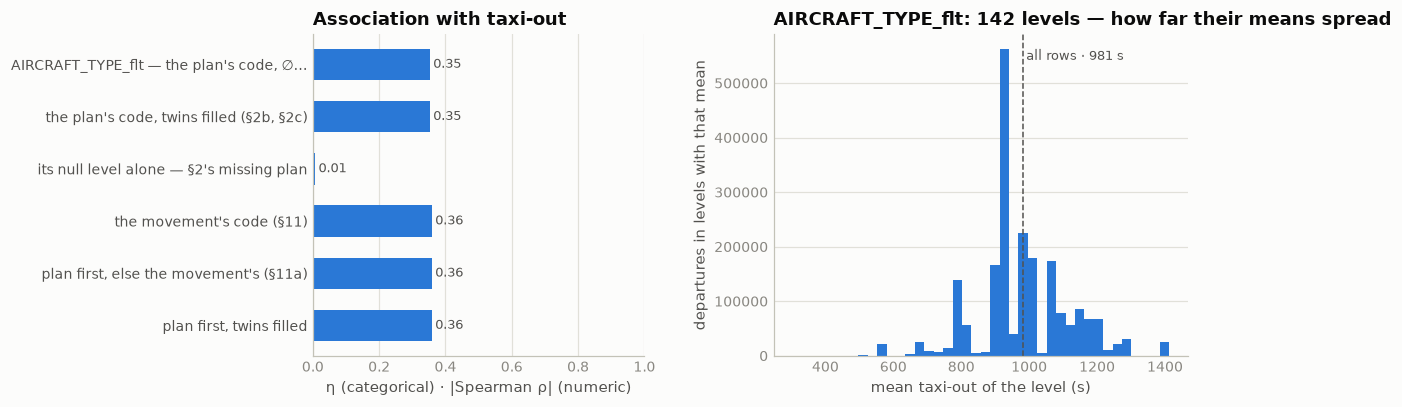

In [9]:
# correlation with the target: the plan's code (its null a level), the same with the twins filled in, the null level alone — §2's missing
# plan, nothing else — and the two forms §11 and §11a settled, the movement's code and the plan first, the last with the twins filled in too
TWSRC = f"({TGT[1:-1]}) d LEFT JOIN {TWINSTY} w USING (MVT_ID_mvt)"
a = target_assoc([
    ("AIRCRAFT_TYPE_flt — the plan's code, ∅ a level", "cat", "AIRCRAFT_TYPE_flt", 30),
    ("the plan's code, twins filled (§2b, §2c)", "cat", "coalesce(AIRCRAFT_TYPE_flt, typ_twin)", 30, TWSRC),
    ("its null level alone — §2's missing plan", "cat", "AIRCRAFT_TYPE_flt IS NULL"),
    ("the movement's code (§11)", "cat", "AIRCRAFT_TYPE_mvt", 30),
    ("plan first, else the movement's (§11a)", "cat", TYPE_FINAL, 30),
    ("plan first, twins filled", "cat", "coalesce(AIRCRAFT_TYPE_flt, typ_twin, AIRCRAFT_TYPE_mvt)", 30, TWSRC),
])
assoc_chart(a, "AIRCRAFT_TYPE_flt", min_support=30, title="AIRCRAFT_TYPE_flt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Missing exactly where the plan is missing, every code well-formed** | null on 22,470 training and 5,290 ranking departures and on 15,449 and 2,552 arrivals, each exactly the rows without a plan: 0 plans lack a type, 0 types lack a plan. Every code on both sides is a letter and one to three letters or digits. §22's 167 plans with no rule and no wake class all carry a type (74 + 67 training, 14 + 12 ranking) | the null level *is* §2's missing-plan flag. §25 fills the departures among those 167 from the type's class, 73 of 74 training and 14 of 14 ranking |
| **The plan's vocabulary is the half of the movement's that files plans** | 239 codes on training departures against 269, ranking 180 against 199. Codes only the movement uses: 42 codes on 1,360 rows, 1,292 without a plan, 1,236 VFR, 641 rotorcraft (`C172` 482, `AS50` 341, `SLG2` 129, `EC20` 86, `EC30` 64). Codes only the plan uses: 11 codes on 29 rows. Most are finer or different spellings (`P212`/`PL2` 8, `A743`/`AN72` 5 at LTFM, `B58T`/`BE58` 4, `AS3B` and `EC25`/`AS32` 2 each). Four are one-row mismatches that look like filing slips: `A10` for an `A320`, `A358` for an `A359`, `B732` for a `B77W`, `F70` for a `BCS3` | the aircraft the plan lacks are the ones that file none, which is why `TYPE_FINAL` falls back to the movement's code. Where only the plan names a code it is a finer spelling or a slip, and neither is worth a rule |
| **The plan names what the movement leaves as `ZZZZ`** | 28 training and 3 ranking departures are `ZZZZ` in the movement. The plan names 27 and 3 of them: `BE20` 15, `GL7T` 5, `SW4` 3, `B350` 2, and five Learjets (`LJ35`–`LJ60`). The plan's own `ZZZZ` is 1 departure, and the movement names it | §11 kept `ZZZZ` as a level of its own. Under `TYPE_FINAL` it is a single departure, with business jets and turboprops given a real type and no rule needed |
| 2026's new codes are the few §11 found | 9 ranking departures on 6 plan codes no 2025 row carries (`A358 B462 EVOT IL62 P212 PA44`), 18 under the movement's code and under the plan-first form | a handful of rows that fall back to the airport |
| **The twins' type is the movement's, every time** | departures where both exist: exact twins 775 + 183, relaxed A 526 + 102, B 217 + 50, C 263 + 101 agree and **0 differ**, so 1,781 training and 436 ranking at 100.00%. Plans matched the ordinary way: 99.66% (7,013 differ) and 99.82% (612). One recovered plan carries no type | a check of §2b/§2c that no earlier section could run: **§2's recovery names the right aircraft on all 2,217 rows where this referee can check it**, and none of §11a's per-hub spellings turn up among them |
| **§2c's history is no referee for the type** | its first step is a lookup keyed on the row's own movement type (§2c's policy), so its 18,308 + 4,299 values agree 99.99% and 100.00% by construction. The second step, flight number × airport, is flagged low confidence. It is the only step that reaches departures without a movement type (614 + 179), and where it can be checked it agrees on 21 of 28 and 2 of 8. All 13 disagreements are ATR spellings: 11 `AT76` for the movement's `AT72`, which is §11a's Paris convention, plus one `AT43` and one `AT45` | the history adds a type only where the movement has none, and there only at low confidence. Whether it reaches a row says more than the value it brings (next row) |
| **What reaches Fiumicino's type-less slice sorts it by corruption** | raw labels: LIRF departures with a type have a median of 1,024 s, 0.8% over an hour, 0.0% over 2 h, 1.7% taking off ≥ 2 h after schedule. Without a type: **a twin reaches** 117 (1,022 s, 25.6%, 12.0%, 30.8% late); only the low-confidence history 614 (2,367 s, 49.0%, 27.7%, 41.7%); **nothing** 776 (4,799 s, 53.6%, 33.0%, 43.6%). Ranking: 43, 179 and 166 | the rows a twin reaches carry an ordinary Fiumicino median, though a quarter still run over an hour. The rows nothing reaches are the corrupt core of 10a's slice. This is §23's "no layer reaches the row" signal on the slice where it is strongest, and it belongs to §2c |
| **Alone, the plan's code is worth what the movement's is, a little less where there is no plan** | honest ladders, 327,485 Nov+Dec departures 1–3,600 s: airport 357.3 → the movement's code 338.0, the plan's code **338.2**, the plan's code twins filled 338.3, plan first 337.9, plan first twins filled 337.9. On the 2,854 plan-less rows: 492.7, 518.1, 520.4, 492.5, 492.5. On §13's base (324,629 departures): 265.5 → 265.3 with any of the three | the plan's ∅ pools each hub's plan-less departures into one level, which the movement's code splits by aircraft. That costs 25 s on those rows and 0.2 s overall. Filling the plan's code from the twins moves §2's delayed matching failures out of ∅ into ordinary type levels and costs another 2.3 s there, because ∅ was carrying their delay. Once the stand is known the type is worth 0.2 s whatever its spelling |
| §11's 338.5 for the plan's code scored plan-less rows at the airport mean | §11's ladder joined on a NULL key, which never matches, so its "missing = own level" fell back to the airport. With ∅ a real level the same form scores 338.2 | the conclusion stands (the plan's code alone is no better than the movement's); only the number moves. §11's cell is left as written |
| **On raw labels the plan's ∅ is §2's flag, and the twins' type sharpens the plan-first form** | 327,968 Nov+Dec departures, no ceiling: airport 496.5 → the flag 475.0 → the plan's code 460.6, and the flag then the code 460.6, with the plan-less rows at 3,098.8 both ways. Plan first 460.1; the flag then plan first 460.3; **with the twins' type 459.5**, the 144 rows without a type 13,759.2 → 13,698.8 (17 of them typed by a twin). A "no type of its own" rung before the filled type: 459.5 again. The flags with "a twin brings one" in place of the type: 13,682.6 on the type-less rows | the type is worth 14.4 s over the flag on raw labels. Filling it from the twins takes the reached rows out of ∅ and leaves ∅ to the rows no twin reaches, 0.8 s overall. The fill loses no marker: once the flag and the filled type are in, "no type" adds 0.0 |
| Marginal | η: the plan's code 0.353 (142 levels with ≥ 30 rows), twins filled 0.353, the null level alone 0.007; the movement's code 0.359 (150), plan first 0.359 (149), twins filled 0.359 | the plan's code reads the target like the movement's code, less the plan-less rows it pools |

**Decisions**

| issue | decision | why |
|---|---|---|
| the column as a feature | **no feature of its own**. The type is read in §11a's plan-first form. In the closing matrix the plan's code enters with the twins filled in and its nulls as a level, as in §22 and §23 | 338.2 against 337.9 on the airport mean, 265.3 for every form on §13's base. Alone, the plan's code only adds a coarser copy of §2's flag |
| the twins' type in the plan-first form | **adopted for the pipeline**: `coalesce(AIRCRAFT_TYPE_flt, the twins' AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt)`. §11a's `TYPE_FINAL` is left as defined, since §23 and the closing matrix read it | it is right on all 2,217 rows where it can be checked, it changes only the 117 + 43 departures with no type on either side, and it is worth 0.8 s on raw labels (460.3 → 459.5) and 0.0 s on 1–3,600 s |
| a "type missing" flag beside the filled type | not adopted | the rung adds 0.0 s once §2's flag and the filled type are in |
| §2c's history fill of the type | **not adopted** | the high-confidence step copies the movement's type, and the low-confidence step is right on 21 of 28 rows where it can be checked (2 of 8 in ranking). Whether any layer reaches a row is §2c's signal, already on the map's open list (§23) |
| `ZZZZ`, the plan-only codes, 2026's new codes | nothing to do | `TYPE_FINAL` resolves 30 of the 31 `ZZZZ` departures, and the rest are a few dozen rows that fall back to the airport |
| §11's 338.5 | corrected here; §11's cell unchanged | a NULL key never joins, so "missing = own level" there meant the airport mean |

**State after §24** (departures):

| `AIRCRAFT_TYPE_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| of those left, the movement has a type | 19,182 | 4,466 |
| no type on either side, low-confidence history only (not applied) | 614 | 179 |
| no type anywhere | 776 | 166 |
| the plan-first form with the twins' type (the pipeline's): null | 1,507 → 1,390 (117 from the twins, all LIRF) | 388 → 345 (43, all LIRF) |

| final level | training | ranking | median DEP taxi, 1–3600 s |
|---|---:|---:|---:|
| `A320` | 340,622 | 52,489 | 844 s |
| `B738` | 216,533 | 32,865 | 942 s |
| `A20N` | 168,925 | 30,054 | 948 s |
| `A321` | 160,952 | 24,039 | 843 s |
| `A21N` | 148,242 | 31,597 | 1,000 s |
| `A319` | 133,905 | 18,771 | 849 s |
| ∅ | 20,572 | 4,811 | 912 s |
| levels | 239 | 180 | |

**Use in modeling.** Nothing new to feed. The plan's code is §11's type in the operator's spelling, and
§11a has already made it the first choice in `TYPE_FINAL`. Alone, it pools the plan-less departures into a
∅ level that §2's flag already provides, and on §13's base every spelling of the type is worth 0.2 s. One
change goes to the pipeline. Build the type as `coalesce(AIRCRAFT_TYPE_flt, the twins' AIRCRAFT_TYPE_flt,
AIRCRAFT_TYPE_mvt)` with ∅ as a level. The twins' code matches the movement's on every row where both
exist, it gives 117 training and 43 ranking departures at Fiumicino a type, and it leaves ∅ to the rows no
twin reaches. The column's real contribution is a referee. **§2's recovered plan blocks name the right
aircraft on all 2,217 rows where this can be checked**, and whether any layer reaches a type-less departure
separates Fiumicino's ordinary labels from its corrupt ones, which goes back to §2c. The closing matrix
reads the twin layers' type as `TWINSTY` and enters the plan's code with those 1,898 + 479 filled in and
its nulls kept as a level.

## 25 · `WK_TBL_CAT_flt` — the wake-turbulence class the plan was filed with

The aircraft's ICAO wake-turbulence category as the plan files it: `L` light, `M` medium, `H` heavy, `J` super. It sets
how far apart aircraft must be behind one another, so a medium aircraft taking off behind a heavy waits for the vortex to
clear. It is a property of the aircraft, and §11 already built a lookup from the movement's type (`typ_wake`) that fills
the classes the plan lacks. Three questions are left. **Does the class carry anything the type does not?** **What fills
it, and what is left?** And the one use a type cannot have: **does the class of the departure ahead on the runway
lengthen the taxi?**

| step | question | what came out |
|---|---|---|
| **census** | where it is missing; the four levels | missing where the plan is missing, plus §22's 167 plans that lack the rule too (74 + 14 departures), all of them typed, none before 13 March 2025. Departures: M 77.54%, H 20.19%, J 0.71% (only ever the `A388`), L 0.49% |
| **the class is the type's** | one class per type? does every source agree with the class its type implies? | 247 plan type codes, 33 of 4,811,403 plan rows off their type's class (99.9993%). Keyed on the plan's own code 14 + 2 departures differ; keyed on the movement's code, as §11's lookup is, 304 + 34, 210 of them one Paris pair. Every twin layer's class is its type's |
| **signal** | the class alone, beside the type, as the type's coarser rung; the class of the departure ahead | 357.3 → 347.5 alone, 337.9 for the type, 337.8 with the class as the type's coarser rung. 265.5 → 265.3 on §13's base, the same as the type. Medium departures behind a heavy take 18–101 s longer in plain means, but the class ahead is worth 0.1 s on §13's base |
| **raw labels** | who owns the ∅ | §2's flag (475.0); after it the filled class 465.9 against the type's 459.5, and nothing after the type. §2c's history adds 7.5 s, 5.7 s of it from whether it reaches the row at all |
| **closing state** | what the twins and the type fill | 22,544 → 1,938 training and 5,304 → 451 ranking departures. Left: Fiumicino's departures without a type, and light aircraft and helicopters no plan gives a class |


In [4]:
# census by file × phase: where the plan's wake class is missing (where the plan is missing, §17's ADEP_flt IS NULL, plus §22's plans that
# lack the rule too), its four levels, and who files a plan without one
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
display(cat_stats("WK_TBL_CAT_flt"))

print("by file × phase — the presence rule and the four levels (L light, M medium, H heavy, J super):")
cen = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (WK_TBL_CAT_flt IS NULL) n_null, count(*) FILTER (ADEP_flt IS NULL) plan_missing,
           count(*) FILTER (ADEP_flt IS NOT NULL AND WK_TBL_CAT_flt IS NULL) plan_but_no_class,
           count(*) FILTER (ADEP_flt IS NULL AND WK_TBL_CAT_flt IS NOT NULL) class_but_no_plan,
           count(*) FILTER (ADEP_flt IS NOT NULL AND WK_TBL_CAT_flt IS NULL AND FLIGHT_RULE_flt IS NULL) of_which_no_rule,
           count(*) FILTER (ADEP_flt IS NOT NULL AND WK_TBL_CAT_flt IS NULL AND AIRCRAFT_TYPE_flt IS NOT NULL) of_which_typed,
           count(*) FILTER (WK_TBL_CAT_flt = 'L') "L", count(*) FILTER (WK_TBL_CAT_flt = 'M') "M",
           count(*) FILTER (WK_TBL_CAT_flt = 'H') "H", count(*) FILTER (WK_TBL_CAT_flt = 'J') "J",
           count(*) FILTER (WK_TBL_CAT_flt NOT IN ('L', 'M', 'H', 'J')) other
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(cen.to_string(index=False))
assert (cen.class_but_no_plan == 0).all() and (cen.other == 0).all()
assert (cen.plan_but_no_class == cen.of_which_no_rule).all() and (cen.plan_but_no_class == cen.of_which_typed).all()

print("\ndepartures per level, and how many of the plan's type codes file it:")
print(con.sql(f"""
    SELECT src, coalesce(WK_TBL_CAT_flt, '∅') wake, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (PARTITION BY src), 2) pct,
           count(DISTINCT AIRCRAFT_TYPE_flt) type_codes
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

print("\n§22's plans without a class (both files, both phases): what they fly, and since when — none before March 2025:")
print(con.sql(f"""
    WITH p AS (SELECT * FROM {BOTH} WHERE ADEP_flt IS NOT NULL AND WK_TBL_CAT_flt IS NULL),
         m AS (SELECT strftime(MVT_TIME_UTC_mvt, '%Y-%m') mon, count(*) n FROM p GROUP BY 1),
         ty AS (SELECT AIRCRAFT_TYPE_flt k, count(*) n FROM p GROUP BY 1 ORDER BY n DESC, k LIMIT 8)
    SELECT count(*) n, count(DISTINCT AIRCRAFT_TYPE_flt) type_codes, strftime(min(MVT_TIME_UTC_mvt), '%Y-%m-%d') first_seen,
           (SELECT string_agg(k || ' ' || n, ', ' ORDER BY n DESC, k) FROM ty) biggest_types,
           (SELECT string_agg(mon || ' ' || n, ', ' ORDER BY mon) FROM m) per_month
    FROM p""").df().T.to_string(header=False))


,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,38060,0.91,4
ranking 2026,689534,7868,1.14,4


by file × phase — the presence rule and the four levels (L light, M medium, H heavy, J super):
     src  ph       n  n_null  plan_missing  plan_but_no_class  class_but_no_plan  of_which_no_rule  of_which_typed     L       M      H     J  other
training ARR 2082750   15516         15449                 67                  0                67              67 10059 1625366 417127 14682      0
training DEP 2085047   22544         22470                 74                  0                74              74 10204 1616701 420886 14712      0
 ranking ARR  344693    2564          2552                 12                  0                12              12  1607  265952  72166  2404      0
 ranking DEP  344841    5304          5290                 14                  0                14              14  1662  263335  72150  2390      0

departures per level, and how many of the plan's type codes file it:
     src wake       n   pct  type_codes
training    M 1616701 77.54         130
training  

In [5]:
# the class is a property of the aircraft: one class per plan type code, learned from every plan row of both files (no label is read, so
# the ranking file's plans may teach it; ties go to the heavier class). `wake_lk` supersedes §11's `typ_wake`, which keyed the movement's
# code on 2025 departures. Then every source of a class — the matched plan, §2's twin layers, §2c's history — against the class its type implies
TWINSWK = (f"(SELECT MVT_ID_mvt, WK_TBL_CAT_flt wk_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
           f"UNION ALL SELECT MVT_ID_mvt, WK_TBL_CAT_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
IMPWK = f"(SELECT MVT_ID_mvt, WK_TBL_CAT_flt wk_imp FROM read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet'))"
con.sql(f"""
    CREATE OR REPLACE TABLE wake_lk AS
    WITH c AS (SELECT AIRCRAFT_TYPE_flt typ, WK_TBL_CAT_flt wk, count(*) n FROM {BOTH}
               WHERE AIRCRAFT_TYPE_flt IS NOT NULL AND WK_TBL_CAT_flt IS NOT NULL GROUP BY 1, 2)
    SELECT typ, arg_max(wk, n*10 + position(wk IN 'LMHJ')) wake_from_type, sum(n) n, max(n) n_mode, count(*) n_classes,
           string_agg(wk || ' ' || n, ', ' ORDER BY n DESC, wk) classes
    FROM c GROUP BY 1""")
print("one class per type? — every plan row of both files that carries both:")
print(con.sql("""
    SELECT count(*) type_codes, count(*) FILTER (n_classes > 1) with_a_second_class, sum(n)::BIGINT plan_rows, sum(n - n_mode)::BIGINT rows_off_the_mode,
           round(100.0*sum(n_mode)/sum(n), 4) pct_on_the_mode FROM wake_lk""").df().to_string(index=False))
print(con.sql("SELECT typ, classes FROM wake_lk WHERE n_classes > 1 ORDER BY n DESC, typ").df().to_string(index=False))
print("\nthe type codes in each class, and the biggest (plan rows, both files, both phases):")
print(con.sql("""
    SELECT wake_from_type wake, count(*) type_codes, sum(n)::BIGINT plan_rows,
           string_agg(typ || ' ' || n, ', ' ORDER BY n DESC, typ) FILTER (rk <= 8) biggest
    FROM (SELECT *, row_number() OVER (PARTITION BY wake_from_type ORDER BY n DESC, typ) rk FROM wake_lk)
    GROUP BY 1 ORDER BY position(wake IN 'LMHJ')""").df().to_string(index=False))

print("\neach source of a class against the class its type implies — its own type code, and the movement's (§11) — departures:")
ref = con.sql(f"""
    WITH s AS (SELECT src, '1 plan matched (§2)' origin, WK_TBL_CAT_flt wk, AIRCRAFT_TYPE_flt typ, AIRCRAFT_TYPE_mvt mvt
               FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADEP_flt IS NOT NULL
               UNION ALL SELECT src, '2 ' || layer, wk_twin, typ_twin, AIRCRAFT_TYPE_mvt
               FROM {BOTH} JOIN {TWINSTY} USING (MVT_ID_mvt) JOIN {TWINSWK} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP'
               UNION ALL SELECT src, '3 §2c history', wk_imp, NULL, AIRCRAFT_TYPE_mvt
               FROM {BOTH} JOIN {IMPWK} USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' AND wk_imp IS NOT NULL)
    SELECT src, origin, count(*) n, count(*) FILTER (wk IS NULL) no_class,
           count(*) FILTER (wk = lp.wake_from_type) agree_own_type, count(*) FILTER (wk != lp.wake_from_type) differ_own_type,
           count(*) FILTER (mvt IS NULL) movement_untyped,
           count(*) FILTER (wk = lm.wake_from_type) agree_movement_type, count(*) FILTER (wk != lm.wake_from_type) differ_movement_type,
           round(100.0*count(*) FILTER (wk = lm.wake_from_type)/nullif(count(*) FILTER (wk IS NOT NULL AND lm.wake_from_type IS NOT NULL), 0), 2) pct_agree_movement
    FROM s LEFT JOIN wake_lk lp ON lp.typ = s.typ LEFT JOIN wake_lk lm ON lm.typ = s.mvt
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print(ref.to_string(index=False))

print("\nwhere the movement's type implies another class than the plan files — the biggest pairs, movement → plan (departures, both files):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt || '→' || AIRCRAFT_TYPE_flt type_codes, lm.wake_from_type || '→' || WK_TBL_CAT_flt classes, count(*) n,
           string_agg(DISTINCT ADEP_mvt, ' ' ORDER BY ADEP_mvt) hubs
    FROM {BOTH} d JOIN wake_lk lm ON lm.typ = d.AIRCRAFT_TYPE_mvt
    WHERE PHASE_mvt = 'DEP' AND WK_TBL_CAT_flt != lm.wake_from_type GROUP BY 1, 2 ORDER BY n DESC, 1 LIMIT 8""").df().to_string(index=False))


one class per type? — every plan row of both files that carries both:
 type_codes  with_a_second_class  plan_rows  rows_off_the_mode  pct_on_the_mode
        247                    9    4811403                 33          99.9993
 typ       classes
B738 M 500201, H 1
B789 H 144185, M 1
B38M M 108205, H 1
A332  H 72278, M 1
C25C   M 1739, L 1
BE20    L 515, M 1
B350   L 305, M 23
 SW4    M 114, L 3
ZZZZ     M 14, H 1

the type codes in each class, and the biggest (plan rows, both files, both phases):
wake  type_codes  plan_rows                                                                                                biggest
   L          81      23552                  C25A 4447, PC12 4304, C510 2351, C25B 2012, C525 1676, C25M 1604, C55B 1286, PRM1 695
   M         130    3771335 A320 787844, B738 500202, A20N 398745, A321 370051, A21N 360233, A319 306038, BCS3 185856, E190 179092
   H          35     982328     B77W 154530, B789 144186, A359 131968, A333 108577, A332 72279, B772 7

     src                 origin       n  no_class  agree_own_type  differ_own_type  movement_untyped  agree_movement_type  differ_movement_type  pct_agree_movement
training    1 plan matched (§2) 2062577        74         2062489               14                 0              2062173                   304               99.99
training     2 exact twin (§2b)     892         0             892                0               117                  775                     0              100.00
training 2 relaxed twin A (§2c)     527         1             526                0                 0                  526                     0              100.00
training 2 relaxed twin B (§2c)     217         0             217                0                 0                  217                     0              100.00
training 2 relaxed twin C (§2c)     263         0             263                0                 0                  263                     0              100.00
training        

In [6]:
# what the class buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 cascading rung by rung (§13's std_rungs): the plan's
# class with ∅ a level; the class filled (the twins' class, then wake_lk on §24's type recipe); §24's type; the class as the type's coarser
# rung; and the one thing a class says that a type cannot, separation behind a heavy — the class of the departure that took off last from
# the same runway, if within 5 minutes (training departures, every label). The three numbers: all holdout rows · the rows without a plan ·
# medium departures with a heavy or super ahead
WK_TYPE = "coalesce(d.AIRCRAFT_TYPE_flt, t.typ_twin, d.AIRCRAFT_TYPE_mvt)"
con.sql(f"""
    CREATE OR REPLACE TABLE wk_d AS
    WITH dep AS (SELECT d.*, coalesce(d.WK_TBL_CAT_flt, w.wk_twin, lk.wake_from_type) wf, {WK_TYPE} tf_tw, i.wk_imp
                 FROM {T} d LEFT JOIN {TWINSTY} t USING (MVT_ID_mvt) LEFT JOIN {TWINSWK} w USING (MVT_ID_mvt)
                 LEFT JOIN {IMPWK} i USING (MVT_ID_mvt) LEFT JOIN wake_lk lk ON lk.typ = {WK_TYPE} WHERE d.PHASE_mvt = 'DEP'),
         q AS (SELECT *, lag(coalesce(wf, '∅')) OVER w ahead_wk, epoch(MVT_TIME_UTC_mvt - lag(MVT_TIME_UTC_mvt) OVER w) ahead_gap
               FROM dep WINDOW w AS (PARTITION BY ADEP_mvt, RUNWAY_mvt ORDER BY MVT_TIME_UTC_mvt, MVT_ID_mvt))
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx,
           coalesce(WK_TBL_CAT_flt, '∅') wp, coalesce(wf, '∅') wf, coalesce(wf, wk_imp, '∅') wf_h, wf IS NULL AND wk_imp IS NOT NULL hist_only, coalesce(tf_tw, '∅') tf_tw,
           CASE WHEN RUNWAY_mvt IS NULL THEN '(no runway)' WHEN ahead_gap <= 300 THEN ahead_wk ELSE 'none' END ahead,
           coalesce(RUNWAY_mvt IS NOT NULL AND ahead_gap <= 300 AND ahead_wk IN ('H', 'J'), FALSE) heavy_ahead,
           ADEP_flt IS NULL no_plan, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM q WHERE TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE wk_t AS SELECT * FROM wk_d WHERE y <= 3600")


def wk_rungs(rungs, tbl="wk_t", where="TRUE"):
    """§13's std_rungs on this section's tables: each rung's cell mean where it has ≥ 30 fit rows, else the rung before it.
    Returns (name, RMSE, RMSE on the rows without a plan, RMSE on medium departures with a heavy ahead) per rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE wk_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val AND {where} GROUP BY ALL")
        joins.append(f"LEFT JOIN wk_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN wk_s{i}.c >= 30 THEN wk_s{i}.m END")
        pred = f"coalesce({', '.join(reversed(preds))}, g.m)"
        out.append((name, *con.sql(f"""
            SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (v.no_plan)),
                   sqrt(avg((v.y - {pred})^2) FILTER (v.wf = 'M' AND v.heavy_ahead))
            FROM {tbl} v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM {tbl} WHERE NOT is_val AND {where}) g WHERE v.is_val AND {where}""").fetchone()))
    return out


def wk_show(title, base, extras, tbl="wk_t"):
    def f(v):
        return "      —" if v is None else f"{v:7.1f}"
    print(title)
    _, r, rn, rh = wk_rungs(base, tbl)[-1]
    print(f"    {base[-1][0]:56s} {f(r)} · {f(rn)} · {f(rh)} s")
    for name, steps in extras:
        _, r, rn, rh = wk_rungs(base + [(name, base[-1][1] + keys) for keys in steps], tbl)[-1]
        print(f"    {name:56s} {f(r)} · {f(rn)} · {f(rh)} s")


n1 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (wf = 'M' AND heavy_ahead) FROM wk_t WHERE is_val").fetchone()
wk_show(f"(1) on the airport mean — {n1[0]:,} Nov+Dec departures 1–3,600 s, {n1[1]:,} without a plan, {n1[2]:,} medium with a heavy ahead:", AP,
        [("+ the plan's class, ∅ a level", [["wp"]]),
         ("+ the class filled (twins, then the type's class)", [["wf"]]),
         ("+ the missing-plan flag alone (§2)", [["no_plan"]]),
         ("+ the aircraft type (§24's recipe)", [["tf_tw"]]),
         ("+ the filled class, then the type", [["wf"], ["wf", "tf_tw"]]),
         ("+ the type, then the filled class", [["tf_tw"], ["tf_tw", "wf"]]),
         ("+ a heavy or super ahead", [["heavy_ahead"]]),
         ("+ the class ahead", [["ahead"]]),
         ("+ the filled class, then × the class ahead", [["wf"], ["wf", "ahead"]])])

con.sql("""
    CREATE OR REPLACE TABLE wk_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                  FROM wk_t WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT wk_t.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
    FROM wk_t JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")
n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (wf = 'M' AND heavy_ahead) FROM wk_wb WHERE is_val").fetchone()
print()
wk_show(f"(2) on §13's base — the {n2[0]:,} Nov+Dec departures with a runway, a stand and an anchor ({n2[1]} without a plan, {n2[2]:,} medium with a heavy ahead):", BASE,
        [("+ the filled class, on top", [["wf"]]),
         ("+ the type, on top", [["tf_tw"]]),
         ("+ the filled class, then the type, on top", [["wf"], ["wf", "tf_tw"]]),
         ("+ a heavy or super ahead, on top", [["heavy_ahead"]]),
         ("+ the class ahead, on top", [["ahead"]]),
         ("+ the filled class, then × the class ahead, on top", [["wf"], ["wf", "ahead"]])], tbl="wk_wb")

n3 = con.sql("SELECT count(*), count(*) FILTER (no_plan) FROM wk_d WHERE is_val").fetchone()
print()
wk_show(f"(3) raw labels, no ceiling (§14) — all {n3[0]:,} Nov+Dec departures, {n3[1]:,} without a plan: who owns the ∅?", AP,
        [("+ the missing-plan flag alone (§2)", [["no_plan"]]),
         ("+ the plan's class", [["wp"]]),
         ("+ the filled class", [["wf"]]),
         ("+ the flag, then the plan's class", [["no_plan"], ["no_plan", "wp"]]),
         ("+ the flag, then the filled class", [["no_plan"], ["no_plan", "wf"]]),
         ("+ the flag, then filled with §2c's history too", [["no_plan"], ["no_plan", "wf_h"]]),
         ("+ the flag, the filled class, then 'only the history reaches it'", [["no_plan"], ["no_plan", "wf"], ["no_plan", "wf", "hist_only"]]),
         ("+ the flag, then the type (§24)", [["no_plan"], ["no_plan", "tf_tw"]]),
         ("+ the flag, the type, then the filled class", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "wf"]])], tbl="wk_d")

print("\nbehind a heavy, in plain means — departures 1–3,600 s with another departure ahead on the runway within 5 minutes, per hub and own class:")
print(con.sql("""
    SELECT hub, wf own_class, count(*) FILTER (ahead IN ('H', 'J')) n_heavy_ahead, round(avg(y) FILTER (ahead IN ('H', 'J'))) mean_heavy_ahead,
           count(*) FILTER (ahead IN ('L', 'M')) n_light_medium_ahead, round(avg(y) FILTER (ahead IN ('L', 'M'))) mean_light_medium_ahead,
           round(avg(y) FILTER (ahead IN ('H', 'J')) - avg(y) FILTER (ahead IN ('L', 'M'))) diff
    FROM wk_t WHERE wf IN ('M', 'H') GROUP BY 1, 2 ORDER BY 2 DESC, 1""").df().to_string(index=False))


(1) on the airport mean — 327,485 Nov+Dec departures 1–3,600 s, 2,854 without a plan, 33,176 medium with a heavy ahead:
    airport (§5)                                               357.3 ·   538.6 ·   340.3 s
    + the plan's class, ∅ a level                              347.5 ·   518.4 ·   344.7 s
    + the class filled (twins, then the type's class)          347.3 ·   503.6 ·   344.8 s
    + the missing-plan flag alone (§2)                         357.1 ·   518.1 ·   340.3 s
    + the aircraft type (§24's recipe)                         337.9 ·   492.5 ·   336.3 s
    + the filled class, then the type                          337.8 ·   492.0 ·   336.3 s
    + the type, then the filled class                          337.9 ·   492.5 ·   336.3 s


    + a heavy or super ahead                                   355.8 ·   533.4 ·   344.3 s
    + the class ahead                                          354.7 ·   524.5 ·   344.2 s
    + the filled class, then × the class ahead                 345.3 ·   495.5 ·   340.1 s



(2) on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor (0 without a plan, 32,876 medium with a heavy ahead):
    + stand (§13's base)                                       265.5 ·       — ·   257.0 s


    + the filled class, on top                                 265.3 ·       — ·   257.0 s
    + the type, on top                                         265.3 ·       — ·   257.2 s


    + the filled class, then the type, on top                  265.2 ·       — ·   257.2 s
    + a heavy or super ahead, on top                           265.4 ·       — ·   257.4 s


    + the class ahead, on top                                  265.4 ·       — ·   257.4 s


    + the filled class, then × the class ahead, on top         265.2 ·       — ·   257.4 s

(3) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan: who owns the ∅?
    airport (§5)                                               496.5 ·  3436.1 ·   355.2 s
    + the missing-plan flag alone (§2)                         475.0 ·  3098.8 ·   356.5 s
    + the plan's class                                         467.4 ·  3098.9 ·   360.5 s
    + the filled class                                         466.3 ·  3080.3 ·   359.1 s
    + the flag, then the plan's class                          467.4 ·  3098.8 ·   360.5 s
    + the flag, then the filled class                          465.9 ·  3073.9 ·   359.3 s
    + the flag, then filled with §2c's history too             458.4 ·  2947.1 ·   359.8 s


    + the flag, the filled class, then 'only the history reaches it'   460.2 ·  2977.1 ·   359.3 s
    + the flag, then the type (§24)                            459.5 ·  3081.2 ·   352.1 s
    + the flag, the type, then the filled class                459.5 ·  3081.2 ·   352.1 s

behind a heavy, in plain means — departures 1–3,600 s with another departure ahead on the runway within 5 minutes, per hub and own class:
 hub own_class  n_heavy_ahead  mean_heavy_ahead  n_light_medium_ahead  mean_light_medium_ahead  diff
EDDF         M          28764             834.0                119798                    816.0  18.0
EDDM         M          10066             844.0                 99576                    793.0  51.0
EGLL         M          37397            1353.0                104626                   1285.0  68.0
EHAM         M          26932             822.0                154097                    746.0  76.0
LEBL         M           8812            1025.0                142947      

In [7]:
# closing state — the column after §25, departures: the plan's class, then §2's twin layers' class, then the class of the aircraft type
# (§24's recipe: the plan's code, the twins' code, the movement's) from wake_lk. §2c's history reaches further; it is counted, not applied
st = con.sql(f"""
    WITH s AS (SELECT src, ADEP_mvt hub, ADEP_flt IS NULL no_plan, WK_TBL_CAT_flt wk, w.wk_twin, lk.wake_from_type wk_lk, i.wk_imp, {WK_TYPE} typ
               FROM {BOTH} d LEFT JOIN {TWINSTY} t USING (MVT_ID_mvt) LEFT JOIN {TWINSWK} w USING (MVT_ID_mvt)
               LEFT JOIN {IMPWK} i USING (MVT_ID_mvt) LEFT JOIN wake_lk lk ON lk.typ = {WK_TYPE} WHERE d.PHASE_mvt = 'DEP')
    SELECT src, count(*) n, count(*) FILTER (wk IS NULL) null_before, count(*) FILTER (wk IS NULL AND wk_twin IS NOT NULL) by_twins,
           count(*) FILTER (wk IS NULL AND wk_twin IS NULL AND wk_lk IS NOT NULL AND NOT no_plan) by_type_on_a_plan,
           count(*) FILTER (wk IS NULL AND wk_twin IS NULL AND wk_lk IS NOT NULL AND no_plan) by_type_no_plan,
           count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL) null_after,
           round(100.0*count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL)/count(*), 2) pct_null_after,
           count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL AND typ IS NULL) no_type,
           count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL AND typ IS NULL AND hub = 'LIRF') no_type_lirf,
           count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL AND typ IS NOT NULL) a_type_no_plan_classes,
           count(*) FILTER (coalesce(wk, wk_twin, wk_lk) IS NULL AND wk_imp IS NOT NULL) history_only,
           count(*) FILTER (wk_twin IS NOT NULL AND wk_twin != coalesce(wk_lk, wk_twin)) twins_off_the_lookup
    FROM s GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.by_twins - st.by_type_on_a_plan - st.by_type_no_plan == st.null_after).all()
assert (st.no_type + st.a_type_no_plan_classes == st.null_after).all()

print("\nthe type codes no plan files a class for — departures left without one, both files:")
print(con.sql(f"""
    WITH s AS (SELECT {WK_TYPE} typ, d.FLIGHT_RULE_mvt rul, d.ADEP_mvt hub FROM {BOTH} d LEFT JOIN {TWINSTY} t USING (MVT_ID_mvt)
               LEFT JOIN {TWINSWK} w USING (MVT_ID_mvt) LEFT JOIN wake_lk lk ON lk.typ = {WK_TYPE}
               WHERE d.PHASE_mvt = 'DEP' AND coalesce(d.WK_TBL_CAT_flt, w.wk_twin, lk.wake_from_type) IS NULL AND {WK_TYPE} IS NOT NULL),
         top AS (SELECT typ, count(*) n FROM s GROUP BY 1 ORDER BY n DESC, typ LIMIT 10)
    SELECT count(DISTINCT typ) type_codes, count(*) n, count(*) FILTER (rul = 'V') vfr, count(*) FILTER (typ IN {ROTORCRAFT}) rotorcraft,
           (SELECT string_agg(typ || ' ' || n, ', ' ORDER BY n DESC, typ) FROM top) biggest_ten
    FROM s""").df().to_string(index=False))

print("\nthe final levels, departures — the plan's class, the twins', then the type's (taxi: training, 1–3600 s):")
print(con.sql(f"""
    WITH s AS (SELECT src, coalesce(d.WK_TBL_CAT_flt, w.wk_twin, lk.wake_from_type, '∅') wake, d.TAXITIME_SEC_mvt y
               FROM {BOTH} d LEFT JOIN {TWINSTY} t USING (MVT_ID_mvt) LEFT JOIN {TWINSWK} w USING (MVT_ID_mvt)
               LEFT JOIN wake_lk lk ON lk.typ = {WK_TYPE} WHERE d.PHASE_mvt = 'DEP')
    SELECT wake, count(*) FILTER (src = 'training') training, round(100.0*count(*) FILTER (src = 'training')/sum(count(*) FILTER (src = 'training')) OVER (), 2) pct_training,
           count(*) FILTER (src = 'ranking') ranking, round(100.0*count(*) FILTER (src = 'ranking')/sum(count(*) FILTER (src = 'ranking')) OVER (), 2) pct_ranking,
           round(quantile_cont(y, 0.5) FILTER (src = 'training' AND y BETWEEN 1 AND 3600)) med_taxi,
           round(avg(y) FILTER (src = 'training' AND y BETWEEN 1 AND 3600)) mean_taxi
    FROM s GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))


     src       n  null_before  by_twins  by_type_on_a_plan  by_type_no_plan  null_after  pct_null_after  no_type  no_type_lirf  a_type_no_plan_classes  history_only  twins_off_the_lookup
training 2085047        22544      1898                 73            18635        1938            0.09     1390          1370                     548          1202                     0
 ranking  344841         5304       479                 14             4360         451            0.13      345           340                     106           284                     0

the type codes no plan files a class for — departures left without one, both files:


 type_codes   n  vfr  rotorcraft                                                                         biggest_ten
         34 654  627         320 C172 243, AS50 170, SLG2 69, EC20 43, EC30 32, B06 9, B407 9, EH10 8, F35 8, G2CA 7

the final levels, departures — the plan's class, the twins', then the type's (taxi: training, 1–3600 s):
wake  training  pct_training  ranking  pct_ranking  med_taxi  mean_taxi
   M   1630687         78.21   266756        77.36     878.0      932.0
   H    425199         20.39    73247        21.24    1090.0     1166.0
   J     14838          0.71     2430         0.70    1327.0     1404.0
   L     12385          0.59     1957         0.57     552.0      652.0
   ∅      1938          0.09      451         0.13     849.0      865.0


                                            feature        kind  n / levels  pearson_r  spearman_ρ     η
       WK_TBL_CAT_flt — the plan's class, ∅ a level categorical           5                        0.263
     the class filled: twins, then the type's class categorical           5                        0.267
its null level alone — §2's missing plan, §22's 167 categorical           2                        0.008
        the aircraft type it follows (§24's recipe) categorical         149                        0.359
          the class of the departure ahead, ≤ 5 min categorical           6                        0.182
                 own filled class × the class ahead categorical          28                        0.302


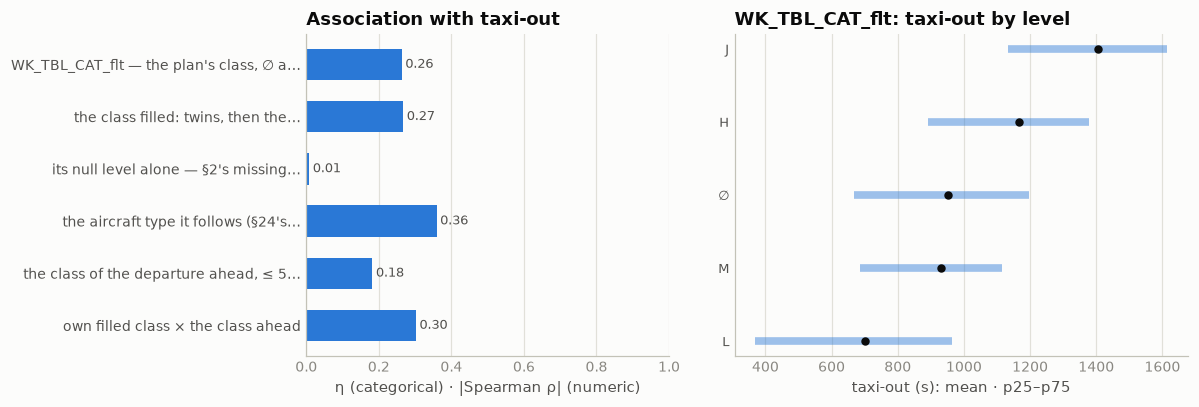

In [8]:
# correlation with the target: the plan's class (∅ a level), the class filled, its null level alone, the aircraft type the class follows
# (§24's recipe), and the class of the departure ahead — on the rows of the ladder's table, training departures 1–3,600 s
a = target_assoc([
    ("WK_TBL_CAT_flt — the plan's class, ∅ a level", "cat", "wp", 1, "wk_t", "y"),
    ("the class filled: twins, then the type's class", "cat", "wf", 1, "wk_t", "y"),
    ("its null level alone — §2's missing plan, §22's 167", "cat", "wp = '∅'", 1, "wk_t", "y"),
    ("the aircraft type it follows (§24's recipe)", "cat", "tf_tw", 30, "wk_t", "y"),
    ("the class of the departure ahead, ≤ 5 min", "cat", "ahead", 1, "wk_t", "y"),
    ("own filled class × the class ahead", "cat", "wf || ' behind ' || ahead", 1, "wk_t", "y"),
])
assoc_chart(a, "wp", src="wk_t", y="y", title="WK_TBL_CAT_flt")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Missing where the plan is missing, plus §22's 167** | null on 22,544 training and 5,304 ranking departures and on 15,516 and 2,564 arrivals. 22,470, 5,290, 15,449 and 2,552 of them have no plan, and no row has a class without a plan. The other 74 + 14 departures and 67 + 12 arrivals are plan rows that lack the rule too (§22), every one with a type: 47 codes, `PC12` 21, `C25A` 13, `E55P` 12, `F2TH` 8. 8 to 19 rows a month from 13 March 2025, none in January or February | the null level is §2's missing-plan flag plus 167 business and general aviation plans. The type fills 73 of the 74 training departures among them and all 14 ranking (closing state) |
| **Four levels, one of them a single aircraft** | departures: M 77.54% (130 type codes), H 20.19% (33), J 0.71% (1), L 0.49% (78); ranking 76.36, 20.92, 0.69, 0.48. `J` is only ever the `A388`. The biggest H codes are `B77W`, `B789`, `A359`, `A333`; the biggest L are business jets and turboprops, `C25A`, `PC12`, `C510` | a size bin: mean taxi-out L 652 s, M 932, H 1,166, J 1,404 (final levels, training departures 1–3,600 s) |
| **The class is a property of the type** | 247 plan type codes, 9 with a second class, 33 of 4,811,403 plan rows off their type's class (99.9993%). Seven of the nine are one-row slips (`B738` H 1, `B789` M 1, `B38M` H 1, `A332` M 1, `C25C` L 1, `BE20` M 1, `ZZZZ` H 1). Two split for real: `B350` L 305 / M 23 and `SW4` M 114 / L 3, variants the type code does not separate | the class carries nothing the type does not. `wake_lk`, one class per plan type code, replaces the column wherever a type is known |
| **The class follows the plan's code, not the movement's** | the plan's class matches its own type's class on all but 14 + 2 departures. Keyed on the movement's code (§11's `typ_wake`), 304 + 34 differ. The biggest pair: 210 Paris departures the movement records as `B763` (H) under a plan for a `B738` (M); then `ZZZZ`→`BE20` 15 at LFPG and `B350` 13 | the class is filed with the type code and moves with it. Where the two systems name different aircraft (§11a) the class cannot referee them, because it is not a separate observation |
| **§2's twins carry their type's class** | every twin layer's class matches its own type's: 892 + 526 + 217 + 263 training (one relaxed A block has no class), 226 + 102 + 50 + 101 ranking. Against the movement's type, 1,781 + 436 agree and 0 differ; 117 + 43 have no movement type (§24's Fiumicino rows). §2c's history agrees with the movement's type on 18,405 + 4,338 of 18,405 + 4,338, by construction: its first step is the same lookup | nothing beyond §24's referee: the twins' type is the movement's, and their class is that type's |
| **Alone, a coarse type** | ladder (1): 357.3 → 347.5 with the plan's class, ∅ a level, and 347.3 filled; the type 337.9; the class then the type 337.8; the type then the class 337.9. η 0.263 for the plan's class and 0.267 filled, against 0.359 for the type | worth nothing next to the type. As the type's coarser rung, 0.1 s on one holdout |
| **Worth nothing on §13's base** | ladder (2): 265.5 → 265.3 with the filled class, 265.3 with the type, 265.2 with both | the stand, the runway and the anchor already sort aircraft by size |
| **Behind a heavy the wait is real, and the anchor already holds it** | with another departure ahead on the same runway within 5 minutes, a heavy or super ahead against a light or medium: medium departures +18 s (EDDF) to +101 s (LIRF) in plain means, heavy departures −53 s (LEMD) to +136 s (LSZH). Ladders: the class ahead 354.7 on the airport, and × own class 345.3 against own class alone 347.3; on §13's base 265.4, and 265.2 against 265.3. On the medium departures behind a heavy the error rises, 340.3 → 344.2 s on the airport (33,176 rows) and 257.0 → 257.4 s on the base (32,876). η 0.182 for the class ahead | the separation wait sits between off-block and takeoff, inside §9's `AOBT_3` anchor. Not a feature |
| **On raw labels the ∅ is §2's flag, and the class is the type's shadow** | ladder (3): 496.5 → 475.0 with the flag. The plan's class 467.4, with or without the flag first; the filled class after the flag 465.9; the type after the flag 459.5, and the filled class after the type 459.5. η of the null level alone 0.008 on 1–3,600 s | filling gives the plan-less departures their class, worth 1.5 s until the type is in and 0.0 after |
| **§2c's history reaches further, and the reach is the signal** | after the flag and the filled class (465.9), filling with §2c's history as well gives 458.4. The flag "only the history reaches this row" gives 460.2. So 5.7 s comes from whether the history reaches the row and 1.8 s from the class it brings, the split §23 found (6.2 + 1.5). It reaches 1,202 + 284 of the departures left without a class, most of them without a type. Its wake steps after the type lookup are flight number × airport and callsign prefix × airport (§2c's policy) | the reach describes the flight number, not the wake class, so it is §2c's (open list). The wake history reaches further than §24's type history did (614 + 179 type-less rows), and deserves the check against §10a's gauge there |
| **Left without a class: no type, or a type no plan files** | 1,938 training and 451 ranking departures (0.09%, 0.13%). 1,390 + 345 have no type at all, 1,370 + 340 of them at LIRF (§11, §24). 548 + 106 fly 34 codes no plan ever gives a class; 627 of the 654 are VFR and 320 rotorcraft (`C172` 243, `AS50` 170, `SLG2` 69, `EC20` 43, `EC30` 32) | ∅ is a real level: Fiumicino's type-less slice, plus light aircraft, gliders and helicopters that file no plan |

**Decisions**

| issue | decision | why |
|---|---|---|
| the lookup's key | the plan's type code, learned from every plan row of both files, ties to the heavier class (`wake_lk`) | the class is filed with the plan's code: 14 + 2 departures differ against 304 + 34 on the movement's code. No label is read, so the 2026 plans may teach it. §11's `typ_wake` is left as defined, since its cells read it |
| the fill order | the plan's class, then the twins', then `wake_lk` on §24's type recipe | the twins' class is their type's on every row, and their type the movement's (§24). The type recipe reaches the plan-less departures and the one-row slips cannot move it |
| §2c's history on the 1,202 + 284 rows left | counted, not applied | 7.5 s on raw labels, but 5.7 s of it is whether the history reaches the row. That describes the flight number, not the class, so it stays with §2c as §23 and §24 decided |
| the 654 departures on codes no plan classes | ∅ stays a level; no hand-written class for rotorcraft or light aircraft | no plan in the data confirms a class for them, and the whole column is worth 0.2 s on §13's base |
| the class of the departure ahead | not a feature | real in plain means, 0.1 s on §13's base, and on the rows it should help the error rises |
| derived file | none | the fill is a 247-row lookup and a `coalesce`; the twins' class comes with §2's files |

**State after §25** (departures):

| `WK_TBL_CAT_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,544 → 1,938 | 5,304 → 451 |
| from the twins (§2b, §2c) | 1,898 | 479 |
| from the type's class, plans without one (§22's) | 73 | 14 |
| from the type's class, no plan | 18,635 | 4,360 |
| left, no type on either side (at LIRF) | 1,390 (1,370) | 345 (340) |
| left, a type no plan gives a class | 548 | 106 |
| left, §2c's history reaches (not applied) | 1,202 | 284 |

| final level | training | ranking | median DEP taxi, 1–3600 s |
|---|---:|---:|---:|
| `M` | 1,630,687 (78.21%) | 266,756 (77.36%) | 878 s |
| `H` | 425,199 (20.39%) | 73,247 (21.24%) | 1,090 s |
| `J` | 14,838 (0.71%) | 2,430 (0.70%) | 1,327 s |
| `L` | 12,385 (0.59%) | 1,957 (0.57%) | 552 s |
| ∅ | 1,938 (0.09%) | 451 (0.13%) | 849 s |

**Use in modeling.** Nothing new to feed. The wake class is the aircraft type in four bins, filed with the plan's code and
matching that code's class on 99.9993% of plan rows. A model that has §24's type has the class already: 0.0 s after the
type on the airport ladder and on raw labels, and 0.2 s on §13's base, where the type is worth the same. The pipeline's
`wake_cat` may stay. If it does, feed the filled form, `coalesce(WK_TBL_CAT_flt, the twins' WK_TBL_CAT_flt,
wake_lk[coalesce(AIRCRAFT_TYPE_flt, the twins' AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt)])` with ∅ a level. It gives 18,635 +
4,360 plan-less departures their class and is right wherever it can be checked. The one thing a class says that a type
cannot, the separation behind a heavy, is already inside the `AOBT_3` anchor. The live lead is §2c's: whether its history
reaches a classless departure is worth 5.7 s on raw labels. The closing matrix reads the twin layers' class as `TWINSWK`
and the type's class from `wake_lk`, with the few nulls kept as a level.


## 26 · `AIRCRAFT_OPERATOR_flt` — the company flying the aircraft, behind a hash

The operator of the flight as the plan files it, anonymised into 64 hexadecimal characters. §16 showed that the callsign's
three-letter prefix names what the hash hides, built a readable operator token from it in 16a, and left the rest to this
section. Three questions. **Is the hash exactly the prefix, and what is the one hash that is not?** **Should a model read the
hash, the prefix, or §16a's filled token?** And **what is an operator worth once the stand, the anchor and the aircraft type
are in?**

| step | question | what came out |
|---|---|---|
| **census** | where it is missing; its form; can it be read directly? | missing exactly where the plan is missing (22,470 + 5,290 departures), always 64 hex characters, 682 hashes in 2025 and 587 in 2026. Not a plain digest of the airline code: 0 of 711 hashes match any of five digests of their prefix |
| **the hash is the prefix** | one-to-one? what is the bucket? | outside one hash, exactly one-to-one on 4,758,203 rows. That hash, `f3270be8…`, holds the operators with no code of their own: every registration callsign, 294 prefixes that never leave it, and 21 that leave it for a hash of their own and never come back |
| **the fill** | how far the twins, §16a's token and §2c's history take the hash | the twins take 22,470 → 20,572 training and 5,290 → 4,811 ranking departures; the token's hash would leave 2,156 and 412. A prefix → hash lookup agrees with the raw hash on 2,388,620 of 2,388,950 departures |
| **signal** | the hash, the prefix, the filled token; after the type; on §13's base; on raw labels | 357.3 → 335.3 alone and 337.9 → 327.2 after the type, the same in every form; 265.5 → 265.2 on §13's base. On raw labels the fill's gain is §10a's 58 Fiumicino rows, and outside them it costs 9.3 s |
| **closing state** | the form to feed | the raw hash with §2's twin blocks: 20,572 + 4,811 departures left as ∅, which is §2's missing-plan flag |


In [4]:
# census by file × phase: where the operator hash is missing (where the plan is missing, §17's ADEP_flt IS NULL), its form, the one hash
# that covers many operators (§16's bucket), and whether a hash is a plain digest of the ICAO code it hides
import hashlib
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
display(cat_stats("AIRCRAFT_OPERATOR_flt"))

cen = con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_OPERATOR_flt IS NULL) n_null, count(*) FILTER (ADEP_flt IS NULL) plan_missing,
           count(*) FILTER (ADEP_flt IS NOT NULL AND AIRCRAFT_OPERATOR_flt IS NULL) plan_but_no_hash,
           count(*) FILTER (ADEP_flt IS NULL AND AIRCRAFT_OPERATOR_flt IS NOT NULL) hash_but_no_plan,
           count(*) FILTER (NOT regexp_matches(AIRCRAFT_OPERATOR_flt, '^[0-9a-f]{{64}}$')) not_64_hex, count(DISTINCT AIRCRAFT_OPERATOR_flt) hashes
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df()
print("by file × phase — the presence rule and the form (64 lower-case hex characters):")
print(cen.to_string(index=False))
assert (cen.n_null == cen.plan_missing).all() and (cen.plan_but_no_hash == 0).all() and (cen.not_64_hex == 0).all()

# the bucket: the hash that covers the most callsign prefixes, ties broken on the hash so it is the same on every run
BUCKET = con.sql(f"""
    SELECT AIRCRAFT_OPERATOR_flt FROM {BOTH} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1
    ORDER BY count(DISTINCT id_prefix(CALLSIGN_flt)) DESC, 1 LIMIT 1""").fetchone()[0]
print(f"\nthe bucket, {BUCKET[:8]}…: its share of the rows that carry a hash, and the prefixes and registrations under it:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') n_bucket,
           round(100.0*count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}')/count(*), 2) pct_of_hash_rows,
           count(DISTINCT id_prefix(CALLSIGN_flt)) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') prefixes,
           count(DISTINCT CALLSIGN_flt) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}' AND id_style(CALLSIGN_flt) = 'other') registrations,
           count(DISTINCT AIRCRAFT_OPERATOR_flt) FILTER (AIRCRAFT_OPERATOR_flt != '{BUCKET}') other_hashes
    FROM {BOTH} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

pairs = con.sql(f"SELECT h, pfx_from_hash FROM hash_pfx WHERE h != '{BUCKET}'").fetchall()
hits = {f"{fn}({sp})": sum(hashlib.new(fn, (p.lower() if sp == "abc" else p).encode()).hexdigest() == h for h, p in pairs)
        for fn in ["sha256", "sha1", "md5", "sha3_256", "blake2s"] for sp in ["ABC", "abc"]}
print(f"\nis a hash the digest of its prefix? {len(pairs)} hashes outside the bucket against five digests of the prefix, two spellings:")
print("   ", ", ".join(f"{k} {v}" for k, v in hits.items()))


,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,37919,0.91,682
ranking 2026,689534,7842,1.14,587


by file × phase — the presence rule and the form (64 lower-case hex characters):
     src  ph       n  n_null  plan_missing  plan_but_no_hash  hash_but_no_plan  not_64_hex  hashes
training ARR 2082750   15449         15449                 0                 0           0     677
training DEP 2085047   22470         22470                 0                 0           0     676
 ranking ARR  344693    2552          2552                 0                 0           0     581
 ranking DEP  344841    5290          5290                 0                 0           0     579

the bucket, f3270be8…: its share of the rows that carry a hash, and the prefixes and registrations under it:


     src  ph  n_bucket  pct_of_hash_rows  prefixes  registrations  other_hashes
training ARR     22648              1.10       324           2462           676
training DEP     22627              1.10       316           2458           675
 ranking ARR      4050              1.18       178            828           580
 ranking DEP      4042              1.19       177            817           578

is a hash the digest of its prefix? 711 hashes outside the bucket against five digests of the prefix, two spellings:
    sha256(ABC) 0, sha256(abc) 0, sha1(ABC) 0, sha1(abc) 0, md5(ABC) 0, md5(abc) 0, sha3_256(ABC) 0, sha3_256(abc) 0, blake2s(ABC) 0, blake2s(abc) 0


In [5]:
# the hash is the callsign's prefix: one-to-one outside the bucket in both files and both phases. What the bucket holds, and the prefixes
# that leave it for a hash of their own — then the twin layers' hash (TWINSOP) and the prefix → hash lookup (pfx_hash), checked against every source
out = con.sql(f"""
    WITH d AS (SELECT id_prefix(CALLSIGN_flt) p, AIRCRAFT_OPERATOR_flt h, id_style(CALLSIGN_flt) style FROM {BOTH}
               WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL AND AIRCRAFT_OPERATOR_flt != '{BUCKET}')
    SELECT count(*) rows_outside, count(DISTINCT h) hashes, count(DISTINCT p) prefixes, count(*) FILTER (style != 'icao') not_icao_spelling,
           (SELECT count(*) FROM (SELECT h FROM d WHERE p IS NOT NULL GROUP BY 1 HAVING count(DISTINCT p) > 1)) hashes_on_2plus_prefixes,
           (SELECT count(*) FROM (SELECT p FROM d WHERE p IS NOT NULL GROUP BY 1 HAVING count(DISTINCT h) > 1)) prefixes_on_2plus_hashes
    FROM d""").df()
print("outside the bucket, both files × phases:")
print(out.to_string(index=False))
assert out.hashes_on_2plus_prefixes[0] == 0 and out.prefixes_on_2plus_hashes[0] == 0

print("\ninside it — departures by the callsign's spelling (a registration is 'other'), and whether any other hash holds that spelling:")
print(con.sql(f"""
    SELECT src, id_style(CALLSIGN_flt) spelling, count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') in_bucket,
           count(*) FILTER (AIRCRAFT_OPERATOR_flt != '{BUCKET}') under_another_hash
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1, 2 HAVING count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') > 0
    ORDER BY 1 DESC, in_bucket DESC""").df().to_string(index=False))
print("\nand what kind of flying it is (training departures, taxi 1–3,600 s), against the same segment under an operator's own hash:")
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') n_bucket,
           round(100.0*count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}')/sum(count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}')) OVER (), 2) pct_of_bucket,
           round(100.0*count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}')/count(*), 2) pct_of_segment,
           round(avg(TAXITIME_SEC_mvt) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}')) mean_taxi_bucket,
           round(avg(TAXITIME_SEC_mvt) FILTER (AIRCRAFT_OPERATOR_flt != '{BUCKET}')) mean_taxi_own_hash
    FROM {TGT} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1 ORDER BY n_bucket DESC, 1""").df().to_string(index=False))

con.sql(f"""
    CREATE OR REPLACE TABLE op_psz AS   -- per ICAO prefix, both files and phases: movements in the bucket and under a hash of its own
    WITH d AS (SELECT * FROM {BOTH} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL AND id_style(CALLSIGN_flt) = 'icao'),
         seg AS (SELECT id_prefix(CALLSIGN_flt) p, MARKET_SEGMENT_flt segment FROM d GROUP BY 1, 2
                 QUALIFY row_number() OVER (PARTITION BY p ORDER BY count(*) DESC, segment) = 1)
    SELECT id_prefix(CALLSIGN_flt) p, count(*) n, count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') n_b,
           max(MVT_TIME_UTC_mvt) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') last_bucket,
           min(MVT_TIME_UTC_mvt) FILTER (AIRCRAFT_OPERATOR_flt != '{BUCKET}') first_own,
           count(DISTINCT ADEP_mvt || '-' || ADES_mvt) routes, any_value(seg.segment) segment
    FROM d JOIN seg ON seg.p = id_prefix(d.CALLSIGN_flt) GROUP BY 1""")
print("\nnot a size threshold — prefixes by where their movements sit (both files × phases):")
print(con.sql("""
    SELECT CASE WHEN n_b = n THEN '1 · only in the bucket' WHEN n_b = 0 THEN '2 · only under its own hash' ELSE '3 · both' END sits,
           count(*) prefixes, sum(n) movements, min(n) min_movements, quantile_disc(n, 0.5) median, max(n) max_movements,
           count(*) FILTER (n <= 5) with_5_or_fewer
    FROM op_psz GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print("  the busiest prefixes that never leave the bucket:")
print(con.sql("SELECT p prefix, n movements, routes, segment FROM op_psz WHERE n_b = n ORDER BY n DESC, p LIMIT 8").df().to_string(index=False))

sw = con.sql("""
    SELECT p prefix, n_b in_bucket, last_bucket::DATE last_in_bucket, n - n_b own_hash, first_own::DATE first_own_hash, segment
    FROM op_psz WHERE n_b > 0 AND n_b < n ORDER BY first_own, p""").df()
print(f"\nthe {len(sw)} prefixes seen both ways — every one leaves the bucket for a hash of its own, and none comes back:")
print(sw.to_string(index=False))
assert (sw.last_in_bucket < sw.first_own_hash).all()
print(con.sql(f"""
    WITH m AS (SELECT id_prefix(CALLSIGN_flt) p, count(DISTINCT AIRCRAFT_OPERATOR_flt) k, bool_or(AIRCRAFT_OPERATOR_flt = '{BUCKET}') has_bucket
               FROM {T} WHERE PHASE_mvt = 'DEP' AND CALLSIGN_flt IS NOT NULL AND AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1)
    SELECT count(*) FILTER (k > 1) "§16's prefixes on several hashes (training departures)",
           count(*) FILTER (k = 2 AND has_bucket) "of which the bucket and one hash of its own" FROM m""").df().to_string(index=False))
print("\nthe hashes new in 2026 — whose are they?")
print(con.sql(f"""
    WITH th AS (SELECT DISTINCT AIRCRAFT_OPERATOR_flt h FROM {T} WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL),
         tp AS (SELECT id_prefix(CALLSIGN_flt) p, count(*) n, count(*) FILTER (AIRCRAFT_OPERATOR_flt = '{BUCKET}') nb FROM {T}
                WHERE PHASE_mvt = 'DEP' AND id_prefix(CALLSIGN_flt) IS NOT NULL GROUP BY 1)
    SELECT count(DISTINCT r.AIRCRAFT_OPERATOR_flt) new_hashes, count(*) ranking_departures,
           count(*) FILTER (tp.p IS NOT NULL) prefix_flew_in_2025, count(*) FILTER (tp.nb = tp.n) of_which_in_the_bucket,
           count(*) FILTER (tp.n >= 30) prefix_with_30_departures
    FROM {R} r LEFT JOIN tp ON tp.p = id_prefix(r.CALLSIGN_flt)
    WHERE r.PHASE_mvt = 'DEP' AND r.AIRCRAFT_OPERATOR_flt IS NOT NULL AND r.AIRCRAFT_OPERATOR_flt NOT IN (SELECT h FROM th)""").df().to_string(index=False))

# the twin layers' hash (§2b, §2c) and the lookup the other direction from §16a's hash_pfx: prefix → hash, from every plan row of both files (no
# label is read). Only the switching prefixes have two hashes; they map to the busier one, ties to the lower hash
TWINSOP = (f"(SELECT MVT_ID_mvt, AIRCRAFT_OPERATOR_flt op_twin, CALLSIGN_flt cs_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
           f"UNION ALL SELECT MVT_ID_mvt, AIRCRAFT_OPERATOR_flt, CALLSIGN_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
con.sql(f"""
    CREATE OR REPLACE TABLE pfx_hash AS
    SELECT p, h FROM (SELECT id_prefix(CALLSIGN_flt) p, AIRCRAFT_OPERATOR_flt h, count(*) n FROM {BOTH}
                      WHERE id_prefix(CALLSIGN_flt) IS NOT NULL AND AIRCRAFT_OPERATOR_flt IS NOT NULL GROUP BY 1, 2)
    QUALIFY row_number() OVER (PARTITION BY p ORDER BY n DESC, h) = 1""")
print("\nthe sources against the lookup, departures of both files: the raw hash, the twins' hash, §2c's history (where each has a token to look up).\n"
      "A registration callsign's token is §16a's third layer, the airline its flight number names:")
print(con.sql(f"""
    WITH f AS ({FINALOP})
    SELECT 'the raw hash' src, count(*) n, count(*) FILTER (ph.h = f.AIRCRAFT_OPERATOR_flt) agree,
           count(*) FILTER (ph.h != f.AIRCRAFT_OPERATOR_flt AND f.op_final IN (SELECT p FROM op_psz WHERE n_b > 0 AND n_b < n)) disagree_on_a_switching_prefix,
           count(*) FILTER (ph.h != f.AIRCRAFT_OPERATOR_flt AND id_style(f.CALLSIGN_flt) = 'other') disagree_under_a_registration
    FROM f JOIN pfx_hash ph ON ph.p = f.op_final WHERE f.AIRCRAFT_OPERATOR_flt IS NOT NULL
    UNION ALL
    SELECT 'the twins'' hash', count(*), count(*) FILTER (ph.h = w.op_twin),
           count(*) FILTER (ph.h != w.op_twin AND f.op_final IN (SELECT p FROM op_psz WHERE n_b > 0 AND n_b < n)),
           count(*) FILTER (ph.h != w.op_twin AND id_style(w.cs_twin) = 'other')
    FROM f JOIN {TWINSOP} w USING (MVT_ID_mvt) JOIN pfx_hash ph ON ph.p = f.op_final WHERE f.AIRCRAFT_OPERATOR_flt IS NULL AND w.op_twin IS NOT NULL
    UNION ALL
    SELECT '§2c''s history', count(*), count(*) FILTER (ph.h = i.AIRCRAFT_OPERATOR_flt),
           count(*) FILTER (ph.h != i.AIRCRAFT_OPERATOR_flt AND f.op_final IN (SELECT p FROM op_psz WHERE n_b > 0 AND n_b < n)),
           count(*) FILTER (FALSE)
    FROM f JOIN {IMP} i USING (MVT_ID_mvt) JOIN pfx_hash ph ON ph.p = f.op_final WHERE f.AIRCRAFT_OPERATOR_flt IS NULL AND i.AIRCRAFT_OPERATOR_flt IS NOT NULL
    """).df().to_string(index=False))


outside the bucket, both files × phases:
 rows_outside  hashes  prefixes  not_icao_spelling  hashes_on_2plus_prefixes  prefixes_on_2plus_hashes
      4758203     711       711                  1                         0                         0

inside it — departures by the callsign's spelling (a registration is 'other'), and whether any other hash holds that spelling:
     src spelling  in_bucket  under_another_hash
training    other      11352                   0
training     icao      10834             2039950
training     iata        441                   0
 ranking     icao       2112              335509
 ranking    other       1841                   0
 ranking     iata         89                   0

and what kind of flying it is (training departures, taxi 1–3,600 s), against the same segment under an operator's own hash:


      segment  n_bucket  pct_of_bucket  pct_of_segment  mean_taxi_bucket  mean_taxi_own_hash
     Business     13673          60.54           30.77             790.0               775.0
     Mainline      6851          30.33            0.52            1070.0              1027.0
        Other      1252           5.54           18.81             765.0               913.0
Non-Scheduled       461           2.04            3.19            1002.0               968.0
     Military       244           1.08           34.27             893.0               797.0
     Regional        59           0.26            0.03             833.0               769.0
        Cargo        45           0.20            0.08             798.0              1014.0
      Lowcost         0           0.00            0.00               NaN               964.0



not a size threshold — prefixes by where their movements sit (both files × phases):
                       sits  prefixes  movements  min_movements  median  max_movements  with_5_or_fewer
     1 · only in the bucket       294    24899.0              1       8           2002              115
2 · only under its own hash       690  4755421.0              1     156         523225               68
                   3 · both        21     3819.0              8     173            679                0
  the busiest prefixes that never leave the bucket:
prefix  movements  routes  segment
   CSC       2002      12 Mainline
   FAD       1711      15 Mainline
   IRB       1586      13 Mainline
   TBZ       1415       6 Mainline
   MNS       1343      15 Mainline
   MRJ        907      11 Mainline
   QSM        880       5 Mainline
   SZN        864      15 Mainline

the 21 prefixes seen both ways — every one leaves the bucket for a hash of its own, and none comes back:
prefix  in_bucket last_in_


the sources against the lookup, departures of both files: the raw hash, the twins' hash, §2c's history (where each has a token to look up).
A registration callsign's token is §16a's third layer, the airline its flight number names:
            src       n   agree  disagree_on_a_switching_prefix  disagree_under_a_registration
   the raw hash 2388950 2388620                             316                             14
the twins' hash    2363    2362                               1                              0
  §2c's history   22598   22532                               0                              0


In [6]:
# what the operator buys — honest ladders, fit Jan–Oct → scored Nov+Dec, cell support ≥ 30 cascading rung by rung (§13's std_rungs): the raw hash
# (∅ a level); the callsign's own prefix, unfilled; the hash with §2's twin blocks only; the hash filled (the twins' hash, then the hash of §16a's token through pfx_hash); §16a's token,
# which fills the plan-less departures too; beside §24's type; on §13's
# base; on raw labels. The three numbers: all holdout rows · the bucket's rows · the rows outside §10a's slice (Fiumicino, no plan, takeoff ≥ 2 h
# after the schedule)
con.sql(f"""
    CREATE OR REPLACE TABLE opx AS   -- departures, both files: the hash from each source, and §16a's token
    SELECT f.ds src, f.MVT_ID_mvt, f.AIRCRAFT_OPERATOR_flt op_raw, w.op_twin, ph.h op_map, f.op_final tok, f.op_prov,
           coalesce(f.AIRCRAFT_OPERATOR_flt, w.op_twin, ph.h) op_fill, i.AIRCRAFT_OPERATOR_flt op_hist, f.TAXITIME_SEC_mvt y
    FROM ({FINALOP}) f LEFT JOIN {TWINSOP} w USING (MVT_ID_mvt) LEFT JOIN pfx_hash ph ON ph.p = f.op_final
    LEFT JOIN {IMP} i USING (MVT_ID_mvt)""")
con.sql(f"""
    CREATE OR REPLACE TABLE op_d AS
    SELECT d.ADEP_mvt hub, d.RUNWAY_mvt rwy, d.STAND_mvt stand, {PFX} pfx, coalesce(d.AIRCRAFT_TYPE_flt, t.typ_twin, d.AIRCRAFT_TYPE_mvt, '∅') tf_tw,
           coalesce(o.op_raw, '∅') o_raw, coalesce(id_prefix(d.CALLSIGN_flt), '∅') o_cs, coalesce(o.op_raw, o.op_twin, '∅') o_tw, coalesce(o.op_fill, '∅') o_fill, coalesce(o.tok, '∅') o_tok, coalesce(o.op_fill, o.op_hist, '∅') o_fill_h,
           coalesce(o.op_fill = '{BUCKET}', FALSE) bucket, d.ADEP_flt IS NULL no_plan,
           coalesce(d.ADEP_mvt = 'LIRF' AND d.ADEP_flt IS NULL AND epoch(d.MVT_TIME_UTC_mvt - d.SCHED_TIME_UTC_mvt) >= 7200, FALSE) gauge,
           d.TAXITIME_SEC_mvt::DOUBLE y, month(d.MVT_TIME_UTC_mvt) >= 11 is_val, epoch(d.MVT_TIME_UTC_mvt - d.AOBT_3_flt) anchor
    FROM {T} d JOIN (SELECT * FROM opx WHERE src = 'training') o USING (MVT_ID_mvt) LEFT JOIN {TWINSTY} t USING (MVT_ID_mvt)
    WHERE d.PHASE_mvt = 'DEP' AND d.TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE op_t AS SELECT * FROM op_d WHERE y <= 3600")
for tbl, src in [("op_wb", "op_t"), ("op_db", "op_d")]:
    con.sql(f"""
        CREATE OR REPLACE TABLE {tbl} AS
        WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa
                      FROM {src} WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
        SELECT {src}.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc
        FROM {src} JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")


def op_pred(rungs, tbl, tag="op_s"):
    """§13's std_rungs on this section's tables: the prediction after the last rung, each cell mean where it has ≥ 30 fit rows, else the rung before."""
    joins, preds = [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE {tag}{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN {tag}{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN {tag}{i}.c >= 30 THEN {tag}{i}.m END")
    return f"coalesce({', '.join(reversed(preds))}, (SELECT avg(y) FROM {tbl} WHERE NOT is_val))", " ".join(joins)


def op_show(title, base, extras, tbl):
    def f(v):
        return "      —" if v is None else f"{v:7.1f}"
    print(title)
    for name, steps in [(base[-1][0], [])] + extras:
        pred, joins = op_pred(base + [(name, base[-1][1] + keys) for keys in steps], tbl)
        r = con.sql(f"""SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (v.bucket)),
                               sqrt(avg((v.y - {pred})^2) FILTER (NOT v.gauge))
                        FROM {tbl} v {joins} WHERE v.is_val""").fetchone()
        print(f"    {name:52s} {f(r[0])} · {f(r[1])} · {f(r[2])} s")


n1 = con.sql("SELECT count(*), count(*) FILTER (bucket) FROM op_t WHERE is_val").fetchone()
op_show(f"(1) on the airport mean — {n1[0]:,} Nov+Dec departures 1–3,600 s, {n1[1]:,} of them in the bucket:", AP,
        [("+ the raw hash, ∅ a level", [["o_raw"]]),
         ("+ the callsign's prefix, unfilled", [["o_cs"]]),
         ("+ the hash filled (twins, then the token's hash)", [["o_fill"]]),
         ("+ §16a's token", [["o_tok"]]),
         ("+ in the bucket or not", [["bucket"]]),
         ("+ the aircraft type (§24's recipe)", [["tf_tw"]]),
         ("+ the type, then the raw hash", [["tf_tw"], ["tf_tw", "o_raw"]]),
         ("+ the type, then the callsign's prefix, unfilled", [["tf_tw"], ["tf_tw", "o_cs"]]),
         ("+ the type, then the hash with the twins' blocks", [["tf_tw"], ["tf_tw", "o_tw"]]),
         ("+ the type, then the filled hash", [["tf_tw"], ["tf_tw", "o_fill"]]),
         ("+ the type, then the token", [["tf_tw"], ["tf_tw", "o_tok"]])], "op_t")
n2 = con.sql("SELECT count(*), count(*) FILTER (bucket) FROM op_wb WHERE is_val").fetchone()
print()
op_show(f"(2) on §13's base — the {n2[0]:,} Nov+Dec departures with a runway, a stand and an anchor ({n2[1]:,} in the bucket):", BASE,
        [("+ the callsign's prefix, on top", [["o_cs"]]),
         ("+ the filled hash, on top", [["o_fill"]]),
         ("+ the token, on top", [["o_tok"]]),
         ("+ the type, on top", [["tf_tw"]]),
         ("+ the type, then the token, on top", [["tf_tw"], ["tf_tw", "o_tok"]])], "op_wb")
n3 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (gauge) FROM op_d WHERE is_val").fetchone()
print()
op_show(f"(3) raw labels, no ceiling (§14) — all {n3[0]:,} Nov+Dec departures, {n3[1]:,} without a plan, {n3[2]} in §10a's slice:", AP,
        [("+ the missing-plan flag alone (§2)", [["no_plan"]]),
         ("+ the flag, then the raw hash", [["no_plan"], ["no_plan", "o_raw"]]),
         ("+ the flag, then the filled hash", [["no_plan"], ["no_plan", "o_fill"]]),
         ("+ the flag, then the token", [["no_plan"], ["no_plan", "o_tok"]]),
         ("+ the flag, then filled with §2c's history too", [["no_plan"], ["no_plan", "o_fill_h"]]),
         ("+ the flag, then the type (§24)", [["no_plan"], ["no_plan", "tf_tw"]]),
         ("+ the flag, the type, then the raw hash", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "o_raw"]]),
         ("+ the flag, the type, then the callsign's prefix", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "o_cs"]]),
         ("+ the flag, the type, then the hash with the twins'", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "o_tw"]]),
         ("+ the flag, the type, then the filled hash", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "o_fill"]]),
         ("+ the flag, the type, then the token", [["no_plan"], ["no_plan", "tf_tw"], ["no_plan", "tf_tw", "o_tok"]])], "op_d")
n4 = con.sql("SELECT count(*) FROM op_db WHERE is_val").fetchone()[0]
print()
op_show(f"(4) raw labels on §13's base — the {n4:,} Nov+Dec departures with a runway, a stand and an anchor:", BASE,
        [("+ the callsign's prefix, on top", [["o_cs"]]),
         ("+ the token, on top", [["o_tok"]]),
         ("+ the type, then the token, on top", [["tf_tw"], ["tf_tw", "o_tok"]])], "op_db")

# where (3)'s gain after the flag and the type comes from: the squared error the token removes, row group by row group
pa, ja = op_pred(AP + [("f", ["hub", "no_plan"]), ("t", ["hub", "no_plan", "tf_tw"])], "op_d", "op_pa")
pb, jb = op_pred(AP + [("f", ["hub", "no_plan"]), ("t", ["hub", "no_plan", "tf_tw"]), ("o", ["hub", "no_plan", "tf_tw", "o_tok"])], "op_d", "op_pb")
con.sql(f"CREATE OR REPLACE TABLE op_gain AS WITH a AS (SELECT v.*, {pa} pa FROM op_d v {ja} WHERE v.is_val) SELECT v.*, {pb} pb FROM a v {jb}")
print("\n(3)'s last step, the flag and the type → + the token: the squared error it removes, by row group (millions of s²):")
print(con.sql("""
    SELECT CASE WHEN gauge THEN '1 · §10a''s slice' WHEN y > 3600 THEN '2 · other labels over an hour' ELSE '3 · labels 1–3,600 s' END row_group,
           count(*) n, round((sum((y - pa)^2) - sum((y - pb)^2))/1e6, 1) removed,
           round(100.0*(sum((y - pa)^2) - sum((y - pb)^2))/(SELECT sum((y - pa)^2) - sum((y - pb)^2) FROM op_gain), 1) pct_of_the_gain
    FROM op_gain GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print("  the cells that remove the most — airport × plan × type × token:")
print(con.sql("""
    SELECT hub, no_plan, tf_tw typ, o_tok token, count(*) n, count(*) FILTER (y > 3600) over_1h, round(avg(y)) mean_label,
           round(avg(pa)) pred_before, round(avg(pb)) pred_after, round((sum((y - pa)^2) - sum((y - pb)^2))/1e6, 1) removed
    FROM op_gain GROUP BY 1, 2, 3, 4 ORDER BY removed DESC, hub, typ, token LIMIT 5""").df().to_string(index=False))


(1) on the airport mean — 327,485 Nov+Dec departures 1–3,600 s, 3,489 of them in the bucket:
    airport (§5)                                           357.3 ·   412.4 ·   357.3 s
    + the raw hash, ∅ a level                              335.3 ·   353.7 ·   335.3 s
    + the callsign's prefix, unfilled                      335.5 ·   354.7 ·   335.5 s
    + the hash filled (twins, then the token's hash)       335.0 ·   343.2 ·   335.0 s
    + §16a's token                                         334.9 ·   331.3 ·   334.9 s
    + in the bucket or not                                 356.5 ·   343.2 ·   356.5 s
    + the aircraft type (§24's recipe)                     337.9 ·   330.2 ·   337.9 s


    + the type, then the raw hash                          327.2 ·   324.5 ·   327.2 s
    + the type, then the callsign's prefix, unfilled       327.2 ·   327.1 ·   327.2 s
    + the type, then the hash with the twins' blocks       327.3 ·   324.6 ·   327.3 s
    + the type, then the filled hash                       327.3 ·   323.9 ·   327.3 s
    + the type, then the token                             327.3 ·   326.6 ·   327.3 s

(2) on §13's base — the 324,629 Nov+Dec departures with a runway, a stand and an anchor (3,232 in the bucket):


    + stand (§13's base)                                   265.5 ·   298.2 ·   265.5 s
    + the callsign's prefix, on top                        265.2 ·   298.4 ·   265.2 s


    + the filled hash, on top                              265.2 ·   298.6 ·   265.2 s
    + the token, on top                                    265.2 ·   298.3 ·   265.2 s


    + the type, on top                                     265.3 ·   298.3 ·   265.3 s


    + the type, then the token, on top                     265.2 ·   298.3 ·   265.2 s

(3) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 58 in §10a's slice:
    airport (§5)                                           496.5 ·   429.9 ·   383.0 s
    + the missing-plan flag alone (§2)                     475.0 ·   417.3 ·   382.0 s
    + the flag, then the raw hash                          458.3 ·   373.2 ·   361.0 s
    + the flag, then the filled hash                       449.8 ·   360.0 ·   369.6 s
    + the flag, then the token                             449.8 ·   352.8 ·   369.5 s
    + the flag, then filled with §2c's history too         451.1 ·   359.5 ·   365.9 s


    + the flag, then the type (§24)                        459.5 ·   353.2 ·   363.5 s
    + the flag, the type, then the raw hash                451.6 ·   347.4 ·   353.5 s
    + the flag, the type, then the callsign's prefix       451.6 ·   350.4 ·   353.5 s
    + the flag, the type, then the hash with the twins'    451.6 ·   347.4 ·   353.5 s
    + the flag, the type, then the filled hash             444.1 ·   347.4 ·   362.8 s


    + the flag, the type, then the token                   444.1 ·   350.7 ·   362.8 s

(4) raw labels on §13's base — the 324,988 Nov+Dec departures with a runway, a stand and an anchor:
    + stand (§13's base)                                   286.6 ·   322.8 ·   286.6 s


    + the callsign's prefix, on top                        286.2 ·   323.0 ·   286.2 s
    + the token, on top                                    286.2 ·   323.0 ·   286.2 s


    + the type, then the token, on top                     286.4 ·   323.1 ·   286.4 s

(3)'s last step, the flag and the type → + the token: the squared error it removes, by row group (millions of s²):
                    row_group      n  removed  pct_of_the_gain
             1 · §10a's slice     58   4392.2             96.4
2 · other labels over an hour    435   -400.7             -8.8
         3 · labels 1–3,600 s 327475    566.6             12.4
  the cells that remove the most — airport × plan × type × token:
 hub  no_plan  typ token    n  over_1h  mean_label  pred_before  pred_after  removed
LIRF     True    ∅     ∅   35       20     14206.0       6580.0     14337.0   2034.5
LIRF     True    ∅   ITY    5        0       960.0       6580.0      1397.0    157.0
LEBL    False A320   VLG 6814        0       765.0        868.0       797.0     65.4
EGLL    False A20N   BAW 3411       18      1413.0       1275.0      1418.0     64.9
LEBL    False B738   AEA  338        0       690.0    

In [7]:
# closing state — the column after §26, departures: the raw hash, then §2's twin layers' hash (the form to feed). The hash of §16a's token
# through pfx_hash and §2c's history reach further; both are counted, not applied (ladder (3)). Then the final levels and how they taxi
st = con.sql("""
    SELECT src, count(*) n, count(*) FILTER (op_raw IS NULL) null_before, count(*) FILTER (op_raw IS NULL AND op_twin IS NOT NULL) by_twins,
           count(*) FILTER (coalesce(op_raw, op_twin) IS NULL) null_after, round(100.0*count(*) FILTER (coalesce(op_raw, op_twin) IS NULL)/count(*), 2) pct_null_after,
           count(*) FILTER (coalesce(op_raw, op_twin) IS NULL AND op_map IS NOT NULL) token_would_fill,
           count(*) FILTER (op_fill IS NULL) left_even_then, count(*) FILTER (op_fill IS NULL AND op_hist IS NOT NULL) history_would_fill_of_those,
           count(*) FILTER (tok IS NULL) token_null, count(*) FILTER (tok IS NULL AND op_raw IS NOT NULL) token_null_hash_present
    FROM opx GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.by_twins == st.null_after).all()
assert (st.null_after - st.token_would_fill == st.left_even_then).all()

print("\nthe hash present, the token missing — the spelling of those callsigns, and the hash they carry:")
print(con.sql(f"""
    SELECT o.src, id_style(f.CALLSIGN_flt) spelling, count(*) n, count(*) FILTER (o.op_raw = '{BUCKET}') in_the_bucket
    FROM opx o JOIN ({FINALOP}) f USING (MVT_ID_mvt) WHERE o.tok IS NULL AND o.op_raw IS NOT NULL GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

print("\nthe final levels, departures — the raw hash with §2's twin blocks (taxi: training, 1–3,600 s):")
print(con.sql(f"""
    SELECT CASE WHEN coalesce(op_raw, op_twin) IS NULL THEN '∅' WHEN coalesce(op_raw, op_twin) = '{BUCKET}' THEN 'the bucket' ELSE 'a hash of its own' END final_level,
           count(DISTINCT coalesce(op_raw, op_twin)) hashes,
           count(*) FILTER (src = 'training') training, round(100.0*count(*) FILTER (src = 'training')/sum(count(*) FILTER (src = 'training')) OVER (), 2) pct_training,
           count(*) FILTER (src = 'ranking') ranking, round(100.0*count(*) FILTER (src = 'ranking')/sum(count(*) FILTER (src = 'ranking')) OVER (), 2) pct_ranking,
           round(quantile_cont(y, 0.5) FILTER (src = 'training' AND y BETWEEN 1 AND 3600)) med_taxi
    FROM opx GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))
print("  the ten busiest operators by training departures — the hash, the prefix it is, and how they taxi:")
print(con.sql(f"""
    SELECT substr(coalesce(op_raw, op_twin), 1, 8) || '…' op_hash, any_value(hp.pfx_from_hash) prefix, count(*) FILTER (src = 'training') training,
           count(*) FILTER (src = 'ranking') ranking, round(quantile_cont(y, 0.5) FILTER (src = 'training' AND y BETWEEN 1 AND 3600)) med_taxi
    FROM opx LEFT JOIN hash_pfx hp ON hp.h = coalesce(op_raw, op_twin)
    WHERE coalesce(op_raw, op_twin) != '{BUCKET}' GROUP BY 1 ORDER BY training DESC, 1 LIMIT 10""").df().to_string(index=False))


     src       n  null_before  by_twins  null_after  pct_null_after  token_would_fill  left_even_then  history_would_fill_of_those  token_null  token_null_hash_present
training 2085047        22470      1898       20572            0.99             18416            2156                          938       13472                    11337
 ranking  344841         5290       479        4811            1.40              4399             412                          160        2246                     1841

the hash present, the token missing — the spelling of those callsigns, and the hash they carry:
     src spelling     n  in_the_bucket
training    other 11337          11337
 ranking    other  1841           1841

the final levels, departures — the raw hash with §2's twin blocks (taxi: training, 1–3,600 s):
      final_level  hashes  training  pct_training  ranking  pct_ranking  med_taxi
a hash of its own     705   2041824         97.93   335987        97.43     911.0
       the bucket     

                                                     feature        kind  n / levels  pearson_r  spearman_ρ     η
AIRCRAFT_OPERATOR_flt — the raw hash, ∅ a level, ≥ 30 pooled categorical         434                        0.461
           the hash with §2's twin blocks — the form to feed categorical         434                        0.461
               the hash filled: twins, then the token's hash categorical         435                        0.464
                             the callsign's prefix, unfilled categorical         488                        0.463
                §16a's token — the callsign's prefix, filled categorical         492                        0.468
                                       the bucket, as a flag categorical           2                        0.040
         the raw hash's null level alone — §2's missing plan categorical           2                        0.007
                            the aircraft type (§24's recipe) categorical         149    

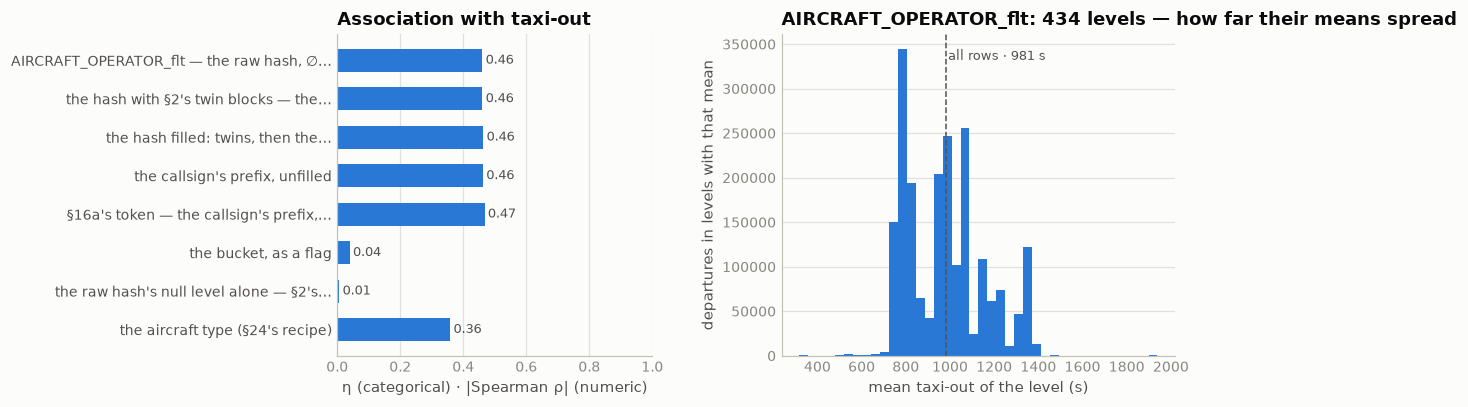

In [8]:
# correlation with the target: the raw hash (∅ a level), the hash with §2's twin blocks (the form to feed), the hash filled, §16a's token, the bucket as a flag, the hash's null level alone, and
# the aircraft type the operator is partly a proxy for (§24's recipe) — on the rows of the ladder's table, training departures 1–3,600 s
a = target_assoc([
    ("AIRCRAFT_OPERATOR_flt — the raw hash, ∅ a level, ≥ 30 pooled", "cat", "o_raw", 30, "op_t", "y"),
    ("the hash with §2's twin blocks — the form to feed", "cat", "o_tw", 30, "op_t", "y"),
    ("the hash filled: twins, then the token's hash", "cat", "o_fill", 30, "op_t", "y"),
    ("the callsign's prefix, unfilled", "cat", "o_cs", 30, "op_t", "y"),
    ("§16a's token — the callsign's prefix, filled", "cat", "o_tok", 30, "op_t", "y"),
    ("the bucket, as a flag", "cat", "bucket", 1, "op_t", "y"),
    ("the raw hash's null level alone — §2's missing plan", "cat", "o_raw = '∅'", 1, "op_t", "y"),
    ("the aircraft type (§24's recipe)", "cat", "tf_tw", 30, "op_t", "y"),
])
assoc_chart(a, "o_tw", src="op_t", y="y", min_support=30, title="AIRCRAFT_OPERATOR_flt")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Missing exactly where the plan is missing** | null on 22,470 training and 5,290 ranking departures and on 15,449 and 2,552 arrivals, every one without a plan (§17's `ADEP_flt IS NULL`), and no plan lacks a hash. 682 hashes in 2025 and 587 in 2026; 676 and 579 on departures | the null level is §2's missing-plan flag and nothing else |
| **A keyed code, not a readable one** | every value is 64 lower-case hex characters. The 711 hashes outside the bucket match none of SHA-256, SHA-1, MD5, SHA3-256 or BLAKE2s of their prefix, in upper or lower case (0 of 711 each) | the hash cannot be read off the code. The callsign (§16) is the only way to read it |
| **Outside one hash, the hash is the callsign's prefix, exactly** | 4,758,203 rows in both files and both phases, under 711 hashes and 711 prefixes: 0 hashes on two prefixes, 0 prefixes on two hashes. One row carries a callsign with no prefix. §16's 99.93% and V 0.9966 were the bucket and the prefixes that leave it | the hash and the prefix split the traffic identically. Outside the bucket it cannot matter which one a model reads, and the ladders confirm it |
| **The bucket, `f3270be8…`, holds the operators with no code of their own** | 22,627 training and 4,042 ranking departures, 1.10% and 1.19% of the rows with a hash. It holds every departure under a registration callsign (11,352 + 1,841; no other hash holds one), the 441 + 89 under an IATA-spelled callsign, and 10,834 + 2,112 under 316 + 177 prefixes. 60.54% of it is business aviation, 30.33% mainline. It holds 30.77% of all business-aviation departures and 34.27% of military ones (training, 1–3,600 s) | an "unknown operator" code. §16's "51% of every business-aviation departure" divided all of the bucket's departures by the business-aviation ones |
| **Not a size threshold** | ICAO prefixes, both files and phases: 294 only ever in the bucket (1 to 2,002 movements, median 8), 690 only under a hash of their own (1 to 523,225, median 156, 68 of them with five movements or fewer). The busiest never to leave it are mainline carriers on 5–15 routes: `CSC` 2,002, `FAD` 1,711, `IRB` 1,586, `TBZ` 1,415, `MNS` 1,343 | the bucket is not "the small operators". It reads like a lookup that failed: an operator the anonymiser's register did not hold, however much it flies |
| **Operators leave the bucket, and never come back** | 21 prefixes appear both ways. For every one, its last movement in the bucket comes before its first under its own hash: `HLF` until 4 Feb 2025 and its own from 6 Feb, `BYD` 22 → 25 Apr, `ALE` 30 Jul → 10 Aug, `CBJ` 1 → 3 Oct (390 movements in the bucket), `JSD` 22 → 26 Nov. Five get their own only in July 2026 (`CPV`, `TUG`, `EQE`, `LSV`, `PXA`). §16's 16 prefixes on several hashes are 16 of these, each the bucket plus one hash | the bucket is a *state* of the register, not a kind of operator. §16 read those 16 as franchise and wet-lease cases; there is no such case in the data. At any one time, one prefix has one hash |
| **The switch costs 2026 almost nothing** | 29 hashes are new in 2026, on 172 ranking departures. The prefixes of 11 of them flew in 2025, all in the bucket, and none with 30 departures | a hash key loses no history a group mean could have used |
| **One lookup fills the hash from a prefix, and every source agrees with it** | `pfx_hash` maps prefix → hash from every plan row of both files, ties to the busier hash. It agrees with the raw hash on 2,388,620 of 2,388,950 departures. The 330 differences are 316 departures on a switching prefix and 14 under a registration callsign, whose token §16a read off the flight number. It agrees with the twins' hash on 2,362 of 2,363 and §2c's history on 22,532 of 22,598 (99.71%) | the hash can be filled wherever §16a's token exists. After the twins (1,898 + 479), the token's hash reaches 18,416 + 4,399 plan-less departures and leaves 2,156 + 412 |
| **Alone, 22 s, whichever spelling** | ladder (1), 327,485 Nov+Dec departures 1–3,600 s: 357.3 → 335.3 with the raw hash (∅ a level), 335.5 with the callsign's prefix, 335.0 filled, 334.9 with §16a's token. η 0.461, 0.463, 0.464, 0.468. The bucket as a flag 356.5, η 0.040 | a large marginal signal, and the same signal in every form |
| **After the type, 10.7 s, and the fill is worth nothing** | the type 337.9 → + the raw hash 327.2, the prefix 327.2, with the twins' blocks 327.3, filled 327.3, the token 327.3. On the bucket's 3,489 rows the token beats the hash alone (331.3 against 353.7) but not after the type (326.6 against 324.5) | inside the bucket the prefix separates aircraft, which the type already does |
| **On §13's base, 0.3 s** | ladder (2), 324,629 departures: 265.5 → 265.2 with the prefix, the filled hash or the token; the type 265.3, the type then the token 265.2. On the bucket's 3,232 rows 298.2 → 298.3 to 298.6. Raw labels on the same base, ladder (4): 286.6 → 286.2 | §16's reading holds: an operator is where it parks and what it flies, and §13's stand and §9's anchor already hold that |
| **On raw labels, the fill's gain is §10a's slice** | ladder (3), 327,968 departures: after §2's flag (475.0) and the type (459.5), the raw hash gives 451.6 and the token 444.1. But 96.4% of the error the token removes at that step sits on the 58 rows of §10a's slice (Fiumicino, no plan, takeoff ≥ 2 h after schedule). 2,034.5 M s² comes from one cell, Fiumicino departures with no plan, no type and no token: 35 rows, 20 of them over an hour, mean label 14,206 s, predicted 6,580 s before and 14,337 s after. The other labels over an hour give back 8.8%. Outside the slice the raw hash is 353.5 and the token **362.8** | what the fill adds on raw labels is its ∅: a departure that nothing identifies, which is §10a's gauge and §2c's reach signal (open list). Splitting plan-less departures by an operator read off their flight number fits their tails, and costs 9.3 s everywhere else |
| **§2c's history does not help either** | after the flag, filling with §2c's history as well gives 451.1 against the token's 449.8 (365.9 against 369.5 outside the slice). It would reach 938 + 160 of the departures the token leaves | no history layer for the operator |

**Decisions**

| issue | decision | why |
|---|---|---|
| the form a model reads | **the hash as it is**, with §2's twin blocks filled in | the same split as the prefix outside the bucket; within 0.1 s of every other form on every 1–3,600 s ladder; 353.5 against the token's 362.8 on raw labels outside §10a's slice. The twins' blocks are neutral (327.3; 451.6 · 353.5) |
| the readable prefix instead | **for reading, not for the model** | the same split; inside the bucket it separates aircraft the type already separates (326.6 against 324.5 after the type) |
| filling plan-less departures from §16a's token | **rejected as a feature** | +0.3 s alone on 1–3,600 s, −0.1 s after the type, −9.3 s on raw labels outside §10a's slice. Its 7.5 s on all raw labels is 58 Fiumicino rows, and that belongs to §10a's gauge |
| §16's recipe for the operator (`op_final`, §16a's fill included) | **superseded as a model input**. §16a's token stays for analysis, and as a fallback level under an encoding of the flight number, which §3 owns | the recipe was written before the fill was measured on raw labels |
| §2c's history | not applied | 451.1 against 449.8 |
| the bucket | a level like any other, no flag | 356.5 alone (η 0.040), and the hash already carries it |
| derived file | none | the hash is a raw column, the twins' hash comes with §2's files, and `pfx_hash` is needed only for analysis |

**State after §26** (departures):

| `AIRCRAFT_OPERATOR_flt` null | training | ranking |
|---|---:|---:|
| before → after, the form to feed | 22,470 → 20,572 | 5,290 → 4,811 |
| from the twins (§2b, §2c) | 1,898 | 479 |
| the token's hash would fill (rejected) | 18,416 | 4,399 |
| left even then | 2,156 | 412 |
| of those, §2c's history would fill (rejected) | 938 | 160 |

| final level | hashes | training | ranking | median DEP taxi, 1–3600 s |
|---|---:|---:|---:|---:|
| a hash of its own | 705 | 2,041,824 (97.93%) | 335,987 (97.43%) | 911 s |
| the bucket | 1 | 22,651 (1.09%) | 4,043 (1.17%) | 836 s |
| ∅, no plan | — | 20,572 (0.99%) | 4,811 (1.40%) | 912 s |

**Use in modeling.** Feed the raw hash, as it is. Outside one bucket of operators with no code of their own (1.09% of departures) the hash *is* the callsign's
ICAO prefix, so the readable token gives a model no split the hash does not. The operator is worth 22 s alone and 10.7 s after
the aircraft type on the airport ladder, but 0.3 s on §13's base, because it is mostly where an airline parks and what it flies. Do not
fill plan-less departures from §16a's token: on raw labels outside §10a's slice it costs 9.3 s. The one thing the fill says
that is worth having is that nothing identifies a Fiumicino departure, and that is §10a's gauge and §2c's reach signal. Where §2's
twin blocks are used, their hash comes with the block and is neutral. The closing matrix reads the hash with the twin
layers' hash filled in (`TWINSOP`), nulls kept as a level, rare hashes pooled below 30 rows.


## 27 · `EOBT_1_flt` — the off-block the network expected on the day

The third of the flight plan's four clocks: the **estimated off-block time** of the Network Manager's
flight-plan-based trajectory (the "M1" model in `data/FEATURES.md`). §15 found that the plan's last
off-block, `LOBT_flt`, is never revised for the day's delay, and §21 that the initial clock is a copy of
it on 99.45% of departures. This is the clock that does move: on 30% of departures it no longer equals
`LOBT_flt`. So the section asks what moves it, whether the move is right, and what that is worth on top of
§15's delay.

The referee is the one §19 and §21 used. In training the actual off-block is visible, so both clocks can be
scored against the thing they estimate. §21 found the plan's *refile* moved its clock away from the
pushback; the move here goes the other way. §9 and §10 measured two forms of this clock before it had a
section (252.4 and 257.1 s on the anchor); this section owns them.

| step | question | what came out |
|---|---|---|
| **census** | present where; which grid; against the plan's other clocks | on **exactly** the rows `LOBT_flt` and `AOBT_3_flt` are; equal to `LOBT_flt` on 70.03% of departures with a plan, moved on 618,141, earlier more often (18.28%) than later (11.69%) |
| **the move** | the flown clock copied in, or an estimate of its own | its own: equal to `AOBT_3` on 5.28% of moved rows. Whole minutes, 57.1% of moves a multiple of 5 min, the step set per hub; **Istanbul never moves it** |
| **the referee** | where it moved, which clock sat closer to the actual off-block | **`EOBT_1`, on 62.8%** — median error 5.1 min against 8.1. Moved later it is right on 92.5–97.5%, moved earlier on 42.0–45.3% |
| **signal** | honest ladders against §15's forms, per hub, on §13's base, on raw labels | 257.1 against 261.0 on the anchor; **237.5 against 240.8 with the delay under §13's pier** (base 265.5); 401.8 against 404.2 on raw labels; 11.0 s at LIRF, 0.0 at LTFM. The move and its flag are worth nothing |
| **look both ways** | does the move mean the same in 2026 | the flown clock as a stand-in referee reproduces the real one (62.7% against 62.8%). With it, **LFPG's July moves go from right on 43.4% to 83.2%**, EGLL's from 49.8% to 38.7% |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures as §15 and §21 |

In [4]:
# census by file × phase: present on exactly the rows the plan's other clocks are, on which grid; then the clock against the plan's last
# off-block, the initial one, the schedule and the flown one; the gaps in minutes; whether the moved clock is the flown one copied in; the steps it moves in
print("EOBT_1_flt by file × phase — and the rows that carry it without LOBT_flt or AOBT_3_flt, or one of those without it:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (EOBT_1_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (EOBT_1_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           count(*) FILTER ((EOBT_1_flt IS NULL) != (LOBT_flt IS NULL)) only_one_of_eobt1_lobt,
           count(*) FILTER ((EOBT_1_flt IS NULL) != (AOBT_3_flt IS NULL)) only_one_of_eobt1_aobt3,
           round(100.0*count(*) FILTER (extract(second FROM EOBT_1_flt) = 0)/count(EOBT_1_flt), 2) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM EOBT_1_flt) % 5 = 0 AND extract(second FROM EOBT_1_flt) = 0)/count(EOBT_1_flt), 1) pct_on_5min_grid,
           count(DISTINCT EOBT_1_flt) n_unique, strftime(min(EOBT_1_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(EOBT_1_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndepartures with a plan: EOBT_1 against the plan's last and initial clocks, the schedule and the flown off-block (training):")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (EOBT_1_flt = LOBT_flt)/count(*), 2) eq_lobt, count(*) FILTER (EOBT_1_flt != LOBT_flt) n_moved,
           round(100.0*count(*) FILTER (EOBT_1_flt < LOBT_flt)/count(*), 2) moved_earlier, round(100.0*count(*) FILTER (EOBT_1_flt > LOBT_flt)/count(*), 2) moved_later,
           round(100.0*count(*) FILTER (EOBT_1_flt = IOBT_flt)/count(*), 1) eq_iobt, round(100.0*count(*) FILTER (EOBT_1_flt = SCHED_TIME_UTC_mvt)/count(*), 1) eq_schedule,
           count(*) FILTER (LOBT_flt != IOBT_flt) refiled, count(*) FILTER (LOBT_flt != IOBT_flt AND EOBT_1_flt = LOBT_flt) refiled_eobt1_follows,
           count(*) FILTER (EOBT_1_flt > MVT_TIME_UTC_mvt) eobt1_after_takeoff, count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt) lobt_after_takeoff,
           round(100.0*count(*) FILTER (EOBT_1_flt > AOBT_3_flt)/count(*), 1) pct_after_aobt3, round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(*), 1) pct_lobt_after_aobt3
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):")
for name, expr in [("EOBT_1 − LOBT, the move, where it moved", "CASE WHEN EOBT_1_flt != LOBT_flt THEN epoch(EOBT_1_flt - LOBT_flt)/60 END"),
                   ("EOBT_1 − schedule", "epoch(EOBT_1_flt - SCHED_TIME_UTC_mvt)/60"),
                   ("AOBT_3 − EOBT_1, the delay against it", "epoch(AOBT_3_flt - EOBT_1_flt)/60"),
                   ("AOBT_3 − LOBT, §15's unfiled delay", "epoch(AOBT_3_flt - LOBT_flt)/60"),
                   ("off-block − EOBT_1 (hidden)", "epoch(BLOCK_TIME_UTC_mvt - EOBT_1_flt)/60"),
                   ("takeoff − EOBT_1", "epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)/60")]:
    q, n = con.sql(f"SELECT quantile_cont({expr}, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]), count({expr}) FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL").fetchone()
    print(f"  {name:42s} n = {n:>9,}   " + "  ".join(f"{x:7.1f}" for x in q))

print("\nis the moved clock the flown one copied in? — equality with AOBT_3 on the moved and the unmoved rows (training departures):")
print(con.sql(f"""
    SELECT CASE WHEN EOBT_1_flt != LOBT_flt THEN 'moved' ELSE 'not moved' END eobt1, count(*) n,
           round(100.0*count(*) FILTER (EOBT_1_flt = AOBT_3_flt)/count(*), 2) pct_eobt1_eq_aobt3, round(100.0*count(*) FILTER (LOBT_flt = AOBT_3_flt)/count(*), 2) pct_lobt_eq_aobt3,
           round(100.0*count(*) FILTER (extract(second FROM AOBT_3_flt) = 0)/count(*), 1) pct_aobt3_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM EOBT_1_flt) % 5 = 0 AND extract(second FROM EOBT_1_flt) = 0)/count(*), 1) pct_eobt1_on_5min_grid
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe steps it moves in — the most common moves EOBT_1 − LOBT, minutes (training departures where it moved):")
print(con.sql(f"""
    SELECT epoch(EOBT_1_flt - LOBT_flt)/60 move_min, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct_of_moves
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt != LOBT_flt GROUP BY 1 ORDER BY n DESC, move_min LIMIT 8""").df().to_string(index=False))
print(con.sql(f"""
    SELECT round(100.0*count(*) FILTER (epoch(EOBT_1_flt - LOBT_flt) % 300 = 0)/count(*), 1) pct_of_moves_a_multiple_of_5_min,
           round(100.0*count(*) FILTER (extract(second FROM EOBT_1_flt) != 0)/count(*), 2) pct_of_moved_stamps_off_the_minute
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt != LOBT_flt""").df().to_string(index=False))

EOBT_1_flt by file × phase — and the rows that carry it without LOBT_flt or AOBT_3_flt, or one of those without it:


     src  ph       n  n_null  no_plan  null_with_an_id  only_one_of_eobt1_lobt  only_one_of_eobt1_aobt3  pct_on_minute  pct_on_5min_grid  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506             6943                       0                        0          97.89              83.3    340829 2025-01-01 00:00 2025-12-31 23:02
training DEP 2085047   22470    22424               46                       0                        0          99.70              85.1    295511 2025-01-01 00:20 2025-12-31 23:45
 ranking ARR  344693    2552     1409             1143                       0                        0          97.93              82.2     57893 2026-01-01 00:00 2026-07-31 22:55
 ranking DEP  344841    5290     5283                7                       0                        0          99.78              84.0     50720 2026-01-01 00:04 2026-07-31 23:30

departures with a plan: EOBT_1 against the plan's last and initial clocks, the schedule and th

  EOBT_1 − schedule                          n = 2,062,577     -12.0     -5.0      0.0      0.0      7.0     27.0    120.0


  AOBT_3 − EOBT_1, the delay against it      n = 2,062,577     -16.0     -5.0      0.0      4.0     11.0     19.0     42.0


  AOBT_3 − LOBT, §15's unfiled delay         n = 2,062,577     -18.0     -7.0     -2.0      4.0     11.0     20.0     46.0


  off-block − EOBT_1 (hidden)                n = 2,062,577     -10.1     -2.1      0.3      4.7     10.1     17.3     38.9


  takeoff − EOBT_1                           n = 2,062,577       4.5     11.1     15.1     20.9     28.0     36.9     60.0

is the moved clock the flown one copied in? — equality with AOBT_3 on the moved and the unmoved rows (training departures):
    eobt1       n  pct_eobt1_eq_aobt3  pct_lobt_eq_aobt3  pct_aobt3_on_minute  pct_eobt1_on_5min_grid
    moved  618141                5.28               2.84                 97.7                    59.6
not moved 1444436                4.91               4.91                 97.7                    96.0

the steps it moves in — the most common moves EOBT_1 − LOBT, minutes (training departures where it moved):
 move_min      n  pct_of_moves
     -5.0 102814          16.6
    -10.0  89413          14.5
     10.0  52423           8.5
      5.0  48145           7.8
    -15.0  23262           3.8
     -4.0  21046           3.4
     -2.0  18046           2.9
     -1.0  17905           2.9


 pct_of_moves_a_multiple_of_5_min  pct_of_moved_stamps_off_the_minute
                             57.1                                 0.0


In [5]:
# the referee: in training the actual off-block is visible, so score the moved clock and §15's clock against it — on the rows where they
# differ, on every row, by the size and sign of the move, by how late the flight actually left, and per hub. The flown clock AOBT_3 is
# printed beside them as the yardstick. EMOV is the 618,141 training departures where EOBT_1 moved and a block stamp exists
EMOV = (f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL AND EOBT_1_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL)")
X_E, X_L, X_A = ("abs(epoch(BLOCK_TIME_UTC_mvt - EOBT_1_flt))", "abs(epoch(BLOCK_TIME_UTC_mvt - LOBT_flt))",
                 "abs(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt))")

print("where EOBT_1 moved — each clock against the actual off-block (training departures):")
print(con.sql(f"""
    SELECT count(*) n, round(avg({X_E})/60, 2) mean_err_eobt1_min, round(avg({X_L})/60, 2) mean_err_lobt_min, round(avg({X_A})/60, 2) mean_err_aobt3_min,
           round(quantile_cont({X_E}/60, 0.5), 1) med_err_eobt1, round(quantile_cont({X_L}/60, 0.5), 1) med_err_lobt, round(quantile_cont({X_A}/60, 0.5), 1) med_err_aobt3,
           count(*) FILTER ({X_E} < {X_L}) eobt1_closer, count(*) FILTER ({X_L} < {X_E}) lobt_closer, count(*) FILTER ({X_E} = {X_L}) tie,
           round(100.0*count(*) FILTER ({X_E} < {X_L})/count(*), 1) pct_eobt1_closer,
           round(100.0*count(*) FILTER ({X_E} <= 300)/count(*), 1) eobt1_within_5min, round(100.0*count(*) FILTER ({X_L} <= 300)/count(*), 1) lobt_within_5min,
           round(100.0*count(*) FILTER ({X_A} <= 300)/count(*), 1) aobt3_within_5min
    FROM {EMOV}""").df().to_string(index=False))

print("\nthe same clocks on every departure that has them — the 70% where the two agree dilute the difference:")
print(con.sql(f"""
    SELECT count(*) n, round(avg({X_E})/60, 2) mean_err_eobt1_min, round(avg({X_L})/60, 2) mean_err_lobt_min, round(avg({X_A})/60, 2) mean_err_aobt3_min,
           round(100.0*count(*) FILTER ({X_E} <= 300)/count(*), 1) eobt1_within_5min, round(100.0*count(*) FILTER ({X_L} <= 300)/count(*), 1) lobt_within_5min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL AND BLOCK_TIME_UTC_mvt IS NOT NULL""").df().to_string(index=False))

print("\nby the size and sign of the move (the departures where it moved):")
print(con.sql(f"""
    SELECT CASE WHEN d < -15 THEN '1 · earlier by > 15 min' WHEN d < 0 THEN '2 · earlier by ≤ 15' WHEN d <= 5 THEN '3 · later by ≤ 5' WHEN d <= 15 THEN '4 · later by 5–15'
                WHEN d <= 60 THEN '5 · later by 15–60' ELSE '6 · later by > 60' END move_band,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(100.0*count(*) FILTER ({X_E} < {X_L})/count(*), 1) pct_eobt1_closer,
           round(avg({X_E})/60, 1) mean_err_eobt1, round(avg({X_L})/60, 1) mean_err_lobt, round(avg({X_A})/60, 1) mean_err_aobt3,
           round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM (SELECT *, epoch(EOBT_1_flt - LOBT_flt)/60 d FROM {EMOV}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nby how late the flight actually left, off-block − LOBT (hidden): how often the clock moved, by how much, and how often towards the pushback:")
print(con.sql(f"""
    SELECT CASE WHEN d < -15 THEN '1 · early by > 15 min' WHEN d < -5 THEN '2 · early by 5–15' WHEN d <= 5 THEN '3 · within ±5' WHEN d <= 15 THEN '4 · late by 5–15'
                WHEN d <= 30 THEN '5 · late by 15–30' WHEN d <= 60 THEN '6 · late by 30–60' ELSE '7 · late by > 60' END left_the_stand,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt)/count(*), 1) pct_moved,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5) FILTER (EOBT_1_flt != LOBT_flt), 1) med_move_min,
           round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt AND {X_E} < {X_L})/nullif(count(*) FILTER (EOBT_1_flt != LOBT_flt), 0), 1) pct_of_moves_towards_it
    FROM (SELECT *, epoch(BLOCK_TIME_UTC_mvt - LOBT_flt)/60 d FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL AND BLOCK_TIME_UTC_mvt IS NOT NULL)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nper hub — who moves the clock, in which steps, and whether the move helped (training departures with a plan):")
print(con.sql(f"""
    WITH m AS (SELECT ADEP_mvt hub, epoch(EOBT_1_flt - LOBT_flt)/60 mv, count(*) n FROM {T}
               WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt != LOBT_flt GROUP BY 1, 2
               QUALIFY row_number() OVER (PARTITION BY ADEP_mvt ORDER BY count(*) DESC, mv) = 1)
    SELECT d.ADEP_mvt hub, count(*) n, round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt)/count(*), 1) pct_moved,
           round(100.0*count(*) FILTER (EOBT_1_flt > LOBT_flt)/nullif(count(*) FILTER (EOBT_1_flt != LOBT_flt), 0), 1) pct_of_moves_later,
           any_value(m.mv) modal_move_min, round(100.0*any_value(m.n)/nullif(count(*) FILTER (EOBT_1_flt != LOBT_flt), 0), 1) pct_of_moves_modal,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5) FILTER (EOBT_1_flt != LOBT_flt), 1) med_move_min,
           round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL AND {X_E} < {X_L})
                 /nullif(count(*) FILTER (EOBT_1_flt != LOBT_flt AND BLOCK_TIME_UTC_mvt IS NOT NULL), 0), 1) pct_eobt1_closer,
           round(100.0*count(*) FILTER ({X_E} <= 300)/count(BLOCK_TIME_UTC_mvt), 1) eobt1_within_5min, round(100.0*count(*) FILTER ({X_L} <= 300)/count(BLOCK_TIME_UTC_mvt), 1) lobt_within_5min
    FROM {T} d LEFT JOIN m ON m.hub = d.ADEP_mvt WHERE d.PHASE_mvt = 'DEP' AND d.EOBT_1_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

where EOBT_1 moved — each clock against the actual off-block (training departures):
     n  mean_err_eobt1_min  mean_err_lobt_min  mean_err_aobt3_min  med_err_eobt1  med_err_lobt  med_err_aobt3  eobt1_closer  lobt_closer  tie  pct_eobt1_closer  eobt1_within_5min  lobt_within_5min  aobt3_within_5min
618141                8.18              10.95                3.75            5.1           8.1            2.3        388321       229058  762              62.8               48.2              32.1               78.6

the same clocks on every departure that has them — the 70% where the two agree dilute the difference:


      n  mean_err_eobt1_min  mean_err_lobt_min  mean_err_aobt3_min  eobt1_within_5min  lobt_within_5min
2062577                7.76               8.59                3.97               48.9              44.1

by the size and sign of the move (the departures where it moved):
              move_band      n  pct  pct_eobt1_closer  mean_err_eobt1  mean_err_lobt  mean_err_aobt3  mean_taxi  med_taxi
1 · earlier by > 15 min   9928  1.6              45.3            15.6           13.0             4.2      979.0     918.0
    2 · earlier by ≤ 15 367122 59.4              42.0             7.9            6.7             3.6     1004.0     950.0
       3 · later by ≤ 5  86331 14.0              92.5             8.3           11.7             3.5      963.0     896.0
      4 · later by 5–15 121351 19.6              96.6             7.8           16.7             3.9     1029.0     957.0
     5 · later by 15–60  33240  5.4              97.5             9.4           33.9             4.7     1071.0    

       left_the_stand      n  pct  pct_moved  med_move_min  pct_of_moves_towards_it
1 · early by > 15 min  15270  0.7       56.3         -15.0                     90.2
    2 · early by 5–15 166918  8.1       66.1         -10.0                     97.1
        3 · within ±5 910077 44.1       21.8          -5.0                     28.4
     4 · late by 5–15 655594 31.8       25.3           5.0                     62.7
    5 · late by 15–30 244205 11.8       40.2          10.0                     82.0
    6 · late by 30–60  70298  3.4       52.7          18.0                     88.2
     7 · late by > 60    215  0.0       57.2          31.0                     91.9

per hub — who moves the clock, in which steps, and whether the move helped (training departures with a plan):


 hub      n  pct_moved  pct_of_moves_later  modal_move_min  pct_of_moves_modal  med_move_min  pct_eobt1_closer  eobt1_within_5min  lobt_within_5min
EDDF 228185       31.5                42.1            -5.0                19.0          -3.0              65.7               42.4              38.1
EDDM 166324       34.4                46.0           -10.0                17.2          -2.0              69.4               58.8              49.5
EGLL 238132       41.4                24.6            -5.0                28.4          -5.0              57.2               53.6              45.8
EHAM 243867       30.5                39.8           -10.0                14.3          -4.0              58.7               41.2              39.1
LEBL 177843       36.2                33.9           -10.0                13.9          -4.0              64.2               52.1              46.5
LEMD 211295       34.1                55.5            10.0                21.8           3.0              71.0  

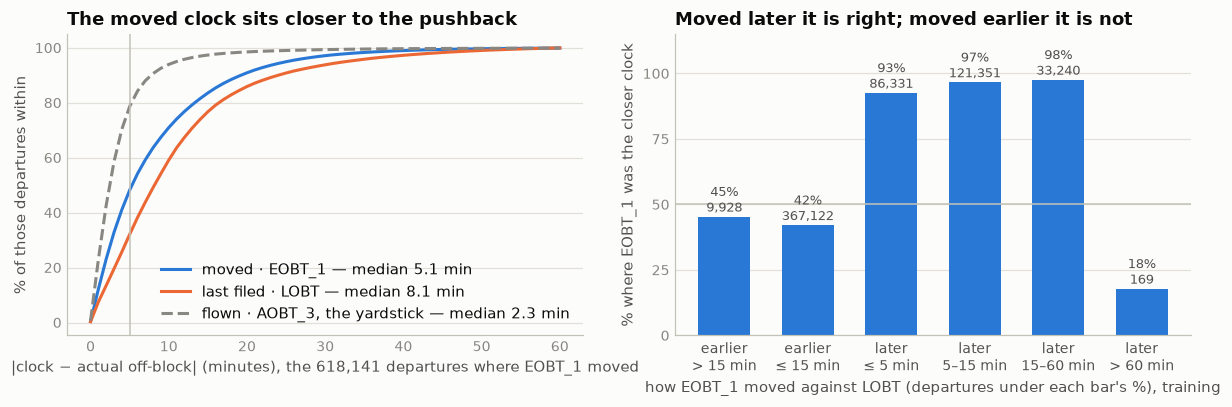

In [6]:
# the picture: how close each clock sat to the actual off-block on the departures where EOBT_1 moved, and how often the move was right by
# its size and sign — the referee's verdict and its mechanism
ref = con.sql(f"SELECT {X_E}/60 e_eobt1, {X_L}/60 e_lobt, {X_A}/60 e_aobt3 FROM {EMOV}").df()
win = con.sql(f"""
    SELECT CASE WHEN d < -15 THEN 'earlier\n> 15 min' WHEN d < 0 THEN 'earlier\n≤ 15 min' WHEN d <= 5 THEN 'later\n≤ 5 min' WHEN d <= 15 THEN 'later\n5–15 min'
                WHEN d <= 60 THEN 'later\n15–60 min' ELSE 'later\n> 60 min' END band, min(d) lo,
           count(*) n, 100.0*count(*) FILTER ({X_E} < {X_L})/count(*) pct
    FROM (SELECT *, epoch(EOBT_1_flt - LOBT_flt)/60 d FROM {EMOV}) GROUP BY 1 ORDER BY lo""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
grid = np.arange(0, 61)
for lab, col, ls, v in [("moved · EOBT_1", BLUE, "-", ref.e_eobt1), ("last filed · LOBT", ORANGE, "-", ref.e_lobt),
                        ("flown · AOBT_3, the yardstick", MUTED, "--", ref.e_aobt3)]:
    a1.plot(grid, [100 * (v <= g).mean() for g in grid], lw=2, color=col, ls=ls, label=f"{lab} — median {v.median():.1f} min")
a1.axvline(5, color=BASELINE, lw=1)
a1.set_title("The moved clock sits closer to the pushback")
a1.set_xlabel(f"|clock − actual off-block| (minutes), the {len(ref):,} departures where EOBT_1 moved")
a1.set_ylabel("% of those departures within")
a1.legend(loc="lower right")
style(a1)
a2.bar(range(len(win)), win.pct, color=BLUE, width=0.62)
a2.axhline(50, color=BASELINE, lw=1)
for i, (p, n) in enumerate(zip(win.pct, win.n)):
    a2.text(i, p + 2, f"{p:.0f}%\n{n:,}", ha="center", fontsize=8.5, color=INK2)
a2.set_xticks(range(len(win)), win.band, color=INK2)
a2.set_ylim(0, 115)
a2.set_yticks(range(0, 101, 25))
a2.set_title("Moved later it is right; moved earlier it is not")
a2.set_xlabel("how EOBT_1 moved against LOBT (departures under each bar's %), training")
a2.set_ylabel("% where EOBT_1 was the closer clock")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

In [7]:
# what the clock buys — §15's honest ladders, fit Jan–Oct → scored Nov+Dec, quantile bins cut on the fit rows per airport, cell support ≥ 30
# else the coarser rung: the gap to takeoff and the pushback delay measured from EOBT_1 against the same forms measured from §15's LOBT; the
# move, its flag and the after-takeoff flag; the two delays together. eob_ladder is §15's lob_ladder with its tables renamed and a per-hub
# readout. Then the two delays on the anchor, hub by hub
con.sql(f"""
    CREATE OR REPLACE TABLE eob_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - EOBT_1_flt) g_eobt1, epoch(MVT_TIME_UTC_mvt - LOBT_flt) g_lobt,
           epoch(AOBT_3_flt - EOBT_1_flt) un_eobt1, epoch(AOBT_3_flt - LOBT_flt) unfiled, epoch(AOBT_3_flt - IOBT_flt) from_initial,
           epoch(EOBT_1_flt - LOBT_flt) mv, epoch(EOBT_1_flt - SCHED_TIME_UTC_mvt) e_sched,
           CASE WHEN EOBT_1_flt IS NULL THEN NULL WHEN EOBT_1_flt != LOBT_flt THEN 1 ELSE 0 END moved,
           CASE WHEN EOBT_1_flt IS NULL THEN NULL WHEN EOBT_1_flt > MVT_TIME_UTC_mvt THEN 1 ELSE 0 END e_after
    FROM {TGT}""")


def eob_ladder(*bins, by_hub=False):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean.
    Returns the holdout RMSE, or one row per airport with by_hub."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}, -1) q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE eob_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM eob_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM eob_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE eob_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM eob_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN eob_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN eob_r{k}.c >= 30 THEN eob_r{k}.m END")
    rmse = f"sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2))"
    if by_hub:
        return con.sql(f"SELECT v.hub, count(*) n, {rmse} rmse FROM eob_b v {' '.join(joins)} WHERE v.is_val GROUP BY 1 ORDER BY 1").df()
    return con.sql(f"SELECT {rmse} FROM eob_b v {' '.join(joins)} WHERE v.is_val").fetchone()[0]


ANC = ("g_aobt3", 20)
n_val = con.sql("SELECT count(*) FROM eob_d WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × takeoff − EOBT_1, 20 bins", (("g_eobt1", 20),)),
                   ("airport × takeoff − LOBT, 20 bins — §15", (("g_lobt", 20),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (ANC,)),
                   ("anchor × AOBT_3 − LOBT, 5 bins — §15's unfiled delay", (ANC, ("unfiled", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 5 bins — the delay against EOBT_1", (ANC, ("un_eobt1", 5))),
                   ("anchor × takeoff − LOBT, 5 bins", (ANC, ("g_lobt", 5))),
                   ("anchor × takeoff − EOBT_1, 5 bins — §9's pair", (ANC, ("g_eobt1", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 10 bins", (ANC, ("un_eobt1", 10))),
                   ("anchor × takeoff − EOBT_1, 10 bins", (ANC, ("g_eobt1", 10))),
                   ("anchor × the move EOBT_1 − LOBT, 5 bins", (ANC, ("mv", 5))),
                   ("anchor × moved flag", (ANC, ("moved", 0))),
                   ("anchor × EOBT_1 − schedule, 5 bins", (ANC, ("e_sched", 5))),
                   ("anchor × EOBT_1-after-takeoff flag", (ANC, ("e_after", 0))),
                   ("anchor × §15's delay × the move, 5 bins", (ANC, ("unfiled", 5), ("mv", 5))),
                   ("anchor × AOBT_3 − EOBT_1 × §15's delay", (ANC, ("un_eobt1", 5), ("unfiled", 5))),
                   ("anchor × AOBT_3 − IOBT (§21) × AOBT_3 − EOBT_1", (ANC, ("from_initial", 5), ("un_eobt1", 5))),
                   ("anchor × AOBT_3 − EOBT_1 × moved flag", (ANC, ("un_eobt1", 5), ("moved", 0)))]:
    print(f"  {name:62s} {eob_ladder(*bins):6.1f}")

print("\nper hub — the anchor, then §15's delay and EOBT_1's on it, 5 bins each (the same Nov+Dec rows):")
ph = eob_ladder(ANC, by_hub=True).rename(columns={"rmse": "anchor"})
ph["lobt_delay"] = eob_ladder(ANC, ("unfiled", 5), by_hub=True).rmse
ph["eobt1_delay"] = eob_ladder(ANC, ("un_eobt1", 5), by_hub=True).rmse
ph["eobt1_gain_over_lobt"] = ph.lobt_delay - ph.eobt1_delay
print(ph.round(1).to_string(index=False))

honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                         357.3


  airport × takeoff − EOBT_1, 20 bins                             290.1
  airport × takeoff − LOBT, 20 bins — §15                         301.2


  airport × takeoff − AOBT_3, 20 bins — §9's anchor               293.5


  anchor × AOBT_3 − LOBT, 5 bins — §15's unfiled delay            261.0


  anchor × AOBT_3 − EOBT_1, 5 bins — the delay against EOBT_1     257.1


...

  anchor × §15's delay × the move, 5 bins                         258.6


  anchor × AOBT_3 − EOBT_1 × §15's delay                          255.1


  anchor × AOBT_3 − IOBT (§21) × AOBT_3 − EOBT_1                  254.8


  anchor × AOBT_3 − EOBT_1 × moved flag                           256.7

per hub — the anchor, then §15's delay and EOBT_1's on it, 5 bins each (the same Nov+Dec rows):


 hub     n  anchor  lobt_delay  eobt1_delay  eobt1_gain_over_lobt
EDDF 35424   250.5       232.1        224.9                   7.2
EDDM 24582   324.0       284.3        276.2                   8.1
EGLL 39319   280.0       258.0        256.1                   2.0
EHAM 38677   228.4       223.5        222.8                   0.7
LEBL 27167   248.0       221.8        220.1                   1.6
LEMD 35404   236.4       220.7        214.4                   6.3
LFPG 38315   343.1       299.9        296.3                   3.6
LIRF 23214   379.4       325.8        314.9                  11.0
LSZH 20624   259.9       235.2        233.2                   2.0
LTFM 44759   347.8       289.7        289.7                   0.0


In [8]:
# on §13's base and on raw labels — the machinery §22 and §26 use (§13's std_rungs: each rung's cell mean where it has ≥ 30 fit rows, else the
# rung before; the anchor in §13's 12 bins, each delay in 5 quantile bins per airport cut on the fit rows, a missing clock its own level). A delay
# either on top of the stand, or under the pier straight after the anchor. The two numbers: all holdout rows · the rows outside §10a's slice
# (Fiumicino, no plan, takeoff ≥ 2 h after the schedule)
con.sql(f"""
    CREATE OR REPLACE TABLE eb_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, ADEP_flt IS NULL no_plan,
           coalesce(ADEP_mvt = 'LIRF' AND ADEP_flt IS NULL AND epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) >= 7200, FALSE) gauge,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor,
           epoch(AOBT_3_flt - EOBT_1_flt) un_e, epoch(AOBT_3_flt - LOBT_flt) un_l, epoch(MVT_TIME_UTC_mvt - EOBT_1_flt) g_e,
           CASE WHEN EOBT_1_flt IS NULL THEN -1 WHEN EOBT_1_flt != LOBT_flt THEN 1 ELSE 0 END moved
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1""")
for tbl, cond in [("eb_t", "y <= 3600"), ("eb_r", "TRUE")]:
    con.sql(f"""
        CREATE OR REPLACE TABLE {tbl} AS
        WITH d AS (SELECT * FROM eb_d WHERE {cond}),
             cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa, quantile_cont(un_e, [0.2,0.4,0.6,0.8]) ce,
                             quantile_cont(un_l, [0.2,0.4,0.6,0.8]) cl, quantile_cont(g_e, [0.2,0.4,0.6,0.8]) cg
                      FROM d WHERE NOT is_val GROUP BY 1)
        SELECT d.*, CASE WHEN anchor IS NULL THEN -1 ELSE list_count(list_filter(qa, x -> x <= anchor)) END q_anc,
               CASE WHEN un_e IS NULL THEN -1 ELSE list_count(list_filter(ce, x -> x <= un_e)) END q_une,
               CASE WHEN un_l IS NULL THEN -1 ELSE list_count(list_filter(cl, x -> x <= un_l)) END q_unl,
               CASE WHEN g_e IS NULL THEN -1 ELSE list_count(list_filter(cg, x -> x <= g_e)) END q_ge
        FROM d JOIN cuts USING (hub)""")
    con.sql(f"CREATE OR REPLACE TABLE {tbl}_wb AS SELECT * FROM {tbl} WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL")


def eb_pred(rungs, tbl):
    """§13's std_rungs on this section's tables: the prediction after the last rung, each cell mean where it has ≥ 30 fit rows, else the rung before."""
    joins, preds = [], []
    for i, keys in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE eb_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN eb_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN eb_s{i}.c >= 30 THEN eb_s{i}.m END")
    return f"coalesce({', '.join(reversed(preds))}, (SELECT avg(y) FROM {tbl} WHERE NOT is_val))", " ".join(joins)


def eb_show(title, rung_sets, tbl):
    print(title)
    for name, rungs in rung_sets:
        pred, joins = eb_pred(rungs, tbl)
        r = con.sql(f"SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (NOT v.gauge)) FROM {tbl} v {joins} WHERE v.is_val").fetchone()
        print(f"    {name:58s} {r[0]:7.1f} · {r[1]:7.1f} s")


H, RW, AN = ["hub"], ["hub", "rwy"], ["hub", "rwy", "q_anc"]
BASE13 = [H, RW, AN, AN + ["pfx"], AN + ["pfx", "stand"]]


def on_top(key):
    return BASE13 + [BASE13[-1] + [key]]


def under_the_pier(*keys):
    """§13's base with the keys inserted straight after the anchor, one rung each, then the pier and the stand."""
    rungs = [H, RW, AN]
    for k in keys:
        rungs.append(rungs[-1] + [k])
    return rungs + [rungs[-1] + ["pfx"], rungs[-1] + ["pfx", "stand"]]


n1 = con.sql("SELECT count(*) FROM eb_t_wb WHERE is_val").fetchone()[0]
eb_show(f"(1) on §13's base — the {n1:,} Nov+Dec departures 1–3,600 s with a runway, a stand and an anchor:", [
    ("§13's base: airport, runway, anchor, pier, stand", BASE13),
    ("+ AOBT_3 − EOBT_1, on top of the stand", on_top("q_une")),
    ("+ AOBT_3 − LOBT (§15), on top of the stand", on_top("q_unl")),
    ("+ takeoff − EOBT_1, on top of the stand", on_top("q_ge")),
    ("+ moved flag, on top of the stand", on_top("moved")),
    ("AOBT_3 − EOBT_1 under the pier", under_the_pier("q_une")),
    ("AOBT_3 − LOBT (§15) under the pier", under_the_pier("q_unl")),
    ("takeoff − EOBT_1 under the pier", under_the_pier("q_ge")),
    ("AOBT_3 − EOBT_1, then §15's delay, under the pier", under_the_pier("q_une", "q_unl"))], "eb_t_wb")
n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (gauge), count(*) FILTER (y > 3600) FROM eb_r WHERE is_val").fetchone()
print()
eb_show(f"(2) raw labels, no ceiling (§14) — all {n2[0]:,} Nov+Dec departures, {n2[1]:,} without a plan, {n2[2]} in §10a's slice, {n2[3]} over an hour:", [
    ("airport (§5)", [H]),
    ("+ the missing-plan flag (§2)", [H, H + ["no_plan"]]),
    ("+ AOBT_3 − EOBT_1 (its ∅ is the missing plan)", [H, H + ["q_une"]]),
    ("+ AOBT_3 − LOBT (§15, the same ∅)", [H, H + ["q_unl"]]),
    ("+ takeoff − EOBT_1", [H, H + ["q_ge"]]),
    ("+ the anchor (§9)", [H, H + ["q_anc"]]),
    ("+ the anchor, then AOBT_3 − EOBT_1", [H, H + ["q_anc"], H + ["q_anc", "q_une"]]),
    ("+ the anchor, then AOBT_3 − LOBT", [H, H + ["q_anc"], H + ["q_anc", "q_unl"]]),
    ("+ the anchor, then takeoff − EOBT_1", [H, H + ["q_anc"], H + ["q_anc", "q_ge"]])], "eb_r")
n3 = con.sql("SELECT count(*), count(*) FILTER (y > 3600) FROM eb_r_wb WHERE is_val").fetchone()
print()
eb_show(f"(3) raw labels on §13's base — the {n3[0]:,} Nov+Dec departures with a runway, a stand and an anchor, {n3[1]} over an hour:", [
    ("§13's base", BASE13),
    ("AOBT_3 − EOBT_1 under the pier", under_the_pier("q_une")),
    ("AOBT_3 − LOBT (§15) under the pier", under_the_pier("q_unl")),
    ("takeoff − EOBT_1 under the pier", under_the_pier("q_ge")),
    ("AOBT_3 − EOBT_1, then §15's delay, under the pier", under_the_pier("q_une", "q_unl"))], "eb_r_wb")

(1) on §13's base — the 324,629 Nov+Dec departures 1–3,600 s with a runway, a stand and an anchor:
    §13's base: airport, runway, anchor, pier, stand             265.5 ·   265.5 s


    + AOBT_3 − EOBT_1, on top of the stand                       258.3 ·   258.3 s


    + AOBT_3 − LOBT (§15), on top of the stand                   259.3 ·   259.3 s
    + takeoff − EOBT_1, on top of the stand                      259.0 ·   259.0 s


    + moved flag, on top of the stand                            265.7 ·   265.7 s
    AOBT_3 − EOBT_1 under the pier                               237.5 ·   237.5 s


    AOBT_3 − LOBT (§15) under the pier                           240.8 ·   240.8 s
    takeoff − EOBT_1 under the pier                              234.1 ·   234.1 s


    AOBT_3 − EOBT_1, then §15's delay, under the pier            237.9 ·   237.9 s

(2) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 58 in §10a's slice, 483 over an hour:
    airport (§5)                                                 496.5 ·   383.0 s
    + the missing-plan flag (§2)                                 475.0 ·   382.0 s
    + AOBT_3 − EOBT_1 (its ∅ is the missing plan)                456.8 ·   359.1 s
    + AOBT_3 − LOBT (§15, the same ∅)                            458.3 ·   361.1 s
    + takeoff − EOBT_1                                           429.3 ·   323.5 s
    + the anchor (§9)                                            428.1 ·   321.8 s
    + the anchor, then AOBT_3 − EOBT_1                           401.8 ·   285.8 s
    + the anchor, then AOBT_3 − LOBT                             404.2 ·   289.3 s
    + the anchor, then takeoff − EOBT_1                          398.2 ·   280.9 s

(3) raw labels on §13's base — the 324,98

    §13's base                                                   286.6 ·   286.6 s
    AOBT_3 − EOBT_1 under the pier                               257.9 ·   257.9 s


    AOBT_3 − LOBT (§15) under the pier                           260.5 ·   260.5 s
    takeoff − EOBT_1 under the pier                              254.6 ·   254.6 s


    AOBT_3 − EOBT_1, then §15's delay, under the pier            257.8 ·   257.8 s


In [9]:
# look both ways — the clock in the scored months against their 2025 twins. The actual off-block is hidden in 2026, so the referee there is
# the flown clock AOBT_3 (§9: a median 52 s from it); first check that this stand-in reproduces the referee's verdict in training, then read
# it hub by hub in January and July of both years
print("the clock in January and July, 2025 against 2026 (all departures; the last two columns: mean |clock − AOBT_3|, minutes):")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(EOBT_1_flt)/count(*), 2) pct_with_eobt1,
           round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt)/count(EOBT_1_flt), 1) pct_moved, round(100.0*count(*) FILTER (EOBT_1_flt > LOBT_flt)/count(EOBT_1_flt), 1) pct_moved_later,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5) FILTER (EOBT_1_flt != LOBT_flt), 1) med_move,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)/60, 0.5), 1) med_takeoff_minus_eobt1, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)/60, 0.9), 1) p90,
           round(quantile_cont(epoch(AOBT_3_flt - EOBT_1_flt)/60, 0.5), 1) med_aobt3_minus_eobt1,
           round(avg(abs(epoch(AOBT_3_flt - EOBT_1_flt)))/60, 2) eobt1_to_aobt3, round(avg(abs(epoch(AOBT_3_flt - LOBT_flt)))/60, 2) lobt_to_aobt3
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

P_E, P_L = "abs(epoch(AOBT_3_flt - EOBT_1_flt))", "abs(epoch(AOBT_3_flt - LOBT_flt))"
print("\nthe stand-in against the real referee — training departures where EOBT_1 moved, % where EOBT_1 is the closer clock:")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER ({P_E} < {P_L})/count(*), 1) pct_closer_to_aobt3,
           round(100.0*count(*) FILTER ({X_E} < {X_L})/count(BLOCK_TIME_UTC_mvt), 1) pct_closer_to_the_actual_off_block
    FROM {T} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt != LOBT_flt""").df().to_string(index=False))

YM = [(2025, 1), (2025, 7), (2026, 1), (2026, 7)]
cols = ", ".join(f"round(100.0*count(*) FILTER (yr = {y} AND mon = {m} AND EOBT_1_flt != LOBT_flt)/nullif(count(EOBT_1_flt) FILTER (yr = {y} AND mon = {m}), 0), 1) moved_{y % 100}_{m:02d}"
                 for y, m in YM)
cols += ", " + ", ".join(f"round(100.0*count(*) FILTER (yr = {y} AND mon = {m} AND EOBT_1_flt != LOBT_flt AND {P_E} < {P_L})"
                         f"/nullif(count(*) FILTER (yr = {y} AND mon = {m} AND EOBT_1_flt != LOBT_flt), 0), 1) closer_{y % 100}_{m:02d}" for y, m in YM)
print("\nper hub, January and July: % of departures where EOBT_1 moved · % of those moves that sit closer to AOBT_3 than LOBT does:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, {cols}
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7))
    GROUP BY 1 ORDER BY 1""").df().fillna("").to_string(index=False))

print("\nParis and Heathrow in July — what changed between the two years (departures with a plan):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, year(MVT_TIME_UTC_mvt) yr, count(*) n, round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt)/count(*), 1) pct_moved,
           round(100.0*count(*) FILTER (EOBT_1_flt > LOBT_flt)/count(*), 1) pct_later, round(100.0*count(*) FILTER (EOBT_1_flt < LOBT_flt)/count(*), 1) pct_earlier,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5) FILTER (EOBT_1_flt != LOBT_flt), 1) med_move,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) med_aobt3_minus_lobt, round(quantile_cont(epoch(AOBT_3_flt - EOBT_1_flt)/60, 0.5), 1) med_aobt3_minus_eobt1,
           round(avg({P_E})/60, 2) eobt1_to_aobt3, round(avg({P_L})/60, 2) lobt_to_aobt3
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND EOBT_1_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) = 7 AND ADEP_mvt IN ('LFPG', 'EGLL')
    GROUP BY 1, 2 ORDER BY 1, 2""").df().to_string(index=False))

the clock in January and July, 2025 against 2026 (all departures; the last two columns: mean |clock − AOBT_3|, minutes):


  yr  mon      n  pct_with_eobt1  pct_moved  pct_moved_later  med_move  med_takeoff_minus_eobt1  p90  med_aobt3_minus_eobt1  eobt1_to_aobt3  lobt_to_aobt3
2025    1 153706           99.07       29.8              9.6      -5.0                     19.8 36.0                    3.0            7.81           8.70
2026    1 152719           98.39       27.8              9.5      -5.0                     21.0 39.5                    4.0            8.62           9.54
2025    7 190713           97.94       31.9             15.9      -1.0                     23.0 42.0                    7.0           10.70          11.85
2026    7 192122           98.52       33.4             17.3       2.0                     21.0 37.0                    4.0            8.50          10.01

the stand-in against the real referee — training departures where EOBT_1 moved, % where EOBT_1 is the closer clock:
     n  pct_closer_to_aobt3  pct_closer_to_the_actual_off_block
618141                 62.7                 

 hub  moved_25_01  moved_25_07  moved_26_01  moved_26_07 closer_25_01 closer_25_07 closer_26_01 closer_26_07
EDDF         33.2         33.8         28.9         31.5         69.2         71.5         66.0         73.0
EDDM         33.5         41.4         31.7         34.3         67.3         65.4         61.2         70.7
EGLL         42.1         45.4         39.2         53.0         70.8         49.8         63.7         38.7
EHAM         28.4         30.8         28.1         31.6         60.9         66.0         62.5         68.6
LEBL         37.3         37.4         37.1         30.5         66.4         58.8         69.6         67.5
LEMD         34.8         34.3         36.4         35.8         73.4         64.7         73.1         62.0
LFPG         26.6         24.2         21.9         46.5         47.0         43.4         60.6         83.2
LIRF         46.9         54.2         46.4         52.1         68.8         73.0         71.2         72.3
LSZH         30.7  

In [10]:
# closing state — the column after §27: nothing of its own repaired; §2's twin layers hand the departures they recover the whole plan block,
# this clock with it. Before → after per file, how often the twins' clock moved against their LOBT, and the final distribution of takeoff − EOBT_1
TWINSE = (f"(SELECT MVT_ID_mvt, EOBT_1_flt eobt1_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, EOBT_1_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (EOBT_1_flt IS NULL) null_before, count(*) FILTER (EOBT_1_flt IS NULL AND eobt1_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(EOBT_1_flt, eobt1_twin) IS NULL) null_after, round(100.0*count(*) FILTER (coalesce(EOBT_1_flt, eobt1_twin) IS NULL)/count(*), 2) pct_null_after,
           round(100.0*count(*) FILTER (EOBT_1_flt != LOBT_flt)/count(EOBT_1_flt), 1) pct_moved_own,
           round(100.0*count(*) FILTER (EOBT_1_flt IS NULL AND eobt1_twin != lobt_twin)/nullif(count(*) FILTER (EOBT_1_flt IS NULL AND eobt1_twin IS NOT NULL), 0), 1) pct_moved_twins,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(EOBT_1_flt, eobt1_twin))/60, 0.1), 1) p10_takeoff_minus_eobt1_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(EOBT_1_flt, eobt1_twin))/60, 0.5), 1) p50,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(EOBT_1_flt, eobt1_twin))/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINSE} w USING (MVT_ID_mvt) LEFT JOIN {TWINS} w2 USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nthe same 1,898 + 479 departures §15's and §21's clocks gained: one recovered plan block carries every clock in it")

     src       n  null_before  filled_by_twins  null_after  pct_null_after  pct_moved_own  pct_moved_twins  p10_takeoff_minus_eobt1_after  p50  p90
training 2085047        22470             1898       20572            0.99           30.0             55.8                           11.1 20.9 36.9
 ranking  344841         5290              479        4811            1.40           30.9             59.3                           11.1 21.0 38.1

the same 1,898 + 479 departures §15's and §21's clocks gained: one recovered plan block carries every clock in it


                               feature        kind  n / levels  pearson_r  spearman_ρ     η
              EOBT_1 epoch — the trend     numeric     2059401      0.011       0.015      
                      takeoff − EOBT_1     numeric     2059401      0.547       0.567      
AOBT_3 − EOBT_1 — the delay against it     numeric     2059401      0.252       0.217      
              EOBT_1 − LOBT — the move     numeric     2059401      0.014       0.012      
                     EOBT_1 − schedule     numeric     2059401      0.030       0.017      
                 moved (EOBT_1 ≠ LOBT) categorical           3                        0.030
              EOBT_1 after the takeoff categorical           3                        0.024
                        EOBT_1 missing categorical           2                        0.007


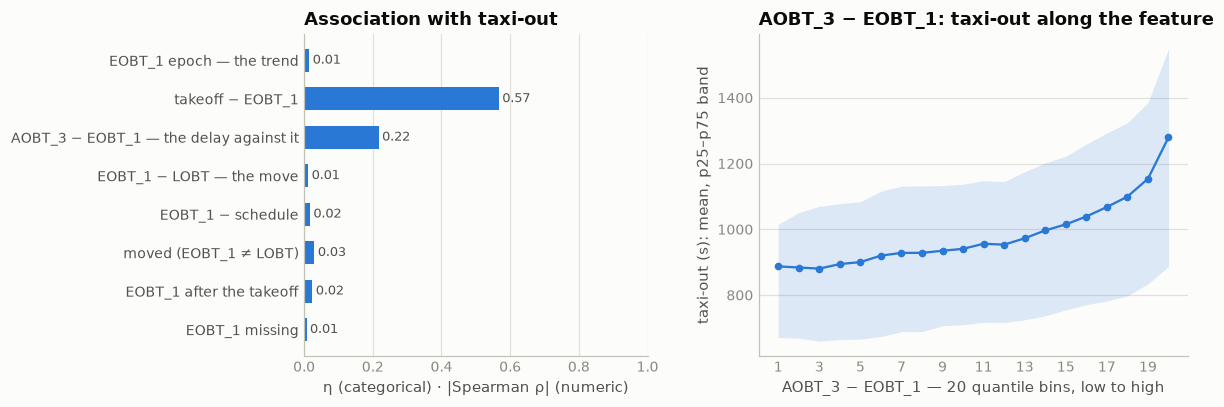

In [11]:
# correlation with the target: the stamp is a calendar, like the plan's other clocks; its model-facing forms are the gap to takeoff, the
# pushback delay measured from it, the move that separates it from §15's clock, its gap to the schedule, and the flags
a = target_assoc([("EOBT_1 epoch — the trend", "num", "epoch(EOBT_1_flt)"),
                  ("takeoff − EOBT_1", "num", "epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)"),
                  ("AOBT_3 − EOBT_1 — the delay against it", "num", "epoch(AOBT_3_flt - EOBT_1_flt)"),
                  ("EOBT_1 − LOBT — the move", "num", "epoch(EOBT_1_flt - LOBT_flt)"),
                  ("EOBT_1 − schedule", "num", "epoch(EOBT_1_flt - SCHED_TIME_UTC_mvt)"),
                  ("moved (EOBT_1 ≠ LOBT)", "cat", "EOBT_1_flt != LOBT_flt"),
                  ("EOBT_1 after the takeoff", "cat", "EOBT_1_flt > MVT_TIME_UTC_mvt"),
                  ("EOBT_1 missing", "cat", "EOBT_1_flt IS NULL")])
assoc_chart(a, "epoch(AOBT_3_flt - EOBT_1_flt)", kind="num", title="AOBT_3 − EOBT_1")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The same rows as the plan's other clocks, exactly** | null on 22,470 training departures (22,424 without a plan, 46 with an empty block behind a `FLIGHT_ID`) and 5,290 in the ranking file (5,283 + 7); on arrivals 15,449 and 2,552. `only_one_of_eobt1_lobt` and `only_one_of_eobt1_aobt3` are 0 in all four file × phase groups | its nulls are §2's missing plan; there is no coverage to gain, and no row where this clock could stand in for another |
| **The one plan clock that moves — on 30% of departures, earlier more often than later** | equal to `LOBT_flt` on 70.03% of the 2,062,577 training departures with a plan; moved on **618,141**, earlier on 18.28%, later on 11.69%. The move: p01 −20, p10 −10, median −4, p90 +10, p99 +35 min. Where the plan was refiled it follows: `EOBT_1` = `LOBT_flt` on 11,085 of 11,267. Equal to `IOBT_flt` on 69.5%, to the schedule on 55.5% | the clock starts at the plan's filed off-block and is moved on the day. §15's and §21's columns never carry that revision; this one does |
| **The move is an estimate of its own, not the flown clock copied in** | equal to `AOBT_3` on 5.28% of moved rows (`LOBT_flt` on the same rows 2.84%, unmoved rows 4.91%), with `AOBT_3` on the minute 97.7% of the time. The moved stamp is never off the minute (0.0%). On the 5-minute grid: 59.6% moved against 96.0% unmoved. 57.1% of moves are a multiple of 5 min: −5 min 16.6% of moves, −10 14.5%, +10 8.5%, +5 7.8%, −15 3.8% | a forecast set in round steps, so it can be wrong in either direction, which is what the referee is for. Nothing in it is the actual time |
| **A per-hub habit — and Istanbul never moves it** | moved share LIRF 49.7%, EGLL 41.4%, LEBL 36.2%, EDDM 34.4%, LEMD 34.1%, EDDF 31.5%, EHAM 30.5%, LSZH 30.4%, LFPG 25.6%, **LTFM 0.0%**. The commonest step is the hub's own: −5 min at EDDF (19.0% of its moves) and EGLL (28.4%), −10 at EDDM, EHAM and LEBL, −15 at LFPG (18.2%), +5 at LSZH, +8 at LIRF, +10 at LEMD (21.8%). LEMD is the only hub that moves it later more often than earlier (55.5% of moves) | the signature of an estimate the departure airport feeds on the day, not one the airline files: step sizes per hub, and one hub that sends none. At LTFM the column is `LOBT_flt` exactly |
| **Where it moved, it is the better clock** | on the 618,141 moved departures, against the actual off-block: `EOBT_1` closer **388,321**, `LOBT_flt` 229,058, 762 ties — **62.8%**. Mean error 8.18 min against 10.95, median 5.1 against 8.1, within 5 min **48.2% against 32.1%**. The flown `AOBT_3` stays far ahead: 3.75 mean, 2.3 median, 78.6% within 5 | §21's referee with the opposite answer. The refile before the day moved the clock away from the pushback (the initial clock was right on 73.9%). The move on the day moves it towards the pushback. What changes on the day carries news |
| **Moved later it is right; moved earlier it is not** | by the move: later by ≤ 5 min 86,331 rows, `EOBT_1` closer on **92.5%**; later by 5–15 min 121,351, 96.6%; later by 15–60 min 33,240, 97.5%; later by more than an hour 169 rows, 17.8% (mean label 3,122 s). Earlier by ≤ 15 min 367,122 rows, 59.4% of all moves, **42.0%**; earlier by more than 15, 9,928, 45.3% | a later clock is a delay being reported, and it is almost always real. An earlier clock is right less often than not, and it is the common case |
| **It moves towards an off-plan pushback, and away from an on-time one** | by how far the actual off-block fell from `LOBT_flt`: left 5–15 min early, moved on 66.1%, 97.1% of moves towards it; more than 15 early, 56.3% and 90.2%; **within ±5 min, 21.8% moved and 28.4% of moves towards it** (median move −5); 5–15 late 25.3% and 62.7%; 15–30 late 40.2% and 82.0%; 30–60 late 52.7% and 88.2% | 44.1% of departures leave within five minutes of the plan, and a fifth of those still have their clock pulled a step, mostly the wrong way — consistent with the earlier band's 42%. The sign and size of the move carry its reliability, and the delay measured from the clock carries both |
| **Diluted over the file, but not to nothing** | on all 2,062,577 departures: mean error 7.76 min against `LOBT_flt`'s 8.59, within 5 min 48.9% against 44.1% | about 50 s of clock accuracy per departure, against the 1.2 s §21's initial clock was worth |
| **After the takeoff on a third as many rows** | `EOBT_1` after the takeoff on 5,298 training departures, `LOBT_flt` on 17,133; after `AOBT_3` 24.7% against 29.5% | most of §15's stale plans of early leavers no longer sit after the takeoff on this clock |
| **On the anchor the moved clock beats §15's by 4 s, in every form** | airport 357.3 → × takeoff − `EOBT_1` **290.1** (§15's `LOBT_flt` 301.2, §9's anchor 293.5: the only plan clock that locates the target better than `AOBT_3` at 20 bins). On the anchor: × `AOBT_3` − `EOBT_1` **257.1** against §15's `AOBT_3` − LOBT 261.0; × takeoff − `EOBT_1` **252.4** against takeoff − LOBT 256.7; at 10 bins 252.7 and 247.9. The two delays together 255.1; §21's `AOBT_3` − IOBT with this one 254.8 | the same 3.9–4.3 s at each step, and 2.0 s more from reading §15's delay beside this one. takeoff − `EOBT_1` is the stronger key because it also refines the anchor inside its bins (§9: the anchor keeps paying for resolution) |
| **The move itself is worth nothing; its value is inside the delay** | on the anchor (293.5): the move in 5 bins 292.8, the moved flag 293.2, `EOBT_1` − schedule 291.5, the after-takeoff flag 293.3. On §15's delay the move adds 2.4 s (258.6); replacing the clock gains 3.9. On this delay the flag adds 0.4 s (256.7) | build the delay from the clock, not the move from the two clocks |
| **On §13's base the delay is worth 28 s — read under the pier, not on top of the stand** | §13's base 265.5. On top of the stand: `AOBT_3` − `EOBT_1` 258.3, `AOBT_3` − LOBT 259.3, takeoff − `EOBT_1` 259.0, the moved flag 265.7. Inserted straight after the anchor, before the pier: `AOBT_3` − `EOBT_1` **237.5**, `AOBT_3` − LOBT 240.8, takeoff − `EOBT_1` **234.1**; §15's delay under this one 237.9 | the largest step any column has taken off §13's base: 24.7 s for §15's form, 28.0 s for this one. The delay describes the flight, not the stand. Under the pier it corrects the anchor for every stand; after the stand it can only split stand cells. On this base §15's delay adds nothing once this one is in (−0.4 s) |
| **Raw labels agree** | all 327,968 Nov+Dec departures: airport 496.5 → the missing-plan flag 475.0 → `AOBT_3` − `EOBT_1` 456.8 (LOBT's 458.3), takeoff − `EOBT_1` 429.3; the anchor 428.1 → then `AOBT_3` − `EOBT_1` **401.8** against 404.2, takeoff − `EOBT_1` 398.2; outside §10a's 58 slice rows 285.8 against 289.3. On §13's base (324,988 rows, 359 over an hour): 286.6 → 257.9 against 260.5, takeoff − `EOBT_1` 254.6 | the same 2.4–3.5 s on the score's own labels, so it is not a window artefact. The clock is missing exactly where the plan is, so it does nothing for §10a's slice or the plan-less part of §14's tail |
| **The gain sits where the clock moves** | anchor → §15's delay → this one, per hub: LIRF 325.8 → 314.9 (**11.0 s**), EDDM 284.3 → 276.2 (8.1), EDDF 7.2, LEMD 6.3, LFPG 3.6, EGLL 2.0, LSZH 2.0, LEBL 1.6, EHAM 0.7, **LTFM 289.7 → 289.7 (0.0)** | the control is built in: at the one hub whose clock never moves, the two delays are the same column, and the ladder gives the same number to the decimal |
| **2026: the move means something different at two hubs** | the stand-in referee, closer to `AOBT_3` instead of to the hidden off-block, gives 62.7% on training's moved rows against the real referee's 62.8%. **LFPG**: moved in July 24.2% → **46.5%**, right 43.4% → **83.2%** (January 47.0% → 60.6%). Its July moves turned from earlier (17.5% of departures, median −6 min) to later (35.1%, median +10); mean gap to `AOBT_3` 14.05 → **5.65 min** against LOBT's 13.90 → 9.80. **EGLL** the other way: July moved 45.4% → 53.0%, right 49.8% → **38.7%** (January 70.8% → 63.7%), earlier on 43.3% of departures, and now further from `AOBT_3` than LOBT is (9.14 against 8.86 min). The other hubs move by at most 8.7 points (LEBL July 58.8% → 67.5%) | a model fitted on 2025 learns LFPG's delay against this clock as a noisy one and meets a sharp one in July 2026, and EGLL's the reverse. Across both scored months the clock still sits closer to `AOBT_3` than LOBT does (January 8.62 against 9.54 min, July 8.50 against 10.01), so the column is not worse overall. What changed is its meaning per hub, and §15's filed clock is the reading whose meaning did not change |
| **2026 sits on 2025 otherwise** | with the clock: January 99.07% → 98.39%, July 97.94% → 98.52%; moved January 29.8% → 27.8%, July 31.9% → 33.4% (later 15.9% → 17.3%, median move −1 → +2 min); takeoff − `EOBT_1` median January 19.8 → 21.0 min (p90 36.0 → 39.5), July 23.0 → 21.0 (42.0 → 37.0) | the January-later / July-earlier drift §10, §15 and §21 saw, on this clock too. July's shift towards later moves comes with LFPG's change above |
| Marginal | takeoff − `EOBT_1` r 0.547, **ρ 0.567** (§15's takeoff − LOBT 0.507); `AOBT_3` − `EOBT_1` r 0.252, ρ 0.217 (§15's delay r 0.230); the move r 0.014; `EOBT_1` − schedule 0.030; the moved flag η 0.030, after-the-takeoff η 0.024, missing η 0.007; the stamp itself r 0.011 | the first plan clock whose derived forms read the target differently from `LOBT_flt`'s: the move adds 0.06 to the gap's Spearman ρ |

**Decisions**

| issue | decision | why |
|---|---|---|
| the form a model reads | **`AOBT_3` − `EOBT_1` and takeoff − `EOBT_1`, per airport, beside §15's `AOBT_3` − LOBT, not in place of it** | 257.1 and 252.4 against 261.0 and 256.7 on the anchor; 237.5 against 240.8 under §13's pier; 401.8 against 404.2 on raw labels. The pair is 2.0 s better than either on the anchor, and §15's clock is the reading that kept its meaning at LFPG and EGLL in 2026 |
| the move `EOBT_1` − LOBT, a moved flag, `EOBT_1` − schedule, the after-takeoff flag | not built | 292.8, 293.2, 291.5 and 293.3 on the anchor (293.5); the flag 265.7 on §13's base (265.5) |
| the 2026 change at LFPG and EGLL | recorded, not corrected | the stand-in referee shows the direction of the change, but with no labels it cannot say what the change costs in taxi-out. The robustness answer is the pair of delays above |
| where the delay sits in a group-mean ladder | straight after the anchor, before the pier | 237.5 against 258.3 on top of the stand. A tree model reads it wherever it is; later sections quoting §13's base should say which base they use |
| §21's question: does the day's move repeat the refile's error | no, the opposite | the refile left the initial clock closer on 73.9% (§21); the day's move is closer on 62.8%, and on 92.5–97.5% when it moves later |
| the twin layers' clock | adopted: the same 1,898 training and 479 ranking departures as §15 and §21 | one recovered plan block carries every clock in it (§2). The twins' clock moved on 55.8% / 59.3% of them against 30.0% / 30.9% for the rest: they are §2b's late flights |

**State after §27** — the twin layers of §2, departures:

| `EOBT_1_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

takeoff − `EOBT_1` after, minutes: p10 11.1 / 11.1, median 20.9 / 21.0, p90 36.9 / 38.1 (training / ranking).

**Use in modeling.** This is the plan clock to read on the day. Feed the pushback delay measured from it,
`AOBT_3` − `EOBT_1`, and its gap to takeoff, takeoff − `EOBT_1`, per airport, with §2's twin layers' clock
where the raw one is missing, beside §15's `AOBT_3` − LOBT rather than instead of it. Its forms are
3.9–4.3 s better on the anchor, 3.3 s under §13's pier and 2.4 s on raw labels; the pair is 2.0 s better
than either on the anchor. §15's clock is also the one whose meaning held in 2026, when Paris's moves turned
from a coin toss into right on 83% and Heathrow's went the other way. Do not build the move, a moved flag or
the gap to the schedule: what the move knows is already in the delay. At Istanbul the two delays are one
column. In a group-mean ladder the delay goes straight after the anchor, where it takes §13's base from
265.5 to 237.5 s. The closing matrix reads the twin layers' clock as `TWINSE`. The column enters as epoch
seconds with those 1,898 + 479 filled in: 1.00 with `LOBT_flt`, `IOBT_flt` and the three movement clocks,
0.01 with the target, the sixth copy of the calendar.

## 28 · `ARVT_1_flt` — the landing the plan expected

The last of the plan's M1 pair: the **arrival time** of the Network Manager's flight-plan-based trajectory,
the model whose off-block clock is §27's `EOBT_1_flt`. On a departure row it is the time the plan expected our
flight to arrive at the far end; on an arrival row, the time it expected the flight to arrive at our hub.
Nothing in the column says which arrival event that is. An arrival row at a hub carries both the landing and
the in-block, and the flown twin `ARVT_3_flt` is within seconds of one of them, so the census starts there.

On departures the column's own form is the **planned trip**, `ARVT_1` − `EOBT_1`, from off-block to landing.
That trip contains the taxi-out the plan assumed before takeoff, and the flown landing separates the two: planned trip −
(`ARVT_3` − takeoff) is the plan's taxi-out plus its airborne error. The section uses `ARVT_3` only as that
tool; the flown landing's own forms belong to its section.

| step | question | what came out |
|---|---|---|
| **census** | present where; on which grid; which arrival event | on **exactly** the rows `EOBT_1_flt` and `ARVT_3_flt` are; on true seconds; the **landing**: `ARVT_3` is within 2 min of the landing on 98.5% of arrivals, the in-block on 2.5% |
| **the planned trip** | what it is, and which off-block clock it starts from | median 118.5 min; it starts from §27's moved clock, not from `LOBT_flt` (72.3% of moved days) |
| **the plan's taxi-out** | the taxi-out inside the trip, against the one that happened | a median 16.0 min on 315,269 flights between hubs, where the other hub's arrival row gives the actual landing; hub by hub it sits near the median taxi-out, and runway by runway it follows it: r 0.824 within the hub |
| **signal** | honest ladders; on §13's base; on raw labels; the planned arrival stream | 357.3 → 342.7 (trip) and 340.6 (taxi-out) alone; 253.7 on §27's delay against 257.1; **nothing on §13's base** (265.7, 265.9 against 265.5); planned arrivals within ±15 min 292.8 against the actual count's 292.6 |
| **look both ways** | 2026 against 2025 | the median trip is 3–4 min longer, but on routes flown in both years only 0.3 / 0.7 min, most of it the plan's taxi-out (+0.3 / +0.5) |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures as the plan's other clocks |

In [4]:
# census by file × phase: present on exactly the rows the plan's other clocks are, and on true seconds. Then which event it times: an
# arrival row at a hub carries both the landing (MVT_TIME_UTC_mvt, §8) and the in-block (BLOCK_TIME_UTC_mvt), and the flown twin ARVT_3
# shows which of the two this column family means. Then the departures' planned trip, and which of the plan's off-block clocks it hangs from
print("ARVT_1_flt by file × phase — and the rows that carry it without EOBT_1_flt or ARVT_3_flt, or one of those without it:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ARVT_1_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (ARVT_1_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           count(*) FILTER ((ARVT_1_flt IS NULL) != (EOBT_1_flt IS NULL)) only_one_of_arvt1_eobt1,
           count(*) FILTER ((ARVT_1_flt IS NULL) != (ARVT_3_flt IS NULL)) only_one_of_arvt1_arvt3,
           round(100.0*count(*) FILTER (extract(second FROM ARVT_1_flt) = 0)/count(ARVT_1_flt), 2) pct_on_minute,
           count(*) FILTER (ARVT_1_flt <= EOBT_1_flt) not_after_eobt1,
           count(DISTINCT ARVT_1_flt) n_unique, strftime(min(ARVT_1_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(ARVT_1_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))


def qline(name, expr, src, where):
    q, n = con.sql(f"SELECT quantile_cont({expr}, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]), count({expr}) FROM {src} WHERE {where}").fetchone()
    print(f"  {name:44s} n = {n:>9,}   " + "  ".join(f"{x:7.1f}" for x in q))


print("\narrivals at the ten hubs — which event the column family times (training, minutes; p01 / p10 / p25 / p50 / p75 / p90 / p99):")
for name, expr in [("landing − ARVT_3, the flown twin", "epoch(MVT_TIME_UTC_mvt - ARVT_3_flt)/60"),
                   ("in-block − ARVT_3", "epoch(BLOCK_TIME_UTC_mvt - ARVT_3_flt)/60"),
                   ("landing − ARVT_1", "epoch(MVT_TIME_UTC_mvt - ARVT_1_flt)/60"),
                   ("in-block − ARVT_1", "epoch(BLOCK_TIME_UTC_mvt - ARVT_1_flt)/60")]:
    qline(name, expr, T, "PHASE_mvt = 'ARR'")
print(con.sql(f"""
    SELECT round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt)) <= 120)/count(ARVT_3_flt), 1) pct_landing_within_2min_of_arvt3,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - ARVT_3_flt)) <= 120)/count(ARVT_3_flt), 1) pct_inblock_within_2min_of_arvt3,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - ARVT_1_flt)) <= 300)/count(ARVT_1_flt), 1) pct_landing_within_5min_of_arvt1,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - ARVT_1_flt)) <= 300)/count(ARVT_1_flt), 1) pct_inblock_within_5min_of_arvt1
    FROM {T} WHERE PHASE_mvt = 'ARR'""").df().to_string(index=False))

print("\ndepartures with a plan — the planned trip and its flown twin (training, minutes):")
for name, expr in [("ARVT_1 − EOBT_1, the planned trip", "epoch(ARVT_1_flt - EOBT_1_flt)/60"),
                   ("ARVT_1 − takeoff", "epoch(ARVT_1_flt - MVT_TIME_UTC_mvt)/60"),
                   ("ARVT_3 − AOBT_3, the flown trip", "epoch(ARVT_3_flt - AOBT_3_flt)/60"),
                   ("flown trip − planned trip", "epoch((ARVT_3_flt - AOBT_3_flt) - (ARVT_1_flt - EOBT_1_flt))/60")]:
    qline(name, expr, T, "PHASE_mvt = 'DEP' AND ARVT_1_flt IS NOT NULL")

print("\nwhich off-block clock the planned landing hangs from — the trip measured from EOBT_1 and from LOBT, against the same flight's usual trip")
print("(its median over the days §27's clock did not move: callsign × destination × type × month, ≥ 5 such days), seconds:")
print(con.sql(f"""
    WITH g AS (SELECT EOBT_1_flt != LOBT_flt moved, epoch(ARVT_1_flt - EOBT_1_flt) d_e, epoch(ARVT_1_flt - LOBT_flt) d_l,
                      median(epoch(ARVT_1_flt - EOBT_1_flt)) FILTER (EOBT_1_flt = LOBT_flt) OVER w usual,
                      count(*) FILTER (EOBT_1_flt = LOBT_flt) OVER w n_usual
               FROM {T} WHERE PHASE_mvt = 'DEP' AND ARVT_1_flt IS NOT NULL
               WINDOW w AS (PARTITION BY ADEP_mvt, CALLSIGN_flt, ADES_flt, AIRCRAFT_TYPE_flt, month(MVT_TIME_UTC_mvt)))
    SELECT CASE WHEN moved THEN 'EOBT_1 moved' ELSE 'EOBT_1 not moved' END eobt1, count(*) n,
           round(quantile_cont(abs(d_e - usual), 0.5)) med_gap_trip_from_eobt1, round(quantile_cont(abs(d_l - usual), 0.5)) med_gap_trip_from_lobt,
           round(100.0*count(*) FILTER (abs(d_e - usual) < abs(d_l - usual))/count(*), 1) pct_eobt1_closer
    FROM g WHERE n_usual >= 5 GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

ARVT_1_flt by file × phase — and the rows that carry it without EOBT_1_flt or ARVT_3_flt, or one of those without it:


     src  ph       n  n_null  no_plan  null_with_an_id  only_one_of_arvt1_eobt1  only_one_of_arvt1_arvt3  pct_on_minute  not_after_eobt1  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506             6943                        0                        0           1.69                0   1983935 2025-01-01 02:21 2026-01-01 01:15
training DEP 2085047   22470    22424               46                        0                        0           1.70                0   1981546 2025-01-01 02:47 2026-01-01 12:53
 ranking ARR  344693    2552     1409             1143                        0                        0           1.76                0    328466 2026-01-01 01:50 2026-08-01 03:35
 ranking DEP  344841    5290     5283                7                        0                        0           1.78                0    326574 2026-01-01 02:44 2026-08-01 12:33

arrivals at the ten hubs — which event the column family times (training, minutes; p01 / p10 /

  landing − ARVT_3, the flown twin             n = 2,067,301      -2.2     -1.0     -0.5     -0.1      0.1      0.4      1.0


  in-block − ARVT_3                            n = 2,067,300       1.5      3.5      5.1      7.9     11.0     15.0     25.9


  landing − ARVT_1                             n = 2,067,301     -26.4    -12.2     -4.4      4.2     14.1     26.2     66.5


...

  ARVT_1 − EOBT_1, the planned trip            n = 2,062,577      41.8     60.7     78.8    118.5    203.7    530.4    749.6


  ARVT_1 − takeoff                             n = 2,062,577      16.0     40.2     58.7     96.9    180.0    502.9    722.7


  ARVT_3 − AOBT_3, the flown trip              n = 2,062,577      40.3     60.5     78.4    118.6    205.8    530.1    751.0


  flown trip − planned trip                    n = 2,062,577     -18.2     -8.6     -4.2     -0.1      3.9      8.2     21.0

which off-block clock the planned landing hangs from — the trip measured from EOBT_1 and from LOBT, against the same flight's usual trip
(its median over the days §27's clock did not move: callsign × destination × type × month, ≥ 5 such days), seconds:


           eobt1       n  med_gap_trip_from_eobt1  med_gap_trip_from_lobt  pct_eobt1_closer
EOBT_1 not moved 1139387                    184.0                   184.0               0.0
    EOBT_1 moved  398399                    225.0                   480.0              72.3


In [5]:
# the plan's taxi-out: the planned trip runs from off-block to landing, so it contains the taxi-out the plan assumed. On flights between two
# of the ten hubs the other hub's arrival row holds the actual landing, so planned trip − actual airborne time isolates that assumption (plus
# the plan's airborne error). The flown landing ARVT_3 gives the same split on every departure: PTAXI is that form, used below as a tool
PTAXI = "(epoch(ARVT_1_flt - EOBT_1_flt) - epoch(ARVT_3_flt - MVT_TIME_UTC_mvt))"
IH = f"""(SELECT d.ADEP_mvt hub, d.TAXITIME_SEC_mvt y, d.ARVT_1_flt = a.ARVT_1_flt same_plan,
                 epoch(a.MVT_TIME_UTC_mvt - d.ARVT_1_flt) land_minus_arvt1, epoch(a.MVT_TIME_UTC_mvt - d.ARVT_3_flt) land_minus_arvt3,
                 epoch(d.ARVT_1_flt - d.EOBT_1_flt) - epoch(a.MVT_TIME_UTC_mvt - d.MVT_TIME_UTC_mvt) plan_taxi_ih
          FROM {T} d JOIN {T} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt AND a.PHASE_mvt = 'ARR'
          WHERE d.PHASE_mvt = 'DEP' AND d.ARVT_1_flt IS NOT NULL)"""
print("flights between two hubs — the departure's plan against the other hub's arrival row (training):")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (same_plan)/count(*), 2) pct_same_arvt1_on_both_rows,
           round(quantile_cont(land_minus_arvt1, 0.5)) med_landing_minus_arvt1_s, round(quantile_cont(land_minus_arvt3, 0.5)) med_landing_minus_arvt3_s,
           round(avg(abs(land_minus_arvt3))) mean_abs_landing_minus_arvt3_s, round(100.0*count(*) FILTER (abs(land_minus_arvt3) <= 60)/count(*), 1) pct_arvt3_within_1min,
           round(quantile_cont(plan_taxi_ih/60, 0.5), 1) med_plan_taxi_min,
           round(corr(plan_taxi_ih, y) FILTER (y BETWEEN 1 AND 3600), 3) r_with_label_1_3600
    FROM {IH}""").df().to_string(index=False))

print("\nthe plan's taxi-out per hub — on flights between hubs (actual landing) and on every departure (PTAXI, the flown landing); label 1–3,600 s, minutes:")
print(con.sql(f"""
    WITH a AS (SELECT ADEP_mvt hub, count(*) n, quantile_cont({PTAXI}/60, 0.1) p10, quantile_cont({PTAXI}/60, 0.5) p50, quantile_cont({PTAXI}/60, 0.9) p90,
                      quantile_cont(TAXITIME_SEC_mvt/60, 0.5) med_label, corr({PTAXI}, TAXITIME_SEC_mvt) r
               FROM {TGT} WHERE ARVT_1_flt IS NOT NULL GROUP BY 1),
         b AS (SELECT hub, count(*) n_ih, quantile_cont(plan_taxi_ih/60, 0.5) p50_ih, corr(plan_taxi_ih, y) r_ih FROM {IH} WHERE y BETWEEN 1 AND 3600 GROUP BY 1)
    SELECT hub, n_ih, round(p50_ih, 1) med_plan_taxi_between_hubs, round(r_ih, 3) r_between_hubs, n, round(p10, 1) ptaxi_p10, round(p50, 1) ptaxi_p50,
           round(p90, 1) ptaxi_p90, round(med_label, 1) med_label, round(r, 3) r_ptaxi
    FROM a JOIN b USING (hub) ORDER BY hub""").df().to_string(index=False))

print("\nit knows the runway — hub × departure runway, runways with ≥ 5,000 training departures 1–3,600 s (minutes):")
rw = con.sql(f"""
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n, avg({PTAXI})/60 mean_ptaxi, avg(TAXITIME_SEC_mvt)/60 mean_label
    FROM {TGT} WHERE ARVT_1_flt IS NOT NULL AND RUNWAY_mvt IS NOT NULL GROUP BY 1, 2 HAVING count(*) >= 5000 ORDER BY 1, n DESC""").df()
print(rw[rw.hub.isin(["EHAM", "EGLL", "LFPG"])].round(1).to_string(index=False))
print(f"  across all {len(rw)} hub × runway cells: r(mean PTAXI, mean label) = {rw.mean_ptaxi.corr(rw.mean_label):.3f}; "
      f"within the hub (both centred on the hub's mean): r = {(rw.mean_ptaxi - rw.groupby('hub').mean_ptaxi.transform('mean')).corr(rw.mean_label - rw.groupby('hub').mean_label.transform('mean')):.3f}")

flights between two hubs — the departure's plan against the other hub's arrival row (training):


     n  pct_same_arvt1_on_both_rows  med_landing_minus_arvt1_s  med_landing_minus_arvt3_s  mean_abs_landing_minus_arvt3_s  pct_arvt3_within_1min  med_plan_taxi_min  r_with_label_1_3600
315269                        99.99                      291.0                       -5.0                            29.0                   87.0               16.0                 0.23

the plan's taxi-out per hub — on flights between hubs (actual landing) and on every departure (PTAXI, the flown landing); label 1–3,600 s, minutes:


 hub  n_ih  med_plan_taxi_between_hubs  r_between_hubs      n  ptaxi_p10  ptaxi_p50  ptaxi_p90  med_label  r_ptaxi
EDDF 34695                        16.4           0.182 228115        8.5       16.9       25.3       13.9    0.253
EDDM 30360                        13.0           0.099 166276        5.9       13.2       22.0       12.9    0.159
EGLL 38983                        21.5           0.221 237449       12.4       21.2       30.3       22.0    0.240
EHAM 35805                        13.3           0.236 243794        4.6       13.0       21.9       12.4    0.369
LEBL 32533                        14.3           0.140 177837        6.8       16.5       28.3       15.1    0.334
LEMD 33791                        19.7           0.199 211295        8.7       17.3       26.8       16.4    0.252
LFPG 34151                        16.1           0.168 235375        7.3       16.0       27.6       15.9    0.278
LIRF 28529                        14.7           0.014 157994        8.8       1

 hub rwy     n  mean_ptaxi  mean_label
EGLL 09R 87057        20.6        22.2
EGLL 27R 76185        21.9        23.1
EGLL 27L 74099        21.2        22.5
EHAM  24 84173        10.3        11.1
EHAM 36L 58132        17.8        18.0
EHAM 18L 55086        12.8        12.2
EHAM 36C 30640        12.3        12.1
EHAM  09  7780        14.7        13.9
LFPG 08L 74096        16.8        16.2
LFPG 26R 70360        15.8        16.5
LFPG 09R 31667        17.4        17.8
LFPG 27L 26397        16.5        16.4
LFPG 27R 21052        18.7        18.3
LFPG 09L 11382        18.8        18.7
  across all 37 hub × runway cells: r(mean PTAXI, mean label) = 0.894; within the hub (both centred on the hub's mean): r = 0.824


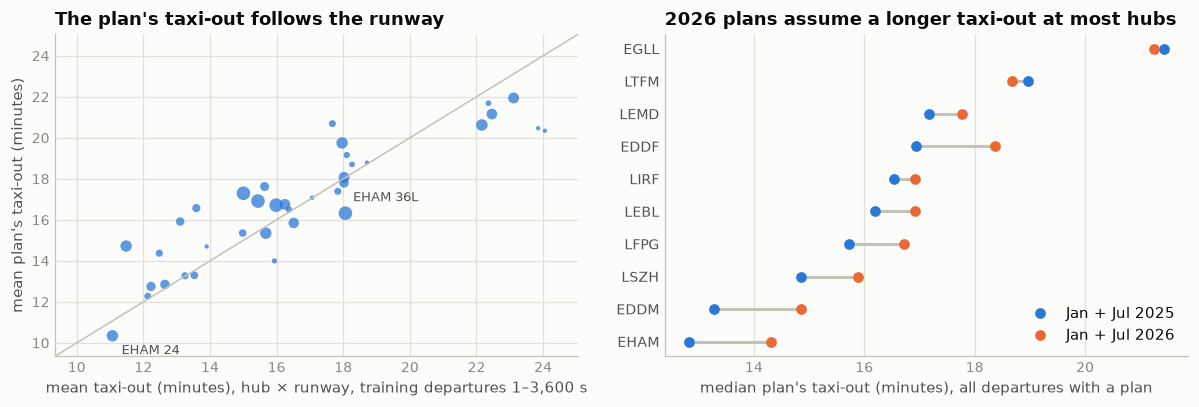

In [6]:
# the picture: the plan's taxi-out against the taxi-out that happened, runway by runway; and the same assumption in the scored months
# against 2025, hub by hub
pt = con.sql(f"""
    SELECT ADEP_mvt hub, year(MVT_TIME_UTC_mvt) yr, quantile_cont({PTAXI}/60, 0.5) med_ptaxi
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ARVT_1_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2""").df()
pt = pt.pivot(index="hub", columns="yr", values="med_ptaxi").sort_values(2025)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
lim = (min(rw.mean_label.min(), rw.mean_ptaxi.min()) - 1, max(rw.mean_label.max(), rw.mean_ptaxi.max()) + 1)
a1.plot(lim, lim, color=BASELINE, lw=1)
a1.scatter(rw.mean_label, rw.mean_ptaxi, s=np.clip(rw.n / 1500, 8, 80), color=BLUE, alpha=0.75, lw=0)
for _, r in rw[(rw.hub == "EHAM") & rw.rwy.isin(["24", "36L"])].iterrows():
    a1.annotate(f"EHAM {r.rwy}", (r.mean_label, r.mean_ptaxi), xytext=(6, -12), textcoords="offset points", fontsize=8.5, color=INK2)
a1.set_xlim(lim)
a1.set_ylim(lim)
a1.set_title("The plan's taxi-out follows the runway")
a1.set_xlabel("mean taxi-out (minutes), hub × runway, training departures 1–3,600 s")
a1.set_ylabel("mean plan's taxi-out (minutes)")
style(a1, x_grid=True)
yy = np.arange(len(pt))
a2.hlines(yy, pt[2025], pt[2026], color=BASELINE, lw=2)
a2.plot(pt[2025], yy, "o", color=BLUE, ms=6, label="Jan + Jul 2025")
a2.plot(pt[2026], yy, "o", color=ORANGE, ms=6, label="Jan + Jul 2026")
a2.set_yticks(yy, pt.index, color=INK2)
a2.set_title("2026 plans assume a longer taxi-out at most hubs")
a2.set_xlabel("median plan's taxi-out (minutes), all departures with a plan")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

In [7]:
# what the column buys — §15's honest ladders, fit Jan–Oct → scored Nov+Dec, quantile bins cut on the fit rows per airport, cell support ≥ 30
# else the coarser rung: the planned trip, the destination (§18's column) it mostly measures, the plan's taxi-out, the planned landing against
# the takeoff; on the airport mean, on §9's anchor and on §27's delay. Then the arrival side: arrivals planned (ARVT_1) and actual (landing)
# within ±15 min of the takeoff, §8's window, counted by ASOF lookups. arv_ladder is §15's lob_ladder with its tables renamed and levels read as text
for name, t in [("arr_act", "MVT_TIME_UTC_mvt"), ("arr_plan", "ARVT_1_flt")]:
    con.sql(f"""CREATE OR REPLACE TABLE {name} AS
                SELECT ADES_mvt hub, {t} t, row_number() OVER (PARTITION BY ADES_mvt ORDER BY {t}) r FROM {T} WHERE PHASE_mvt = 'ARR' AND {t} IS NOT NULL""")
con.sql(f"""
    CREATE OR REPLACE TABLE arv_win AS
    WITH d AS (SELECT MVT_ID_mvt id, ADEP_mvt hub, MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE hi, MVT_TIME_UTC_mvt - INTERVAL 15 MINUTE lo FROM {TGT}),
         a1 AS (SELECT d.*, a.r ah FROM d ASOF LEFT JOIN arr_act a ON a.hub = d.hub AND a.t <= d.hi),
         a2 AS (SELECT a1.*, a.r al FROM a1 ASOF LEFT JOIN arr_act a ON a.hub = a1.hub AND a.t < a1.lo),
         p1 AS (SELECT a2.*, a.r ph FROM a2 ASOF LEFT JOIN arr_plan a ON a.hub = a2.hub AND a.t <= a2.hi),
         p2 AS (SELECT p1.*, a.r pl FROM p1 ASOF LEFT JOIN arr_plan a ON a.hub = p1.hub AND a.t < p1.lo)
    SELECT id, coalesce(ah, 0) - coalesce(al, 0) n_act, coalesce(ph, 0) - coalesce(pl, 0) n_plan FROM p2""")
con.sql(f"""
    CREATE OR REPLACE TABLE arv_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(AOBT_3_flt - EOBT_1_flt) un_eobt1,
           epoch(ARVT_1_flt - EOBT_1_flt) trip, {PTAXI} ptaxi, epoch(ARVT_1_flt - MVT_TIME_UTC_mvt) a_to, ADES_flt dest,
           w.n_act, w.n_plan, w.n_act - w.n_plan n_diff
    FROM {TGT} t JOIN arv_win w ON w.id = t.MVT_ID_mvt""")


def arv_ladder(*bins):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}::VARCHAR, '-1') q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE arv_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM arv_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM arv_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE arv_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM arv_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN arv_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN arv_r{k}.c >= 30 THEN arv_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2)) FROM arv_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


ANC, DEL = ("g_aobt3", 20), ("un_eobt1", 5)
n_val = con.sql("SELECT count(*) FROM arv_d WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × planned trip ARVT_1 − EOBT_1, 20 bins", (("trip", 20),)),
                   ("airport × destination ADES_flt (§18), its own levels", (("dest", 0),)),
                   ("airport × destination × planned trip, 5 bins", (("dest", 0), ("trip", 5))),
                   ("airport × the plan's taxi-out, 20 bins", (("ptaxi", 20),)),
                   ("airport × planned trip, 20 × the plan's taxi-out, 5", (("trip", 20), ("ptaxi", 5))),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (ANC,)),
                   ("anchor × planned trip, 5 bins", (ANC, ("trip", 5))),
                   ("anchor × the plan's taxi-out, 5 bins", (ANC, ("ptaxi", 5))),
                   ("anchor × the plan's taxi-out, 10 bins", (ANC, ("ptaxi", 10))),
                   ("anchor × ARVT_1 − takeoff, 5 bins", (ANC, ("a_to", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 5 bins — §27's delay", (ANC, DEL)),
                   ("anchor × §27's delay × planned trip", (ANC, DEL, ("trip", 5))),
                   ("anchor × §27's delay × the plan's taxi-out", (ANC, DEL, ("ptaxi", 5))),
                   ("anchor × §27's delay × ARVT_1 − takeoff", (ANC, DEL, ("a_to", 5))),
                   ("anchor × actual arrivals within ±15 min, 5 bins", (ANC, ("n_act", 5))),
                   ("anchor × planned arrivals (ARVT_1) within ±15 min, 5 bins", (ANC, ("n_plan", 5))),
                   ("anchor × actual − planned arrivals, 5 bins", (ANC, ("n_diff", 5)))]:
    print(f"  {name:62s} {arv_ladder(*bins):6.1f}")
print(con.sql("SELECT round(avg(n_act), 2) mean_actual_arrivals, round(avg(n_plan), 2) mean_planned_arrivals, round(corr(n_act, n_plan), 3) r FROM arv_d").df().to_string(index=False))

honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                         357.3


  airport × planned trip ARVT_1 − EOBT_1, 20 bins                 342.7
  airport × destination ADES_flt (§18), its own levels            335.7
  airport × destination × planned trip, 5 bins                    331.4


  airport × the plan's taxi-out, 20 bins                          340.6


  airport × planned trip, 20 × the plan's taxi-out, 5             329.1
  airport × takeoff − AOBT_3, 20 bins — §9's anchor               293.5


  anchor × planned trip, 5 bins                                   287.7


...

  anchor × §27's delay × the plan's taxi-out                      253.7


  anchor × §27's delay × ARVT_1 − takeoff                         254.6


  anchor × actual arrivals within ±15 min, 5 bins                 292.6


  anchor × planned arrivals (ARVT_1) within ±15 min, 5 bins       292.8


  anchor × actual − planned arrivals, 5 bins                      293.5
 mean_actual_arrivals  mean_planned_arrivals     r
                15.24                  15.08 0.857


In [8]:
# on §13's base and on raw labels — the machinery of §22, §26 and §27 (§13's std_rungs: each rung's cell mean where it has ≥ 30 fit rows, else
# the rung before; the anchor in §13's 12 bins, each other number in 5 quantile bins per airport cut on the fit rows, a missing clock its own
# level). A form either on top of the stand or under the pier, straight after the anchor or after §27's delay. The two numbers: all holdout
# rows · the rows outside §10a's slice (Fiumicino, no plan, takeoff ≥ 2 h after the schedule)
con.sql(f"""
    CREATE OR REPLACE TABLE ab_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, ADEP_flt IS NULL no_plan,
           coalesce(ADEP_mvt = 'LIRF' AND ADEP_flt IS NULL AND epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) >= 7200, FALSE) gauge,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor,
           epoch(AOBT_3_flt - EOBT_1_flt) un_e, epoch(ARVT_1_flt - EOBT_1_flt) trip, {PTAXI} ptaxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1""")
for tbl, cond in [("ab_t", "y <= 3600"), ("ab_r", "TRUE")]:
    con.sql(f"""
        CREATE OR REPLACE TABLE {tbl} AS
        WITH d AS (SELECT * FROM ab_d WHERE {cond}),
             cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa, quantile_cont(un_e, [0.2,0.4,0.6,0.8]) ce,
                             quantile_cont(trip, [0.2,0.4,0.6,0.8]) ct, quantile_cont(ptaxi, [0.2,0.4,0.6,0.8]) cp
                      FROM d WHERE NOT is_val GROUP BY 1)
        SELECT d.*, CASE WHEN anchor IS NULL THEN -1 ELSE list_count(list_filter(qa, x -> x <= anchor)) END q_anc,
               CASE WHEN un_e IS NULL THEN -1 ELSE list_count(list_filter(ce, x -> x <= un_e)) END q_une,
               CASE WHEN trip IS NULL THEN -1 ELSE list_count(list_filter(ct, x -> x <= trip)) END q_trip,
               CASE WHEN ptaxi IS NULL THEN -1 ELSE list_count(list_filter(cp, x -> x <= ptaxi)) END q_pt
        FROM d JOIN cuts USING (hub)""")
    con.sql(f"CREATE OR REPLACE TABLE {tbl}_wb AS SELECT * FROM {tbl} WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL")


def ab_pred(rungs, tbl):
    """§13's std_rungs on this section's tables: the prediction after the last rung, each cell mean where it has ≥ 30 fit rows, else the rung before."""
    joins, preds = [], []
    for i, keys in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE ab_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN ab_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN ab_s{i}.c >= 30 THEN ab_s{i}.m END")
    return f"coalesce({', '.join(reversed(preds))}, (SELECT avg(y) FROM {tbl} WHERE NOT is_val))", " ".join(joins)


def ab_show(title, rung_sets, tbl):
    print(title)
    for name, rungs in rung_sets:
        pred, joins = ab_pred(rungs, tbl)
        r = con.sql(f"SELECT sqrt(avg((v.y - {pred})^2)), sqrt(avg((v.y - {pred})^2) FILTER (NOT v.gauge)) FROM {tbl} v {joins} WHERE v.is_val").fetchone()
        print(f"    {name:58s} {r[0]:7.1f} · {r[1]:7.1f} s")


H, RW, AN = ["hub"], ["hub", "rwy"], ["hub", "rwy", "q_anc"]
B13 = [H, RW, AN, AN + ["pfx"], AN + ["pfx", "stand"]]


def pier(*keys):
    """§13's base with the keys inserted straight after the anchor, one rung each, then the pier and the stand."""
    rungs = [H, RW, AN]
    for k in keys:
        rungs.append(rungs[-1] + [k])
    return rungs + [rungs[-1] + ["pfx"], rungs[-1] + ["pfx", "stand"]]


def top(rungs, key):
    return rungs + [rungs[-1] + [key]]


n1 = con.sql("SELECT count(*) FROM ab_t_wb WHERE is_val").fetchone()[0]
ab_show(f"(1) on §13's base — the {n1:,} Nov+Dec departures 1–3,600 s with a runway, a stand and an anchor:", [
    ("§13's base: airport, runway, anchor, pier, stand", B13),
    ("+ planned trip, on top of the stand", top(B13, "q_trip")),
    ("+ the plan's taxi-out, on top of the stand", top(B13, "q_pt")),
    ("planned trip under the pier", pier("q_trip")),
    ("the plan's taxi-out under the pier", pier("q_pt")),
    ("§27's delay under the pier", pier("q_une")),
    ("§27's delay, then the planned trip, under the pier", pier("q_une", "q_trip")),
    ("§27's delay, then the plan's taxi-out, under the pier", pier("q_une", "q_pt")),
    ("§27's delay under the pier + planned trip on top", top(pier("q_une"), "q_trip")),
    ("§27's delay under the pier + the plan's taxi-out on top", top(pier("q_une"), "q_pt"))], "ab_t_wb")
n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (gauge) FROM ab_r WHERE is_val").fetchone()
print()
ab_show(f"(2) raw labels, no ceiling (§14) — all {n2[0]:,} Nov+Dec departures, {n2[1]:,} without a plan, {n2[2]} in §10a's slice:", [
    ("airport (§5)", [H]),
    ("+ the missing-plan flag (§2)", [H, H + ["no_plan"]]),
    ("+ planned trip (its ∅ is the missing plan)", [H, H + ["q_trip"]]),
    ("+ the plan's taxi-out (the same ∅)", [H, H + ["q_pt"]]),
    ("+ the anchor (§9)", [H, H + ["q_anc"]]),
    ("+ the anchor, then planned trip", [H, H + ["q_anc"], H + ["q_anc", "q_trip"]]),
    ("+ the anchor, then the plan's taxi-out", [H, H + ["q_anc"], H + ["q_anc", "q_pt"]])], "ab_r")
n3 = con.sql("SELECT count(*) FROM ab_r_wb WHERE is_val").fetchone()[0]
print()
ab_show(f"(3) raw labels on §13's base — the {n3:,} Nov+Dec departures with a runway, a stand and an anchor:", [
    ("§13's base", B13),
    ("+ planned trip, on top of the stand", top(B13, "q_trip")),
    ("+ the plan's taxi-out, on top of the stand", top(B13, "q_pt")),
    ("§27's delay under the pier", pier("q_une")),
    ("§27's delay under the pier + planned trip on top", top(pier("q_une"), "q_trip"))], "ab_r_wb")

(1) on §13's base — the 324,629 Nov+Dec departures 1–3,600 s with a runway, a stand and an anchor:
    §13's base: airport, runway, anchor, pier, stand             265.5 ·   265.5 s


    + planned trip, on top of the stand                          265.7 ·   265.7 s


    + the plan's taxi-out, on top of the stand                   265.9 ·   265.9 s
    planned trip under the pier                                  266.6 ·   266.6 s


    the plan's taxi-out under the pier                           267.4 ·   267.4 s
    §27's delay under the pier                                   237.5 ·   237.5 s


    §27's delay, then the planned trip, under the pier           241.4 ·   241.4 s


...

    §27's delay under the pier + planned trip on top             237.5 ·   237.5 s


    §27's delay under the pier + the plan's taxi-out on top      237.6 ·   237.6 s

(2) raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 58 in §10a's slice:
    airport (§5)                                                 496.5 ·   383.0 s
    + the missing-plan flag (§2)                                 475.0 ·   382.0 s
    + planned trip (its ∅ is the missing plan)                   465.4 ·   370.1 s
    + the plan's taxi-out (the same ∅)                           464.9 ·   369.3 s
    + the anchor (§9)                                            428.1 ·   321.8 s
    + the anchor, then planned trip                              423.9 ·   316.2 s
    + the anchor, then the plan's taxi-out                       425.2 ·   317.9 s

(3) raw labels on §13's base — the 324,988 Nov+Dec departures with a runway, a stand and an anchor:
    §13's base                                                   286.6 ·   286.6 s


    + planned trip, on top of the stand                          286.9 ·   286.9 s
    + the plan's taxi-out, on top of the stand                   286.9 ·   286.9 s


    §27's delay under the pier                                   257.9 ·   257.9 s


    §27's delay under the pier + planned trip on top             257.9 ·   257.9 s


In [9]:
# look both ways — the column in the scored months against their 2025 twins: coverage, the planned trip, the planned landing against the
# movement's own clock (takeoff on departures, landing on arrivals); then the plan's taxi-out per hub, confirmed on flights between hubs with
# the actual landing; then whether the longer 2026 trips are the same routes planned longer or a different mix of routes
print("the column in January and July, 2025 against 2026 (all rows; minutes):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(ARVT_1_flt)/count(*), 2) pct_with_arvt1,
           round(quantile_cont(epoch(ARVT_1_flt - EOBT_1_flt)/60, 0.5), 1) med_planned_trip,
           round(quantile_cont(epoch(ARVT_1_flt - MVT_TIME_UTC_mvt)/60, 0.5), 1) med_arvt1_minus_movement_time,
           round(quantile_cont({PTAXI}/60, 0.5) FILTER (PHASE_mvt = 'DEP'), 1) med_plan_taxi
    FROM {BOTH} WHERE month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2, 3 ORDER BY 1 DESC, 3, 2""").df().to_string(index=False))

YM = [(2025, 1), (2025, 7), (2026, 1), (2026, 7)]
cols = ", ".join(f"round(quantile_cont({PTAXI}/60, 0.5) FILTER (yr = {y} AND mon = {m}), 1) ptaxi_{y % 100}_{m:02d}" for y, m in YM)
print("\nthe plan's taxi-out per hub, median minutes (all departures with a plan):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, {cols}
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7))
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe same on flights between hubs, with the actual landing from the other hub's arrival row (median minutes):")
print(con.sql(f"""
    SELECT d.src, month(d.MVT_TIME_UTC_mvt) mon, count(*) n,
           round(quantile_cont((epoch(d.ARVT_1_flt - d.EOBT_1_flt) - epoch(a.MVT_TIME_UTC_mvt - d.MVT_TIME_UTC_mvt))/60, 0.5), 1) med_plan_taxi_actual_landing,
           round(quantile_cont((epoch(d.ARVT_1_flt - d.EOBT_1_flt) - epoch(d.ARVT_3_flt - d.MVT_TIME_UTC_mvt))/60, 0.5), 1) med_ptaxi_same_rows
    FROM {BOTH} d JOIN {BOTH} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt AND a.src = d.src AND a.PHASE_mvt = 'ARR'
    WHERE d.PHASE_mvt = 'DEP' AND d.ARVT_1_flt IS NOT NULL AND month(d.MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1 DESC""").df().to_string(index=False))

print("\nroute by route — hub × destination × aircraft type flown in the same month of both years (≥ 30 departures in each), 2026 − 2025, minutes:")
print(con.sql(f"""
    WITH r AS (SELECT ADEP_mvt hub, ADES_flt dest, AIRCRAFT_TYPE_flt typ, month(MVT_TIME_UTC_mvt) mon, year(MVT_TIME_UTC_mvt) yr, count(*) n,
                      median(epoch(ARVT_1_flt - EOBT_1_flt)/60) trip, median({PTAXI}/60) ptaxi
               FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ARVT_1_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY ALL HAVING count(*) >= 30)
    SELECT a.mon, count(*) routes, sum(a.n + b.n) departures, round(median(b.trip - a.trip), 1) med_trip_change, round(median(b.ptaxi - a.ptaxi), 1) med_plan_taxi_change,
           round(median((b.trip - a.trip) - (b.ptaxi - a.ptaxi)), 1) med_rest_of_trip_change
    FROM r a JOIN r b ON b.hub = a.hub AND b.dest = a.dest AND b.typ = a.typ AND b.mon = a.mon AND a.yr = 2025 AND b.yr = 2026
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

the column in January and July, 2025 against 2026 (all rows; minutes):


 ph   yr  mon      n  pct_with_arvt1  med_planned_trip  med_arvt1_minus_movement_time  med_plan_taxi
DEP 2025    1 153706           99.07             118.8                           98.3           17.2
DEP 2026    1 152719           98.39             122.6                          100.5           17.9
DEP 2025    7 190713           97.94             119.7                           95.5           16.2
DEP 2026    7 192122           98.52             122.0                           99.6           17.1
ARR 2025    1 153551           99.28             119.8                           -2.6            NaN
ARR 2026    1 152871           99.25             123.7                           -4.1            NaN
ARR 2025    7 190448           99.22             120.5                           -6.8            NaN
ARR 2026    7 191822           99.26             122.8                           -4.1            NaN

the plan's taxi-out per hub, median minutes (all departures with a plan):


 hub  ptaxi_25_01  ptaxi_25_07  ptaxi_26_01  ptaxi_26_07
EDDF         17.2         16.7         18.9         18.1
EDDM         14.4         12.6         16.5         14.1
EGLL         21.2         21.7         20.9         21.6
EHAM         12.5         13.1         13.9         14.6
LEBL         16.3         16.1         16.5         17.2
LEMD         17.4         17.0         17.8         17.7
LFPG         16.2         15.4         16.9         16.6
LIRF         16.9         16.3         16.7         17.1
LSZH         15.3         14.6         16.3         15.7
LTFM         20.4         17.9         20.0         17.6

the same on flights between hubs, with the actual landing from the other hub's arrival row (median minutes):


     src  mon     n  med_plan_taxi_actual_landing  med_ptaxi_same_rows
training    1 24401                          16.8                 16.5
 ranking    1 23689                          17.2                 16.9
training    7 26516                          15.6                 15.3
 ranking    7 27234                          16.6                 16.5

route by route — hub × destination × aircraft type flown in the same month of both years (≥ 30 departures in each), 2026 − 2025, minutes:


 mon  routes  departures  med_trip_change  med_plan_taxi_change  med_rest_of_trip_change
   1    1101    141663.0              0.3                   0.3                     -0.1
   7    1433    186506.0              0.7                   0.5                      0.2


In [10]:
# closing state — the column after §28: nothing of its own repaired; §2's twin layers hand the departures they recover the whole plan block,
# this clock with it. Before → after per file, and the final distribution of the planned trip
TWINSA = (f"(SELECT MVT_ID_mvt, ARVT_1_flt arvt1_twin, EOBT_1_flt eobt1_twin_a FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, ARVT_1_flt, EOBT_1_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (ARVT_1_flt IS NULL) null_before, count(*) FILTER (ARVT_1_flt IS NULL AND arvt1_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(ARVT_1_flt, arvt1_twin) IS NULL) null_after, round(100.0*count(*) FILTER (coalesce(ARVT_1_flt, arvt1_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(coalesce(ARVT_1_flt, arvt1_twin) - coalesce(EOBT_1_flt, eobt1_twin_a))/60, 0.1), 1) p10_planned_trip_after,
           round(quantile_cont(epoch(coalesce(ARVT_1_flt, arvt1_twin) - coalesce(EOBT_1_flt, eobt1_twin_a))/60, 0.5), 1) p50,
           round(quantile_cont(epoch(coalesce(ARVT_1_flt, arvt1_twin) - coalesce(EOBT_1_flt, eobt1_twin_a))/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINSA} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nthe same 1,898 + 479 departures the plan's other clocks gained: one recovered plan block carries every clock in it")

     src       n  null_before  filled_by_twins  null_after  pct_null_after  p10_planned_trip_after   p50   p90
training 2085047        22470             1898       20572            0.99                    60.7 118.5 530.2
 ranking  344841         5290              479        4811            1.40                    62.0 122.2 544.5

the same 1,898 + 479 departures the plan's other clocks gained: one recovered plan block carries every clock in it


                                                feature        kind  n / levels  pearson_r  spearman_ρ     η
                               ARVT_1 epoch — the trend     numeric     2059401      0.011       0.015      
                     ARVT_1 − EOBT_1 — the planned trip     numeric     2059401      0.285       0.335      
the plan's taxi-out — planned trip − (ARVT_3 − takeoff)     numeric     2059401      0.300       0.368      
                                       ARVT_1 − takeoff     numeric     2059401      0.255       0.258      
                                         ARVT_1 missing categorical           2                        0.007


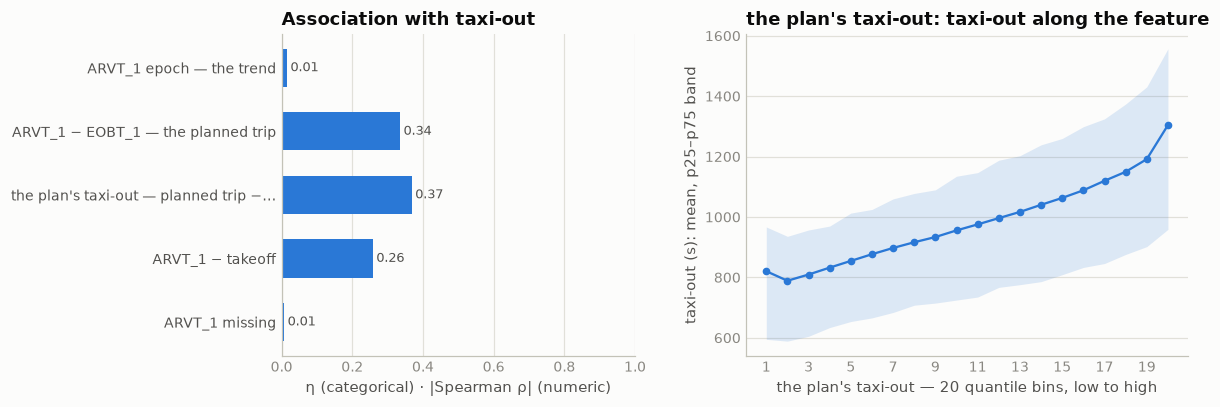

In [11]:
# correlation with the target: the stamp is a calendar; its model-facing forms are the planned trip, the plan's taxi-out inside it, and the
# planned landing against the takeoff
a = target_assoc([("ARVT_1 epoch — the trend", "num", "epoch(ARVT_1_flt)"),
                  ("ARVT_1 − EOBT_1 — the planned trip", "num", "epoch(ARVT_1_flt - EOBT_1_flt)"),
                  ("the plan's taxi-out — planned trip − (ARVT_3 − takeoff)", "num", PTAXI),
                  ("ARVT_1 − takeoff", "num", "epoch(ARVT_1_flt - MVT_TIME_UTC_mvt)"),
                  ("ARVT_1 missing", "cat", "ARVT_1_flt IS NULL")])
assoc_chart(a, PTAXI, kind="num", title="the plan's taxi-out")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The same rows as the plan's other clocks, exactly** | null on 22,470 training departures (22,424 without a plan, 46 empty blocks) and 5,290 ranking (5,283 + 7); on arrivals 15,449 and 2,552. `only_one_of_arvt1_eobt1` and `only_one_of_arvt1_arvt3` are 0 in all four file × phase groups; never at or before `EOBT_1` | its nulls are §2's missing plan; no coverage to gain |
| **On true seconds, unlike every other plan clock** | on the whole minute on 1.70% of training departures (1.78% ranking), which is what a random second gives (1 in 60); 1,981,546 distinct values on 2,085,047 departures | a computed trajectory time, not a filed one: the planned landing is `EOBT_1` plus a modelled trip |
| **The column family times the landing, not the in-block** | on 2,067,301 training arrivals at the hubs: landing − `ARVT_3` p01 −2.2, median −0.1, p99 +1.0 min, **98.5% within 2 min**; in-block − `ARVT_3` median 7.9 min (the taxi-in), 2.5% within 2 min. The planned landing: landing − `ARVT_1` p10 −12.2, median +4.2, p90 +26.2 min; within 5 min of the landing 28.8%, of the in-block 19.5% | `ARVT_1` is the planned landing and `ARVT_3` the flown one. §14's findings call `ARVT_3` "the plan's in-block"; it is the landing (open list) |
| **The planned trip starts from §27's moved clock** | planned trip `ARVT_1` − `EOBT_1`: p10 60.7, median 118.5, p90 530.4 min; flown trip `ARVT_3` − `AOBT_3` median 118.6, flown − planned p10 −8.6, median −0.1, p90 +8.2. On the 398,399 departures where `EOBT_1` moved (and the flight has ≥ 5 unmoved days that month), the trip measured from `EOBT_1` is a median 225 s from the flight's usual trip, from `LOBT_flt` 480 s; `EOBT_1` is the closer start on **72.3%** | when the day moves the plan's off-block, the planned landing moves with it. The trip is the stable quantity; the landing is `EOBT_1` plus that trip |
| **The trip contains the taxi-out the plan assumed** | on 315,269 training departures to another hub (matched on `FLIGHT_ID_mvt`; `ARVT_1` the same on both rows 99.99%), planned trip − actual airborne time is a median **16.0 min**, r 0.23 with the label. The flown landing stands in for the actual one everywhere else: landing − `ARVT_3` median −5 s, mean gap 29 s, within 1 min on 87.0%. Per hub, plan's taxi-out between hubs / on every departure / median label: EGLL 21.5 / 21.2 / 22.0, LEMD 19.7 / 17.3 / 16.4, LTFM 17.3 / 18.5 / 16.1, EDDF 16.4 / 16.9 / 13.9, LFPG 16.1 / 16.0 / 15.9, LIRF 14.7 / 16.5 / 17.0, LEBL 14.3 / 16.5 / 15.1, LSZH 13.6 / 14.6 / 11.9, EHAM 13.3 / 13.0 / 12.4, EDDM 13.0 / 13.2 / 12.9 | the network plans each departure with a taxi-out at the hub's own scale. Planned trip − (`ARVT_3` − takeoff) reads it on every departure with a plan; its airborne error (flown − planned trip, p10 −8.6 to p90 +8.2 min) is the noise around it |
| **And it knows the runway** | across the 37 hub × runway cells with ≥ 5,000 departures, the mean plan's taxi-out against the mean taxi-out: r **0.894**, and **0.824 within the hub**. Schiphol runway 24 10.3 min planned against 11.1 flown, the Polderbaan 36L 17.8 against 18.0; Heathrow 09R 20.6 against 22.2; Paris 27R 18.7 against 18.3. Per departure r 0.108 (LTFM) to 0.369 (EHAM) | the plan's taxi-out is the runway configuration, and probably the stand, as the network was told them. Both are columns we already have in the ranking file (§12, §13) |
| **Alone it is worth 15–17 s; the destination knows most of the trip** | airport 357.3 → × planned trip **342.7**, × destination (`ADES_flt`, §18) 335.7, destination × planned trip 331.4; × the plan's taxi-out **340.6**, planned trip × taxi-out 329.1 | the planned trip is distance, which the destination and aircraft type already measure: 4.3 s after the destination |
| **On the anchor and on §27's delay, a few seconds** | anchor 293.5 → × planned trip 287.7, × the plan's taxi-out 289.4 (10 bins 288.3), × `ARVT_1` − takeoff 288.5. §27's delay 257.1 → × planned trip 254.3, × the plan's taxi-out **253.7**, × `ARVT_1` − takeoff 254.6 | real signal where the ladder has no runway and no stand. The next row is the test that matters |
| **On §13's base, nothing** | base 265.5 → + planned trip on top of the stand 265.7, + the plan's taxi-out 265.9; under the pier 266.6 and 267.4. On §27's delay under the pier (237.5): either on top 237.5 and 237.6, after the delay under the pier 241.4 and 240.5. Raw labels on §13's base: 286.6 → 286.9 either form; on §27's delay 257.9 → 257.9 | what the plan knows about the taxi, the runway and the stand already say. Placed under the pier the forms cost 1–4 s: they split cells the stand splits better |
| **Raw labels agree** | all 327,968 Nov+Dec departures: airport 496.5 → the missing-plan flag 475.0 → planned trip 465.4, the plan's taxi-out 464.9; the anchor 428.1 → then planned trip **423.9**, the plan's taxi-out 425.2; outside §10a's slice 321.8 → 316.2 and 317.9 | 4.2 s on the anchor base as on the window, gone on §13's base as on the window. Its null level is §2's flag, so it does nothing for §10a's slice |
| **The planned arrival stream is the actual one's shadow** | arrivals at our hub within ±15 min of the takeoff (§8's window, 15.24 actual and 15.08 planned on average, r 0.857): on the anchor 293.5 → actual count 292.6, planned count (`ARVT_1`) 292.8, actual − planned 293.5 | the arrival-side form of this column carries nothing the landings themselves do not, and the landings carry a second at most. §7a's arrival sensor reads runway configuration from the actual stream, not this one |
| **2026: longer trips are a different mix of routes; on the same routes the plan's taxi-out grew** | median planned trip on departures January 118.8 → 122.6 min, July 119.7 → 122.0; arrivals 119.8 → 123.7 and 120.5 → 122.8. Route by route (hub × destination × type in the same month of both years, ≥ 30 departures each): January 1,101 routes, trip +0.3, plan's taxi-out +0.3, flown airborne −0.1; July 1,433 routes, +0.7, +0.5, +0.2. The plan's taxi-out median January 17.2 → 17.9, July 16.2 → 17.1, confirmed with the actual landing between hubs (16.8 → 17.2, 15.6 → 16.6). By hub, EDDF 17.2 / 16.7 → 18.9 / 18.1, EDDM 14.4 / 12.6 → 16.5 / 14.1, EHAM 12.5 / 13.1 → 13.9 / 14.6, LSZH 15.3 / 14.6 → 16.3 / 15.7; EGLL (21.2 / 21.7 → 20.9 / 21.6) and LTFM (20.4 / 17.9 → 20.0 / 17.6) did not rise | the 2026 files fly further. Where routes can be matched, the network plans about half a minute more taxi-out at the German, Dutch and Swiss hubs. Whether the taxis themselves got longer is hidden, since the label is |
| **Otherwise 2026 sits on 2025** | with the clock: departures January 99.07% → 98.39%, July 97.94% → 98.52%; arrivals 99.28% → 99.25%, 99.22% → 99.26%. Planned landing − actual landing on arrivals, median: January −2.6 → −4.1 min, July −6.8 → −4.1 | arrivals ran about four minutes behind the plan in both scored months |
| Marginal | the planned trip r 0.285, ρ 0.335; the plan's taxi-out r 0.300, **ρ 0.368**; `ARVT_1` − takeoff r 0.255, ρ 0.258; missing η 0.007; the stamp r 0.011 | the taxi-out reads the target best, and the trip's association is mostly the distance's: long-haul departures are heavies at far stands |

**Decisions**

| issue | decision | why |
|---|---|---|
| the form a model reads | **no required feature**: the column's information is the destination's distance and the runway and stand the network was told, all already columns | 265.7 and 265.9 against §13's base of 265.5; 237.5 and 237.6 on §27's delay under the pier; 286.9 against 286.6 on raw labels |
| if one form goes in anyway | the plan's taxi-out, not the planned trip | the better of the two alone (340.6 against 342.7) and on §27's delay (253.7 against 254.3); the only one that follows the runway (r 0.824 within the hub). It needs `ARVT_3`, whose section decides that column's own form |
| the planned arrival stream | not built | 292.8 against the actual count's 292.6 on the anchor; the two counts correlate at 0.857 |
| the 2026 rise in the plan's taxi-out | recorded | about +0.5 min on matched routes, largest at EDDF, EDDM, EHAM and LSZH; no feature reads it |
| §14's "the plan's in-block `ARVT_3`" | flagged, not edited | `ARVT_3` is the landing (98.5% within 2 min of it); corrected in `ARVT_3_flt`'s section or when §14 is next touched |
| the twin layers' clock | adopted: the same 1,898 training and 479 ranking departures as §15, §21 and §27 | one recovered plan block carries every clock in it (§2) |

**State after §28** — the twin layers of §2, departures:

| `ARVT_1_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

planned trip after, minutes: p10 60.7 / 62.0, median 118.5 / 122.2, p90 530.2 / 544.5 (training / ranking).

**Use in modeling.** Nothing new to feed. `ARVT_1_flt` is the planned landing: §27's moved off-block plus a
modelled trip. That trip holds two things. One is the flight's distance, which the destination and the
aircraft type already measure. The other is the taxi-out the network assumed, which follows the runway in use
(r 0.824 within the hub) because the network was told the runway, the stand or both. Both are columns we have.
Once §13's runway, anchor, pier and stand are in, neither form moves the ladder, on 1–3,600 s labels or on raw
ones, with or without §27's delay. If a model lacks the runway or the stand, the plan's taxi-out is the form that stands in for
them, and it rose by about half a minute at four hubs in 2026. The planned arrival stream adds nothing to the
actual one. The closing matrix reads the twin layers' clock as `TWINSA`. The column enters as epoch seconds with
those 1,898 + 479 filled in: 1.00 with `EOBT_1_flt`, `LOBT_flt`, `IOBT_flt` and the three movement clocks,
0.01 with the target, the seventh copy of the calendar.

## 29 · `AOBT_3_flt` — the off-block the flown trajectory recorded

The **actual off-block time** of the Network Manager's flown trajectory (the "M3" model in
`data/FEATURES.md`). It has been the sweep's anchor since §7: takeoff − `AOBT_3` is the label plus this
clock's error, and it is the largest single step in every ladder. §9 found it the nearest visible clock to the
hidden off-block (a median 52 s away) with an offset that moves per hub and per season, and handed the
calibration to this section.

So the questions here are about the error itself. Is `AOBT_3` the block stamp rounded, or a record of its own?
What moves its error, and is a seasonal calibration worth building? Where does the anchor fail? How good is the
clock §2's twin layers carry? And what can 2026 show when nothing there can score the clock? The error is
`ERR`, off-block − `AOBT_3`, in seconds; on a training departure it is the label minus the anchor.

| step | question | what came out |
|---|---|---|
| **census** | present where; on which grid | on **exactly** the plan's rows; on the whole minute on 97.70% of departures (EHAM 83.8%); after the takeoff on 1,012 |
| **what it is** | the block stamp rounded, or a record of its own | its own: equal to the block stamp floored to the minute on 10.4%, within 1 min 21.0%, within 5 min **74.6%**. §9's stepped offsets are a minute lattice, from hubs whose block stamps sit on §8's jittered minute |
| **the calibration** | the offset per hub and month, and what moves the error | per hub from −120 s (LIRF) to +239 s (LTFM), with a seasonal swing of up to two minutes at LTFM and LIRF. The month explains 0.77% of the error's within-hub variance, **the pushback delay 25.05%**: `AOBT_3` overshoots the day's deviation from the plan |
| **the tail** | where the anchor fails | 35,867 departures whose off-block is > 15 min before `AOBT_3` hold 2,762 of the 3,039 labels over an hour that carry the clock. LIRF and LTFM gain only 16.8 and 11.6 s from the anchor |
| **signal** | resolution, calibration, the twin layers, §13's base, raw labels | 293.5 at 20 bins → 281.7 at 100 → 279.7 at 200; 246.5 with §27's delay at 100 bins. A seasonal offset is worth ≤ 1.2 s even as an oracle; the twin layers' clock +0.9 s on raw labels |
| **look both ways** | 2026 against 2025, with no referee | anchors over an hour in January 195 → 563, 341 of them at Schiphol (68 in January 2025) |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures as the plan's other clocks |

In [4]:
# census by file × phase: present on exactly the rows the plan's other clocks are, on the whole minute; then what it is against the hidden
# off-block per hub — a rounded copy of the block stamp, or a record of its own — and how well the anchor, takeoff − AOBT_3, ranks the label.
# ERR is the anchor's error, off-block − AOBT_3, in seconds: the label minus the anchor on every training departure
ERR = "epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt)"
print("AOBT_3_flt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AOBT_3_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER ((AOBT_3_flt IS NULL) != (EOBT_1_flt IS NULL)) only_one_of_aobt3_eobt1,
           round(100.0*count(*) FILTER (extract(second FROM AOBT_3_flt) = 0)/count(AOBT_3_flt), 2) pct_on_minute,
           count(*) FILTER (PHASE_mvt = 'DEP' AND AOBT_3_flt > MVT_TIME_UTC_mvt) after_the_takeoff, count(*) FILTER (AOBT_3_flt >= ARVT_3_flt) not_before_arvt3,
           count(DISTINCT AOBT_3_flt) n_unique, strftime(min(AOBT_3_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(AOBT_3_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nper hub, training departures — AOBT_3 against the hidden off-block (seconds), and the anchor's Spearman ρ with the label (1–3,600 s):")
print(con.sql(f"""
    WITH s AS (SELECT hub, corr(ra, ry) rho FROM (SELECT ADEP_mvt hub, rank() OVER (PARTITION BY ADEP_mvt ORDER BY epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)) ra,
                                                         rank() OVER (PARTITION BY ADEP_mvt ORDER BY TAXITIME_SEC_mvt) ry
                                                  FROM {TGT} WHERE AOBT_3_flt IS NOT NULL) GROUP BY 1)
    SELECT coalesce(ADEP_mvt, 'all') hub, count(*) n, round(100.0*count(*) FILTER (extract(second FROM AOBT_3_flt) = 0)/count(*), 1) aobt3_on_minute,
           round(100.0*count(*) FILTER (extract(second FROM BLOCK_TIME_UTC_mvt) = 0)/count(*), 1) block_on_minute,
           round(100.0*count(*) FILTER (AOBT_3_flt = date_trunc('minute', BLOCK_TIME_UTC_mvt))/count(*), 1) eq_block_floored,
           round(100.0*count(*) FILTER (abs({ERR}) <= 60)/count(*), 1) within_1min, round(100.0*count(*) FILTER (abs({ERR}) <= 300)/count(*), 1) within_5min,
           round(100.0*count(*) FILTER (abs({ERR}) > 900)/count(*), 2) over_15min,
           round(quantile_cont({ERR}, 0.1)) p10_err, round(quantile_cont({ERR}, 0.5)) med_err, round(quantile_cont({ERR}, 0.9)) p90_err,
           round(any_value(s.rho), 3) spearman_anchor_label
    FROM {T} d LEFT JOIN s ON s.hub = d.ADEP_mvt WHERE PHASE_mvt = 'DEP' AND AOBT_3_flt IS NOT NULL GROUP BY ROLLUP (ADEP_mvt) ORDER BY ADEP_mvt NULLS LAST""").df().to_string(index=False))

print("\nthe error's fine structure within ±150 s — % of each hub's departures per 15-second bin: Frankfurt keeps true seconds on its block stamp,")
print("Heathrow and Istanbul stamp it on §8's jittered minute:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, floor({ERR}/15)*15 lo, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EDDF', 'EGLL', 'LTFM') AND AOBT_3_flt IS NOT NULL GROUP BY 1, 2),
         p AS (SELECT hub, lo, 100.0*n/sum(n) OVER (PARTITION BY hub) pct FROM d)
    SELECT lo::INT bin_start_s, round(max(pct) FILTER (hub = 'EDDF'), 2) EDDF, round(coalesce(max(pct) FILTER (hub = 'EGLL'), 0), 2) EGLL,
           round(coalesce(max(pct) FILTER (hub = 'LTFM'), 0), 2) LTFM
    FROM p WHERE lo BETWEEN -150 AND 135 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

AOBT_3_flt by file × phase:


     src  ph       n  n_null  no_plan  only_one_of_aobt3_eobt1  pct_on_minute  after_the_takeoff  not_before_arvt3  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506                        0          89.82                  0                 0    692099 2024-12-31 23:52 2025-12-31 22:01
training DEP 2085047   22470    22424                        0          97.70               1012                 0    486941 2025-01-01 00:15 2025-12-31 23:39
 ranking ARR  344693    2552     1409                        0          88.79                  0                 0    119868 2025-12-31 23:46 2026-07-31 22:52
 ranking DEP  344841    5290     5283                        0          97.43                169                 0     83435 2026-01-01 00:02 2026-07-31 23:42

per hub, training departures — AOBT_3 against the hidden off-block (seconds), and the anchor's Spearman ρ with the label (1–3,600 s):


 hub       n  aobt3_on_minute  block_on_minute  eq_block_floored  within_1min  within_5min  over_15min  p10_err  med_err  p90_err  spearman_anchor_label
EDDF  228185             99.0              1.7              11.7         21.0         85.4        0.66   -207.0     87.0    288.0                  0.749
EDDM  166324             99.9              8.3              13.0         25.7         82.6        3.23   -424.0     -2.0    184.0                  0.254
EGLL  238132            100.0              8.4               9.5         19.4         73.0        2.54   -302.0     54.0    417.0                  0.637
EHAM  243867             83.8              1.7              11.1         23.7         81.0        2.16   -101.0    107.0    431.0                  0.697
LEBL  177843             99.6              8.3              12.7         26.4         81.7        2.00   -359.0    -54.0    234.0                  0.645
LEMD  211295             99.7              8.4              13.3         26.2     

In [5]:
# the calibration §9 handed over: the error's mean per hub and month (errors within ±15 min, so the tail does not set the offset), then what
# moves the error inside a hub — the share of its within-hub variance each key explains (in-sample, groups ≥ 30 rows else the hub mean) —
# and the error along the key that explains most: the pushback delay AOBT_3 − EOBT_1 (§27), in deciles per hub, and along the anchor itself
MONTHS = ", ".join(f"round(avg({ERR}) FILTER (month(MVT_TIME_UTC_mvt) = {m})) m{m:02d}" for m in range(1, 13))
print("mean error off-block − AOBT_3 by hub × month, seconds (training departures, |error| ≤ 900 s):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, {MONTHS}, round(avg({ERR})) all_months
    FROM {T} WHERE PHASE_mvt = 'DEP' AND abs({ERR}) <= 900 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

con.sql(f"""
    CREATE OR REPLACE TABLE ao_err AS
    SELECT ADEP_mvt hub, {ERR} err, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt)::VARCHAR mon, hour(MVT_TIME_UTC_mvt)::VARCHAR hr,
           dayofweek(MVT_TIME_UTC_mvt)::VARCHAR dow, RUNWAY_mvt rwy, {PFX} pfx, STAND_mvt stand, coalesce(MARKET_SEGMENT_flt, '∅') seg,
           coalesce(AIRCRAFT_TYPE_flt, '∅') typ, (EOBT_1_flt != LOBT_flt)::VARCHAR moved,
           ntile(10) OVER (PARTITION BY ADEP_mvt ORDER BY epoch(AOBT_3_flt - EOBT_1_flt), MVT_ID_mvt)::VARCHAR delay_decile,
           ntile(10) OVER (PARTITION BY ADEP_mvt ORDER BY epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), MVT_ID_mvt)::VARCHAR anchor_decile
    FROM {TGT} WHERE AOBT_3_flt IS NOT NULL AND abs({ERR}) <= 900""")
tot = con.sql("SELECT sum((err - m)^2) FROM (SELECT err, avg(err) OVER (PARTITION BY hub) m FROM ao_err)").fetchone()[0]
KEYS = [("month", "mon"), ("hour of day (UTC)", "hr"), ("weekday", "dow"), ("runway (§12)", "rwy"), ("pier (§13)", "pfx"), ("stand (§13)", "stand"),
        ("market segment (§20)", "seg"), ("aircraft type (§24)", "typ"), ("EOBT_1 moved (§27)", "moved"),
        ("pushback delay, deciles (§27)", "delay_decile"), ("the anchor itself, deciles", "anchor_decile")]
shares = []
for name, k in KEYS:
    sse = con.sql(f"""SELECT sum((err - p)^2) FROM (SELECT err, CASE WHEN count(*) OVER (PARTITION BY hub, {k}) >= 30 THEN avg(err) OVER (PARTITION BY hub, {k})
                                                                 ELSE avg(err) OVER (PARTITION BY hub) END p FROM ao_err)""").fetchone()[0]
    shares.append((name, 100 * (1 - sse / tot)))
shares = pd.DataFrame(shares, columns=["key, within the hub", "pct_of_error_variance"])
print(f"\nshare of the error's within-hub variance each key explains — {con.sql('SELECT count(*) FROM ao_err').fetchone()[0]:,} training departures 1–3,600 s, |error| ≤ 900 s:")
print(shares.round(2).to_string(index=False))

dec = con.sql("""
    SELECT d.delay_decile::INT decile, count(*) n, avg(d.err) mean_err_by_delay, quantile_cont(d.err, 0.25) p25, quantile_cont(d.err, 0.75) p75
    FROM ao_err d GROUP BY 1 ORDER BY 1""").df()
dec["mean_err_by_anchor"] = con.sql("SELECT anchor_decile::INT decile, avg(err) m FROM ao_err GROUP BY 1 ORDER BY 1").df().m
print("\nthe error along the pushback delay (decile 1 = pushed earliest against EOBT_1) and along the anchor (decile 1 = shortest), per-hub deciles pooled, seconds:")
print(dec.round(0).to_string(index=False))

mean error off-block − AOBT_3 by hub × month, seconds (training departures, |error| ≤ 900 s):


 hub   m01   m02    m03    m04    m05    m06    m07    m08    m09    m10   m11   m12  all_months
EDDF  77.0  83.0   84.0   74.0   55.0   54.0   60.0   69.0   46.0   52.0  52.0  58.0        63.0
EDDM  -8.0   1.0   -4.0  -23.0  -35.0  -23.0  -56.0  -55.0  -68.0  -62.0 -58.0 -85.0       -41.0
EGLL  66.0  43.0   53.0   34.0   38.0   34.0   42.0   37.0   35.0   38.0  49.0  50.0        43.0
EHAM 118.0 117.0  130.0  129.0  132.0  130.0  136.0  135.0  130.0  132.0 116.0 111.0       127.0
LEBL   1.0 -12.0  -34.0  -42.0  -60.0  -62.0  -71.0  -53.0  -51.0  -53.0 -16.0 -21.0       -42.0
LEMD  20.0  17.0  -38.0   -1.0    3.0  -27.0  -34.0  -47.0  -43.0  -23.0   1.0   1.0       -15.0
LFPG -14.0  -5.0    0.0  -10.0  -15.0  -21.0  -43.0  -29.0  -29.0  -12.0 -16.0 -20.0       -18.0
LIRF -70.0 -69.0 -103.0 -146.0 -151.0 -159.0 -164.0 -145.0 -130.0 -134.0 -47.0 -82.0      -120.0
LSZH -51.0 -48.0  -46.0  -53.0  -52.0  -52.0  -52.0  -52.0  -48.0  -42.0 -58.0 -68.0       -52.0
LTFM 293.0 270.0  310.0  248.0


share of the error's within-hub variance each key explains — 2,012,912 training departures 1–3,600 s, |error| ≤ 900 s:
          key, within the hub  pct_of_error_variance
                        month                   0.77
            hour of day (UTC)                   2.19
                      weekday                   0.07
                 runway (§12)                   2.95
                   pier (§13)                   6.24
                  stand (§13)                   9.62
         market segment (§20)                   2.54
          aircraft type (§24)                   5.67
           EOBT_1 moved (§27)                   0.07
pushback delay, deciles (§27)                  25.05
   the anchor itself, deciles                  11.13

the error along the pushback delay (decile 1 = pushed earliest against EOBT_1) and along the anchor (decile 1 = shortest), per-hub deciles pooled, seconds:
 decile      n  mean_err_by_delay    p25   p75  mean_err_by_anchor
      1 201295      

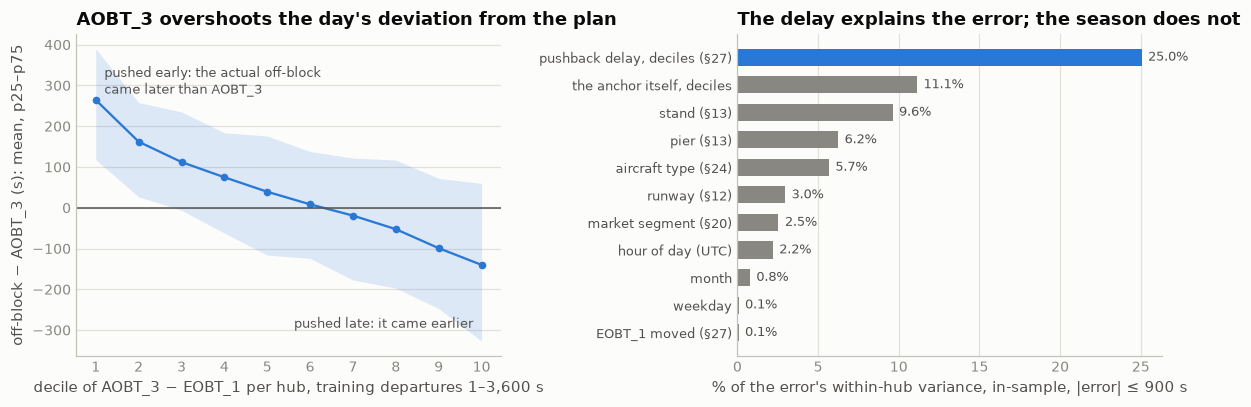

In [6]:
# the picture: the anchor's error along the pushback delay, and what explains it — the mechanism behind §15's "the truth lies between" and
# behind §27's delay being worth 28 s under the pier
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.fill_between(dec.decile, dec.p25, dec.p75, color=BLUE, alpha=0.15, lw=0)
a1.plot(dec.decile, dec.mean_err_by_delay, "o-", color=BLUE, ms=4)
a1.axhline(0, color=INK2, lw=1)
a1.set_xticks(range(1, 11))
a1.text(1.2, dec.p75.max() * 0.9, "pushed early: the actual off-block\ncame later than AOBT_3", fontsize=8.5, color=INK2, va="top")
a1.text(9.8, dec.p25.min() * 0.9, "pushed late: it came earlier", fontsize=8.5, color=INK2, ha="right")
a1.set_title("AOBT_3 overshoots the day's deviation from the plan")
a1.set_xlabel("decile of AOBT_3 − EOBT_1 per hub, training departures 1–3,600 s")
a1.set_ylabel("off-block − AOBT_3 (s): mean, p25–p75")
style(a1)
sh = shares.sort_values("pct_of_error_variance")
yy = np.arange(len(sh))
a2.barh(yy, sh.pct_of_error_variance, height=0.62, color=[BLUE if "delay" in s else MUTED for s in sh["key, within the hub"]])
for i, v in enumerate(sh.pct_of_error_variance):
    a2.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
a2.set_yticks(yy, [textwrap.shorten(s, 34, placeholder="…") for s in sh["key, within the hub"]], color=INK2, fontsize=8.5)
a2.set_title("The delay explains the error; the season does not")
a2.set_xlabel("% of the error's within-hub variance, in-sample, |error| ≤ 900 s")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

In [7]:
# the far tail — departures where the anchor is off by more than 15 min, which side, where, and whether they are §14's labels over an hour;
# the anchors below zero (AOBT_3 after the takeoff); then §2's twin layers' AOBT_3 on the departures without their own, scored the same way
print("the anchor off by more than 15 minutes (training departures):")
print(con.sql(f"""
    SELECT CASE WHEN {ERR} < -900 THEN 'off-block > 15 min before AOBT_3' ELSE 'off-block > 15 min after AOBT_3' END side, count(*) n,
           round(100.0*count(*)/(SELECT count(AOBT_3_flt) FROM {T} WHERE PHASE_mvt = 'DEP'), 2) pct_of_departures_with_aobt3,
           round(quantile_cont({ERR}/60, 0.5), 1) med_err_min, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_anchor, count(*) FILTER (TAXITIME_SEC_mvt > 3600) labels_over_1h
    FROM {T} WHERE PHASE_mvt = 'DEP' AND abs({ERR}) > 900 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print(con.sql(f"""
    SELECT count(*) FILTER (TAXITIME_SEC_mvt > 3600) all_labels_over_1h, count(*) FILTER (TAXITIME_SEC_mvt > 3600 AND AOBT_3_flt IS NOT NULL) with_aobt3,
           count(*) FILTER (TAXITIME_SEC_mvt > 3600 AND {ERR} < -900) with_offblock_over_15min_before_aobt3
    FROM {T} WHERE PHASE_mvt = 'DEP'""").df().to_string(index=False))
print("\nper hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) FILTER ({ERR} < -900) offblock_15min_before, count(*) FILTER ({ERR} > 900) offblock_15min_after,
           count(*) FILTER (TAXITIME_SEC_mvt > 3600 AND AOBT_3_flt IS NOT NULL) labels_over_1h_with_aobt3,
           count(*) FILTER (TAXITIME_SEC_mvt > 3600 AND {ERR} < -900) of_them_offblock_15min_before
    FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nAOBT_3 after the takeoff — the anchor below zero (training departures):")
print(con.sql(f"""
    SELECT count(*) n, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_anchor, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           round(quantile_cont({ERR}/60, 0.5), 1) med_err_min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AOBT_3_flt > MVT_TIME_UTC_mvt""").df().to_string(index=False))

TWINSO = (f"(SELECT MVT_ID_mvt, 'exact twin (§2b)' layer, AOBT_3_flt aobt3_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, 'relaxed twin ' || matcher_variant || ' (§2c)', AOBT_3_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
print("\n§2's twin layers' AOBT_3 on the training departures without their own, against the actual off-block:")
print(con.sql(f"""
    SELECT coalesce(w.layer, 'all') layer, count(*) n, round(quantile_cont(epoch(d.BLOCK_TIME_UTC_mvt - w.aobt3_twin), 0.5)) med_err,
           round(100.0*count(*) FILTER (abs(epoch(d.BLOCK_TIME_UTC_mvt - w.aobt3_twin)) <= 300)/count(*), 1) within_5min,
           round(100.0*count(*) FILTER (abs(epoch(d.BLOCK_TIME_UTC_mvt - w.aobt3_twin)) > 900)/count(*), 1) over_15min,
           round(quantile_cont(d.TAXITIME_SEC_mvt, 0.5)) med_label, count(*) FILTER (d.TAXITIME_SEC_mvt > 3600) labels_over_1h
    FROM {T} d JOIN {TWINSO} w USING (MVT_ID_mvt)
    WHERE d.PHASE_mvt = 'DEP' AND d.AOBT_3_flt IS NULL AND w.aobt3_twin IS NOT NULL GROUP BY ROLLUP (w.layer) ORDER BY w.layer NULLS LAST""").df().to_string(index=False))

the anchor off by more than 15 minutes (training departures):


                            side     n  pct_of_departures_with_aobt3  med_err_min  med_label  med_anchor  labels_over_1h
 off-block > 15 min after AOBT_3 13476                          0.65         19.0      761.0      2061.0              15
off-block > 15 min before AOBT_3 35867                          1.74        -21.0     2135.0       779.0            2762


 all_labels_over_1h  with_aobt3  with_offblock_over_15min_before_aobt3
               4126        3039                                   2762

per hub:


 hub  offblock_15min_before  offblock_15min_after  labels_over_1h_with_aobt3  of_them_offblock_15min_before
EDDF                   1470                    42                         70                             67
EDDM                   5337                    28                         48                             48
EGLL                   3686                  2353                        683                            528
EHAM                    115                  5149                         71                              5
LEBL                   3463                    99                          1                              1
LEMD                   2787                    41                          0                              0
LFPG                   3398                  1085                        350                            314
LIRF                  10068                    91                       1222                           1214
LSZH                    811 

               layer    n  med_err  within_5min  over_15min  med_label  labels_over_1h
    exact twin (§2b)  892    -61.0         64.2        10.9      972.0              48
relaxed twin A (§2c)  526    -57.0         74.3         5.5     1019.0               8
relaxed twin B (§2c)  217    114.0         75.1        10.1      729.0               0
relaxed twin C (§2c)  263     33.0         75.3        12.2      812.0               2
                 all 1898     -6.0         69.8         9.5      941.0              58


In [8]:
# what the anchor buys and how to read it — §15's honest ladders, fit Jan–Oct → scored Nov+Dec, quantile bins cut per airport on the fit rows,
# cell support ≥ 30 else the coarser rung: the anchor's resolution, the on-the-minute flag, §27's delay on top, the twin layers' clock; per hub;
# on raw labels (all · outside §10a's slice). Then the anchor as a raw prediction with a per-hub offset subtracted, from the fit months, from October,
# and from the scored months themselves (an oracle): what a seasonal calibration could be worth. ao_ladder is §15's lob_ladder with its tables renamed
con.sql(f"""
    CREATE OR REPLACE TABLE ao_d AS
    SELECT d.ADEP_mvt hub, d.TAXITIME_SEC_mvt::DOUBLE y, month(d.MVT_TIME_UTC_mvt) >= 11 is_val, month(d.MVT_TIME_UTC_mvt) mon,
           epoch(d.MVT_TIME_UTC_mvt - d.AOBT_3_flt) g_aobt3, epoch(d.MVT_TIME_UTC_mvt - coalesce(d.AOBT_3_flt, w.aobt3_twin)) g_twins,
           epoch(d.AOBT_3_flt - d.EOBT_1_flt) un_eobt1, extract(second FROM d.AOBT_3_flt) = 0 on_minute, d.ADEP_flt IS NULL no_plan,
           coalesce(d.ADEP_mvt = 'LIRF' AND d.ADEP_flt IS NULL AND epoch(d.MVT_TIME_UTC_mvt - d.SCHED_TIME_UTC_mvt) >= 7200, FALSE) gauge
    FROM {T} d LEFT JOIN {TWINSO} w USING (MVT_ID_mvt) WHERE d.PHASE_mvt = 'DEP' AND d.TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE ao_t AS SELECT * FROM ao_d WHERE y <= 3600")


def ao_ladder(tbl, *bins, by_hub=False):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean.
    Returns (RMSE, RMSE outside §10a's slice), or one row per airport with by_hub."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}::VARCHAR, '-1') q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE ao_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM {tbl} WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val, gauge{qcols} FROM {tbl} JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE ao_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM ao_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN ao_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN ao_r{k}.c >= 30 THEN ao_r{k}.m END")
    se = f"(v.y - coalesce({', '.join(reversed(preds))}))^2"
    if by_hub:
        return con.sql(f"SELECT v.hub, sqrt(avg({se})) rmse FROM ao_b v {' '.join(joins)} WHERE v.is_val GROUP BY 1 ORDER BY 1").df()
    return con.sql(f"SELECT sqrt(avg({se})), sqrt(avg({se}) FILTER (NOT v.gauge)) FROM ao_b v {' '.join(joins)} WHERE v.is_val").fetchone()


n_val = con.sql("SELECT count(*) FROM ao_t WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × takeoff − AOBT_3, 10 bins", (("g_aobt3", 10),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (("g_aobt3", 20),)),
                   ("airport × takeoff − AOBT_3, 50 bins", (("g_aobt3", 50),)),
                   ("airport × takeoff − AOBT_3, 100 bins", (("g_aobt3", 100),)),
                   ("airport × takeoff − AOBT_3, 200 bins", (("g_aobt3", 200),)),
                   ("anchor, 20 bins × on-the-minute flag", (("g_aobt3", 20), ("on_minute", 0))),
                   ("anchor, 20 bins, the twin layers' clock filled in", (("g_twins", 20),)),
                   ("anchor, 20 bins × §27's delay, 5 bins", (("g_aobt3", 20), ("un_eobt1", 5))),
                   ("anchor, 100 bins × §27's delay, 5 bins", (("g_aobt3", 100), ("un_eobt1", 5)))]:
    print(f"  {name:58s} {ao_ladder('ao_t', *bins)[0]:6.1f}")

print("\nper hub — the airport mean, then the anchor at 20 and 100 bins (the same Nov+Dec rows):")
ph = ao_ladder("ao_t", by_hub=True).rename(columns={"rmse": "airport"})
ph["anchor_20"] = ao_ladder("ao_t", ("g_aobt3", 20), by_hub=True).rmse
ph["anchor_100"] = ao_ladder("ao_t", ("g_aobt3", 100), by_hub=True).rmse
ph["gain_20"] = ph.airport - ph.anchor_20
print(ph.round(1).to_string(index=False))

n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (gauge) FROM ao_d WHERE is_val").fetchone()
print(f"\nraw labels, no ceiling (§14) — all {n2[0]:,} Nov+Dec departures, {n2[1]:,} without a plan, {n2[2]} in §10a's slice (all · outside the slice):")
for name, bins in [("airport", ()),
                   ("airport × the missing-plan flag (§2)", (("no_plan", 0),)),
                   ("anchor, 20 bins (its ∅ is the missing plan)", (("g_aobt3", 20),)),
                   ("anchor, 20 bins, the twin layers' clock filled in", (("g_twins", 20),)),
                   ("anchor, 100 bins", (("g_aobt3", 100),)),
                   ("anchor, 100 bins, the twin layers' clock filled in", (("g_twins", 100),))]:
    r = ao_ladder("ao_d", *bins)
    print(f"  {name:58s} {r[0]:6.1f} · {r[1]:6.1f}")

print("\nthe anchor as a raw prediction, Nov+Dec departures 1–3,600 s with the clock — RMSE (s) after subtracting a per-hub offset (median of label − anchor):")
print(con.sql("""
    WITH off AS (SELECT hub, median(y - g_aobt3) FILTER (NOT is_val) o_fit, median(y - g_aobt3) FILTER (mon = 10) o_october,
                        median(y - g_aobt3) FILTER (is_val) o_oracle
                 FROM ao_t WHERE g_aobt3 IS NOT NULL GROUP BY 1)
    SELECT count(*) n, round(sqrt(avg((y - g_aobt3)^2)), 1) raw_anchor, round(sqrt(avg((y - g_aobt3 - o_fit)^2)), 1) minus_jan_oct_offset,
           round(sqrt(avg((y - g_aobt3 - o_october)^2)), 1) minus_october_offset, round(sqrt(avg((y - g_aobt3 - o_oracle)^2)), 1) minus_nov_dec_offset_oracle
    FROM ao_t JOIN off USING (hub) WHERE is_val AND g_aobt3 IS NOT NULL""").df().to_string(index=False))

honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                     357.3
  airport × takeoff − AOBT_3, 10 bins                         299.3


  airport × takeoff − AOBT_3, 20 bins — §9's anchor           293.5


  airport × takeoff − AOBT_3, 50 bins                         285.5


  airport × takeoff − AOBT_3, 100 bins                        281.7


  airport × takeoff − AOBT_3, 200 bins                        279.7


...

  anchor, 100 bins × §27's delay, 5 bins                      246.5

per hub — the airport mean, then the anchor at 20 and 100 bins (the same Nov+Dec rows):


 hub  airport  anchor_20  anchor_100  gain_20
EDDF    346.5      250.5       237.5     96.0
EDDM    402.7      324.0       280.8     78.7
EGLL    370.2      280.0       270.6     90.2
EHAM    317.0      228.4       223.1     88.5
LEBL    314.0      248.0       238.7     65.9
LEMD    302.4      236.4       227.1     66.0
LFPG    418.8      343.1       324.4     75.7
LIRF    396.2      379.4       379.5     16.8
LSZH    329.5      259.9       236.6     69.5
LTFM    359.4      347.8       345.5     11.6

raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 58 in §10a's slice (all · outside the slice):
  airport                                                     496.5 ·  383.0
  airport × the missing-plan flag (§2)                        475.0 ·  382.0


  anchor, 20 bins (its ∅ is the missing plan)                 427.8 ·  321.4
  anchor, 20 bins, the twin layers' clock filled in           426.9 ·  320.7


  anchor, 100 bins                                            417.8 ·  308.0


  anchor, 100 bins, the twin layers' clock filled in          417.0 ·  307.3

the anchor as a raw prediction, Nov+Dec departures 1–3,600 s with the clock — RMSE (s) after subtracting a per-hub offset (median of label − anchor):
     n  raw_anchor  minus_jan_oct_offset  minus_october_offset  minus_nov_dec_offset_oracle
324631       354.2                 336.2                 336.2                        335.0


In [9]:
# on §13's base — the anchor at §13's 12 bins against 20, with §27's delay under the pier, the machinery of §22–§28 (§13's std_rungs); labels
# 1–3,600 s and raw
con.sql(f"""
    CREATE OR REPLACE TABLE ob_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, STAND_mvt stand, {PFX} pfx, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor, epoch(AOBT_3_flt - EOBT_1_flt) un_e
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt >= 1 AND AOBT_3_flt IS NOT NULL AND RUNWAY_mvt IS NOT NULL AND STAND_mvt IS NOT NULL""")
for tbl, cond in [("ob_t", "y <= 3600"), ("ob_r", "TRUE")]:
    con.sql(f"""
        CREATE OR REPLACE TABLE {tbl} AS
        WITH d AS (SELECT * FROM ob_d WHERE {cond}),
             cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) q12,
                             quantile_cont(anchor, [{', '.join(str(i / 20) for i in range(1, 20))}]) q20, quantile_cont(un_e, [0.2,0.4,0.6,0.8]) ce
                      FROM d WHERE NOT is_val GROUP BY 1)
        SELECT d.*, list_count(list_filter(q12, x -> x <= anchor)) a12, list_count(list_filter(q20, x -> x <= anchor)) a20,
               list_count(list_filter(ce, x -> x <= un_e)) q_une
        FROM d JOIN cuts USING (hub)""")


def ob_rmse(rungs, tbl):
    """§13's std_rungs on this section's tables: each rung's cell mean where it has ≥ 30 fit rows, else the rung before."""
    joins, preds = [], []
    for i, keys in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE ob_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN ob_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN ob_s{i}.c >= 30 THEN ob_s{i}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, (SELECT avg(y) FROM {tbl} WHERE NOT is_val)))^2))
                       FROM {tbl} v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


def base13(a, *under):
    rungs = [["hub"], ["hub", "rwy"], ["hub", "rwy", a]]
    for k in under:
        rungs.append(rungs[-1] + [k])
    return rungs + [rungs[-1] + ["pfx"], rungs[-1] + ["pfx", "stand"]]


for title, tbl in [("labels 1–3,600 s", "ob_t"), ("raw labels", "ob_r")]:
    n = con.sql(f"SELECT count(*) FROM {tbl} WHERE is_val").fetchone()[0]
    print(f"on §13's base — {n:,} Nov+Dec departures with a runway, a stand and an anchor, {title}:")
    for name, rungs in [("§13's base, the anchor in 12 bins", base13("a12")), ("§13's base, the anchor in 20 bins", base13("a20")),
                        ("§27's delay under the pier, the anchor in 12 bins", base13("a12", "q_une")),
                        ("§27's delay under the pier, the anchor in 20 bins", base13("a20", "q_une"))]:
        print(f"    {name:58s} {ob_rmse(rungs, tbl):7.1f} s")
    print()

on §13's base — 324,629 Nov+Dec departures with a runway, a stand and an anchor, labels 1–3,600 s:
    §13's base, the anchor in 12 bins                            265.5 s
    §13's base, the anchor in 20 bins                            266.4 s


    §27's delay under the pier, the anchor in 12 bins            237.5 s
    §27's delay under the pier, the anchor in 20 bins            238.7 s

on §13's base — 324,988 Nov+Dec departures with a runway, a stand and an anchor, raw labels:
    §13's base, the anchor in 12 bins                            286.6 s


    §13's base, the anchor in 20 bins                            287.5 s
    §27's delay under the pier, the anchor in 12 bins            257.9 s


    §27's delay under the pier, the anchor in 20 bins            259.0 s



In [10]:
# look both ways — the anchor in the scored months against their 2025 twins. The off-block is hidden in 2026, so nothing here can score the
# clock; what can be seen is whether the anchor's distribution moved, where, and how many anchors run past an hour
print("the clock in January and July, 2025 against 2026 (all departures; the anchor in seconds):")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(AOBT_3_flt)/count(*), 2) pct_with_aobt3,
           round(100.0*count(*) FILTER (extract(second FROM AOBT_3_flt) = 0)/count(AOBT_3_flt), 1) pct_on_minute,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.1)) p10_anchor, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_anchor,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.9)) p90_anchor, count(*) FILTER (AOBT_3_flt > MVT_TIME_UTC_mvt) after_the_takeoff,
           count(*) FILTER (epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) > 3600) anchor_over_1h
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

YM = [(2025, 1), (2026, 1), (2025, 7), (2026, 7)]
cols = ", ".join(f"round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5) FILTER (yr = {y} AND mon = {m})) med_{y % 100}_{m:02d}" for y, m in YM)
cols += ", " + ", ".join(f"count(*) FILTER (yr = {y} AND mon = {m} AND epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) > 3600) over1h_{y % 100}_{m:02d}" for y, m in YM)
print("\nper hub: the median anchor (s) and the anchors over an hour, January and July of both years:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, {cols}
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7))
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

the clock in January and July, 2025 against 2026 (all departures; the anchor in seconds):


  yr  mon      n  pct_with_aobt3  pct_on_minute  p10_anchor  med_anchor  p90_anchor  after_the_takeoff  anchor_over_1h
2025    1 153706           99.07           96.6       626.0       964.0      1500.0                 62             195
2026    1 152719           98.39           95.8       632.0      1001.0      1505.0                 62             563
2025    7 190713           97.94           98.4       624.0       957.0      1435.0                178             247
2026    7 192122           98.52           98.7       626.0       965.0      1380.0                107             341

per hub: the median anchor (s) and the anchors over an hour, January and July of both years:


 hub  med_25_01  med_26_01  med_25_07  med_26_07  over1h_25_01  over1h_26_01  over1h_25_07  over1h_26_07
EDDF      907.0      954.0      896.0      929.0             1             0             0             0
EDDM      720.0      722.0      721.0      718.0             0             0             1             2
EGLL     1320.0     1317.0     1376.0     1321.0            75            67            34            24
EHAM      812.0      863.0      900.0      964.0            68           341            19            33
LEBL      758.0      760.0      767.0      765.0             0             0             0             0
LEMD      984.0      987.0      985.0      981.0             1             3             0             0
LFPG      899.0      897.0      898.0      959.0            11            79             8            10
LIRF      902.0      900.0      901.0      903.0             0             1             2             3
LSZH      667.0      679.0      688.0      670.0       

In [11]:
# closing state — the column after §29: nothing of its own repaired; §2's twin layers hand the departures they recover the whole plan block,
# this clock with it (scored above). Before → after per file, and the final distribution of the anchor
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (AOBT_3_flt IS NULL) null_before, count(*) FILTER (AOBT_3_flt IS NULL AND aobt3_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(AOBT_3_flt, aobt3_twin) IS NULL) null_after, round(100.0*count(*) FILTER (coalesce(AOBT_3_flt, aobt3_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(AOBT_3_flt, aobt3_twin)), 0.1)) p10_anchor_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(AOBT_3_flt, aobt3_twin)), 0.5)) p50,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(AOBT_3_flt, aobt3_twin)), 0.9)) p90
    FROM {BOTH} d LEFT JOIN {TWINSO} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nthe same 1,898 + 479 departures the plan's other clocks gained: one recovered plan block carries every clock in it")

     src       n  null_before  filled_by_twins  null_after  pct_null_after  p10_anchor_after   p50    p90
training 2085047        22470             1898       20572            0.99             626.0 958.0 1444.0
 ranking  344841         5290              479        4811            1.40             629.0 978.0 1498.0

the same 1,898 + 479 departures the plan's other clocks gained: one recovered plan block carries every clock in it


                      feature        kind  n / levels  pearson_r  spearman_ρ     η
     AOBT_3 epoch — the trend     numeric     2059401      0.011       0.015      
takeoff − AOBT_3 — the anchor     numeric     2059401      0.545       0.616      
AOBT_3 − EOBT_1 — §27's delay     numeric     2059401      0.252       0.217      
   AOBT_3 on the whole minute categorical           3                        0.078
     AOBT_3 after the takeoff categorical           3                        0.012
               AOBT_3 missing categorical           2                        0.007


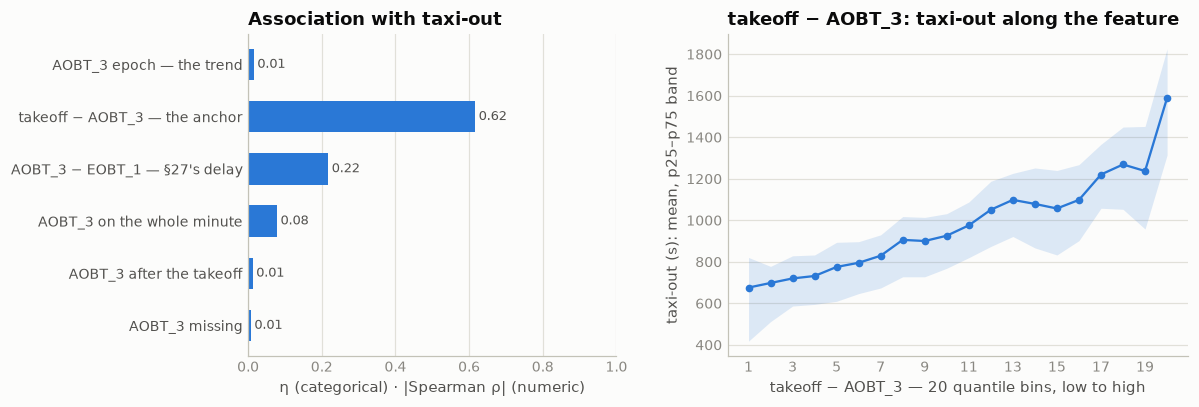

In [12]:
# correlation with the target: the stamp is a calendar; its model-facing form is the anchor, takeoff − AOBT_3, beside §27's delay that corrects
# it; the on-the-minute and after-the-takeoff flags; missing
a = target_assoc([("AOBT_3 epoch — the trend", "num", "epoch(AOBT_3_flt)"),
                  ("takeoff − AOBT_3 — the anchor", "num", "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)"),
                  ("AOBT_3 − EOBT_1 — §27's delay", "num", "epoch(AOBT_3_flt - EOBT_1_flt)"),
                  ("AOBT_3 on the whole minute", "cat", "extract(second FROM AOBT_3_flt) = 0"),
                  ("AOBT_3 after the takeoff", "cat", "AOBT_3_flt > MVT_TIME_UTC_mvt"),
                  ("AOBT_3 missing", "cat", "AOBT_3_flt IS NULL")])
assoc_chart(a, "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)", kind="num", title="takeoff − AOBT_3")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The same rows as the plan's other clocks** | null on 22,470 training departures (22,424 without a plan) and 5,290 in the ranking file; on arrivals 15,449 and 2,552. `only_one_of_aobt3_eobt1` is 0 in all four file × phase groups; never at or after `ARVT_3` | its nulls are §2's missing plan |
| **A minute-resolution record** | on the whole minute on 97.70% of training departures (97.43% ranking), 89.82% of arrivals; per hub 98.9–100.0% except **EHAM 83.8%**; 486,941 distinct values. After the takeoff on 1,012 training departures, 169 ranking | Schiphol alone sends seconds on a sixth of its rows |
| **Not the block stamp rounded, but a record of its own** | equal to the off-block floored to the minute on 10.4% of departures (LTFM 4.5% to LEMD 13.3%); within 1 min 21.0%, within 5 min **74.6%**, off by more than 15 min 2.39%; the error p10 −310, median +51, p90 +363 s. Within 5 min per hub: LEMD 86.5%, EDDF 85.4%, EDDM 82.6%, LSZH 82.5%, LEBL 81.7%, EHAM 81.0%, LFPG 73.8%, EGLL 73.0%, LIRF 65.8%, **LTFM 44.4%** | two systems timing nearly the same event a few minutes apart, not one number the model could undo with a constant |
| **§9's stepped offsets are a minute lattice, not a calendar** | the error per 15-second bin within ±150 s. At EDDF, whose block stamps keep true seconds, it spreads smoothly, 1.20% to 3.58% per bin. At EGLL and LTFM, whose block stamps sit on §8's jittered minute, every other bin is (nearly) empty: EGLL 0.00% at −105, −90, −45, −30, +15, +30, +75, +90 and +135 s | the error there is a whole number of minutes plus a few seconds, so a median can only move a minute at a time. That is §9's EGLL "55 s in winter, 5 s in summer". Read the calibration off the mean |
| **The calibration: an offset per hub, and a seasonal swing at a few** | mean error (|error| ≤ 900 s) over the year: LTFM +239 s, EHAM +127, EDDF +63, EGLL +43, LEMD −15, LFPG −18, EDDM −41, LEBL −42, LSZH −52, **LIRF −120**. By month: LTFM from 170 (July) to 310 (March), LIRF −47 (November) to −164 (July), LEBL +1 (January) to −71 (July), EDDM +1 (February) to −85 (December). EHAM 111–136 and LSZH −42 to −68 barely move | the offset belongs to the airport. The season moves it by up to two minutes at LTFM and LIRF, and the two scored months sit near the ends of that swing |
| **The pushback delay explains a quarter of the error; the month under 1%** | share of the error's within-hub variance (in-sample; 2,012,912 departures 1–3,600 s, |error| ≤ 900 s): pushback delay deciles **25.05%**, the anchor's own deciles 11.13%, stand 9.62%, pier 6.24%, aircraft type 5.67%, runway 2.95%, segment 2.54%, hour 2.19%, **month 0.77%**, weekday 0.07%, `EOBT_1` moved 0.07% | the error is not a calendar effect; it belongs to the flight's own day |
| **`AOBT_3` overshoots the day's deviation from the plan** | mean error by decile of `AOBT_3` − `EOBT_1`: **+264 s** for the earliest pushbacks (p25 +118, p75 +390), +112 at the third decile, +9 at the sixth, −52 at the eighth, **−140** for the latest (p25 −327, p75 +60). Along the anchor: −67 s for its shortest decile to +149 for its longest | where the flown clock says the aircraft left early, the actual off-block came later; where it says late, earlier. The truth lies between the plan and `AOBT_3` (§15's reading, measured), which is why §27's delay under the pier is worth 28 s: it is the anchor's own correction. The anchor's deciles show the regression to the mean that the ladder's bins absorb |
| **The tail is a block stamp far before `AOBT_3`** | off-block > 15 min before `AOBT_3`: 35,867 departures (1.74% of those with the clock), a median 21.0 min before, median label 2,135 s, median anchor 779 s, **2,762 labels over an hour**, of the 3,039 over-an-hour labels that carry the clock (4,126 in all). Off-block > 15 min after: 13,476 (0.65%), median label 761 s, 15 over an hour. The early side by hub: LIRF 10,068 (1,214 of its 1,222 over-hour labels with the clock), EDDM 5,337, LTFM 4,732, EGLL 3,686, LEBL 3,463, LFPG 3,398; the late side EHAM 5,149, LTFM 4,501, EGLL 2,353 | the flown clock puts the pushback 13 minutes before takeoff while the block stamp puts it hours before. §14's tail is this disagreement, and the anchor predicts an ordinary taxi for those rows |
| **Below zero on 1,012 departures** | `AOBT_3` after the takeoff: median anchor −661 s, median label 1,015 s, the clock a median 37.1 min after the off-block | a stamp on the wrong event; the negative anchor already says so |
| **Rome and Istanbul get little from the anchor** | airport → anchor at 20 bins per hub: EDDF 346.5 → 250.5 (**96.0 s**), EGLL 90.2, EHAM 88.5, EDDM 78.7, LFPG 75.7, LSZH 69.5, LEMD 66.0, LEBL 65.9, **LIRF 396.2 → 379.4 (16.8 s)**, **LTFM 359.4 → 347.8 (11.6 s)**. The anchor's Spearman ρ with the label: LTFM 0.196, EDDM 0.254, LIRF 0.419, against EDDF 0.749 | at LTFM the clock is within 5 min of the off-block on 44.4% of departures, and at LIRF 6.38% of errors run past 15 min; at those two hubs the taxi-out has to come from other columns. EDDM's low ρ is its tail: 100 bins take it 402.7 → 280.8 |
| **The anchor keeps paying for resolution** | 357.3 → 10 bins 299.3 → 20 bins 293.5 → 50 bins 285.5 → 100 bins 281.7 → 200 bins 279.7; with §27's delay 257.1 at 20 bins, **246.5 at 100**. The on-the-minute flag 293.3. On §13's base a finer anchor costs: 12 bins 265.5, 20 bins 266.4; under §27's delay 237.5 against 238.7 (raw labels 257.9 against 259.0) | read it as a number, not as a few bins; the 12–20 bins of the grouped ladders are the ladder's limit, not the clock's |
| **A seasonal calibration is worth a second at most** | the anchor as a raw prediction on 324,631 Nov+Dec departures: 354.2 s; minus each hub's median offset over January–October 336.2; minus October's 336.2; minus the scored months' own offset, an oracle, 335.0 | the per-hub offset closes 18 s, the season 1.2 s even with the answer in hand. A model that reads the anchor per airport already has the calibration that matters |
| **§2's twin layers' clock is roughly right, and worth a second on raw labels** | on the 1,898 training departures without their own: within 5 min of the off-block 69.8%, more than 15 min off 9.5%, median error −6 s. Exact twins, 892 rows: 64.2% and 10.9%; relaxed A, 526: 74.3% and 5.5%; B, 217: 75.1%; C, 263: 75.3%. Ladders: 293.5 → 293.4 on 1–3,600 s; raw labels 427.8 → **426.9** (outside §10a's slice 321.4 → 320.7), at 100 bins 417.8 → 417.0 | a worse anchor than the flights' own (74.6% within 5 min) but better than none: fill it in |
| **2026: long anchors triple in January, most of them at Schiphol** | anchors over an hour, January 2025 → 2026: EHAM 68 → **341**, LFPG 11 → 79, LTFM 39 → 72; July LTFM 183 → 269, EHAM 19 → 33. Median anchor EHAM 812 → 863 s (January) and 900 → 964 (July), EDDF 907 → 954 and 896 → 929, LFPG July 898 → 959. File: with the clock January 99.07% → 98.39%, July 97.94% → 98.52%; on the minute 96.6% → 95.8%, 98.4% → 98.7%; anchors over an hour 195 → 563 and 247 → 341; after the takeoff 62 → 62, 178 → 107 | with the off-block hidden, a long anchor in 2026 is either a long taxi or a long disagreement between the two clocks, and nothing visible separates the two. January 2026's 563 are the scored months' tail candidates, three fifths of them at Schiphol |
| Marginal | the anchor r 0.545, **ρ 0.616**; `AOBT_3` − `EOBT_1` r 0.252, ρ 0.217; on-the-minute η 0.078; after-the-takeoff η 0.012; missing η 0.007; the stamp r 0.011 | the highest Spearman of any clock form in the sweep (§27's takeoff − `EOBT_1` 0.567); the flags carry little |

**Decisions**

| issue | decision | why |
|---|---|---|
| the form a model reads | **takeoff − `AOBT_3` as a number, per airport, with the twin layers' clock filled in, beside §27's delay** | 281.7 at 100 bins against 293.5 at 20; 246.5 with the delay; the twins +0.9 s on raw labels |
| a seasonal calibration of the offset | not built | the month explains 0.77% of the error; a seasonal offset is worth ≤ 1.2 s even as an oracle |
| a correction for the error | none of this column's own: the pushback delay is the correction, and §27 owns it | 25.05% of the error's variance; 257.1 at 20 bins, 246.5 at 100 |
| the on-the-minute flag, the below-zero flag | not built | 293.3 against 293.5; η 0.012 |
| the block stamp hours before `AOBT_3` | recorded for §14 | 2,762 of the 3,039 over-hour labels that carry the clock; nothing visible predicts it |
| LIRF and LTFM | recorded | 16.8 and 11.6 s from the anchor, against 66–96 s at the other hubs |
| the twin layers' clock | adopted: 1,898 training and 479 ranking departures | 69.8% within 5 min of the off-block; better than no anchor |

**State after §29** — the twin layers of §2, departures:

| `AOBT_3_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

takeoff − `AOBT_3` after, seconds: p10 626 / 629, median 958 / 978, p90 1,444 / 1,498 (training / ranking).

**Use in modeling.** The anchor is takeoff − `AOBT_3`. Feed it as a number per airport, not as a handful of
bins (281.7 at 100 bins against 293.5 at 20). Take §2's twin layers' clock where the flight's own is missing
(+0.9 s on raw labels). Put it beside §27's delay, which is the anchor's correction: `AOBT_3` overshoots the
day's deviation from the plan, and that delay explains a quarter of the anchor's error. Do not calibrate
for the season (0.77% of the error, ≤ 1.2 s), and do not build whole-minute or below-zero flags. Expect the
anchor to carry little at LIRF and LTFM, and nothing on rows where the block stamp sits hours before the flown
off-block, which are §14's tail. January 2026 has three times January 2025's anchors over an hour, most of them at
Schiphol. The closing matrix reads the twin layers' clock as `TWINSO`. The column enters as epoch seconds with
those 1,898 + 479 filled in: 1.00 with the other plan clocks and the movement clocks, 0.01 with the target,
the eighth copy of the calendar.

## 30 · `ARVT_3_flt` — the landing the flown trajectory recorded

The **actual arrival time** of the Network Manager's flown trajectory: the last of the plan block's four clocks, and the
last column of the sweep. §28 found that the column family times the landing, not the in-block, and used this clock as
a tool: planned trip − (`ARVT_3` − takeoff) is the plan's taxi-out, `PTAXI`. §14 calls it "the plan's in-block"; the
census settles which it is, hub by hub.

On a departure the flown landing comes after everything the label measures, so the question is narrower than §29's:
what does it add to the clocks already swept? The arrival delay `ARVT_3` − `ARVT_1` and the flown trip `ARVT_3` −
`AOBT_3` are sums of forms §27–§29 own, which leaves one new quantity, the **airborne time** `ARVT_3` − takeoff
(`AIR`). Unlike the flown off-block, this clock keeps a referee in 2026: the arrival rows' landings stay visible.

| step | question | what came out |
|---|---|---|
| **census** | present where; which arrival event | on **exactly** the plan's rows; the **landing**: within 2 min of it on 98.5% of arrivals, of the in-block on 2.5% |
| **the grid** | whole minutes or true seconds, and who decides | the **arriving hub**: 1.7–2.1% on the minute at EDDF, EDDM, EHAM and LSZH, 99.2% at LTFM, and departures sit on the grid of the hub they land at. The minute rows are the landing to the minute; the seconds rows run later (LIRF a median 115 s). Three switches to minutes: EGLL 31 Mar 2025, LEBL 23 Jul 2025, **EHAM 15 Jul 2026** |
| **what it adds** | on departures, against §27–§29's clocks | only the airborne time, which is §28's planned trip again (r 0.9988). The arrival delay and the flown trip are sums of earlier forms, to the second. The flown landing's error says nothing about the flown off-block's (r −0.018) |
| **signal** | ladders, §13's base, raw labels, the arrival side | 357.3 → 344.9 alone, short of the destination's 335.7; 254.3 on §27's delay (§28's taxi-out 253.7); **nothing on §13's base** (237.6 on top of the stand, 241.8 under the pier). Long flights taxi longer mostly because of the aircraft: +173 s against the hub for the longest decile, +18 s against hub × type |
| **look both ways** | 2026 against 2025, with the landing as referee | the clock agrees as before (98.4% and 98.9% within 2 min); Schiphol's switch takes its median gap to the landing from −43 s to −6 s in July |
| **closing state** | what §2's twin layers fill | the same 1,898 + 479 departures; 98.0% and 98.5% within 2 min of the landing of the arrival each block came from |

In [4]:
# census by file × phase: present on exactly the rows the plan's other clocks are, on which grid, never before the flown off-block; then which
# event it times — an arrival row at a hub carries both the landing (§8) and the in-block (§9), so the flown landing is set against each, per hub
print("ARVT_3_flt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ARVT_3_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER ((ARVT_3_flt IS NULL) != (AOBT_3_flt IS NULL)) only_one_of_arvt3_aobt3,
           round(100.0*count(*) FILTER (extract(second FROM ARVT_3_flt) = 0)/count(ARVT_3_flt), 2) pct_on_minute,
           count(*) FILTER (ARVT_3_flt <= AOBT_3_flt) not_after_aobt3, count(*) FILTER (PHASE_mvt = 'DEP' AND ARVT_3_flt <= MVT_TIME_UTC_mvt) not_after_the_takeoff,
           count(DISTINCT ARVT_3_flt) n_unique, strftime(min(ARVT_3_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(ARVT_3_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\narrivals at each hub (training) — landing − ARVT_3 in seconds, and the share within 1 and 2 min of the landing and within 2 min of the in-block:")
print(con.sql(f"""
    SELECT coalesce(ADES_mvt, 'all') hub, count(*) n, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt), 0.01)) p01,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt), 0.5)) p50, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt), 0.99)) p99,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt)) <= 60)/count(*), 1) landing_within_1min,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt)) <= 120)/count(*), 1) landing_within_2min,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - ARVT_3_flt)) > 900)/count(*), 2) landing_over_15min,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - ARVT_3_flt)) <= 120)/count(*), 1) inblock_within_2min
    FROM {T} WHERE PHASE_mvt = 'ARR' AND ARVT_3_flt IS NOT NULL GROUP BY ROLLUP (ADES_mvt) ORDER BY ADES_mvt NULLS LAST""").df().to_string(index=False))

ARVT_3_flt by file × phase:


     src  ph       n  n_null  no_plan  only_one_of_arvt3_aobt3  pct_on_minute  not_after_aobt3  not_after_the_takeoff  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506                        0          47.08                0                      0   1488424 2025-01-01 02:22 2025-12-31 23:17
training DEP 2085047   22470    22424                        0          29.95                0                     27   1726892 2025-01-01 02:35 2026-01-01 13:18
 ranking ARR  344693    2552     1409                        0          53.96                0                      0    227276 2026-01-01 01:49 2026-07-31 23:46
 ranking DEP  344841    5290     5283                        0          32.50                0                      8    279144 2026-01-01 02:52 2026-08-01 12:54

arrivals at each hub (training) — landing − ARVT_3 in seconds, and the share within 1 and 2 min of the landing and within 2 min of the in-block:


 hub       n    p01   p50  p99  landing_within_1min  landing_within_2min  landing_over_15min  inblock_within_2min
EDDF  229044 -114.0 -20.0 51.0                 85.8                 99.3                0.03                  0.1
EDDM  166934  -80.0 -25.0 31.0                 92.0                 99.7                0.02                  0.4
EGLL  238463  -99.0  -4.0 14.0                 87.6                 99.8                0.01                  0.3
EHAM  243790 -137.0 -43.0 11.0                 68.0                 97.4                0.02                  6.0
LEBL  178600  -65.0  -7.0 58.0                 97.8                 99.7                0.05                 18.2
LEMD  210227  -61.0  18.0 63.0                 97.2                 99.5                0.07                  0.9
LFPG  237419 -122.0  -2.0  6.0                 90.8                 98.9                0.04                  0.0
LIRF  159911 -176.0  -2.0  6.0                 79.3                 90.0                

In [5]:
# what sets the grid: whole minutes or true seconds. Per hub, the two kinds of arrival row against the landing (and how often the landing stamp itself
# is on the minute); the monthly share on the minute in both years, and the day a hub switched (the first day at ≥ 50% after a week under 10%);
# then departures by the hub they land at (matched on FLIGHT_ID_mvt): whose grid a departure's flown landing sits on
print("arrivals per hub (training) — the rows on the whole minute and the rows on true seconds, landing − ARVT_3:")
print(con.sql(f"""
    SELECT ADES_mvt hub, round(100.0*count(*) FILTER (m)/count(*), 1) pct_on_minute,
           round(quantile_cont(e, 0.5) FILTER (m)) med_s_minute_rows, round(100.0*count(*) FILTER (m AND abs(e) <= 60)/count(*) FILTER (m), 1) within_1min_minute_rows,
           round(quantile_cont(e, 0.5) FILTER (NOT m)) med_s_seconds_rows, round(100.0*count(*) FILTER (NOT m AND abs(e) <= 60)/count(*) FILTER (NOT m), 1) within_1min_seconds_rows,
           round(100.0*count(*) FILTER (extract(second FROM MVT_TIME_UTC_mvt) = 0)/count(*), 1) landing_stamp_on_minute
    FROM (SELECT ADES_mvt, MVT_TIME_UTC_mvt, extract(second FROM ARVT_3_flt) = 0 m, epoch(MVT_TIME_UTC_mvt - ARVT_3_flt) e
          FROM {T} WHERE PHASE_mvt = 'ARR' AND ARVT_3_flt IS NOT NULL)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

grid = con.sql(f"""
    SELECT ADES_mvt hub, strftime(MVT_TIME_UTC_mvt, '%y-%m') ym, round(100.0*count(*) FILTER (extract(second FROM ARVT_3_flt) = 0)/count(*)) pct
    FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND ARVT_3_flt IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2""").df()
print("\n% of arrivals' ARVT_3 on the whole minute, by hub and month (yy-mm; training 2025, ranking 2026):")
print(grid.pivot(index="hub", columns="ym", values="pct").astype(int).to_string())

sw = con.sql(f"""
    WITH g AS (SELECT ADES_mvt hub, MVT_TIME_UTC_mvt::DATE d, 100.0*count(*) FILTER (extract(second FROM ARVT_3_flt) = 0)/count(*) pct
               FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND ARVT_3_flt IS NOT NULL GROUP BY 1, 2),
         w AS (SELECT *, avg(pct) OVER (PARTITION BY hub ORDER BY d ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING) week_before,
                         avg(pct) OVER (PARTITION BY hub ORDER BY d ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING) week_from_it FROM g)
    SELECT hub, strftime(d, '%Y-%m-%d') switch_date, round(week_before, 1) pct_week_before, round(pct, 1) pct_that_day, round(week_from_it, 1) pct_week_from_it
    FROM w WHERE week_before < 10 AND pct >= 50 QUALIFY row_number() OVER (PARTITION BY hub ORDER BY d) = 1 ORDER BY d""").df()
print("\nthe switches — the first day on the minute ≥ 50% after a week under 10%:")
print(sw.to_string(index=False))

print("\ndepartures (training) by the hub they land at — % of their ARVT_3 on the whole minute:")
print(con.sql(f"""
    SELECT coalesce(a.ADES_mvt, 'not one of the ten hubs') lands_at, count(*) n, round(100.0*count(*) FILTER (extract(second FROM d.ARVT_3_flt) = 0)/count(*), 1) pct_on_minute
    FROM {T} d LEFT JOIN (SELECT FLIGHT_ID_mvt, ADES_mvt FROM {T} WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL) a USING (FLIGHT_ID_mvt)
    WHERE d.PHASE_mvt = 'DEP' AND d.ARVT_3_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

arrivals per hub (training) — the rows on the whole minute and the rows on true seconds, landing − ARVT_3:


 hub  pct_on_minute  med_s_minute_rows  within_1min_minute_rows  med_s_seconds_rows  within_1min_seconds_rows  landing_stamp_on_minute
EDDF            1.8              -19.0                     86.1               -20.0                      85.8                      1.7
EDDM            1.9               -4.0                     81.1               -25.0                      92.2                      8.2
EGLL           57.2                0.0                     99.4               -45.0                      71.7                      8.4
EHAM            1.7              -41.0                     70.1               -43.0                      67.9                      1.7
LEBL           35.9               24.0                     97.1               -21.0                      98.2                      1.6
LEMD           81.8               20.0                     96.7                 9.0                      99.1                      1.6
LFPG           81.5                0.0                 


the switches — the first day on the minute ≥ 50% after a week under 10%:
 hub switch_date  pct_week_before  pct_that_day  pct_week_from_it
EGLL  2025-03-31              1.8          74.4              90.2
LEBL  2025-07-23              1.3          59.5              73.5
EHAM  2026-07-15              1.9          77.7              88.5

departures (training) by the hub they land at — % of their ARVT_3 on the whole minute:
               lands_at       n  pct_on_minute
                   EDDF   35467            1.7
                   EDDM   30236            1.8
                   EGLL   38998           56.8
                   EHAM   35435            1.8
                   LEBL   32211           35.3
                   LEMD   34280           82.4
                   LFPG   34295           81.2
                   LIRF   28693           78.2
                   LSZH   25477            1.8
                   LTFM   20177           99.3
not one of the ten hubs 1747308           27.7


In [6]:
# on departures the flown landing's own form is the airborne time, ARVT_3 − takeoff (AIR): its size per hub, the rows where it is not positive or
# very short; the identities that leave it as the only quantity the column adds to §27–§29's clocks; then between hubs, where the other hub's arrival
# row carries the actual landing, whether the flown landing's error says anything about the flown off-block's (§29's ERR); and what the airborne
# time's link to the label is made of — the label against the hub mean, the hub × type mean and the hub × stand mean, by airborne decile
AIR = "epoch(ARVT_3_flt - MVT_TIME_UTC_mvt)"
print("the flown airborne time per hub, minutes (training departures):")
print(con.sql(f"""
    SELECT coalesce(ADEP_mvt, 'all') hub, count(ARVT_3_flt) n, round(quantile_cont({AIR}/60, 0.01), 1) p01, round(quantile_cont({AIR}/60, 0.1), 1) p10,
           round(quantile_cont({AIR}/60, 0.5), 1) p50, round(quantile_cont({AIR}/60, 0.9), 1) p90,
           count(*) FILTER ({AIR} <= 0) not_after_the_takeoff, count(*) FILTER ({AIR} > 0 AND {AIR} < 600) under_10min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ARVT_3_flt IS NOT NULL GROUP BY ROLLUP (ADEP_mvt) ORDER BY ADEP_mvt NULLS LAST""").df().to_string(index=False))
print("\nflown landing not after the takeoff:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (ADES_flt = ADEP_mvt) back_to_the_same_airport, round(quantile_cont({AIR}, 0.5)) med_air_s,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_anchor_s, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND {AIR} <= 0""").df().to_string(index=False))
print("\nairborne under 10 min — the most frequent routes:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, ADES_flt dest, count(*) n, round(quantile_cont({AIR}, 0.5)) med_air_s, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND {AIR} > 0 AND {AIR} < 600 GROUP BY 1, 2 ORDER BY n DESC, hub, dest LIMIT 5""").df().to_string(index=False))

print("\nthe identities, to the second, on every training departure with the clock: ARVT_3 − ARVT_1 = (takeoff − EOBT_1) − PTAXI (§27, §28) and")
print("ARVT_3 − AOBT_3 = (takeoff − AOBT_3) + AIR (§29) — and AIR against §28's planned trip:")
print(con.sql(f"""
    SELECT count(*) n, max(abs(epoch(ARVT_3_flt - ARVT_1_flt) - (epoch(MVT_TIME_UTC_mvt - EOBT_1_flt) - {PTAXI}))) max_gap_arrival_delay_s,
           max(abs(epoch(ARVT_3_flt - AOBT_3_flt) - (epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) + {AIR}))) max_gap_flown_trip_s,
           round(corr({AIR}, epoch(ARVT_1_flt - EOBT_1_flt)), 4) r_air_planned_trip
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ARVT_3_flt IS NOT NULL""").df().to_string(index=False))

con.sql(f"""
    CREATE OR REPLACE TABLE la_ih AS
    SELECT d.ADEP_mvt hub, d.TAXITIME_SEC_mvt y, d.ARVT_3_flt = a.ARVT_3_flt same_arvt3, epoch(a.MVT_TIME_UTC_mvt - d.ARVT_3_flt) land_err,
           epoch(d.BLOCK_TIME_UTC_mvt - d.AOBT_3_flt) ob_err
    FROM {T} d JOIN {T} a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt AND a.PHASE_mvt = 'ARR'
    WHERE d.PHASE_mvt = 'DEP' AND d.ARVT_3_flt IS NOT NULL""")
print("\nflights between two hubs (training) — the departure's flown landing against the other hub's landing, and its error against the flown off-block's:")
print(con.sql("""
    SELECT count(*) n, round(100.0*count(*) FILTER (same_arvt3)/count(*), 3) pct_same_arvt3_on_both_rows, round(quantile_cont(land_err, 0.01)) p01_landing_minus_arvt3,
           round(quantile_cont(land_err, 0.5)) p50, round(quantile_cont(land_err, 0.99)) p99, round(100.0*count(*) FILTER (abs(land_err) <= 60)/count(*), 1) within_1min,
           round(corr(land_err, ob_err) FILTER (abs(land_err) <= 900 AND abs(ob_err) <= 900), 3) r_landing_err_offblock_err,
           round(corr(land_err, y) FILTER (y BETWEEN 1 AND 3600 AND abs(land_err) <= 900), 3) r_landing_err_label
    FROM la_ih""").df().to_string(index=False))
print(con.sql("""
    SELECT hub, count(*) n, round(quantile_cont(land_err, 0.5)) med_landing_minus_arvt3, round(corr(land_err, ob_err) FILTER (abs(land_err) <= 900 AND abs(ob_err) <= 900), 3) r_with_offblock_err
    FROM la_ih GROUP BY 1 ORDER BY 1""").df().T.to_string(header=False))

res = con.sql(f"""
    WITH d AS (SELECT MVT_ID_mvt, ADEP_mvt hub, TAXITIME_SEC_mvt y, {AIR} air, AIRCRAFT_TYPE_flt typ, STAND_mvt stand FROM {TGT} WHERE ARVT_3_flt IS NOT NULL),
         e AS (SELECT *, ntile(10) OVER (PARTITION BY hub ORDER BY air, MVT_ID_mvt) decile, y - avg(y) OVER (PARTITION BY hub) r_hub,
                      y - avg(y) OVER (PARTITION BY hub, typ) r_type, y - avg(y) OVER (PARTITION BY hub, stand) r_stand FROM d)
    SELECT decile, count(*) n, round(quantile_cont(air/60, 0.5)) med_air_min, round(avg(r_hub)) vs_hub, round(avg(r_type)) vs_hub_type, round(avg(r_stand)) vs_hub_stand
    FROM e GROUP BY 1 ORDER BY 1""").df()
print("\nthe label along the airborne time — deciles per hub, pooled; mean label − the group's mean, seconds (training departures 1–3,600 s):")
print(res.to_string(index=False))

the flown airborne time per hub, minutes (training departures):


 hub       n  p01  p10   p50   p90  not_after_the_takeoff  under_10min
EDDF  228185 23.2 38.0  93.1 574.1                      2            2
EDDM  166324 28.6 41.5  77.5 303.1                      1           44
EGLL  238132 34.5 51.1 126.1 585.7                      0            0
EHAM  243867 25.4 44.9  87.5 484.8                      0           83
LEBL  177843 25.7 43.5  94.8 186.3                      0            1
LEMD  211295 34.3 47.7 111.9 558.3                      0           48
LFPG  235779 37.1 48.9 100.9 570.7                      5            7
LIRF  159216 29.0 42.0  97.6 477.6                     12            4
LSZH  132616 25.1 40.8  85.1 370.6                      0            3
LTFM  269320 40.4 56.1 152.3 405.6                      7            5
 all 2062577 27.9 45.9 102.6 510.7                     27          197

flown landing not after the takeoff:
 n  back_to_the_same_airport  med_air_s  med_anchor_s  med_label
27                         8     -724.0      

 hub dest  n  med_air_s  med_label
EHAM EHRD 73      524.0      412.0
LEMD LECU 48      491.0     1063.0
EDDM EDMO 40      534.0      565.0
EHAM EHLE  9      572.0      293.0
LFPG LFPB  6      137.0      605.0

the identities, to the second, on every training departure with the clock: ARVT_3 − ARVT_1 = (takeoff − EOBT_1) − PTAXI (§27, §28) and
ARVT_3 − AOBT_3 = (takeoff − AOBT_3) + AIR (§29) — and AIR against §28's planned trip:


      n  max_gap_arrival_delay_s  max_gap_flown_trip_s  r_air_planned_trip
2062577                      0.0                   0.0              0.9988

flights between two hubs (training) — the departure's flown landing against the other hub's landing, and its error against the flown off-block's:
     n  pct_same_arvt3_on_both_rows  p01_landing_minus_arvt3  p50  p99  within_1min  r_landing_err_offblock_err  r_landing_err_label
315269                       99.989                   -136.0 -5.0 60.0         87.0                      -0.018                0.045
hub                       EDDF   EDDM   EGLL   EHAM   LEBL   LEMD   LFPG   LIRF   LSZH   LTFM
n                        34707  30373  39134  35808  32534  33791  34177  28648  25578  20519
med_landing_minus_arvt3   -5.0   -6.0   -8.0   -3.0   -4.0   -6.0   -5.0   -5.0   -8.0   -5.0
r_with_offblock_err     -0.081  -0.06    0.0  0.009 -0.005 -0.041  0.001  -0.06 -0.068 -0.005



the label along the airborne time — deciles per hub, pooled; mean label − the group's mean, seconds (training departures 1–3,600 s):
 decile      n  med_air_min  vs_hub  vs_hub_type  vs_hub_stand
      1 205944         39.0   -92.0        -35.0         -22.0
      2 205944         51.0   -81.0        -26.0         -23.0
      3 205944         62.0   -59.0        -13.0         -17.0
      4 205944         76.0   -49.0         -4.0         -14.0
      5 205942         90.0   -34.0          5.0          -8.0
      6 205939        107.0   -28.0          4.0          -1.0
      7 205938        132.0     5.0          7.0           2.0
      8 205936        176.0    59.0         25.0          11.0
      9 205936        346.0   106.0         19.0          22.0
     10 205934        618.0   173.0         18.0          50.0


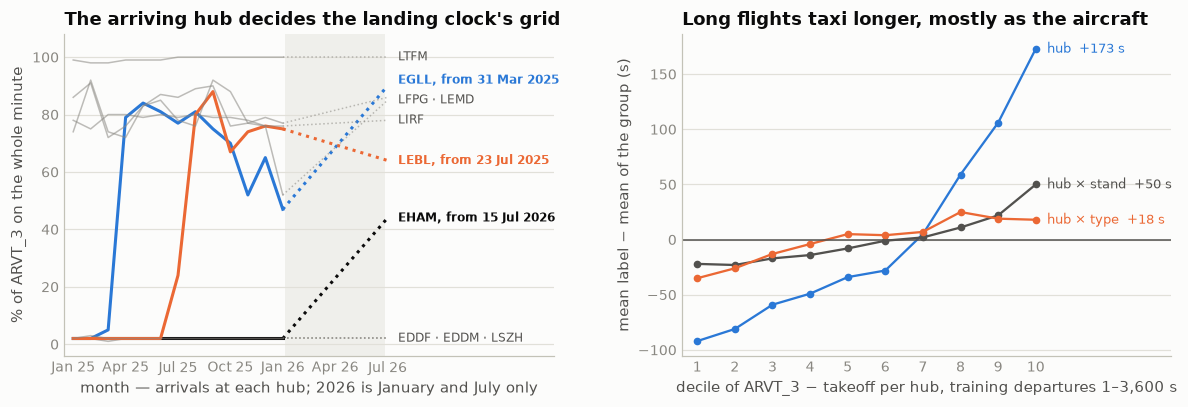

In [7]:
# the picture: the grid the flown landing sits on, month by month at each hub, with the three switches; and what the airborne time's link to the
# label is made of
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
grid["mx"] = (grid.ym.str[:2].astype(int) - 25) * 12 + grid.ym.str[3:].astype(int) - 1
HL = {"EGLL": BLUE, "LEBL": ORANGE, "EHAM": INK}
a1.axvspan(12.15, 17.85, color=GRID, alpha=0.45, lw=0)
for hub, g in grid.groupby("hub"):
    kw = dict(color=HL.get(hub, MUTED), lw=2 if hub in HL else 1, alpha=1 if hub in HL else 0.55)
    a1.plot(g.mx[g.mx <= 12], g.pct[g.mx <= 12], "-", **kw)
    a1.plot(g.mx[g.mx >= 12], g.pct[g.mx >= 12], ":", **kw)
last = grid[grid.mx == grid.mx.max()].set_index("hub").pct.sort_values()
first = sw.set_index("hub").switch_date
labels = []
for hub, p in last.items():
    if hub not in HL and labels and labels[-1][0][0] not in HL and p - labels[-1][1] <= 6:
        labels[-1][0].append(hub)
    else:
        labels.append([[hub], p])
pos = -100
for hubs, p in labels:
    pos = max(p, pos + 7)
    hl = hubs[0] in HL
    a1.text(18.6, pos, " · ".join(hubs) + (f", from {pd.Timestamp(first[hubs[0]]):%-d %b %Y}" if hl else ""), fontsize=8,
            color=HL[hubs[0]] if hl else INK2, fontweight="bold" if hl else "normal", va="center")
a1.set_xticks(range(0, 19, 3), [f"{m} {y}" for y in (25, 26) for m in ("Jan", "Apr", "Jul", "Oct")][:7])
a1.set_xlim(-0.5, 27.5)
a1.set_ylim(-4, 108)
a1.set_title("The arriving hub decides the landing clock's grid")
a1.set_xlabel("month — arrivals at each hub; 2026 is January and July only")
a1.set_ylabel("% of ARVT_3 on the whole minute")
style(a1)
for col, c, lab in [("vs_hub", BLUE, "hub"), ("vs_hub_stand", INK2, "hub × stand"), ("vs_hub_type", ORANGE, "hub × type")]:
    a2.plot(res.decile, res[col], "o-", color=c, ms=4)
    a2.text(10.3, res[col].iloc[-1], f"{lab}  {res[col].iloc[-1]:+.0f} s", fontsize=8.5, color=c, va="center")
a2.axhline(0, color=INK2, lw=1)
a2.set_xticks(range(1, 11))
a2.set_xlim(0.6, 13.6)
a2.set_title("Long flights taxi longer, mostly as the aircraft")
a2.set_xlabel("decile of ARVT_3 − takeoff per hub, training departures 1–3,600 s")
a2.set_ylabel("mean label − mean of the group (s)")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

In [8]:
# what the column buys — §29's ao_ladder (fit Jan–Oct → scored Nov+Dec, quantile bins cut per airport on the fit rows, cell support ≥ 30 else the
# coarser rung): the airborne time against the destination and the aircraft it measures and against §28's planned trip; the flight's deviation
# from its route's usual airborne time (the route's median over Jan–Oct, hub × ADES_flt with ≥ 30 flights), which is the day's part of it; on
# §9's anchor and on §27's delay; on raw labels (all · outside §10a's slice). Then the arrival side: arrivals within ±15 min of the takeoff (§8's
# window) counted by their flown landing against the same count by their landing, by ASOF lookups over each distinct time
TWINSL = (f"(SELECT MVT_ID_mvt, 'exact twin (§2b)' layer, recovered_from_arr_mvt_id arr_id, ARVT_3_flt arvt3_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
          f"UNION ALL SELECT MVT_ID_mvt, 'relaxed twin ' || matcher_variant || ' (§2c)', recovered_from_arr_mvt_id, ARVT_3_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
con.sql(f"""
    CREATE OR REPLACE TABLE la_rn AS
    SELECT ADEP_mvt hub, ADES_flt dest, quantile_cont({AIR}, 0.5) air_route
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ARVT_3_flt IS NOT NULL AND ADES_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) <= 10 GROUP BY 1, 2 HAVING count(*) >= 30""")
for name, t in [("la_act", "MVT_TIME_UTC_mvt"), ("la_fl", "ARVT_3_flt")]:
    con.sql(f"""CREATE OR REPLACE TABLE {name} AS
                SELECT hub, t, max(r) r FROM (SELECT ADES_mvt hub, {t} t, row_number() OVER (PARTITION BY ADES_mvt ORDER BY {t}) r
                                              FROM {T} WHERE PHASE_mvt = 'ARR' AND {t} IS NOT NULL) GROUP BY 1, 2""")
con.sql(f"""
    CREATE OR REPLACE TABLE la_win AS
    WITH d AS (SELECT MVT_ID_mvt id, ADEP_mvt hub, MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE hi, MVT_TIME_UTC_mvt - INTERVAL 15 MINUTE lo FROM {T} WHERE PHASE_mvt = 'DEP'),
         a1 AS (SELECT d.*, a.r ah FROM d ASOF LEFT JOIN la_act a ON a.hub = d.hub AND a.t <= d.hi),
         a2 AS (SELECT a1.*, a.r al FROM a1 ASOF LEFT JOIN la_act a ON a.hub = a1.hub AND a.t < a1.lo),
         f1 AS (SELECT a2.*, a.r fh FROM a2 ASOF LEFT JOIN la_fl a ON a.hub = a2.hub AND a.t <= a2.hi),
         f2 AS (SELECT f1.*, a.r fl FROM f1 ASOF LEFT JOIN la_fl a ON a.hub = f1.hub AND a.t < f1.lo)
    SELECT id, coalesce(ah, 0) - coalesce(al, 0) n_act, coalesce(fh, 0) - coalesce(fl, 0) n_flown FROM f2""")
con.sql(f"""
    CREATE OR REPLACE TABLE la_d AS
    SELECT d.ADEP_mvt hub, d.TAXITIME_SEC_mvt::DOUBLE y, month(d.MVT_TIME_UTC_mvt) >= 11 is_val, d.ADEP_flt IS NULL no_plan,
           coalesce(d.ADEP_mvt = 'LIRF' AND d.ADEP_flt IS NULL AND epoch(d.MVT_TIME_UTC_mvt - d.SCHED_TIME_UTC_mvt) >= 7200, FALSE) gauge,
           epoch(d.MVT_TIME_UTC_mvt - d.AOBT_3_flt) g_aobt3, epoch(d.AOBT_3_flt - d.EOBT_1_flt) un_eobt1, epoch(d.ARVT_1_flt - d.EOBT_1_flt) trip, {PTAXI} ptaxi,
           {AIR} air, epoch(coalesce(d.ARVT_3_flt, w.arvt3_twin) - d.MVT_TIME_UTC_mvt) air_twins, {AIR} - rn.air_route air_dev,
           rn.air_route IS NULL AND d.ARVT_3_flt IS NOT NULL route_without_norm, d.ADES_flt dest, d.AIRCRAFT_TYPE_flt typ,
           extract(second FROM d.ARVT_3_flt) = 0 on_minute, v.n_act, v.n_flown
    FROM {T} d JOIN la_win v ON v.id = d.MVT_ID_mvt LEFT JOIN {TWINSL} w USING (MVT_ID_mvt) LEFT JOIN la_rn rn ON rn.hub = d.ADEP_mvt AND rn.dest = d.ADES_flt
    WHERE d.PHASE_mvt = 'DEP' AND d.TAXITIME_SEC_mvt >= 1""")
con.sql("CREATE OR REPLACE TABLE la_t AS SELECT * FROM la_d WHERE y <= 3600")

ANC, DEL = ("g_aobt3", 20), ("un_eobt1", 5)
n_val = con.sql("SELECT count(*) FROM la_t WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × ARVT_3 − takeoff, 20 bins", (("air", 20),)),
                   ("airport × ARVT_3 − takeoff, 50 bins", (("air", 50),)),
                   ("airport × planned trip ARVT_1 − EOBT_1, 20 bins (§28)", (("trip", 20),)),
                   ("airport × destination ADES_flt, its own levels", (("dest", 0),)),
                   ("airport × destination × airborne time, 5 bins", (("dest", 0), ("air", 5))),
                   ("airport × aircraft type AIRCRAFT_TYPE_flt, its own levels", (("typ", 0),)),
                   ("airport × aircraft type × airborne time, 5 bins", (("typ", 0), ("air", 5))),
                   ("airport × deviation from the route's airborne time, 10 bins", (("air_dev", 10),)),
                   ("airport × the route has no norm (< 30 flights Jan–Oct)", (("route_without_norm", 0),)),
                   ("airport × ARVT_3 on the whole minute", (("on_minute", 0),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (ANC,)),
                   ("anchor × airborne time, 5 bins", (ANC, ("air", 5))),
                   ("anchor × deviation from the route, 5 bins", (ANC, ("air_dev", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 5 bins — §27's delay", (ANC, DEL)),
                   ("anchor × §27's delay × airborne time", (ANC, DEL, ("air", 5))),
                   ("anchor × §27's delay × deviation from the route", (ANC, DEL, ("air_dev", 5))),
                   ("anchor × §27's delay × the plan's taxi-out (§28)", (ANC, DEL, ("ptaxi", 5))),
                   ("anchor × arrivals by landing within ±15 min, 5 bins", (ANC, ("n_act", 5))),
                   ("anchor × arrivals by flown landing within ±15 min, 5 bins", (ANC, ("n_flown", 5)))]:
    print(f"  {name:62s} {ao_ladder('la_t', *bins)[0]:6.1f}")
print(con.sql("""SELECT round(avg(n_act), 2) mean_arrivals_by_landing, round(avg(n_flown), 2) mean_arrivals_by_flown_landing, round(corr(n_act, n_flown), 4) r,
                        round(100.0*count(*) FILTER (n_act = n_flown)/count(*), 1) pct_equal FROM la_t""").df().to_string(index=False))

n2 = con.sql("SELECT count(*), count(*) FILTER (no_plan), count(*) FILTER (gauge) FROM la_d WHERE is_val").fetchone()
print(f"\nraw labels, no ceiling (§14) — all {n2[0]:,} Nov+Dec departures, {n2[1]:,} without a plan, {n2[2]} in §10a's slice (all · outside the slice):")
for name, bins in [("airport", ()),
                   ("airport × the missing-plan flag (§2)", (("no_plan", 0),)),
                   ("airborne time, 20 bins (its ∅ is the missing plan)", (("air", 20),)),
                   ("airborne time, 20 bins, the twin layers' clock filled in", (("air_twins", 20),)),
                   ("destination, its own levels (its ∅ is the missing plan)", (("dest", 0),)),
                   ("missing-plan flag × deviation from the route, 5 bins", (("no_plan", 0), ("air_dev", 5)))]:
    r = ao_ladder("la_d", *bins)
    print(f"  {name:62s} {r[0]:6.1f} · {r[1]:6.1f}")

honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                         357.3


  airport × ARVT_3 − takeoff, 20 bins                             344.9


  airport × ARVT_3 − takeoff, 50 bins                             344.4
  airport × planned trip ARVT_1 − EOBT_1, 20 bins (§28)           342.7


  airport × destination ADES_flt, its own levels                  335.7
  airport × destination × airborne time, 5 bins                   335.6
  airport × aircraft type AIRCRAFT_TYPE_flt, its own levels       338.2


  airport × aircraft type × airborne time, 5 bins                 336.2
  airport × deviation from the route's airborne time, 10 bins     353.7
  airport × the route has no norm (< 30 flights Jan–Oct)          357.1


...

  anchor × §27's delay × the plan's taxi-out (§28)                253.7


  anchor × arrivals by landing within ±15 min, 5 bins             292.6
  anchor × arrivals by flown landing within ±15 min, 5 bins       292.7


 mean_arrivals_by_landing  mean_arrivals_by_flown_landing      r  pct_equal
                    15.24                           15.14 0.9919       61.9

raw labels, no ceiling (§14) — all 327,968 Nov+Dec departures, 2,978 without a plan, 58 in §10a's slice (all · outside the slice):
  airport                                                         496.5 ·  383.0
  airport × the missing-plan flag (§2)                            475.0 ·  382.0


  airborne time, 20 bins (its ∅ is the missing plan)              465.6 ·  370.3
  airborne time, 20 bins, the twin layers' clock filled in        464.9 ·  369.7


  destination, its own levels (its ∅ is the missing plan)         458.7 ·  361.5
  missing-plan flag × deviation from the route, 5 bins            472.9 ·  379.4


In [9]:
# on §13's base — §29's ob_rmse and base13 (§13's std_rungs; the anchor in §13's 12 bins, every other number in 5 quantile bins per airport cut
# on the fit rows, no route norm its own level): the airborne time and its deviation from the route, under the pier after §27's delay or on top
# of the stand; labels 1–3,600 s and raw
con.sql(f"""
    CREATE OR REPLACE TABLE la_ob AS
    SELECT d.ADEP_mvt hub, d.RUNWAY_mvt rwy, d.STAND_mvt stand, {PFX} pfx, d.TAXITIME_SEC_mvt::DOUBLE y, month(d.MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(d.MVT_TIME_UTC_mvt - d.AOBT_3_flt) anchor, epoch(d.AOBT_3_flt - d.EOBT_1_flt) un_e, {AIR} air, {AIR} - rn.air_route air_dev
    FROM {T} d LEFT JOIN la_rn rn ON rn.hub = d.ADEP_mvt AND rn.dest = d.ADES_flt
    WHERE d.PHASE_mvt = 'DEP' AND d.TAXITIME_SEC_mvt >= 1 AND d.AOBT_3_flt IS NOT NULL AND d.RUNWAY_mvt IS NOT NULL AND d.STAND_mvt IS NOT NULL""")
for tbl, cond in [("la_obt", "y <= 3600"), ("la_obr", "TRUE")]:
    con.sql(f"""
        CREATE OR REPLACE TABLE {tbl} AS
        WITH d AS (SELECT * FROM la_ob WHERE {cond}),
             cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) q12, quantile_cont(un_e, [0.2,0.4,0.6,0.8]) ce,
                             quantile_cont(air, [0.2,0.4,0.6,0.8]) ca, quantile_cont(air_dev, [0.2,0.4,0.6,0.8]) cd
                      FROM d WHERE NOT is_val GROUP BY 1)
        SELECT d.*, list_count(list_filter(q12, x -> x <= anchor)) a12, list_count(list_filter(ce, x -> x <= un_e)) q_une,
               list_count(list_filter(ca, x -> x <= air)) q_air, CASE WHEN air_dev IS NULL THEN -1 ELSE list_count(list_filter(cd, x -> x <= air_dev)) END q_dev
        FROM d JOIN cuts USING (hub)""")

for title, tbl in [("labels 1–3,600 s", "la_obt"), ("raw labels", "la_obr")]:
    n = con.sql(f"SELECT count(*) FROM {tbl} WHERE is_val").fetchone()[0]
    print(f"on §13's base — {n:,} Nov+Dec departures with a runway, a stand and an anchor, {title}:")
    und = base13("a12", "q_une")
    for name, rungs in [("§13's base", base13("a12")), ("§27's delay under the pier", und),
                        ("§27's delay, then the airborne time, under the pier", base13("a12", "q_une", "q_air")),
                        ("§27's delay, then the deviation from the route, under the pier", base13("a12", "q_une", "q_dev")),
                        ("§27's delay under the pier, the airborne time on top of the stand", und + [und[-1] + ["q_air"]]),
                        ("§27's delay under the pier, the deviation on top of the stand", und + [und[-1] + ["q_dev"]])]:
        print(f"    {name:66s} {ob_rmse(rungs, tbl):7.1f} s")
    print()

on §13's base — 324,629 Nov+Dec departures with a runway, a stand and an anchor, labels 1–3,600 s:
    §13's base                                                           265.5 s
    §27's delay under the pier                                           237.5 s


    §27's delay, then the airborne time, under the pier                  241.8 s


    §27's delay, then the deviation from the route, under the pier       244.3 s


    §27's delay under the pier, the airborne time on top of the stand    237.6 s


    §27's delay under the pier, the deviation on top of the stand        237.6 s

on §13's base — 324,988 Nov+Dec departures with a runway, a stand and an anchor, raw labels:
    §13's base                                                           286.6 s
    §27's delay under the pier                                           257.9 s


    §27's delay, then the airborne time, under the pier                  262.1 s
    §27's delay, then the deviation from the route, under the pier       264.3 s


    §27's delay under the pier, the airborne time on top of the stand    258.0 s


    §27's delay under the pier, the deviation on top of the stand        258.0 s



In [10]:
# look both ways — unlike the flown off-block, this clock has a referee in 2026: the arrival rows' landings stay visible. January and July of both
# years at each hub; then the departures' airborne time, per month
YM = [(2025, 1), (2026, 1), (2025, 7), (2026, 7)]
cols = ", ".join(f"round(100.0*count(*) FILTER (yr = {y} AND mon = {m} AND abs(e) <= 120)/count(*) FILTER (yr = {y} AND mon = {m}), 1) w2_{y % 100}_{m:02d}" for y, m in YM)
cols += ", " + ", ".join(f"round(quantile_cont(e, 0.5) FILTER (yr = {y} AND mon = {m})) med_{y % 100}_{m:02d}" for y, m in YM)
cols += ", " + ", ".join(f"round(100.0*count(*) FILTER (yr = {y} AND mon = {m} AND on_min)/count(*) FILTER (yr = {y} AND mon = {m})) onmin_{y % 100}_{m:02d}" for y, m in YM)
print("arrivals at each hub — % within 2 min of the landing (w2), the median landing − ARVT_3 in seconds (med), % on the whole minute (onmin); yy_mm:")
print(con.sql(f"""
    SELECT coalesce(ADES_mvt, 'all') hub, {cols}
    FROM (SELECT ADES_mvt, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - ARVT_3_flt) e, extract(second FROM ARVT_3_flt) = 0 on_min
          FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND ARVT_3_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7))
    GROUP BY ROLLUP (ADES_mvt) ORDER BY ADES_mvt NULLS LAST""").df().to_string(index=False))

print("\ndepartures — the clock and the airborne time, January and July of both years:")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) n, round(100.0*count(ARVT_3_flt)/count(*), 2) pct_with_arvt3,
           round(100.0*count(*) FILTER (extract(second FROM ARVT_3_flt) = 0)/count(ARVT_3_flt), 1) pct_on_minute,
           round(quantile_cont({AIR}/60, 0.1), 1) p10_air_min, round(quantile_cont({AIR}/60, 0.5), 1) p50_air_min, round(quantile_cont({AIR}/60, 0.9), 1) p90_air_min,
           count(*) FILTER ({AIR} <= 0) not_after_the_takeoff
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

arrivals at each hub — % within 2 min of the landing (w2), the median landing − ARVT_3 in seconds (med), % on the whole minute (onmin); yy_mm:


 hub  w2_25_01  w2_26_01  w2_25_07  w2_26_07  med_25_01  med_26_01  med_25_07  med_26_07  onmin_25_01  onmin_26_01  onmin_25_07  onmin_26_07
EDDF      99.5      99.2      99.7      99.7      -11.0      -18.0      -11.0      -16.0          2.0          2.0          2.0          2.0
EDDM      99.8      99.7      99.5      99.7      -30.0      -25.0      -22.0      -23.0          2.0          2.0          2.0          2.0
EGLL      99.7      99.8      99.8      99.9      -37.0       -6.0       -2.0       -1.0          2.0         47.0         77.0         90.0
EHAM      95.8      95.8      98.1      99.7      -54.0      -50.0      -43.0       -6.0          2.0          2.0          2.0         44.0
LEBL      99.9      99.2      99.9      99.9      -21.0        4.0      -16.0       10.0          2.0         75.0         24.0         64.0
LEMD      99.5      99.4      99.3      99.9       17.0        8.0       17.0        8.0         86.0         77.0         78.0         86.0
LFPG      97.

  yr  mon      n  pct_with_arvt3  pct_on_minute  p10_air_min  p50_air_min  p90_air_min  not_after_the_takeoff
2025    1 153706           99.07           26.8         45.7        102.4        527.2                      2
2026    1 152719           98.39           29.4         45.9        104.9        538.4                      2
2025    7 190713           97.94           29.8         46.0        104.5        508.7                      4
2026    7 192122           98.52           35.0         46.5        105.3        514.9                      6


In [11]:
# closing state — the column after §30: nothing of its own repaired; §2's twin layers hand the departures they recover the whole plan block, this
# clock with it. Before → after per file with the airborne time after; then the twins' flown landing against the landing of the arrival row each
# block came from
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (ARVT_3_flt IS NULL) null_before, count(*) FILTER (ARVT_3_flt IS NULL AND arvt3_twin IS NOT NULL) filled_by_twins,
           count(*) FILTER (coalesce(ARVT_3_flt, arvt3_twin) IS NULL) null_after, round(100.0*count(*) FILTER (coalesce(ARVT_3_flt, arvt3_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(coalesce(ARVT_3_flt, arvt3_twin) - MVT_TIME_UTC_mvt)/60, 0.1), 1) p10_air_min_after,
           round(quantile_cont(epoch(coalesce(ARVT_3_flt, arvt3_twin) - MVT_TIME_UTC_mvt)/60, 0.5), 1) p50,
           round(quantile_cont(epoch(coalesce(ARVT_3_flt, arvt3_twin) - MVT_TIME_UTC_mvt)/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINSL} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()

print("\nthe twin layers' ARVT_3 on the departures without their own, against the landing of the arrival row the block came from:")
print(con.sql(f"""
    SELECT d.src, coalesce(w.layer, 'all') layer, count(*) n, round(100.0*count(*) FILTER (abs(epoch(a.MVT_TIME_UTC_mvt - w.arvt3_twin)) <= 120)/count(*), 1) within_2min,
           round(quantile_cont(epoch(a.MVT_TIME_UTC_mvt - w.arvt3_twin), 0.5)) med_landing_minus_arvt3_s,
           count(*) FILTER (w.arvt3_twin <= d.MVT_TIME_UTC_mvt) not_after_the_takeoff, round(quantile_cont(epoch(w.arvt3_twin - d.MVT_TIME_UTC_mvt)/60, 0.5), 1) med_air_min
    FROM {BOTH} d JOIN {TWINSL} w USING (MVT_ID_mvt) JOIN {BOTH} a ON a.MVT_ID_mvt = w.arr_id
    WHERE d.PHASE_mvt = 'DEP' AND d.ARVT_3_flt IS NULL AND w.arvt3_twin IS NOT NULL
    GROUP BY GROUPING SETS ((d.src, w.layer), (d.src)) ORDER BY d.src DESC, w.layer NULLS LAST""").df().to_string(index=False))

     src       n  null_before  filled_by_twins  null_after  pct_null_after  p10_air_min_after   p50   p90
training 2085047        22470             1898       20572            0.99               45.9 102.6 510.5
 ranking  344841         5290              479        4811            1.40               46.1 105.1 524.9

the twin layers' ARVT_3 on the departures without their own, against the landing of the arrival row the block came from:
     src                layer    n  within_2min  med_landing_minus_arvt3_s  not_after_the_takeoff  med_air_min
training     exact twin (§2b)  892         98.1                       -3.0                      3         96.9
training relaxed twin A (§2c)  526         98.1                      -27.0                      0         96.5
training relaxed twin B (§2c)  217         95.9                       -6.0                      0         64.0
training relaxed twin C (§2c)  263         99.2                       -3.0                      0         79.8
train

                             feature        kind  n / levels  pearson_r  spearman_ρ     η
            ARVT_3 epoch — the trend     numeric     2059401      0.011       0.015      
ARVT_3 − takeoff — the airborne time     numeric     2059401      0.272       0.297      
 ARVT_3 − ARVT_1 — the arrival delay     numeric     2059401      0.255       0.238      
    ARVT_3 − AOBT_3 — the flown trip     numeric     2059401      0.288       0.341      
          ARVT_3 on the whole minute categorical           3                        0.045
                      ARVT_3 missing categorical           2                        0.007


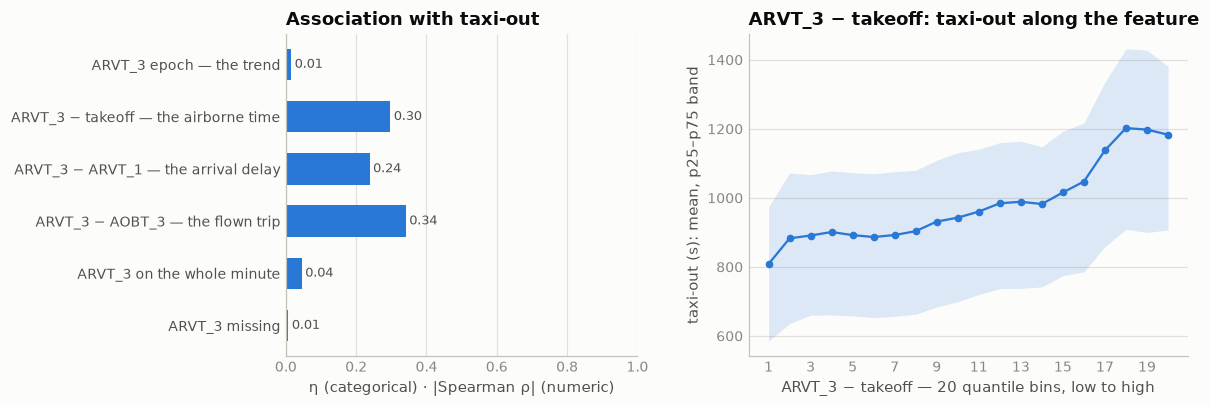

In [12]:
# correlation with the target: the stamp is a calendar; its model-facing form is the airborne time, beside the two differences the identities make
# of it (the arrival delay against the plan, the flown trip) and the grid flag; missing
a = target_assoc([("ARVT_3 epoch — the trend", "num", "epoch(ARVT_3_flt)"),
                  ("ARVT_3 − takeoff — the airborne time", "num", AIR),
                  ("ARVT_3 − ARVT_1 — the arrival delay", "num", "epoch(ARVT_3_flt - ARVT_1_flt)"),
                  ("ARVT_3 − AOBT_3 — the flown trip", "num", "epoch(ARVT_3_flt - AOBT_3_flt)"),
                  ("ARVT_3 on the whole minute", "cat", "extract(second FROM ARVT_3_flt) = 0"),
                  ("ARVT_3 missing", "cat", "ARVT_3_flt IS NULL")])
assoc_chart(a, AIR, kind="num", title="ARVT_3 − takeoff")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The same rows as the plan's other clocks** | null on 22,470 training departures (22,424 without a plan) and 5,290 in the ranking file; on arrivals 15,449 and 2,552. `only_one_of_arvt3_aobt3` is 0 in all four file × phase groups; never at or before `AOBT_3` | its nulls are §2's missing plan |
| **The landing, not the in-block** | on 2,067,301 training arrivals: landing − `ARVT_3` p01 −131 s, median −4, p99 +62; within 1 min 88.0%, **within 2 min 98.5%**, more than 15 min off 0.07%; the in-block within 2 min 2.5% (LEBL 18.2%, EHAM 6.0%, elsewhere ≤ 0.9%). Within 2 min per hub 97.4% (EHAM) to 99.9% (LSZH), except **LIRF 90.0%** | §14's "the plan's in-block `ARVT_3`" is the landing. The clock is good to about a minute everywhere except Rome |
| **Two grids, and the arriving hub decides which** | on the whole minute on 47.08% of training arrivals (53.96% ranking), 29.95% of departures (32.50%). Arrivals per hub: EDDF 1.8%, EDDM 1.9%, EHAM 1.7%, LSZH 2.1% (what a random second gives), LEBL 35.9%, EGLL 57.2%, LIRF 78.7%, LFPG 81.5%, LEMD 81.8%, **LTFM 99.2%**. Departures by the hub they land at: EDDF 1.7%, EGLL 56.8%, LEMD 82.4%, LTFM 99.3%, the rest of the network 27.7%. The movement's own landing stamps are on the minute on 1.6–8.4% | the grid is set where the aircraft lands, not where it took off, and it is not a copy of the movement's landing stamp. A departure's `ARVT_3` is on its destination's grid |
| **The minute rows are the landing; the seconds rows run later** | at the hubs with both kinds: minute rows within 1 min of the landing on 99.4% (EGLL), 99.6% (LFPG), 98.8% (LIRF), median 0 s; seconds rows a median −45 s (EGLL), −58 s (LFPG), **−115 s (LIRF**, 7.5% within 1 min). At the seconds-only hubs the median is −43 s (EHAM), −25 s (EDDM), −20 s (EDDF), −2 s (LSZH) | two sources: the landing to the minute, and a time that runs up to two minutes after it. Rome's misses are its seconds rows: its minute rows are within 1 min on 98.8% |
| **The grid switched at three hubs, one of them in a scored month** | the first day on the minute ≥ 50% after a week under 10%: **EGLL 31 Mar 2025** (1.8% the week before, 90.2% the week from it), **LEBL 23 Jul 2025** (1.3% → 73.5%), **EHAM 15 Jul 2026** (1.9% → 88.5%). After the switch the share wanders: EGLL 52% in November 2025, 47% in January 2026, 90% in July 2026. The median landing − `ARVT_3` moves with it: EHAM July −43 → **−6 s**, EGLL January −37 → −6 s, LEBL January −21 → +4 s | a departure landing at Schiphol after 15 July 2026 records an airborne time about half a minute shorter than the same flight a year earlier. At taxi-out resolution this is nothing; it is a change of source, not of flying |
| **On a departure the column adds one quantity: the airborne time** | on 2,062,577 training departures, `ARVT_3` − `ARVT_1` = (takeoff − `EOBT_1`) − `PTAXI` and `ARVT_3` − `AOBT_3` = (takeoff − `AOBT_3`) + `AIR`, both with a largest gap of **0.0 s**. `AIR` against §28's planned trip `ARVT_1` − `EOBT_1`: **r 0.9988**. Airborne time p10 45.9, median 102.6, p90 510.7 min; per hub median 77.5 (EDDM) to 152.3 (LTFM) | the arrival delay and the flown trip are sums of forms §27–§29 already own. The airborne time is the planned trip measured after the fact: the route's length |
| The flown landing is not after the takeoff on 27 training departures (8 ranking); 197 are airborne under 10 min | the 27: 8 back to the departure airport, landed a median 724 s before the takeoff, anchor a median 5,097 s, label a median 1,797 s. Under 10 min: EHAM → Rotterdam 73 (524 s), LEMD → Cuatro Vientos 48 (491 s), EDDM → Oberpfaffenhofen 40, EHAM → Lelystad 9, LFPG → Le Bourget 6 (137 s) | the 27 carry the flown record of an earlier leg or attempt, and their anchor is already far off (§29). The short ones are genuine hops to nearby airfields |
| **The flown landing's error says nothing about the flown off-block's** | on 315,269 flights between two hubs (matched on `FLIGHT_ID_mvt`): the same `ARVT_3` on both rows 99.989%; landing − `ARVT_3` p01 −136, median −5, p99 +60 s, within 1 min 87.0%. Its correlation with §29's error, off-block − `AOBT_3` (both within ±15 min): **−0.018**, per hub −0.081 to +0.009; with the label 0.045 | the two flown clocks come from different records. `ARVT_3` cannot calibrate the anchor |
| **Long flights taxi longer, mostly because of the aircraft** | mean label − the hub's mean by airborne decile per hub: **−92 s** (median 39 min airborne) to **+173 s** (618 min). Against the hub × type mean −35 to +18 s; against the hub × stand mean −22 to +50 s | long-haul departures are heavy aircraft on long-haul stands. The effect is §24's type and §13's stand, seen through the flight's length |
| **As a feature it is the destination's shadow** | airport 357.3 → airborne time 20 bins 344.9, 50 bins 344.4; §28's planned trip 342.7; **destination 335.7**, destination × airborne time 335.6; aircraft type 338.2, type × airborne time 336.2. The day's part, the deviation from the route's Jan–Oct median airborne time: 353.7 alone, 293.5 → 292.1 on the anchor, 257.1 → 256.6 on §27's delay. The flag "the route has no norm" 357.1; on the whole minute 356.4. On the anchor: airborne time 288.0; on §27's delay 254.3, §28's plan's taxi-out 253.7 | the airborne time measures what the destination and the type already say. Its deviation from the route is worth half a second after §27's delay |
| **Nothing on §13's base** | 324,629 Nov+Dec departures: §13's base 265.5, §27's delay under the pier 237.5; then the airborne time under the pier **241.8**, the deviation **244.3**; either on top of the stand **237.6**. Raw labels: 286.6, 257.9; 262.1, 264.3; 258.0 and 258.0 | once the runway, the stand and the delay are in, the flight's length is already known. Under the pier it splits cells the stand needs |
| On raw labels the destination still beats it; the twins add 0.7 s | 327,968 Nov+Dec departures, all · outside §10a's slice: airport 496.5 · 383.0; §2's flag 475.0 · 382.0; airborne time 20 bins (∅ = no plan) 465.6 · 370.3, with the twin layers' clock **464.9 · 369.7**; destination (∅ = no plan) **458.7 · 361.5**; flag × deviation 472.9 · 379.4 | on every label the airborne time is again a weaker spelling of the destination |
| **The arrival side is the landing stream** | arrivals within ±15 min of the takeoff counted by their flown landing: mean 15.14 against 15.24 by landing, r **0.9919**, the same count on 61.9%; on the anchor 292.7 against 292.6 | a window over arrivals' `ARVT_3` is §8's landing count again |
| **2026 keeps the referee, and the clock holds** | arrivals within 2 min of the landing, all hubs: January 98.1% → 98.4%, July 98.8% → 98.9%; LIRF 89.9% → 92.3% and 92.7% → 89.6%. Departures: with the clock January 99.07% → 98.39%, July 97.94% → 98.52%; on the minute 26.8% → 29.4%, 29.8% → 35.0%; median airborne time 102.4 → 104.9 and 104.5 → 105.3 min, p90 527.2 → 538.4 and 508.7 → 514.9; not after the takeoff 2 → 2, 4 → 6 | apart from the Schiphol switch, 2026's flown landing is 2025's. The longer trips are §28's route mix |
| Marginal | `ARVT_3` − `AOBT_3` ρ 0.341, **the airborne time ρ 0.297** (r 0.272), `ARVT_3` − `ARVT_1` ρ 0.238; on the whole minute η 0.045; missing η 0.007; the stamp r 0.011 | the flown trip reads higher only because it contains the anchor (ρ 0.616 in §29) |

**Decisions**

| issue | decision | why |
|---|---|---|
| the form a model reads | **none required**; if one goes in, the airborne time `ARVT_3` − takeoff as a number, with the twin layers' clock filled in | 344.9 alone against the destination's 335.7; 254.3 on §27's delay against §28's 253.7; 237.6 on §13's base against 237.5; +0.7 s from the twins on raw labels |
| the arrival delay `ARVT_3` − `ARVT_1`, the flown trip `ARVT_3` − `AOBT_3` | not built | sums of §27's, §28's and §29's forms and the airborne time, exact to the second |
| the deviation from the route's airborne time | not built | 0.5 s on §27's delay; 6.8 s worse under the pier, 0.1 s worse on top of the stand |
| the on-the-minute flag | not built | it names the arriving hub's source, not the departure (356.4 alone), and its meaning moved at three hubs |
| arrivals counted by their flown landing | not built | the landing count's shadow: r 0.9919, 292.7 against 292.6 |
| calibrating `AOBT_3` with `ARVT_3`'s error | not possible | r −0.018 between the two errors on 315,269 flights between hubs |
| the grid switches (EGLL, LEBL, and EHAM on 15 July 2026) | recorded | the hub's flown landing moves by about half a minute; `PTAXI` and the airborne time move with it on flights landing there |
| §14's "the plan's in-block `ARVT_3`" | confirmed as the landing; left as written for §14 | 98.5% within 2 min of the landing, 2.5% of the in-block |
| the twin layers' clock | adopted with the block: 1,898 training and 479 ranking departures | within 2 min of the landing of the arrival the block came from on 98.0% and 98.5%, as the flights' own clock is (98.5%) |

**State after §30** — the twin layers of §2, departures:

| `ARVT_3_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

The airborne time after, minutes: p10 45.9 / 46.1, median 102.6 / 105.1, p90 510.5 / 524.9 (training / ranking).

**Use in modeling.** Nothing new to feed. `ARVT_3_flt` is the landing: on the whole minute where the arriving hub
provides it, on true seconds and a little later elsewhere. On a departure it adds one quantity to the clocks of
§27–§29, the airborne time. That is §28's planned trip again and measures what the destination and the aircraft
already say, so it is worth nothing once §13's runway and stand are in. If a model takes it anyway, feed
`ARVT_3` − takeoff as a number with §2's twin layers' clock filled in. Leave out the arrival delay, the flown trip, the
on-the-minute flag and the deviation from the route. Its error carries nothing about `AOBT_3`'s, so it cannot
calibrate the anchor. When a hub switches to minute stamps (EGLL March 2025, LEBL July 2025, EHAM 15 July 2026), the
flown landing of flights landing there moves by about half a minute, and `PTAXI` with it. That is too little to
matter for taxi-out. The closing matrix reads the twin layers' clock as `TWINSL`. The column enters as epoch seconds
with those 1,898 + 479 filled in: 1.00 with the other clocks, 0.01 with the target, the ninth copy of the calendar.

## Features so far — how they correlate with each other

One matrix, extended as the sweep goes on: every section adds its column here once it has been
through. Each column enters in the form the pipeline should consume — `FLIGHT_RULE_mvt` and
`ADES_mvt` after their recoveries (§4a, §6a), the three timestamps as epoch seconds, `AIRCRAFT_TYPE_mvt` as §11a's plan-first form, `RUNWAY_mvt` and `STAND_mvt` raw, `LOBT_flt` and `IOBT_flt` as epoch seconds with
§2's twin layers filled in (§15, §21), `MARKET_SEGMENT_flt` raw with its nulls kept as a level (§20), `FLIGHT_RULE_flt` with the twin layers' rule filled in and its nulls kept as a level too (§22), `FLIGHT_TYPE_flt` the same way (§23), `AIRCRAFT_TYPE_flt` too, with the twin layers' type filled in and rare codes pooled below 200 rows as for the movement's type (§24), `WK_TBL_CAT_flt` with the twin layers' class and then the type's class filled in, its few nulls kept as a level (§25), `AIRCRAFT_OPERATOR_flt` as the raw hash with the twin layers' hash filled in, rare hashes pooled below 30 rows (§26), `EOBT_1_flt` as epoch seconds with the twin layers' clock filled in (§27), `ARVT_1_flt` the same way (§28), `AOBT_3_flt` and `ARVT_3_flt` too (§29, §30) — on training
departures with a plausible label (1–3600 s), with the target (§14) as the last row and column — the tail's
associations are in §14's own correlation cell, on raw labels. Three
measures, one per pair type, all on a 0–1 scale so the cells are comparable at a glance:

| pair | measure |
|---|---|
| numeric × numeric | \|Pearson r\| |
| categorical × categorical | **Cramér's V** — χ² of the contingency table, normalised by min(levels) − 1; rare levels pooled (flight number ≥ 20 rows, destination and aircraft type ≥ 200, runway and stand ≥ 30) |
| numeric × categorical | **correlation ratio η** — sqrt(between-level / total variance), the R of a one-hot regression on the levels |

Read it for two things: which columns are the *same information twice* (V near 1), and which
carry the target (the last row). The per-section "correlation with the target" cells use the
same three measures on the columns' derived forms too.

|r| for numeric pairs · Cramér's V for categorical pairs · η for mixed pairs:
                       MVT_ID_mvt  FLIGHT_ID_mvt  FLIGHT_mvt  FLIGHT_RULE_mvt  ADEP_mvt  ADES_mvt  PHASE_mvt  MVT_TIME_UTC_mvt  BLOCK_TIME_UTC_mvt  SCHED_TIME_UTC_mvt  AIRCRAFT_TYPE_mvt  RUNWAY_mvt  STAND_mvt  LOBT_flt  CALLSIGN_flt  ADEP_flt  ADES_flt  ADES_FILED_flt  MARKET_SEGMENT_flt  IOBT_flt  FLIGHT_RULE_flt  FLIGHT_TYPE_flt  AIRCRAFT_TYPE_flt  WK_TBL_CAT_flt  AIRCRAFT_OPERATOR_flt  EOBT_1_flt  ARVT_1_flt  AOBT_3_flt  ARVT_3_flt  TAXITIME_SEC_mvt
MVT_ID_mvt                   1.00           0.99        0.52             0.00      0.08      0.07        0.0              0.99                0.99                0.99               0.05        0.16       0.12      0.99          0.57      0.08      0.07            0.07                0.03      0.99             0.01             0.01               0.05            0.01                   0.09        0.99        0.99        0.99        0.99              0.01
FLIGHT_I

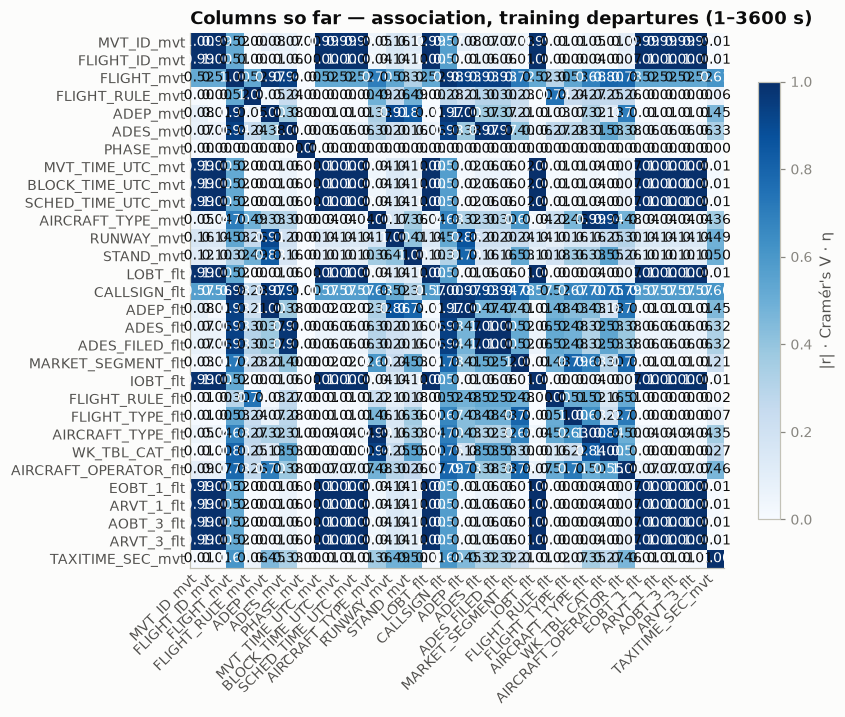

In [13]:
# ---- features so far, against each other ----
# One base table of training departures (1–3600 s): the columns covered so far, each in the form the
# pipeline should consume (the recovered rule and destination, the plan-first type of §11a, the twins' LOBT of §15, IOBT of §21, rule of §22, flight type of §23, aircraft type of §24, wake class of §25, operator of §26, EOBT_1 of §27, ARVT_1 of §28, AOBT_3 of §29 and ARVT_3 of §30), plus the target. To add a column from
# a later section: one line in the SELECT, one line in FEATURES.
con.sql(f"""
    CREATE OR REPLACE TABLE assoc_base AS
    SELECT t.MVT_ID_mvt, t.FLIGHT_ID_mvt, t.FLIGHT_mvt, t.rule_final AS FLIGHT_RULE_mvt, t.ADEP_mvt, t.ADEP_flt, t.ADES_flt, t.ADES_FILED_flt, t.MARKET_SEGMENT_flt,
           d.dest_final AS ADES_mvt, t.PHASE_mvt, epoch(t.MVT_TIME_UTC_mvt) AS MVT_TIME_UTC_mvt,
           epoch(t.BLOCK_TIME_UTC_mvt) AS BLOCK_TIME_UTC_mvt, epoch(t.SCHED_TIME_UTC_mvt) AS SCHED_TIME_UTC_mvt,
           coalesce(t.AIRCRAFT_TYPE_flt, t.AIRCRAFT_TYPE_mvt) AS AIRCRAFT_TYPE_mvt, t.RUNWAY_mvt, t.STAND_mvt,
           epoch(coalesce(t.LOBT_flt, w.lobt_twin)) AS LOBT_flt,
           epoch(coalesce(t.IOBT_flt, w3.iobt_twin)) AS IOBT_flt,
           coalesce(t.FLIGHT_RULE_flt, w4.rule_twin) AS FLIGHT_RULE_flt,
           coalesce(t.FLIGHT_TYPE_flt, w5.ft_twin) AS FLIGHT_TYPE_flt,
           coalesce(t.AIRCRAFT_TYPE_flt, w6.typ_twin) AS AIRCRAFT_TYPE_flt,
           coalesce(t.WK_TBL_CAT_flt, w7.wk_twin, wlk.wake_from_type) AS WK_TBL_CAT_flt,
           coalesce(t.AIRCRAFT_OPERATOR_flt, w8.op_twin) AS AIRCRAFT_OPERATOR_flt,
           epoch(coalesce(t.EOBT_1_flt, w9.eobt1_twin)) AS EOBT_1_flt,
           epoch(coalesce(t.ARVT_1_flt, w10.arvt1_twin)) AS ARVT_1_flt,
           epoch(coalesce(t.AOBT_3_flt, w11.aobt3_twin)) AS AOBT_3_flt,
           epoch(coalesce(t.ARVT_3_flt, w12.arvt3_twin)) AS ARVT_3_flt,
           coalesce(t.CALLSIGN_flt, w2.cs_twin) AS CALLSIGN_flt,
           t.TAXITIME_SEC_mvt::DOUBLE AS TAXITIME_SEC_mvt
    FROM (SELECT * FROM ({FINAL}) WHERE ds = 'training' AND PHASE_mvt = 'DEP'
            AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600) t
    LEFT JOIN (SELECT MVT_ID_mvt, dest_final FROM ({FINALD}) WHERE ds = 'training') d USING (MVT_ID_mvt)
    LEFT JOIN {TWINS} w USING (MVT_ID_mvt)
    LEFT JOIN {TWINCS} w2 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSI} w3 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSR} w4 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSFT} w5 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSTY} w6 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSWK} w7 USING (MVT_ID_mvt)
    LEFT JOIN wake_lk wlk ON wlk.typ = coalesce(t.AIRCRAFT_TYPE_flt, w6.typ_twin, t.AIRCRAFT_TYPE_mvt)
    LEFT JOIN {TWINSOP} w8 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSE} w9 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSA} w10 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSO} w11 USING (MVT_ID_mvt)
    LEFT JOIN {TWINSL} w12 USING (MVT_ID_mvt)""")

FEATURES = [  # (column, kind, min_support for pooling rare levels)
    ("MVT_ID_mvt", "num", 1), ("FLIGHT_ID_mvt", "num", 1), ("FLIGHT_mvt", "cat", 20),
    ("FLIGHT_RULE_mvt", "cat", 1), ("ADEP_mvt", "cat", 1), ("ADES_mvt", "cat", 200),
    ("PHASE_mvt", "cat", 1), ("MVT_TIME_UTC_mvt", "num", 1), ("BLOCK_TIME_UTC_mvt", "num", 1),
    ("SCHED_TIME_UTC_mvt", "num", 1), ("AIRCRAFT_TYPE_mvt", "cat", 200), ("RUNWAY_mvt", "cat", 30),
    ("STAND_mvt", "cat", 30), ("LOBT_flt", "num", 1), ("CALLSIGN_flt", "cat", 20),
    ("ADEP_flt", "cat", 1), ("ADES_flt", "cat", 200), ("ADES_FILED_flt", "cat", 200),
    ("MARKET_SEGMENT_flt", "cat", 1), ("IOBT_flt", "num", 1), ("FLIGHT_RULE_flt", "cat", 1),
    ("FLIGHT_TYPE_flt", "cat", 1), ("AIRCRAFT_TYPE_flt", "cat", 200), ("WK_TBL_CAT_flt", "cat", 1),
    ("AIRCRAFT_OPERATOR_flt", "cat", 30), ("EOBT_1_flt", "num", 1), ("ARVT_1_flt", "num", 1), ("AOBT_3_flt", "num", 1), ("ARVT_3_flt", "num", 1),
    ("TAXITIME_SEC_mvt", "num", 1),
]
names = [f[0] for f in FEATURES]
kind = {f[0]: f[1] for f in FEATURES}
sup = {f[0]: f[2] for f in FEATURES}
M = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for a, b in itertools.combinations(names, 2):
    if kind[a] == "num" and kind[b] == "num":
        v = abs(rho(a, "assoc_base", b)[0])
    elif kind[a] == "cat" and kind[b] == "cat":
        v = cramers_v(a, b, "assoc_base", sup[a], sup[b])
    else:
        c, n = (a, b) if kind[a] == "cat" else (b, a)
        v = eta(c, "assoc_base", n, sup[c])[0]
    M.loc[a, b] = M.loc[b, a] = v
print("|r| for numeric pairs · Cramér's V for categorical pairs · η for mixed pairs:")
print(M.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right", color=INK2)
ax.set_yticks(range(len(names)), names, color=INK2)
for i in range(len(names)):
    for j in range(len(names)):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.55 else INK)
ax.set_title("Columns so far — association, training departures (1–3600 s)")
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.75, label="|r| · Cramér's V · η")
fig.tight_layout()
plt.show()

**Reading the matrix**

| what it shows | cells | reading |
|---|---|---|
| **The two IDs and the three timestamps are one clock** | `MVT_ID_mvt` × `MVT_TIME_UTC_mvt` 0.99, `FLIGHT_ID_mvt` × `MVT_TIME_UTC_mvt` 1.00, the two IDs 0.99, `BLOCK_TIME_UTC_mvt` and `SCHED_TIME_UTC_mvt` × `MVT_TIME_UTC_mvt` 1.00 | both IDs are timestamps in disguise (§1, §2); off-block is takeoff minus a quarter of an hour and the schedule is off-block minus the delay — none of the five touches the target (0.01) |
| **`SCHED_TIME_UTC_mvt` hides its value in a difference too** | its row is the takeoff clock's row to two decimals; 0.01 with the target | takeoff − schedule is the delay (ρ 0.38 in §10's correlation cell) and, at Fiumicino without a plan, the corrupt label itself (§10a). A marginal measure of the stamp sees none of that |
| **`BLOCK_TIME_UTC_mvt` is the target's other endpoint, and the matrix cannot see it** | its row is `MVT_TIME_UTC_mvt`'s row to two decimals; 0.01 with the target | the label is the *difference* of the two clocks, which no marginal measure of either one carries. Hidden at prediction time anyway (§9); what stands in for it is takeoff − `AOBT_3` (ρ 0.62 in §9's correlation cell), which enters with the anchor's own section |
| **`LOBT_flt` is the fourth copy of the clock** | its row is `MVT_TIME_UTC_mvt`'s to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.01 with the target | the plan's last off-block is the schedule on three flights in four (§15); what it knows is in its differences — takeoff − LOBT (ρ 0.51) and the unfiled delay `AOBT_3` − LOBT, worth 32 s on the anchor in §15's ladder — which no marginal measure of the stamp sees |
| **The flight number contains almost everything** | `FLIGHT_mvt` × `ADEP_mvt` 0.97, × `ADES_mvt` 0.94, × `FLIGHT_RULE_mvt` 0.52, × the clock 0.52 | a number *is* airline + route + slot, which is why its η with the target (0.61) is the highest here — and why it must be encoded with fallbacks, not used raw (§3: a fifth of 2026's numbers are new) |
| **The type is the fleet, and the fleet is the airline** | `AIRCRAFT_TYPE_mvt` × `FLIGHT_mvt` 0.70, × `FLIGHT_RULE_mvt` 0.49, × `ADEP_mvt` 0.33, × `ADES_mvt` 0.30 | a flight number is flown by one type most days, and VFR is light aircraft and helicopters (§4, §11); against the target the type reads 0.36 — heavies taxi longer (§11), and the number already knows the type |
| **The runway is the airport, spelled differently** | `RUNWAY_mvt` × `ADEP_mvt` 0.91, × `FLIGHT_mvt` 0.53, × `FLIGHT_RULE_mvt` 0.26, × `AIRCRAFT_TYPE_mvt` 0.17 | runway codes are hub-specific, so across hubs the code names the airport first and the distance second — its 0.49 against the target is mostly Heathrow's 1,300 s; the within-airport worth is §12's 14 s, and the pair with the stand (§12: 306 s) is where it counts |
| **The stand is the airport too — and the rule** | `STAND_mvt` × `ADEP_mvt` 0.83, × `FLIGHT_RULE_mvt` 0.49, × `RUNWAY_mvt` 0.41, × `AIRCRAFT_TYPE_mvt` 0.36, × `FLIGHT_mvt` 0.32 | stand codes are the hub's own, the GA aprons are where VFR parks (§4, §13), and a stand hosts a fleet; its 0.50 against the target is the highest of the geometry columns, and §13's ladder puts the within-hub worth at 34 s alone and 51 with the runway — the route is the feature |
| **Rule and destination travel together** | `FLIGHT_RULE_mvt` × `ADES_mvt` 0.24 | VFR flights go to off-airport places (§4, §6a); the rule adds little the destination does not already say |
| **Airport and destination overlap only partly** | 0.38 | each hub has its own destination set, but destination keeps signal of its own (§6: −21 s on the ladder after the airport) |
| **`PHASE_mvt` is a row of zeros** | constant on departures | nothing to correlate on the rows we predict (§7) — it stays in the matrix as a reminder, not a feature |
| **The callsign is the movement's number again, in the plan's spelling** | `CALLSIGN_flt` × `FLIGHT_mvt` **0.98**, × `ADEP_mvt` 0.97, × `ADES_mvt` 0.93, × `AIRCRAFT_TYPE_mvt` 0.68, × `STAND_mvt` 0.31, × the target **0.60** | the two identities are all but the same category — V 0.98 — and this one reads the target no better (0.60 against 0.61), so the row adds a column and no information. §16's own reason for the column is the part of it the matrix cannot show: the three-letter prefix, the operator, whose η is 0.46 and which is the only one of the three levels that still has a 2025 history in 2026 (97.7% of departures against 69.8%). `AIRCRAFT_OPERATOR_flt` will enter in that form, not as its hash |
| **The target's row is a window number** | `TAXITIME_SEC_mvt` enters raw, on 1–3,600 s rows; on every label the airport's η falls 0.45 → 0.34 and takeoff − schedule's r rises 0.19 → 0.23 (§14's correlation cell) | the matrix measures association, and association is a window quantity; what the tail is worth is §14's raw-label ladders (airport 496.5 → 411.4 s), not a cell here |
| **The plan's departure airport is the movement's, with a hole in it** | `ADEP_flt` × `ADEP_mvt` **1.00**, × the target 0.45 — the anchor's own number — but × `FLIGHT_mvt` 0.93 against 0.97, × `RUNWAY_mvt` 0.86 against 0.91, × `STAND_mvt` 0.79 against 0.83 | the two are one category: not one departure in 2.4 million disagrees (§17), so the row adds a column and no information. Where it reads *lower* than `ADEP_mvt` is the 1.08% of departures with no plan, pooled into a single `∅` level that spans all ten hubs — the same pooling that costs it 0.4 s on §17's ladder |
| **The plan's destination is a second vocabulary for the same column** | `ADES_flt` × `ADES_mvt` **0.97**, × `FLIGHT_mvt` 0.93, × `CALLSIGN_flt` 0.93, × the target 0.32 against the movement's 0.33 | not a copy the way `ADEP_flt` is — 1.42% of departures name a different airport (§18) — but near enough that the two read the target alike. The plan's code is the *truer* one, right on 1,908 of the 1,908 disagreements whose landing can be found, and worth 0.1 s: use it where a feature needs geography, not as the category |
| **The filed destination is the flown one, minus a tenth of a per cent** | `ADES_FILED_flt` × `ADES_flt` **1.00**, × `ADES_mvt` 0.97, × `FLIGHT_mvt` 0.93, × `CALLSIGN_flt` 0.94, × the target 0.32 against `ADES_flt`'s 0.32 | the third row in a row that adds a column and no information, after `ADEP_flt` and `ADES_flt`: the two destinations differ on 0.100% of departures (§19), which is below what any association here can resolve. The pair is worth keeping apart only in prose — the filed code is what was known at off-block, the flown code is where the aircraft landed |
| **The commercial segment is the operator's shadow, and the pier's** | `MARKET_SEGMENT_flt` × `CALLSIGN_flt` **0.78**, × `FLIGHT_mvt` 0.72, × `AIRCRAFT_TYPE_mvt` 0.60, × `STAND_mvt` 0.53, × `ADES_flt` 0.52, × the target 0.21 | the first covered column that is neither a copy of a neighbour nor independent of them: it sits between the operator that flies it and the pier the airport gives it, which is why it is worth 6.6 s alone and 0.2 s once the stand is in (§20). Its 0.21 against the target is the weakest of the real features — below the type's 0.36 — and its nulls are §2's missing plan, which is where §14's tail lives |
| **The initial off-block clock is `LOBT_flt` exactly — the fifth copy of the calendar** | `IOBT_flt` × `LOBT_flt` **1.00**, and the whole row is `LOBT_flt`'s to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.57 with the callsign, 0.01 with the target | the two clocks are the same stamp on 99.45% of departures (§21), so no measure here can separate them — the fourth row in a row that adds a column and no information, after `ADEP_flt`, `ADES_flt` and `ADES_FILED_flt`. What does separate them is the 11,267 refiled rows, where the *initial* clock sat closer to the actual off-block on 73.9%; neither that nor the 0.6 s it is worth on §15's ladder is visible in a marginal measure of either stamp |
| **The plan's rule is §4's rule with the missing plan added** | `FLIGHT_RULE_flt` × `FLIGHT_RULE_mvt` **0.74**; 0.52 with `CALLSIGN_flt`, `ADES_flt` and `ADES_FILED_flt`, 0.48 with `ADEP_flt` and `MARKET_SEGMENT_flt`, 0.30 with `FLIGHT_mvt`, 0.27 with `ADES_mvt`, 0.22 with `AIRCRAFT_TYPE_mvt`, 0.03 with `ADEP_mvt`, **0.02 with the target** | not 1.00 with §4's recovered rule because the plan's column keeps an empty level that `rule_final` fills. That shared empty level alone puts it near 0.5 against every other plan column: with five levels Cramér's V divides χ²/n by 4, and a null level that lines up exactly with another column's adds exactly 1 to χ²/n, so sqrt(1/4) = 0.5. The `Y`/`Z` that separate it from the movement's rule are 0.07% of departures, too few to register in any measure, and worth 0.0 s on §13's ladder (§22) |
| **The flight type is the segment's finer cut, plus the missing plan** | `FLIGHT_TYPE_flt` × `MARKET_SEGMENT_flt` **0.79**, × `CALLSIGN_flt` 0.67, × `FLIGHT_mvt` 0.53, × `FLIGHT_RULE_flt` 0.51, × `ADES_flt` and `ADES_FILED_flt` 0.48, × `AIRCRAFT_TYPE_mvt` 0.46, × `ADEP_flt` 0.43, × `STAND_mvt` 0.36, × `ADES_mvt` 0.28, × `FLIGHT_RULE_mvt` 0.24, × `ADEP_mvt` 0.07, **0.07 with the target** | 0.79 here against §23's 0.744 on departures with a plan, because the two columns share the missing plan's null level. That shared level is most of what ties the code to the other plan columns: a null level two columns share exactly adds 1 to χ²/n, so on its own it gives sqrt(1/(min(levels) − 1)), 0.50 against the rule and 0.45 against `ADEP_flt`. The code follows the callsign (0.67) more closely than the aircraft type (0.46), since it is filed per flight (§23). Against the target it is the not-`S` bit, 0.07, a third of the segment's 0.21, and worth 0.0 s on §13's ladder |
| **The plan's type is §11a's type with the missing plan added** | `AIRCRAFT_TYPE_flt` × `AIRCRAFT_TYPE_mvt` **0.99**, × `CALLSIGN_flt` 0.70, × `FLIGHT_mvt` 0.68, × `MARKET_SEGMENT_flt` 0.68, × `FLIGHT_TYPE_flt` 0.63, × `FLIGHT_RULE_flt` 0.52, × `ADEP_flt` 0.43, × `STAND_mvt` 0.33, × `ADEP_mvt` 0.32, × `ADES_flt` 0.32, × `FLIGHT_RULE_mvt` 0.27, × `RUNWAY_mvt` 0.16, **0.35 with the target** against the plan-first form's 0.36 | not 1.00 with the matrix's `AIRCRAFT_TYPE_mvt`, which is §11a's plan-first form: that form carries the movement's code where the plan is missing, where the plan's column keeps a ∅ level. The shared ∅ level is also what lifts the plan's type above the plan-first form against the other plan columns (the segment 0.68 against 0.60, the flight type 0.63 against 0.46, the plan's rule 0.52 against 0.22, `ADEP_flt` 0.43 against 0.32), the mechanism §22 and §23 describe. Against the target the pooled plan-less rows cost it 0.01, and on §24's ladder every spelling of the type is worth the same 265.3 s on §13's base |
| **The wake class is the aircraft type in four bins** | `WK_TBL_CAT_flt` × `AIRCRAFT_TYPE_mvt` **0.94**, × `AIRCRAFT_TYPE_flt` 0.84, × `FLIGHT_mvt` 0.80, × `CALLSIGN_flt` 0.75, × `STAND_mvt` 0.55, × `ADES_mvt` 0.53, × `ADES_flt` 0.53, × `MARKET_SEGMENT_flt` 0.30, × `RUNWAY_mvt` 0.25, × `FLIGHT_RULE_mvt` 0.25, × `FLIGHT_TYPE_flt` 0.22, × `ADEP_flt` 0.18, × `FLIGHT_RULE_flt` 0.16, × `ADEP_mvt` 0.13, **0.27 with the target** against the type's 0.36 | a function of the type (§25: 99.9993% of plan rows) reads below 1.00 for two reasons. The type's codes under 200 rows are pooled into one level that mixes L, M and H. And the plan's type keeps §2's missing plan as a ∅ level where the filled class names a real class, hence 0.84 against the plan-first form's 0.94. With four real levels, V says how cleanly a column's levels sort into classes: a flight number is flown by one size of aircraft (0.80), a stand takes one size (0.55), a destination is short- or long-haul (0.53). Against the target the class carries three quarters of the type's association, and on §25's ladder it adds 0.0–0.1 s once the type is in |
| **The operator is the identity with the route taken out** | `AIRCRAFT_OPERATOR_flt` × `CALLSIGN_flt` **0.79**, × `FLIGHT_mvt` 0.78, × `MARKET_SEGMENT_flt` 0.78, × `ADEP_flt` 0.73, × `FLIGHT_TYPE_flt` 0.71, × `ADEP_mvt` 0.70, × `WK_TBL_CAT_flt` 0.55, × `FLIGHT_RULE_flt` 0.51, × `AIRCRAFT_TYPE_flt` 0.50, × `AIRCRAFT_TYPE_mvt` 0.48, × `ADES_mvt` 0.38, × `ADES_flt` 0.38, × `RUNWAY_mvt` 0.30, × `FLIGHT_RULE_mvt` 0.26, × `STAND_mvt` 0.26, **0.46 with the target** | the callsign and the flight number are finer cuts of it (§26: outside one bucket the hash is the callsign's prefix exactly), so V sits below 1 only because they have many more levels. It fixes the segment and the flight type (§20: 91.42% of rows in their operator's modal segment), and it names the hubs a carrier is based at (0.70). Against the stand it reads only 0.26, because V over thousands of pooled stands is diluted; §26's ladder measures that overlap properly, with 0.3 s left on §13's base. Against the target it is fifth, after the flight number, the callsign, the stand and the runway |
| **The day's off-block estimate is the sixth copy of the calendar** | `EOBT_1_flt` × `LOBT_flt` **1.00**, × `IOBT_flt` 1.00, and the whole row is `LOBT_flt`'s to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.57 with the callsign, 0.01 with the target | the clock moves on 30% of departures by a median −4 min (§27), which no measure of epoch seconds over a year can resolve. What the move is worth shows only in differences: takeoff − `EOBT_1` ρ 0.567 against LOBT's 0.507, and `AOBT_3` − `EOBT_1` 3.9 s ahead of §15's delay on the anchor and 28.0 s off §13's base when read under the pier |
| **The planned landing is the seventh copy of the calendar** | `ARVT_1_flt` × `EOBT_1_flt` **1.00**, × `LOBT_flt` and `IOBT_flt` 1.00, and the whole row is theirs to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.57 with the callsign, 0.01 with the target | a landing two hours after the off-block is still the same day at the scale of a year. What the column adds is in its difference from §27's clock, the planned trip (ρ 0.335), and inside that trip in the taxi-out the plan assumed (ρ 0.368). Both are worth nothing once §13's runway and stand are in (§28) |
| **The flown off-block is the eighth copy of the calendar** | `AOBT_3_flt` × `EOBT_1_flt`, `ARVT_1_flt`, `LOBT_flt` and `IOBT_flt` **1.00**, and the row is theirs to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.57 with the callsign, 0.01 with the target | the anchor takeoff − `AOBT_3` has ρ 0.616 with the target (§29) and is the largest single step in every ladder, yet the stamp reads 0.01: the label is the difference of two clocks, and the matrix sees them one at a time |
| **The flown landing is the ninth copy of the calendar** | `ARVT_3_flt` × `AOBT_3_flt`, `EOBT_1_flt`, `ARVT_1_flt`, `LOBT_flt` and `IOBT_flt` **1.00**, and the row is theirs to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.57 with the callsign, 0.01 with the target | a landing hours after the takeoff is still the same day at the scale of a year. What the column adds is the airborne time (ρ 0.297, §30), §28's planned trip again, which is worth nothing once §13's runway and stand are in |
| **What carries the target, alone** | `TAXITIME_SEC_mvt` row: `FLIGHT_mvt` 0.61, `CALLSIGN_flt` 0.60, `STAND_mvt` 0.50, `RUNWAY_mvt` 0.49, `AIRCRAFT_OPERATOR_flt` 0.46, `ADEP_mvt` 0.45, `AIRCRAFT_TYPE_mvt` 0.36, `AIRCRAFT_TYPE_flt` 0.35, `ADES_mvt` 0.33, `WK_TBL_CAT_flt` 0.27, `MARKET_SEGMENT_flt` 0.21, `FLIGHT_TYPE_flt` 0.07, `FLIGHT_RULE_mvt` 0.06, `FLIGHT_RULE_flt` 0.02, the IDs and the nine raw timestamps 0.01 | the ranking matches the ladders: airport is the anchor, destination the next step, the rule a rare-row flag. The raw timestamp carries nothing by itself — its value is in what is derived from it (§8: local hour, the window) and in the differences against the off-block clocks. These are marginal, in-sample associations; the honest holdout numbers in each section are what to believe about *gain* |